# EmotionLab
## Análisis de datos y Machine Learning

**Proyecto Capstone — Ingeniería en Informática**

**Integrantes:**
- Lorena Calfin
- Martín Carrere
- Emily Gonzales

**Profesor guía:** Cristian Molina

---

## Objetivo general

Desarrollar un módulo inteligente para analizar las
respuestas emocionales autodeclaradas de estudiantes
durante presentaciones orales, identificar patrones
mediante técnicas de Machine Learning y proporcionar
una clasificación exploratoria de sus niveles de
tensión percibida.

## Descripción

EmotionLab recopila respuestas emocionales autodeclaradas mediante tres formularios aplicados durante una experiencia de presentación oral: antes de presentar, después de la modalidad fácil y después de la modalidad difícil.

El módulo de análisis utilizará la información de los tres formularios para desarrollar un análisis global del estudiante, identificando patrones mediante técnicas de Machine Learning y proporcionando una clasificación exploratoria de su nivel general de tensión percibida.

Adicionalmente, se analizará la evolución de las respuestas entre etapas, permitiendo visualizar los cambios en el nerviosismo y el estado emocional durante la experiencia.

## Alcance del modelo

Los resultados representarán patrones y niveles
exploratorios de tensión emocional autodeclarada.

No se utilizarán como diagnóstico psicológico ni como
medición clínica de estrés.

## Estructura del análisis

El notebook distingue tres resultados: (1) un índice heurístico de tensión basado en nerviosismo y estado emocional (Etapa 4); (2) un K-Means principal que emplea las doce respuestas individuales y asigna perfiles de tensión relativa (Etapas 5 a 8); y (3) un K-Means auxiliar que agrupa el promedio de las doce respuestas (5.3.2 y 8.3.6). Ninguno estima la utilidad del programa ni la intención de volver a utilizarlo. Las etiquetas 0 y 1 son identificadores de agrupaciones, no respuestas binarias con significado universal.

Las cifras de esta documentación corresponden a las salidas guardadas en el notebook y no a una validación clínica o una evaluación independiente con nuevos estudiantes.


# Etapa 1: Carga y revisión inicial del dataset

## Objetivo

En esta etapa trabajaremos con el dataset híbrido que
construimos previamente para el proyecto EmotionLab.

El dataset está compuesto por 600 registros:

- 27 registros originales obtenidos de estudiantes.
- 573 registros sintéticos generados a partir de los datos reales.

Antes de utilizar técnicas de Machine Learning, debemos
comprobar que los datos se carguen correctamente, que las
variables estén disponibles y que podamos distinguir los
registros reales de los sintéticos.

Para esto utilizaremos Python, pandas y Google Colab.


In [ ]:

# =========================================================
# EMOTIONLAB - IMPORTACIÓN GENERAL DE BIBLIOTECAS
# ETAPAS 1 A 8
# =========================================================

# Este apartado centraliza las herramientas utilizadas
# durante la preparación de datos, análisis exploratorio,
# entrenamiento, evaluación, imputación, almacenamiento
# y pruebas independientes del modelo e integración con Unity.
#
# Cada importación se declara una sola vez.


# ---------------------------------------------------------
# 1. HERRAMIENTAS GENERALES DE PYTHON
# ---------------------------------------------------------

# Información del intérprete y entorno de ejecución.
import sys

# Manipulación de archivos y datos en memoria.
import io

# Lectura y escritura de archivos de configuración JSON.
import json

# Ejecución de programas Python independientes.
import subprocess

# Carga dinámica de módulos Python externos.
import importlib.util

# Creación de módulos Python a partir de código fuente.
import types

# Copias independientes de estructuras de datos.
import copy

# Operaciones matemáticas y estadísticas de validación.
import math
import statistics

# Conteo de resultados y frecuencias.
from collections import Counter

# Copia de archivos y directorios del proyecto.
import shutil

# Creación de directorios temporales para pruebas.
import tempfile

# Manejo de rutas y directorios.
from pathlib import Path

# Generación de combinaciones para análisis comparativos.
from itertools import combinations


# ---------------------------------------------------------
# 2. PROCESAMIENTO Y ANÁLISIS DE DATOS
# ---------------------------------------------------------

# Operaciones numéricas, matrices, medianas y valores NaN.
import numpy as np

# Manipulación de datasets, DataFrames y datos faltantes.
import pandas as pd

# Herramientas científicas y estadísticas.
import scipy


# ---------------------------------------------------------
# 3. VISUALIZACIÓN DE DATOS
# ---------------------------------------------------------

# Biblioteca de gráficos y consulta de su versión.
import matplotlib

# Creación de gráficos, distribuciones y figuras.
import matplotlib.pyplot as plt

# Visualizaciones estadísticas y mapas de calor.
import seaborn as sns

# Generación de dendrogramas del clustering jerárquico.
from scipy.cluster.hierarchy import (
    linkage,
    dendrogram
)


# ---------------------------------------------------------
# 4. MACHINE LEARNING
# ---------------------------------------------------------

# Biblioteca principal de aprendizaje automático.
import sklearn

# K-Means: agrupamiento mediante centroides.
from sklearn.cluster import KMeans

# Clustering jerárquico aglomerativo.
from sklearn.cluster import AgglomerativeClustering

# GMM: modelos de mezclas gaussianas.
from sklearn.mixture import GaussianMixture


# ---------------------------------------------------------
# 5. PREPROCESAMIENTO Y REDUCCIÓN DE DIMENSIONES
# ---------------------------------------------------------

# Estandarización de las doce variables emocionales.
from sklearn.preprocessing import StandardScaler

# PCA: reducción dimensional y representación de grupos.
from sklearn.decomposition import PCA


# ---------------------------------------------------------
# 6. EVALUACIÓN Y VALIDACIÓN DE MODELOS
# ---------------------------------------------------------

# Silhouette: separación y cohesión de los grupos.
# Davies-Bouldin: calidad de las agrupaciones.
# ARI: concordancia entre resultados de clustering.
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    adjusted_rand_score
)

# Comprobación de que los modelos estén entrenados.
from sklearn.utils.validation import check_is_fitted


# ---------------------------------------------------------
# 7. ALMACENAMIENTO Y RECUPERACIÓN DEL MODELO
# ---------------------------------------------------------

# Serialización de K-Means y StandardScaler.
import joblib

# Carga y descarga de archivos en Google Colab.
from google.colab import files


# ---------------------------------------------------------
# 8. INTEGRIDAD Y EMPAQUETADO
# ---------------------------------------------------------

# Generación de hashes SHA-256 para verificar archivos.
import hashlib

# Creación y comprobación de paquetes ZIP.
import zipfile

# Consulta de versiones de paquetes instalados.
from importlib.metadata import version as version_paquete


# ---------------------------------------------------------
# 9. INTERFAZ INTERACTIVA EN GOOGLE COLAB
# ---------------------------------------------------------

# Controles del simulador manual.
import ipywidgets as widgets

# Visualización de resultados y limpieza de la salida.
from IPython.display import display, clear_output


# ---------------------------------------------------------
# 10. DEPENDENCIAS DE ARCHIVOS PYTHON AUTÓNOMOS
# ---------------------------------------------------------

# Los módulos y ejecutores exportados se ejecutan en otros
# procesos y no heredan las bibliotecas de Google Colab.
# Declaramos aquí sus sentencias de importación como texto
# para incorporarlas al generar cada archivo, sin alterar
# su código original ni la integridad SHA-256.

DEPENDENCIAS_AUTONOMAS = {
    "HASHLIB": "import hashlib",
    "JSON": "import json",
    "PATHLIB_PATH": "from pathlib import Path",
    "JOBLIB": "import joblib",
    "NUMPY_NP": "import numpy as np",
    "PANDAS_PD": "import pandas as pd",
    "SKLEARN": "import sklearn",
    "SKLEARN_UTILS_VALIDATION_CHECK_IS_FITTED": "from sklearn.utils.validation import check_is_fitted",
    "SYS": "import sys",
    "IMPORTLIB_UTIL": "import importlib.util",
    "MATH": "import math",
    "STATISTICS": "import statistics",
    "TYPES": "import types",
    "EMOTIONLAB_SALIDA_JSON_EMOTIONLABSALIDAJSON": "from emotionlab_salida_json import EmotionLabSalidaJSON",
}


def completar_dependencias_autonomas(codigo):
    """Incorpora las dependencias declaradas en las plantillas."""
    for nombre, sentencia in DEPENDENCIAS_AUTONOMAS.items():
        marcador = f"# [DEPENDENCIA: {nombre}]"
        codigo = codigo.replace(marcador, sentencia)

    if "# [DEPENDENCIA:" in codigo:
        raise ValueError("La plantilla contiene una dependencia no declarada.")

    return codigo



## 1.1 Configuración general del proyecto

En esta sección definiremos los parámetros que
utilizaremos durante el desarrollo.

Establecer una semilla aleatoria permitirá reproducir
los experimentos que involucren procesos aleatorios.

También definiremos la cantidad esperada de registros
y las variables que identifican cada formulario.

El análisis de las respuestas observadas se realizará
sobre los participantes reales. Los registros sintéticos
se conservarán para experimentación y pruebas técnicas,
sin considerarlos nuevas observaciones independientes.


In [ ]:

# Definimos una semilla para que los experimentos
# aleatorios puedan reproducirse.
# La semilla se crea con el número 42 sin algún proposito en especifico, ya que puede ser cualquier número y el resultado será el mismo, mientras el número de la semilla sea el mismo

SEMILLA = 42
np.random.seed(SEMILLA)

# Cantidades esperadas en el dataset.
# Las comprobaremos al cargar el archivo.

REGISTROS_REALES = 27
REGISTROS_SINTETICOS = 573
REGISTROS_TOTALES = 600

# Valores permitidos por los formularios.

ESCALA_MINIMA = 1
ESCALA_MAXIMA = 9

# Identificamos las variables de cada etapa.

variables_iniciales = [
    "estado_pre",
    "nerviosismo_pre",
    "preocupacion_pre",
    "preparacion_pre"
]

variables_facil = [
    "estado_facil",
    "nerviosismo_facil",
    "satisfaccion_facil",
    "alivio_facil"
]

variables_dificil = [
    "estado_dificil",
    "nerviosismo_dificil",
    "satisfaccion_dificil",
    "alivio_dificil"
]

# Unimos las variables para facilitar
# su utilización en los análisis posteriores.

variables_cuestionario = (
    variables_iniciales
    + variables_facil
    + variables_dificil
)

print("Semilla aleatoria:", SEMILLA)
print("Registros esperados:", REGISTROS_TOTALES)
print("Variables del cuestionario:", len(variables_cuestionario))
print("Escala:", ESCALA_MINIMA, "a", ESCALA_MAXIMA)


Semilla aleatoria: 42
Registros esperados: 600
Variables del cuestionario: 12
Escala: 1 a 9



## 1.2 Verificación de versiones

Antes de comenzar el procesamiento, registraremos
las versiones de Python y de las principales
bibliotecas utilizadas.

Esto permitirá documentar el entorno de desarrollo
y facilitará la reproducción de los experimentos.

También será útil al trasladar los modelos entrenados
desde Google Colab al backend de AWS, donde necesitaremos
mantener un entorno compatible.


In [ ]:

# =========================================================
# EMOTIONLAB - VERSIONES DEL ENTORNO
# ETAPAS 1 A 6
# =========================================================

# Registramos las versiones de Python y de las
# principales dependencias externas del proyecto.

versiones = {
    "Python": sys.version.split()[0],
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "SciPy": scipy.__version__,
    "Scikit-learn": sklearn.__version__,
    "Matplotlib": matplotlib.__version__,
    "Seaborn": sns.__version__,
    "Joblib": joblib.__version__
}

tabla_versiones = pd.DataFrame(
    versiones.items(),
    columns=["Herramienta", "Versión instalada"]
)

print("EMOTIONLAB - VERSIONES DEL ENTORNO")
display(tabla_versiones)


EMOTIONLAB - VERSIONES DEL ENTORNO


,Herramienta,Versión instalada
0,Python,3.13.18
1,NumPy,2.4.6
2,Pandas,2.2.3
3,SciPy,1.16.3
4,Scikit-learn,1.6.1
5,Matplotlib,3.10.0
6,Seaborn,0.13.2
7,Joblib,1.6.0



## Conclusión de la Etapa 1

Se configuró el entorno de desarrollo para el módulo
de análisis y Machine Learning de EmotionLab.

Se importaron las bibliotecas necesarias para el
procesamiento de datos, análisis estadístico,
visualización, entrenamiento no supervisado y
evaluación de agrupaciones.

También se establecieron los parámetros generales
del proyecto y se identificaron las doce variables
correspondientes a los tres formularios.

Finalmente, se incorporó un procedimiento para
registrar las versiones de las herramientas utilizadas.

Con esta configuración, el entorno queda preparado
para cargar y validar el dataset de EmotionLab.



# Etapa 2: Carga y validación del dataset


## Objetivo

Cargar el dataset híbrido construido previamente
para EmotionLab y comprobar que su estructura
sea adecuada para las siguientes etapas del proyecto.

El conjunto de datos contiene 600 registros:

- 27 registros originales de estudiantes.
- 573 registros sintéticos generados experimentalmente.

Durante esta etapa verificaremos la integridad de
la información, la disponibilidad de las variables
y la procedencia de los registros.

## Procedimiento

1. Cargar el archivo CSV del dataset.
2. Revisar su estructura y tipos de datos.
3. Comprobar la cantidad y procedencia de registros.
4. Examinar la disponibilidad de respuestas.
5. Validar que las respuestas respeten la escala
   definida en los formularios.
6. Separar los datos reales de los sintéticos.

## Consideraciones

No eliminaremos ni modificaremos respuestas originales.

Los valores ausentes se conservarán para estudiar
su tratamiento durante el preprocesamiento.

El dataset sintético se utilizará principalmente
para experimentación y pruebas técnicas, mientras
que las conclusiones sobre estudiantes se basarán
en los registros reales disponibles.


## 2.1 — Carga del dataset híbrido

Cargamos el archivo CSV construido previamente para EmotionLab mediante las herramientas de Google Colab y pandas. La ejecución registrada confirmó la lectura de 600 filas y 21 columnas. En las siguientes secciones se verifica su estructura, procedencia y validez antes de realizar cualquier transformación.

In [ ]:

# Cargamos el dataset generado anteriormente.
print("Selecciona el dataset de EmotionLab.")

archivo_subido = files.upload()

# Comprobamos que se haya seleccionado un solo archivo.
if len(archivo_subido) != 1:
    raise ValueError("Debes cargar solamente un archivo.")

nombre_archivo = list(archivo_subido.keys())[0]
contenido = archivo_subido[nombre_archivo]

# Leemos el dataset según su formato.
if nombre_archivo.lower().endswith(".csv"):
    dataset = pd.read_csv(io.BytesIO(contenido), encoding="utf-8-sig")
elif nombre_archivo.lower().endswith(".xlsx"):
    dataset = pd.read_excel(io.BytesIO(contenido))
else:
    raise ValueError("El archivo debe ser CSV o XLSX.")

print("Archivo cargado:", nombre_archivo)
print("Dimensiones:", dataset.shape)


Selecciona el dataset de EmotionLab.


Saving EmotionLab_Dataset_Hibrido_600.csv to EmotionLab_Dataset_Hibrido_600.csv
Archivo cargado: EmotionLab_Dataset_Hibrido_600.csv
Dimensiones: (600, 21)



## 2.2 Revisión inicial de la estructura

Antes de procesar los datos, revisaremos cómo están
organizados dentro del archivo.

Para ello utilizaremos las funciones de pandas:

- shape: identifica la cantidad de filas y columnas.
- head: muestra una vista preliminar del dataset.
- info: presenta los tipos de datos y valores presentes.
- dtypes: permite revisar el tipo de cada variable.

Esta revisión es importante para detectar posibles
problemas de lectura o inconsistencias en los datos.

También permitirá comprobar que las respuestas de
los formularios se encuentren organizadas correctamente.


In [ ]:

# Revisamos el tamaño del dataset.
print("Registros:", dataset.shape[0])
print("Columnas:", dataset.shape[1])

# Visualizamos los primeros cinco registros.
print("\nPrimeras filas:")
display(dataset.head())

# Consultamos los tipos de datos de las columnas.
print("\nTipos de datos:")
display(dataset.dtypes.to_frame(name="Tipo de dato"))

# Revisamos la estructura general y los valores no nulos.
print("\nInformación general:")
dataset.info()


Registros: 600
Columnas: 21

Primeras filas:


,id_estudiante,tipo_origen,bloque_origen,edad,genero,n_respuestas,integridad,alivio_dificil,alivio_facil,estado_dificil,...,estado_pre,nerviosismo_dificil,nerviosismo_facil,nerviosismo_pre,preocupacion_pre,preparacion_pre,satisfaccion_dificil,satisfaccion_facil,tipo_registro,id_semilla
0,EM_001,nombre,1,17.0,m,12,completo,1.0,3.0,4.0,...,1.0,3.0,4.0,3.0,4.0,3.0,1.0,2.0,real,NaN
1,EM_002,nombre,1,17.0,m,12,completo,5.0,2.0,2.0,...,2.0,3.0,3.0,3.0,1.0,4.0,4.0,1.0,real,NaN
2,EM_003,nombre,1,17.0,m,12,completo,1.0,1.0,4.0,...,1.0,3.0,1.0,1.0,9.0,1.0,2.0,1.0,real,NaN
3,EM_004,nombre,1,18.0,f,12,completo,1.0,1.0,2.0,...,3.0,2.0,1.0,5.0,4.0,3.0,1.0,2.0,real,NaN
4,EM_005,nombre,1,18.0,f,12,completo,3.0,6.0,2.0,...,2.0,3.0,6.0,3.0,1.0,4.0,1.0,7.0,real,NaN



Tipos de datos:


,Tipo de dato
id_estudiante,object
tipo_origen,object
bloque_origen,int64
edad,float64
genero,object
n_respuestas,int64
integridad,object
alivio_dificil,float64
alivio_facil,float64
estado_dificil,float64



Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_estudiante         600 non-null    object 
 1   tipo_origen           600 non-null    object 
 2   bloque_origen         600 non-null    int64  
 3   edad                  598 non-null    float64
 4   genero                571 non-null    object 
 5   n_respuestas          600 non-null    int64  
 6   integridad            600 non-null    object 
 7   alivio_dificil        349 non-null    float64
 8   alivio_facil          382 non-null    float64
 9   estado_dificil        349 non-null    float64
 10  estado_facil          418 non-null    float64
 11  estado_pre            595 non-null    float64
 12  nerviosismo_dificil   349 non-null    float64
 13  nerviosismo_facil     418 non-null    float64
 14  nerviosismo_pre       571 non-null    float64
 15  p


## 2.3 Verificación de registros y variables

El dataset fue construido combinando las respuestas
reales de los participantes con registros sintéticos.

Necesitamos verificar que se mantenga la cantidad
esperada de registros y que sus identificadores
no se encuentren duplicados.

También comprobaremos que estén presentes las
12 variables correspondientes a los formularios:

- Evaluación inicial.
- Evaluación posterior a la dificultad fácil.
- Evaluación posterior a la dificultad difícil.

Estas variables serán utilizadas para estudiar
los patrones de tensión emocional percibida.

**Resultado registrado:** 600 identificadores verificados, 12 variables presentes y procedencia disponible.

In [ ]:

# Definimos las columnas que debe contener el dataset.
columnas_necesarias = [
    "id_estudiante", "tipo_registro",
    "id_semilla", "n_respuestas"
] + variables_cuestionario

# Revisamos si falta alguna columna.
columnas_faltantes = [
    columna for columna in columnas_necesarias
    if columna not in dataset.columns
]

if columnas_faltantes:
    raise ValueError(f"Faltan columnas: {columnas_faltantes}")

# Comprobamos la cantidad de registros.
if len(dataset) != REGISTROS_TOTALES:
    raise ValueError("La cantidad de registros no coincide.")

print("Estructura del dataset verificada.")


Estructura del dataset verificada.


In [ ]:

#  Comprobamos que cada registro tenga un identificador único.
if dataset["id_estudiante"].isna().any():
    raise ValueError("Existen registros sin identificador.")

if not dataset["id_estudiante"].is_unique:
    raise ValueError("Se encontraron identificadores duplicados.")

# Contamos los registros reales y sintéticos.
conteo_registros = dataset["tipo_registro"].value_counts()

if conteo_registros.get("real", 0) != REGISTROS_REALES:
    raise ValueError("La cantidad de registros reales no coincide.")

if conteo_registros.get("sintetico_exploratorio", 0) != REGISTROS_SINTETICOS:
    raise ValueError("La cantidad de registros sintéticos no coincide.")

print("Validación de registros completada.")
display(conteo_registros.to_frame(name="Registros"))


Validación de registros completada.


,Registros
tipo_registro,
sintetico_exploratorio,573
real,27



## 2.4 Disponibilidad y completitud de respuestas

En la recopilación de datos no todos los estudiantes
completaron los tres formularios.

Por esta razón, antes de aplicar Machine Learning
debemos conocer cuántas respuestas existen y
cuántas se encuentran ausentes.

Revisaremos:

- Total de respuestas presentes.
- Total de respuestas ausentes.
- Disponibilidad de cada variable.
- Cantidad de formularios completos e incompletos.

No reemplazaremos los valores ausentes en esta etapa.

Su tratamiento se definirá posteriormente, durante
la preparación de los datos para Machine Learning.


In [ ]:

# Contamos las respuestas presentes y ausentes por pregunta.
respuestas_presentes = dataset[variables_cuestionario].notna().sum()
respuestas_ausentes = dataset[variables_cuestionario].isna().sum()

# Creamos una tabla con la disponibilidad de cada variable.
resumen_respuestas = pd.DataFrame({
    "Presentes": respuestas_presentes,
    "Ausentes": respuestas_ausentes
})

resumen_respuestas["Disponibilidad (%)"] = (
    resumen_respuestas["Presentes"] / len(dataset) * 100
).round(2)

print("Disponibilidad de respuestas por variable:")
display(resumen_respuestas)

# Calculamos los totales del cuestionario.
total_presentes = int(respuestas_presentes.sum())
total_ausentes = int(respuestas_ausentes.sum())

print("Respuestas presentes:", total_presentes)
print("Respuestas ausentes:", total_ausentes)
print("Respuestas posibles:", len(dataset) * len(variables_cuestionario))


Disponibilidad de respuestas por variable:


,Presentes,Ausentes,Disponibilidad (%)
estado_pre,595,5,99.17
nerviosismo_pre,571,29,95.17
preocupacion_pre,571,29,95.17
preparacion_pre,571,29,95.17
estado_facil,418,182,69.67
nerviosismo_facil,418,182,69.67
satisfaccion_facil,418,182,69.67
alivio_facil,382,218,63.67
estado_dificil,349,251,58.17
nerviosismo_dificil,349,251,58.17


Respuestas presentes: 5340
Respuestas ausentes: 1860
Respuestas posibles: 7200



## 2.5 Validación de la escala de evaluación

Los formularios de EmotionLab utilizan una escala
ordinal de 1 a 9, donde el valor 1 representa
la evaluación más favorable y el valor 9
la menos favorable.

Antes de realizar cálculos estadísticos debemos
asegurarnos de que las respuestas presentes
correspondan a valores enteros dentro de ese rango.

Para ello identificaremos:

- Respuestas menores que 1.
- Respuestas mayores que 9.
- Respuestas decimales.
- Valores no numéricos.

Los campos vacíos no se considerarán respuestas
inválidas, ya que representan información ausente.

En caso de encontrar valores incorrectos,
los revisaremos antes de modificar el dataset.

**Resultado registrado:** no se encontraron valores inválidos en las respuestas presentes.

In [ ]:

# Organizamos las respuestas para revisar cada valor individualmente.
revision_escala = dataset[
    ["id_estudiante"] + variables_cuestionario
].melt(id_vars="id_estudiante", var_name="variable", value_name="respuesta")

# Convertimos las respuestas a números cuando sea posible.
revision_escala["valor_numerico"] = pd.to_numeric(
    revision_escala["respuesta"], errors="coerce"
)

# Detectamos respuestas que no son numéricas.
numeros = revision_escala["valor_numerico"]
no_numericos = revision_escala["respuesta"].notna() & numeros.isna()

# Comprobamos que los valores sean enteros entre 1 y 9.
fuera_de_escala = numeros.notna() & (
    (numeros < ESCALA_MINIMA) |
    (numeros > ESCALA_MAXIMA) |
    (numeros % 1 != 0)
)

# Guardamos las respuestas que no cumplen las condiciones.
valores_invalidos = revision_escala.loc[
    no_numericos | fuera_de_escala,
    ["id_estudiante", "variable", "respuesta"]
].copy()

print("Valores inválidos encontrados:", len(valores_invalidos))

if not valores_invalidos.empty:
    display(valores_invalidos)
else:
    print("Todas las respuestas presentes respetan la escala.")


Valores inválidos encontrados: 0
Todas las respuestas presentes respetan la escala.



## 2.6 Separación por procedencia

El dataset híbrido contiene dos tipos de registros.

Los registros reales corresponden a las respuestas
obtenidas directamente de estudiantes participantes.

Los registros sintéticos fueron construidos a partir
de perfiles originales mediante un procedimiento
experimental de generación de datos.

Para evitar confundir ambas procedencias,
crearemos dos conjuntos de trabajo independientes.

Los datos reales servirán como base para el análisis
de las observaciones recopiladas y para estudiar
la viabilidad de los algoritmos no supervisados.

Los sintéticos se conservarán para experimentos
de procesamiento y pruebas de funcionamiento.

Esta separación no elimina registros ni altera
el archivo original cargado en memoria.


In [ ]:

# =========================================================
# 2.6.1. VERIFICACIÓN DE LA ESTRUCTURA DEL DATASET
# =========================================================

# Antes de separar los registros, comprobamos que el
# dataset tenga las columnas que necesitamos.
#
# tipo_registro: indica si una fila es real o sintética.
# id_estudiante: identifica al estudiante registrado.
# id_semilla: relaciona un registro sintético con su origen.
# n_respuestas: indica cuántas respuestas tiene cada registro.

columnas_necesarias = [
    "tipo_registro",
    "id_estudiante",
    "id_semilla",
    "n_respuestas"
]

# Buscamos si falta alguna de las columnas anteriores.

columnas_faltantes = [
    columna
    for columna in columnas_necesarias
    if columna not in dataset.columns
]

# Si falta una columna, detenemos la ejecución.
# Esto evita errores menos claros en las siguientes celdas.

if columnas_faltantes:
    raise ValueError(
        f"Faltan columnas en el dataset: {columnas_faltantes}"
    )

# También verificamos que todos los registros tengan
# una procedencia reconocida por EmotionLab.

tipos_permitidos = ["real", "sintetico_exploratorio"]

if not dataset["tipo_registro"].isin(tipos_permitidos).all():
    raise ValueError(
        "Existen registros con una procedencia no reconocida."
    )

print("Estructura del dataset verificada correctamente.")


Estructura del dataset verificada correctamente.


In [ ]:

# =========================================================
# 2.6.2. SEPARACIÓN DE REGISTROS SEGÚN SU PROCEDENCIA
# =========================================================

# En EmotionLab trabajamos con dos tipos de registros:
#
# Reales: respuestas obtenidas de estudiantes.
# Sintéticos: registros generados artificialmente
# para realizar exploraciones complementarias.
#
# Los mantenemos separados para no confundir
# información observada con información generada.

datos_reales = dataset.loc[
    dataset["tipo_registro"] == "real"
].copy()

datos_sinteticos = dataset.loc[
    dataset["tipo_registro"] == "sintetico_exploratorio"
].copy()

# Utilizamos .loc[] para seleccionar las filas según
# una condición y .copy() para crear una copia independiente.
#
# De esta manera, si posteriormente modificamos uno
# de estos conjuntos, no alteramos el dataset original.

print("Registros separados correctamente.")

print("Registros reales:", len(datos_reales))
print("Registros sintéticos:", len(datos_sinteticos))


Registros separados correctamente.
Registros reales: 27
Registros sintéticos: 573


In [ ]:

# =========================================================
# 2.6.3. VALIDACIÓN DE LA CANTIDAD DE REGISTROS
# =========================================================

# En una etapa anterior definimos cuántos registros
# reales y sintéticos debería contener nuestro dataset.
#
# Ahora comparamos esas cantidades con los datos
# que acabamos de separar.
#
# Esta verificación permite identificar pérdidas,
# duplicaciones inesperadas o errores de clasificación.

cantidad_reales = len(datos_reales)
cantidad_sinteticos = len(datos_sinteticos)

# Comprobamos los registros reales.

if cantidad_reales != REGISTROS_REALES:
    raise ValueError(
        f"Cantidad de registros reales incorrecta. "
        f"Esperados: {REGISTROS_REALES}. "
        f"Encontrados: {cantidad_reales}."
    )

# Comprobamos los registros sintéticos.

if cantidad_sinteticos != REGISTROS_SINTETICOS:
    raise ValueError(
        f"Cantidad de registros sintéticos incorrecta. "
        f"Esperados: {REGISTROS_SINTETICOS}. "
        f"Encontrados: {cantidad_sinteticos}."
    )

print("Cantidad de registros validada correctamente.")
print("Ambos conjuntos coinciden con las cantidades esperadas.")


Cantidad de registros validada correctamente.
Ambos conjuntos coinciden con las cantidades esperadas.


In [ ]:

# =========================================================
# 2.6.4. VERIFICACIÓN DE LA TRAZABILIDAD DE LOS DATOS
# =========================================================

# Los registros sintéticos de EmotionLab se encuentran
# relacionados con registros reales utilizados como origen.
#
# La columna id_semilla permite identificar esa relación.
#
# Verificaremos que cada registro sintético tenga una
# referencia válida a un estudiante real.

# Primero comprobamos que los registros reales
# tengan identificadores disponibles.

if datos_reales["id_estudiante"].isna().any():
    raise ValueError(
        "Existen registros reales sin identificador."
    )

# Luego verificamos que ningún registro sintético
# tenga el identificador de origen vacío.

if datos_sinteticos["id_semilla"].isna().any():
    raise ValueError(
        "Existen registros sintéticos sin identificador de origen."
    )

# Creamos un conjunto con los identificadores reales.
#
# set() permite consultar si un identificador existe
# sin recorrer manualmente todas las filas.

ids_reales = set(datos_reales["id_estudiante"])

# isin() comprueba si cada id_semilla corresponde
# a alguno de los identificadores reales.

origen_valido = datos_sinteticos["id_semilla"].isin(ids_reales)

# all() exige que todas las comprobaciones sean verdaderas.

if not origen_valido.all():
    raise ValueError(
        "Se encontraron registros sintéticos "
        "con identificadores de origen inválidos."
    )

print("Trazabilidad de los registros sintéticos verificada.")
print("Todos los registros sintéticos tienen un origen registrado.")


Trazabilidad de los registros sintéticos verificada.
Todos los registros sintéticos tienen un origen registrado.


In [ ]:

# =========================================================
# 5. RESUMEN DE PROCEDENCIA DEL DATASET
# =========================================================

# Finalmente, generamos una tabla para observar
# cómo se distribuyen los datos según su procedencia.
#
# groupby() agrupa las filas por tipo_registro.
#
# agg() calcula dos valores para cada grupo:
#
# registros: cantidad de filas que contiene.
# respuestas_declaradas: suma de los valores
# registrados en la columna n_respuestas.

resumen_procedencia = (
    dataset.groupby("tipo_registro")
    .agg(
        registros=("id_estudiante", "size"),
        respuestas_declaradas=("n_respuestas", "sum")
    )
    .reset_index()
)

# Utilizamos size para contar todas las filas,
# independientemente de si alguna tiene un ID vacío.
#
# reset_index() transforma el resultado agrupado
# en una tabla convencional, más fácil de visualizar.

print("RESUMEN DE PROCEDENCIA - EMOTIONLAB")

display(resumen_procedencia)

# Mostramos también las dimensiones de cada conjunto.
#
# shape devuelve una tupla:
# (cantidad de filas, cantidad de columnas).

print("\nDimensiones de los registros reales:")
print(datos_reales.shape)

print("\nDimensiones de los registros sintéticos:")
print(datos_sinteticos.shape)

print("\nSeparación y validación completadas correctamente.")


RESUMEN DE PROCEDENCIA - EMOTIONLAB


,tipo_registro,registros,respuestas_declaradas
0,real,27,196
1,sintetico_exploratorio,573,5144



Dimensiones de los registros reales:
(27, 21)

Dimensiones de los registros sintéticos:
(573, 21)

Separación y validación completadas correctamente.


## 2.7 PREPARACIÓN DE LAS RESPUESTAS REALES

¿Qué hace este proceso?
En EmotionLab, los estudiantes responden cuestionarios en tres momentos: antes de la actividad (fase inicial), después de la presentación fácil y después de la presentación difícil.

Sin embargo, no todos los estudiantes necesariamente completan todas las preguntas. Por eso, necesitamos comprobar cuánta información tenemos disponible antes de aplicar los análisis.

Este proceso revisa exclusivamente los registros reales, identifica las respuestas ausentes y clasifica cada registro como completo, parcial o sin respuestas. Después, analiza cada formulario por separado para detectar en qué fase falta más información.

Es importante aclarar que esta clasificación no mide el estrés ni la tensión del estudiante. Solamente evalúa la disponibilidad de sus respuestas. Tampoco reemplaza los valores faltantes por datos inventados.

**Resultado registrado:** de 27 registros reales, 13 están completos, 9 son parciales y 5 no contienen respuestas; 196 de 324 respuestas posibles están disponibles.

In [ ]:

# =========================================================
# 2.7.1. PREPARACIÓN DE LAS RESPUESTAS REALES
# =========================================================

# Para analizar la integridad de los cuestionarios,
# primero necesitamos trabajar con las respuestas
# de los estudiantes reales.
#
# Utilizamos datos_reales, creado anteriormente,
# para evitar mezclar respuestas reales y sintéticas.

# Comprobamos que las preguntas del cuestionario
# estén presentes en nuestro conjunto de datos.

columnas_faltantes = [
    columna
    for columna in variables_cuestionario
    if columna not in datos_reales.columns
]

if columnas_faltantes:
    raise ValueError(
        f"Faltan preguntas del cuestionario: {columnas_faltantes}"
    )

# También comprobamos que la lista de preguntas
# no esté vacía.

if len(variables_cuestionario) == 0:
    raise ValueError(
        "No se han definido preguntas para revisar."
    )

# Seleccionamos las columnas correspondientes
# a las respuestas del cuestionario.
#
# replace() transforma los textos vacíos o
# compuestos únicamente por espacios en NaN.
#
# NaN representa un dato ausente en Pandas.

respuestas_reales = datos_reales[
    variables_cuestionario
].replace(
    r"^\s*$",
    np.nan,
    regex=True
)

# Esta operación prepara una tabla para el análisis.
# No reemplazamos las respuestas ausentes por valores
# artificiales ni modificamos el dataset original.

print("Respuestas reales preparadas correctamente.")
print("Estudiantes revisados:", len(respuestas_reales))
print("Preguntas consideradas:", len(variables_cuestionario))


Respuestas reales preparadas correctamente.
Estudiantes revisados: 27
Preguntas consideradas: 12


In [ ]:

# =========================================================
# 2.7.2. CLASIFICACIÓN DE LA INTEGRIDAD
# =========================================================

# notna() identifica los valores que NO están vacíos.
#
# sum(axis=1) cuenta las respuestas disponibles
# horizontalmente, es decir, estudiante por estudiante.

datos_reales["respuestas_disponibles"] = (
    respuestas_reales.notna().sum(axis=1)
)

# Guardamos la cantidad total de preguntas
# para comparar cada registro con ese valor.

total_preguntas = len(variables_cuestionario)


# Creamos una función para clasificar los registros.
#
# Completo: respondió todas las preguntas.
# Sin respuestas: no respondió ninguna.
# Parcial: respondió algunas, pero no todas.
#
# Esta clasificación representa integridad de datos,
# no niveles de estrés ni estados psicológicos.

def clasificar_integridad(cantidad):

    if cantidad == total_preguntas:
        return "Completo"

    elif cantidad == 0:
        return "Sin respuestas"

    else:
        return "Parcial"


# apply() ejecuta nuestra función sobre la cantidad
# de respuestas disponibles de cada estudiante.
#
# El resultado se guarda en una nueva columna
# del conjunto de registros reales.

datos_reales["estado_integridad"] = (
    datos_reales["respuestas_disponibles"]
    .apply(clasificar_integridad)
)

print("Integridad de los registros clasificada.")


Integridad de los registros clasificada.


In [ ]:

# =========================================================
# 2.7.3. RESUMEN GENERAL DE INTEGRIDAD
# =========================================================

# value_counts() cuenta cuántos estudiantes
# pertenecen a cada categoría de integridad.

resumen_integridad = (
    datos_reales["estado_integridad"]
    .value_counts()
)

# Organizamos las categorías en un orden fijo.
#
# reindex() también permite mostrar categorías
# con cero estudiantes, si fuera necesario.

resumen_integridad = resumen_integridad.reindex(
    ["Completo", "Parcial", "Sin respuestas"],
    fill_value=0
)

# to_frame() convierte el resumen en una tabla.
# Esto permite presentarlo de forma más ordenada.

tabla_integridad = resumen_integridad.to_frame(
    name="Estudiantes"
)

print("INTEGRIDAD DE LOS CUESTIONARIOS REALES")

display(tabla_integridad)

# Verificamos que la suma de estudiantes
# coincida con el total de registros reales.

if resumen_integridad.sum() != len(datos_reales):
    raise ValueError(
        "El resumen no coincide con la cantidad "
        "de registros reales."
    )

print("\nResumen de integridad verificado.")


INTEGRIDAD DE LOS CUESTIONARIOS REALES


,Estudiantes
estado_integridad,
Completo,13
Parcial,9
Sin respuestas,5



Resumen de integridad verificado.


In [ ]:

# =========================================================
# 2.7.4. DISPONIBILIDAD DE RESPUESTAS POR FASE
# =========================================================

# Agrupamos las preguntas según el formulario
# al que pertenecen dentro de EmotionLab.
#
# Estas variables fueron definidas previamente
# durante la organización del cuestionario.

fases = {
    "Inicial": variables_iniciales,
    "Fácil": variables_facil,
    "Difícil": variables_dificil
}

# Creamos una lista vacía donde almacenaremos
# los resultados de cada formulario.

resultados_formularios = []

# Recorremos cada fase y sus preguntas.
#
# items() entrega tanto el nombre de la fase
# como la lista de columnas correspondientes.

for fase, columnas in fases.items():

    # Verificamos que las preguntas de esta fase
    # pertenezcan al cuestionario ya preparado.

    if not columnas:
        raise ValueError(
            f"La fase {fase} no tiene preguntas definidas."
        )

    faltantes = [
        columna
        for columna in columnas
        if columna not in respuestas_reales.columns
    ]

    if faltantes:
        raise ValueError(
            f"La fase {fase} contiene preguntas "
            f"no disponibles: {faltantes}"
        )

    # Contamos las respuestas disponibles
    # de cada estudiante en esta fase.

    cantidad = (
        respuestas_reales[columnas]
        .notna()
        .sum(axis=1)
    )

    # Identificamos a los estudiantes que
    # respondieron todas las preguntas de la fase.

    completos = (
        cantidad == len(columnas)
    ).sum()

    # Identificamos los registros que contienen
    # algunas respuestas, pero no todas.

    parciales = (
        (cantidad > 0) &
        (cantidad < len(columnas))
    ).sum()

    # Identificamos a quienes no tienen ninguna
    # respuesta disponible en esta fase.

    sin_respuestas = (
        cantidad == 0
    ).sum()

    # Contamos las respuestas presentes.
    #
    # Este número corresponde a respuestas,
    # no a la cantidad de estudiantes.

    respuestas_presentes = int(cantidad.sum())

    # Guardamos los resultados del formulario.

    resultados_formularios.append({
        "Formulario": fase,
        "Respuestas presentes": respuestas_presentes,
        "Completos": int(completos),
        "Parciales": int(parciales),
        "Sin respuestas": int(sin_respuestas)
    })

# Convertimos los resultados en un DataFrame
# para visualizar las tres fases en una sola tabla.

resumen_formularios_reales = pd.DataFrame(
    resultados_formularios
)

print("DISPONIBILIDAD DE LOS FORMULARIOS REALES")

display(resumen_formularios_reales)

# Cada fase debe clasificar a todos los estudiantes
# reales en una sola categoría de integridad.

for _, fila in resumen_formularios_reales.iterrows():

    total_clasificados = (
        fila["Completos"]
        + fila["Parciales"]
        + fila["Sin respuestas"]
    )

    if total_clasificados != len(datos_reales):
        raise ValueError(
            f"La fase {fila['Formulario']} "
            "no clasifica correctamente los registros."
        )

print("\nRevisión por fase completada correctamente.")


DISPONIBILIDAD DE LOS FORMULARIOS REALES


,Formulario,Respuestas presentes,Completos,Parciales,Sin respuestas
0,Inicial,85,21,1,5
1,Fácil,59,14,1,12
2,Difícil,52,13,0,14



Revisión por fase completada correctamente.


In [ ]:

# =========================================================
# 2.7.5. DISPONIBILIDAD TOTAL DE RESPUESTAS REALES
# =========================================================

# Contamos todas las respuestas disponibles.
#
# notna() identifica las celdas con información.
# El primer sum() cuenta por columna.
# El segundo sum() obtiene el total general.

total_respuestas_reales = int(
    respuestas_reales.notna().sum().sum()
)

# Calculamos cuántas respuestas existirían
# si todos los estudiantes hubieran contestado
# todas las preguntas del cuestionario.

respuestas_posibles = (
    len(datos_reales) * len(variables_cuestionario)
)

# Calculamos cuántas respuestas están ausentes.

respuestas_faltantes = (
    respuestas_posibles - total_respuestas_reales
)

# Calculamos el porcentaje de disponibilidad.
#
# Verificamos que existan respuestas posibles
# para evitar una división por cero.

if respuestas_posibles > 0:

    porcentaje_disponibilidad = (
        total_respuestas_reales
        / respuestas_posibles
    ) * 100

else:

    porcentaje_disponibilidad = 0.0

# Comprobamos que el total coincida con
# los conteos individuales de los estudiantes.

if total_respuestas_reales != int(
    datos_reales["respuestas_disponibles"].sum()
):
    raise ValueError(
        "Los conteos de respuestas no coinciden."
    )

# Mostramos los resultados generales.

print("DISPONIBILIDAD TOTAL - EMOTIONLAB")

print("Respuestas disponibles:", total_respuestas_reales)
print("Respuestas posibles:", respuestas_posibles)
print("Respuestas faltantes:", respuestas_faltantes)

print(
    f"Disponibilidad general: "
    f"{porcentaje_disponibilidad:.2f}%"
)

print("\nAnálisis de integridad completado.")


DISPONIBILIDAD TOTAL - EMOTIONLAB
Respuestas disponibles: 196
Respuestas posibles: 324
Respuestas faltantes: 128
Disponibilidad general: 60.49%

Análisis de integridad completado.


## Conclusión de la Etapa 2: Preparación y validación de los datos

Durante esta etapa organizamos y validamos el dataset de EmotionLab, verificando su estructura, procedencia e integridad antes de continuar con los análisis estadísticos y el desarrollo del modelo de Machine Learning.

### 1. Preparación del dataset

Trabajamos con un total de **600 registros**, distribuidos en:

- **27 registros reales**, obtenidos de estudiantes.
- **573 registros sintéticos**, utilizados para pruebas y exploraciones.
- **12 variables**, correspondientes a los cuestionarios de las tres fases.

También revisamos los identificadores, la trazabilidad de los datos sintéticos y la escala de respuestas de 1 a 9.

### 2. Integridad de las respuestas reales

Al revisar los 27 registros reales, identificamos:

- **13 estudiantes (48,15 %)** con cuestionarios completos.
- **9 estudiantes (33,33 %)** con cuestionarios parciales.
- **5 estudiantes (18,52 %)** sin respuestas registradas.

En total, contamos con **196 respuestas disponibles de 324 posibles**, lo que representa una disponibilidad del **60,49 %**.

### 3. Disponibilidad por fase

La cantidad de formularios completos disminuyó a medida que avanzaron las actividades:

- **Fase inicial:** 21 formularios completos.
- **Fase fácil:** 14 formularios completos.
- **Fase difícil:** 13 formularios completos.

Esta disminución refleja una menor disponibilidad de información, pero no demuestra un aumento o disminución del estrés.

### 4. Consideraciones para las siguientes etapas

A partir de estos resultados, identificamos aspectos importantes:

- Mantener separados los registros reales y sintéticos.
- Considerar las respuestas ausentes antes de realizar análisis.
- Utilizar los **13 registros completos** cuando sea necesario contar con todas las variables.
- Evaluar posteriormente la posibilidad de estimar respuestas faltantes, sin confundirlas con respuestas reales.

Durante esta etapa no eliminamos registros ni reemplazamos valores ausentes.

### 5. Resultado final

La Etapa 2 nos permitió preparar una base de datos organizada y conocer sus principales limitaciones.

Con esta información podremos avanzar hacia la **Etapa 3: Análisis Exploratorio de Datos**, donde estudiaremos la distribución de las respuestas, las relaciones entre variables y las diferencias observadas entre las tres fases de EmotionLab.

**En conclusión**, logramos establecer una base de trabajo más confiable y transparente, identificando claramente qué información está disponible y qué precauciones debemos considerar antes de desarrollar nuestro modelo de Machine Learning.

# Etapa 3: Análisis Exploratorio de Datos (EDA)

## Objetivo

Durante esta etapa analizaremos las respuestas recopiladas en EmotionLab para comprender cómo los estudiantes perciben su estado emocional y nerviosismo durante las distintas fases de la experiencia.

Trabajaremos exclusivamente con los **27 registros reales**, evitando utilizar los datos sintéticos para establecer conclusiones sobre los participantes.

### 1. Exploración de las respuestas

Comenzaremos revisando las características generales de los cuestionarios:

- **Disponibilidad:** identificaremos las respuestas presentes y ausentes en cada fase.
- **Estadísticas descriptivas:** calcularemos medianas, promedios y medidas de dispersión.
- **Distribución:** estudiaremos cómo se concentran las respuestas dentro de la escala de 1 a 9.
- **Valores extremos:** revisaremos puntuaciones poco frecuentes o alejadas del resto.

### 2. Comparación entre las fases

Estudiaremos las diferencias observadas durante las tres evaluaciones de EmotionLab:

- **Fase inicial:** estado emocional y nerviosismo antes de las actividades.
- **Fase fácil:** respuestas registradas después de la presentación de menor dificultad.
- **Fase difícil:** respuestas registradas después de la presentación de mayor dificultad.

También compararemos el nerviosismo y el estado emocional entre fases para identificar posibles cambios durante la experiencia.

### 3. Relaciones entre las variables

Buscaremos identificar patrones y asociaciones entre las respuestas:

- **Correlaciones:** analizaremos posibles relaciones entre nerviosismo, preparación, satisfacción, alivio y estado emocional.
- **Comparaciones estadísticas:** estudiaremos las diferencias entre fases utilizando pruebas apropiadas para los datos disponibles.
- **Análisis global:** reuniremos los resultados para comprender mejor el comportamiento de las respuestas durante la experiencia.

Estas relaciones serán exploratorias y no demostrarán necesariamente una relación de causa y efecto.

### 4. Consideraciones metodológicas

Para interpretar correctamente los resultados tendremos en cuenta que:

- **Los datos son autodeclarados:** representan la percepción subjetiva de cada estudiante.
- **La escala es ordinal de 1 a 9:** una puntuación alta no significa lo mismo en todas las preguntas.
- **La muestra es limitada:** los resultados no representan necesariamente a todos los estudiantes.
- **Existen respuestas faltantes:** utilizaremos la información disponible e indicaremos la cantidad de observaciones analizadas.
- **No realizaremos diagnósticos clínicos:** estudiaremos patrones de tensión emocional percibida, no trastornos psicológicos.

Durante esta etapa no eliminaremos registros ni estimaremos respuestas ausentes. Además, las comparaciones se realizarán entre fases de una misma experiencia, no entre sesiones diferentes.

### 5. Resultado esperado

Al finalizar esta etapa esperamos obtener:

- Una descripción de las respuestas reales recopiladas.
- Gráficos que faciliten la interpretación de las variables.
- Comparaciones del nerviosismo y estado emocional entre fases.
- Relaciones estadísticas que permitan identificar posibles patrones.
- Una base de resultados exploratorios para orientar las siguientes etapas de EmotionLab.

**En conclusión**, esta etapa nos permitirá comprender mejor el comportamiento de las respuestas de los estudiantes, reconocer tendencias y limitaciones de los datos y establecer una base fundamentada para continuar con el desarrollo experimental de nuestro modelo de Machine Learning.

### 3.1 — Preparación de los datos para el análisis exploratorio

En esta sección preparamos los **27 registros reales de EmotionLab** para comenzar el análisis exploratorio, asegurándonos de trabajar con información válida sin modificar el dataset original.

Para ello, realizamos tres procesos principales:

- **Preparación:** creamos una copia de los registros reales y verificamos que estuvieran disponibles las 12 variables del cuestionario.
- **Conversión y validación:** transformamos las respuestas a valores numéricos y comprobamos que respetaran la escala de 1 a 9, identificando posibles valores incorrectos.
- **Revisión final:** contabilizamos las respuestas disponibles y ausentes para confirmar que los datos estuvieran preparados para los análisis posteriores.

Durante este proceso conservamos las respuestas faltantes, sin eliminarlas ni reemplazarlas por valores estimados.

**Por qué hacemos este paso?**


Realizamos esta preparación para asegurarnos de que las respuestas recopiladas en EmotionLab estén en un formato adecuado para su análisis estadístico. De esta manera, podemos detectar valores incorrectos, conservar las respuestas ausentes y evitar errores que puedan afectar los resultados. Además, trabajamos con una copia de los datos para proteger la información original y garantizar que los análisis posteriores se realicen sobre datos consistentes y validados.

Es importante aclarar que esta validación es especifica para poder preparar el modelo para el análisis EDA en caso que los datos se envién como texto, si no se realiza esto, el modelo va a tener una posibilidad de fallo en posibles versiones futuras del programa "EMOTIONLAB"

In [ ]:

# =========================================================
# 3.1.1 - PREPARACIÓN DE LOS REGISTROS REALES
# =========================================================

# Trabajamos con una copia para no modificar los datos
# originales que preparamos durante la Etapa 2.

eda_reales = datos_reales.copy()

# Revisamos que las 12 preguntas de EmotionLab estén
# disponibles antes de comenzar los análisis.

faltantes = [
    variable for variable in variables_cuestionario
    if variable not in eda_reales.columns
]

if faltantes:
    raise ValueError(f"Faltan variables del cuestionario: {faltantes}")

print("Registros reales preparados:", len(eda_reales))
print("Variables disponibles:", len(variables_cuestionario))


Registros reales preparados: 27
Variables disponibles: 12


In [ ]:

# =========================================================
# 3.1.2 - CONVERSIÓN Y VALIDACIÓN DE RESPUESTAS
# =========================================================

# Primero tratamos los textos vacíos o con espacios
# como respuestas ausentes (NaN).
# Esto no modifica los valores del dataset original.

respuestas_originales = eda_reales[variables_cuestionario].replace(
    r"^\s*$", np.nan, regex=True
)

# Convertimos las respuestas a números.
# Si un valor no puede convertirse, se transforma en NaN
# para poder identificarlo como un posible error.

respuestas_numericas = respuestas_originales.apply(
    pd.to_numeric, errors="coerce"
)

# Revisamos los valores que originalmente tenían contenido.
# Una respuesta será inválida si:
# - No pudo convertirse a número.
# - Está fuera de la escala de 1 a 9.
# - Contiene una parte decimal diferente de cero.

errores = respuestas_originales.notna() & (
    respuestas_numericas.isna()
    | respuestas_numericas.lt(ESCALA_MINIMA)
    | respuestas_numericas.gt(ESCALA_MAXIMA)
    | respuestas_numericas.mod(1).ne(0)
)

# Si existen respuestas inválidas, detenemos el proceso
# para evitar que afecten los resultados estadísticos.

if errores.any().any():
    raise ValueError(
        f"Se encontraron {int(errores.sum().sum())} "
        "respuestas inválidas. Revisa la Etapa 2."
    )

print("Conversión y validación completadas correctamente.")


Conversión y validación completadas correctamente.


In [ ]:

# =========================================================
# 3.1.3 - RESULTADO DE LA PREPARACIÓN
# =========================================================

# Guardamos las respuestas numéricas en la copia
# que utilizaremos durante el análisis exploratorio.

eda_reales[variables_cuestionario] = respuestas_numericas

# Contamos las respuestas que realmente tenemos disponibles.
# notna() identifica las celdas que contienen información.

respuestas_disponibles = int(
    respuestas_numericas.notna().sum().sum()
)

# Calculamos la cantidad máxima de respuestas posibles.

respuestas_posibles = (
    len(eda_reales) * len(variables_cuestionario)
)

print("PREPARACIÓN DEL EDA - EMOTIONLAB")
print("Registros reales:", len(eda_reales))
print("Variables analizadas:", len(variables_cuestionario))
print("Respuestas disponibles:", respuestas_disponibles)
print("Respuestas ausentes:", respuestas_posibles - respuestas_disponibles)

print("\nDatos preparados para el análisis exploratorio.")


PREPARACIÓN DEL EDA - EMOTIONLAB
Registros reales: 27
Variables analizadas: 12
Respuestas disponibles: 196
Respuestas ausentes: 128

Datos preparados para el análisis exploratorio.


### 3.2 — Disponibilidad de respuestas

En esta sección analizaremos la disponibilidad de las respuestas de los **27 estudiantes reales de EmotionLab**, con el objetivo de identificar qué preguntas y formularios cuentan con información suficiente para los siguientes análisis estadísticos.

Para ello, realizaremos tres procesos principales:

- **Disponibilidad por pregunta:** contaremos las respuestas presentes y ausentes de cada una de las 12 variables, calculando sus respectivos porcentajes.
- **Disponibilidad por formulario:** revisaremos las fases inicial, fácil y difícil, identificando cuántos estudiantes completaron cada formulario, cuántos lo respondieron parcialmente y cuántos no registraron respuestas.
- **Comparación entre fases:** calcularemos los porcentajes de completitud para identificar en qué momentos de la experiencia existe mayor o menor disponibilidad de información.

**¿Por qué realizamos este análisis?**

Porque no todos los estudiantes respondieron completamente los cuestionarios. Si ignoramos esta situación, podríamos realizar comparaciones con cantidades diferentes de participantes sin considerarlo al interpretar los resultados.

Este análisis nos permitirá reconocer las limitaciones de la información recopilada y determinar qué respuestas están disponibles para los estudios posteriores.

**Importante:** durante esta sección no eliminaremos registros ni estimaremos respuestas faltantes. Trabajaremos únicamente con los datos reales, conservando la información original.

In [ ]:

# =========================================================
# 3.2.1 - DISPONIBILIDAD DE RESPUESTAS POR PREGUNTA
# =========================================================

# Trabajamos con los datos numéricos que preparamos
# en la Etapa 3.1, utilizando solo registros reales.

if eda_reales.empty:
    raise ValueError("No existen registros reales para analizar.")

# notna() identifica las respuestas que contienen datos.
# Guardamos el resultado para reutilizarlo en el análisis.

respuestas_presentes = eda_reales[variables_cuestionario].notna()

# Contamos las respuestas presentes y ausentes por pregunta.
# El porcentaje se calcula respecto del total de estudiantes.

tabla_disponibilidad = pd.DataFrame({
    "Respuestas presentes": respuestas_presentes.sum(),
    "Respuestas ausentes": (~respuestas_presentes).sum(),
    "Disponibilidad (%)": (
        respuestas_presentes.mean() * 100
    ).round(2)
})

# Mostramos los resultados de las 12 preguntas.

print("DISPONIBILIDAD POR PREGUNTA - EMOTIONLAB")
display(tabla_disponibilidad)


DISPONIBILIDAD POR PREGUNTA - EMOTIONLAB


,Respuestas presentes,Respuestas ausentes,Disponibilidad (%)
estado_pre,22,5,81.48
nerviosismo_pre,21,6,77.78
preocupacion_pre,21,6,77.78
preparacion_pre,21,6,77.78
estado_facil,15,12,55.56
nerviosismo_facil,15,12,55.56
satisfaccion_facil,15,12,55.56
alivio_facil,14,13,51.85
estado_dificil,13,14,48.15
nerviosismo_dificil,13,14,48.15


In [ ]:

# =========================================================
# 3.2.2 - DISPONIBILIDAD DE RESPUESTAS POR FORMULARIO
# =========================================================

# Organizamos las preguntas según la fase de la experiencia.
# Estas listas fueron definidas anteriormente en el notebook.

formularios = {
    "Inicial": variables_iniciales,
    "Dificultad fácil": variables_facil,
    "Dificultad difícil": variables_dificil
}

resultados_formularios = []

# Recorremos cada formulario para contar las respuestas
# disponibles de cada estudiante en esa fase.

for nombre, columnas in formularios.items():

    # Comprobamos que las preguntas de la fase existan.

    if not columnas or not set(columnas).issubset(respuestas_presentes.columns):
        raise ValueError(f"Revisa las variables del formulario: {nombre}")

    # Contamos cuántas preguntas respondió cada estudiante.

    cantidad = respuestas_presentes[columnas].sum(axis=1)

    # Identificamos los formularios completos, parciales
    # y aquellos que no contienen ninguna respuesta.

    completos = (cantidad == len(columnas)).sum()
    parciales = cantidad.between(1, len(columnas) - 1).sum()
    vacios = (cantidad == 0).sum()

    # Guardamos los resultados para construir la tabla final.

    resultados_formularios.append({
        "Formulario": nombre,
        "Respuestas presentes": int(cantidad.sum()),
        "Estudiantes completos": int(completos),
        "Estudiantes parciales": int(parciales),
        "Estudiantes sin respuestas": int(vacios),
        "Completitud (%)": round(completos / len(eda_reales) * 100, 2)
    })

# Convertimos los resultados en una tabla de Pandas.

tabla_formularios = pd.DataFrame(resultados_formularios)


In [ ]:

# =========================================================
# 3.2.3 - RESUMEN Y VERIFICACIÓN DE LOS FORMULARIOS
# =========================================================

# Comprobamos que todos los estudiantes estén clasificados
# como completos, parciales o sin respuestas en cada fase.

columnas_integridad = [
    "Estudiantes completos",
    "Estudiantes parciales",
    "Estudiantes sin respuestas"
]

if not tabla_formularios[columnas_integridad].sum(axis=1).eq(len(eda_reales)).all():
    raise ValueError(
        "La clasificación de los formularios no coincide "
        "con la cantidad de estudiantes reales."
    )

# Mostramos la tabla con los resultados de las tres fases.

print("DISPONIBILIDAD POR FORMULARIO - EMOTIONLAB")
display(tabla_formularios)

# Resumimos la cantidad de respuestas presentes y ausentes.

total_disponibles = int(respuestas_presentes.sum().sum())
total_posibles = respuestas_presentes.size

print("\nRESUMEN GENERAL")
print("Registros reales:", len(eda_reales))
print("Respuestas disponibles:", total_disponibles)
print("Respuestas ausentes:", total_posibles - total_disponibles)

print("\nAnálisis de disponibilidad completado.")


DISPONIBILIDAD POR FORMULARIO - EMOTIONLAB


,Formulario,Respuestas presentes,Estudiantes completos,Estudiantes parciales,Estudiantes sin respuestas,Completitud (%)
0,Inicial,85,21,1,5,77.78
1,Dificultad fácil,59,14,1,12,51.85
2,Dificultad difícil,52,13,0,14,48.15



RESUMEN GENERAL
Registros reales: 27
Respuestas disponibles: 196
Respuestas ausentes: 128

Análisis de disponibilidad completado.


## 3.3 — Visualización de la disponibilidad de respuestas por estudiante
### ¿Qué realizaremos en esta sección?

En esta sección utilizaremos un **mapa de calor** para visualizar qué preguntas fueron respondidas por los estudiantes reales de EmotionLab y cuáles quedaron sin respuesta.

El gráfico nos permitirá observar la información de forma más clara:

- **Filas:** representan los 27 registros reales.
- **Columnas:** corresponden a las 12 preguntas, organizadas por fase inicial, fácil y difícil.
- **Color azul:** indica que existe una respuesta registrada.
- **Color gris:** indica que la respuesta está ausente.

### ¿Por qué es importante?

Aunque anteriormente contabilizamos las respuestas disponibles, ahora necesitamos observar **cómo se distribuyen los datos faltantes entre los participantes**.

Esta visualización nos ayudará a identificar si las respuestas ausentes se concentran en determinadas fases o si están distribuidas entre distintos estudiantes.

Durante este proceso no modificaremos las respuestas ni completaremos información faltante. Únicamente representaremos visualmente su disponibilidad para comprender mejor las limitaciones del dataset.

In [ ]:

# =========================================================
# 3.3.1 - ORGANIZACIÓN DE LAS VARIABLES
# =========================================================

# Ordenamos las preguntas según el momento de la experiencia.
# Así, el gráfico mostrará primero la fase inicial,
# después la fácil y finalmente la difícil.

columnas_ordenadas = (
    list(variables_iniciales)
    + list(variables_facil)
    + list(variables_dificil)
)

# Comprobamos que estén las 12 preguntas originales,
# sin variables faltantes ni repetidas.

if (
    len(columnas_ordenadas) != len(variables_cuestionario)
    or len(set(columnas_ordenadas)) != len(columnas_ordenadas)
    or set(columnas_ordenadas) != set(variables_cuestionario)
):
    raise ValueError(
        "Las variables de las fases no coinciden "
        "con el cuestionario original."
    )

print("Preguntas organizadas correctamente.")
print("Total de variables:", len(columnas_ordenadas))


Preguntas organizadas correctamente.
Total de variables: 12


In [ ]:

# =========================================================
# 3.3.2 - MATRIZ DE DISPONIBILIDAD
# =========================================================

# notna() identifica si existe una respuesta.
# astype(int) transforma el resultado en valores numéricos:
#
# 1 = Existe una respuesta.
# 0 = La respuesta está ausente.
#
# No utilizamos los valores reales del cuestionario,
# solamente comprobamos si están disponibles.

matriz_disponibilidad = (
    eda_reales[columnas_ordenadas]
    .notna()
    .astype(int)
)

# Asignamos etiquetas consecutivas para mostrar los
# registros sin revelar sus identificadores originales.

matriz_disponibilidad.index = [
    f"Registro {i:02d}"
    for i in range(1, len(matriz_disponibilidad) + 1)
]

print("Matriz de disponibilidad preparada.")
print("Dimensiones:", matriz_disponibilidad.shape)


Matriz de disponibilidad preparada.
Dimensiones: (27, 12)


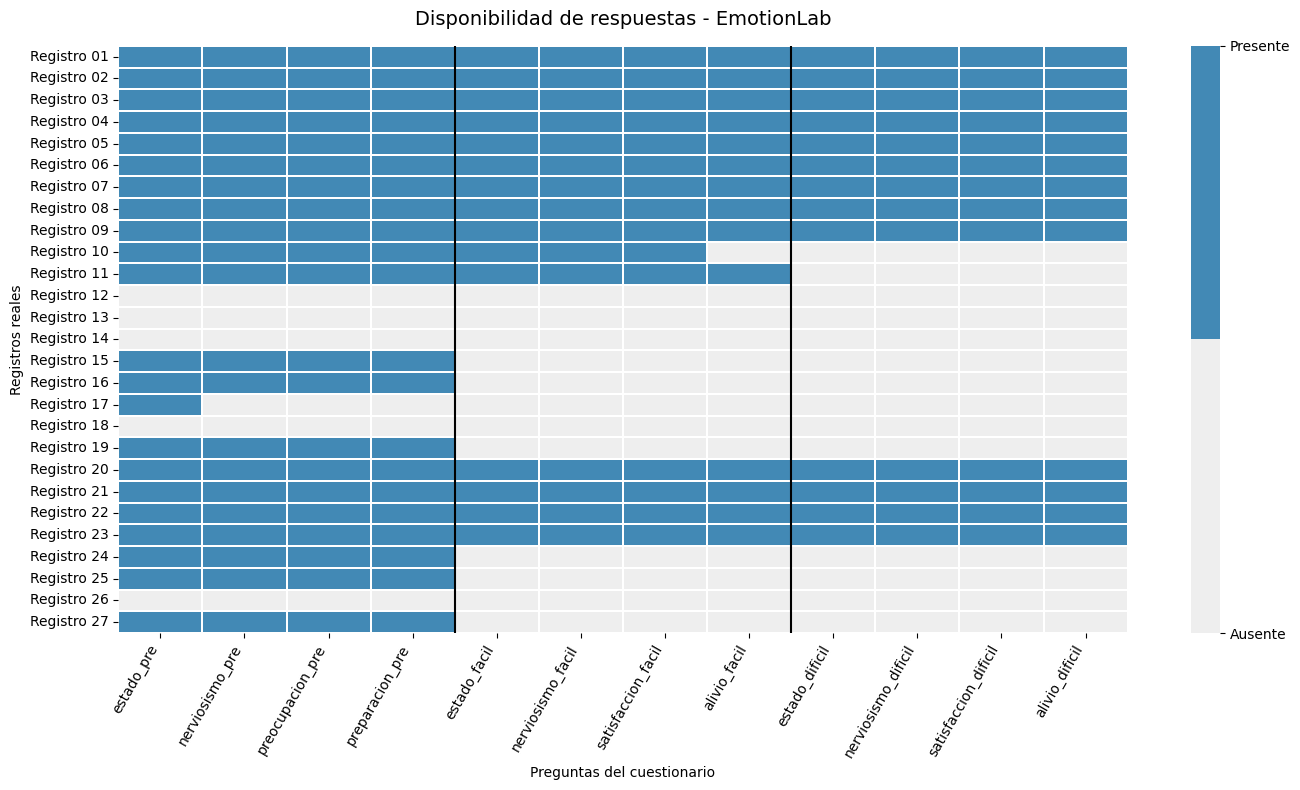

In [ ]:

# =========================================================
# 3.3.3 - MAPA DE CALOR DE DISPONIBILIDAD
# =========================================================

# Creamos el espacio donde mostraremos el gráfico.

fig, ax = plt.subplots(figsize=(14, 8))

# Seaborn representa la matriz utilizando dos colores:
#
# Gris: respuesta ausente (0).
# Azul: respuesta disponible (1).

grafico = sns.heatmap(
    matriz_disponibilidad,
    cmap=["#eeeeee", "#4289b5"],
    vmin=0,
    vmax=1,
    linewidths=0.3,
    cbar_kws={"ticks": [0, 1]},
    ax=ax
)

# Agregamos etiquetas explicativas a la barra de colores.

barra = grafico.collections[0].colorbar
barra.set_ticks([0, 1])
barra.set_ticklabels(["Ausente", "Presente"])

# Marcamos visualmente los límites entre las fases
# para facilitar la comparación de sus respuestas.

ax.axvline(
    len(variables_iniciales),
    color="black",
    linewidth=1.5
)

ax.axvline(
    len(variables_iniciales) + len(variables_facil),
    color="black",
    linewidth=1.5
)

# Incorporamos títulos y etiquetas descriptivas.

ax.set_title(
    "Disponibilidad de respuestas - EmotionLab",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Preguntas del cuestionario")
ax.set_ylabel("Registros reales")

plt.xticks(rotation=60, ha="right")
plt.yticks(rotation=0)

# Ajustamos los espacios y mostramos el gráfico.

plt.tight_layout()
plt.show()


## 3.4 — Estadísticas descriptivas de las respuestas reales
### ¿Qué realizaremos en esta sección?

En esta sección estudiaremos las respuestas de los **27 registros reales de EmotionLab** mediante estadísticas descriptivas, con el objetivo de comprender cómo se distribuyen las puntuaciones de las 12 preguntas del cuestionario.

Para ello, calcularemos tres grupos de indicadores:

- **Tendencia central:** media y mediana, que permiten conocer los valores alrededor de los cuales se concentran las respuestas.
- **Dispersión:** desviación estándar y rango intercuartílico, que ayudan a identificar qué tan diferentes son las respuestas entre estudiantes.
- **Distribución y disponibilidad:** cantidad de respuestas, valores mínimos, máximos y cuartiles, que permiten conocer el rango y la concentración de las puntuaciones.

### ¿Por qué es importante?

Porque antes de comparar el nerviosismo o el estado emocional entre las distintas fases, necesitamos comprender cómo se comportan las respuestas de cada pregunta.

Esto nos permitirá identificar tendencias, diferencias y variaciones que podrían resultar relevantes para los análisis posteriores de EmotionLab.

**Importante:** utilizaremos exclusivamente las respuestas reales disponibles, sin reemplazar los valores ausentes. Debido a que trabajamos con una escala ordinal de 1 a 9, daremos especial importancia a la mediana y los cuartiles.

In [ ]:

# =========================================================
# 3.4.1 - CÁLCULO DE ESTADÍSTICAS DESCRIPTIVAS
# =========================================================

# Seleccionamos las 12 preguntas de los registros reales.
# Sus valores ya fueron convertidos y validados en el 3.1.

respuestas_eda = eda_reales[variables_cuestionario]

# describe() calcula automáticamente:
# cantidad, media, desviación estándar, mínimo,
# cuartiles (25%, 50%, 75%) y máximo.
#
# Pandas excluye los valores NaN de cada cálculo.
# .T coloca las preguntas en las filas de la tabla.

estadisticas = respuestas_eda.describe().T

print("Estadísticas descriptivas calculadas.")


Estadísticas descriptivas calculadas.


In [ ]:

# =========================================================
# 3.4.2 - ORGANIZACIÓN DE LAS ESTADÍSTICAS
# =========================================================

# Reemplazamos los nombres técnicos por términos
# más fáciles de comprender durante la presentación.

estadisticas = estadisticas.rename(columns={
    "count": "Cantidad",
    "mean": "Media",
    "std": "Desviación estándar",
    "min": "Mínimo",
    "25%": "Q1",
    "50%": "Mediana",
    "75%": "Q3",
    "max": "Máximo"
})

# Calculamos el rango intercuartílico (Q3 - Q1).
# Representa la amplitud de la mitad central
# de las respuestas disponibles.

estadisticas["Rango intercuartílico"] = (
    estadisticas["Q3"] - estadisticas["Q1"]
)

# La cantidad de respuestas debe mostrarse como entero.
# Redondeamos las demás medidas a dos decimales.

estadisticas["Cantidad"] = estadisticas["Cantidad"].astype(int)
estadisticas = estadisticas.round(2)

print("Estadísticas organizadas correctamente.")


Estadísticas organizadas correctamente.


In [ ]:

# =========================================================
# 3.4.3 - PRESENTACIÓN DE LAS ESTADÍSTICAS
# =========================================================

# Mostramos la tabla con los resultados de las 12 preguntas.
# Cada fila corresponde a una variable del cuestionario.

print("ESTADÍSTICAS DESCRIPTIVAS - EMOTIONLAB")
display(estadisticas)

# Verificamos que todas las preguntas estén incluidas.

if len(estadisticas) != len(variables_cuestionario):
    raise ValueError("Faltan variables en el resumen estadístico.")

print("\nAnálisis descriptivo completado.")


ESTADÍSTICAS DESCRIPTIVAS - EMOTIONLAB


,Cantidad,Media,Desviación estándar,Mínimo,Q1,Mediana,Q3,Máximo,Rango intercuartílico
estado_pre,22,4.36,3.14,1.0,1.25,3.5,7.0,9.0,5.75
nerviosismo_pre,21,4.19,2.69,1.0,2.00,3.0,6.0,9.0,4.00
preocupacion_pre,21,3.62,2.44,1.0,1.00,4.0,5.0,9.0,4.00
preparacion_pre,21,4.29,3.04,1.0,2.00,3.0,7.0,9.0,5.00
estado_facil,15,2.87,2.64,1.0,1.00,2.0,4.0,9.0,3.00
nerviosismo_facil,15,3.33,2.72,1.0,1.00,2.0,5.0,9.0,4.00
satisfaccion_facil,15,3.00,2.67,1.0,1.50,2.0,2.5,9.0,1.00
alivio_facil,14,2.71,2.13,1.0,1.00,2.5,3.0,8.0,2.00
estado_dificil,13,1.85,1.07,1.0,1.00,2.0,2.0,4.0,1.00
nerviosismo_dificil,13,2.77,2.13,1.0,1.00,3.0,3.0,9.0,2.00



Análisis descriptivo completado.


## 3.5 — Distribución de respuestas
### ¿Qué realizaremos en esta sección?

En esta sección analizaremos cómo se distribuyen las respuestas de los estudiantes reales en las 12 preguntas de EmotionLab, utilizando gráficos de barras para representar la frecuencia de cada puntuación.

Para ello, realizaremos tres procesos:

- **Cálculo de frecuencias:** contaremos cuántas veces aparece cada valor de la escala de 1 a 9.
- **Organización de los gráficos:** distribuiremos las 12 preguntas según las fases inicial, fácil y difícil.
- **Visualización:** representaremos las frecuencias utilizando las mismas escalas para facilitar su comparación.

### ¿Por qué es importante?

Las estadísticas descriptivas permiten conocer valores generales, como la media y la mediana, pero no muestran cómo se distribuyen todas las respuestas.

Por ejemplo, dos preguntas podrían tener la misma media, aunque sus respuestas estén concentradas en valores muy diferentes.

Estos gráficos nos ayudarán a identificar concentraciones de respuestas, diferencias entre estudiantes y posibles patrones que podrían ser relevantes durante los siguientes análisis.

**Importante:** trabajaremos exclusivamente con los registros reales. Las respuestas ausentes no se incluirán en las frecuencias ni serán reemplazadas por valores estimados.

In [ ]:

# =========================================================
# 3.5.1 - CÁLCULO DE FRECUENCIAS
# =========================================================

# Organizamos las preguntas según las tres fases
# para mantener un orden lógico en los gráficos.

variables_graficos = (
    list(variables_iniciales)
    + list(variables_facil)
    + list(variables_dificil)
)

# Verificamos que estén las 12 preguntas originales,
# sin variables faltantes ni repetidas.

if (
    len(variables_graficos) != 12
    or len(set(variables_graficos)) != 12
    or set(variables_graficos) != set(variables_cuestionario)
):
    raise ValueError("Revisa las variables del cuestionario.")

# Definimos la escala utilizada en EmotionLab.

escala = range(ESCALA_MINIMA, ESCALA_MAXIMA + 1)

# value_counts() cuenta cuántas veces aparece cada respuesta.
# reindex() incluye también las puntuaciones con frecuencia 0.
#
# Guardamos las frecuencias para reutilizarlas
# sin repetir los cálculos al generar los gráficos.

frecuencias_eda = {
    variable: eda_reales[variable]
    .value_counts()
    .reindex(escala, fill_value=0)
    for variable in variables_graficos
}

print("Frecuencias calculadas para las 12 preguntas.")


Frecuencias calculadas para las 12 preguntas.


Gráficos de distribución preparados.


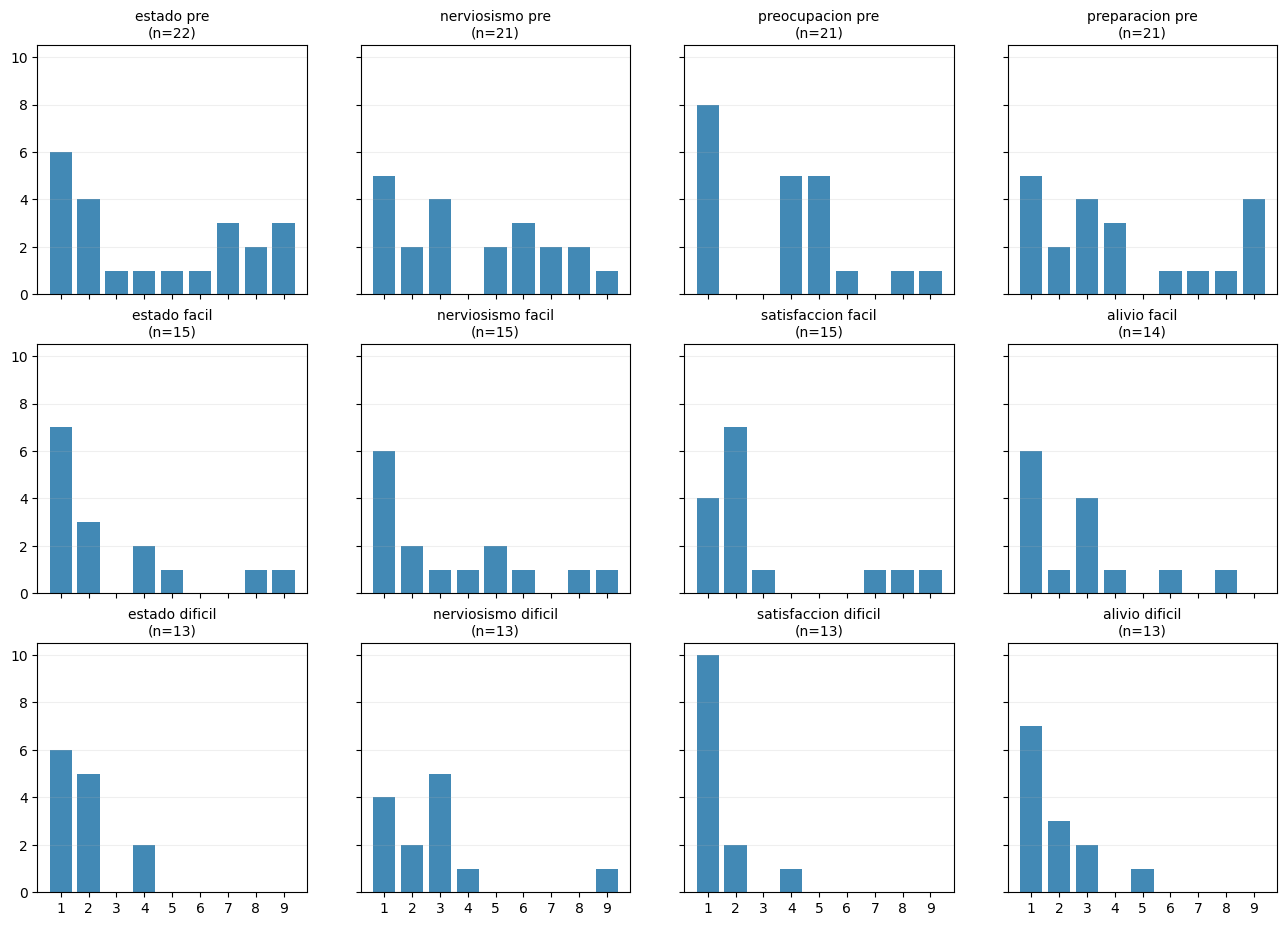

In [ ]:

# =========================================================
# 3.5.2 - GRÁFICOS DE DISTRIBUCIÓN
# =========================================================

# Creamos una figura con 3 filas y 4 columnas.
#
# Cada fila representa una fase de EmotionLab:
# inicial, fácil y difícil.
#
# sharex y sharey permiten compartir las escalas
# para facilitar la comparación entre preguntas.

figura, ejes = plt.subplots(
    3, 4,
    figsize=(16, 11),
    sharex=True,
    sharey=True
)

# Recorremos las preguntas y asignamos un gráfico
# a cada variable utilizando los ejes disponibles.

for eje, variable in zip(ejes.flat, variables_graficos):

    frecuencias = frecuencias_eda[variable]

    # Representamos cuántos estudiantes seleccionaron
    # cada puntuación entre 1 y 9.

    eje.bar(
        frecuencias.index,
        frecuencias.values,
        color="#4289b5"
    )

    # Mostramos el nombre de la pregunta y su cantidad
    # de respuestas disponibles.
    #
    # n representa respuestas observadas, no el total
    # de los 27 estudiantes.

    eje.set_title(
        f"{variable.replace('_', ' ')}\n(n={frecuencias.sum()})",
        fontsize=10
    )

    eje.set_xticks(list(escala))
    eje.grid(axis="y", alpha=0.2)

print("Gráficos de distribución preparados.")


In [ ]:

# =========================================================
# 3.5.3 - PRESENTACIÓN DE LAS DISTRIBUCIONES
# =========================================================

# Identificamos la frecuencia más alta de todas
# las preguntas para utilizar un mismo límite vertical.

frecuencia_maxima = max(
    frecuencias.max()
    for frecuencias in frecuencias_eda.values()
)

# Establecemos el mismo rango del eje vertical
# para evitar comparaciones visuales engañosas.

ejes[0, 0].set_ylim(
    0,
    max(1, frecuencia_maxima) + 0.5
)

# Agregamos etiquetas generales en lugar de repetir
# los nombres de los ejes en los 12 gráficos.

figura.supxlabel("Puntuación de respuesta (1 a 9)")
figura.supylabel("Cantidad de respuestas")

# Incorporamos un título que identifique el análisis.

figura.suptitle(
    "Distribución de respuestas reales - EmotionLab",
    fontsize=15
)

# Ajustamos los espacios y mostramos la figura.

plt.tight_layout()
plt.show()

print("Visualización de distribuciones completada.")


<Figure size 640x480 with 0 Axes>

Visualización de distribuciones completada.


## 3.6 — Comparación de las respuestas emocionales entre fases
### ¿Qué realizaremos en esta sección?

En esta sección analizaremos las respuestas relacionadas con el **nerviosismo y el estado emocional** de los estudiantes durante los tres momentos de EmotionLab: inicial, dificultad fácil y dificultad difícil.

Para ello, realizaremos tres procesos:

- **Selección de indicadores:** identificaremos las preguntas de nerviosismo y estado emocional que se repiten en los tres formularios.
- **Organización de respuestas:** reuniremos las puntuaciones de cada fase para facilitar su comparación.
- **Visualización:** utilizaremos gráficos de caja (*boxplots*) y puntos individuales para observar medianas, dispersión y diferencias entre las respuestas.

### ¿Por qué es importante?

Porque necesitamos comprender si las respuestas emocionales presentan cambios entre los distintos momentos de la experiencia.

Los gráficos nos ayudarán a identificar tendencias que podrían resultar relevantes para comprender la tensión emocional percibida por los estudiantes.

**Importante:** las comparaciones serán exploratorias. No podremos afirmar que la dificultad de las presentaciones sea la causa de los cambios, y tampoco interpretaremos las puntuaciones como diagnósticos psicológicos.

In [ ]:

# =========================================================
# 3.6.1 - SELECCIÓN DE LOS INDICADORES EMOCIONALES
# =========================================================

# EmotionLab registra nerviosismo y estado emocional
# en tres momentos de la experiencia.
#
# Organizamos las columnas según la fase a la que
# pertenece cada respuesta.

indicadores = {
    "Nerviosismo": {
        "Inicial": "nerviosismo_pre",
        "Fácil": "nerviosismo_facil",
        "Difícil": "nerviosismo_dificil"
    },
    "Estado emocional": {
        "Inicial": "estado_pre",
        "Fácil": "estado_facil",
        "Difícil": "estado_dificil"
    }
}

orden_etapas = ["Inicial", "Fácil", "Difícil"]

# Comprobamos que las seis variables estén disponibles
# en los registros reales preparados durante el 3.1.
#
# Si falta alguna, detenemos el análisis para evitar
# comparar información incorrecta.

variables_comparacion = [
    variable
    for columnas in indicadores.values()
    for variable in columnas.values()
]

faltantes = [
    variable for variable in variables_comparacion
    if variable not in eda_reales.columns
]

if faltantes:
    raise ValueError(
        f"Faltan indicadores emocionales: {faltantes}"
    )

print("Indicadores emocionales preparados correctamente.")
print("Variables seleccionadas:", len(variables_comparacion))


Indicadores emocionales preparados correctamente.
Variables seleccionadas: 6


In [ ]:

# =========================================================
# 3.6.2 - ORGANIZACIÓN DE RESPUESTAS POR FASE
# =========================================================

# Seaborn necesita que las respuestas estén organizadas
# en columnas que indiquen la fase y su puntuación.
#
# melt() transforma las columnas originales en filas,
# dejando todas las respuestas bajo una misma estructura.

datos_indicadores = {}
resumen_indicadores = []

for nombre, columnas in indicadores.items():

    # Seleccionamos únicamente las tres preguntas
    # correspondientes al indicador.

    datos = eda_reales[list(columnas.values())].copy()

    # Cambiamos los nombres técnicos por las fases.
    # Por ejemplo: nerviosismo_pre pasa a ser Inicial.

    datos.columns = list(columnas.keys())

    # Unimos las respuestas en dos columnas:
    # Etapa: momento de la experiencia.
    # Respuesta: puntuación entregada por el estudiante.

    datos = datos.melt(
        var_name="Etapa",
        value_name="Respuesta"
    ).dropna(subset=["Respuesta"])

    # Conservamos solo las respuestas observadas.
    # No estimamos ni reemplazamos valores ausentes.

    datos_indicadores[nombre] = datos

    # Registramos la cantidad de respuestas y su mediana
    # para conocer el tamaño de cada grupo comparado.

    for etapa in orden_etapas:

        respuestas = datos.loc[
            datos["Etapa"] == etapa, "Respuesta"
        ]

        resumen_indicadores.append({
            "Indicador": nombre,
            "Etapa": etapa,
            "Respuestas": len(respuestas),
            "Mediana": respuestas.median()
        })

# Creamos una tabla resumida para revisar los datos.

tabla_indicadores = pd.DataFrame(resumen_indicadores)

print("RESPUESTAS EMOCIONALES POR FASE - EMOTIONLAB")
display(tabla_indicadores.round(2))


RESPUESTAS EMOCIONALES POR FASE - EMOTIONLAB


,Indicador,Etapa,Respuestas,Mediana
0,Nerviosismo,Inicial,21,3.0
1,Nerviosismo,Fácil,15,2.0
2,Nerviosismo,Difícil,13,3.0
3,Estado emocional,Inicial,22,3.5
4,Estado emocional,Fácil,15,2.0
5,Estado emocional,Difícil,13,2.0


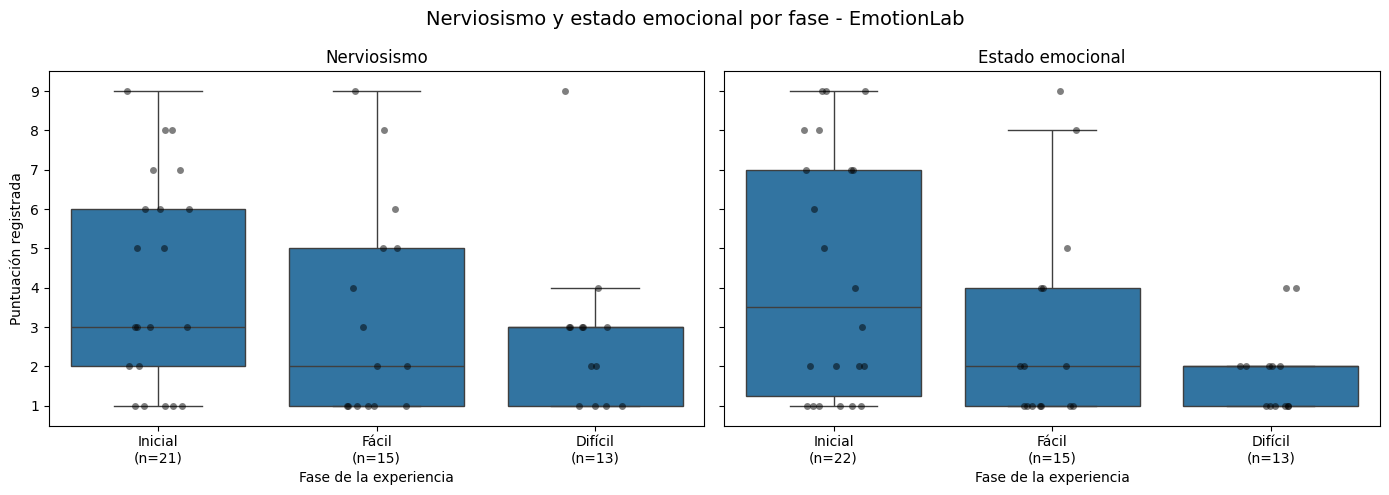

Comparación exploratoria completada.


In [ ]:

# =========================================================
# 3.6.3 - COMPARACIÓN EMOCIONAL ENTRE FASES
# =========================================================

# Creamos dos gráficos en una misma figura.
# sharey=True mantiene la misma escala vertical
# para ambos indicadores.

figura, ejes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharey=True
)

for eje, (nombre, datos) in zip(
    ejes, datos_indicadores.items()
):

    # Si no existen respuestas, mostramos un aviso
    # en lugar de generar un gráfico vacío.

    if datos.empty:
        eje.set_title(nombre)
        eje.text(
            0.5, 0.5,
            "Sin respuestas disponibles",
            ha="center",
            va="center",
            transform=eje.transAxes
        )
        eje.set_xticks([])
        continue

    # El boxplot muestra la mediana, los cuartiles
    # y la dispersión de las respuestas.
    #
    # Ocultamos los puntos extremos del boxplot
    # porque los mostraremos con stripplot.

    sns.boxplot(
        data=datos,
        x="Etapa",
        y="Respuesta",
        order=orden_etapas,
        showfliers=False,
        ax=eje
    )

    # Agregamos las respuestas individuales.
    #
    # jitter separa ligeramente los puntos para
    # que no queden todos superpuestos.
    #
    # Esto permite observar las puntuaciones reales,
    # incluyendo los posibles valores extremos.

    sns.stripplot(
        data=datos,
        x="Etapa",
        y="Respuesta",
        order=orden_etapas,
        color="black",
        alpha=0.5,
        jitter=0.15,
        ax=eje
    )

    # Mostramos cuántas respuestas tiene cada fase.
    # Es importante porque no todos los estudiantes
    # completaron los tres formularios.

    etiquetas = [
        f"{etapa}\n(n={(datos['Etapa'] == etapa).sum()})"
        for etapa in orden_etapas
    ]

    eje.set_xticks(range(len(orden_etapas)))
    eje.set_xticklabels(etiquetas)

    # Utilizamos la misma escala de 1 a 9
    # para facilitar la comparación de resultados.

    eje.set_title(nombre)
    eje.set_xlabel("Fase de la experiencia")
    eje.set_ylabel("Puntuación registrada")
    eje.set_ylim(ESCALA_MINIMA - 0.5, ESCALA_MAXIMA + 0.5)

# Agregamos el título general de la figura.

figura.suptitle(
    "Nerviosismo y estado emocional por fase - EmotionLab",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("Comparación exploratoria completada.")


## 3.7 — Análisis de correlaciones
### ¿Qué realizaremos en esta sección?

Analizaremos las relaciones entre las 12 variables de EmotionLab utilizando el coeficiente de correlación de **Spearman**, un método adecuado para explorar asociaciones entre respuestas ordinales.

Dividiremos el análisis en cuatro partes:

- **Preparación:** seleccionaremos las respuestas reales que utilizaremos en las correlaciones.
- **Cálculo:** identificaremos las asociaciones entre variables y la cantidad de estudiantes disponibles para cada comparación.
- **Revisión:** organizaremos los resultados en tablas para comprender qué correlaciones pudieron calcularse.
- **Visualización:** generaremos un mapa de calor que permita identificar asociaciones positivas y negativas.

### ¿Por qué es importante?

Este análisis nos ayudará a comprender si determinadas respuestas tienden a variar conjuntamente. Por ejemplo, podremos explorar si los estudiantes que declaran mayor nerviosismo también presentan ciertas tendencias en sus respuestas de preparación o satisfacción.

Esto puede aportar información relevante para comprender las relaciones entre las variables antes de desarrollar el modelo de Machine Learning.

**Consideración:** una correlación no demuestra causalidad. Además, trabajaremos exclusivamente con los datos reales disponibles y exigiremos un mínimo de cinco estudiantes con respuestas en ambas variables para calcular cada correlación exploratoria.

In [ ]:

# =========================================================
# 3.7.1 - PREPARACIÓN DE LOS DATOS PARA CORRELACIONES
# =========================================================

# Utilizamos los registros reales preparados en el 3.1.
# No incorporamos datos sintéticos ni estimamos respuestas.

# Verificamos que las variables del cuestionario existan
# y no estén repetidas.

faltantes = [
    variable for variable in variables_cuestionario
    if variable not in eda_reales.columns
]

if faltantes or len(set(variables_cuestionario)) != 12:
    raise ValueError(
        f"Revisa las 12 variables del cuestionario. "
        f"Columnas faltantes: {faltantes}"
    )

# Seleccionamos únicamente las respuestas que analizaremos.
# No es necesario crear otra copia porque no las modificaremos.

respuestas_correlacion = eda_reales[variables_cuestionario]

print("Variables preparadas:", respuestas_correlacion.shape[1])
print("Registros reales:", len(respuestas_correlacion))


Variables preparadas: 12
Registros reales: 27


In [ ]:

# =========================================================
# 3.7.2 - CÁLCULO DE CORRELACIONES DE SPEARMAN
# =========================================================

# Establecemos el mínimo de pares necesarios.
# Cada par corresponde a un estudiante que respondió
# las dos preguntas que estamos comparando.

minimo_pares = 5

# corr() calcula las asociaciones de Spearman.
# min_periods evita calcular correlaciones cuando
# existen menos de cinco pares válidos.
#
# Pandas excluye los NaN de cada comparación sin
# eliminar al estudiante de todos los demás análisis.

matriz_correlacion = respuestas_correlacion.corr(
    method="spearman",
    min_periods=minimo_pares
)

# Creamos una matriz donde:
# 1 = respuesta presente.
# 0 = respuesta ausente.

presencia = respuestas_correlacion.notna().astype(int)

# Multiplicamos la matriz transpuesta por la original.
# Así contamos cuántos estudiantes tienen respuestas
# disponibles en cada combinación de preguntas.

matriz_pares = presencia.T @ presencia

print("Correlaciones de Spearman calculadas.")
print("Mínimo de pares exigidos:", minimo_pares)


Correlaciones de Spearman calculadas.
Mínimo de pares exigidos: 5


In [ ]:

# =========================================================
# 3.7.3 - REVISIÓN DE LOS RESULTADOS
# =========================================================

# Primero mostramos cuántos estudiantes tienen
# respuestas disponibles para cada par de variables.

print("ESTUDIANTES DISPONIBLES POR COMPARACIÓN")
display(matriz_pares)

# Después mostramos los coeficientes de Spearman.
# Redondeamos a dos decimales para facilitar la lectura.

print("\nMATRIZ DE CORRELACIONES - EMOTIONLAB")
display(matriz_correlacion.round(2))

# Identificamos las correlaciones que no pudieron
# calcularse por falta de datos o ausencia de variación.
#
# Estos valores aparecerán como NaN y NO deben
# interpretarse como correlaciones iguales a cero.

correlaciones_ausentes = matriz_correlacion.isna()

print("\nRevisión de correlaciones completada.")


ESTUDIANTES DISPONIBLES POR COMPARACIÓN


,estado_pre,nerviosismo_pre,preocupacion_pre,preparacion_pre,estado_facil,nerviosismo_facil,satisfaccion_facil,alivio_facil,estado_dificil,nerviosismo_dificil,satisfaccion_dificil,alivio_dificil
estado_pre,22,21,21,21,15,15,15,14,13,13,13,13
nerviosismo_pre,21,21,21,21,15,15,15,14,13,13,13,13
preocupacion_pre,21,21,21,21,15,15,15,14,13,13,13,13
preparacion_pre,21,21,21,21,15,15,15,14,13,13,13,13
estado_facil,15,15,15,15,15,15,15,14,13,13,13,13
nerviosismo_facil,15,15,15,15,15,15,15,14,13,13,13,13
satisfaccion_facil,15,15,15,15,15,15,15,14,13,13,13,13
alivio_facil,14,14,14,14,14,14,14,14,13,13,13,13
estado_dificil,13,13,13,13,13,13,13,13,13,13,13,13
nerviosismo_dificil,13,13,13,13,13,13,13,13,13,13,13,13



MATRIZ DE CORRELACIONES - EMOTIONLAB


,estado_pre,nerviosismo_pre,preocupacion_pre,preparacion_pre,estado_facil,nerviosismo_facil,satisfaccion_facil,alivio_facil,estado_dificil,nerviosismo_dificil,satisfaccion_dificil,alivio_dificil
estado_pre,1.00,0.56,0.17,0.73,0.65,0.42,0.52,0.30,0.11,0.13,0.21,0.43
nerviosismo_pre,0.56,1.00,0.29,0.52,0.51,0.49,0.70,0.31,0.13,0.25,0.07,0.43
preocupacion_pre,0.17,0.29,1.00,0.24,-0.09,-0.11,-0.05,-0.03,0.45,0.60,0.29,-0.07
preparacion_pre,0.73,0.52,0.24,1.00,0.70,0.69,0.43,0.75,0.35,0.64,0.08,0.59
estado_facil,0.65,0.51,-0.09,0.70,1.00,0.76,0.74,0.75,0.24,0.22,0.20,0.51
nerviosismo_facil,0.42,0.49,-0.11,0.69,0.76,1.00,0.67,0.84,0.16,0.39,0.17,0.54
satisfaccion_facil,0.52,0.70,-0.05,0.43,0.74,0.67,1.00,0.60,0.10,-0.00,-0.25,0.20
alivio_facil,0.30,0.31,-0.03,0.75,0.75,0.84,0.60,1.00,0.29,0.62,0.07,0.58
estado_dificil,0.11,0.13,0.45,0.35,0.24,0.16,0.10,0.29,1.00,0.55,0.49,0.15
nerviosismo_dificil,0.13,0.25,0.60,0.64,0.22,0.39,-0.00,0.62,0.55,1.00,0.44,0.65



Revisión de correlaciones completada.


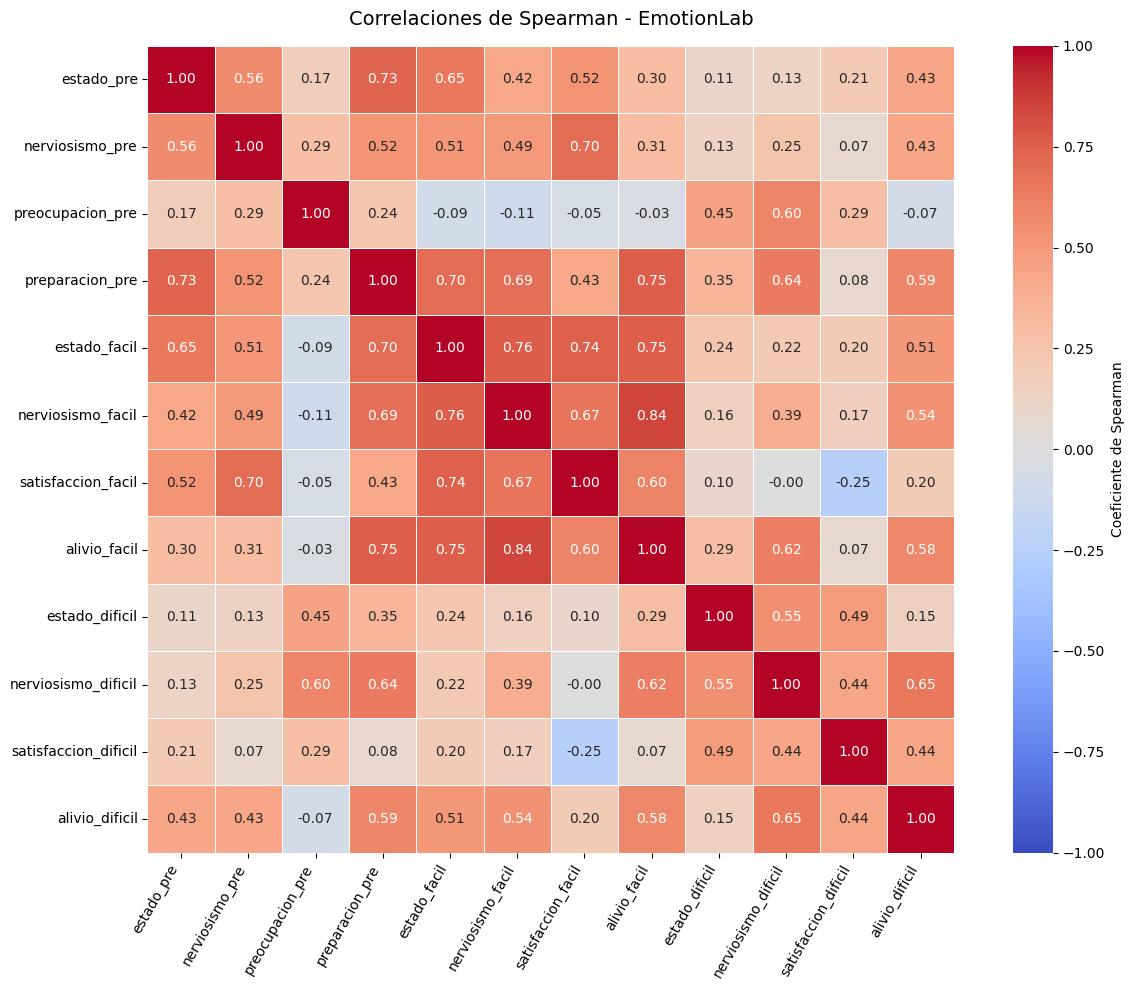

Mapa de correlaciones generado correctamente.


In [ ]:

# =========================================================
# 3.7.4 - MAPA DE CALOR DE CORRELACIONES
# =========================================================

# Verificamos que exista al menos una correlación válida.
# Si todas son NaN, no generaremos un gráfico vacío.

if matriz_correlacion.notna().any().any():

    # Creamos el espacio donde mostraremos el mapa.

    fig, ax = plt.subplots(figsize=(13, 10))

    # Cada celda representa la correlación entre dos preguntas.
    #
    # Rojo: asociación positiva.
    # Azul: asociación negativa.
    # Valores cercanos a 0: asociación monotónica débil.
    #
    # mask oculta las correlaciones que no se pudieron
    # calcular por falta de datos o variación.

    sns.heatmap(
        matriz_correlacion,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        mask=correlaciones_ausentes,
        linewidths=0.4,
        square=True,
        cbar_kws={"label": "Coeficiente de Spearman"},
        ax=ax
    )

    # Ajustamos el título y las etiquetas para que
    # las 12 variables puedan identificarse claramente.

    ax.set_title(
        "Correlaciones de Spearman - EmotionLab",
        fontsize=14,
        pad=15
    )

    plt.xticks(rotation=60, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

    print("Mapa de correlaciones generado correctamente.")

else:
    print("No existen correlaciones suficientes para graficar.")


## 3.8 — Perfil global del estudiante
### ¿Qué realizaremos en esta sección?

Construiremos un perfil descriptivo individual de los estudiantes de EmotionLab, utilizando las respuestas registradas durante las fases inicial, fácil y difícil.

Para ello, realizaremos tres procesos:

- **Selección:** identificaremos a los estudiantes que completaron las 12 preguntas de los tres formularios.
- **Cálculo de indicadores:** obtendremos la mediana del nerviosismo, la mediana del estado emocional y los cambios numéricos entre el inicio y el final.
- **Resumen:** presentaremos los perfiles individuales y sus estadísticas descriptivas generales.

### ¿Por qué es importante?

Los análisis anteriores nos permitieron conocer las tendencias generales de los estudiantes. Sin embargo, esas tendencias no muestran necesariamente lo que ocurrió con cada participante.

Este apartado nos ayudará a identificar diferencias individuales y estudiar cómo cambiaron las puntuaciones de un mismo estudiante durante la experiencia.

**Importante:** los indicadores calculados son descriptivos. No representan todavía el índice de tensión de EmotionLab ni permiten determinar niveles clínicos de estrés.

Trabajaremos únicamente con estudiantes que tengan las 12 respuestas completas, sin estimar valores faltantes.

In [ ]:

# =========================================================
# 3.8.1 - SELECCIÓN DE PERFILES COMPLETOS
# =========================================================

# Para construir un perfil global necesitamos conocer
# las respuestas de las tres fases de EmotionLab.
#
# Seleccionamos únicamente los registros que contienen
# las 12 preguntas completas del cuestionario.

perfiles_completos = eda_reales.dropna(
    subset=variables_cuestionario
).copy()

# Definimos las preguntas que representan nerviosismo
# y estado emocional en cada momento de la experiencia.
#
# Conservamos el orden: Inicial, Fácil y Difícil.

columnas_nerviosismo = [
    "nerviosismo_pre",
    "nerviosismo_facil",
    "nerviosismo_dificil"
]

columnas_estado = [
    "estado_pre",
    "estado_facil",
    "estado_dificil"
]

# Comprobamos que las variables y el identificador
# estén disponibles antes de realizar los cálculos.

columnas_requeridas = (
    columnas_nerviosismo
    + columnas_estado
    + ["id_estudiante"]
)

faltantes = [
    columna for columna in columnas_requeridas
    if columna not in perfiles_completos.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas para el perfil: {faltantes}")

print("Registros reales:", len(eda_reales))
print("Perfiles completos:", len(perfiles_completos))


Registros reales: 27
Perfiles completos: 13


In [ ]:

# =========================================================
# 3.8.2 - CÁLCULO DEL PERFIL GLOBAL
# =========================================================

# Calculamos la mediana de nerviosismo y estado emocional
# utilizando las respuestas de las tres fases.
#
# median(axis=1) calcula el valor central por estudiante,
# en lugar de calcularlo para todos los participantes.

perfiles_completos["mediana_nerviosismo"] = (
    perfiles_completos[columnas_nerviosismo].median(axis=1)
)

perfiles_completos["mediana_estado"] = (
    perfiles_completos[columnas_estado].median(axis=1)
)

# Calculamos el cambio entre la evaluación final
# (dificultad difícil) y la evaluación inicial.
#
# Cambio positivo: la puntuación final es mayor.
# Cambio negativo: la puntuación final es menor.
# Cambio cero: ambas puntuaciones son iguales.

perfiles_completos["cambio_nerviosismo"] = (
    perfiles_completos["nerviosismo_dificil"]
    - perfiles_completos["nerviosismo_pre"]
)

perfiles_completos["cambio_estado"] = (
    perfiles_completos["estado_dificil"]
    - perfiles_completos["estado_pre"]
)

# Estos cambios representan diferencias numéricas.
# Su interpretación emocional depende del significado
# de cada escala utilizada en Unity.

print("Indicadores individuales calculados correctamente.")


Indicadores individuales calculados correctamente.


In [ ]:

# =========================================================
# 3.8.3 - RESUMEN DE LOS PERFILES GLOBALES
# =========================================================

# Seleccionamos los cuatro indicadores calculados
# para construir una tabla descriptiva individual.

columnas_perfil = [
    "mediana_nerviosismo",
    "mediana_estado",
    "cambio_nerviosismo",
    "cambio_estado"
]

# Conservamos el identificador seudónimo para mantener
# la correspondencia con los registros originales.

perfil_global = perfiles_completos[
    ["id_estudiante"] + columnas_perfil
].copy()

print("PERFIL GLOBAL - EMOTIONLAB")
print("Estudiantes analizados:", len(perfil_global))

if not perfil_global.empty:

    # Para mostrar los resultados utilizamos etiquetas
    # temporales, evitando exponer identificadores
    # originales durante la presentación.

    perfil_presentacion = perfil_global.copy()

    perfil_presentacion["id_estudiante"] = [
        f"Registro {i:02d}"
        for i in range(1, len(perfil_global) + 1)
    ]

    display(perfil_presentacion)

    # describe() resume la distribución de los indicadores
    # entre los estudiantes con cuestionarios completos.
    #
    # Calcula cantidad, media, mediana, desviación estándar,
    # valores mínimos, máximos y cuartiles.

    print("\nRESUMEN ESTADÍSTICO DE LOS PERFILES")
    display(perfil_global[columnas_perfil].describe().round(2))

else:
    print("No existen cuestionarios completos para este análisis.")

print("\nAnálisis de perfiles globales finalizado.")


PERFIL GLOBAL - EMOTIONLAB
Estudiantes analizados: 13


,id_estudiante,mediana_nerviosismo,mediana_estado,cambio_nerviosismo,cambio_estado
0,Registro 01,3.0,1.0,0.0,3.0
1,Registro 02,3.0,2.0,0.0,0.0
2,Registro 03,1.0,1.0,2.0,3.0
3,Registro 04,2.0,2.0,-3.0,-1.0
4,Registro 05,3.0,2.0,0.0,0.0
5,Registro 06,1.0,1.0,0.0,0.0
6,Registro 07,2.0,1.0,7.0,0.0
7,Registro 08,1.0,1.0,0.0,0.0
8,Registro 09,1.0,1.0,0.0,-5.0
19,Registro 10,1.0,1.0,-4.0,0.0



RESUMEN ESTADÍSTICO DE LOS PERFILES


,mediana_nerviosismo,mediana_estado,cambio_nerviosismo,cambio_estado
count,13.00,13.00,13.00,13.00
mean,2.15,1.54,-0.31,-0.46
std,1.21,0.88,2.84,2.37
min,1.00,1.00,-4.00,-5.00
25%,1.00,1.00,-2.00,-1.00
50%,2.00,1.00,0.00,0.00
75%,3.00,2.00,0.00,0.00
max,5.00,4.00,7.00,3.00



Análisis de perfiles globales finalizado.


## 3.9 — Revisión exploratoria de valores extremos
### ¿Qué realizaremos en esta sección?

En esta sección revisaremos las respuestas de los estudiantes reales de EmotionLab para identificar puntuaciones que se encuentren alejadas de la distribución central de cada pregunta.

Utilizaremos el **rango intercuartílico (IQR)**, un método estadístico que permite detectar posibles valores extremos mediante los cuartiles Q1 y Q3.

El análisis se dividirá en tres partes:

- **Cálculo de cuartiles:** obtendremos Q1, Q3 y el rango intercuartílico de las 12 preguntas.
- **Identificación de valores extremos:** calcularemos los límites estadísticos y contaremos las respuestas que se encuentren fuera de ellos.
- **Revisión de resultados:** presentaremos una tabla para reconocer qué variables contienen posibles valores extremos.

### ¿Por qué es importante?

Este procedimiento nos permitirá identificar respuestas poco frecuentes y estudiar la variabilidad existente entre los estudiantes.

Sin embargo, **un valor extremo no necesariamente es una respuesta incorrecta**. Por ejemplo, si la mayoría de los participantes responde 1 en una pregunta, una respuesta de 8 podría identificarse como extrema y seguir siendo válida dentro de la escala de EmotionLab.

Por esta razón, no eliminaremos ni modificaremos las respuestas identificadas. El análisis será exclusivamente descriptivo y utilizará los registros reales disponibles.

In [ ]:

# =========================================================
# 3.9.1 - CÁLCULO DEL RANGO INTERCUARTÍLICO
# =========================================================

# Utilizamos las 12 preguntas de los registros reales.
# Los valores ausentes se excluyen automáticamente
# del cálculo de los cuartiles.

respuestas_extremos = eda_reales[variables_cuestionario]

# Calculamos Q1 (25 %) y Q3 (75 %) para cada pregunta.
#
# Q1: primer cuartil de las respuestas.
# Q3: tercer cuartil de las respuestas.

cuartiles = respuestas_extremos.quantile([0.25, 0.75])

q1 = cuartiles.loc[0.25]
q3 = cuartiles.loc[0.75]

# El IQR representa la diferencia entre Q3 y Q1.
# Nos permite medir la dispersión de la mitad
# central de las respuestas de cada variable.

rango_iqr = q3 - q1

print("Cuartiles y rangos intercuartílicos calculados.")


Cuartiles y rangos intercuartílicos calculados.


In [ ]:

# =========================================================
# 3.9.2 - IDENTIFICACIÓN DE VALORES EXTREMOS
# =========================================================

# Establecemos los límites estadísticos:
#
# Inferior = Q1 - 1.5 * IQR
# Superior = Q3 + 1.5 * IQR
#
# Una respuesta fuera de estos límites será
# considerada un posible valor extremo por IQR.

limite_inferior = q1 - 1.5 * rango_iqr
limite_superior = q3 + 1.5 * rango_iqr

# Comparamos las respuestas de cada pregunta
# con sus límites correspondientes.
#
# lt() identifica valores menores al límite inferior.
# gt() identifica valores mayores al límite superior.
#
# axis="columns" permite comparar cada columna
# con el límite calculado para esa misma pregunta.

marcas_extremos = (
    respuestas_extremos.lt(limite_inferior, axis="columns")
    | respuestas_extremos.gt(limite_superior, axis="columns")
)

# Contamos cuántas respuestas fueron evaluadas
# y cuántas se encuentran fuera de los límites.

cantidad_respuestas = respuestas_extremos.count()
cantidad_extremos = marcas_extremos.sum()

# Si una pregunta no tiene respuestas disponibles,
# dejamos su cantidad de extremos sin calcular (NaN).
# No debemos confundir "sin datos" con "cero extremos".

cantidad_extremos = cantidad_extremos.where(
    cantidad_respuestas.gt(0),
    np.nan
)

print("Posibles valores extremos identificados.")


Posibles valores extremos identificados.


In [ ]:

# =========================================================
# 3.9.3 - RESUMEN DE LOS VALORES EXTREMOS
# =========================================================

# Organizamos los resultados de las 12 preguntas.
# Cada fila mostrará sus respuestas disponibles,
# límites estadísticos y cantidad de posibles extremos.

tabla_extremos = pd.DataFrame({
    "Variable": variables_cuestionario,
    "Respuestas evaluadas": cantidad_respuestas.values,
    "Límite inferior": limite_inferior.values,
    "Límite superior": limite_superior.values,
    "Valores extremos por IQR": cantidad_extremos.values
})

# Redondeamos solamente la visualización.
# Los cálculos anteriores mantienen su precisión original.

print("REVISIÓN DE VALORES EXTREMOS - EMOTIONLAB")
display(tabla_extremos.round(2))

# Sumamos las respuestas identificadas como extremas.
# Este total representa respuestas, no estudiantes únicos.

total_extremos = int(cantidad_extremos.sum())

print("\nRespuestas evaluadas:", int(cantidad_respuestas.sum()))
print("Posibles valores extremos:", total_extremos)

# Una variable con IQR = 0 tiene Q1 y Q3 iguales.
# En ese caso, cualquier puntuación distinta de ese
# valor central puede quedar marcada como extrema.
#
# Esto requiere especial precaución con muestras pequeñas.

variables_iqr_cero = rango_iqr[
    rango_iqr.eq(0) & cantidad_respuestas.gt(0)
].index.tolist()

if variables_iqr_cero:
    print("\nAtención: variables con IQR igual a cero:")
    print(", ".join(variables_iqr_cero))

# Recordamos que las puntuaciones identificadas
# no se eliminan ni modifican en el dataset.

print(
    "\nAnálisis exploratorio completado. "
    "No se modificaron ni eliminaron respuestas."
)


REVISIÓN DE VALORES EXTREMOS - EMOTIONLAB


,Variable,Respuestas evaluadas,Límite inferior,Límite superior,Valores extremos por IQR
0,estado_pre,22,-7.38,15.62,0
1,nerviosismo_pre,21,-4.00,12.00,0
2,preocupacion_pre,21,-5.00,11.00,0
3,preparacion_pre,21,-5.50,14.50,0
4,estado_facil,15,-3.50,8.50,1
5,nerviosismo_facil,15,-5.00,11.00,0
6,satisfaccion_facil,15,0.00,4.00,3
7,alivio_facil,14,-2.00,6.00,1
8,estado_dificil,13,-0.50,3.50,2
9,nerviosismo_dificil,13,-2.00,6.00,1



Respuestas evaluadas: 196
Posibles valores extremos: 12

Atención: variables con IQR igual a cero:
satisfaccion_dificil

Análisis exploratorio completado. No se modificaron ni eliminaron respuestas.


## Conclusión de la Etapa 3: Análisis Exploratorio de Datos (EDA)

Durante esta etapa analizamos las respuestas de los estudiantes reales de EmotionLab, con el objetivo de comprender cómo se distribuyen sus puntuaciones, identificar posibles relaciones entre variables y estudiar las diferencias observadas durante las tres fases de la experiencia.

El análisis se realizó exclusivamente con los **27 registros reales**, sin incorporar datos sintéticos ni reemplazar respuestas faltantes.

### 1. Preparación y disponibilidad de los datos

Comenzamos verificando que las respuestas estuvieran correctamente preparadas para los análisis estadísticos.

Los principales resultados fueron:

- **12 variables** correspondientes a los tres cuestionarios.
- **196 respuestas disponibles** de 324 posibles (60,49 %).
- **128 respuestas ausentes** (39,51 %).
- **13 estudiantes** con los tres formularios completamente respondidos.

También observamos que la disponibilidad de cuestionarios completos disminuyó entre las fases: 21 en la inicial, 14 en la fácil y 13 en la difícil.

### 2. Distribución y comportamiento de las respuestas

Mediante estadísticas descriptivas, gráficos de barras y diagramas de caja estudiamos cómo se distribuyeron las puntuaciones.

Al comparar las medianas de los principales indicadores, obtuvimos:

| Indicador | Inicial | Fácil | Difícil |
|---|---:|---:|---:|
| Nerviosismo | 3 | 2 | 3 |
| Estado emocional | 3,5 | 2 | 2 |

Estos resultados muestran diferencias entre las distribuciones de las tres fases. Sin embargo, no necesariamente representan cambios individuales, porque la cantidad de respuestas disponibles varía entre formularios.

Además, la interpretación del estado emocional depende del significado de la escala utilizada en Unity.

### 3. Correlaciones y perfiles individuales

El análisis de Spearman permitió identificar asociaciones entre algunas respuestas.

Una de las correlaciones más elevadas se observó entre **nerviosismo y alivio en la fase fácil (ρ = 0,84)**. No obstante, estas relaciones son exploratorias y no demuestran causalidad.

También construimos perfiles descriptivos para los **13 estudiantes con cuestionarios completos**, calculando sus medianas y cambios individuales entre el inicio y el final de la experiencia.

Estos perfiles nos permitieron reconocer diferencias entre participantes que no siempre resultan visibles al observar únicamente las estadísticas generales.

### 4. Revisión de valores extremos

Mediante el criterio del rango intercuartílico identificamos **12 respuestas potencialmente extremas** entre las 196 respuestas disponibles.

También observamos que la variable `satisfaccion_dificil` presentó un rango intercuartílico igual a cero, debido a la concentración de puntuaciones en el valor 1.

Estas respuestas no se consideraron errores automáticamente, ya que todas permanecen dentro de la escala válida de EmotionLab.

Por esta razón, **no eliminamos ni modificamos ninguna respuesta** durante el análisis.

### 5. Resultado final de la etapa

La Etapa 3 nos permitió conocer mejor las características de los datos recopilados e identificar aspectos importantes para continuar con el proyecto:

- Las respuestas presentan diferentes distribuciones y niveles de variabilidad.
- Existen asociaciones exploratorias entre determinadas variables.
- La información faltante limita algunas comparaciones entre fases.
- Los perfiles individuales permiten complementar los resultados generales.
- La cantidad reducida de participantes exige interpretar los resultados con precaución.

**En conclusión**, logramos establecer una base estadística para comprender las respuestas de los estudiantes y orientar las siguientes etapas de EmotionLab.

Estos resultados servirán como referencia para continuar con el desarrollo experimental del sistema, manteniendo una distinción clara entre las respuestas observadas, los indicadores descriptivos y las futuras agrupaciones de Machine Learning.

Es importante destacar que los resultados obtenidos **no constituyen diagnósticos psicológicos ni permiten generalizar conclusiones a toda la población estudiantil**.

# Etapa 4: Construcción del índice exploratorio de tensión percibida

## Objetivo

Durante esta etapa desarrollaremos un procedimiento para resumir las respuestas emocionales de los estudiantes y obtener un **índice global de tensión percibida** durante la experiencia de EmotionLab.

A diferencia de los análisis anteriores, donde estudiamos las respuestas individualmente, ahora buscaremos combinar la información de las tres fases para obtener un resultado general de cada participante.

### 1. Indicadores que utilizaremos

El índice se construirá a partir de dos variables presentes en los tres cuestionarios:

- **Nerviosismo:** permitirá representar la intensidad de nerviosismo declarada por el estudiante.
- **Estado emocional:** funcionará como un indicador complementario para interpretar su experiencia.

Asignaremos una mayor ponderación al nerviosismo y revisaremos la orientación de ambas escalas antes de combinar las respuestas.

### 2. Construcción del índice

Desarrollaremos el cálculo mediante tres procesos:

- **Análisis por fase:** combinaremos los indicadores de nerviosismo y estado emocional de cada formulario.
- **Índice global:** integraremos los resultados de las fases inicial, fácil y difícil.
- **Clasificación exploratoria:** estudiaremos criterios para interpretar el índice mediante tres categorías.

Las categorías propuestas son:

- **Estado de calma:** tensión percibida relativamente baja.
- **Tensión moderada:** valores intermedios del índice.
- **Tensión elevada:** tensión percibida relativamente alta.

Las ponderaciones y los límites de estas categorías deberán documentarse y evaluarse antes de utilizarlos como una clasificación definitiva.

### 3. Tratamiento de respuestas incompletas

Consideraremos la disponibilidad de información antes de calcular el índice:

- **Tres fases completas:** permitirán calcular el índice global sin estimaciones.
- **Dos fases completas:** estudiaremos si es viable estimar la fase faltante utilizando las respuestas del mismo estudiante.
- **Una fase completa:** podremos mostrar información parcial, pero no asignaremos una clasificación global equivalente a una experiencia completa.

Cualquier valor estimado deberá distinguirse claramente de las respuestas observadas.

### 4. Diferencia con Machine Learning

EmotionLab utilizará dos procedimientos con propósitos diferentes:

- **Índice de tensión percibida:** aplicará una fórmula definida por el proyecto para resumir las respuestas emocionales.
- **Machine Learning no supervisado:** buscará identificar grupos de estudiantes con patrones de respuesta similares.

Esto significa que el modelo de Machine Learning no determinará automáticamente las categorías del índice, ni sus agrupaciones equivaldrán necesariamente a niveles de estrés.

### 5. Consideraciones metodológicas

Durante el desarrollo tendremos presentes las siguientes limitaciones:

- Trabajaremos con los **27 registros reales**, considerando que solo 13 tienen los cuestionarios completos.
- Las respuestas son autodeclaradas y utilizan una escala ordinal de 1 a 9.
- Las ponderaciones y categorías serán experimentales, no derivadas de una escala psicológica validada.
- No modificaremos las respuestas originales.
- El índice no constituirá un diagnóstico clínico ni una medición validada del estrés.

En conclusión, esta etapa permitirá avanzar desde el análisis descriptivo hacia la construcción de un indicador propio de EmotionLab, manteniendo una separación clara entre las respuestas reales, los cálculos experimentales y las futuras agrupaciones de Machine Learning.


## 4.1 — Configuración del índice de tensión percibida
### ¿Qué realizaremos en esta sección?

En esta sección definiremos la configuración inicial del índice exploratorio de tensión percibida de EmotionLab, estableciendo los indicadores, las ponderaciones y las variables necesarias para su cálculo.

El procedimiento se dividirá en tres partes:

- **Ponderaciones:** asignaremos un 70 % de importancia al nerviosismo y un 30 % al estado emocional.
- **Organización:** identificaremos las preguntas correspondientes a las fases inicial, fácil y difícil.
- **Validación:** comprobaremos que las ponderaciones sean correctas y que todas las variables estén disponibles.

### ¿Por qué es importante?

Porque necesitamos establecer reglas consistentes antes de combinar las respuestas de los estudiantes. Esto nos ayudará a evitar errores de configuración y permitirá aplicar el mismo procedimiento en las tres fases.

**Importante:** estas ponderaciones son experimentales y no corresponden a una escala psicológica validada. Antes de calcular el índice tendremos que confirmar cómo interpretar la escala de estado emocional utilizada en Unity.

Durante esta sección no calcularemos puntuaciones ni asignaremos categorías a los estudiantes.

**Nota de alcance:** este índice usa seis respuestas (dos indicadores por fase). No debe confundirse con las doce variables del K-Means de la Etapa 5.

In [ ]:
# =========================================================
# 4.1.1 - CONFIGURACIÓN DE LAS PONDERACIONES
# =========================================================

# Definimos la importancia de cada indicador:

# Nerviosismo: 70 % del cálculo.
# Estado emocional: 30 % del cálculo.

# Estos valores son experimentales y fueron
# establecidos como criterio de nuestro proyecto.

PESO_NERVIOSISMO = 0.70
PESO_ESTADO = 0.30

# Comprobamos que los pesos estén entre 0 y 1.
# También verificamos que juntos sumen el 100 %.
#
# np.isclose() permite comparar números decimales
# evitando problemas de precisión matemática.

pesos = [PESO_NERVIOSISMO, PESO_ESTADO]

if not all(np.isfinite(peso) and 0 <= peso <= 1 for peso in pesos):
    raise ValueError("Las ponderaciones deben estar entre 0 y 1.")

if not np.isclose(sum(pesos), 1.0):
    raise ValueError("Las ponderaciones deben sumar el 100 %.")

print("Ponderaciones verificadas correctamente.")

Ponderaciones verificadas correctamente.


In [ ]:

# =========================================================
# 4.1.2 - ORGANIZACIÓN DE LOS INDICADORES POR FASE
# =========================================================

# Seleccionamos las preguntas de nerviosismo y estado
# emocional que se repiten en las tres fases.

# Utilizamos los nombres existentes en eda_reales,
# que fueron preparados y validados en la Etapa 3.

# Cada tupla contiene:
# (variable de nerviosismo, variable de estado emocional)

indicadores_por_etapa = {
    "inicial": ("nerviosismo_pre", "estado_pre"),
    "facil": ("nerviosismo_facil", "estado_facil"),
    "dificil": ("nerviosismo_dificil", "estado_dificil")
}

# Reunimos las seis variables que necesitamos
# para calcular posteriormente el índice.

variables_indice = [
    variable
    for columnas in indicadores_por_etapa.values()
    for variable in columnas
]

# Verificamos que exista cada pregunta en el dataset.
# Si falta alguna, detenemos el proceso antes de
# intentar realizar cálculos con información incorrecta.

faltantes = [
    variable for variable in variables_indice
    if variable not in eda_reales.columns
]

if faltantes:
    raise ValueError(
        f"Faltan variables para construir el índice: {faltantes}"
    )

# Comprobamos que no hayamos repetido variables
# ni configurado una cantidad incorrecta de indicadores.

if len(variables_indice) != 6 or len(set(variables_indice)) != 6:
    raise ValueError("La configuración de indicadores es incorrecta.")

print("Indicadores de las tres fases verificados.")


Indicadores de las tres fases verificados.


In [ ]:

# =========================================================
# 4.1.3 - RESUMEN DE LA CONFIGURACIÓN DEL ÍNDICE
# =========================================================

# Confirmamos que, en los tres formularios de Unity,
# los valores altos representan mayor tensión percibida.


ORIENTACION_ESTADO_VALIDADA = True

# Organizamos las variables en una tabla para
# facilitar su revisión durante el Capstone.

tabla_configuracion = pd.DataFrame([
    {
        "Fase": etapa.capitalize(),
        "Nerviosismo": nerviosismo,
        "Estado emocional": estado
    }
    for etapa, (nerviosismo, estado)
    in indicadores_por_etapa.items()
])

# Mostramos los parámetros definidos.

print("CONFIGURACIÓN DEL ÍNDICE - EMOTIONLAB")

print(f"Nerviosismo: {PESO_NERVIOSISMO:.0%}")
print(f"Estado emocional: {PESO_ESTADO:.0%}")

print("\nVARIABLES POR FASE")
display(tabla_configuracion)

# Informamos las condiciones pendientes antes
# de comenzar los cálculos del índice.

print("\nEstado de la configuración: preparada.")
print("Orientación de estado emocional: pendiente de validar.")
print("Clasificación de tensión: no calculada.")


CONFIGURACIÓN DEL ÍNDICE - EMOTIONLAB
Nerviosismo: 70%
Estado emocional: 30%

VARIABLES POR FASE


,Fase,Nerviosismo,Estado emocional
0,Inicial,nerviosismo_pre,estado_pre
1,Facil,nerviosismo_facil,estado_facil
2,Dificil,nerviosismo_dificil,estado_dificil



Estado de la configuración: preparada.
Orientación de estado emocional: pendiente de validar.
Clasificación de tensión: no calculada.


## 4.2 — Preparación de los datos para el índice de tensión
### ¿Qué realizaremos en esta sección?

Prepararemos los registros reales de EmotionLab para construir posteriormente el índice exploratorio de tensión percibida, conservando las respuestas originales y los identificadores de cada estudiante.

El procedimiento tendrá tres partes:

- **Preparación:** seleccionaremos los registros reales y las 12 variables del cuestionario.
- **Validación:** comprobaremos los identificadores y la disponibilidad de los seis indicadores necesarios.
- **Revisión:** identificaremos cuántos estudiantes tienen información completa y cuántos presentan respuestas ausentes.

### ¿Por qué es importante?

Porque no todos los estudiantes completaron los tres formularios. Antes de calcular el índice debemos distinguir a quienes cuentan con información suficiente de aquellos cuyos registros requieren una evaluación adicional.

In [ ]:

# =========================================================
# 4.2.1 - PREPARACIÓN DE LOS REGISTROS REALES
# =========================================================

# Recuperamos las seis variables configuradas en el 4.1.
# Cada fase contiene nerviosismo y estado emocional.

variables_indice = [
    variable
    for par in indicadores_por_etapa.values()
    for variable in par
]

# Necesitamos el identificador y las 12 preguntas.
# Comprobamos su existencia antes de seleccionarlas.

columnas_trabajo = ["id_estudiante"] + list(variables_cuestionario)
columnas_necesarias = list(dict.fromkeys(columnas_trabajo + variables_indice))

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in eda_reales.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas: {faltantes}")

# Verificamos que se hayan definido seis indicadores
# diferentes, dos para cada fase de EmotionLab.

if len(variables_indice) != 6 or len(set(variables_indice)) != 6:
    raise ValueError("La configuración del índice es incorrecta.")

# Creamos una copia independiente para calcular el índice.
# Las demás variables del cuestionario se conservan
# como información contextual para los análisis posteriores.

resultados_tension = eda_reales[columnas_trabajo].copy()

print("Registros preparados:", len(resultados_tension))
print("Indicadores del índice:", len(variables_indice))


Registros preparados: 27
Indicadores del índice: 6


In [ ]:

# =========================================================
# 4.2.2 - VALIDACIÓN DE IDENTIFICADORES Y RESPUESTAS
# =========================================================

# Revisamos los identificadores sin modificar los originales.
# Convertimos temporalmente a texto para detectar
# valores vacíos y espacios en blanco.

ids = resultados_tension["id_estudiante"].astype("string").str.strip()

if ids.isna().any() or ids.eq("").any():
    raise ValueError("Existen estudiantes sin identificador válido.")

# Cada estudiante debe aparecer una sola vez.
# Esto evita calcular perfiles duplicados.

if ids.duplicated().any():
    raise ValueError("Existen identificadores duplicados.")

# Contamos los valores ausentes de los seis indicadores.
# isna() identifica los campos que no tienen respuesta.

nulos_indice = resultados_tension[variables_indice].isna().sum()

print("IDENTIFICADORES Y RESPUESTAS - EMOTIONLAB")
print("Identificadores: correctos")

print("\nRespuestas ausentes por indicador:")
display(nulos_indice.to_frame(name="Valores ausentes"))


IDENTIFICADORES Y RESPUESTAS - EMOTIONLAB
Identificadores: correctos

Respuestas ausentes por indicador:


,Valores ausentes
nerviosismo_pre,6
estado_pre,5
nerviosismo_facil,12
estado_facil,12
nerviosismo_dificil,14
estado_dificil,14


In [ ]:

# =========================================================
# 4.2.3 - RESUMEN DE LOS DATOS PREPARADOS
# =========================================================

# Comprobamos qué estudiantes tienen las seis respuestas.
#
# notna() identifica las respuestas presentes.
# all(axis=1) exige que las seis estén disponibles
# en el mismo registro.

perfiles_validos = resultados_tension[variables_indice].notna().all(axis=1)

# Contamos los registros completos e incompletos.

estudiantes_completos = int(perfiles_validos.sum())
estudiantes_incompletos = len(resultados_tension) - estudiantes_completos

print("DISPONIBILIDAD PARA EL ÍNDICE - EMOTIONLAB")

print("Registros reales:", len(resultados_tension))
print("Estudiantes con seis indicadores:", estudiantes_completos)
print("Estudiantes con indicadores faltantes:", estudiantes_incompletos)

# Mostramos las primeras cinco filas para revisar
# la estructura de los datos.
#
# En la visualización reemplazamos los identificadores
# por etiquetas temporales para proteger su privacidad.
# Los identificadores originales permanecen en
# resultados_tension para los cálculos posteriores.

vista_previa = resultados_tension.head().copy()

vista_previa["id_estudiante"] = [
    f"Registro {i:02d}"
    for i in range(1, len(vista_previa) + 1)
]

print("\nVista inicial de los datos:")
display(vista_previa)

print("\nPreparación del índice completada.")
print("No se eliminaron ni estimaron respuestas.")


DISPONIBILIDAD PARA EL ÍNDICE - EMOTIONLAB
Registros reales: 27
Estudiantes con seis indicadores: 13
Estudiantes con indicadores faltantes: 14

Vista inicial de los datos:


,id_estudiante,estado_pre,nerviosismo_pre,preocupacion_pre,preparacion_pre,estado_facil,nerviosismo_facil,satisfaccion_facil,alivio_facil,estado_dificil,nerviosismo_dificil,satisfaccion_dificil,alivio_dificil
0,Registro 01,1.0,3.0,4.0,3.0,1.0,4.0,2.0,3.0,4.0,3.0,1.0,1.0
1,Registro 02,2.0,3.0,1.0,4.0,2.0,3.0,1.0,2.0,2.0,3.0,4.0,5.0
2,Registro 03,1.0,1.0,9.0,1.0,1.0,1.0,1.0,1.0,4.0,3.0,2.0,1.0
3,Registro 04,3.0,5.0,4.0,3.0,2.0,1.0,2.0,1.0,2.0,2.0,1.0,1.0
4,Registro 05,2.0,3.0,1.0,4.0,5.0,6.0,7.0,6.0,2.0,3.0,1.0,3.0



Preparación del índice completada.
No se eliminaron ni estimaron respuestas.


## 4.3 — Criterio de suficiencia de información
### ¿Qué realizaremos en esta sección?

En esta sección estableceremos los criterios para determinar si las respuestas de un estudiante son suficientes para calcular su índice global de tensión percibida.

El índice necesita dos indicadores por fase: nerviosismo y estado emocional. Por lo tanto, cada estudiante puede contar con un máximo de **seis respuestas distribuidas en tres fases**.

Realizaremos tres procesos:

- **Revisión de respuestas:** identificaremos cuántos indicadores están disponibles y cuántas fases están completas.
- **Clasificación de disponibilidad:** diferenciaremos los estudiantes que pueden evaluarse directamente, aquellos que podrían requerir estimaciones y quienes no cuentan con información suficiente.
- **Resumen de resultados:** mostraremos la cantidad de estudiantes en cada condición para orientar los cálculos posteriores.

### ¿Por qué es importante?

Porque **tener cuatro respuestas disponibles no significa necesariamente tener dos fases completas**. Necesitamos comprobar que cada fase contenga tanto nerviosismo como estado emocional.

Esta revisión evitará calcular un índice global utilizando información insuficiente o interpretar respuestas estimadas como si hubieran sido entregadas realmente por los estudiantes.

Durante esta sección no realizaremos estimaciones ni asignaremos categorías de tensión. Únicamente identificaremos la disponibilidad de información.

In [ ]:

# =========================================================
# 4.3.1 - COMPROBACIÓN DE LA INFORMACIÓN DISPONIBLE
# =========================================================

# Recuperamos las seis variables utilizadas en el índice.
# Estas ya fueron verificadas durante la Etapa 4.2.
#
# notna() identifica qué respuestas están presentes.
# No modifica ni reemplaza los valores faltantes.

presencia_indice = resultados_tension[variables_indice].notna()

# Contamos cuántas de las seis respuestas tiene
# disponible cada estudiante.

resultados_tension["respuestas_para_indice"] = (
    presencia_indice.sum(axis=1)
)

# Una fase está completa solamente cuando contiene
# sus dos indicadores: nerviosismo y estado emocional.
#
# all(axis=1) comprueba ambos valores por estudiante.

disponibilidad_fases = pd.DataFrame({
    fase: presencia_indice[list(columnas)].all(axis=1)
    for fase, columnas in indicadores_por_etapa.items()
})

# Contamos cuántas fases completas tiene cada registro.
#
# Un estudiante puede tener entre 0 y 3 fases completas.

resultados_tension["fases_completas"] = (
    disponibilidad_fases.sum(axis=1)
)

print("Disponibilidad de respuestas y fases calculada.")


Disponibilidad de respuestas y fases calculada.


In [ ]:

# =========================================================
# 4.3.2 - CLASIFICACIÓN DE LA DISPONIBILIDAD
# =========================================================

# Comprobamos que la configuración considere
# exactamente las tres fases de EmotionLab.

if len(indicadores_por_etapa) != 3:
    raise ValueError("El índice debe considerar tres fases.")

# Evaluable:
# El estudiante tiene las tres fases completas.
# Su índice podrá calcularse sin estimaciones.

resultados_tension["apto_indice_global"] = (
    resultados_tension["fases_completas"] == 3
)

# Pendiente de estimación:
# El estudiante tiene dos fases completas.
#
# Posteriormente estudiaremos si podemos estimar
# los indicadores faltantes de la tercera fase.
# Esto todavía no significa que la estimación esté aprobada.

resultados_tension["requiere_estimacion"] = (
    resultados_tension["fases_completas"] == 2
)

# np.select() permite asignar un estado según
# las condiciones anteriores.
#
# Los registros con menos de dos fases completas
# quedarán clasificados como datos insuficientes.

resultados_tension["estado_evaluacion"] = np.select(
    [
        resultados_tension["apto_indice_global"],
        resultados_tension["requiere_estimacion"]
    ],
    [
        "Evaluable",
        "Pendiente de estimación"
    ],
    default="Datos insuficientes"
)

print("Criterios de suficiencia aplicados correctamente.")


Criterios de suficiencia aplicados correctamente.


In [ ]:

# =========================================================
# 4.3.3 - RESUMEN DE SUFICIENCIA DE INFORMACIÓN
# =========================================================

# Contamos los estudiantes de cada condición.
#
# reindex() mantiene el mismo orden de categorías,
# incluso cuando alguna no tenga estudiantes.

orden_estados = [
    "Evaluable",
    "Pendiente de estimación",
    "Datos insuficientes"
]

resumen_evaluables = (
    resultados_tension["estado_evaluacion"]
    .value_counts()
    .reindex(orden_estados, fill_value=0)
)

# Verificamos que todos los estudiantes
# estén representados en el resumen.

if resumen_evaluables.sum() != len(resultados_tension):
    raise ValueError("La clasificación de estudiantes es incorrecta.")

print("SUFICIENCIA DE INFORMACIÓN - EMOTIONLAB")
display(resumen_evaluables.to_frame(name="Estudiantes"))

# Preparamos una tabla con los resultados individuales.
# Los identificadores originales permanecen conservados
# en resultados_tension, pero no los mostramos aquí.

columnas_resumen = [
    "respuestas_para_indice",
    "fases_completas",
    "estado_evaluacion"
]

vista_suficiencia = resultados_tension[columnas_resumen].copy()

vista_suficiencia.insert(
    0,
    "Registro",
    [f"Registro {i:02d}" for i in range(1, len(vista_suficiencia) + 1)]
)

print("\nDISPONIBILIDAD POR ESTUDIANTE")
display(vista_suficiencia)

# Mostramos las cantidades finales.

print("\nRESULTADO GENERAL")
print("Registros reales:", len(resultados_tension))
print("Evaluables:", int(resultados_tension["apto_indice_global"].sum()))
print("Pendientes de estimación:", int(resultados_tension["requiere_estimacion"].sum()))
print("Datos insuficientes:", int(resumen_evaluables["Datos insuficientes"]))

print("\nClasificación completada. No se estimaron respuestas.")


SUFICIENCIA DE INFORMACIÓN - EMOTIONLAB


,Estudiantes
estado_evaluacion,
Evaluable,13
Pendiente de estimación,2
Datos insuficientes,12



DISPONIBILIDAD POR ESTUDIANTE


,Registro,respuestas_para_indice,fases_completas,estado_evaluacion
0,Registro 01,6,3,Evaluable
1,Registro 02,6,3,Evaluable
2,Registro 03,6,3,Evaluable
3,Registro 04,6,3,Evaluable
4,Registro 05,6,3,Evaluable
5,Registro 06,6,3,Evaluable
6,Registro 07,6,3,Evaluable
7,Registro 08,6,3,Evaluable
8,Registro 09,6,3,Evaluable
9,Registro 10,4,2,Pendiente de estimación



RESULTADO GENERAL
Registros reales: 27
Evaluables: 13
Pendientes de estimación: 2
Datos insuficientes: 12

Clasificación completada. No se estimaron respuestas.


## 4.4 — Cálculo del índice de tensión percibida
### ¿Qué realizaremos en esta sección?

En esta sección implementaremos el procedimiento que permitirá calcular un índice exploratorio de tensión percibida para cada una de las tres fases de EmotionLab.

Utilizaremos las ponderaciones establecidas anteriormente:

- **70 % de nerviosismo:** indicador principal del cálculo.
- **30 % de estado emocional:** indicador complementario.
- **Tres momentos de evaluación:** inicial, fácil y difícil.

### ¿Por qué es importante?

Este procedimiento nos permitirá combinar dos respuestas emocionales en una puntuación por fase, facilitando la comparación de los resultados de un estudiante durante la experiencia.

Antes de aplicar la fórmula, debemos verificar que ambos indicadores representen la tensión en la misma dirección. De lo contrario, el índice podría entregar resultados difíciles de interpretar o incorrectos.

In [ ]:

# =========================================================
# 4.4.1 - PREPARACIÓN DEL CÁLCULO
# =========================================================

# Antes de combinar nerviosismo y estado emocional,
# necesitamos confirmar qué significa una puntuación
# alta en las preguntas de estado emocional de Unity.
#
# No invertimos la escala porque tanto nerviosismo
# como estado emocional aumentan hacia mayor tensión.
#
# 1 = menor tensión percibida.
# 9 = mayor tensión percibida.

INVERTIR_ESTADO = False

# La validación de la orientación fue definida en el 4.1.
# Mientras sea False, no calcularemos índices.

# Organizamos las columnas donde guardaremos los
# resultados de cada fase.

columnas_indices = [
    f"indice_{etapa}"
    for etapa in indicadores_por_etapa
]

# Verificamos que estén disponibles las seis respuestas
# necesarias para aplicar la fórmula.

faltantes = [
    variable
    for columnas in indicadores_por_etapa.values()
    for variable in columnas
    if variable not in resultados_tension.columns
]

if faltantes:
    raise ValueError(f"Faltan variables del índice: {faltantes}")

print("Variables y columnas del índice preparadas.")
print("Orientación emocional validada:", ORIENTACION_ESTADO_VALIDADA)


Variables y columnas del índice preparadas.
Orientación emocional validada: True


In [ ]:

# =========================================================
# 4.4.2 - CÁLCULO DEL ÍNDICE POR FASE
# =========================================================

# Confirmamos que la orientación emocional esté validada.
# En Unity, los valores aumentan de menor a mayor tensión.

if ORIENTACION_ESTADO_VALIDADA is not True:
    raise ValueError("La orientación emocional no está validada.")

if INVERTIR_ESTADO is not False:
    raise ValueError("Revisa la configuración de la escala.")

# Recorremos las tres fases de EmotionLab.
# En cada fase aplicamos la misma fórmula:
#
# Índice = 70 % nerviosismo + 30 % estado emocional.
#
# Si falta alguna respuesta, el resultado será NaN.
# Las respuestas originales no se modifican.

for fase, (col_nerviosismo, col_estado) in indicadores_por_etapa.items():

    resultados_tension[f"indice_{fase}"] = (
        resultados_tension[col_nerviosismo] * PESO_NERVIOSISMO
        + resultados_tension[col_estado] * PESO_ESTADO
    )

# Comprobamos cuántos índices se calcularon.

columnas_indices = [
    f"indice_{fase}" for fase in indicadores_por_etapa
]

print("ÍNDICES CALCULADOS - EMOTIONLAB")

display(
    resultados_tension[columnas_indices]
    .notna()
    .sum()
    .to_frame(name="Índices disponibles")
)

print("\nCálculo de índices individuales completado.")


ÍNDICES CALCULADOS - EMOTIONLAB


,Índices disponibles
indice_inicial,21
indice_facil,15
indice_dificil,13



Cálculo de índices individuales completado.


In [ ]:

# =========================================================
# 4.4.3 - REVISIÓN DE LOS ÍNDICES POR FASE
# =========================================================

# Mostramos los primeros diez registros con sus
# índices de las fases inicial, fácil y difícil.
# Utilizamos identificadores temporales.

vista_indices = resultados_tension[
    columnas_indices
].head(10).copy()

vista_indices.insert(
    0,
    "Registro",
    [
        f"Registro {i:02d}"
        for i in range(1, len(vista_indices) + 1)
    ]
)

print("ÍNDICES DE TENSIÓN POR FASE - EMOTIONLAB")
display(vista_indices.round(2))

# =========================================================
# DISPONIBILIDAD DE RESPUESTAS
# =========================================================

# Contamos los estudiantes que tienen las dos
# respuestas necesarias para calcular cada fase.

disponibilidad_indices = pd.Series({
    etapa: resultados_tension[
        list(columnas)
    ].notna().all(axis=1).sum()
    for etapa, columnas in indicadores_por_etapa.items()
}, name="Respuestas completas")

print("\nDISPONIBILIDAD POR FASE")
display(disponibilidad_indices.to_frame())

# =========================================================
# VALIDACIÓN DE ÍNDICES CALCULADOS
# =========================================================

# Comprobamos directamente si existen índices
# calculados, sin depender de variables temporales
# de otras celdas del notebook.

indices_disponibles = (
    resultados_tension[columnas_indices]
    .notna()
    .sum()
)

if indices_disponibles.gt(0).any():

    print("\nÍNDICES CALCULADOS")

    display(
        indices_disponibles.to_frame(
            name="Índices disponibles"
        )
    )

    print("\nRevisión de índices completada correctamente.")

else:

    print("\nTodavía no existen índices calculados.")
    print("Revisa el cálculo de la Etapa 4.4.2.")


ÍNDICES DE TENSIÓN POR FASE - EMOTIONLAB


,Registro,indice_inicial,indice_facil,indice_dificil
0,Registro 01,2.4,3.1,3.3
1,Registro 02,2.7,2.7,2.7
2,Registro 03,1.0,1.0,3.3
3,Registro 04,4.4,1.3,2.0
4,Registro 05,2.7,5.7,2.7
5,Registro 06,1.0,1.0,1.0
6,Registro 07,1.7,1.7,6.6
7,Registro 08,1.0,4.7,1.0
8,Registro 09,2.5,1.0,1.0
9,Registro 10,8.0,8.0,NaN



DISPONIBILIDAD POR FASE


,Respuestas completas
inicial,21
facil,15
dificil,13



ÍNDICES CALCULADOS


,Índices disponibles
indice_inicial,21
indice_facil,15
indice_dificil,13



Revisión de índices completada correctamente.


## 4.5 — Cálculo del índice global de tensión percibida
### ¿Qué realizaremos en esta sección?

En esta sección prepararemos el cálculo del índice global de tensión percibida, reuniendo los resultados obtenidos en las tres fases de EmotionLab.

El procedimiento tendrá tres partes:

- **Verificación:** comprobaremos que los índices por fase estén disponibles y que la orientación emocional haya sido validada.
- **Cálculo:** obtendremos el promedio de los tres índices, dando la misma importancia a cada fase.
- **Validación:** revisaremos que solamente los estudiantes con información completa reciban un resultado global y que este respete la escala de 1 a 9.

### ¿Por qué es importante?

Porque necesitamos un indicador que resuma la experiencia completa del estudiante, en lugar de interpretar únicamente una de sus presentaciones.

Este procedimiento también evitará calcular resultados utilizando solamente una o dos fases sin identificar la información faltante.

**Importante:** el índice global será experimental y no representará un diagnóstico psicológico ni una clasificación generada por Machine Learning.

Mientras la orientación de la escala emocional esté pendiente, conservaremos los índices sin calcular.

In [ ]:

# =========================================================
# 4.5.1 - VERIFICACIÓN DE LOS ÍNDICES POR FASE
# =========================================================

# Recuperamos las columnas de los índices individuales
# definidos durante la Etapa 4.4.

columnas_indices = [
    f"indice_{fase}"
    for fase in indicadores_por_etapa
]

# Comprobamos que existan los tres índices y los
# criterios de suficiencia definidos en la Etapa 4.3.

columnas_necesarias = columnas_indices + [
    "apto_indice_global",
    "requiere_estimacion",
    "estado_evaluacion"
]

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in resultados_tension.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas: {faltantes}")

# Necesitamos exactamente tres fases para que el
# promedio represente la experiencia completa.

cantidad_fases = len(columnas_indices)

if cantidad_fases != 3:
    raise ValueError("El índice global necesita tres fases.")

# Confirmamos si ya podemos interpretar las respuestas
# de estado emocional según la escala de Unity.
#
# No basta con tener respuestas completas:
# también debemos conocer su orientación.

orientacion_confirmada = (
    ORIENTACION_ESTADO_VALIDADA is True
    and type(INVERTIR_ESTADO) is bool
)

# Recuperamos los registros que cumplen el criterio
# de suficiencia: tres fases con ambos indicadores.

evaluables = resultados_tension["apto_indice_global"]

print("VERIFICACIÓN DEL ÍNDICE GLOBAL - EMOTIONLAB")
print("Fases consideradas:", cantidad_fases)
print("Estudiantes evaluables:", int(evaluables.sum()))
print("Orientación emocional validada:", orientacion_confirmada)


VERIFICACIÓN DEL ÍNDICE GLOBAL - EMOTIONLAB
Fases consideradas: 3
Estudiantes evaluables: 13
Orientación emocional validada: True


In [ ]:

# =========================================================
# 4.5.2 - CÁLCULO DEL ÍNDICE GLOBAL
# =========================================================

# El cálculo solo se realiza cuando la orientación
# de la escala emocional ha sido confirmada.
#
# De esta manera evitamos generar puntuaciones
# cuya interpretación todavía es incierta.

if orientacion_confirmada:

    # Comprobamos que todos los estudiantes evaluables
    # tengan sus tres índices previamente calculados.
    #
    # Si falta algún índice, no debemos continuar
    # con un promedio incompleto.

    indices_completos = (
        resultados_tension[columnas_indices]
        .notna()
        .all(axis=1)
    )

    if not indices_completos.equals(evaluables):
        raise ValueError(
            "Los índices individuales no coinciden con "
            "los criterios de suficiencia. "
            "Revisa el cálculo de la Etapa 4.4."
        )

    # mean(axis=1) obtiene el promedio por estudiante.
    #
    # skipna=False exige los tres valores.
    # Si falta alguno, el resultado será NaN.

    resultados_tension["indice_global"] = (
        resultados_tension[columnas_indices]
        .mean(axis=1, skipna=False)
        .where(evaluables)
    )

    print("Índices globales calculados correctamente.")

else:

    # Mientras no se valide la orientación emocional,
    # dejamos todos los índices globales como NaN.
    #
    # Esto también evita conservar resultados antiguos
    # que pudieran haberse calculado incorrectamente.

    resultados_tension["indice_global"] = np.nan

    print("Cálculo pendiente.")
    print("Primero debemos validar la escala emocional de Unity.")


Índices globales calculados correctamente.


In [ ]:

# =========================================================
# 4.5.3 - VALIDACIÓN Y RESUMEN DEL ÍNDICE GLOBAL
# =========================================================

# Recuperamos los índices globales disponibles.
# Los valores NaN no se consideran resultados calculados.

indices_validos = resultados_tension["indice_global"].dropna()

# Si la orientación fue validada, comprobamos que
# todos los estudiantes evaluables tengan un índice.

if orientacion_confirmada:

    if len(indices_validos) != int(evaluables.sum()):
        raise ValueError(
            "La cantidad de índices no coincide "
            "con los estudiantes evaluables."
        )

    # Verificamos que las puntuaciones sean finitas
    # y permanezcan dentro de la escala de 1 a 9.

    if (
        not np.isfinite(indices_validos).all()
        or not indices_validos.between(
            ESCALA_MINIMA, ESCALA_MAXIMA
        ).all()
    ):
        raise ValueError(
            "Se encontraron índices globales inválidos."
        )

# Independientemente de la orientación, ningún
# estudiante con datos insuficientes puede tener
# un índice global en esta etapa.

if resultados_tension.loc[~evaluables, "indice_global"].notna().any():
    raise ValueError(
        "Se calcularon índices para registros no evaluables."
    )

# Presentamos un resumen con la cantidad de estudiantes
# según los criterios establecidos anteriormente.

print("RESULTADOS DEL ÍNDICE GLOBAL - EMOTIONLAB")

print("Índices calculados:", len(indices_validos))
print("Estudiantes evaluables:", int(evaluables.sum()))
print(
    "Pendientes de estimación:",
    int(resultados_tension["requiere_estimacion"].sum())
)
print(
    "Datos insuficientes:",
    int((resultados_tension["estado_evaluacion"]
         == "Datos insuficientes").sum())
)

# Mostramos los índices por fase y el índice global.
# Reemplazamos los identificadores por etiquetas
# temporales para la visualización del Capstone.

columnas_mostrar = [
    "estado_evaluacion",
    *columnas_indices,
    "indice_global"
]

vista_global = resultados_tension[columnas_mostrar].copy()

vista_global.insert(
    0,
    "Registro",
    [f"Registro {i:02d}" for i in range(1, len(vista_global) + 1)]
)

print("\nÍNDICES POR ESTUDIANTE")
display(vista_global.round(2))

if not orientacion_confirmada:
    print("\nLos índices permanecen pendientes de cálculo.")
else:
    print("\nCálculo exploratorio completado.")


RESULTADOS DEL ÍNDICE GLOBAL - EMOTIONLAB
Índices calculados: 13
Estudiantes evaluables: 13
Pendientes de estimación: 2
Datos insuficientes: 12

ÍNDICES POR ESTUDIANTE


,Registro,estado_evaluacion,indice_inicial,indice_facil,indice_dificil,indice_global
0,Registro 01,Evaluable,2.4,3.1,3.3,2.93
1,Registro 02,Evaluable,2.7,2.7,2.7,2.70
2,Registro 03,Evaluable,1.0,1.0,3.3,1.77
3,Registro 04,Evaluable,4.4,1.3,2.0,2.57
4,Registro 05,Evaluable,2.7,5.7,2.7,3.70
5,Registro 06,Evaluable,1.0,1.0,1.0,1.00
6,Registro 07,Evaluable,1.7,1.7,6.6,3.33
7,Registro 08,Evaluable,1.0,4.7,1.0,2.23
8,Registro 09,Evaluable,2.5,1.0,1.0,1.50
9,Registro 10,Pendiente de estimación,8.0,8.0,NaN,NaN



Cálculo exploratorio completado.


## 4.6 — Evolución del índice durante la experiencia
### ¿Qué realizaremos en esta sección?

En esta sección prepararemos una visualización que permita observar los cambios del índice exploratorio de tensión percibida durante las tres fases de EmotionLab.

El procedimiento tendrá tres partes:

- **Selección de estudiantes:** identificaremos a quienes tengan los tres índices calculados a partir de respuestas observadas.
- **Cálculo de promedios:** obtendremos el promedio del índice de los mismos participantes en cada fase.
- **Visualización:** construiremos un gráfico de líneas para comparar las trayectorias individuales y la tendencia general del grupo.

### ¿Por qué es importante?

Un índice global resume toda la experiencia en un solo valor, pero no muestra cómo cambiaron las puntuaciones entre las distintas presentaciones.

Este gráfico permitirá observar esas variaciones sin perder la información de cada fase.

In [ ]:

# =========================================================
# 4.6.1 - SELECCIÓN DE ESTUDIANTES PARA EL GRÁFICO
# =========================================================

# Organizamos las tres fases y sus respectivas columnas.

etapas = ["Inicial", "Fácil", "Difícil"]

columnas_indices = [
    "indice_inicial",
    "indice_facil",
    "indice_dificil"
]

# Comprobamos que existan las columnas necesarias.

columnas_necesarias = columnas_indices + ["apto_indice_global"]

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in resultados_tension.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas: {faltantes}")

# Solo utilizaremos índices cuya orientación emocional
# haya sido validada previamente.
#
# Si todavía no conocemos esa orientación, dejamos
# la selección vacía para evitar gráficos incorrectos.

orientacion_confirmada = (
    ORIENTACION_ESTADO_VALIDADA is True
    and type(INVERTIR_ESTADO) is bool
)

if orientacion_confirmada:

    # Seleccionamos estudiantes evaluables con los tres
    # índices presentes en una misma experiencia.

    estudiantes_evaluables = resultados_tension.loc[
        resultados_tension["apto_indice_global"]
        & resultados_tension[columnas_indices].notna().all(axis=1)
    ].copy()

else:

    # Conservamos la estructura sin incluir estudiantes.
    # No modificamos los datos originales.

    estudiantes_evaluables = resultados_tension.iloc[0:0].copy()

print("PREPARACIÓN DE LA VISUALIZACIÓN - EMOTIONLAB")
print("Estudiantes disponibles para graficar:", len(estudiantes_evaluables))

if not orientacion_confirmada:
    print("Pendiente: validar la orientación emocional de Unity.")


PREPARACIÓN DE LA VISUALIZACIÓN - EMOTIONLAB
Estudiantes disponibles para graficar: 13


In [ ]:

# =========================================================
# 4.6.2 - PROMEDIO DEL ÍNDICE POR FASE
# =========================================================

# Preparamos una tabla para mostrar los resultados
# de cada momento de evaluación.
#
# Al utilizar únicamente estudiantes con tres índices,
# mantenemos el mismo grupo en todas las comparaciones.

if not estudiantes_evaluables.empty:

    # mean() calcula el promedio de cada columna,
    # es decir, de cada fase de EmotionLab.

    promedios_indices = (
        estudiantes_evaluables[columnas_indices].mean()
    )

    # Organizamos los resultados para facilitar
    # su lectura durante la presentación.

    tabla_promedios_indices = pd.DataFrame({
        "Etapa": etapas,
        "Promedio del índice": promedios_indices.values
    })

    print("PROMEDIOS POR FASE - EMOTIONLAB")
    display(tabla_promedios_indices.round(2))

else:

    # No mostramos promedios ficticios cuando
    # todavía no existen índices calculados.

    tabla_promedios_indices = pd.DataFrame(
        columns=["Etapa", "Promedio del índice"]
    )

    print("Todavía no existen índices para calcular promedios.")
    print("Las respuestas originales permanecen conservadas.")


PROMEDIOS POR FASE - EMOTIONLAB


,Etapa,Promedio del índice
0,Inicial,2.85
1,Fácil,2.38
2,Difícil,2.49


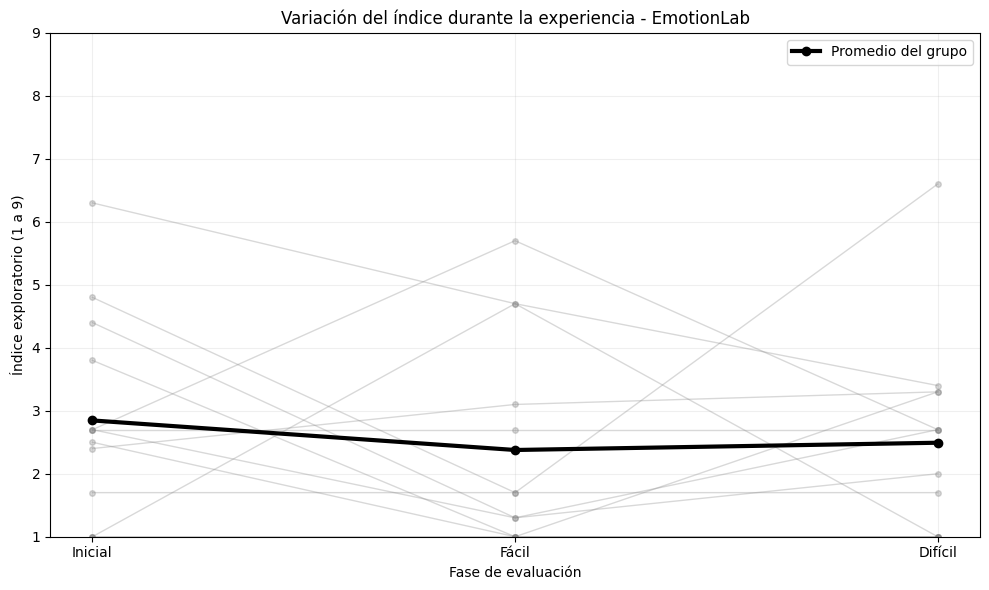

Estudiantes representados: 13
Visualización exploratoria completada.


In [ ]:

# =========================================================
# 4.6.3 - VISUALIZACIÓN DEL ÍNDICE POR FASE
# =========================================================

# Generamos el gráfico solamente cuando existan
# estudiantes con los tres índices calculados.

if estudiantes_evaluables.empty:

    print("GRÁFICO PENDIENTE - EMOTIONLAB")
    print("No existen tres índices válidos por estudiante.")
    print("Primero debemos completar las verificaciones del 4.4.")

else:

    # Creamos el espacio donde mostraremos el gráfico.

    fig, ax = plt.subplots(figsize=(10, 6))

    # Convertimos los índices a una matriz numérica.
    #
    # Cada fila representa un estudiante.
    # Cada columna representa una fase.
    #
    # Al transponerla (.T), Matplotlib puede dibujar
    # una línea por estudiante sin utilizar un ciclo for.

    trayectorias = estudiantes_evaluables[
        columnas_indices
    ].to_numpy(dtype=float)

    # Representamos las trayectorias individuales.
    #
    # El gris permite mostrar las diferencias entre
    # estudiantes sin destacar a uno en particular.

    ax.plot(
        range(3),
        trayectorias.T,
        marker="o",
        markersize=4,
        color="gray",
        alpha=0.3,
        linewidth=1
    )

    # Calculamos el promedio de las tres fases
    # para los mismos estudiantes seleccionados.

    promedios = trayectorias.mean(axis=0)

    # Destacamos el promedio general en negro.

    ax.plot(
        range(3),
        promedios,
        marker="o",
        color="black",
        linewidth=3,
        label="Promedio del grupo"
    )

    # Configuramos las etiquetas y la escala.

    ax.set_xticks(range(3), etapas)
    ax.set_ylim(ESCALA_MINIMA, ESCALA_MAXIMA)
    ax.set_yticks(
        range(ESCALA_MINIMA, ESCALA_MAXIMA + 1)
    )

    ax.set_title(
        "Variación del índice durante la experiencia - EmotionLab"
    )

    ax.set_xlabel("Fase de evaluación")
    ax.set_ylabel("Índice exploratorio (1 a 9)")

    # Agregamos una cuadrícula ligera y la leyenda
    # para facilitar la interpretación visual.

    ax.grid(alpha=0.2)
    ax.legend()

    plt.tight_layout()
    plt.show()

    print("Estudiantes representados:", len(estudiantes_evaluables))
    print("Visualización exploratoria completada.")


## 4.7 — Análisis de sensibilidad del índice de tensión
**¿Qué realizaremos en esta sección?**

En esta sección evaluaremos qué tan sensibles son los resultados del índice exploratorio de tensión percibida de EmotionLab frente a cambios en las ponderaciones utilizadas.

Actualmente, nuestro índice considera un 70 % de nerviosismo y un 30 % de estado emocional. Sin embargo, estas ponderaciones son experimentales, por lo que necesitamos comprobar cuánto influyen en las puntuaciones obtenidas.

**1. Configuraciones que compararemos**

Analizaremos tres escenarios utilizando las mismas respuestas de los estudiantes:

60 % / 40 %: mayor participación del estado emocional.

70 % / 30 %: configuración principal de EmotionLab.

80 % / 20 %: mayor participación del nerviosismo.

**2. Comparación de resultados**

Para cada configuración realizaremos los siguientes cálculos:

Índice por fase: calcularemos las puntuaciones de las evaluaciones inicial, fácil y difícil.

Índice global: obtendremos el promedio de las tres fases.

Diferencias: compararemos cada resultado alternativo con la configuración principal.

Sensibilidad: identificaremos el cambio absoluto promedio y la mayor diferencia registrada.

**3. ¿Por qué es importante?**

Este análisis nos permitirá identificar si los resultados son relativamente estables o si cambian considerablemente cuando modificamos las ponderaciones.

Si pequeñas variaciones en los porcentajes producen grandes diferencias, significaría que el índice depende significativamente de las decisiones experimentales que tomamos.

**4. Consideraciones metodológicas**

Trabajaremos con los 13 estudiantes evaluables, utilizando únicamente respuestas reales completas.

Mantendremos la orientación confirmada de la escala: valores mayores representan mayor tensión percibida.

No modificaremos los datos originales ni realizaremos estimaciones.

No asignaremos categorías de tensión hasta establecer y evaluar sus umbrales.

El análisis de sensibilidad no demuestra que una ponderación sea psicológicamente más válida que otra.

In [ ]:

# =========================================================
# 4.7.1 - PREPARACIÓN DEL ANÁLISIS DE SENSIBILIDAD
# =========================================================

# Antes de comparar ponderaciones, comprobamos que
# la orientación emocional haya sido confirmada
# y que el índice principal ya esté calculado.

if ORIENTACION_ESTADO_VALIDADA is not True:
    raise ValueError("Primero debemos validar la escala emocional.")

if type(INVERTIR_ESTADO) is not bool:
    raise ValueError("La inversión de la escala no está definida.")

# Seleccionamos únicamente estudiantes con las tres
# fases completas, sin utilizar valores estimados.

evaluables = resultados_tension["apto_indice_global"]

sensibilidad = resultados_tension.loc[
    evaluables, variables_indice
].copy()

# Guardamos el índice global original del 70/30
# para comprobar posteriormente los nuevos cálculos.

indice_referencia = resultados_tension.loc[
    evaluables, "indice_global"
]

if sensibilidad.empty or indice_referencia.isna().any():
    raise ValueError("No existen índices completos para comparar.")

if sensibilidad.isna().any().any():
    raise ValueError("Hay respuestas faltantes en los evaluables.")

print("Estudiantes seleccionados:", len(sensibilidad))


Estudiantes seleccionados: 13


In [ ]:

# =========================================================
# 4.7.2 - CÁLCULO DE LOS ÍNDICES ALTERNATIVOS
# =========================================================

# Confirmamos que la orientación emocional esté validada
# antes de calcular índices con nuevas ponderaciones.

if ORIENTACION_ESTADO_VALIDADA is not True:
    raise ValueError("La orientación emocional no está validada.")

# Esta función aplica las ponderaciones a cada fase
# y devuelve el promedio de las tres evaluaciones.

def calcular_indice_alternativo(datos, peso_nerviosismo):

    if not np.isfinite(peso_nerviosismo) or not 0 <= peso_nerviosismo <= 1:
        raise ValueError("La ponderación debe estar entre 0 y 1.")

    peso_estado = 1 - peso_nerviosismo
    indices = []

    for nerviosismo, estado in indicadores_por_etapa.values():

        estado_ajustado = datos[estado]

        # Invertimos la escala únicamente si la
        # configuración previamente validada lo requiere.

        if INVERTIR_ESTADO:
            estado_ajustado = (
                ESCALA_MINIMA + ESCALA_MAXIMA - estado_ajustado
            )

        # Calculamos el índice de esta fase.

        indice = (
            datos[nerviosismo] * peso_nerviosismo
            + estado_ajustado * peso_estado
        )

        indices.append(indice)

    # Obtenemos el promedio de las tres fases.
    # Cada índice debe estar disponible.

    return pd.concat(indices, axis=1).mean(
        axis=1, skipna=False
    )


# Definimos las tres ponderaciones experimentales.

escenarios = {
    "60_40": 0.60,
    "70_30": 0.70,
    "80_20": 0.80
}

# Creamos las columnas correspondientes a cada escenario.
#
# IMPORTANTE:
# Escribimos indice_ sin una barra invertida.
# Los nombres deben ser exactamente iguales
# a los utilizados en las siguientes celdas.

for nombre, peso in escenarios.items():

    sensibilidad[f"indice_{nombre}"] = (
        calcular_indice_alternativo(sensibilidad, peso)
    )

# Comprobamos que las tres columnas se hayan creado.

columnas_esperadas = [
    "indice_60_40",
    "indice_70_30",
    "indice_80_20"
]

faltantes = [
    columna for columna in columnas_esperadas
    if columna not in sensibilidad.columns
]

if faltantes:
    raise ValueError(f"No se crearon estas columnas: {faltantes}")

print("Índices alternativos calculados correctamente.")

print("\nColumnas generadas:")
print(columnas_esperadas)

print("\nVista de los resultados:")
display(sensibilidad[columnas_esperadas].head().round(2))


Índices alternativos calculados correctamente.

Columnas generadas:
['indice_60_40', 'indice_70_30', 'indice_80_20']

Vista de los resultados:


,indice_60_40,indice_70_30,indice_80_20
0,2.80,2.93,3.07
1,2.60,2.70,2.80
2,1.80,1.77,1.73
3,2.53,2.57,2.60
4,3.60,3.70,3.80


In [ ]:

# =========================================================
# 4.7.3 - COMPARACIÓN ENTRE PONDERACIONES
# =========================================================

# El escenario 70/30 debe reproducir el índice global
# calculado en la Etapa 4.5.
#
# np.allclose() compara números decimales considerando
# las pequeñas diferencias de precisión matemática.

if not np.allclose(
    sensibilidad["indice_70_30"],
    indice_referencia,
    rtol=0,
    atol=1e-10
):
    raise ValueError(
        "El escenario 70/30 no coincide con el índice original."
    )

# Calculamos las diferencias respecto del 70/30.
#
# Resultado positivo: el índice alternativo aumentó.
# Resultado negativo: el índice alternativo disminuyó.
# Resultado cero: no hubo cambios.

for escenario in ["60_40", "80_20"]:

    sensibilidad[f"diferencia_{escenario}"] = (
        sensibilidad[f"indice_{escenario}"]
        - sensibilidad["indice_70_30"]
    )

# Comprobamos que todos los índices alternativos
# permanezcan dentro de la escala de EmotionLab.

columnas_escenarios = [
    f"indice_{nombre}" for nombre in escenarios
]

indices_alternativos = sensibilidad[columnas_escenarios]

if not (
    np.isfinite(indices_alternativos.to_numpy()).all()
    and indices_alternativos.ge(ESCALA_MINIMA).all().all()
    and indices_alternativos.le(ESCALA_MAXIMA).all().all()
):
    raise ValueError("Se encontraron índices alternativos inválidos.")

print("Comparación de escenarios verificada correctamente.")
print("El escenario 70/30 reproduce el índice principal.")


Comparación de escenarios verificada correctamente.
El escenario 70/30 reproduce el índice principal.


In [ ]:

# =========================================================
# 4.7.4 - RESULTADOS DEL ANÁLISIS DE SENSIBILIDAD
# =========================================================

# Seleccionamos los índices y sus diferencias.
# Mostraremos identificadores temporales para
# no exponer los originales durante la presentación.

columnas_resultado = [
    "indice_60_40",
    "indice_70_30",
    "indice_80_20",
    "diferencia_60_40",
    "diferencia_80_20"
]

vista_sensibilidad = sensibilidad[columnas_resultado].round(2).copy()

# Recuperamos la posición de cada registro dentro
# del conjunto original de estudiantes reales.

posiciones = resultados_tension.index.get_indexer(
    sensibilidad.index
)

vista_sensibilidad.insert(
    0, "Registro",
    [f"Registro {i + 1:02d}" for i in posiciones]
)

print("COMPARACIÓN DE PONDERACIONES - EMOTIONLAB")
display(vista_sensibilidad.reset_index(drop=True))

# Calculamos dos medidas de sensibilidad:
#
# Cambio promedio absoluto:
# cuánto cambia generalmente el índice.
#
# Cambio máximo absoluto:
# la mayor diferencia observada en un estudiante.
#
# abs() evita que aumentos y disminuciones
# se cancelen entre sí.

resumen_sensibilidad = pd.DataFrame([
    {
        "Escenario": escenario.replace("_", "/"),
        "Cambio promedio absoluto": sensibilidad[
            f"diferencia_{escenario}"
        ].abs().mean(),
        "Cambio máximo absoluto": sensibilidad[
            f"diferencia_{escenario}"
        ].abs().max()
    }
    for escenario in ["60_40", "80_20"]
])

print("\nRESUMEN DE SENSIBILIDAD RESPECTO DEL 70/30")
display(resumen_sensibilidad.round(4))


COMPARACIÓN DE PONDERACIONES - EMOTIONLAB


,Registro,indice_60_40,indice_70_30,indice_80_20,diferencia_60_40,diferencia_80_20
0,Registro 01,2.80,2.93,3.07,-0.13,0.13
1,Registro 02,2.60,2.70,2.80,-0.10,0.10
2,Registro 03,1.80,1.77,1.73,0.03,-0.03
3,Registro 04,2.53,2.57,2.60,-0.03,0.03
4,Registro 05,3.60,3.70,3.80,-0.10,0.10
5,Registro 06,1.00,1.00,1.00,0.00,0.00
6,Registro 07,3.00,3.33,3.67,-0.33,0.33
7,Registro 08,2.20,2.23,2.27,-0.03,0.03
8,Registro 09,1.67,1.50,1.33,0.17,-0.17
9,Registro 20,1.80,1.93,2.07,-0.13,0.13



RESUMEN DE SENSIBILIDAD RESPECTO DEL 70/30


,Escenario,Cambio promedio absoluto,Cambio máximo absoluto
0,60/40,0.1051,0.3333
1,80/20,0.1051,0.3333


## 4.8 — Preparación de resultados del índice de tensión
¿Qué realizaremos en esta sección?

En esta sección organizaremos los resultados del índice exploratorio de tensión percibida de EmotionLab en una tabla que reúna la información principal de cada estudiante.

Para ello, realizaremos tres procesos:

Organización: reuniremos los índices de las fases inicial, fácil y difícil, junto con el índice global.

Identificación: conservaremos los identificadores seudónimos y el estado de evaluación de cada estudiante.

Validación: comprobaremos que los resultados sean consistentes y que no existan clasificaciones asignadas incorrectamente.

1. Información que conservaremos

La tabla incluirá:

Identificador del estudiante: permitirá relacionar cada resultado con su registro.

Respuestas disponibles: indicará cuántos de los seis indicadores necesarios fueron respondidos.

Índices por fase: mostrarán la puntuación calculada para cada momento de la experiencia.

Índice global: representará el promedio de las tres evaluaciones.

Estado de evaluación: distinguirá a los estudiantes evaluables, pendientes de estimación y con datos insuficientes.

Categoría de tensión: quedará pendiente hasta establecer los criterios de clasificación.

2. Disponibilidad de resultados

De acuerdo con los análisis anteriores, contamos con:

13 estudiantes evaluables: tienen un índice global calculado sin estimaciones.

2 estudiantes pendientes de estimación: cuentan con dos fases completas.

12 estudiantes con datos insuficientes: no cumplen los criterios para obtener un índice global.

Los registros incompletos conservarán sus respuestas disponibles sin recibir clasificaciones globales injustificadas.

3. ¿Por qué es importante?

Esta preparación permitirá disponer de los resultados en una estructura consistente, facilitando su utilización en otras partes de EmotionLab.

También nos ayudará a evitar errores como:

Asignar categorías de tensión a estudiantes sin un índice global válido.

Confundir respuestas estimadas con respuestas realmente observadas.

Perder la correspondencia entre los resultados y sus registros originales.

4. Preparación para AWS

Guardaremos la tabla en la variable resultados_heuristicos, que servirá como referencia para futuras visualizaciones y para definir los datos que intercambiará el backend.

Sin embargo, la integración con AWS requerirá implementar y comprobar posteriormente los mecanismos de comunicación, validación y protección de la información.

**En conclusión**, esta preparación permitirá centralizar los índices de tensión percibida y sus estados de evaluación, facilitando su utilización posterior sin alterar las respuestas originales.

In [ ]:

# =========================================================
# 4.8.1 - PREPARACIÓN DE RESULTADOS HEURÍSTICOS
# =========================================================

# Reunimos las columnas necesarias para presentar
# los resultados del índice exploratorio de EmotionLab.
#
# Conservamos los índices de las tres fases, el resultado
# global y el estado de disponibilidad de cada estudiante.

columnas_resultado = [
    "id_estudiante",
    "respuestas_para_indice",
    "fases_completas",
    "estado_evaluacion",
    "indice_inicial",
    "indice_facil",
    "indice_dificil",
    "indice_global"
]

# Antes de seleccionar los datos comprobamos que
# todas las columnas estén disponibles.

faltantes = [
    columna for columna in columnas_resultado
    if columna not in resultados_tension.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas: {faltantes}")

# Creamos una copia independiente.
# No modificamos los resultados de las etapas anteriores.

resultados_heuristicos = resultados_tension[
    columnas_resultado
].copy()

# Preparamos la columna destinada a las categorías.
#
# Por ahora todas quedan pendientes porque todavía
# no tenemos umbrales de clasificación validados.
#
# Esto evita conservar categorías antiguas que
# pudieran haberse generado con criterios provisionales.

resultados_heuristicos["categoria_tension"] = pd.NA

print("Tabla de resultados heurísticos preparada.")
print("Registros conservados:", len(resultados_heuristicos))


Tabla de resultados heurísticos preparada.
Registros conservados: 27


In [ ]:

# =========================================================
# 4.8.2 - VALIDACIÓN DE RESULTADOS HEURÍSTICOS
# =========================================================

# Confirmamos que la tabla conserva la misma cantidad
# de estudiantes reales que utilizamos en el EDA.

if len(resultados_heuristicos) != len(eda_reales):
    raise ValueError("La cantidad de estudiantes no coincide.")

# Comprobamos que los identificadores sean válidos.
# La conversión temporal a texto permite detectar
# identificadores vacíos o con espacios.

ids = resultados_heuristicos["id_estudiante"].astype("string").str.strip()

if ids.isna().any() or ids.eq("").any() or ids.duplicated().any():
    raise ValueError("Existen identificadores inválidos o duplicados.")

# Solo los estudiantes clasificados como Evaluables
# deben tener un índice global en esta etapa.
#
# Los pendientes de estimación y los registros con
# datos insuficientes conservarán el resultado como NaN.

evaluables = resultados_heuristicos["estado_evaluacion"].eq("Evaluable")
con_indice = resultados_heuristicos["indice_global"].notna()

if not evaluables.equals(con_indice):
    raise ValueError(
        "Los índices globales no coinciden con "
        "los estados de evaluación."
    )

# Verificamos que el índice global corresponda al
# promedio de las tres fases, sin valores estimados.

columnas_indices = [
    "indice_inicial",
    "indice_facil",
    "indice_dificil"
]

promedio_fases = resultados_heuristicos[columnas_indices].mean(
    axis=1, skipna=False
)

if not np.allclose(
    resultados_heuristicos.loc[evaluables, "indice_global"],
    promedio_fases.loc[evaluables],
    rtol=0,
    atol=1e-10
):
    raise ValueError("Existen índices globales inconsistentes.")

# Comprobamos que todos los índices calculados
# estén dentro de la escala definida en EmotionLab.

valores = resultados_heuristicos[
    columnas_indices + ["indice_global"]
].to_numpy(dtype=float)

valores_presentes = valores[~np.isnan(valores)]

if not (
    np.isfinite(valores_presentes).all()
    and ((valores_presentes >= ESCALA_MINIMA)
         & (valores_presentes <= ESCALA_MAXIMA)).all()
):
    raise ValueError("Se encontraron índices fuera de la escala.")

print("Validación de resultados completada correctamente.")
print("Índices globales verificados:", int(con_indice.sum()))
print("Categorías de tensión: pendientes de clasificación.")


Validación de resultados completada correctamente.
Índices globales verificados: 13
Categorías de tensión: pendientes de clasificación.


In [ ]:

# =========================================================
# 4.8.3 - PRESENTACIÓN DE RESULTADOS HEURÍSTICOS
# =========================================================

# Creamos una copia para mostrar los resultados.
# Conservamos los identificadores originales en memoria,
# pero utilizamos etiquetas temporales en la presentación.

vista_heuristica = resultados_heuristicos.drop(
    columns="id_estudiante"
).copy()

vista_heuristica.insert(
    0,
    "Registro",
    [f"Registro {i:02d}" for i in range(1, len(vista_heuristica) + 1)]
)

# Redondeamos solo la visualización.
# Los resultados almacenados mantienen su precisión.

print("RESULTADOS HEURÍSTICOS - EMOTIONLAB")
display(vista_heuristica.round(2))

# Agrupamos los estudiantes según su estado.
# reindex() mantiene las tres categorías visibles
# aunque alguna no tenga estudiantes.

resumen_heuristicos = (
    resultados_heuristicos["estado_evaluacion"]
    .value_counts()
    .reindex(
        ["Evaluable", "Pendiente de estimación", "Datos insuficientes"],
        fill_value=0
    )
)

print("\nRESUMEN DE DISPONIBILIDAD")
display(resumen_heuristicos.to_frame(name="Estudiantes"))

# Presentamos las cantidades de resultados disponibles.

print("\nRESUMEN GENERAL")
print("Registros reales:", len(resultados_heuristicos))
print("Índices globales:", resultados_heuristicos["indice_global"].notna().sum())
print("Categorías asignadas:", resultados_heuristicos["categoria_tension"].notna().sum())

print("\nTabla preparada para los siguientes análisis.")


RESULTADOS HEURÍSTICOS - EMOTIONLAB


,Registro,respuestas_para_indice,fases_completas,estado_evaluacion,indice_inicial,indice_facil,indice_dificil,indice_global,categoria_tension
0,Registro 01,6,3,Evaluable,2.4,3.1,3.3,2.93,<NA>
1,Registro 02,6,3,Evaluable,2.7,2.7,2.7,2.70,<NA>
2,Registro 03,6,3,Evaluable,1.0,1.0,3.3,1.77,<NA>
3,Registro 04,6,3,Evaluable,4.4,1.3,2.0,2.57,<NA>
4,Registro 05,6,3,Evaluable,2.7,5.7,2.7,3.70,<NA>
5,Registro 06,6,3,Evaluable,1.0,1.0,1.0,1.00,<NA>
6,Registro 07,6,3,Evaluable,1.7,1.7,6.6,3.33,<NA>
7,Registro 08,6,3,Evaluable,1.0,4.7,1.0,2.23,<NA>
8,Registro 09,6,3,Evaluable,2.5,1.0,1.0,1.50,<NA>
9,Registro 10,4,2,Pendiente de estimación,8.0,8.0,NaN,NaN,<NA>



RESUMEN DE DISPONIBILIDAD


,Estudiantes
estado_evaluacion,
Evaluable,13
Pendiente de estimación,2
Datos insuficientes,12



RESUMEN GENERAL
Registros reales: 27
Índices globales: 13
Categorías asignadas: 0

Tabla preparada para los siguientes análisis.


## Conclusión de la Etapa 4: Índice exploratorio de tensión percibida

Durante esta etapa desarrollamos e implementamos el índice exploratorio de tensión percibida de EmotionLab, con el objetivo de resumir las respuestas de nerviosismo y estado emocional registradas durante las tres fases de la experiencia.

### 1. Construcción del índice

Establecimos una fórmula experimental que combina dos indicadores:

- **Nerviosismo:** ponderación del 70 %.
- **Estado emocional:** ponderación del 30 %.
- **Escala de evaluación:** valores de 1 a 9, donde las puntuaciones mayores representan mayor tensión percibida según la orientación confirmada de los cuestionarios.

Calculamos un índice independiente para las fases inicial, fácil y difícil. Posteriormente, obtuvimos un índice global mediante el promedio de las tres evaluaciones.

### 2. Disponibilidad de información

De los **27 registros reales** recopilados, identificamos:

- **13 estudiantes evaluables:** cuentan con las seis respuestas necesarias y un índice global calculado.
- **2 estudiantes pendientes de estimación:** tienen dos fases completas.
- **12 estudiantes con datos insuficientes:** no cumplen los requisitos para calcular un índice global.

Durante esta etapa conservamos las respuestas originales y no realizamos estimaciones de valores faltantes.

### 3. Resultados de tensión percibida

Al analizar los 13 estudiantes evaluables, obtuvimos los siguientes promedios:

| Fase | Índice promedio |
|---|---:|
| Inicial | 2,85 |
| Fácil | 2,38 |
| Difícil | 2,49 |

Los resultados muestran una disminución del índice promedio durante la fase fácil y un ligero aumento durante la fase difícil.

Sin embargo, las trayectorias individuales evidencian diferencias entre estudiantes, por lo que no todos experimentaron las mismas variaciones.

Estas diferencias tampoco permiten afirmar que la dificultad de las presentaciones haya causado los cambios observados.

### 4. Análisis de sensibilidad

Comparamos tres configuraciones de ponderación: **60/40, 70/30 y 80/20**, utilizando los mismos 13 estudiantes.

Los resultados fueron:

- **Cambio promedio absoluto:** 0,1051 puntos.
- **Cambio máximo absoluto:** 0,3333 puntos.
- **Consistencia:** la configuración 70/30 reprodujo correctamente el índice original.

Estos resultados sugieren que las puntuaciones presentan una sensibilidad numérica relativamente baja frente a las modificaciones de ponderación evaluadas.

No obstante, esta estabilidad matemática no demuestra la validez psicológica de la fórmula.

### 5. Limitaciones y funcionalidades pendientes

Aunque logramos implementar el cálculo del índice, todavía existen aspectos que debemos considerar:

- **Ponderaciones experimentales:** los porcentajes utilizados no provienen de una escala psicológica validada.
- **Muestra limitada:** solamente 13 estudiantes cuentan con un índice global calculado.
- **Estimaciones pendientes:** todavía debemos evaluar cómo tratar los casos con dos fases completas.
- **Categorías de tensión:** aún no hemos establecido umbrales suficientemente justificados para clasificar los resultados en calma, tensión moderada o tensión elevada.

Es importante destacar que el índice representa una interpretación experimental de respuestas autodeclaradas y **no constituye un diagnóstico clínico de estrés**.

### 6. Resultado final y próxima etapa

La Etapa 4 permitió desarrollar un procedimiento funcional para calcular índices de tensión por fase y un resultado global, además de generar visualizaciones, comprobar la consistencia de los cálculos y analizar su sensibilidad.

También organizamos los resultados en la variable `resultados_heuristicos`, conservando los 27 registros reales y diferenciando los índices calculados de aquellos pendientes.

Con estos resultados podremos avanzar hacia la **Etapa 5: Preparación de datos para Machine Learning**, donde seleccionaremos y transformaremos las variables necesarias para aplicar posteriormente algoritmos de agrupamiento no supervisado.

**En conclusión**, logramos construir una herramienta exploratoria que resume las respuestas emocionales de los estudiantes durante una experiencia de EmotionLab, estableciendo una base técnica para los análisis posteriores y manteniendo claramente diferenciados los indicadores experimentales de las agrupaciones obtenidas mediante Machine Learning.

# Etapa 5: Entrenamiento y evaluación de Machine Learning

## Objetivo

Identificar patrones de similitud entre las doce respuestas emocionales de los estudiantes mediante aprendizaje no supervisado y seleccionar una alternativa experimental que permita asignar nuevos perfiles.

### Variables de entrada

| Fase | Variables |
|---|---|
| Inicial | `estado_pre`, `nerviosismo_pre`, `preocupacion_pre`, `preparacion_pre` |
| Fácil | `estado_facil`, `nerviosismo_facil`, `satisfaccion_facil`, `alivio_facil` |
| Difícil | `estado_dificil`, `nerviosismo_dificil`, `satisfaccion_dificil`, `alivio_dificil` |

A diferencia del índice heurístico de la Etapa 4, los modelos principales de esta etapa consideran las doce variables. El índice heurístico no constituye una etiqueta de entrenamiento.

### Diseño experimental

El dataset contiene 27 registros reales y 573 sintéticos. Hay 13 perfiles reales y 336 sintéticos completos; la imputación controlada permite disponer de 14 reales y 368 sintéticos aptos. Se comparan K-Means, clustering jerárquico y Gaussian Mixture Models (GMM) para 2, 3 y 4 grupos, con escenarios reales e híbridos de influencia sintética del 10 %, 25 % y 50 %. K-Means admite pesos; los otros algoritmos utilizan subconjuntos sintéticos para aproximar las proporciones. StandardScaler se ajusta sobre los datos reales de referencia y transforma los datos de los experimentos correspondientes.

### Métricas e interpretación

- **Silhouette:** valores más cercanos a 1 indican mayor cohesión y separación; cerca de 0 señalan solapamiento y los negativos pueden indicar asignaciones ambiguas.
- **Davies-Bouldin:** cuanto menor, mejor separación relativa respecto de la dispersión interna.
- **ARI (Adjusted Rand Index):** mide acuerdo entre particiones sin depender del número de etiqueta; 1 indica acuerdo perfecto, cerca de 0 acuerdo semejante al azar y valores negativos menor acuerdo.
- **PCA:** permite visualizar las agrupaciones en dos dimensiones, sin reemplazar las doce variables de entrenamiento.

La evaluación utiliza perfiles reales disponibles, no una muestra externa independiente. Los datos sintéticos provienen de registros reales y no aportan participantes independientes. La estabilidad matemática no garantiza capacidad predictiva o validez psicológica.

Adicionalmente, en 5.3.2 se entrena un segundo K-Means unidimensional sobre el promedio de doce respuestas de los 14 registros reales aptos. Sus grupos son independientes de los del modelo principal.

## 5.1 — Preparación de datos para entrenamiento real e híbrido

Seleccionamos las doce variables ML de las tres fases, verificamos la escala de 1 a 9 y conservamos la procedencia de los registros. Se identifican 13 perfiles reales completos y 336 sintéticos completos (349 en total).

### Regla de imputación vigente (5.1.5)

Para una pregunta faltante de un indicador repetido —estado emocional, nerviosismo, satisfacción o alivio— calculamos la mediana de las respuestas **originales del mismo indicador y estudiante**. No se reutilizan respuestas imputadas, respuestas de otros estudiantes ni medianas personales globales. Preocupación y preparación inicial son preguntas únicas y no se pueden estimar.

La inferencia requiere las doce respuestas originales o válidamente estimables. Si falta alguna referencia, no se genera grupo ni se aplica una imputación parcial. Si no existe ninguna respuesta original, el estado es `informacion_insuficiente`.

**Resultado:** 14/27 registros reales y 382/600 híbridos aptos (13 reales completos y uno adicional por imputación). Ocho registros reales tienen respuestas, pero referencias insuficientes; cinco no tienen respuestas. Se conservan los datos originales.

In [ ]:
# 5.1.1 - PREPARACIÓN DE LOS DATOS REALES (12 VARIABLES)
variables_ml = list(variables_cuestionario)
if len(variables_ml) != 12 or len(set(variables_ml)) != 12:
    raise ValueError('El entrenamiento requiere 12 preguntas únicas.')
columnas_requeridas = ['id_estudiante'] + variables_ml
faltantes = [c for c in columnas_requeridas if c not in eda_reales.columns]
if faltantes:
    raise ValueError(f'Faltan columnas de preguntas: {faltantes}')
datos_reales_ml = eda_reales[columnas_requeridas].copy()
datos_reales_ml[variables_ml] = datos_reales_ml[variables_ml].apply(pd.to_numeric, errors='raise')
valores = datos_reales_ml[variables_ml]
fuera_escala = valores.notna() & (valores.lt(ESCALA_MINIMA) | valores.gt(ESCALA_MAXIMA) | valores.mod(1).ne(0))
if fuera_escala.any().any():
    raise ValueError('Se detectaron respuestas reales inválidas (se requieren enteros entre 1 y 9).')
reales_completos_ml = datos_reales_ml.dropna(subset=variables_ml).copy()
print('Variables ML:', len(variables_ml))
print('Estudiantes reales:', len(datos_reales_ml))
print('Con 12 preguntas:', len(reales_completos_ml))
print('Incompletos:', len(datos_reales_ml)-len(reales_completos_ml))
display(datos_reales_ml[variables_ml].notna().sum().to_frame('Disponibles'))
if len(reales_completos_ml) < 3:
    raise ValueError('No hay suficientes reales completos para K-Means con dos grupos.')

Variables ML: 12
Estudiantes reales: 27
Con 12 preguntas: 13
Incompletos: 14


,Disponibles
estado_pre,22
nerviosismo_pre,21
preocupacion_pre,21
preparacion_pre,21
estado_facil,15
nerviosismo_facil,15
satisfaccion_facil,15
alivio_facil,14
estado_dificil,13
nerviosismo_dificil,13


In [ ]:

# =========================================================
# 5.1.2 - IDENTIFICACIÓN DEL DATASET HÍBRIDO
# =========================================================

# Utilizamos directamente el dataset original
# de EmotionLab, evitando buscar entre las copias
# generadas durante etapas anteriores.

if "dataset" not in globals():
    raise ValueError(
        "No se encontró el dataset original. "
        "Ejecuta primero la etapa de carga de datos."
    )

if not isinstance(dataset, pd.DataFrame):
    raise TypeError("La variable dataset no es un DataFrame.")

# Creamos una copia independiente.
# Esto permite ejecutar nuevamente el apartado
# sin modificar los datos originales.

dataset_hibrido_ml = dataset.copy()

# Unificamos los nombres de las variables cuando
# procedan de la estructura de inferencia.

equivalencias_ml = {
    "inicial_nerviosismo": "nerviosismo_pre",
    "inicial_sentir_hoy": "estado_pre",
    "inicial_preocupacion": "preocupacion_pre",
    "inicial_preparacion": "preparacion_pre",
    "facil_nerviosismo_cierre": "nerviosismo_facil",
    "facil_sentir_hoy_cierre": "estado_facil",
    "facil_satisfaccion_cierre": "satisfaccion_facil",
    "facil_aliviado_cierre": "alivio_facil",
    "dificil_nerviosismo_cierre": "nerviosismo_dificil",
    "dificil_sentir_hoy_cierre": "estado_dificil",
    "dificil_satisfaccion_cierre": "satisfaccion_dificil",
    "dificil_aliviado_cierre": "alivio_dificil"
}

# Renombramos únicamente las columnas que existan
# y comprobamos que no se generen duplicados.

dataset_hibrido_ml.rename(
    columns=equivalencias_ml,
    inplace=True
)

if dataset_hibrido_ml.columns.duplicated().any():
    raise ValueError(
        "Se encontraron nombres de columnas duplicados."
    )

# Verificamos que las doce variables estén disponibles.

faltantes = [
    columna for columna in variables_ml
    if columna not in dataset_hibrido_ml.columns
]

if faltantes:
    raise ValueError(
        f"Faltan variables necesarias: {faltantes}"
    )

# Comprobamos la cantidad esperada de registros.

if len(dataset_hibrido_ml) != 600:
    raise ValueError(
        "El dataset no contiene los 600 registros esperados."
    )

print("DATASET HÍBRIDO IDENTIFICADO - EMOTIONLAB")
print("Variable original: dataset")
print("Registros:", len(dataset_hibrido_ml))
print("Variables de Machine Learning:", len(variables_ml))

print("\nColumnas disponibles:")
print(dataset_hibrido_ml.columns.tolist())

DATASET HÍBRIDO IDENTIFICADO - EMOTIONLAB
Variable original: dataset
Registros: 600
Variables de Machine Learning: 12

Columnas disponibles:
['id_estudiante', 'tipo_origen', 'bloque_origen', 'edad', 'genero', 'n_respuestas', 'integridad', 'alivio_dificil', 'alivio_facil', 'estado_dificil', 'estado_facil', 'estado_pre', 'nerviosismo_dificil', 'nerviosismo_facil', 'nerviosismo_pre', 'preocupacion_pre', 'preparacion_pre', 'satisfaccion_dificil', 'satisfaccion_facil', 'tipo_registro', 'id_semilla']


In [ ]:

# =========================================================
# 5.1.3 - SEPARACIÓN DE DATOS REALES Y SINTÉTICOS
# =========================================================

# Posibles nombres de la columna que identifica
# la procedencia de cada registro.

columnas_origen = [
    "origen",
    "tipo_registro",
    "tipo_dato",
    "origen_dato",
    "fuente",
    "es_sintetico"
]

etiquetas_reales = {"real", "original", "observado"}
etiquetas_sinteticas = {
    "sintetico", "sintetica", "synthetic",
    "artificial", "generado", "simulado"
}

# Intentamos localizar una columna de procedencia
# con valores reconocibles.

procedencia = None

for columna in columnas_origen:

    if columna not in dataset_hibrido_ml.columns:
        continue

    serie = dataset_hibrido_ml[columna]

    if columna == "es_sintetico":
        if serie.dropna().isin([True, False, 0, 1]).all():
            procedencia = serie.map(
                {True: "sintetico", False: "real"}
            )
            if procedencia.notna().all():
                break

    etiquetas = (
        serie.astype("string")
        .str.strip()
        .str.lower()
        .str.normalize("NFKD")
        .str.encode("ascii", errors="ignore")
        .str.decode("ascii")
    )

    if etiquetas.isin(
        etiquetas_reales | etiquetas_sinteticas
    ).all():

        procedencia = etiquetas.map(
            lambda valor: (
                "real" if valor in etiquetas_reales
                else "sintetico"
            )
        )
        break

# Si no encontramos etiquetas, comprobamos si los
# identificadores permiten reconocer los datos reales.

if procedencia is None:

    if "id_estudiante" not in dataset_hibrido_ml.columns:
        raise ValueError(
            "No existe información suficiente para "
            "distinguir datos reales y sintéticos."
        )

    ids = dataset_hibrido_ml["id_estudiante"]
    mascara_real = ids.isin(datos_reales_ml["id_estudiante"])

    if (
        mascara_real.sum() != len(datos_reales_ml)
        or not ids.is_unique
    ):
        raise ValueError(
            "Los identificadores no permiten separar "
            "con seguridad los registros."
        )

    # Verificamos que coincidan las seis respuestas
    # originales de los estudiantes identificados.

    original = datos_reales_ml.set_index(
        "id_estudiante"
    )[variables_ml].sort_index()

    encontrados = dataset_hibrido_ml.loc[
        mascara_real
    ].set_index("id_estudiante")[variables_ml].sort_index()

    encontrados = encontrados.apply(
        pd.to_numeric, errors="raise"
    )

    if not np.allclose(
        original.to_numpy(dtype=float),
        encontrados.to_numpy(dtype=float),
        equal_nan=True
    ):
        raise ValueError(
            "Las respuestas originales no coinciden "
            "con los registros del dataset híbrido."
        )

    procedencia = pd.Series(
        np.where(mascara_real, "real", "sintetico"),
        index=dataset_hibrido_ml.index
    )

# Guardamos la procedencia y comprobamos las cantidades.

dataset_hibrido_ml["origen_ml"] = procedencia

conteo_origen = (
    dataset_hibrido_ml["origen_ml"].value_counts()
)

if (
    conteo_origen.get("real", 0) != 27
    or conteo_origen.get("sintetico", 0) != 573
):
    raise ValueError(
        "La procedencia no coincide con "
        "27 registros reales y 573 sintéticos."
    )

print("PROCEDENCIA VALIDADA")
display(conteo_origen.to_frame("Registros"))


PROCEDENCIA VALIDADA


,Registros
origen_ml,
sintetico,573
real,27


In [ ]:

# =========================================================
# 5.1.4 - MATRICES DE ENTRENAMIENTO
# =========================================================

# Comprobamos que las respuestas híbridas sean numéricas.
# Los valores ausentes se mantienen sin imputar.

dataset_hibrido_ml[variables_ml] = (
    dataset_hibrido_ml[variables_ml]
    .apply(pd.to_numeric, errors="raise")
)

# Validamos el intervalo permitido de 1 a 9.

valores = dataset_hibrido_ml[variables_ml]

fuera_escala = valores.notna() & (
    valores.lt(ESCALA_MINIMA) | valores.gt(ESCALA_MAXIMA)
)

if fuera_escala.any().any():
    raise ValueError("Existen respuestas híbridas fuera de escala.")

# Conservamos únicamente los perfiles completos
# para los entrenamientos iniciales.

hibridos_completos_ml = dataset_hibrido_ml.dropna(
    subset=variables_ml
).copy()

# Creamos las dos matrices de entrenamiento.

X_real_ml = reales_completos_ml[variables_ml].copy()
X_hibrido_ml = hibridos_completos_ml[variables_ml].copy()

# Identificamos qué registros son reales y sintéticos
# dentro de la matriz híbrida.

origen_hibrido_ml = hibridos_completos_ml["origen_ml"]

n_reales = int(origen_hibrido_ml.eq("real").sum())
n_sinteticos = int(origen_hibrido_ml.eq("sintetico").sum())

if n_reales != len(X_real_ml) or n_sinteticos == 0:
    raise ValueError(
        "Los registros completos no permiten "
        "preparar ambos entrenamientos."
    )

# Definimos el peso total experimental de los sintéticos.
# Cada grupo de datos reparte su influencia entre sus filas.

proporciones_sinteticas = [0.10, 0.25, 0.50]

pesos_hibridos_ml = {}

for proporcion in proporciones_sinteticas:

    nombre = f"hibrido_{int(proporcion * 100)}"

    pesos_hibridos_ml[nombre] = np.where(
        origen_hibrido_ml.eq("real"),
        (1 - proporcion) / n_reales,
        proporcion / n_sinteticos
    )

# Presentamos la preparación final.

resumen_entrenamiento = pd.DataFrame([
    {"Conjunto": "Real", "Registros completos": len(X_real_ml)},
    {"Conjunto": "Híbrido", "Registros completos": len(X_hibrido_ml)},
    {"Conjunto": "Híbrido - reales", "Registros completos": n_reales},
    {"Conjunto": "Híbrido - sintéticos", "Registros completos": n_sinteticos}
])

print("CONJUNTOS DE ENTRENAMIENTO - EMOTIONLAB")
display(resumen_entrenamiento)

print("\nEscenarios híbridos preparados:")
print(list(pesos_hibridos_ml))

print("\nPreparación del apartado 5.1 completada.")


CONJUNTOS DE ENTRENAMIENTO - EMOTIONLAB


,Conjunto,Registros completos
0,Real,13
1,Híbrido,349
2,Híbrido - reales,13
3,Híbrido - sintéticos,336



Escenarios híbridos preparados:
['hibrido_10', 'hibrido_25', 'hibrido_50']

Preparación del apartado 5.1 completada.


In [ ]:
# =========================================================
# 5.1.5 - IMPUTACIÓN SIN INVENTAR INDICADORES NO REPETIDOS
# =========================================================
# Si falta preocupación o preparación inicial: SIN DATOS SUFICIENTES.
# Para indicadores repetidos, mediana sólo del indicador de ESTA persona.
# Si no existe una respuesta original equivalente, tampoco se imputa.
# Nunca se usan valores imputados, otros estudiantes o medianas globales.

variables_ml = list(variables_ml)
fases_ml = [list(variables_iniciales), list(variables_facil), list(variables_dificil)]
indicadores_ml = [
    ['nerviosismo_pre', 'nerviosismo_facil', 'nerviosismo_dificil'],
    ['estado_pre', 'estado_facil', 'estado_dificil'],
    ['satisfaccion_facil', 'satisfaccion_dificil'],
    ['alivio_facil', 'alivio_dificil'],
    ['preocupacion_pre'],
    ['preparacion_pre'],
]
assert len(variables_ml) == 12 and len(set(variables_ml)) == 12
for grupos in (fases_ml, indicadores_ml):
    elementos = [v for grupo in grupos for v in grupo]
    if len(elementos) != 12 or set(elementos) != set(variables_ml):
        raise ValueError('Fases e indicadores no corresponden a doce variables únicas.')

variables_no_repetidas_ml = [g[0] for g in indicadores_ml if len(g) == 1]
assert set(variables_no_repetidas_ml) == {'preocupacion_pre', 'preparacion_pre'}
MIN_OBSERVADAS_ML = 1
MIN_FASES_ML = 1
METODO_IMPUTACION_ML = 'mediana_personal_solo_indicador_con_observaciones'
ETIQUETA_SIN_DATOS_ML = 'sin datos suficientes'


def completar_12_por_mediana_ml(respuestas):
    if not isinstance(respuestas, dict):
        raise TypeError('Las respuestas deben estar en un diccionario.')
    desconocidas = set(respuestas) - set(variables_ml)
    if desconocidas:
        raise ValueError(f'Variables desconocidas: {sorted(desconocidas)}')
    originales = {}
    for variable in variables_ml:
        valor = respuestas.get(variable)
        if isinstance(valor, (bool, list, tuple, dict, set, np.ndarray)):
            raise ValueError(f'Tipo inválido: {variable}')
        if valor is None or (isinstance(valor, str) and not valor.strip()) or pd.isna(valor):
            originales[variable] = np.nan
            continue
        try:
            numero = float(valor)
        except (TypeError, ValueError, OverflowError) as exc:
            raise ValueError(f'Valor no numérico en {variable}') from exc
        if not (np.isfinite(numero) and numero.is_integer()
                and ESCALA_MINIMA <= numero <= ESCALA_MAXIMA):
            raise ValueError(f'Valor fuera de escala en {variable}')
        originales[variable] = numero

    n_originales = sum(pd.notna(v) for v in originales.values())
    faltantes = [v for v in variables_ml if pd.isna(originales[v])]
    sin_datos = []
    estimables = {}
    for grupo in indicadores_ml:
        datos = [originales[v] for v in grupo if pd.notna(originales[v])]
        for variable in grupo:
            if pd.isna(originales[variable]):
                if len(grupo) == 1 or not datos:
                    sin_datos.append(variable)
                else:
                    estimables[variable] = float(np.median(datos))
    if n_originales == 0 or sin_datos:
        return {
            'estado': ('informacion_insuficiente' if n_originales == 0
                       else 'sin_datos_suficientes'),
            'observadas': n_originales, 'estimadas': [], 'fuentes': {},
            'completo': None, 'variables_sin_datos_suficientes': sin_datos,
            'mensaje': ETIQUETA_SIN_DATOS_ML,
        }
    completo = originales.copy()
    completo.update(estimables)
    if len(completo) != 12 or not all(np.isfinite(v) for v in completo.values()):
        raise AssertionError('Una entrada incompleta alcanzó la clasificación.')
    for v in variables_ml:
        if pd.notna(originales[v]) and completo[v] != originales[v]:
            raise AssertionError('Se alteró una respuesta original.')
    fuentes = {v: 'mediana_personal_mismo_indicador' for v in estimables}
    if set(estimables) != set(faltantes):
        raise AssertionError('No se imputaron exactamente las variables faltantes.')
    return {
        'estado': ('calculado_con_estimacion' if estimables else
                   'calculado_sin_estimacion'),
        'observadas': n_originales, 'estimadas': faltantes,
        'fuentes': fuentes, 'completo': completo,
        'variables_sin_datos_suficientes': [], 'mensaje': None,
    }


def imputar_por_mediana_ml(datos):
    resultado = datos.copy(deep=True)
    if not set(variables_ml).issubset(resultado.columns):
        raise ValueError('Faltan columnas obligatorias de ML.')
    salidas = [completar_12_por_mediana_ml(fila)
               for fila in resultado[variables_ml].to_dict('records')]
    for pos, salida in enumerate(salidas):
        if salida['completo'] is not None:
            for variable in variables_ml:
                resultado.iat[pos, resultado.columns.get_loc(variable)] = salida['completo'][variable]
    resultado['n_observadas_ml'] = [s['observadas'] for s in salidas]
    resultado['n_imputadas_ml'] = [len(s['estimadas']) for s in salidas]
    resultado['apto_entrenamiento_ml'] = [s['completo'] is not None for s in salidas]
    resultado['fuentes_imputacion_ml'] = [s['fuentes'] for s in salidas]
    resultado['estado_imputacion_ml'] = [s['estado'] for s in salidas]
    resultado['variables_sin_datos_suficientes_ml'] = [
        s['variables_sin_datos_suficientes'] for s in salidas
    ]
    aptos = resultado['apto_entrenamiento_ml']
    if resultado.loc[aptos, variables_ml].isna().any().any():
        raise AssertionError('Un registro apto conserva valores ausentes.')
    return resultado


datos_reales_imputados_ml = imputar_por_mediana_ml(datos_reales_ml)
datos_hibridos_imputados_ml = imputar_por_mediana_ml(dataset_hibrido_ml)
X_real_imputado_ml = datos_reales_imputados_ml.loc[
    datos_reales_imputados_ml['apto_entrenamiento_ml'], variables_ml
].copy()
aptos_hibridos = datos_hibridos_imputados_ml['apto_entrenamiento_ml']
X_hibrido_imputado_ml = datos_hibridos_imputados_ml.loc[
    aptos_hibridos, variables_ml
].copy()
origen_hibrido_imputado_ml = datos_hibridos_imputados_ml.loc[
    aptos_hibridos, 'origen_ml'
].copy()
print('5.1.5 — Imputación sólo donde hay una respuesta equivalente ORIGINAL')
print('Preguntas no repetidas:', variables_no_repetidas_ml)
print('Reales aptos:', len(X_real_imputado_ml), '/', len(datos_reales_ml))
print('Híbridos aptos:', len(X_hibrido_imputado_ml), '/', len(dataset_hibrido_ml))
print('Sin datos suficientes (reales):',
      int((datos_reales_imputados_ml['estado_imputacion_ml'] == 'sin_datos_suficientes').sum()))
print('El modelo exige 12 respuestas completas o imputables antes de predecir.')

5.1.5 — Imputación sólo donde hay una respuesta equivalente ORIGINAL
Preguntas no repetidas: ['preocupacion_pre', 'preparacion_pre']
Reales aptos: 14 / 27
Híbridos aptos: 382 / 600
Sin datos suficientes (reales): 8
El modelo exige 12 respuestas completas o imputables antes de predecir.


## 5.2 — Preprocesamiento y transformación de datos

Verificamos que los registros reales coincidan con los originales, comparamos las distribuciones reales y sintéticas y estandarizamos las doce variables con StandardScaler, ajustado sobre los registros reales de referencia de cada estrategia. Así se evita que las variables con mayor dispersión dominen únicamente por su escala.

Preparamos las matrices completas (13 reales y 336 sintéticos) e imputadas (14 reales y 368 sintéticos), además de las ponderaciones para los escenarios híbridos del 10 %, 25 % y 50 %. En K-Means estos porcentajes representan influencia total mediante pesos, no necesariamente la proporción de filas.

Esta preparación garantiza una comparación metodológicamente consistente, pero no constituye evidencia de mejora por incorporar datos sintéticos.

In [ ]:

# =========================================================
# 5.2.1 - VERIFICACIÓN DE DATOS Y PROCEDENCIA
# =========================================================

# Seleccionamos los registros originales dentro
# del dataset híbrido.

reales_hibrido = dataset_hibrido_ml.loc[
    dataset_hibrido_ml["origen_ml"].eq("real")
].copy()

# Confirmamos que sus identificadores correspondan
# a los 27 participantes del dataset original.

if (
    reales_hibrido["id_estudiante"].duplicated().any()
    or set(reales_hibrido["id_estudiante"])
       != set(datos_reales_ml["id_estudiante"])
):
    raise ValueError(
        "Los identificadores reales no coinciden."
    )

# Ordenamos ambos conjuntos por identificador
# para comparar las mismas respuestas.

original = (
    datos_reales_ml
    .set_index("id_estudiante")[variables_ml]
    .sort_index()
    .to_numpy(dtype=float)
)

hibrido = (
    reales_hibrido
    .set_index("id_estudiante")[variables_ml]
    .sort_index()
    .to_numpy(dtype=float)
)

# Comparamos los valores, incluyendo las respuestas
# ausentes, sin modificar ninguno de los datasets.

if not np.allclose(
    original, hibrido,
    rtol=0, atol=1e-10,
    equal_nan=True
):
    raise ValueError(
        "Las respuestas reales no coinciden."
    )

print("Los 27 registros reales coinciden con los originales.")

# Revisamos la información de procedencia sintética.
# Esto NO demuestra independencia de los registros.

if "id_semilla" in dataset_hibrido_ml.columns:

    semillas = dataset_hibrido_ml.loc[
        dataset_hibrido_ml["origen_ml"].eq("sintetico"),
        "id_semilla"
    ]

    print("\nTRAZABILIDAD DE DATOS SINTÉTICOS")
    print("Registros con semilla:", semillas.notna().sum())
    print("Semillas diferentes:", semillas.nunique())

else:
    print("\nNo existe una columna id_semilla.")


Los 27 registros reales coinciden con los originales.

TRAZABILIDAD DE DATOS SINTÉTICOS
Registros con semilla: 573
Semillas diferentes: 22


In [ ]:

# =========================================================
# 5.2.2 - COMPARACIÓN DE DISTRIBUCIONES
# =========================================================

# Separamos únicamente los 336 perfiles sintéticos
# que cuentan con las seis respuestas completas.

X_sintetico_ml = X_hibrido_ml.loc[
    origen_hibrido_ml.eq("sintetico")
].copy()

# Comparamos promedios y desviaciones estándar.
# Los resultados son descriptivos; no indican
# por sí solos cuál dataset produce mejores modelos.

comparacion_distribuciones = pd.DataFrame({
    "Media real": X_real_ml.mean(),
    "Media sintética": X_sintetico_ml.mean(),
    "Desv. real": X_real_ml.std(),
    "Desv. sintética": X_sintetico_ml.std()
})

comparacion_distribuciones["Diferencia medias"] = (
    comparacion_distribuciones["Media sintética"]
    - comparacion_distribuciones["Media real"]
)

print("COMPARACIÓN DE VARIABLES REALES Y SINTÉTICAS")
display(comparacion_distribuciones.round(2))

# Identificamos variables sin variación en los
# perfiles reales, ya que aportan poca información
# para distinguir estudiantes mediante distancias.

variables_constantes = (
    X_real_ml.columns[X_real_ml.nunique() <= 1].tolist()
)

if variables_constantes:
    print("\nVariables constantes:", variables_constantes)
else:
    print("\nLas seis variables presentan variación real.")


COMPARACIÓN DE VARIABLES REALES Y SINTÉTICAS


,Media real,Media sintética,Desv. real,Desv. sintética,Diferencia medias
estado_pre,2.31,2.52,1.97,2.09,0.21
nerviosismo_pre,3.08,3.44,1.89,2.09,0.36
preocupacion_pre,3.15,3.76,2.44,2.47,0.61
preparacion_pre,2.31,2.54,1.25,1.54,0.23
estado_facil,2.00,2.11,1.41,1.70,0.11
nerviosismo_facil,2.54,2.73,1.85,2.16,0.19
satisfaccion_facil,2.15,2.29,1.57,1.76,0.14
alivio_facil,2.31,2.45,1.55,1.70,0.14
estado_dificil,1.85,1.92,1.07,1.09,0.08
nerviosismo_dificil,2.77,3.30,2.13,2.53,0.53



Las seis variables presentan variación real.


In [ ]:

# =========================================================
# 5.2.3 - ESTANDARIZACIÓN DE VARIABLES
# =========================================================


# Comprobamos que ambas matrices utilizan las
# mismas seis variables y el mismo orden.

if list(X_real_ml.columns) != list(X_hibrido_ml.columns):
    raise ValueError("Las variables no coinciden.")

if not X_hibrido_ml.index.equals(origen_hibrido_ml.index):
    raise ValueError("La procedencia perdió su alineación.")

# Creamos y ajustamos el escalador usando
# únicamente las observaciones reales completas.

escalador_ml = StandardScaler()
escalador_ml.fit(X_real_ml)

# Aplicamos exactamente la misma transformación
# al conjunto real y al conjunto híbrido.

X_real_escalado_ml = pd.DataFrame(
    escalador_ml.transform(X_real_ml),
    columns=variables_ml,
    index=X_real_ml.index
)

X_hibrido_escalado_ml = pd.DataFrame(
    escalador_ml.transform(X_hibrido_ml),
    columns=variables_ml,
    index=X_hibrido_ml.index
)

# Comprobamos que la transformación no produzca
# valores ausentes o infinitos.

if not (
    np.isfinite(X_real_escalado_ml.to_numpy()).all()
    and np.isfinite(X_hibrido_escalado_ml.to_numpy()).all()
):
    raise ValueError("El escalado produjo valores inválidos.")

# Guardamos los parámetros para poder aplicar
# posteriormente la misma transformación.

parametros_escalado = pd.DataFrame({
    "Media de referencia": escalador_ml.mean_,
    "Desviación de referencia": np.sqrt(escalador_ml.var_)
}, index=variables_ml)

print("ESTANDARIZACIÓN COMPLETADA")
display(parametros_escalado.round(3))

print("\nDimensiones de las matrices:")
print("Real:", X_real_escalado_ml.shape)
print("Híbrida:", X_hibrido_escalado_ml.shape)


ESTANDARIZACIÓN COMPLETADA


,Media de referencia,Desviación de referencia
estado_pre,2.308,1.897
nerviosismo_pre,3.077,1.817
preocupacion_pre,3.154,2.348
preparacion_pre,2.308,1.202
estado_facil,2.000,1.359
nerviosismo_facil,2.538,1.781
satisfaccion_facil,2.154,1.511
alivio_facil,2.308,1.488
estado_dificil,1.846,1.026
nerviosismo_dificil,2.769,2.044



Dimensiones de las matrices:
Real: (13, 12)
Híbrida: (349, 12)


In [ ]:

# =========================================================
# 5.2.4 - VALIDACIÓN DE PONDERACIONES HÍBRIDAS
# =========================================================

# Cada escenario distribuye un peso total entre
# los registros reales y sintéticos disponibles.
#
# Los porcentajes NO representan la cantidad de filas,
# sino su influencia total dentro del entrenamiento.

escenarios_pesos = {
    "hibrido_10": 0.10,
    "hibrido_25": 0.25,
    "hibrido_50": 0.50
}

mascara_real = origen_hibrido_ml.eq("real").to_numpy()
mascara_sintetica = origen_hibrido_ml.eq("sintetico").to_numpy()

resumen_pesos_ml = []

for nombre, proporcion in escenarios_pesos.items():

    pesos = np.asarray(
        pesos_hibridos_ml[nombre], dtype=float
    )

    # Verificamos longitud y validez de los pesos.

    if (
        len(pesos) != len(X_hibrido_escalado_ml)
        or not np.isfinite(pesos).all()
        or (pesos < 0).any()
    ):
        raise ValueError(f"Pesos inválidos: {nombre}")

    peso_real = pesos[mascara_real].sum()
    peso_sintetico = pesos[mascara_sintetica].sum()

    # El peso total debe ser 1 y las proporciones
    # deben coincidir con las configuraciones previstas.

    if not (
        np.isclose(pesos.sum(), 1.0)
        and np.isclose(peso_sintetico, proporcion)
        and np.isclose(peso_real, 1 - proporcion)
    ):
        raise ValueError(f"Ponderación incorrecta: {nombre}")

    resumen_pesos_ml.append({
        "Escenario": nombre,
        "Peso real (%)": peso_real * 100,
        "Peso sintético (%)": peso_sintetico * 100,
        "Registros": len(pesos)
    })

# Presentamos los tres escenarios preparados.

resumen_pesos_ml = pd.DataFrame(resumen_pesos_ml)

print("VALIDACIÓN DE ENTRENAMIENTOS HÍBRIDOS")
display(resumen_pesos_ml.round(2))

print("\nMatrices y ponderaciones preparadas correctamente.")


VALIDACIÓN DE ENTRENAMIENTOS HÍBRIDOS


,Escenario,Peso real (%),Peso sintético (%),Registros
0,hibrido_10,90.0,10.0,349
1,hibrido_25,75.0,25.0,349
2,hibrido_50,50.0,50.0,349



Matrices y ponderaciones preparadas correctamente.


In [ ]:

# =========================================================
# 5.2.5 - ESCALADO DE REGISTROS IMPUTADOS
# =========================================================

# Aplicamos el mismo escalador del apartado 5.2.3.
# No volvemos a ajustarlo utilizando datos sintéticos.

X_real_imputado_escalado_ml = pd.DataFrame(
    escalador_ml.transform(X_real_imputado_ml),
    columns=variables_ml,
    index=X_real_imputado_ml.index
)

X_hibrido_imputado_escalado_ml = pd.DataFrame(
    escalador_ml.transform(X_hibrido_imputado_ml),
    columns=variables_ml,
    index=X_hibrido_imputado_ml.index
)

# Comprobamos que los resultados sean válidos
# y no contengan respuestas faltantes.

for nombre, matriz in {
    "Real imputado": X_real_imputado_escalado_ml,
    "Híbrido imputado": X_hibrido_imputado_escalado_ml
}.items():

    if not np.isfinite(matriz.to_numpy()).all():
        raise ValueError(f"Valores inválidos en {nombre}")

print("ESCALADO DE DATOS IMPUTADOS")
print("Real:", X_real_imputado_escalado_ml.shape)
print("Híbrido:", X_hibrido_imputado_escalado_ml.shape)

print("\nTransformación completada correctamente.")


ESCALADO DE DATOS IMPUTADOS
Real: (14, 12)
Híbrido: (382, 12)

Transformación completada correctamente.


In [ ]:

# =========================================================
# 5.2.6 - PONDERACIONES HÍBRIDAS CON IMPUTACIÓN
# =========================================================

# Comprobamos que los datos imputados y su procedencia
# estén disponibles antes de calcular las ponderaciones.

if "origen_hibrido_imputado_ml" not in globals():
    raise ValueError(
        "Falta la procedencia de los registros imputados. "
        "Ejecuta nuevamente el apartado 5.1.5."
    )

# Aseguramos que cada registro tenga una etiqueta
# de procedencia y que el orden coincida con la matriz.

origen = origen_hibrido_imputado_ml.reindex(
    X_hibrido_imputado_escalado_ml.index
)

if origen.isna().any():
    raise ValueError("Existen registros sin procedencia.")

# Contamos registros reales y sintéticos.

mascara_real = origen.eq("real").to_numpy()
mascara_sintetica = origen.eq("sintetico").to_numpy()

if not (mascara_real | mascara_sintetica).all():
    raise ValueError("Existen procedencias desconocidas.")

n_reales = int(mascara_real.sum())
n_sinteticos = int(mascara_sintetica.sum())

if n_reales == 0 or n_sinteticos == 0:
    raise ValueError("Faltan registros reales o sintéticos.")

# Creamos el diccionario que necesita el apartado 5.4.
# Cada escenario tendrá su propio vector de pesos.

pesos_hibridos_imputados_ml = {}
resumen_pesos_imputados = []

for porcentaje in [10, 25, 50]:

    proporcion = porcentaje / 100
    escenario = f"hibrido_{porcentaje}"

    pesos = np.where(
        mascara_real,
        (1 - proporcion) / n_reales,
        proporcion / n_sinteticos
    )

    # Verificamos que los pesos sean válidos
    # y representen las proporciones esperadas.

    if not (
        np.isfinite(pesos).all()
        and np.isclose(pesos.sum(), 1)
        and np.isclose(pesos[mascara_sintetica].sum(), proporcion)
    ):
        raise ValueError(f"Pesos inválidos: {escenario}")

    pesos_hibridos_imputados_ml[escenario] = pesos

    resumen_pesos_imputados.append({
        "Escenario": escenario,
        "Registros reales": n_reales,
        "Registros sintéticos": n_sinteticos,
        "Peso real (%)": pesos[mascara_real].sum() * 100,
        "Peso sintético (%)": pesos[mascara_sintetica].sum() * 100
    })

# Presentamos los escenarios correctamente generados.

resumen_pesos_imputados = pd.DataFrame(
    resumen_pesos_imputados
)

print("PONDERACIONES HÍBRIDAS CON IMPUTACIÓN")
display(resumen_pesos_imputados.round(2))

print("\nEscenarios disponibles:")
print(list(pesos_hibridos_imputados_ml))

print("\nPreparación completada correctamente.")


PONDERACIONES HÍBRIDAS CON IMPUTACIÓN


,Escenario,Registros reales,Registros sintéticos,Peso real (%),Peso sintético (%)
0,hibrido_10,14,368,90.0,10.0
1,hibrido_25,14,368,75.0,25.0
2,hibrido_50,14,368,50.0,50.0



Escenarios disponibles:
['hibrido_10', 'hibrido_25', 'hibrido_50']

Preparación completada correctamente.


## 5.3 — Entrenamiento experimental de K-Means

### ¿Qué realizaremos?

Durante esta sección entrenaremos el algoritmo K-Means utilizando las matrices estandarizadas que preparamos anteriormente.

Compararemos dos estrategias principales:

- **Entrenamiento real:** utilizará los 13 estudiantes con los doce indicadores completos.
- **Entrenamiento híbrido:** utilizará los 349 perfiles completos, controlando la influencia total de los registros sintéticos mediante ponderaciones del 10 %, 25 % y 50 %.

### Metodología

El procedimiento incluirá cuatro actividades:

1. **Entrenamiento:** probaremos configuraciones de 2, 3 y 4 grupos.
2. **Evaluación:** calcularemos métricas de cohesión y separación sobre los mismos 13 perfiles reales.
3. **Estabilidad:** comprobaremos cuánto cambian las agrupaciones al utilizar distintas inicializaciones del algoritmo.
4. **Comparación:** estudiaremos las diferencias entre las configuraciones reales e híbridas.

### ¿Qué buscamos determinar?

Investigaremos si la incorporación controlada de datos sintéticos produce agrupaciones con mejores métricas y mayor estabilidad que el entrenamiento realizado únicamente con respuestas reales.

Los resultados serán exploratorios y no permitirán afirmar todavía que el modelo generaliza mejor a estudiantes nuevos, especialmente porque los registros sintéticos proceden de una muestra real reducida.

El modelo seleccionado posteriormente deberá justificarse mediante el conjunto de resultados y sus limitaciones, no solamente por obtener la puntuación Silhouette más alta.

### Modelo auxiliar de promedios (5.3.2)

Además de los experimentos multivariables, se ajusta un K-Means de dos grupos sobre una sola característica: la media aritmética de las doce respuestas completas o válidamente imputadas. Utiliza 14 registros reales aptos y no aplica StandardScaler. Este modelo se mantiene separado de los experimentos de perfiles y se emplea posteriormente en el simulador.

In [ ]:

# =========================================================
# 5.3.1 - ENTRENAMIENTO EXPERIMENTAL DE K-MEANS
# =========================================================


# Definimos las cantidades de grupos que exploraremos.
# Probamos pocos grupos debido a que contamos con
# solamente 13 estudiantes reales completos.

cantidades_grupos = [2, 3, 4]

# Preparamos las cuatro configuraciones de entrenamiento.
#
# Real: utiliza solamente 13 estudiantes.
# Híbridos: utilizan 349 perfiles con pesos controlados.

configuraciones_kmeans = {
    "real": {
        "X": X_real_escalado_ml,
        "pesos": None
    }
}

for escenario in ["hibrido_10", "hibrido_25", "hibrido_50"]:

    configuraciones_kmeans[escenario] = {
        "X": X_hibrido_escalado_ml,
        "pesos": pesos_hibridos_ml[escenario]
    }

# Guardaremos los modelos y sus predicciones sobre
# los mismos 13 estudiantes reales.

modelos_kmeans = {}
predicciones_kmeans = {}

for escenario, configuracion in configuraciones_kmeans.items():

    for k in cantidades_grupos:

        modelo = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=10,
            max_iter=300,
            random_state=42
        )

        # Entrenamos utilizando los datos y pesos
        # correspondientes a cada configuración.

        modelo.fit(
            configuracion["X"],
            sample_weight=configuracion["pesos"]
        )

        clave = (escenario, k)

        modelos_kmeans[clave] = modelo

        # Todos los modelos se evalúan sobre las
        # mismas 13 respuestas reales completas.

        predicciones_kmeans[clave] = modelo.predict(
            X_real_escalado_ml
        )

print("ENTRENAMIENTO K-MEANS - EMOTIONLAB")
print("Configuraciones:", len(configuraciones_kmeans))
print("Cantidades de grupos:", cantidades_grupos)
print("Modelos entrenados:", len(modelos_kmeans))
print("Perfiles utilizados para comparar:", len(X_real_escalado_ml))


ENTRENAMIENTO K-MEANS - EMOTIONLAB
Configuraciones: 4
Cantidades de grupos: [2, 3, 4]
Modelos entrenados: 12
Perfiles utilizados para comparar: 13


In [ ]:
# =========================================================
# 5.3.2 - ENTRENAMIENTO EXPERIMENTAL DEL K-MEANS DE PROMEDIOS
# 12 PREGUNTAS, DATOS REALES E IMPUTACIÓN DE 5.1.5
# =========================================================


# La variable de compatibilidad se llama "bienestar", pero
# por ahora contiene el PROMEDIO BRUTO de las 12 respuestas.
# No equivale a una medida validada de bienestar o satisfacción.

if len(variables_ml) != 12 or set(variables_ml) != set(variables_cuestionario):
    raise ValueError("Ejecuta 5.1.1 corregido: variables_ml debe contener las 12 preguntas.")

if "datos_reales_imputados_ml" not in globals():
    raise RuntimeError("Ejecuta primero el apartado 5.1.5 corregido.")

# El entrenamiento usa SOLO registros reales aptos.
fuente_bienestar_ml = datos_reales_imputados_ml.loc[
    datos_reales_imputados_ml["apto_entrenamiento_ml"], :
].copy()

if fuente_bienestar_ml[variables_ml].isna().any().any():
    raise ValueError("Hay registros reales elegibles todavía incompletos.")

# Misma escala 1-9 del cuestionario. Sin mezclar datos sintéticos.
matriz_bienestar_ml = fuente_bienestar_ml[variables_ml].astype(float)
if not matriz_bienestar_ml.apply(np.isfinite).all().all():
    raise ValueError("El entrenamiento incluye valores no finitos.")
if not matriz_bienestar_ml.ge(1).all().all() or not matriz_bienestar_ml.le(9).all().all():
    raise ValueError("Hay respuestas fuera de la escala 1 a 9.")

# La media se obtiene DESPUÉS de aplicar imputación por mediana.
promedios_entrenamiento_ml = matriz_bienestar_ml.mean(axis=1)

# Comprobaciones para que K-Means(k=2) pueda ajustarse.
if len(promedios_entrenamiento_ml) < 3:
    raise ValueError(
        "Hay menos de 3 registros reales aptos para el segundo K-Means. "
        "Revisa los resultados de 5.1.5; no entrenes artificialmente."
    )
if promedios_entrenamiento_ml.nunique() < 2:
    raise ValueError("Los promedios reales son idénticos: no se pueden separar dos grupos.")

# Conservar nombre 'bienestar' permite que el simulador use predict,
# pero el nombre significa aquí solamente 'promedio de respuestas'.
entrada_bienestar_ml = pd.DataFrame({
    "bienestar": promedios_entrenamiento_ml.to_numpy()
})

modelo_bienestar_ml = KMeans(
    n_clusters=2,
    init="k-means++",
    n_init=20,
    max_iter=300,
    random_state=SEMILLA
)
modelo_bienestar_ml.fit(entrada_bienestar_ml)
check_is_fitted(modelo_bienestar_ml)

# Índices corresponden exactamente a los grupos devueltos por predict.
centros_bienestar_ml = modelo_bienestar_ml.cluster_centers_.ravel().copy()
if centros_bienestar_ml.shape != (2,):
    raise ValueError("El modelo no devolvió exactamente dos centroides.")

# 0/1 solo como ORDEN del promedio (no satisfacción/insatisfacción).
ids_ordenados_ml = np.argsort(centros_bienestar_ml)
orden_grupos_promedio_ml = {
    int(ids_ordenados_ml[0]): "menor_promedio_relativo",
    int(ids_ordenados_ml[1]): "mayor_promedio_relativo"
}

# Exportamos modelo y metadatos para reproducir el experimento.
carpeta_promedios_ml = Path("emotionlab_modelo_promedios_12")
carpeta_promedios_ml.mkdir(exist_ok=True, parents=True)
ruta_modelo_bienestar_ml = carpeta_promedios_ml / "kmeans_promedio_12.joblib"
joblib.dump(modelo_bienestar_ml, ruta_modelo_bienestar_ml)

metadatos_bienestar_ml = {
    "proyecto": "EmotionLab",
    "metodo": "KMeans_sobre_promedio_bruto_12_respuestas",
    "variables": list(variables_ml),
    "escala": [1, 9],
    "semilla": int(SEMILLA),
    "n_clusters": 2,
    "registros_reales_elegibles": int(len(entrada_bienestar_ml)),
    "registros_sinteticos_utilizados": 0,
    "mediana_previa": True,
    "criterios_imputacion": {
        "minimo_observadas": int(MIN_OBSERVADAS_ML),
        "minimo_fases": int(MIN_FASES_ML),
        "un_valor_por_indicador": True
    },
    "centros_por_etiqueta": centros_bienestar_ml.tolist(),
    "interpretacion": (
        "Grupos exploratorios de promedios brutos. "
        "No miden por sí solos bienestar psicológico ni utilidad del programa."
    )
}
(carpeta_promedios_ml / "metadatos_promedio_12.json").write_text(
    json.dumps(metadatos_bienestar_ml, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

# Verificación de equivalencia tras cargar el archivo guardado.
modelo_recargado_ml = joblib.load(ruta_modelo_bienestar_ml)
assert np.array_equal(
    modelo_recargado_ml.predict(entrada_bienestar_ml),
    modelo_bienestar_ml.predict(entrada_bienestar_ml)
)

print("K-MEANS DE PROMEDIOS ENTRENADO")
print("Variables empleadas para calcular cada promedio:", len(variables_ml))
print("Registros reales aptos:", len(entrada_bienestar_ml))
print("Centroides por etiqueta:", np.round(centros_bienestar_ml, 3))
print("Modelo guardado en:", ruta_modelo_bienestar_ml)
print("NOTA: los grupos NO significan 'le gustó' / 'no le gustó'.")


K-MEANS DE PROMEDIOS ENTRENADO
Variables empleadas para calcular cada promedio: 12
Registros reales aptos: 14
Centroides por etiqueta: [2.308 8.167]
Modelo guardado en: emotionlab_modelo_promedios_12/kmeans_promedio_12.joblib
NOTA: los grupos NO significan 'le gustó' / 'no le gustó'.


In [ ]:

# =========================================================
# 5.3.3 - EVALUACIÓN DE AGRUPAMIENTOS K-MEANS
# =========================================================


resultados_evaluacion_kmeans = []

# Utilizamos siempre las mismas respuestas reales,
# independientemente del conjunto de entrenamiento.

X_evaluacion = X_real_escalado_ml.to_numpy()

for (escenario, k), modelo in modelos_kmeans.items():

    etiquetas = predicciones_kmeans[(escenario, k)]

    # Contamos los estudiantes reales asignados
    # a cada grupo.

    grupos, cantidades = np.unique(
        etiquetas, return_counts=True
    )

    n_grupos = len(grupos)
    menor_grupo = int(cantidades.min())

    # Algunas configuraciones híbridas podrían
    # generar grupos sin estudiantes reales.
    # Por eso validamos las métricas antes de calcularlas.

    silhouette = np.nan
    davies_bouldin = np.nan

    if 2 <= n_grupos < len(X_evaluacion):

        silhouette = silhouette_score(
            X_evaluacion, etiquetas
        )

        davies_bouldin = davies_bouldin_score(
            X_evaluacion, etiquetas
        )

    resultados_evaluacion_kmeans.append({
        "Escenario": escenario,
        "k": k,
        "Grupos en reales": n_grupos,
        "Menor grupo": menor_grupo,
        "Silhouette real": silhouette,
        "Davies-Bouldin real": davies_bouldin
    })

# Organizamos los resultados para comparar.

resultados_kmeans = pd.DataFrame(
    resultados_evaluacion_kmeans
)

print("EVALUACIÓN DE K-MEANS SOBRE 13 ESTUDIANTES REALES")
display(resultados_kmeans.round(3))


EVALUACIÓN DE K-MEANS SOBRE 13 ESTUDIANTES REALES


,Escenario,k,Grupos en reales,Menor grupo,Silhouette real,Davies-Bouldin real
0,real,2,2,3,0.258,1.434
1,real,3,3,2,0.156,1.503
2,real,4,4,1,0.131,1.192
3,hibrido_10,2,2,3,0.258,1.434
4,hibrido_10,3,3,2,0.156,1.503
5,hibrido_10,4,4,1,0.158,1.124
6,hibrido_25,2,2,3,0.258,1.434
7,hibrido_25,3,3,3,0.139,1.455
8,hibrido_25,4,4,1,0.158,1.124
9,hibrido_50,2,2,3,0.258,1.434


In [ ]:

# =========================================================
# 5.3.5 - ESTABILIDAD DE K-MEANS
# =========================================================


# Repetimos el entrenamiento con distintas
# semillas de inicialización para cada escenario.

semillas_kmeans = [11, 21, 31, 41, 51]

resultados_estabilidad = []

for escenario, configuracion in configuraciones_kmeans.items():

    for k in cantidades_grupos:

        predicciones_repetidas = []

        for semilla in semillas_kmeans:

            modelo = KMeans(
                n_clusters=k,
                init="k-means++",
                n_init=10,
                max_iter=300,
                random_state=semilla
            )

            modelo.fit(
                configuracion["X"],
                sample_weight=configuracion["pesos"]
            )

            # Evaluamos cada repetición sobre
            # los mismos estudiantes reales.

            predicciones_repetidas.append(
                modelo.predict(X_real_escalado_ml)
            )

        # Comparamos todas las parejas de repeticiones.
        # ARI = 1 significa asignaciones equivalentes,
        # aunque cambien los números de los grupos.

        valores_ari = [
            adjusted_rand_score(
                predicciones_repetidas[i],
                predicciones_repetidas[j]
            )
            for i, j in combinations(
                range(len(predicciones_repetidas)), 2
            )
        ]

        resultados_estabilidad.append({
            "Escenario": escenario,
            "k": k,
            "ARI promedio": np.mean(valores_ari),
            "ARI mínimo": np.min(valores_ari)
        })

# Presentamos las métricas de estabilidad.

estabilidad_kmeans = pd.DataFrame(
    resultados_estabilidad
)

print("ESTABILIDAD ANTE INICIALIZACIONES - K-MEANS")
display(estabilidad_kmeans.round(3))


ESTABILIDAD ANTE INICIALIZACIONES - K-MEANS


,Escenario,k,ARI promedio,ARI mínimo
0,real,2,0.745,0.416
1,real,3,0.547,0.323
2,real,4,0.497,0.144
3,hibrido_10,2,0.653,0.239
4,hibrido_10,3,0.513,0.274
5,hibrido_10,4,0.540,0.317
6,hibrido_25,2,0.875,0.687
7,hibrido_25,3,0.487,0.229
8,hibrido_25,4,0.599,0.370
9,hibrido_50,2,1.000,1.000


COMPARACIÓN EXPERIMENTAL - K-MEANS


,Escenario,k,Grupos en reales,Menor grupo,Silhouette real,Davies-Bouldin real,ARI promedio,ARI mínimo,ARI vs real,Diferencia Silhouette
0,real,2,2,3,0.258,1.434,0.745,0.416,1.000,0.000
1,real,3,3,2,0.156,1.503,0.547,0.323,1.000,0.000
2,real,4,4,1,0.131,1.192,0.497,0.144,1.000,0.000
3,hibrido_10,2,2,3,0.258,1.434,0.653,0.239,1.000,0.000
4,hibrido_10,3,3,2,0.156,1.503,0.513,0.274,1.000,0.000
5,hibrido_10,4,4,1,0.158,1.124,0.540,0.317,0.937,0.027
6,hibrido_25,2,2,3,0.258,1.434,0.875,0.687,1.000,0.000
7,hibrido_25,3,3,3,0.139,1.455,0.487,0.229,0.824,-0.017
8,hibrido_25,4,4,1,0.158,1.124,0.599,0.370,0.937,0.027
9,hibrido_50,2,2,3,0.258,1.434,1.000,1.000,1.000,0.000


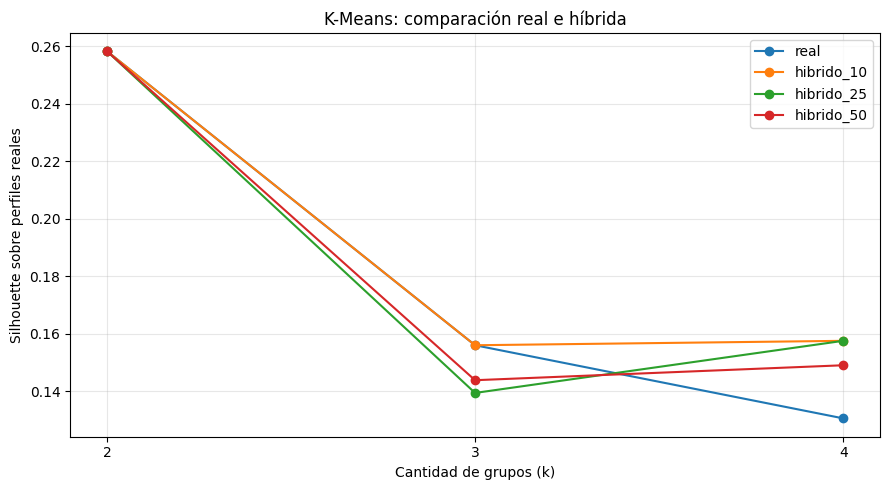

Comparación experimental de K-Means completada.
La selección definitiva requiere revisar
calidad, estabilidad y dependencia sintética.


In [ ]:

# =========================================================
# 5.3.6 - COMPARACIÓN FINAL DE K-MEANS
# =========================================================


# Unimos las métricas de calidad y estabilidad.

comparacion_kmeans = resultados_kmeans.merge(
    estabilidad_kmeans,
    on=["Escenario", "k"],
    validate="one_to_one"
)

# Incorporamos el acuerdo con el modelo real
# de referencia para la misma cantidad de grupos.
#
# Esta medida indica semejanza entre asignaciones,
# no superioridad de un modelo sobre otro.

comparacion_kmeans["ARI vs real"] = [
    adjusted_rand_score(
        predicciones_kmeans[("real", k)],
        predicciones_kmeans[(escenario, k)]
    )
    for escenario, k in zip(
        comparacion_kmeans["Escenario"],
        comparacion_kmeans["k"]
    )
]

# Calculamos la diferencia de Silhouette respecto
# al modelo entrenado únicamente con datos reales.

silhouette_referencia = (
    comparacion_kmeans
    .query("Escenario == 'real'")
    .set_index("k")["Silhouette real"]
)

comparacion_kmeans["Diferencia Silhouette"] = (
    comparacion_kmeans["Silhouette real"]
    - comparacion_kmeans["k"].map(silhouette_referencia)
)

print("COMPARACIÓN EXPERIMENTAL - K-MEANS")
display(comparacion_kmeans.round(3))

# Visualizamos los resultados sobre los mismos
# 13 perfiles reales, usando un color por escenario.

plt.figure(figsize=(9, 5))

for escenario in configuraciones_kmeans:

    datos = comparacion_kmeans.loc[
        comparacion_kmeans["Escenario"].eq(escenario)
    ].sort_values("k")

    plt.plot(
        datos["k"],
        datos["Silhouette real"],
        marker="o",
        label=escenario
    )

plt.title("K-Means: comparación real e híbrida")
plt.xlabel("Cantidad de grupos (k)")
plt.ylabel("Silhouette sobre perfiles reales")
plt.xticks(cantidades_grupos)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("Comparación experimental de K-Means completada.")
print("La selección definitiva requiere revisar")
print("calidad, estabilidad y dependencia sintética.")


### 5.3 — Resultados del entrenamiento experimental de K-Means

Se compararon doce configuraciones del modelo principal (cuatro escenarios y tres valores de k).

| Escenario con k = 2 | Silhouette | Davies-Bouldin | ARI medio entre inicializaciones |
|---|---:|---:|---:|
| Real | 0,258 | 1,434 | 0,745 |
| Híbrido 10 % | 0,258 | 1,434 | 0,653 |
| Híbrido 25 % | 0,258 | 1,434 | 0,875 |
| Híbrido 50 % | 0,258 | 1,434 | 1,000 |

Las cuatro configuraciones de dos grupos produjeron particiones equivalentes sobre los registros reales (ARI respecto del modelo real = 1), con un grupo menor de tres estudiantes. El ARI de estabilidad, en cambio, varía entre inicializaciones. Con k = 3 y k = 4 el Silhouette fue inferior en los escenarios evaluados, y varios modelos de cuatro grupos produjeron grupos unitarios.

**Modelo auxiliar:** los centroides del promedio son 2,308 (grupo 0, menor promedio relativo) y 8,167 (grupo 1, mayor promedio relativo). El umbral aproximado de distancia igual es 5,2375. Los grupos no representan utilidad, satisfacción global ni intención de reutilización.

**Conclusión:** k = 2 es un candidato razonable para el modelo multivariable, aunque la separación es limitada. La influencia sintética incrementó la estabilidad en algunas configuraciones sin mejorar Silhouette ni Davies-Bouldin.

## 5.4 — Evaluación de K-Means con imputación por mediana

### ¿Qué realizaremos?

Durante esta sección estudiaremos cómo influye la imputación por mediana en los modelos de K-Means entrenados anteriormente.

En la Etapa 5.3 utilizamos 13 perfiles reales completos y 336 sintéticos completos. Ahora incorporaremos los registros adicionales que cumplen los criterios de estimación definidos en la Etapa 5.1.

El procedimiento comprenderá cuatro actividades:

1. **Validación:** comprobar que los registros imputados conservan las respuestas originales.
2. **Evaluación de la mediana:** ocultar temporalmente respuestas conocidas y comparar sus valores reales con los estimados.
3. **Entrenamiento:** repetir los experimentos de K-Means con conjuntos reales e híbridos imputados.
4. **Comparación:** analizar las diferencias en calidad y estabilidad respecto de los modelos de la Etapa 5.3.

### ¿Por qué realizaremos esta prueba?

La imputación permitirá incorporar información parcialmente incompleta, pero los valores estimados pueden modificar las relaciones entre estudiantes y, por consiguiente, las agrupaciones.

Nuestro objetivo será determinar si esta técnica aporta información útil sin introducir alteraciones excesivas.

Los resultados se interpretarán de manera exploratoria. La imputación no convierte las respuestas faltantes en observaciones reales ni garantiza una mejora del modelo.

In [ ]:

# =========================================================
# 5.4.1 - VALIDACIÓN DE DATOS IMPUTADOS
# =========================================================

# Verificamos que las matrices imputadas estén disponibles.

if (
    "X_real_imputado_ml" not in globals()
    or "X_hibrido_imputado_ml" not in globals()
    or "X_real_imputado_escalado_ml" not in globals()
    or "X_hibrido_imputado_escalado_ml" not in globals()
    or "pesos_hibridos_imputados_ml" not in globals()
):
    raise ValueError(
        "Ejecuta primero las celdas 5.1.5, 5.2.5 y 5.2.6."
    )

# Comprobamos que los 13 perfiles reales originales
# permanezcan exactamente iguales después de imputar.

originales = X_real_ml[variables_ml]

conservados = X_real_imputado_ml.loc[
    originales.index, variables_ml
]

if not np.allclose(
    originales.to_numpy(),
    conservados.to_numpy(),
    rtol=0,
    atol=1e-10
):
    raise ValueError(
        "La imputación modificó respuestas observadas."
    )

# Identificamos los perfiles adicionales incorporados.

nuevos_reales = X_real_imputado_ml.index.difference(
    X_real_ml.index
)

# Comprobamos que ambas matrices estén completas.

for nombre, matriz in {
    "Real": X_real_imputado_ml,
    "Híbrido": X_hibrido_imputado_ml
}.items():

    if matriz[variables_ml].isna().any().any():
        raise ValueError(
            f"Hay respuestas faltantes en {nombre}."
        )

print("VALIDACIÓN DE IMPUTACIÓN - EMOTIONLAB")
print("Reales completos originales:", len(X_real_ml))
print("Reales adicionales imputados:", len(nuevos_reales))
print("Total reales aptos:", len(X_real_imputado_ml))
print("Total híbridos aptos:", len(X_hibrido_imputado_ml))

print("\nLas respuestas originales fueron conservadas.")


VALIDACIÓN DE IMPUTACIÓN - EMOTIONLAB
Reales completos originales: 13
Reales adicionales imputados: 1
Total reales aptos: 14
Total híbridos aptos: 382

Las respuestas originales fueron conservadas.


In [ ]:
# =========================================================
# 5.4.2 - EVALUACIÓN DEL ERROR DE IMPUTACIÓN (12 PREGUNTAS)
# =========================================================
# Regla metodológica:
# - Se estiman sólo indicadores repetidos con al menos una respuesta
#   ORIGINAL del mismo indicador y estudiante.
# - Preocupación y preparación inicial no se imputan.
# - Un caso no estimable se registra como «sin datos suficientes»;
#   nunca se calcula un MAE para una estimación que no existe.
# - No se modifican las respuestas originales.


# ---------------------------------------------------------
# 1. VALIDAMOS VARIABLES Y ELEGIMOS PERFILES COMPLETOS
# ---------------------------------------------------------

requeridas_542 = [
    'X_real_ml', 'variables_ml', 'fases_ml', 'indicadores_ml',
    'imputar_por_mediana_ml'
]
faltantes_542 = [n for n in requeridas_542 if n not in globals()]
if faltantes_542:
    raise RuntimeError('Ejecuta antes los apartados correspondientes: '
                       + ', '.join(faltantes_542))

if len(variables_ml) != 12 or len(set(variables_ml)) != 12:
    raise ValueError('La evaluación requiere 12 variables únicas.')

particion_542 = [variable for grupo in indicadores_ml for variable in grupo]
if len(particion_542) != 12 or set(particion_542) != set(variables_ml):
    raise ValueError('La partición de indicadores no coincide con las 12 variables.')

originales_542 = X_real_ml.loc[:, variables_ml].copy(deep=True)
originales_completos_542 = originales_542.dropna(subset=variables_ml)

if originales_completos_542.empty:
    raise ValueError('No hay estudiantes con las 12 respuestas originales.')

# ---------------------------------------------------------
# 2. ESCENARIOS: UNA PREGUNTA O UNA FASE ENTERA
# ---------------------------------------------------------

situaciones = {
    'Pregunta individual': [[v] for v in variables_ml],
    'Fase completa': [list(fase) for fase in fases_ml],
}

grupo_por_variable_542 = {
    variable: list(grupo)
    for grupo in indicadores_ml
    for variable in grupo
}

pruebas_mediana = []
intentos_mediana_542 = []

for tipo, grupos_variables in situaciones.items():
    for numero_estudiante, (_, fila_original) in enumerate(
        originales_completos_542.iterrows(), start=1
    ):
        # Índice interno independiente, por si el CSV trae índices repetidos.
        original = pd.DataFrame([fila_original.to_dict()], columns=variables_ml)

        for columnas_ocultas in grupos_variables:
            simulado = original.copy(deep=True)
            simulado.loc[0, columnas_ocultas] = np.nan

            # Determinamos DE MANERA INDEPENDIENTE cuáles indicadores
            # tienen una respuesta equivalente original aún disponible.
            no_estimables = []
            medianas_esperadas = {}
            for variable in columnas_ocultas:
                equivalentes = grupo_por_variable_542[variable]
                observadas_equivalentes = [
                    float(simulado.at[0, otra])
                    for otra in equivalentes
                    if pd.notna(simulado.at[0, otra])
                ]
                if len(equivalentes) == 1 or not observadas_equivalentes:
                    no_estimables.append(variable)
                else:
                    medianas_esperadas[variable] = float(
                        np.median(observadas_equivalentes)
                    )

            estimado = imputar_por_mediana_ml(simulado)
            apto = bool(estimado.at[0, 'apto_entrenamiento_ml'])
            estado = str(estimado.at[0, 'estado_imputacion_ml'])
            sin_datos_reportados = list(
                estimado.at[0, 'variables_sin_datos_suficientes_ml']
            )

            # Verificamos que las respuestas que NO se ocultaron
            # sigan siendo exactamente las originales.
            conservadas = [v for v in variables_ml if v not in columnas_ocultas]
            for variable in conservadas:
                if not np.isclose(
                    float(estimado.at[0, variable]),
                    float(original.at[0, variable]),
                    rtol=0, atol=1e-10
                ):
                    raise AssertionError(
                        f'Se alteró {variable} en estudiante {numero_estudiante}.'
                    )

            if no_estimables:
                # La función debe RECHAZAR: no le inventamos un valor.
                if apto or estado != 'sin_datos_suficientes':
                    raise AssertionError(
                        f'{tipo}: se aceptó un caso sin datos suficientes '
                        f'(estudiante {numero_estudiante}).'
                    )
                if set(sin_datos_reportados) != set(no_estimables):
                    raise AssertionError(
                        f'{tipo}: variables sin datos suficientes mal identificadas. '
                        f'Esperadas={no_estimables}, obtenidas={sin_datos_reportados}'
                    )
                if int(estimado.at[0, 'n_imputadas_ml']) != 0:
                    raise AssertionError('Un caso rechazado registró imputaciones.')
                # No hay predicción: queda fuera del denominador del MAE.
            else:
                if not apto or estado != 'calculado_con_estimacion':
                    raise AssertionError(
                        f'{tipo}: un caso estimable fue rechazado '
                        f'(estudiante {numero_estudiante}). Estado: {estado}'
                    )
                if int(estimado.at[0, 'n_imputadas_ml']) != len(columnas_ocultas):
                    raise AssertionError('El número de imputaciones es incorrecto.')
                if not np.isfinite(
                    estimado.loc[0, variables_ml].to_numpy(dtype=float)
                ).all():
                    raise AssertionError('La imputación apta no produjo 12 números.')

                for variable in columnas_ocultas:
                    valor_real = float(original.at[0, variable])
                    valor_estimado = float(estimado.at[0, variable])
                    valor_esperado = medianas_esperadas[variable]
                    if not np.isclose(valor_estimado, valor_esperado,
                                      rtol=0, atol=1e-10):
                        raise AssertionError(
                            f'Mediana incorrecta en {variable}: '
                            f'esperado={valor_esperado}, obtenido={valor_estimado}'
                        )
                    pruebas_mediana.append({
                        'Tipo': tipo,
                        'Variable': variable,
                        'Valor real': valor_real,
                        'Valor estimado': valor_estimado,
                        'Error absoluto': abs(valor_real - valor_estimado),
                    })

            intentos_mediana_542.append({
                'Tipo': tipo,
                'Estudiante de prueba': numero_estudiante,
                'Variables ocultas': ', '.join(columnas_ocultas),
                'N ocultas': len(columnas_ocultas),
                'Estado': ('Estimable' if apto else 'sin datos suficientes'),
                'Variables sin datos suficientes': ', '.join(no_estimables),
            })

# ---------------------------------------------------------
# 3. MÉTRICAS: SOLO PARA IMPUTACIONES REALMENTE POSIBLES
# ---------------------------------------------------------

evaluacion_mediana_ml = pd.DataFrame(
    pruebas_mediana,
    columns=['Tipo', 'Variable', 'Valor real', 'Valor estimado', 'Error absoluto']
)

tabla_intentos_mediana_ml = pd.DataFrame(intentos_mediana_542)

conteos_542 = (
    tabla_intentos_mediana_ml.groupby('Tipo')
    .agg(
        Intentos=('Estado', 'size'),
        Casos_estimables=('Estado', lambda s: int((s == 'Estimable').sum())),
        Casos_sin_datos=('Estado', lambda s: int((s == 'sin datos suficientes').sum())),
    )
    .reset_index()
)

if evaluacion_mediana_ml.empty:
    metricas_542 = pd.DataFrame(
        columns=['Tipo', 'Comparaciones', 'MAE', 'Error_maximo']
    )
else:
    metricas_542 = (
        evaluacion_mediana_ml.groupby('Tipo')
        .agg(
            Comparaciones=('Error absoluto', 'size'),
            MAE=('Error absoluto', 'mean'),
            Error_maximo=('Error absoluto', 'max'),
        )
        .reset_index()
    )

resumen_mediana_ml = conteos_542.merge(metricas_542, on='Tipo', how='left')
resumen_mediana_ml['Comparaciones'] = (
    resumen_mediana_ml['Comparaciones'].fillna(0).astype(int)
)
resumen_mediana_ml['Tasa_estimable_%'] = (
    100 * resumen_mediana_ml['Casos_estimables']
    / resumen_mediana_ml['Intentos']
)

print('EMOTIONLAB — EVALUACIÓN DEL ERROR DE IMPUTACIÓN')
print('Estudiantes completos originales usados:', len(originales_completos_542))
print('Casos simulados:', len(tabla_intentos_mediana_ml))
print('Casos sin datos suficientes:', int(
    (tabla_intentos_mediana_ml['Estado'] == 'sin datos suficientes').sum()
))
print('El MAE excluye las imputaciones imposibles: no se inventan valores.')
display(resumen_mediana_ml.round(3))

print('\nMAE por variable (solo cuando existió una imputación válida):')
if evaluacion_mediana_ml.empty:
    print('No hay imputaciones estimables para calcular el MAE.')
else:
    display(
        evaluacion_mediana_ml.groupby('Variable')['Error absoluto']
        .agg(Comparaciones='size', MAE='mean')
        .round(3)
    )

print('\nCasos rechazados por falta de equivalentes originales:')
display(
    tabla_intentos_mediana_ml.loc[
        tabla_intentos_mediana_ml['Estado'] == 'sin datos suficientes',
        ['Tipo', 'Variables ocultas', 'Variables sin datos suficientes']
    ].drop_duplicates().reset_index(drop=True)
)

# Comprobación final: la fuente original X_real_ml no cambió.
if not originales_542.equals(X_real_ml.loc[:, variables_ml]):
    raise AssertionError('Se modificó accidentalmente X_real_ml.')


EMOTIONLAB — EVALUACIÓN DEL ERROR DE IMPUTACIÓN
Estudiantes completos originales usados: 13
Casos simulados: 195
Casos sin datos suficientes: 39
El MAE excluye las imputaciones imposibles: no se inventan valores.


,Tipo,Intentos,Casos_estimables,Casos_sin_datos,Comparaciones,MAE,Error_maximo,Tasa_estimable_%
0,Fase completa,39,26,13,104,1.293,7.0,66.667
1,Pregunta individual,156,130,26,130,1.338,7.0,83.333



MAE por variable (solo cuando existió una imputación válida):


,Comparaciones,MAE
Variable,,
alivio_dificil,26,1.077
alivio_facil,26,1.077
estado_dificil,26,1.231
estado_facil,26,1.000
estado_pre,13,1.308
nerviosismo_dificil,26,1.577
nerviosismo_facil,26,1.615
nerviosismo_pre,13,1.731
satisfaccion_dificil,26,1.385



Casos rechazados por falta de equivalentes originales:


,Tipo,Variables ocultas,Variables sin datos suficientes
0,Pregunta individual,preocupacion_pre,preocupacion_pre
1,Pregunta individual,preparacion_pre,preparacion_pre
2,Fase completa,"estado_pre, nerviosismo_pre, preocupacion_pre,...","preocupacion_pre, preparacion_pre"


In [ ]:

# =========================================================
# 5.4.3 - ENTRENAMIENTO DE K-MEANS CON IMPUTACIÓN
# =========================================================


# Definimos las matrices y los pesos correspondientes
# a los nuevos conjuntos de entrenamiento.

configuraciones_imputadas = {
    "real": {
        "X": X_real_imputado_escalado_ml,
        "pesos": None
    }
}

for escenario in ["hibrido_10", "hibrido_25", "hibrido_50"]:

    configuraciones_imputadas[escenario] = {
        "X": X_hibrido_imputado_escalado_ml,
        "pesos": pesos_hibridos_imputados_ml[escenario]
    }

# Guardamos los modelos y sus resultados.

modelos_kmeans_imputados = {}
predicciones_kmeans_imputados = {}
resultados_imputados = []

# Utilizamos exactamente los mismos 13 estudiantes
# para comparar con los resultados del apartado 5.3.

X_evaluacion = X_real_escalado_ml

for escenario, configuracion in configuraciones_imputadas.items():

    for k in [2, 3, 4]:

        modelo = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=10,
            max_iter=300,
            random_state=42
        )

        modelo.fit(
            configuracion["X"],
            sample_weight=configuracion["pesos"]
        )

        clave = (escenario, k)

        modelos_kmeans_imputados[clave] = modelo

        etiquetas = modelo.predict(X_evaluacion)
        predicciones_kmeans_imputados[clave] = etiquetas

        # Contamos los grupos presentes en los
        # 13 estudiantes reales de evaluación.

        grupos, cantidades = np.unique(
            etiquetas, return_counts=True
        )

        silhouette = np.nan
        davies = np.nan

        if 2 <= len(grupos) < len(X_evaluacion):

            silhouette = silhouette_score(
                X_evaluacion, etiquetas
            )

            davies = davies_bouldin_score(
                X_evaluacion, etiquetas
            )

        # Medimos cuánto cambiaron las agrupaciones
        # respecto de los modelos originales del 5.3.

        ari_original = adjusted_rand_score(
            predicciones_kmeans[clave],
            etiquetas
        )

        resultados_imputados.append({
            "Escenario": escenario,
            "k": k,
            "Registros entrenamiento": len(
                configuracion["X"]
            ),
            "Grupos reales": len(grupos),
            "Menor grupo": int(cantidades.min()),
            "Silhouette": silhouette,
            "Davies-Bouldin": davies,
            "ARI vs 5.3": ari_original
        })

evaluacion_kmeans_imputados = pd.DataFrame(
    resultados_imputados
)

print("K-MEANS CON IMPUTACIÓN - EMOTIONLAB")
display(evaluacion_kmeans_imputados.round(3))


K-MEANS CON IMPUTACIÓN - EMOTIONLAB


,Escenario,k,Registros entrenamiento,Grupos reales,Menor grupo,Silhouette,Davies-Bouldin,ARI vs 5.3
0,real,2,14,1,13,NaN,NaN,0.000
1,real,3,14,2,3,0.258,1.434,0.286
2,real,4,14,3,2,0.156,1.503,0.820
3,hibrido_10,2,382,1,13,NaN,NaN,0.000
4,hibrido_10,3,382,2,3,0.258,1.434,0.286
5,hibrido_10,4,382,3,3,0.139,1.455,0.938
6,hibrido_25,2,382,1,13,NaN,NaN,0.000
7,hibrido_25,3,382,2,3,0.258,1.434,0.435
8,hibrido_25,4,382,3,2,0.156,1.503,0.880
9,hibrido_50,2,382,1,13,NaN,NaN,0.000


In [ ]:

# =========================================================
# 5.4.4 - COMPARACIÓN FINAL CON Y SIN IMPUTACIÓN
# =========================================================


# Evaluamos estabilidad ante cinco inicializaciones.

semillas = [11, 21, 31, 41, 51]

estabilidad_imputados = []

for escenario, configuracion in configuraciones_imputadas.items():

    for k in [2, 3, 4]:

        predicciones = []

        for semilla in semillas:

            modelo = KMeans(
                n_clusters=k,
                init="k-means++",
                n_init=10,
                max_iter=300,
                random_state=semilla
            )

            modelo.fit(
                configuracion["X"],
                sample_weight=configuracion["pesos"]
            )

            predicciones.append(
                modelo.predict(X_real_escalado_ml)
            )

        # Comparamos todas las parejas de ejecuciones.

        valores_ari = [
            adjusted_rand_score(
                predicciones[i],
                predicciones[j]
            )
            for i, j in combinations(
                range(len(predicciones)), 2
            )
        ]

        estabilidad_imputados.append({
            "Escenario": escenario,
            "k": k,
            "ARI estabilidad imputado": np.mean(valores_ari)
        })

estabilidad_imputados = pd.DataFrame(
    estabilidad_imputados
)

# Recuperamos los resultados originales del 5.3.

referencia_53 = comparacion_kmeans[
    ["Escenario", "k", "Silhouette real", "ARI promedio"]
].rename(columns={
    "Silhouette real": "Silhouette original",
    "ARI promedio": "ARI estabilidad original"
})

# Reunimos las métricas para comparar ambos métodos.

comparacion_54 = (
    evaluacion_kmeans_imputados
    .merge(
        estabilidad_imputados,
        on=["Escenario", "k"]
    )
    .merge(
        referencia_53,
        on=["Escenario", "k"]
    )
)

comparacion_54["Cambio Silhouette"] = (
    comparacion_54["Silhouette"]
    - comparacion_54["Silhouette original"]
)

comparacion_54["Cambio estabilidad"] = (
    comparacion_54["ARI estabilidad imputado"]
    - comparacion_54["ARI estabilidad original"]
)

print("COMPARACIÓN K-MEANS: ORIGINAL VS IMPUTADO")

display(
    comparacion_54[[
        "Escenario",
        "k",
        "Registros entrenamiento",
        "Menor grupo",
        "Silhouette original",
        "Silhouette",
        "Cambio Silhouette",
        "ARI estabilidad original",
        "ARI estabilidad imputado",
        "Cambio estabilidad",
        "ARI vs 5.3"
    ]].round(3)
)

print("\nEvaluación experimental completada.")


COMPARACIÓN K-MEANS: ORIGINAL VS IMPUTADO


,Escenario,k,Registros entrenamiento,Menor grupo,Silhouette original,Silhouette,Cambio Silhouette,ARI estabilidad original,ARI estabilidad imputado,Cambio estabilidad,ARI vs 5.3
0,real,2,14,13,0.258,NaN,NaN,0.745,1.000,0.255,0.000
1,real,3,14,3,0.156,0.258,0.102,0.547,0.795,0.248,0.286
2,real,4,14,2,0.131,0.156,0.025,0.497,0.491,-0.006,0.820
3,hibrido_10,2,382,13,0.258,NaN,NaN,0.653,1.000,0.347,0.000
4,hibrido_10,3,382,3,0.156,0.258,0.102,0.513,1.000,0.487,0.286
5,hibrido_10,4,382,3,0.158,0.139,-0.018,0.540,0.465,-0.075,0.938
6,hibrido_25,2,382,13,0.258,NaN,NaN,0.875,1.000,0.125,0.000
7,hibrido_25,3,382,3,0.139,0.258,0.119,0.487,1.000,0.513,0.435
8,hibrido_25,4,382,2,0.158,0.156,-0.002,0.599,0.540,-0.059,0.880
9,hibrido_50,2,382,13,0.258,NaN,NaN,1.000,1.000,0.000,0.000



Evaluación experimental completada.


### 5.4 — Resultados de K-Means con imputación por mediana

La regla vigente incrementó los registros aptos de 13 a 14 reales y de 349 a 382 híbridos. Las respuestas originales se conservaron.

| Prueba de ocultación | Intentos | Estimables | Cobertura | MAE |
|---|---:|---:|---:|---:|
| Fase completa | 39 | 26 | 66,67 % | 1,293 |
| Pregunta individual | 156 | 130 | 83,33 % | 1,338 |

El error máximo fue de 7 puntos en ambos tipos de prueba. El MAE se calculó únicamente sobre valores que pudieron estimarse; 39 casos no tenían referencias suficientes. La ausencia de preocupación o preparación inicial impide completar el perfil.

Con k = 2, las configuraciones imputadas concentraron a los 13 registros reales completos de evaluación en un solo grupo, por lo que Silhouette no pudo calcularse. Con tres y cuatro grupos algunas métricas mejoraron, pero con menos grupos efectivos en la evaluación. Un ARI elevado no garantiza una partición útil cuando los registros se concentran en una sola agrupación.

**Conclusión:** no se justifica reemplazar el entrenamiento con perfiles completos por el entrenamiento imputado. La imputación se conserva para procesar nuevas entradas elegibles, identificando sus valores estimados y sin confundirlos con observaciones reales.

## 5.5 — Entrenamiento y evaluación de clustering jerárquico

### ¿Qué realizaremos?

Durante esta sección entrenaremos modelos de clustering jerárquico aglomerativo para identificar agrupaciones entre los perfiles emocionales de EmotionLab.

A diferencia de K-Means, este algoritmo comienza considerando cada registro como un grupo independiente y combina progresivamente los grupos más semejantes.

Utilizaremos el método **Ward**, que busca minimizar el aumento de la variabilidad interna al fusionar grupos.

### 1. Estrategias de entrenamiento

Compararemos cuatro configuraciones:

- **Real:** solamente registros reales.
- **Híbrido 10 %:** incorporación limitada de registros sintéticos.
- **Híbrido 25 %:** incorporación intermedia.
- **Híbrido 50 %:** participación equilibrada de registros reales y sintéticos.

Evaluaremos cada estrategia utilizando datos completos y datos imputados por mediana.

### 2. Diferencia respecto de K-Means

El clustering jerárquico aglomerativo utilizado no admite directamente las ponderaciones individuales que aplicamos en K-Means.

Por ello, construiremos conjuntos híbridos mediante **muestreo controlado de registros sintéticos**, aproximando las proporciones experimentales.

Repetiremos la selección de registros artificiales para comprobar cuánto dependen los agrupamientos de las muestras escogidas.

### 3. Evaluación

Probaremos 2, 3 y 4 grupos utilizando:

- **Silhouette:** cohesión y separación entre grupos.
- **Davies-Bouldin:** similitud relativa entre agrupaciones.
- **Adjusted Rand Index (ARI):** acuerdo entre diferentes agrupamientos.
- **Tamaño de grupos:** identificación de agrupaciones demasiado pequeñas.
- **Estabilidad:** variaciones producidas por distintas muestras sintéticas.

Las evaluaciones utilizarán siempre los mismos 13 perfiles reales completos, permitiendo comparaciones descriptivas con los resultados de K-Means.

In [ ]:

# =========================================================
# 5.5.1 - PREPARACIÓN PARA CLUSTERING JERÁRQUICO
# =========================================================


# Comprobamos que la procedencia de cada registro
# coincida con su matriz de entrenamiento.

def extraer_sinteticos(X, origen):

    if not X.index.equals(origen.index):
        raise ValueError(
            "La procedencia no coincide con los registros."
        )

    return X.loc[origen.eq("sintetico")].copy()


# Preparamos las dos versiones de los datos:
# - Completos: sin estimaciones.
# - Imputados: incluyen las respuestas estimadas.

conjuntos_jerarquicos = {
    "completos": {
        "reales": X_real_escalado_ml.copy(),
        "sinteticos": extraer_sinteticos(
            X_hibrido_escalado_ml,
            origen_hibrido_ml
        )
    },
    "imputados": {
        "reales": X_real_imputado_escalado_ml.copy(),
        "sinteticos": extraer_sinteticos(
            X_hibrido_imputado_escalado_ml,
            origen_hibrido_imputado_ml
        )
    }
}

# Los 13 estudiantes originales deben estar presentes
# en ambas versiones con las mismas respuestas escaladas.

for tipo, datos in conjuntos_jerarquicos.items():

    reales = datos["reales"]
    sinteticos = datos["sinteticos"]

    if not X_real_escalado_ml.index.isin(reales.index).all():
        raise ValueError(f"Faltan estudiantes reales: {tipo}")

    if not np.allclose(
        reales.loc[X_real_escalado_ml.index].to_numpy(),
        X_real_escalado_ml.to_numpy()
    ):
        raise ValueError(
            f"Se modificaron los perfiles originales: {tipo}"
        )

    if (
        reales.index.has_duplicates
        or sinteticos.index.has_duplicates
        or not np.isfinite(reales.to_numpy()).all()
        or not np.isfinite(sinteticos.to_numpy()).all()
    ):
        raise ValueError(
            f"Hay registros inválidos o duplicados: {tipo}"
        )

# Mostramos las cantidades disponibles.

resumen_jerarquico = pd.DataFrame([
    {
        "Conjunto": tipo,
        "Reales": len(datos["reales"]),
        "Sintéticos": len(datos["sinteticos"])
    }
    for tipo, datos in conjuntos_jerarquicos.items()
])

print("DATOS PARA CLUSTERING JERÁRQUICO")
display(resumen_jerarquico)

print("Preparación completada correctamente.")


DATOS PARA CLUSTERING JERÁRQUICO


,Conjunto,Reales,Sintéticos
0,completos,13,336
1,imputados,14,368


Preparación completada correctamente.


In [ ]:

# =========================================================
# 5.5.2 - ENTRENAMIENTO DE CLUSTERING JERÁRQUICO
# =========================================================

# Definimos las configuraciones y las cantidades
# de grupos que evaluaremos.

escenarios_jerarquicos = {
    "real": 0.00,
    "hibrido_10": 0.10,
    "hibrido_25": 0.25,
    "hibrido_50": 0.50
}

cantidades_grupos_jerarquico = [2, 3, 4]

# Repetimos la selección sintética con 10 semillas.
# El clustering jerárquico Ward es determinista
# sobre un conjunto fijo; lo que variará será la
# muestra de datos sintéticos incorporada.

semillas_jerarquico = list(range(11, 21))

def seleccionar_sinteticos_jerarquico(datos, cantidad, semilla):

    # Mezclamos las filas de forma reproducible.

    mezclados = datos.sample(frac=1, random_state=semilla)

    # Cuando existe id_semilla, priorizamos registros
    # provenientes de semillas diferentes.

    if "id_semilla" in dataset_hibrido_ml.columns:

        semillas_origen = dataset_hibrido_ml.loc[
            mezclados.index, "id_semilla"
        ]

        diversos = mezclados.loc[
            ~semillas_origen.duplicated()
        ]

        if len(diversos) >= cantidad:
            return diversos.iloc[:cantidad]

        restantes = mezclados.drop(index=diversos.index)

        return pd.concat([
            diversos,
            restantes.iloc[:cantidad - len(diversos)]
        ])

    return mezclados.iloc[:cantidad]


# Guardamos modelos, asignaciones y métricas.

modelos_jerarquicos = {}
predicciones_jerarquicas = {}
resultados_jerarquicos = []

# Los 13 estudiantes completos serán nuestra
# referencia común de evaluación.

X_eval_jerarquico = X_real_escalado_ml

for version, datos in conjuntos_jerarquicos.items():

    X_reales = datos["reales"]
    X_sinteticos = datos["sinteticos"]

    for k in cantidades_grupos_jerarquico:

        # Primero entrenamos el modelo de referencia
        # con todos los registros reales aptos.

        referencia = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward"
        )

        etiquetas_referencia = referencia.fit_predict(
            X_reales
        )

        etiquetas_referencia = pd.Series(
            etiquetas_referencia,
            index=X_reales.index
        ).loc[X_eval_jerarquico.index].to_numpy()

        # Después comparamos los modelos híbridos.

        for escenario, proporcion in escenarios_jerarquicos.items():

            cantidad_sintetica = (
                round(len(X_reales) * proporcion / (1 - proporcion))
                if proporcion > 0 else 0
            )

            if cantidad_sintetica > len(X_sinteticos):
                raise ValueError("No hay suficientes sintéticos.")

            semillas = (
                [0] if escenario == "real"
                else semillas_jerarquico
            )

            for semilla in semillas:

                # Construimos el conjunto de entrenamiento
                # con los reales y una muestra sintética.

                if cantidad_sintetica:

                    muestra = seleccionar_sinteticos_jerarquico(
                        X_sinteticos,
                        cantidad_sintetica,
                        semilla
                    )

                    X_entrenamiento = pd.concat([
                        X_reales, muestra
                    ])

                else:
                    X_entrenamiento = X_reales

                modelo = AgglomerativeClustering(
                    n_clusters=k,
                    linkage="ward"
                )

                etiquetas = modelo.fit_predict(
                    X_entrenamiento
                )

                # Los registros reales ocupan las
                # primeras posiciones del entrenamiento.

                etiquetas_reales = pd.Series(
                    etiquetas[:len(X_reales)],
                    index=X_reales.index
                ).loc[X_eval_jerarquico.index].to_numpy()

                clave = (version, escenario, k, semilla)

                modelos_jerarquicos[clave] = modelo
                predicciones_jerarquicas[clave] = etiquetas_reales

                grupos, cantidades = np.unique(
                    etiquetas_reales,
                    return_counts=True
                )

                silhouette = np.nan
                davies = np.nan

                if 2 <= len(grupos) < len(X_eval_jerarquico):

                    silhouette = silhouette_score(
                        X_eval_jerarquico,
                        etiquetas_reales
                    )

                    davies = davies_bouldin_score(
                        X_eval_jerarquico,
                        etiquetas_reales
                    )

                resultados_jerarquicos.append({
                    "Versión": version,
                    "Escenario": escenario,
                    "k": k,
                    "Semilla": semilla,
                    "Reales entrenamiento": len(X_reales),
                    "Sintéticos entrenamiento": cantidad_sintetica,
                    "Grupos en reales": len(grupos),
                    "Menor grupo": int(cantidades.min()),
                    "Silhouette": silhouette,
                    "Davies-Bouldin": davies,
                    "ARI vs referencia": adjusted_rand_score(
                        etiquetas_referencia,
                        etiquetas_reales
                    )
                })

resultados_jerarquicos = pd.DataFrame(
    resultados_jerarquicos
)

print("ENTRENAMIENTO JERÁRQUICO COMPLETADO")
print("Modelos ejecutados:", len(modelos_jerarquicos))

print("\nCantidad de registros utilizados:")
display(
    resultados_jerarquicos[[
        "Versión", "Escenario",
        "Reales entrenamiento",
        "Sintéticos entrenamiento"
    ]].drop_duplicates().reset_index(drop=True)
)


ENTRENAMIENTO JERÁRQUICO COMPLETADO
Modelos ejecutados: 186

Cantidad de registros utilizados:


,Versión,Escenario,Reales entrenamiento,Sintéticos entrenamiento
0,completos,real,13,0
1,completos,hibrido_10,13,1
2,completos,hibrido_25,13,4
3,completos,hibrido_50,13,13
4,imputados,real,14,0
5,imputados,hibrido_10,14,2
6,imputados,hibrido_25,14,5
7,imputados,hibrido_50,14,14


In [ ]:

# =========================================================
# 5.5.3 - EVALUACIÓN Y ESTABILIDAD JERÁRQUICA
# =========================================================

resumen_evaluacion_jerarquica = []

# Agrupamos los resultados por conjunto, escenario
# y cantidad de grupos solicitada.

for (version, escenario, k), grupo in resultados_jerarquicos.groupby(
    ["Versión", "Escenario", "k"],
    sort=False
):

    # Recuperamos las asignaciones obtenidas
    # en cada repetición del entrenamiento.

    asignaciones = [
        predicciones_jerarquicas[
            (version, escenario, k, int(semilla))
        ]
        for semilla in grupo["Semilla"]
    ]

    # Comparamos las asignaciones entre muestras.
    # El modelo real solo se ejecutó una vez porque
    # Ward es determinista para datos fijos.

    ari_pares = [
        adjusted_rand_score(a, b)
        for a, b in combinations(asignaciones, 2)
    ]

    resumen_evaluacion_jerarquica.append({
        "Versión": version,
        "Escenario": escenario,
        "k": k,
        "Repeticiones": len(grupo),
        "Menor grupo observado": grupo["Menor grupo"].min(),
        "Grupos efectivos mín.": grupo["Grupos en reales"].min(),
        "Grupos efectivos máx.": grupo["Grupos en reales"].max(),
        "Silhouette promedio": grupo["Silhouette"].mean(),
        "Davies-Bouldin promedio": grupo["Davies-Bouldin"].mean(),
        "ARI vs real promedio": grupo["ARI vs referencia"].mean(),
        "ARI estabilidad": (
            np.mean(ari_pares) if ari_pares else np.nan
        ),
        "ARI estabilidad mínimo": (
            np.min(ari_pares) if ari_pares else np.nan
        ),
        "Evaluaciones válidas": grupo["Silhouette"].notna().sum()
    })

comparacion_jerarquica = pd.DataFrame(
    resumen_evaluacion_jerarquica
)

print("COMPARACIÓN EXPERIMENTAL - CLUSTERING JERÁRQUICO")

display(
    comparacion_jerarquica.round(3)
)

print("\nNota: ARI de estabilidad no aplica")
print("al entrenamiento real sin remuestreo.")


COMPARACIÓN EXPERIMENTAL - CLUSTERING JERÁRQUICO


,Versión,Escenario,k,Repeticiones,Menor grupo observado,Grupos efectivos mín.,Grupos efectivos máx.,Silhouette promedio,Davies-Bouldin promedio,ARI vs real promedio,ARI estabilidad,ARI estabilidad mínimo,Evaluaciones válidas
0,completos,real,2,1,3,2,2,0.258,1.434,1.000,NaN,NaN,1
1,completos,hibrido_10,2,10,2,2,2,0.254,1.423,0.934,0.871,0.416,10
2,completos,hibrido_25,2,10,2,2,2,0.236,1.489,0.787,0.632,0.082,10
3,completos,hibrido_50,2,10,1,2,2,0.256,1.248,0.765,0.682,0.188,10
4,completos,real,3,1,1,3,3,0.250,0.889,1.000,NaN,NaN,1
5,completos,hibrido_10,3,10,1,3,3,0.225,1.023,0.851,0.727,0.282,10
6,completos,hibrido_25,3,10,1,3,3,0.185,1.193,0.658,0.489,0.054,10
7,completos,hibrido_50,3,10,1,3,3,0.149,1.472,0.459,0.378,0.087,10
8,completos,real,4,1,1,4,4,0.126,1.188,1.000,NaN,NaN,1
9,completos,hibrido_10,4,10,1,3,4,0.152,1.133,0.730,0.601,0.215,10



Nota: ARI de estabilidad no aplica
al entrenamiento real sin remuestreo.


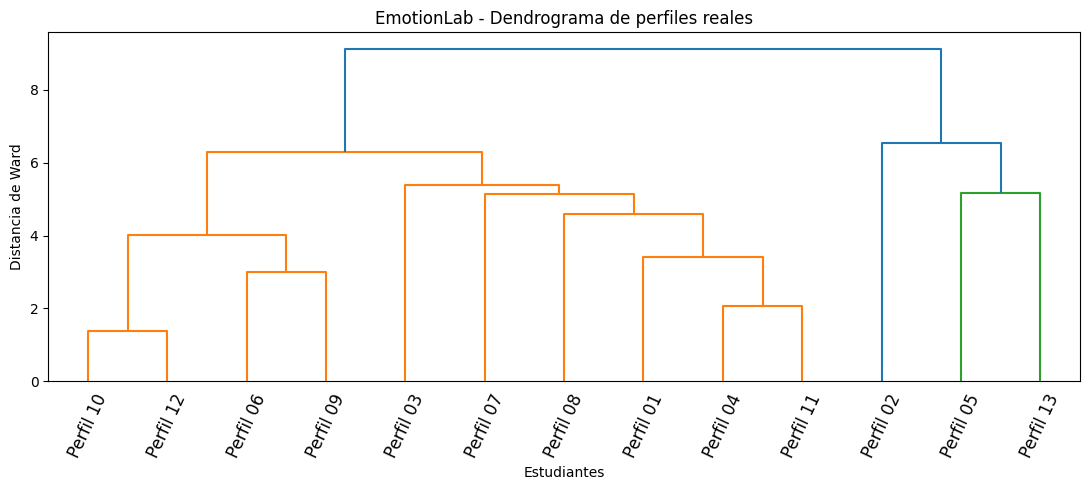

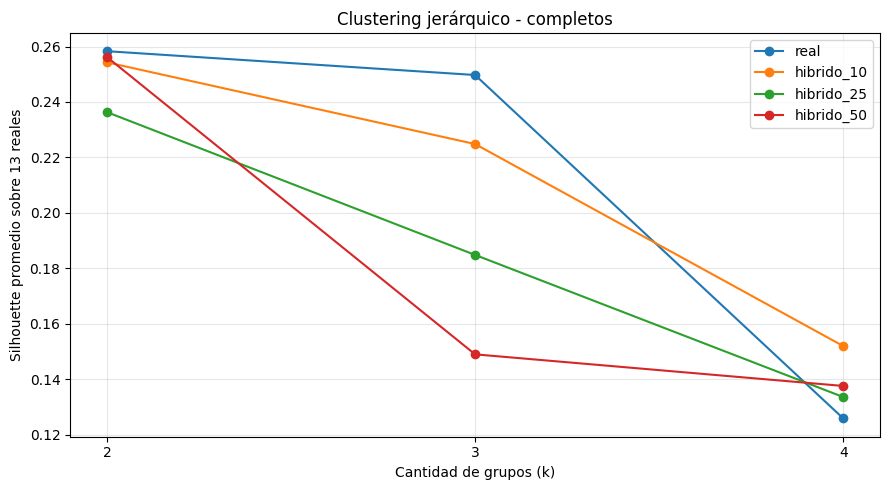

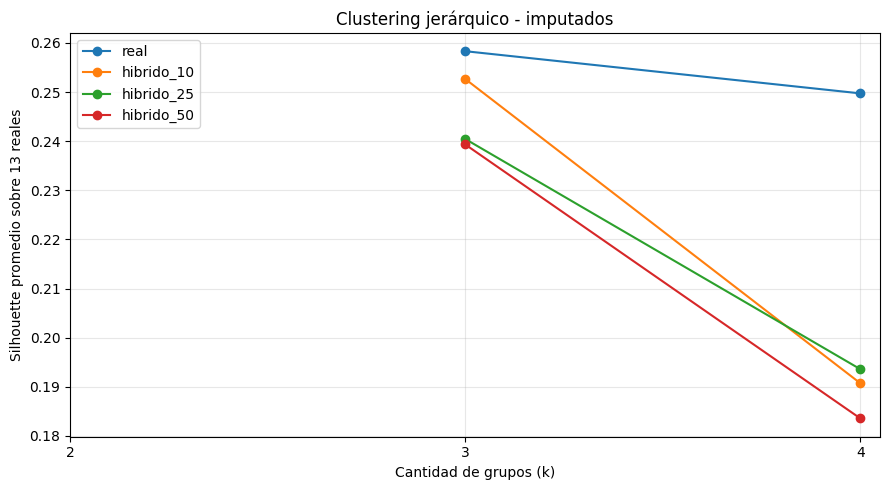

Visualizaciones jerárquicas completadas.


In [ ]:

# =========================================================
# 5.5.4 - VISUALIZACIÓN DE CLUSTERING JERÁRQUICO
# =========================================================

# Construimos el dendrograma utilizando los
# 13 perfiles reales completos, sin imputaciones.

matriz_enlaces = linkage(
    X_real_escalado_ml.to_numpy(),
    method="ward"
)

plt.figure(figsize=(11, 5))

dendrogram(
    matriz_enlaces,
    labels=[
        f"Perfil {i:02d}"
        for i in range(1, len(X_real_escalado_ml) + 1)
    ],
    leaf_rotation=65
)

plt.title("EmotionLab - Dendrograma de perfiles reales")
plt.xlabel("Estudiantes")
plt.ylabel("Distancia de Ward")
plt.tight_layout()
plt.show()

# Comparamos la separación promedio de los
# agrupamientos en ambas versiones del dataset.

for version in ["completos", "imputados"]:

    datos = comparacion_jerarquica.loc[
        comparacion_jerarquica["Versión"].eq(version)
    ]

    plt.figure(figsize=(9, 5))

    for escenario in escenarios_jerarquicos:

        seleccion = datos.loc[
            datos["Escenario"].eq(escenario)
        ].sort_values("k")

        plt.plot(
            seleccion["k"],
            seleccion["Silhouette promedio"],
            marker="o",
            label=escenario
        )

    plt.title(f"Clustering jerárquico - {version}")
    plt.xlabel("Cantidad de grupos (k)")
    plt.ylabel("Silhouette promedio sobre 13 reales")
    plt.xticks(cantidades_grupos_jerarquico)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

print("Visualizaciones jerárquicas completadas.")


### 5.5 — Resultados del entrenamiento de clustering jerárquico

Comparamos datos completos e imputados y escenarios reales e híbridos. Con dos grupos, el modelo real completo obtuvo Silhouette de 0,258 y Davies-Bouldin de 1,434, con tres estudiantes en el grupo menor. El híbrido del 10 % obtuvo 0,254 y 1,423, respectivamente, con ARI de estabilidad de 0,871. Los híbridos del 25 % y 50 % no produjeron una mejora consistente de la separación y el equilibrio de grupos.

Las configuraciones imputadas con dos grupos concentraron los perfiles reales completos de evaluación en una sola agrupación; los dendrogramas permiten interpretar semejanzas, pero no aportan una validación externa.

**Conclusión:** el clustering jerárquico es útil para exploración y visualización. No posee la asignación directa de nuevas observaciones mediante `predict` que ofrece K-Means, cuestión importante para la integración de EmotionLab.

## 5.6 — Entrenamiento y evaluación de Gaussian Mixture Models (GMM)

### ¿Qué realizaremos?

Durante esta sección entrenaremos modelos de Gaussian Mixture Models para identificar agrupaciones probabilísticas entre las respuestas emocionales de los estudiantes de EmotionLab.

A diferencia de K-Means, GMM representa los grupos mediante distribuciones gaussianas y estima la pertenencia de cada estudiante a sus distintos componentes.

### 1. Estrategias de entrenamiento

Compararemos dos estrategias principales:

- **Entrenamiento real:** utilizará los 13 registros reales completos.
- **Entrenamiento híbrido:** combinará registros reales y sintéticos, aproximando proporciones experimentales del 10 %, 25 % y 50 % de datos artificiales.

También realizaremos pruebas con los conjuntos que incorporan imputación por mediana: 14 registros reales aptos y 382 registros híbridos aptos.

### 2. Regularización del modelo

Debido al tamaño reducido de nuestra muestra, utilizaremos una configuración de covarianza diagonal y regularización numérica para disminuir el riesgo de ajustar distribuciones excesivamente específicas.

Esta configuración será experimental y no garantizará por sí sola la eliminación del sobreajuste.

### 3. Entrenamiento y evaluación

Probaremos modelos con 2, 3 y 4 componentes, considerando:

- Silhouette y Davies-Bouldin para estudiar la separación de los grupos.
- Adjusted Rand Index (ARI) para evaluar la estabilidad.
- Cantidad de estudiantes por grupo para detectar agrupaciones demasiado pequeñas.
- Convergencia para comprobar si el procedimiento de entrenamiento finalizó correctamente.
- Probabilidades de pertenencia para analizar la incertidumbre interna de las asignaciones.

### 4. Comparación con los algoritmos anteriores

Evaluaremos las agrupaciones sobre los mismos 13 estudiantes reales completos utilizados en K-Means y clustering jerárquico.

Así podremos comparar el comportamiento matemático de los algoritmos sin confundir los registros sintéticos con participantes independientes.

In [ ]:

# =========================================================
# 5.6.1 - PREPARACIÓN DE CONJUNTOS PARA GMM
# =========================================================


# Extraemos los sintéticos conservando el mismo orden
# y la correspondencia con su procedencia.

def obtener_sinteticos_gmm(matriz, origen):

    if not matriz.index.equals(origen.index):
        raise ValueError("Los índices y la procedencia no coinciden.")

    return matriz.loc[origen.eq("sintetico")].copy()


# Preparamos dos versiones independientes.
# Ambas utilizan el escalador definido en la Etapa 5.2.

conjuntos_gmm = {
    "completos": {
        "reales": X_real_escalado_ml.copy(),
        "sinteticos": obtener_sinteticos_gmm(
            X_hibrido_escalado_ml,
            origen_hibrido_ml
        )
    },
    "imputados": {
        "reales": X_real_imputado_escalado_ml.copy(),
        "sinteticos": obtener_sinteticos_gmm(
            X_hibrido_imputado_escalado_ml,
            origen_hibrido_imputado_ml
        )
    }
}

# Los 13 perfiles originales serán nuestra referencia
# común para evaluar todas las configuraciones.

X_evaluacion_gmm = X_real_escalado_ml.copy()

for version, datos in conjuntos_gmm.items():

    reales = datos["reales"]
    sinteticos = datos["sinteticos"]

    if list(reales.columns) != variables_ml:
        raise ValueError(f"Variables incorrectas: {version}")

    if list(sinteticos.columns) != variables_ml:
        raise ValueError(f"Variables sintéticas incorrectas: {version}")

    if not np.allclose(
        reales.loc[X_evaluacion_gmm.index].to_numpy(),
        X_evaluacion_gmm.to_numpy()
    ):
        raise ValueError("Los registros originales fueron modificados.")

    if not (
        np.isfinite(reales.to_numpy()).all()
        and np.isfinite(sinteticos.to_numpy()).all()
    ):
        raise ValueError(f"Existen valores inválidos: {version}")

# Resumen de los conjuntos disponibles.

resumen_datos_gmm = pd.DataFrame([
    {
        "Versión": version,
        "Reales": len(datos["reales"]),
        "Sintéticos": len(datos["sinteticos"])
    }
    for version, datos in conjuntos_gmm.items()
])

print("DATOS PARA GAUSSIAN MIXTURE MODELS")
display(resumen_datos_gmm)


DATOS PARA GAUSSIAN MIXTURE MODELS


,Versión,Reales,Sintéticos
0,completos,13,336
1,imputados,14,368


In [ ]:

# =========================================================
# 5.6.2 - ENTRENAMIENTO EXPERIMENTAL DE GMM
# =========================================================

# Configuraciones experimentales.

escenarios_gmm = {
    "real": 0.00,
    "hibrido_10": 0.10,
    "hibrido_25": 0.25,
    "hibrido_50": 0.50
}

componentes_gmm = [2, 3, 4]
semillas_gmm = [11, 21, 31, 41, 51]

# Seleccionamos sintéticos priorizando distintas semillas
# de origen cuando esa información esté disponible.

def seleccionar_sinteticos_gmm(datos, cantidad, semilla):

    mezclados = datos.sample(frac=1, random_state=semilla)

    if "id_semilla" not in dataset_hibrido_ml.columns:
        return mezclados.iloc[:cantidad]

    origen_semilla = dataset_hibrido_ml.loc[
        mezclados.index, "id_semilla"
    ]

    diversos = mezclados.loc[
        ~origen_semilla.duplicated()
    ]

    if len(diversos) >= cantidad:
        return diversos.iloc[:cantidad]

    restantes = mezclados.drop(index=diversos.index)

    return pd.concat([
        diversos,
        restantes.iloc[:cantidad - len(diversos)]
    ])


# Entrenaremos cinco repeticiones por configuración.
# Guardamos modelos y asignaciones para analizarlos.

modelos_gmm = {}
predicciones_gmm = {}
resultados_gmm = []

for version, datos in conjuntos_gmm.items():

    X_reales = datos["reales"]
    X_sinteticos = datos["sinteticos"]

    for escenario, proporcion in escenarios_gmm.items():

        # Calculamos la cantidad aproximada de sintéticos
        # necesaria para alcanzar la proporción solicitada.

        cantidad = round(
            len(X_reales) * proporcion / (1 - proporcion)
        )

        if cantidad > len(X_sinteticos):
            raise ValueError("No hay suficientes datos sintéticos.")

        for k in componentes_gmm:

            for semilla in semillas_gmm:

                # Creamos el conjunto de esta repetición.

                if cantidad > 0:

                    muestra = seleccionar_sinteticos_gmm(
                        X_sinteticos,
                        cantidad,
                        semilla
                    )

                    X_entrenamiento = pd.concat(
                        [X_reales, muestra],
                        ignore_index=True
                    )

                else:
                    X_entrenamiento = X_reales

                # Covarianza diagonal y regularización
                # para limitar la complejidad del ajuste.

                modelo = GaussianMixture(
                    n_components=k,
                    covariance_type="diag",
                    reg_covar=0.1,
                    n_init=3,
                    max_iter=300,
                    random_state=semilla
                )

                modelo.fit(X_entrenamiento)

                # Evaluamos sobre los mismos 13 reales.

                etiquetas = modelo.predict(X_evaluacion_gmm)
                probabilidades = modelo.predict_proba(
                    X_evaluacion_gmm
                )

                clave = (version, escenario, k, semilla)

                modelos_gmm[clave] = modelo
                predicciones_gmm[clave] = etiquetas

                grupos, tamaños = np.unique(
                    etiquetas, return_counts=True
                )

                silhouette = np.nan
                davies = np.nan

                if 2 <= len(grupos) < len(X_evaluacion_gmm):

                    silhouette = silhouette_score(
                        X_evaluacion_gmm, etiquetas
                    )

                    davies = davies_bouldin_score(
                        X_evaluacion_gmm, etiquetas
                    )

                resultados_gmm.append({
                    "Versión": version,
                    "Escenario": escenario,
                    "k": k,
                    "Semilla": semilla,
                    "Registros entrenamiento": len(X_entrenamiento),
                    "Sintéticos usados": cantidad,
                    "Grupos reales": len(grupos),
                    "Menor grupo": int(tamaños.min()),
                    "Silhouette": silhouette,
                    "Davies-Bouldin": davies,
                    "Probabilidad máxima media": (
                        probabilidades.max(axis=1).mean()
                    ),
                    "Convergió": bool(modelo.converged_)
                })

resultados_gmm = pd.DataFrame(resultados_gmm)

print("ENTRENAMIENTO GMM - EMOTIONLAB")
print("Modelos entrenados:", len(modelos_gmm))
print("Modelos convergentes:", resultados_gmm["Convergió"].sum())

display(
    resultados_gmm[[
        "Versión", "Escenario", "k",
        "Registros entrenamiento", "Sintéticos usados"
    ]].drop_duplicates().reset_index(drop=True)
)


ENTRENAMIENTO GMM - EMOTIONLAB
Modelos entrenados: 120
Modelos convergentes: 120


,Versión,Escenario,k,Registros entrenamiento,Sintéticos usados
0,completos,real,2,13,0
1,completos,real,3,13,0
2,completos,real,4,13,0
3,completos,hibrido_10,2,14,1
4,completos,hibrido_10,3,14,1
5,completos,hibrido_10,4,14,1
6,completos,hibrido_25,2,17,4
7,completos,hibrido_25,3,17,4
8,completos,hibrido_25,4,17,4
9,completos,hibrido_50,2,26,13


In [ ]:

# =========================================================
# 5.6.3 - EVALUACIÓN Y ESTABILIDAD DE GMM
# =========================================================

resumenes_gmm = []

for (version, escenario, k), grupo in resultados_gmm.groupby(
    ["Versión", "Escenario", "k"],
    sort=False
):

    # Recuperamos las asignaciones realizadas sobre
    # los mismos 13 estudiantes en cada repetición.

    asignaciones = [
        predicciones_gmm[
            (version, escenario, k, int(semilla))
        ]
        for semilla in grupo["Semilla"]
    ]

    # Medimos la coincidencia entre repeticiones.
    # ARI no depende del número asignado a cada grupo.

    valores_ari = [
        adjusted_rand_score(a, b)
        for a, b in combinations(asignaciones, 2)
    ]

    # Comparamos contra la versión real del mismo
    # conjunto y número de componentes.

    referencia = predicciones_gmm[
        (version, "real", k, semillas_gmm[0])
    ]

    ari_referencia = [
        adjusted_rand_score(referencia, etiquetas)
        for etiquetas in asignaciones
    ]

    resumenes_gmm.append({
        "Versión": version,
        "Escenario": escenario,
        "k": k,
        "Silhouette promedio": grupo["Silhouette"].mean(),
        "Davies-Bouldin promedio": grupo["Davies-Bouldin"].mean(),
        "ARI estabilidad": np.mean(valores_ari),
        "ARI mínimo": np.min(valores_ari),
        "ARI vs real": np.mean(ari_referencia),
        "Menor grupo": grupo["Menor grupo"].min(),
        "Grupos efectivos mín.": grupo["Grupos reales"].min(),
        "Grupos efectivos máx.": grupo["Grupos reales"].max(),
        "Repeticiones válidas": grupo["Silhouette"].notna().sum(),
        "Convergencias": int(grupo["Convergió"].sum()),
        "Pertenencia máxima media": (
            grupo["Probabilidad máxima media"].mean()
        )
    })

comparacion_gmm = pd.DataFrame(resumenes_gmm)

print("COMPARACIÓN EXPERIMENTAL - GMM")
display(comparacion_gmm.round(3))

print("\nEvaluación de estabilidad completada.")


COMPARACIÓN EXPERIMENTAL - GMM


,Versión,Escenario,k,Silhouette promedio,Davies-Bouldin promedio,ARI estabilidad,ARI mínimo,ARI vs real,Menor grupo,Grupos efectivos mín.,Grupos efectivos máx.,Repeticiones válidas,Convergencias,Pertenencia máxima media
0,completos,real,2,0.219,1.607,0.540,0.082,0.724,3,2,2,5,5,0.999
1,completos,real,3,0.137,1.311,0.361,-0.063,0.391,1,3,3,5,5,1.000
2,completos,real,4,0.141,1.036,0.346,0.166,0.477,1,4,4,5,5,1.000
3,completos,hibrido_10,2,0.211,1.433,0.260,-0.058,0.480,1,2,2,5,5,0.998
4,completos,hibrido_10,3,0.138,1.385,0.384,0.103,0.518,1,3,3,5,5,0.999
5,completos,hibrido_10,4,0.098,1.226,0.403,0.141,0.344,1,4,4,5,5,0.999
6,completos,hibrido_25,2,0.262,1.015,0.575,0.329,0.663,1,2,2,5,5,1.000
7,completos,hibrido_25,3,0.132,1.542,0.245,-0.033,0.244,2,3,3,5,5,0.997
8,completos,hibrido_25,4,0.118,1.111,0.267,-0.042,0.489,1,4,4,5,5,0.999
9,completos,hibrido_50,2,0.186,1.420,0.281,-0.022,0.440,1,2,2,5,5,1.000



Evaluación de estabilidad completada.


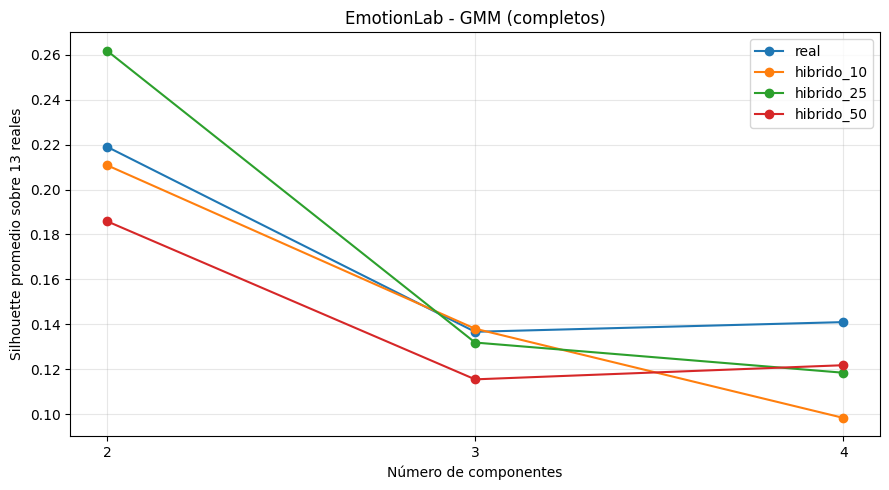

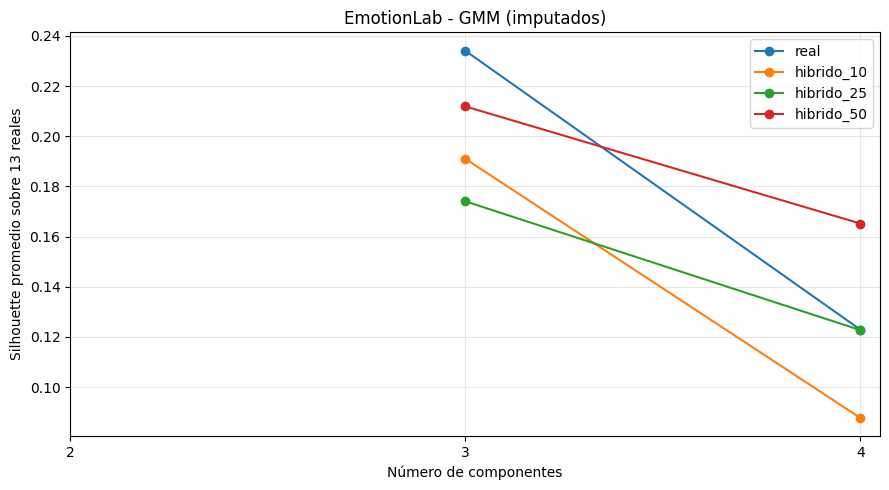

EJEMPLO DE PERTENENCIA A COMPONENTES - GMM


,Registro,Componente,Probabilidad máxima
0,Registro 01,0,1.0
1,Registro 02,1,1.0
2,Registro 03,0,1.0
3,Registro 04,0,1.0
4,Registro 05,1,1.0
5,Registro 06,0,1.0
6,Registro 07,0,1.0
7,Registro 08,0,1.0
8,Registro 09,0,1.0
9,Registro 10,0,1.0


In [ ]:

# =========================================================
# 5.6.4 - VISUALIZACIÓN DE RESULTADOS GMM
# =========================================================


# Generamos un gráfico independiente para cada
# versión: registros completos e imputados.

for version in ["completos", "imputados"]:

    datos = comparacion_gmm.loc[
        comparacion_gmm["Versión"].eq(version)
    ]

    plt.figure(figsize=(9, 5))

    for escenario in escenarios_gmm:

        seleccion = datos.loc[
            datos["Escenario"].eq(escenario)
        ].sort_values("k")

        plt.plot(
            seleccion["k"],
            seleccion["Silhouette promedio"],
            marker="o",
            label=escenario
        )

    plt.title(f"EmotionLab - GMM ({version})")
    plt.xlabel("Número de componentes")
    plt.ylabel("Silhouette promedio sobre 13 reales")
    plt.xticks(componentes_gmm)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Mostramos un ejemplo de pertenencia probabilística.
# Utilizamos provisionalmente GMM real con k = 2.
# Esto NO constituye una selección definitiva.

modelo_ejemplo_gmm = modelos_gmm[
    ("completos", "real", 2, semillas_gmm[0])
]

probabilidades_ejemplo = modelo_ejemplo_gmm.predict_proba(
    X_evaluacion_gmm
)

ejemplo_pertenencia_gmm = pd.DataFrame({
    "Registro": [
        f"Registro {i:02d}"
        for i in range(1, len(X_evaluacion_gmm) + 1)
    ],
    "Componente": probabilidades_ejemplo.argmax(axis=1),
    "Probabilidad máxima": probabilidades_ejemplo.max(axis=1)
})

print("EJEMPLO DE PERTENENCIA A COMPONENTES - GMM")
display(ejemplo_pertenencia_gmm.round(3))


### 5.6 — Resultados del entrenamiento de Gaussian Mixture Models

En los datos completos con dos componentes, el escenario real obtuvo Silhouette de 0,219, Davies-Bouldin de 1,607 y ARI de estabilidad de 0,540. El híbrido del 10 % obtuvo Silhouette de 0,211 y el del 25 % alcanzó 0,262 y Davies-Bouldin de 1,015; sin embargo, este último produjo un grupo menor de un estudiante y ARI de estabilidad de 0,575. El híbrido del 50 % obtuvo Silhouette de 0,186.

Las configuraciones imputadas con dos componentes no permitieron separar adecuadamente los perfiles reales completos de evaluación. Las probabilidades de pertenencia a componentes reflejan el ajuste interno de GMM, no precisión psicológica ni probabilidad de utilidad de EmotionLab.

**Conclusión:** GMM es una alternativa exploratoria, pero los resultados no demuestran superioridad general ni una mejora suficientemente consistente para reemplazar K-Means.

## 5.7 — Comparación general y selección experimental del modelo

### ¿Qué realizaremos?

Durante esta sección compararemos los resultados de los tres algoritmos de aprendizaje no supervisado desarrollados para EmotionLab:

- **K-Means:** agrupamiento mediante centroides.
- **Clustering jerárquico:** agrupamiento basado en relaciones de semejanza.
- **Gaussian Mixture Models (GMM):** agrupamiento probabilístico mediante distribuciones gaussianas.

### 1. Comparación de resultados

Reuniremos las métricas de Silhouette, Davies-Bouldin, estabilidad ARI y tamaño de los grupos, utilizando los 13 perfiles reales completos como referencia común.

Separaremos los resultados de los entrenamientos con datos completos de aquellos que incorporaron estimaciones mediante la mediana.

### 2. Sensibilidad a la muestra

Además de las pruebas anteriores, retiraremos un estudiante real por vez y volveremos a entrenar los tres algoritmos con los 12 restantes.

Compararemos las agrupaciones resultantes con las obtenidas utilizando los 13 estudiantes, para estudiar su sensibilidad ante cambios en la muestra.

### 3. Revisión del entrenamiento híbrido

Comprobaremos qué configuraciones presentaron ventajas frente al entrenamiento real y revisaremos la trazabilidad de los registros sintéticos.

Estas comparaciones no demostrarán generalización independiente mientras los datos sintéticos puedan depender de los estudiantes utilizados para evaluar.

### 4. Selección experimental

Consideraremos conjuntamente:

- Calidad de separación de los grupos.
- Estabilidad ante cambios en el entrenamiento.
- Tamaño y cantidad efectiva de los grupos.
- Dependencia de datos sintéticos o estimados.
- Capacidad técnica de asignar un grupo a nuevos estudiantes.

In [ ]:

# =========================================================
# 5.7.1 - COMPARACIÓN GENERAL DE ALGORITMOS
# =========================================================

# Verificamos que existan los resultados necesarios.

requeridas = [
    "comparacion_kmeans",
    "comparacion_jerarquica",
    "comparacion_gmm"
]

faltantes = [v for v in requeridas if v not in globals()]

if faltantes:
    raise ValueError(f"Faltan resultados: {faltantes}")

# Unificamos los nombres de las métricas para comparar
# los tres algoritmos en una misma tabla.

km = comparacion_kmeans.rename(columns={
    "Silhouette real": "Silhouette",
    "Davies-Bouldin real": "Davies-Bouldin",
    "ARI promedio": "ARI estabilidad",
    "Grupos en reales": "Grupos mínimos"
}).copy()

km["Algoritmo"] = "K-Means"
km["Versión"] = "completos"
km["Grupos máximos"] = km["Grupos mínimos"]
km["Repeticiones válidas"] = km["Silhouette"].notna().astype(int)

jer = comparacion_jerarquica.loc[
    comparacion_jerarquica["Versión"].eq("completos")
].rename(columns={
    "Silhouette promedio": "Silhouette",
    "Davies-Bouldin promedio": "Davies-Bouldin",
    "Menor grupo observado": "Menor grupo",
    "Grupos efectivos mín.": "Grupos mínimos",
    "Grupos efectivos máx.": "Grupos máximos",
    "Evaluaciones válidas": "Repeticiones válidas"
}).copy()

jer["Algoritmo"] = "Jerárquico"

gmm = comparacion_gmm.loc[
    comparacion_gmm["Versión"].eq("completos")
].rename(columns={
    "Silhouette promedio": "Silhouette",
    "Davies-Bouldin promedio": "Davies-Bouldin",
    "Grupos efectivos mín.": "Grupos mínimos",
    "Grupos efectivos máx.": "Grupos máximos"
}).copy()

gmm["Algoritmo"] = "GMM"

# Seleccionamos las mismas columnas de cada modelo.

columnas_comparacion = [
    "Algoritmo", "Versión", "Escenario", "k",
    "Silhouette", "Davies-Bouldin",
    "ARI estabilidad", "Menor grupo",
    "Grupos mínimos", "Grupos máximos",
    "Repeticiones válidas"
]

tabla_modelos_57 = pd.concat(
    [
        km[columnas_comparacion],
        jer[columnas_comparacion],
        gmm[columnas_comparacion]
    ],
    ignore_index=True
)

# Una configuración es descriptivamente adecuada
# si mantiene k grupos efectivos y ningún grupo
# observado tiene menos de dos estudiantes.
#
# Este filtro NO demuestra validez psicológica.

tabla_modelos_57["Agrupación utilizable"] = (
    tabla_modelos_57["Grupos mínimos"].eq(tabla_modelos_57["k"])
    & tabla_modelos_57["Grupos máximos"].eq(tabla_modelos_57["k"])
    & tabla_modelos_57["Menor grupo"].ge(2)
    & tabla_modelos_57["Silhouette"].notna()
)

print("COMPARACIÓN GENERAL - EMOTIONLAB")
display(tabla_modelos_57.round(3))

print("\nCONFIGURACIONES CON DOS GRUPOS")
display(
    tabla_modelos_57.loc[
        tabla_modelos_57["k"].eq(2)
    ].sort_values(
        ["Silhouette", "Davies-Bouldin"],
        ascending=[False, True]
    ).round(3)
)


COMPARACIÓN GENERAL - EMOTIONLAB


,Algoritmo,Versión,Escenario,k,Silhouette,Davies-Bouldin,ARI estabilidad,Menor grupo,Grupos mínimos,Grupos máximos,Repeticiones válidas,Agrupación utilizable
0,K-Means,completos,real,2,0.258,1.434,0.745,3,2,2,1,True
1,K-Means,completos,real,3,0.156,1.503,0.547,2,3,3,1,True
2,K-Means,completos,real,4,0.131,1.192,0.497,1,4,4,1,False
3,K-Means,completos,hibrido_10,2,0.258,1.434,0.653,3,2,2,1,True
4,K-Means,completos,hibrido_10,3,0.156,1.503,0.513,2,3,3,1,True
5,K-Means,completos,hibrido_10,4,0.158,1.124,0.540,1,4,4,1,False
6,K-Means,completos,hibrido_25,2,0.258,1.434,0.875,3,2,2,1,True
7,K-Means,completos,hibrido_25,3,0.139,1.455,0.487,3,3,3,1,True
8,K-Means,completos,hibrido_25,4,0.158,1.124,0.599,1,4,4,1,False
9,K-Means,completos,hibrido_50,2,0.258,1.434,1.000,3,2,2,1,True



CONFIGURACIONES CON DOS GRUPOS


,Algoritmo,Versión,Escenario,k,Silhouette,Davies-Bouldin,ARI estabilidad,Menor grupo,Grupos mínimos,Grupos máximos,Repeticiones válidas,Agrupación utilizable
30,GMM,completos,hibrido_25,2,0.262,1.015,0.575,1,2,2,5,False
0,K-Means,completos,real,2,0.258,1.434,0.745,3,2,2,1,True
3,K-Means,completos,hibrido_10,2,0.258,1.434,0.653,3,2,2,1,True
6,K-Means,completos,hibrido_25,2,0.258,1.434,0.875,3,2,2,1,True
9,K-Means,completos,hibrido_50,2,0.258,1.434,1.000,3,2,2,1,True
12,Jerárquico,completos,real,2,0.258,1.434,NaN,3,2,2,1,True
15,Jerárquico,completos,hibrido_50,2,0.256,1.248,0.682,1,2,2,10,False
13,Jerárquico,completos,hibrido_10,2,0.254,1.423,0.871,2,2,2,10,True
14,Jerárquico,completos,hibrido_25,2,0.236,1.489,0.632,2,2,2,10,True
24,GMM,completos,real,2,0.219,1.607,0.540,3,2,2,5,True


In [ ]:

# =========================================================
# 5.7.2 - ACUERDO ENTRE MODELOS E IMPUTACIÓN
# =========================================================


# Recuperamos asignaciones sobre los mismos 13 reales.
# GMM utiliza la primera semilla evaluada en 5.6.

asignaciones_57 = {
    "K-Means real": predicciones_kmeans[("real", 2)],
    "Jerárquico real": predicciones_jerarquicas[
        ("completos", "real", 2, 0)
    ],
    "GMM híbrido 10": predicciones_gmm[
        ("completos", "hibrido_10", 2, 11)
    ]
}

# Calculamos el acuerdo entre las agrupaciones.
# ARI = 1 indica que las particiones son equivalentes.

nombres = list(asignaciones_57)

acuerdo_57 = pd.DataFrame(
    [
        [
            adjusted_rand_score(
                asignaciones_57[a],
                asignaciones_57[b]
            )
            for b in nombres
        ]
        for a in nombres
    ],
    index=nombres,
    columns=nombres
)

print("ACUERDO ENTRE ALGORITMOS - ARI")
display(acuerdo_57.round(3))

# Revisamos las versiones imputadas con k = 2.
# Nos interesa saber cuántos grupos efectivos
# aparecen entre los 13 estudiantes reales.

revision_imputados_57 = pd.concat([
    evaluacion_kmeans_imputados.loc[
        evaluacion_kmeans_imputados["k"].eq(2),
        ["Escenario", "Grupos reales", "Silhouette"]
    ].assign(Algoritmo="K-Means"),

    comparacion_jerarquica.loc[
        comparacion_jerarquica["Versión"].eq("imputados")
        & comparacion_jerarquica["k"].eq(2),
        ["Escenario", "Grupos efectivos mín.",
         "Silhouette promedio"]
    ].rename(columns={
        "Grupos efectivos mín.": "Grupos reales",
        "Silhouette promedio": "Silhouette"
    }).assign(Algoritmo="Jerárquico"),

    comparacion_gmm.loc[
        comparacion_gmm["Versión"].eq("imputados")
        & comparacion_gmm["k"].eq(2),
        ["Escenario", "Grupos efectivos mín.",
         "Silhouette promedio"]
    ].rename(columns={
        "Grupos efectivos mín.": "Grupos reales",
        "Silhouette promedio": "Silhouette"
    }).assign(Algoritmo="GMM")
], ignore_index=True)

print("\nREVISIÓN DE MODELOS IMPUTADOS - k = 2")
display(
    revision_imputados_57[
        ["Algoritmo", "Escenario", "Grupos reales", "Silhouette"]
    ].round(3)
)


ACUERDO ENTRE ALGORITMOS - ARI


,K-Means real,Jerárquico real,GMM híbrido 10
K-Means real,1.0,1.0,1.0
Jerárquico real,1.0,1.0,1.0
GMM híbrido 10,1.0,1.0,1.0



REVISIÓN DE MODELOS IMPUTADOS - k = 2


,Algoritmo,Escenario,Grupos reales,Silhouette
0,K-Means,real,1,NaN
1,K-Means,hibrido_10,1,NaN
2,K-Means,hibrido_25,1,NaN
3,K-Means,hibrido_50,1,NaN
4,Jerárquico,real,1,NaN
5,Jerárquico,hibrido_10,1,NaN
6,Jerárquico,hibrido_25,1,NaN
7,Jerárquico,hibrido_50,1,NaN
8,GMM,real,1,NaN
9,GMM,hibrido_10,1,NaN


In [ ]:

# =========================================================
# 5.7.3 - SENSIBILIDAD AL RETIRAR ESTUDIANTES
# =========================================================


# Recuperamos los valores originales sin escalar.
# Esto permite ajustar un nuevo escalador en cada
# repetición usando solo los estudiantes restantes.

X_original_57 = X_real_ml.loc[
    X_real_escalado_ml.index, variables_ml
].copy()

# Asignaciones de referencia obtenidas con los
# 13 estudiantes completos y dos grupos.

referencias_57 = {
    "K-Means": np.asarray(
        predicciones_kmeans[("real", 2)]
    ),
    "Jerárquico": np.asarray(
        predicciones_jerarquicas[("completos", "real", 2, 0)]
    ),
    "GMM": np.asarray(
        predicciones_gmm[("completos", "real", 2, 11)]
    )
}

resultados_loo_57 = []

# Repetimos el experimento retirando una fila por vez.

for excluido in range(len(X_original_57)):

    # Seleccionamos los otros 12 estudiantes.
    # No imputamos ni incorporamos sintéticos.

    mascara = np.ones(len(X_original_57), dtype=bool)
    mascara[excluido] = False

    X_entrenamiento = StandardScaler().fit_transform(
        X_original_57.iloc[mascara]
    )

    # Entrenamos los tres algoritmos con idénticos
    # registros y cantidad de grupos.

    km = KMeans(
        n_clusters=2,
        n_init=10,
        random_state=42
    )
    etiquetas_km = km.fit_predict(X_entrenamiento)

    jer = AgglomerativeClustering(
        n_clusters=2,
        linkage="ward"
    )
    etiquetas_jer = jer.fit_predict(X_entrenamiento)

    gmm = GaussianMixture(
        n_components=2,
        covariance_type="diag",
        reg_covar=0.1,
        n_init=3,
        max_iter=300,
        random_state=11
    )
    etiquetas_gmm = gmm.fit_predict(X_entrenamiento)

    asignaciones = {
        "K-Means": etiquetas_km,
        "Jerárquico": etiquetas_jer,
        "GMM": etiquetas_gmm
    }

    for algoritmo, etiquetas in asignaciones.items():

        # Comparamos las asignaciones de los 12
        # estudiantes con la partición original
        # de 13, excluyendo al mismo participante.

        ari = adjusted_rand_score(
            referencias_57[algoritmo][mascara],
            etiquetas
        )

        grupos, cantidades = np.unique(
            etiquetas, return_counts=True
        )

        silhouette = np.nan

        if 2 <= len(grupos) < len(X_entrenamiento):
            silhouette = silhouette_score(
                X_entrenamiento, etiquetas
            )

        resultados_loo_57.append({
            "Algoritmo": algoritmo,
            "Estudiante excluido": excluido + 1,
            "ARI vs referencia": ari,
            "Silhouette": silhouette,
            "Grupos efectivos": len(grupos),
            "Menor grupo": int(cantidades.min())
        })

# Resumimos las 13 repeticiones de cada algoritmo.

resultados_loo_57 = pd.DataFrame(resultados_loo_57)

estabilidad_loo_57 = (
    resultados_loo_57
    .groupby("Algoritmo")
    .agg(
        Repeticiones=("ARI vs referencia", "size"),
        ARI_promedio=("ARI vs referencia", "mean"),
        ARI_minimo=("ARI vs referencia", "min"),
        Silhouette_promedio=("Silhouette", "mean"),
        Menor_grupo=("Menor grupo", "min")
    )
    .reset_index()
)

print("SENSIBILIDAD A LA MUESTRA - 13 EXCLUSIONES")
display(estabilidad_loo_57.round(3))


SENSIBILIDAD A LA MUESTRA - 13 EXCLUSIONES


,Algoritmo,Repeticiones,ARI_promedio,ARI_minimo,Silhouette_promedio,Menor_grupo
0,GMM,13,0.621,-0.142,0.217,2
1,Jerárquico,13,0.890,0.641,0.252,2
2,K-Means,13,0.784,0.064,0.232,2


In [ ]:

# =========================================================
# 5.7.4 - AUDITORÍA DE PROCEDENCIA SINTÉTICA
# =========================================================

# Seleccionamos los registros sintéticos originales.
# No usamos las respuestas imputadas en esta revisión.

sinteticos_57 = dataset_hibrido_ml.loc[
    dataset_hibrido_ml["origen_ml"].eq("sintetico")
].copy()

if "id_semilla" not in sinteticos_57.columns:
    raise ValueError(
        "No existe id_semilla para revisar la procedencia."
    )

# Obtenemos los identificadores originales y los
# correspondientes a los 13 estudiantes evaluables.

ids_reales_57 = set(
    datos_reales_ml["id_estudiante"]
    .dropna().astype(str).str.strip()
)

ids_evaluables_57 = set(
    datos_reales_ml.loc[
        X_real_ml.index, "id_estudiante"
    ].dropna().astype(str).str.strip()
)

# Normalizamos las semillas solo para comparar
# identificadores; no modificamos la columna original.

semillas_57 = (
    sinteticos_57["id_semilla"]
    .astype("string")
    .str.strip()
)

coincide_real = semillas_57.isin(ids_reales_57)
coincide_evaluable = semillas_57.isin(ids_evaluables_57)

# Resumimos qué parte de la dependencia es verificable
# mediante coincidencia exacta de identificadores.

auditoria_sintetica_57 = pd.DataFrame([{
    "Registros sintéticos": len(sinteticos_57),
    "Con semilla identificada": int(semillas_57.notna().sum()),
    "Semillas diferentes": int(semillas_57.nunique()),
    "Coinciden con ID real": int(coincide_real.sum()),
    "Coinciden con ID evaluable": int(coincide_evaluable.sum())
}])

print("AUDITORÍA DE DATOS SINTÉTICOS - EMOTIONLAB")
display(auditoria_sintetica_57)

print("\nIMPORTANTE:")
print("Una coincidencia exacta permite rastrear dependencia.")
print("La ausencia de coincidencias no demuestra independencia.")
print("Debemos revisar el generador antes de validar")
print("modelos híbridos con participantes reservados.")


AUDITORÍA DE DATOS SINTÉTICOS - EMOTIONLAB


,Registros sintéticos,Con semilla identificada,Semillas diferentes,Coinciden con ID real,Coinciden con ID evaluable
0,573,573,22,573,336



IMPORTANTE:
Una coincidencia exacta permite rastrear dependencia.
La ausencia de coincidencias no demuestra independencia.
Debemos revisar el generador antes de validar
modelos híbridos con participantes reservados.


CANDIDATOS EXPERIMENTALES - EMOTIONLAB


,Algoritmo,Escenario,k,Silhouette,Davies-Bouldin,ARI estabilidad,ARI LOO real,Menor grupo,Inferencia directa
0,K-Means,real,2,0.258,1.434,0.745,0.784,3,True
3,K-Means,hibrido_10,2,0.258,1.434,0.653,NaN,3,True
6,K-Means,hibrido_25,2,0.258,1.434,0.875,NaN,3,True
9,K-Means,hibrido_50,2,0.258,1.434,1.000,NaN,3,True
12,Jerárquico,real,2,0.258,1.434,NaN,0.890,3,False
13,Jerárquico,hibrido_10,2,0.254,1.423,0.871,NaN,2,False
14,Jerárquico,hibrido_25,2,0.236,1.489,0.632,NaN,2,False
24,GMM,real,2,0.219,1.607,0.540,0.621,3,True


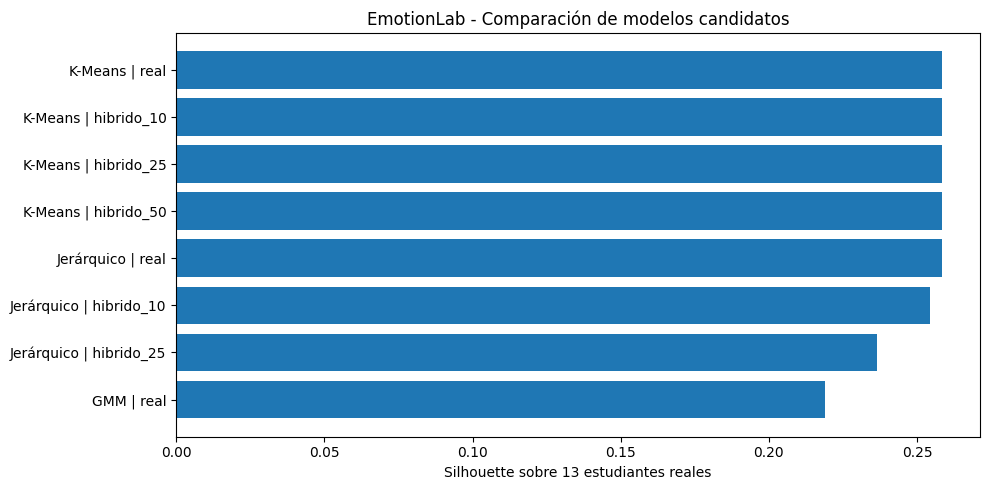


PRESELECCIÓN COMPLETADA
Revisar el ARI LOO, la dependencia sintética
y la capacidad de inferencia antes de elegir.


In [ ]:

# =========================================================
# 5.7.5 - RESUMEN Y PRESELECCIÓN EXPERIMENTAL
# =========================================================


# Recuperamos los modelos con dos grupos y
# una agrupación utilizable sobre los 13 reales.

candidatos_57 = tabla_modelos_57.loc[
    tabla_modelos_57["k"].eq(2)
    & tabla_modelos_57["Agrupación utilizable"]
].copy()

# Incorporamos la sensibilidad a la muestra solamente
# para los modelos reales: no hemos realizado una
# exclusión equivalente libre de filtración en híbridos.

ari_loo = estabilidad_loo_57.set_index(
    "Algoritmo"
)["ARI_promedio"]

candidatos_57["ARI LOO real"] = [
    ari_loo.get(algoritmo, np.nan)
    if escenario == "real" else np.nan
    for algoritmo, escenario in zip(
        candidatos_57["Algoritmo"],
        candidatos_57["Escenario"]
    )
]

# Registramos si el algoritmo puede asignar directamente
# grupos a nuevos perfiles mediante predict().

inferencia_directa = {
    "K-Means": True,
    "GMM": True,
    "Jerárquico": False
}

candidatos_57["Inferencia directa"] = (
    candidatos_57["Algoritmo"].map(inferencia_directa)
)

# Ordenamos los modelos únicamente para facilitar
# su revisión, no para declarar un ganador automático.

candidatos_57 = candidatos_57.sort_values(
    ["Silhouette", "Davies-Bouldin"],
    ascending=[False, True]
)

print("CANDIDATOS EXPERIMENTALES - EMOTIONLAB")

display(
    candidatos_57[[
        "Algoritmo", "Escenario", "k",
        "Silhouette", "Davies-Bouldin",
        "ARI estabilidad", "ARI LOO real",
        "Menor grupo", "Inferencia directa"
    ]].round(3)
)

# Visualizamos la calidad observada en los 13 reales.

plt.figure(figsize=(10, 5))

etiquetas = (
    candidatos_57["Algoritmo"]
    + " | "
    + candidatos_57["Escenario"]
)

plt.barh(etiquetas, candidatos_57["Silhouette"])
plt.xlabel("Silhouette sobre 13 estudiantes reales")
plt.title("EmotionLab - Comparación de modelos candidatos")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("\nPRESELECCIÓN COMPLETADA")
print("Revisar el ARI LOO, la dependencia sintética")
print("y la capacidad de inferencia antes de elegir.")


### 5.7 — Resultados de la comparación general y selección experimental

| Modelo completo, real, k = 2 | Silhouette | Davies-Bouldin | ARI LOO medio | Inferencia directa |
|---|---:|---:|---:|---|
| K-Means | 0,258 | 1,434 | 0,784 | Sí |
| Jerárquico | 0,258 | 1,434 | 0,890 | No |
| GMM | 0,219 | 1,607 | 0,621 | Sí |

La evaluación de sensibilidad mediante 13 exclusiones individuales (LOO) muestra que las agrupaciones pueden cambiar cuando se retira un estudiante. El ARI mínimo de K-Means fue 0,064, por lo que su estabilidad no es perfecta. Los 573 registros sintéticos tienen semillas identificadas correspondientes a 22 participantes reales; no son observaciones independientes.

**Selección:** K-Means real con k = 2 y doce respuestas originales completas. Se elige por su combinación de métricas, ausencia de grupos unitarios, simplicidad y posibilidad de inferencia directa. No se selecciona únicamente por una métrica ni se afirma que sea superior en todos los criterios. El ajuste definitivo se realiza sobre 13 perfiles reales; la imputación se aplica a entradas elegibles durante inferencia, no al entrenamiento seleccionado.

## 5.8 — Interpretación de agrupaciones y visualización mediante PCA

### ¿Qué realizaremos?

Durante esta sección analizaremos las agrupaciones obtenidas mediante K-Means, utilizando el modelo experimental seleccionado en la Etapa 5.7.

Trabajaremos con los 13 estudiantes reales completos y sus doce respuestas de los tres formularios.

Realizaremos cuatro actividades:

1. **Identificación de grupos:** examinaremos cuántos estudiantes pertenecen a cada agrupación.
2. **Análisis de perfiles:** compararemos los promedios de las doce respuestas y visualizaremos la evolución de nerviosismo y estado emocional.
3. **Visualización con PCA:** representaremos los estudiantes en dos dimensiones para facilitar la interpretación.
4. **Evaluación individual:** revisaremos qué tan semejantes son los estudiantes a los demás integrantes de su grupo.

### ¿Por qué utilizaremos PCA?

El Análisis de Componentes Principales (PCA) permite transformar nuestras doce variables en componentes que resumen parte de la variabilidad de los datos.

Esto facilitará visualizar las agrupaciones identificadas por K-Means, aunque la representación bidimensional no conservará necesariamente toda la información original.

### Consideraciones

Los grupos corresponden a patrones de similitud numérica. No representan automáticamente estados de calma, tensión moderada o tensión elevada.

Además, PCA se utilizará únicamente para visualizar e interpretar los resultados, sin modificar el modelo seleccionado ni volver a entrenarlo.

In [ ]:

# =========================================================
# 5.8.1 - RECUPERACIÓN DE AGRUPACIONES K-MEANS
# =========================================================


# Recuperamos el modelo seleccionado en la Etapa 5.7.
# No entrenamos nuevamente el algoritmo.

clave_modelo_58 = ("real", 2)

modelo_seleccionado_ml = modelos_kmeans[clave_modelo_58]

etiquetas_58 = np.asarray(
    predicciones_kmeans[clave_modelo_58]
)

# Verificamos que corresponda a los 13 estudiantes
# reales completos y que existan dos grupos.

if (
    len(etiquetas_58) != len(X_real_ml)
    or len(np.unique(etiquetas_58)) != 2
):
    raise ValueError("Las agrupaciones no son consistentes.")

# Confirmamos que el modelo almacenado genere
# las mismas asignaciones calculadas anteriormente.

if not np.array_equal(
    etiquetas_58,
    modelo_seleccionado_ml.predict(X_real_escalado_ml)
):
    raise ValueError("Las predicciones no coinciden.")

# Recuperamos la posición de cada estudiante dentro
# del conjunto original de 27 registros reales.

posiciones = datos_reales_ml.index.get_indexer(
    X_real_ml.index
)

if (posiciones < 0).any():
    raise ValueError("No se encontraron algunos estudiantes.")

# Creamos identificadores temporales para presentar
# resultados sin exponer los identificadores originales.

perfiles_ml_58 = X_real_ml[variables_ml].copy()

perfiles_ml_58.insert(
    0,
    "Registro",
    [f"Registro {i + 1:02d}" for i in posiciones]
)

perfiles_ml_58["Grupo"] = [
    f"Grupo {etiqueta}" for etiqueta in etiquetas_58
]

# Contamos la cantidad de estudiantes por grupo.

resumen_grupos_58 = (
    perfiles_ml_58["Grupo"]
    .value_counts()
    .sort_index()
    .to_frame("Estudiantes")
)

print("AGRUPACIONES K-MEANS - EMOTIONLAB")
display(resumen_grupos_58)

print("\nAsignaciones individuales:")
display(
    perfiles_ml_58[["Registro", "Grupo"]]
    .reset_index(drop=True)
)

print("\nModelo recuperado correctamente.")


AGRUPACIONES K-MEANS - EMOTIONLAB


,Estudiantes
Grupo,
Grupo 0,3
Grupo 1,10



Asignaciones individuales:


,Registro,Grupo
0,Registro 01,Grupo 1
1,Registro 02,Grupo 0
2,Registro 03,Grupo 1
3,Registro 04,Grupo 1
4,Registro 05,Grupo 0
5,Registro 06,Grupo 1
6,Registro 07,Grupo 1
7,Registro 08,Grupo 1
8,Registro 09,Grupo 1
9,Registro 20,Grupo 1



Modelo recuperado correctamente.


In [ ]:

# =========================================================
# 5.8.2 - COMPARACIÓN DE PERFILES EMOCIONALES
# =========================================================

# Calculamos los promedios de las seis variables
# para cada agrupación identificada.

medias_grupos_58 = (
    perfiles_ml_58
    .groupby("Grupo")[variables_ml]
    .mean()
)

# También calculamos las medianas para reducir
# la influencia descriptiva de valores extremos.

medianas_grupos_58 = (
    perfiles_ml_58
    .groupby("Grupo")[variables_ml]
    .median()
)

print("PROMEDIOS POR GRUPO - ESCALA 1 A 9")
display(medias_grupos_58.round(2))

print("\nMEDIANAS POR GRUPO")
display(medianas_grupos_58.round(2))

# Medimos las diferencias entre las medias.
# Un valor positivo significa que el Grupo 1
# obtuvo una puntuación promedio mayor.

diferencias_grupos_58 = (
    medias_grupos_58.loc["Grupo 1"]
    - medias_grupos_58.loc["Grupo 0"]
)

resumen_diferencias_58 = pd.DataFrame({
    "Diferencia Grupo 1 - Grupo 0": diferencias_grupos_58,
    "Diferencia absoluta": diferencias_grupos_58.abs()
}).sort_values("Diferencia absoluta", ascending=False)

print("\nVARIABLES CON MAYORES DIFERENCIAS")
display(resumen_diferencias_58.round(2))


PROMEDIOS POR GRUPO - ESCALA 1 A 9


,estado_pre,nerviosismo_pre,preocupacion_pre,preparacion_pre,estado_facil,nerviosismo_facil,satisfaccion_facil,alivio_facil,estado_dificil,nerviosismo_dificil,satisfaccion_dificil,alivio_dificil
Grupo,,,,,,,,,,,,
Grupo 0,3.67,4.0,2.33,3.33,3.67,4.67,3.67,4.0,2.0,3.33,2.33,3.67
Grupo 1,1.90,2.8,3.40,2.00,1.50,1.90,1.70,1.8,1.8,2.60,1.10,1.30



MEDIANAS POR GRUPO


,estado_pre,nerviosismo_pre,preocupacion_pre,preparacion_pre,estado_facil,nerviosismo_facil,satisfaccion_facil,alivio_facil,estado_dificil,nerviosismo_dificil,satisfaccion_dificil,alivio_dificil
Grupo,,,,,,,,,,,,
Grupo 0,2.0,3.0,1.0,4.0,4.0,5.0,3.0,4.0,2.0,3.0,2.0,3.0
Grupo 1,1.0,2.5,4.0,1.5,1.0,1.0,2.0,1.0,1.0,2.0,1.0,1.0



VARIABLES CON MAYORES DIFERENCIAS


,Diferencia Grupo 1 - Grupo 0,Diferencia absoluta
nerviosismo_facil,-2.77,2.77
alivio_dificil,-2.37,2.37
alivio_facil,-2.20,2.20
estado_facil,-2.17,2.17
satisfaccion_facil,-1.97,1.97
estado_pre,-1.77,1.77
preparacion_pre,-1.33,1.33
satisfaccion_dificil,-1.23,1.23
nerviosismo_pre,-1.20,1.20
preocupacion_pre,1.07,1.07


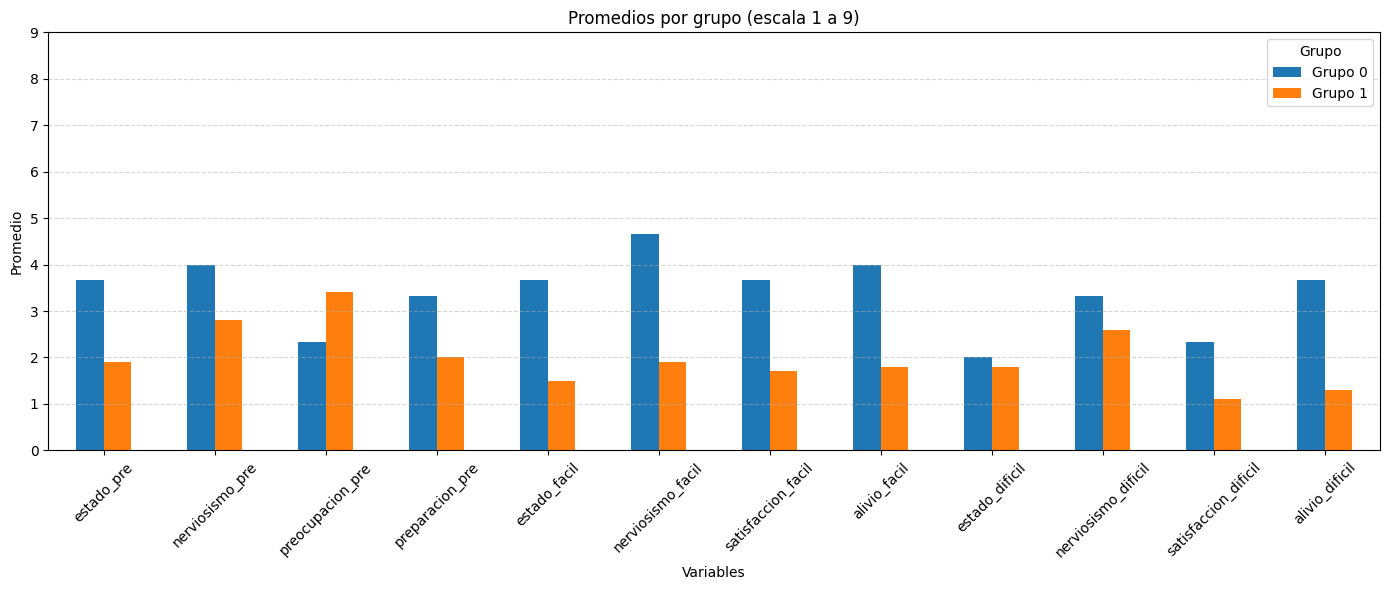

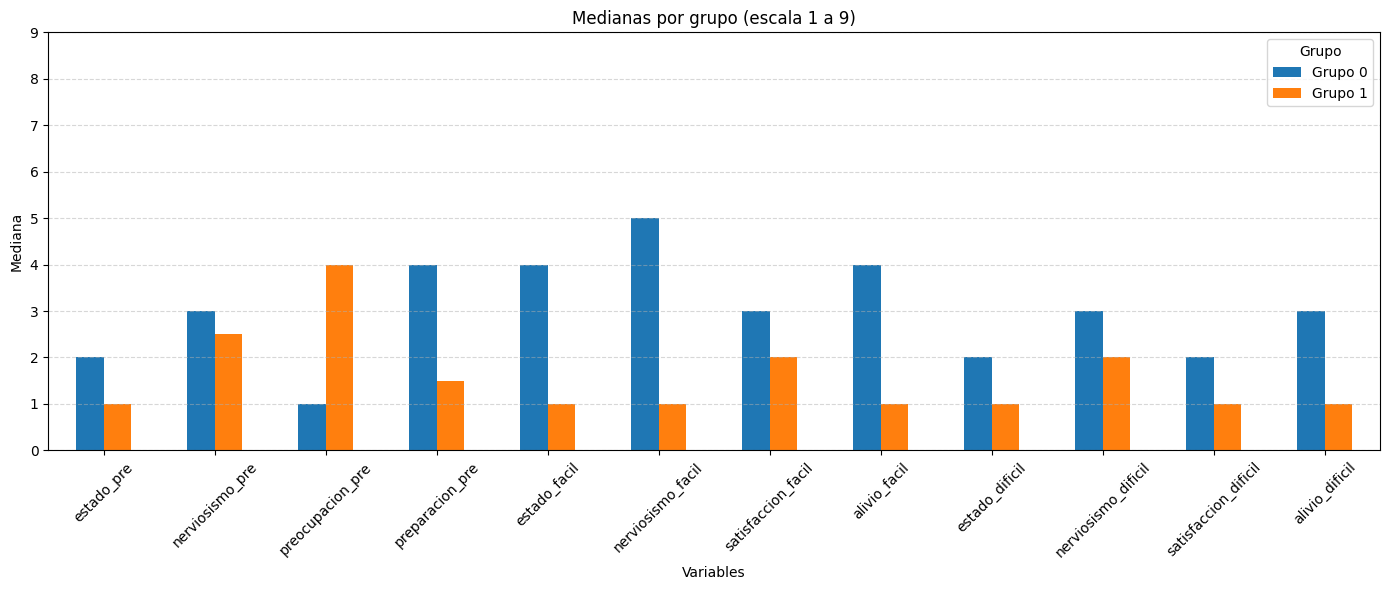

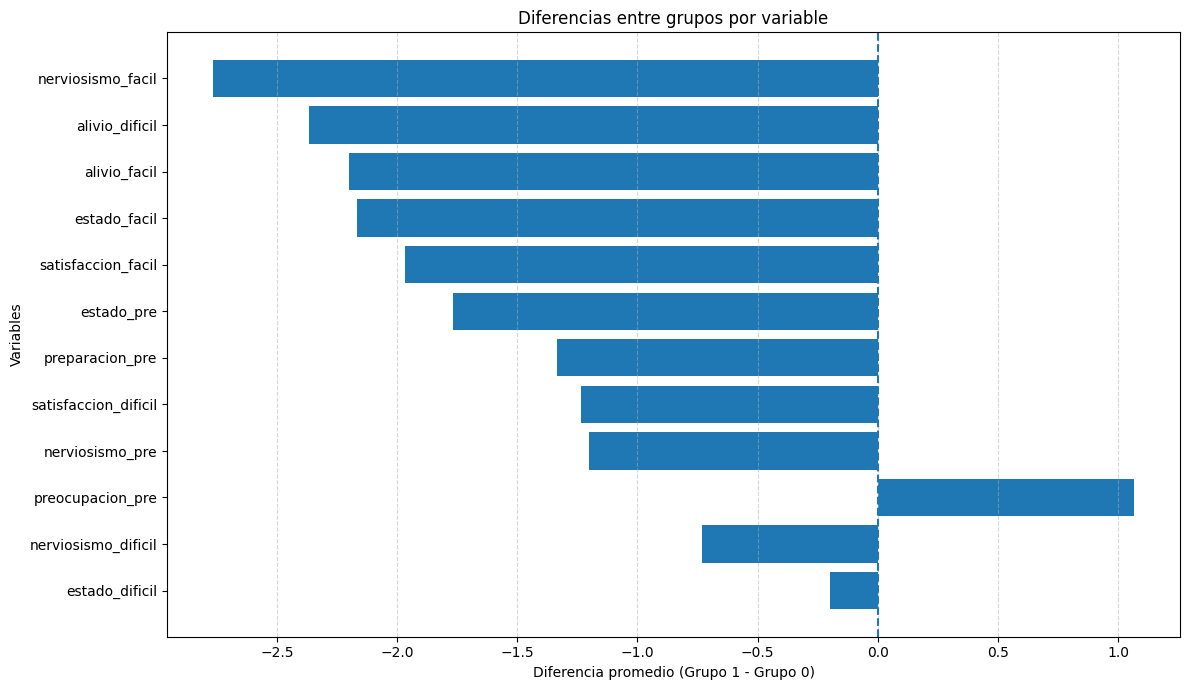

In [ ]:
# =========================================================
# 5.8.2.1 - GRÁFICOS DE COMPARACIÓN ENTRE GRUPOS
# =========================================================

# ---------------------------------------------------------
# 1. GRÁFICO DE PROMEDIOS POR GRUPO
# ---------------------------------------------------------

medias_plot_58 = medias_grupos_58.T

ax = medias_plot_58.plot(
    kind="bar",
    figsize=(14, 6),
    rot=45
)

plt.title("Promedios por grupo (escala 1 a 9)")
plt.xlabel("Variables")
plt.ylabel("Promedio")
plt.ylim(0, 9)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(title="Grupo")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. GRÁFICO DE MEDIANAS POR GRUPO
# ---------------------------------------------------------

medianas_plot_58 = medianas_grupos_58.T

ax = medianas_plot_58.plot(
    kind="bar",
    figsize=(14, 6),
    rot=45
)

plt.title("Medianas por grupo (escala 1 a 9)")
plt.xlabel("Variables")
plt.ylabel("K-means")
plt.ylim(0, 9)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(title="Grupo")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. DIFERENCIAS ENTRE GRUPOS
# ---------------------------------------------------------

diferencias_ordenadas_58 = resumen_diferencias_58.sort_values(
    "Diferencia absoluta",
    ascending=True
)

plt.figure(figsize=(12, 7))
plt.barh(
    diferencias_ordenadas_58.index,
    diferencias_ordenadas_58["Diferencia Grupo 1 - Grupo 0"]
)

plt.title("Diferencias entre grupos por variable")
plt.xlabel("Diferencia promedio (Grupo 1 - Grupo 0)")
plt.ylabel("Variables")
plt.axvline(0, linestyle="--")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

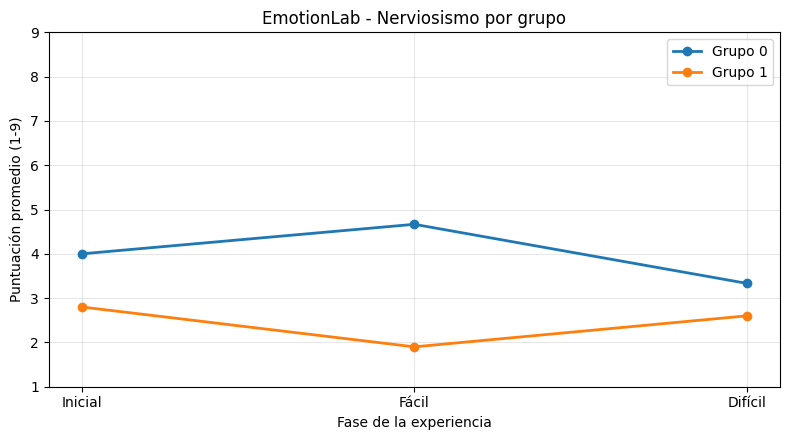

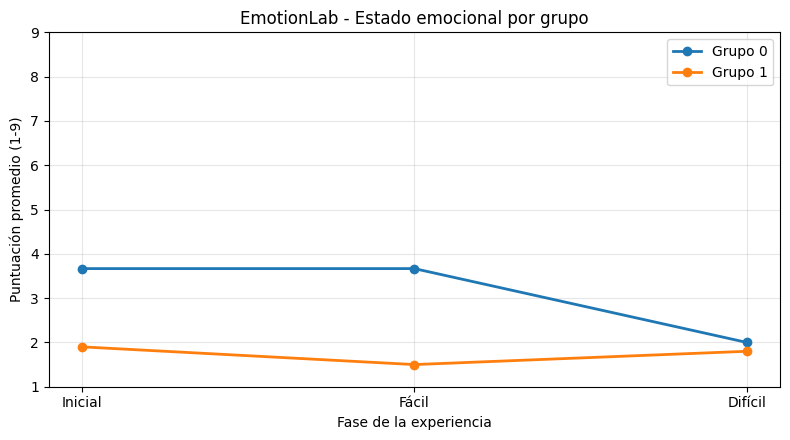

Evolución emocional por grupo visualizada.


In [ ]:

# =========================================================
# 5.8.3 - EVOLUCIÓN EMOCIONAL POR GRUPO
# =========================================================


# Definimos las tres fases de EmotionLab
# y sus respectivas variables de evaluación.

fases_58 = ["Inicial", "Fácil", "Difícil"]

indicadores_58 = {
    "Nerviosismo": [
        "nerviosismo_pre",
        "nerviosismo_facil",
        "nerviosismo_dificil"
    ],
    "Estado emocional": [
        "estado_pre",
        "estado_facil",
        "estado_dificil"
    ]
}

# Creamos un gráfico independiente por indicador.

for indicador, columnas in indicadores_58.items():

    plt.figure(figsize=(8, 4.5))

    for grupo, promedios in medias_grupos_58.iterrows():

        plt.plot(
            fases_58,
            promedios[columnas].to_numpy(dtype=float),
            marker="o",
            linewidth=2,
            label=grupo
        )

    plt.title(f"EmotionLab - {indicador} por grupo")
    plt.xlabel("Fase de la experiencia")
    plt.ylabel("Puntuación promedio (1-9)")
    plt.ylim(1, 9)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

print("Evolución emocional por grupo visualizada.")


VARIANZA EXPLICADA POR PCA
Componente 1: 34.39%
Componente 2: 18.26%
Total explicado: 52.65%


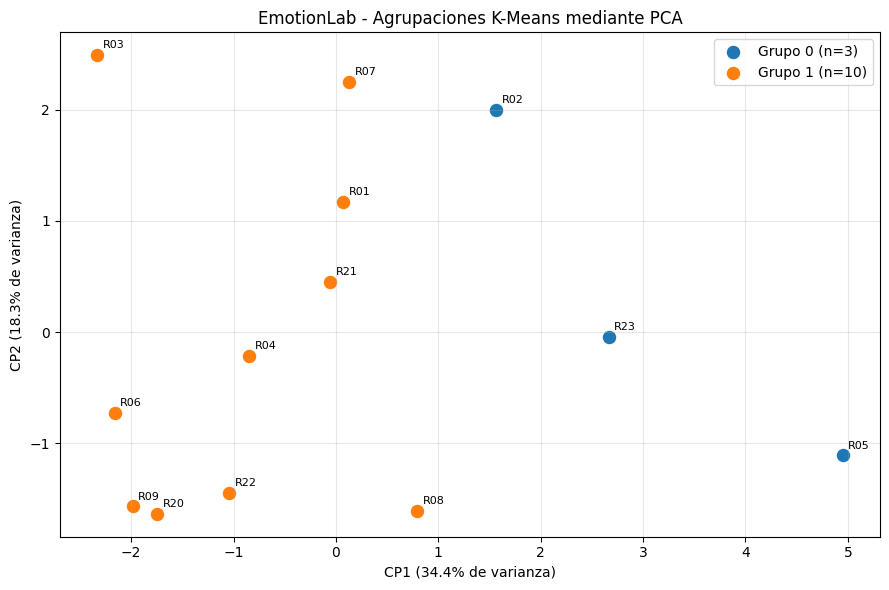

In [ ]:

# =========================================================
# 5.8.4 - VISUALIZACIÓN DE AGRUPACIONES CON PCA
# =========================================================


# Aplicamos PCA sobre las seis variables escaladas.
# Esta transformación es solo para visualización:
# no modifica el entrenamiento de K-Means.

pca_58 = PCA(n_components=2)

coordenadas_pca_58 = pca_58.fit_transform(
    X_real_escalado_ml[variables_ml]
)

# Conservamos los identificadores de presentación
# y las agrupaciones previamente obtenidas.

resultados_pca_58 = pd.DataFrame(
    coordenadas_pca_58,
    columns=["CP1", "CP2"],
    index=X_real_ml.index
)

resultados_pca_58["Registro"] = perfiles_ml_58["Registro"]
resultados_pca_58["Grupo"] = perfiles_ml_58["Grupo"]

# Calculamos cuánta variabilidad explican
# los componentes principales.

varianza_pca_58 = pca_58.explained_variance_ratio_

print("VARIANZA EXPLICADA POR PCA")
print(f"Componente 1: {varianza_pca_58[0]:.2%}")
print(f"Componente 2: {varianza_pca_58[1]:.2%}")
print(f"Total explicado: {varianza_pca_58.sum():.2%}")

# Visualizamos los estudiantes según sus grupos.

plt.figure(figsize=(9, 6))

for grupo, datos in resultados_pca_58.groupby("Grupo"):

    plt.scatter(
        datos["CP1"],
        datos["CP2"],
        s=75,
        label=f"{grupo} (n={len(datos)})"
    )

    # Mostramos un identificador abreviado para
    # reconocer los registros sin exponer sus IDs.

    for _, fila in datos.iterrows():

        plt.annotate(
            fila["Registro"].replace("Registro ", "R"),
            (fila["CP1"], fila["CP2"]),
            xytext=(4, 5),
            textcoords="offset points",
            fontsize=8
        )

plt.title("EmotionLab - Agrupaciones K-Means mediante PCA")
plt.xlabel(f"CP1 ({varianza_pca_58[0]:.1%} de varianza)")
plt.ylabel(f"CP2 ({varianza_pca_58[1]:.1%} de varianza)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

# =========================================================
# 5.8.5 - COHESIÓN INDIVIDUAL DE LOS GRUPOS
# =========================================================


# Calculamos Silhouette para cada estudiante
# utilizando las seis variables estandarizadas.

silhouette_individual_58 = silhouette_samples(
    X_real_escalado_ml[variables_ml],
    etiquetas_58
)

# Organizamos los resultados por participante.

cohesion_estudiantes_58 = perfiles_ml_58[
    ["Registro", "Grupo"]
].copy()

cohesion_estudiantes_58["Silhouette individual"] = (
    silhouette_individual_58
)

# Resumimos la cohesión dentro de cada grupo.

resumen_cohesion_58 = (
    cohesion_estudiantes_58
    .groupby("Grupo")
    .agg(
        Estudiantes=("Registro", "size"),
        Silhouette_promedio=("Silhouette individual", "mean"),
        Silhouette_minimo=("Silhouette individual", "min")
    )
)

# Comprobamos la puntuación global del modelo.

silhouette_global_58 = silhouette_score(
    X_real_escalado_ml[variables_ml],
    etiquetas_58
)

print("COHESIÓN DE LAS AGRUPACIONES - EMOTIONLAB")
display(resumen_cohesion_58.round(3))

print("\nSILHOUETTE POR ESTUDIANTE")
display(
    cohesion_estudiantes_58
    .sort_values("Silhouette individual")
    .reset_index(drop=True)
    .round(3)
)

print(f"\nSilhouette global: {silhouette_global_58:.3f}")

# Verificamos que coincide con la evaluación
# realizada en las etapas anteriores.

if not np.isclose(silhouette_global_58, 0.275, atol=0.001):
    print("Advertencia: revisar diferencias con la Etapa 5.7.")

print("\nEvaluación individual completada.")


COHESIÓN DE LAS AGRUPACIONES - EMOTIONLAB


,Estudiantes,Silhouette_promedio,Silhouette_minimo
Grupo,,,
Grupo 0,3,0.032,-0.053
Grupo 1,10,0.326,0.173



SILHOUETTE POR ESTUDIANTE


,Registro,Grupo,Silhouette individual
0,Registro 02,Grupo 0,-0.053
1,Registro 23,Grupo 0,0.041
2,Registro 05,Grupo 0,0.109
3,Registro 08,Grupo 1,0.173
4,Registro 07,Grupo 1,0.192
5,Registro 01,Grupo 1,0.263
6,Registro 03,Grupo 1,0.317
7,Registro 21,Grupo 1,0.337
8,Registro 09,Grupo 1,0.354
9,Registro 22,Grupo 1,0.354



Silhouette global: 0.258
Advertencia: revisar diferencias con la Etapa 5.7.

Evaluación individual completada.


### 5.8 — Resumen de resultados e interpretación de agrupaciones

El modelo principal de K-Means distribuye los 13 registros reales completos en dos grupos:

| Variable (media, escala 1–9) | Grupo 0 (n = 3) | Grupo 1 (n = 10) |
|---|---:|---:|
| Estado inicial | 3,67 | 1,90 |
| Nerviosismo inicial | 4,00 | 2,80 |
| Preocupación inicial | 2,33 | 3,40 |
| Preparación inicial | 3,33 | 2,00 |
| Estado fácil | 3,67 | 1,50 |
| Nerviosismo fácil | 4,67 | 1,90 |
| Satisfacción fácil | 3,67 | 1,70 |
| Alivio fácil | 4,00 | 1,80 |
| Estado difícil | 2,00 | 1,80 |
| Nerviosismo difícil | 3,33 | 2,60 |
| Satisfacción difícil | 2,33 | 1,10 |
| Alivio difícil | 3,67 | 1,30 |

La mayor diferencia absoluta está en nerviosismo fácil (2,77 puntos), seguida de alivio difícil (2,37), alivio fácil (2,20) y estado fácil (2,17). Preocupación inicial presenta una dirección opuesta al patrón general; por eso no debe interpretarse que todas las variables son mayores en el grupo 0.

PCA explica 52,65 % de la varianza total (34,39 % y 18,26 % por componente). La proyección no es el espacio completo utilizado para clasificar. El Silhouette global es 0,258; por grupo es 0,032 para el grupo 0 y 0,326 para el grupo 1. Existe un Silhouette individual negativo (-0,053), lo que indica una asignación potencialmente ambigua.

**Interpretación:** el grupo 0 representa el perfil de mayor tensión relativa y el grupo 1 el de menor tensión relativa según la orientación de centroides realizada en 5.9.1.1. Se trata de perfiles relativos a esta muestra, no niveles clínicos ni resultados binarios positivos/negativos.

## 5.9 — Validación funcional del modelo de Machine Learning

Se verifica que el K-Means principal y StandardScaler tengan doce variables en el mismo orden y que el modelo pueda asignar un grupo a perfiles completos o válidamente imputados.

### Interpretación de centroides (5.9.1.1)

El algoritmo orienta los grupos después del entrenamiento usando los centroides en escala original y el promedio de las seis variables de referencia de tensión (estado emocional y nerviosismo de las tres fases). En la ejecución actual el grupo 0 corresponde a mayor tensión relativa y el grupo 1 a menor tensión relativa. Las etiquetas pueden cambiar si se reentrena el modelo.

La clasificación se obtiene por distancia euclidiana al centroide más cercano en el espacio estandarizado. El índice relativo de centroides se obtiene proyectando el perfil sobre el eje entre los centroides, escalando la posición de 0 a 100 y limitándola a ese intervalo. No es una probabilidad ni un porcentaje clínico de estrés.

El aporte geométrico se deriva de los coeficientes del eje de los centroides normalizados por sus valores absolutos. Los mayores aportes corresponden a alivio difícil (15,44 %), estado fácil (12,13 %) y nerviosismo fácil (11,82 %). No se trata de importancia causal ni de ponderaciones asignadas manualmente.

### Entradas incompletas

Se mantiene la regla de 5.1.5: únicamente medianas de respuestas originales del mismo indicador y estudiante. Si no pueden completarse todas las variables, la predicción se bloquea. Las pruebas de omisión comparan asignaciones con las del perfil completo; no representan exactitud sobre etiquetas verdaderas.

In [ ]:

# =========================================================
# 5.9.1 - VALIDACIÓN DEL MODELO SELECCIONADO
# =========================================================


# Recuperamos el K-Means real con dos grupos
# seleccionado provisionalmente en la Etapa 5.7.

modelo_final_ml = modelos_kmeans[("real", 2)]
columnas_modelo_ml = list(variables_ml)

# Comprobamos que tanto el modelo como el escalador
# estén entrenados y utilicen las doce variables.

check_is_fitted(modelo_final_ml)
check_is_fitted(escalador_ml)

if (
    modelo_final_ml.n_clusters != 2
    or modelo_final_ml.n_features_in_ != len(columnas_modelo_ml)
    or list(X_real_ml.columns) != columnas_modelo_ml
):
    raise ValueError("La configuración del modelo es incorrecta.")

# Verificamos que el escalador reproduzca exactamente
# los datos utilizados durante el entrenamiento.

X_verificacion = escalador_ml.transform(
    X_real_ml[columnas_modelo_ml]
)

if not np.allclose(
    X_verificacion,
    X_real_escalado_ml[columnas_modelo_ml].to_numpy(),
    rtol=0,
    atol=1e-10
):
    raise ValueError("El escalador no coincide con el original.")

# Las asignaciones también deben ser iguales
# a las obtenidas durante la Etapa 5.3.

if not np.array_equal(
    modelo_final_ml.predict(X_verificacion),
    predicciones_kmeans[("real", 2)]
):
    raise ValueError("Las predicciones originales cambiaron.")

print("MODELO VALIDADO - EMOTIONLAB")
print("Algoritmo: K-Means")
print("Grupos:", modelo_final_ml.n_clusters)
print("Variables:", len(columnas_modelo_ml))
print("Registros de entrenamiento:", len(X_real_ml))
print("Modelo y escalador consistentes.")

MODELO VALIDADO - EMOTIONLAB
Algoritmo: K-Means
Grupos: 2
Variables: 12
Registros de entrenamiento: 13
Modelo y escalador consistentes.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


In [ ]:
# =========================================================
# 5.9.1.1 - PERFILES Y COEFICIENTES APRENDIDOS DE LOS CENTROIDES
# =========================================================
def aprender_perfiles_centroides(modelo, escalador, variables):
    """La asignación permanece a cargo de K-Means; solo se orienta su eje."""
    variables = list(variables)
    centros = np.asarray(modelo.cluster_centers_, dtype=float)
    if centros.shape != (2, len(variables)) or not np.isfinite(centros).all():
        raise ValueError("Se necesitan dos centroides finitos.")
    # Orientación semántica: según el cuestionario, valores altos de estos
    # seis indicadores representan mayor tensión. No se fijan pesos 70/30.
    indicadores_tension = ["nerviosismo_pre", "estado_pre", "nerviosismo_facil",
                            "estado_facil", "nerviosismo_dificil", "estado_dificil"]
    centros_originales = escalador.inverse_transform(centros)
    referencias = centros_originales[:, [variables.index(v) for v in indicadores_tension]].mean(axis=1)
    # Si los perfiles no se pueden orientar, no inventamos un significado.
    if np.isclose(referencias[0], referencias[1], rtol=0, atol=1e-10):
        return None
    mayor = int(np.argmax(referencias))
    menor = 1 - mayor
    diferencia = centros[mayor] - centros[menor]
    norma2 = float(diferencia @ diferencia)
    if norma2 <= 1e-12:
        return None
    coef = diferencia / norma2
    aporte = np.abs(diferencia) / np.abs(diferencia).sum()
    return {
        "grupo_menor_tension": menor, "grupo_mayor_tension": mayor,
        "referencia_tension_centroides": {str(g): float(referencias[g]) for g in (0, 1)},
        "centroide_menor_escalado": centros[menor].tolist(),
        "coeficientes_escalados": dict(zip(variables, map(float, coef))),
        "pesos_relativos_absolutos": dict(zip(variables, map(float, aporte))),
    }


def resultado_centroides(perfiles, escalada, grupo, variables):
    # El eje orientado conecta ambos centroides en el espacio estandarizado.
    # 0 y 100 son los centroides; no son grados clínicos ni probabilidades.
    if grupo is None or perfiles is None:
        return {"perfil_tension": None, "indice_relativo_centroides": None}
    x = np.asarray(escalada, dtype=float).reshape(-1)
    origen = np.asarray(perfiles["centroide_menor_escalado"], dtype=float)
    coef = np.array([perfiles["coeficientes_escalados"][v] for v in variables])
    posicion = float((x - origen) @ coef)
    etiqueta = ("mayor_tension_relativa" if grupo == perfiles["grupo_mayor_tension"]
                else "menor_tension_relativa")
    return {"perfil_tension": etiqueta,
            "indice_relativo_centroides": round(float(np.clip(posicion * 100, 0, 100)), 6)}

perfiles_centroides_ml = aprender_perfiles_centroides(
    modelo_final_ml, escalador_ml, columnas_modelo_ml
)
if perfiles_centroides_ml is None:
    print("No es posible orientar los perfiles de tensión de forma inequívoca.")
else:
    print("Grupo de mayor tensión relativa:", perfiles_centroides_ml["grupo_mayor_tension"])
    print("Grupo de menor tensión relativa:", perfiles_centroides_ml["grupo_menor_tension"])
    display(pd.DataFrame({
        "Coeficiente firmado": perfiles_centroides_ml["coeficientes_escalados"],
        "Aporte geométrico (%)": {v: 100*p for v,p in perfiles_centroides_ml["pesos_relativos_absolutos"].items()}
    }))

Grupo de mayor tensión relativa: 0
Grupo de menor tensión relativa: 1


,Coeficiente firmado,Aporte geométrico (%)
estado_pre,0.051634,7.087163
nerviosismo_pre,0.036610,5.024973
preocupacion_pre,-0.025180,3.456133
preparacion_pre,0.061514,8.443324
estado_facil,0.088399,12.133453
nerviosismo_facil,0.086121,11.820724
satisfaccion_facil,0.072139,9.901631
alivio_facil,0.081982,11.252694
estado_dificil,0.010803,1.482824
nerviosismo_dificil,0.019890,2.730038


In [ ]:
# =========================================================
# 5.9.2 - PREDICCIÓN CON CONTROL DE DATOS NO IMPUTABLES
# =========================================================
columnas_modelo_ml = list(columnas_modelo_ml)
if columnas_modelo_ml != list(variables_ml) or len(columnas_modelo_ml) != 12:
    raise ValueError('El modelo debe utilizar las 12 variables en orden.')
if modelo_final_ml.n_features_in_ != 12 or escalador_ml.n_features_in_ != 12:
    raise ValueError('Se requiere un modelo y escalador de doce características.')

def predecir_emotionlab_ml(respuestas):
    salida = completar_12_por_mediana_ml(respuestas)
    if salida['completo'] is None:
        return {
            'estado': salida['estado'], 'grupo': None,
            'observadas': salida['observadas'], 'estimadas': [],
            'fuentes_imputacion': {}, 'variables_procesadas': None,
            'variables_sin_datos_suficientes': salida['variables_sin_datos_suficientes'],
            'mensaje': 'sin datos suficientes',
            **resultado_centroides(None, None, None, columnas_modelo_ml)
        }
    entrada = pd.DataFrame([salida['completo']], columns=columnas_modelo_ml)
    if entrada.shape != (1, 12) or not np.isfinite(entrada.to_numpy(dtype=float)).all():
        raise AssertionError('El modelo no puede recibir valores faltantes.')
    escalada = pd.DataFrame(escalador_ml.transform(entrada), columns=columnas_modelo_ml)
    grupo = int(modelo_final_ml.predict(escalada)[0])
    return {
        'estado': salida['estado'], 'grupo': grupo,
        'observadas': salida['observadas'], 'estimadas': salida['estimadas'],
        'fuentes_imputacion': salida['fuentes'],
        'variables_procesadas': {v: float(salida['completo'][v]) for v in columnas_modelo_ml},
        'variables_sin_datos_suficientes': [], 'mensaje': None,
        **resultado_centroides(perfiles_centroides_ml, escalada, grupo, columnas_modelo_ml),
    }
print('5.9.2 — No clasifica cuando hay variables sin datos suficientes.')

5.9.2 — No clasifica cuando hay variables sin datos suficientes.


In [ ]:
# =========================================================
# 5.9.2.1 - PRUEBAS DEL ÍNDICE APRENDIDO Y LOS GRUPOS
# =========================================================

if perfiles_centroides_ml is not None:

    assert np.isclose(
        sum(perfiles_centroides_ml["pesos_relativos_absolutos"].values()),
        1
    )

    for grupo in (0, 1):

        centro = modelo_final_ml.cluster_centers_[grupo]

        esperado = (
            100 if grupo == perfiles_centroides_ml["grupo_mayor_tension"]
            else 0
        )

        assert resultado_centroides(
            perfiles_centroides_ml,
            centro,
            grupo,
            columnas_modelo_ml
        )["indice_relativo_centroides"] == esperado

    for _, fila in X_real_ml[columnas_modelo_ml].iterrows():

        respuestas = fila.to_dict()
        resultado = predecir_emotionlab_ml(respuestas)

        entrada = pd.DataFrame(
            [respuestas],
            columns=columnas_modelo_ml
        )

        escalada = pd.DataFrame(
            escalador_ml.transform(entrada),
            columns=columnas_modelo_ml
        )

        grupo_esperado = int(
            modelo_final_ml.predict(escalada)[0]
        )

        assert resultado["grupo"] == grupo_esperado

        assert 0 <= resultado["indice_relativo_centroides"] <= 100

        assert resultado["perfil_tension"] in {
            "mayor_tension_relativa",
            "menor_tension_relativa"
        }

vacio = predecir_emotionlab_ml({
    v: None for v in columnas_modelo_ml
})

assert vacio["grupo"] is None
assert vacio["perfil_tension"] is None
assert vacio["indice_relativo_centroides"] is None

print("Pruebas de perfiles y de asignación K-Means aprobadas.")

Pruebas de perfiles y de asignación K-Means aprobadas.


In [ ]:
# =========================================================
# 5.9.3 - PRUEBAS DE IMPUTACIÓN: INDICADORES NO REPETIDOS
# =========================================================
# Registro sintético: no utiliza información de estudiantes reales.
perfil_593 = {v: 5 for v in columnas_modelo_ml}
casos_593 = {
    'Completo': (perfil_593, 'calculado_sin_estimacion', []),
    'Falta nerviosismo difícil': (
        {**perfil_593, 'nerviosismo_dificil': None}, 'calculado_con_estimacion', []),
    'Falta preocupación única': (
        {**perfil_593, 'preocupacion_pre': None}, 'sin_datos_suficientes', ['preocupacion_pre']),
    'Falta preparación única': (
        {**perfil_593, 'preparacion_pre': None}, 'sin_datos_suficientes', ['preparacion_pre']),
    'Faltan las dos satisfacciones': (
        {**perfil_593, 'satisfaccion_facil': None, 'satisfaccion_dificil': None},
        'sin_datos_suficientes', ['satisfaccion_facil', 'satisfaccion_dificil']),
    'Solo una respuesta': (
        {v: (5 if v == 'estado_pre' else None) for v in columnas_modelo_ml},
        'sin_datos_suficientes', None),
    'Sin respuestas': (
        {v: None for v in columnas_modelo_ml}, 'informacion_insuficiente', None),
}
filas_593=[]
for nombre, (perfil, estado, pendientes) in casos_593.items():
    salida = predecir_emotionlab_ml(perfil)
    assert salida['estado'] == estado, (nombre, salida)
    if pendientes is not None:
        assert salida['variables_sin_datos_suficientes'] == pendientes, (nombre, salida)
    if salida['estado'].startswith('calculado_'):
        assert len(salida['variables_procesadas']) == 12
        assert salida['grupo'] is not None
    else:
        assert salida['grupo'] is None and salida['variables_procesadas'] is None
    filas_593.append({'Prueba': nombre, 'Estado': estado,
                      'Pendientes': ', '.join(salida['variables_sin_datos_suficientes'])})
display(pd.DataFrame(filas_593))
print('5.9.3 — Sin imputaciones de preguntas no repetidas.')

,Prueba,Estado,Pendientes
0,Completo,calculado_sin_estimacion,
1,Falta nerviosismo difícil,calculado_con_estimacion,
2,Falta preocupación única,sin_datos_suficientes,preocupacion_pre
3,Falta preparación única,sin_datos_suficientes,preparacion_pre
4,Faltan las dos satisfacciones,sin_datos_suficientes,"satisfaccion_facil, satisfaccion_dificil"
5,Solo una respuesta,sin_datos_suficientes,"nerviosismo_pre, nerviosismo_facil, nerviosism..."
6,Sin respuestas,informacion_insuficiente,"nerviosismo_pre, nerviosismo_facil, nerviosism..."


5.9.3 — Sin imputaciones de preguntas no repetidas.


In [ ]:
# =========================================================
# 5.9.4 - ROBUSTEZ DE INFERENCIA ANTE RESPUESTAS FALTANTES
# =========================================================
# La concordancia NO equivale a precisión ni validez clínica.
# Los escenarios se evalúan con la mediana PERSONAL.
pruebas_robustez_59 = []
base_59 = X_real_ml[columnas_modelo_ml].dropna()
for _, fila in base_59.iterrows():
    original = fila.to_dict()
    grupo_original = predecir_emotionlab_ml(original)['grupo']
    escenarios = [('Pregunta individual', [v]) for v in columnas_modelo_ml]
    escenarios += [('Formulario completo', list(f)) for f in fases_ml]
    for tipo, omitidas in escenarios:
        incompleto = {**original, **{v: None for v in omitidas}}
        pred = predecir_emotionlab_ml(incompleto)
        pruebas_robustez_59.append({
            'Tipo': tipo,
            'Evaluable': pred['grupo'] is not None,
            'Coincide': pred['grupo'] == grupo_original if pred['grupo'] is not None else np.nan,
            'Estimadas': len(pred['estimadas'])
        })
robustez_59 = pd.DataFrame(pruebas_robustez_59)
resumen_robustez_59 = robustez_59.groupby('Tipo').agg(
    Pruebas=('Evaluable', 'size'), Evaluables=('Evaluable', 'sum'),
    Concordantes=('Coincide', lambda x: x.eq(True).sum()),
    Media_imputaciones=('Estimadas', 'mean')
)
resumen_robustez_59['Cobertura (%)'] = 100 * resumen_robustez_59['Evaluables'] / resumen_robustez_59['Pruebas']
resumen_robustez_59['Concordancia (%)'] = 100 * resumen_robustez_59['Concordantes'] / resumen_robustez_59['Evaluables'].replace(0, np.nan)
display(resumen_robustez_59.round(2))
print('Pruebas de estabilidad con 12 variables; no son un diagnóstico.')

,Pruebas,Evaluables,Concordantes,Media_imputaciones,Cobertura (%),Concordancia (%)
Tipo,,,,,,
Formulario completo,39,26,23,2.67,66.67,88.46
Pregunta individual,156,130,130,0.83,83.33,100.00


Pruebas de estabilidad con 12 variables; no son un diagnóstico.


### 5.9.4 — Resultados de robustez ante respuestas faltantes

| Omisión simulada | Intentos | Evaluables | Concordantes | Cobertura | Concordancia entre evaluables |
|---|---:|---:|---:|---:|---:|
| Pregunta individual | 156 | 130 | 130 | 83,33 % | 100,00 % |
| Formulario completo | 39 | 26 | 23 | 66,67 % | 88,46 % |

La concordancia compara la asignación tras imputar con la asignación original de los mismos 13 perfiles completos. Los casos sin referencias equivalentes quedan excluidos de la concordancia, pero se incluyen al calcular la cobertura. Por ello, el 100 % observado para preguntas individuales no significa que cualquier respuesta faltante sea estimable ni que exista una precisión predictiva del 100 %.

La regla conserva las respuestas originales y rechaza los casos en los que falta preocupación, preparación o un indicador sin referencias disponibles.

## 5.10 — Conclusión de la Etapa 5: Machine Learning

Seleccionamos un K-Means experimental con dos grupos, ajustado sobre 13 registros reales completos (doce variables estandarizadas). Los resultados son Silhouette 0,258, Davies-Bouldin 1,434, ARI de estabilidad 0,745 y ARI medio LOO 0,784. La muestra se distribuye en grupo 0 (3 estudiantes, mayor tensión relativa) y grupo 1 (10, menor tensión relativa). PCA explica el 52,65 % de la variabilidad en dos componentes.

El entrenamiento híbrido no mejoró consistentemente la separación de los perfiles. Los registros sintéticos están vinculados a estudiantes reales y no constituyen validación independiente. La imputación añade un registro real apto, pero los experimentos con k = 2 imputados no mantuvieron dos grupos efectivos sobre los perfiles reales completos de evaluación. Por ello se conservó el modelo entrenado con respuestas originales completas.

Durante la inferencia, el sistema puede completar preguntas repetidas con medianas originales del mismo indicador, sin emplear datos de otras personas ni una mediana global. La concordancia de asignaciones fue 130/130 para omisiones individuales evaluables y 23/26 para formularios evaluables; la cobertura fue 83,33 % y 66,67 %, respectivamente.

El segundo K-Means agrupa el promedio de doce respuestas de 14 registros reales aptos. Sus etiquetas tienen otra interpretación: 0 corresponde a menor promedio relativo (centroide 2,308) y 1 a mayor promedio relativo (8,167). No se utiliza para seleccionar el modelo principal.

**Limitaciones:** las métricas de clustering caracterizan separación, cohesión y estabilidad, no exactitud supervisada. Los modelos no predicen si EmotionLab resultó útil ni si un estudiante volverá a utilizarlo. La validación externa con más estudiantes permanece pendiente. Las etapas siguientes empaquetan e integran el modelo principal sin reentrenarlo.

# Etapa 6 — Empaquetado y preparación del modelo de EmotionLab

## Objetivo

Durante esta etapa prepararemos el modelo de Machine Learning seleccionado para que pueda ejecutarse fuera de Google Colab y posteriormente integrarse con Unity y AWS.

Utilizaremos **K-Means con dos grupos**, entrenado con los 13 estudiantes reales completos y las doce variables de los formularios inicial, fácil y difícil.

### 1. Preparación del modelo

Comprobaremos que el modelo conserve sus parámetros originales, el escalador y el orden correcto de las variables utilizadas durante el entrenamiento.

No volveremos a entrenarlo ni modificaremos sus agrupaciones.

### 2. Empaquetado

Prepararemos los archivos necesarios para ejecutar el modelo en otro entorno:

- **Modelo K-Means:** permitirá asignar nuevas respuestas a los grupos identificados.
- **StandardScaler:** aplicará la misma transformación utilizada durante el entrenamiento.
- **Configuración:** conservará las doce variables, sus escalas y las reglas de validación.
- **Módulo de inferencia:** recibirá respuestas, comprobará su integridad y generará las asignaciones.

### 3. Tratamiento de respuestas incompletas

Conservaremos el procedimiento de imputación por mediana desarrollado en la Etapa 5.

Cuando existan respuestas faltantes, el sistema podrá estimarlas utilizando las respuestas disponibles del mismo indicador en las otras fases, siempre que se cumplan los requisitos mínimos.

Las respuestas originales permanecerán diferenciadas de las estimadas.

### 4. Pruebas de funcionamiento

Comprobaremos que los archivos exportados puedan cargarse nuevamente y reproduzcan las predicciones obtenidas en Colab.

También verificaremos el procesamiento de respuestas completas, parcialmente incompletas e insuficientes.

## 6.1 — Verificación del modelo y sus componentes

En este apartado comprobaremos que K-Means y StandardScaler se encuentren correctamente entrenados y que utilicen las mismas doce variables de EmotionLab.

También verificaremos que las predicciones originales se mantengan y que el procedimiento de imputación continúe funcionando con datos completos e incompletos.

Estas comprobaciones permitirán preparar el modelo para su exportación, evitando incompatibilidades entre los componentes utilizados durante el entrenamiento y la futura inferencia.

In [ ]:

# =========================================================
# 6.1.1 - VERIFICACIÓN DEL MODELO Y ESCALADOR
# =========================================================



# Recuperamos el modelo seleccionado en la Etapa 5.
# No volvemos a entrenarlo.

modelo_final_ml = modelos_kmeans[("real", 2)]
columnas_modelo_ml = list(variables_ml)

# Comprobamos que el modelo y el escalador
# contengan los parámetros aprendidos.

check_is_fitted(modelo_final_ml)
check_is_fitted(escalador_ml)

# Validamos la configuración original.

if modelo_final_ml.n_clusters != 2:
    raise ValueError("K-Means no contiene dos grupos.")

if (
    modelo_final_ml.n_features_in_ != len(columnas_modelo_ml)
    or escalador_ml.n_features_in_ != len(columnas_modelo_ml)
):
    raise ValueError("La cantidad de variables no coincide.")

# Si los componentes conservaron nombres de columnas,
# comprobamos también su orden exacto.

for componente in [modelo_final_ml, escalador_ml]:

    if hasattr(componente, "feature_names_in_"):

        if list(componente.feature_names_in_) != columnas_modelo_ml:
            raise ValueError(
                "El orden de las variables es incorrecto."
            )

print("MODELO Y ESCALADOR VERIFICADOS")
print("Algoritmo: K-Means")
print("Grupos:", modelo_final_ml.n_clusters)
print("Variables:", len(columnas_modelo_ml))
print("Estado: componentes entrenados y compatibles.")

MODELO Y ESCALADOR VERIFICADOS
Algoritmo: K-Means
Grupos: 2
Variables: 12
Estado: componentes entrenados y compatibles.


In [ ]:

# =========================================================
# 6.1.2 - CONSISTENCIA DE LAS PREDICCIONES
# =========================================================


# Comprobamos que las filas originales mantengan
# el mismo orden que durante el entrenamiento.

if not X_real_ml.index.equals(X_real_escalado_ml.index):
    raise ValueError("Los registros perdieron su orden.")

# Reproducimos el escalado con los 13 estudiantes
# reales completos.

X_verificacion = pd.DataFrame(
    escalador_ml.transform(X_real_ml[columnas_modelo_ml]),
    columns=columnas_modelo_ml,
    index=X_real_ml.index
)

# Verificamos que coincide con los valores utilizados
# originalmente para entrenar K-Means.

if not np.allclose(
    X_verificacion.to_numpy(),
    X_real_escalado_ml[columnas_modelo_ml].to_numpy(),
    rtol=0,
    atol=1e-10
):
    raise ValueError("El escalado original no coincide.")

# Generamos nuevamente las asignaciones y las
# comparamos con las guardadas en la Etapa 5.

predicciones_verificadas = modelo_final_ml.predict(
    X_verificacion
)

if not np.array_equal(
    predicciones_verificadas,
    predicciones_kmeans[("real", 2)]
):
    raise ValueError("Las agrupaciones originales cambiaron.")

# Calculamos las métricas directamente sobre
# los resultados verificados.

silhouette_final = silhouette_score(
    X_verificacion, predicciones_verificadas
)

davies_final = davies_bouldin_score(
    X_verificacion, predicciones_verificadas
)

print("CONSISTENCIA DEL MODELO - EMOTIONLAB")
print("Registros verificados:", len(X_verificacion))
print("Silhouette:", round(silhouette_final, 3))
print("Davies-Bouldin:", round(davies_final, 3))

print("\nDistribución de estudiantes:")
display(
    pd.Series(predicciones_verificadas)
    .value_counts()
    .sort_index()
    .to_frame("Estudiantes")
)

print("\nLas predicciones coinciden con el entrenamiento.")


CONSISTENCIA DEL MODELO - EMOTIONLAB
Registros verificados: 13
Silhouette: 0.258
Davies-Bouldin: 1.434

Distribución de estudiantes:


,Estudiantes
0,3
1,10



Las predicciones coinciden con el entrenamiento.


In [ ]:
# =========================================================
# 6.1.3 - PRUEBAS DE ELEGIBILIDAD SEGÚN NUEVA REGLA
# =========================================================
base_613 = {v: 5 for v in columnas_modelo_ml}
pruebas_613 = [
    ('Completo', base_613, 'calculado_sin_estimacion'),
    ('Falta estado difícil', {**base_613, 'estado_dificil': None}, 'calculado_con_estimacion'),
    ('Falta preocupación única', {**base_613, 'preocupacion_pre': None}, 'sin_datos_suficientes'),
    ('Falta preparación única', {**base_613, 'preparacion_pre': None}, 'sin_datos_suficientes'),
    ('Solo una respuesta', {v: (5 if v == 'estado_pre' else None)
                           for v in columnas_modelo_ml}, 'sin_datos_suficientes'),
    ('Cero respuestas', {v: None for v in columnas_modelo_ml}, 'informacion_insuficiente'),
]
filas_613=[]
for nombre, perfil, esperado in pruebas_613:
    r=predecir_emotionlab_ml(perfil)
    assert r['estado'] == esperado, (nombre, r)
    assert (r['grupo'] is None) == (esperado in {'informacion_insuficiente', 'sin_datos_suficientes'})
    filas_613.append({'Caso':nombre,'Estado':r['estado'],'Grupo':r['grupo'],
                      'Pendientes':r['variables_sin_datos_suficientes']})
display(pd.DataFrame(filas_613))
print('6.1.3 — Elegibilidad de doce variables confirmada con datos sintéticos.')

,Caso,Estado,Grupo,Pendientes
0,Completo,calculado_sin_estimacion,0.0,[]
1,Falta estado difícil,calculado_con_estimacion,0.0,[]
2,Falta preocupación única,sin_datos_suficientes,NaN,[preocupacion_pre]
3,Falta preparación única,sin_datos_suficientes,NaN,[preparacion_pre]
4,Solo una respuesta,sin_datos_suficientes,NaN,"[nerviosismo_pre, nerviosismo_facil, nerviosis..."
5,Cero respuestas,informacion_insuficiente,NaN,"[nerviosismo_pre, nerviosismo_facil, nerviosis..."


6.1.3 — Elegibilidad de doce variables confirmada con datos sintéticos.


### 6.1.4 — Resultados y conclusión de la verificación del modelo

K-Means y StandardScaler conservan doce variables y dos grupos. Sobre los 13 registros reales completos se reprodujeron las asignaciones originales (grupo 0: 3, grupo 1: 10), Silhouette de 0,258 y Davies-Bouldin de 1,434.

Se verificaron seis casos controlados: completo, una ausencia estimable, ausencia de preocupación, ausencia de preparación, una sola respuesta y cero respuestas. Los cuatro últimos no reciben grupo. Esta comprobación confirma consistencia técnica, no exactitud predictiva en nuevos estudiantes.

## 6.2 — Almacenamiento y exportación del modelo

En este apartado prepararemos los archivos necesarios para conservar el modelo de Machine Learning desarrollado durante la Etapa 5 de EmotionLab.

Exportaremos el modelo K-Means seleccionado y su escalador StandardScaler utilizando Joblib, una herramienta que permite serializar objetos de Python y recuperarlos posteriormente.

Además, registraremos los metadatos técnicos, incluyendo las doce variables utilizadas durante el entrenamiento, la configuración de agrupamiento y las versiones de las bibliotecas principales.

Por último, verificaremos la integridad de los archivos generados y comprobaremos que, al recuperar el modelo, sus predicciones coincidan con los resultados originales.

**El objetivo es disponer de una versión identificable, reutilizable y verificable del modelo**, preparada para incorporar posteriormente las reglas de imputación y la integración con AWS.

In [ ]:
# =========================================================
# 6.2.1 - ALMACENAMIENTO DEL MODELO Y ESCALADOR
# =========================================================

# Recuperamos los componentes verificados en el 6.1.
# No realizamos un nuevo entrenamiento.

modelo_exportar = modelo_final_ml
escalador_exportar = escalador_ml
variables_exportar = list(columnas_modelo_ml)

# ---------------------------------------------------------
# 1. VERIFICACIÓN DE COMPONENTES
# ---------------------------------------------------------

check_is_fitted(modelo_exportar)
check_is_fitted(escalador_exportar)

if modelo_exportar.n_clusters != 2:
    raise ValueError("El modelo debe tener dos grupos.")

if len(variables_exportar) != 12:
    raise ValueError("Se esperaban doce variables.")

if (
    modelo_exportar.n_features_in_ != len(variables_exportar)
    or escalador_exportar.n_features_in_ != len(variables_exportar)
):
    raise ValueError("Cantidad de variables incompatible.")

# Comprobamos los nombres originales de las variables.

for componente in [modelo_exportar, escalador_exportar]:

    if hasattr(componente, "feature_names_in_"):

        if list(componente.feature_names_in_) != variables_exportar:
            raise ValueError("El orden de las variables no coincide.")

# ---------------------------------------------------------
# 2. PREPARACIÓN DEL DIRECTORIO
# ---------------------------------------------------------

# Esta carpeta almacenará los componentes del modelo
# mientras desarrollamos la Etapa 6.

carpeta_modelo = Path("emotionlab_modelo_v1")

carpeta_modelo.mkdir(
    parents=True,
    exist_ok=True
)

ruta_modelo = carpeta_modelo / "modelo_kmeans_v1.joblib"
ruta_escalador = carpeta_modelo / "escalador_v1.joblib"
ruta_metadatos = carpeta_modelo / "metadatos_v1.json"

# ---------------------------------------------------------
# 3. ALMACENAMIENTO DE COMPONENTES
# ---------------------------------------------------------

joblib.dump(
    modelo_exportar,
    ruta_modelo,
    compress=3
)

joblib.dump(
    escalador_exportar,
    ruta_escalador,
    compress=3
)

# ---------------------------------------------------------
# 4. REGISTRO DE METADATOS
# ---------------------------------------------------------

# Registramos únicamente información técnica.
# No incluimos datos personales de estudiantes.

metadatos_modelo = {
    "proyecto": "EmotionLab",
    "version_modelo": "1.0.0-experimental",
    "algoritmo": "KMeans",
    "numero_grupos": int(modelo_exportar.n_clusters),
    "origen_entrenamiento": "reales_completos",
    "registros_entrenamiento": int(len(X_real_ml)),
    "numero_variables": len(variables_exportar),
    "variables": variables_exportar,
    "escala_respuestas": {
        "minimo": 1,
        "maximo": 9
    },
    "preprocesamiento": "StandardScaler",
    "perfiles_centroides": perfiles_centroides_ml,
    "archivos": {
        "modelo": ruta_modelo.name,
        "escalador": ruta_escalador.name
    },
    "versiones": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": scipy.__version__,
        "scikit-learn": sklearn.__version__,
        "joblib": joblib.__version__
    }
}

ruta_metadatos.write_text(
    json.dumps(
        metadatos_modelo,
        indent=4,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

# ---------------------------------------------------------
# 5. CONFIRMACIÓN
# ---------------------------------------------------------

print("EMOTIONLAB - ALMACENAMIENTO DEL MODELO")
print("Modelo:", ruta_modelo)
print("Escalador:", ruta_escalador)
print("Metadatos:", ruta_metadatos)

print("\nComponentes almacenados correctamente.")
print("No se ha generado ningún ZIP definitivo.")


EMOTIONLAB - ALMACENAMIENTO DEL MODELO
Modelo: emotionlab_modelo_v1/modelo_kmeans_v1.joblib
Escalador: emotionlab_modelo_v1/escalador_v1.joblib
Metadatos: emotionlab_modelo_v1/metadatos_v1.json

Componentes almacenados correctamente.
No se ha generado ningún ZIP definitivo.


In [ ]:
# =========================================================
# 6.2.2 - VERIFICACIÓN DE INTEGRIDAD SHA-256
# =========================================================

# ---------------------------------------------------------
# 1. FUNCIÓN PARA CALCULAR HASHES
# ---------------------------------------------------------

def calcular_sha256(ruta_archivo):

    resumen = hashlib.sha256()

    with open(ruta_archivo, "rb") as archivo:

        for bloque in iter(
            lambda: archivo.read(1024 * 1024),
            b""
        ):
            resumen.update(bloque)

    return resumen.hexdigest()


# ---------------------------------------------------------
# 2. IDENTIFICAMOS LOS ARCHIVOS DEL MODELO
# ---------------------------------------------------------

archivos_verificar = [
    ruta_modelo,
    ruta_escalador,
    ruta_metadatos
]

# Comprobamos que todos los archivos existan.

for archivo in archivos_verificar:

    if not archivo.is_file():
        raise FileNotFoundError(
            f"No se encontró el archivo: {archivo}"
        )

# ---------------------------------------------------------
# 3. GENERAMOS EL MANIFIESTO DE INTEGRIDAD
# ---------------------------------------------------------

manifest_integridad = {
    archivo.name: calcular_sha256(archivo)
    for archivo in archivos_verificar
}

ruta_manifest = (
    carpeta_modelo / "manifest_sha256_v1.json"
)

ruta_manifest.write_text(
    json.dumps(
        manifest_integridad,
        indent=4
    ),
    encoding="utf-8"
)

# ---------------------------------------------------------
# 4. MOSTRAMOS LOS RESULTADOS
# ---------------------------------------------------------

tabla_integridad = pd.DataFrame([
    {
        "Archivo": nombre,
        "SHA-256": resumen
    }
    for nombre, resumen in manifest_integridad.items()
])

print("EMOTIONLAB - INTEGRIDAD DE COMPONENTES")
display(tabla_integridad)

print("\nManifiesto de integridad almacenado correctamente.")

EMOTIONLAB - INTEGRIDAD DE COMPONENTES


,Archivo,SHA-256
0,modelo_kmeans_v1.joblib,6f34c5bcabc6b6b79ec208c01cd7de70aae4c0983f1a2a...
1,escalador_v1.joblib,453ec8124722ee9a8f2ce1fca7aac166141e05394cd17d...
2,metadatos_v1.json,301ac9ec8e15d72922937e3a22a404467a73bb776ad684...



Manifiesto de integridad almacenado correctamente.


In [ ]:
# =========================================================
# 6.2.3 - RECUPERACIÓN Y VERIFICACIÓN DEL MODELO
# =========================================================

# ---------------------------------------------------------
# 1. CARGAMOS METADATOS Y MANIFIESTO
# ---------------------------------------------------------

with open(ruta_metadatos, "r", encoding="utf-8") as archivo:
    metadatos_recuperados = json.load(archivo)

with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_recuperado = json.load(archivo)

# ---------------------------------------------------------
# 2. VERIFICAMOS LA INTEGRIDAD
# ---------------------------------------------------------

for ruta in [ruta_modelo, ruta_escalador, ruta_metadatos]:

    if calcular_sha256(ruta) != manifest_recuperado[ruta.name]:
        raise ValueError(
            f"Error de integridad: {ruta.name}"
        )

# ---------------------------------------------------------
# 3. COMPROBAMOS LAS VERSIONES DEL ENTORNO
# ---------------------------------------------------------

versiones_actuales = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "joblib": joblib.__version__
}

if versiones_actuales != metadatos_recuperados["versiones"]:
    raise ValueError(
        "El entorno actual es diferente al de exportación."
    )

# ---------------------------------------------------------
# 4. RECUPERAMOS EL MODELO Y ESCALADOR
# ---------------------------------------------------------

# Solo debemos cargar archivos confiables
# generados y conservados por nuestro proyecto.

modelo_recuperado = joblib.load(ruta_modelo)
escalador_recuperado = joblib.load(ruta_escalador)

check_is_fitted(modelo_recuperado)
check_is_fitted(escalador_recuperado)

# ---------------------------------------------------------
# 5. COMPROBAMOS LAS PREDICCIONES
# ---------------------------------------------------------

variables_recuperadas = metadatos_recuperados["variables"]

X_recuperado = pd.DataFrame(
    escalador_recuperado.transform(
        X_real_ml[variables_recuperadas]
    ),
    columns=variables_recuperadas,
    index=X_real_ml.index
)

predicciones_recuperadas = modelo_recuperado.predict(
    X_recuperado
)

# Comparamos con las asignaciones originales
# almacenadas durante la Etapa 5.

predicciones_originales = np.asarray(
    predicciones_kmeans[("real", 2)]
)

if not np.array_equal(
    predicciones_recuperadas,
    predicciones_originales
):
    raise ValueError(
        "Las predicciones recuperadas no coinciden."
    )

# Comprobamos también la transformación original.

if not np.allclose(
    X_recuperado.to_numpy(),
    X_real_escalado_ml[variables_recuperadas].to_numpy(),
    atol=1e-10,
    rtol=0
):
    raise ValueError(
        "El escalador recuperado generó resultados distintos."
    )

# ---------------------------------------------------------
# 6. RESULTADOS
# ---------------------------------------------------------

print("EMOTIONLAB - RECUPERACIÓN DEL MODELO")
print("Integridad de archivos: correcta")
print("Modelo y escalador: recuperados")
print("Registros verificados:", len(predicciones_recuperadas))
print("Coincidencia de predicciones: 100 %")
print("Coincidencia del escalado: correcta")

EMOTIONLAB - RECUPERACIÓN DEL MODELO
Integridad de archivos: correcta
Modelo y escalador: recuperados
Registros verificados: 13
Coincidencia de predicciones: 100 %
Coincidencia del escalado: correcta


In [ ]:

# =========================================================
# 6.2.4 - REVISIÓN DE ARCHIVOS ALMACENADOS
# =========================================================

# Objetivo:
# Confirmar que todos los componentes necesarios
# del apartado 6.2 están presentes y son legibles.
#
# No creamos ni descargamos el paquete definitivo.
# Esa operación corresponde al apartado 6.6.

# ---------------------------------------------------------
# 1. ARCHIVOS ESPERADOS
# ---------------------------------------------------------

archivos_esperados = [
    ruta_modelo,
    ruta_escalador,
    ruta_metadatos,
    ruta_manifest
]

# ---------------------------------------------------------
# 2. VERIFICAMOS SU EXISTENCIA Y TAMAÑO
# ---------------------------------------------------------

registros_archivos = []

for archivo in archivos_esperados:

    existe = archivo.is_file()

    tamaño_bytes = (
        archivo.stat().st_size if existe else 0
    )

    registros_archivos.append({
        "Archivo": archivo.name,
        "Existe": existe,
        "Tamaño (KB)": round(tamaño_bytes / 1024, 2),
        "Estado": (
            "Correcto"
            if existe and tamaño_bytes > 0
            else "Error"
        )
    })

tabla_archivos_62 = pd.DataFrame(registros_archivos)

print("EMOTIONLAB - COMPONENTES ALMACENADOS")
display(tabla_archivos_62)

# ---------------------------------------------------------
# 3. VALIDACIÓN FINAL DEL APARTADO
# ---------------------------------------------------------

if not (tabla_archivos_62["Estado"] == "Correcto").all():
    raise ValueError(
        "Faltan archivos o existen componentes vacíos."
    )

print("\nLos cuatro archivos están disponibles.")
print("Almacenamiento preliminar verificado.")
print("Paquete ZIP definitivo: pendiente para el 6.6.")


EMOTIONLAB - COMPONENTES ALMACENADOS


,Archivo,Existe,Tamaño (KB),Estado
0,modelo_kmeans_v1.joblib,True,0.94,Correcto
1,escalador_v1.joblib,True,0.84,Correcto
2,metadatos_v1.json,True,2.97,Correcto
3,manifest_sha256_v1.json,True,0.28,Correcto



Los cuatro archivos están disponibles.
Almacenamiento preliminar verificado.
Paquete ZIP definitivo: pendiente para el 6.6.


### 6.2.5 — Resultados y conclusión del almacenamiento del modelo

Durante este apartado realizamos el almacenamiento y la verificación de los componentes principales del modelo de Machine Learning de EmotionLab, con el objetivo de garantizar su conservación y posterior reutilización sin necesidad de repetir el entrenamiento.

Utilizamos **Joblib** para guardar el modelo K-Means seleccionado y su escalador StandardScaler, conservando la configuración original de dos grupos y doce variables emocionales. Además, generamos un archivo de metadatos que registra la configuración técnica del modelo y las versiones de las bibliotecas utilizadas.

Para comprobar la integridad de los componentes, implementamos un procedimiento de verificación mediante **SHA-256**, generando un manifiesto con las huellas digitales de los archivos almacenados.

Posteriormente, recuperamos el modelo y el escalador desde sus respectivos archivos y verificamos su funcionamiento utilizando los 13 registros reales completos empleados durante el entrenamiento.

Los resultados confirmaron:

- **Integridad de archivos:** verificación satisfactoria de los componentes almacenados.
- **Recuperación del modelo y escalador:** realizada correctamente.
- **Coincidencia de predicciones:** 100 % respecto de las asignaciones originales de los 13 estudiantes.
- **Consistencia del escalado:** los valores transformados coincidieron con los resultados originales.
- **Disponibilidad de archivos:** los cuatro componentes generados existen y presentan tamaños válidos.

Estos resultados demuestran que el procedimiento de almacenamiento y recuperación conserva el comportamiento del modelo en los registros evaluados. Sin embargo, esta comprobación corresponde a una prueba de consistencia técnica y no representa una validación predictiva con estudiantes nuevos.

**En conclusión**, completamos satisfactoriamente el apartado 6.2, estableciendo una base para reutilizar el modelo experimental de EmotionLab. En los siguientes apartados incorporaremos la configuración de imputación por mediana y el módulo independiente de inferencia, antes de realizar las pruebas externas y generar el paquete definitivo en la Etapa 8 (apartado 8.4).

## 6.3 — Configuración de variables y reglas de imputación

Se almacena la configuración de las doce variables, su orden, las tres fases y los seis tipos de indicadores. La configuración establece un mínimo formal de una respuesta original y una fase observada, pero eso no basta para inferir: las doce variables deben estar disponibles o ser estimables a partir de respuestas originales equivalentes del mismo estudiante.

No se admite mediana global personal ni de otros estudiantes. Si una pregunta única o un indicador completo carece de referencia se devuelve un estado sin grupo. La configuración se valida contra la implementación de la Etapa 5 y se registra en el manifiesto de integridad.

In [ ]:
# =========================================================
# 6.3.1 - CONFIGURACIÓN DEL NUEVO CRITERIO DE IMPUTACIÓN
# =========================================================
with open(ruta_metadatos, 'r', encoding='utf-8') as f:
    metadatos_63 = json.load(f)
variables_63 = list(metadatos_63['variables'])
if variables_63 != list(columnas_modelo_ml) or len(variables_63) != 12:
    raise ValueError('Metadatos/modelo requieren las mismas 12 variables.')
configuracion_63 = {
    'proyecto': 'EmotionLab',
    'version_configuracion': '5.0.0-experimental-no-repetidas',
    'variables': variables_63,
    'escala': {'minimo': ESCALA_MINIMA, 'maximo': ESCALA_MAXIMA,
               'respuestas_originales_enteras': True},
    'fases': {'inicial': list(variables_iniciales), 'facil': list(variables_facil),
              'dificil': list(variables_dificil)},
    'indicadores': {
        'nerviosismo': indicadores_ml[0], 'estado_emocional': indicadores_ml[1],
        'satisfaccion': indicadores_ml[2], 'alivio': indicadores_ml[3],
        'preocupacion': indicadores_ml[4], 'preparacion': indicadores_ml[5],
    },
    'criterios_minimos': {'respuestas_observadas': 1, 'fases_observadas': 1,
                          'requiere_todas_variables_estimables': True},
    'numero_caracteristicas_obligatorias': 12,
    'imputacion': {
        'metodo': METODO_IMPUTACION_ML,
        'prioridad': ['mediana_personal_mismo_indicador'],
        'variables_no_repetidas': list(variables_no_repetidas_ml),
        'sin_respuesta_equivalente': 'sin datos suficientes',
        'usar_solo_valores_originales_del_mismo_estudiante': True,
        'usar_mediana_de_otros_estudiantes': False,
        'usar_mediana_global_personal': False,
        'conservar_respuestas_originales': True,
        'redondear_imputadas': False,
        'sin_respuestas': 'informacion_insuficiente',
    },
    'estados': {
        'completo': 'calculado_sin_estimacion',
        'imputado': 'calculado_con_estimacion',
        'insuficiente': 'informacion_insuficiente',
        'sin_datos_suficientes': 'sin_datos_suficientes',
    },
}
ruta_configuracion_63 = carpeta_modelo / 'configuracion_inferencia_v1.json'
ruta_configuracion_63.write_text(
    json.dumps(configuracion_63, indent=4, ensure_ascii=False), encoding='utf-8'
)
print('Configuración de imputación actualizada:', ruta_configuracion_63)

Configuración de imputación actualizada: emotionlab_modelo_v1/configuracion_inferencia_v1.json


In [ ]:
# =========================================================
# 6.3.2 - VALIDACIÓN DE CONFIGURACIÓN SIN IMPUTACIÓN GLOBAL
# =========================================================
with open(ruta_configuracion_63, encoding='utf-8') as f:
    cfg_632 = json.load(f)
if cfg_632['variables'] != list(columnas_modelo_ml):
    raise ValueError('Variables o su orden incompatibles.')
if list(cfg_632['fases'].values()) != [list(g) for g in fases_ml]:
    raise ValueError('Fases incompatibles.')
if list(cfg_632['indicadores'].values()) != [list(g) for g in indicadores_ml]:
    raise ValueError('Indicadores incompatibles.')
if cfg_632['criterios_minimos'] != {
    'respuestas_observadas': 1, 'fases_observadas': 1,
    'requiere_todas_variables_estimables': True,
}:
    raise ValueError('Criterio de elegibilidad incompatible.')
imp_632 = cfg_632['imputacion']
if (imp_632['metodo'] != METODO_IMPUTACION_ML
        or set(imp_632['variables_no_repetidas']) != set(variables_no_repetidas_ml)
        or imp_632['usar_mediana_global_personal'] is not False
        or imp_632['usar_mediana_de_otros_estudiantes'] is not False
        or imp_632['usar_solo_valores_originales_del_mismo_estudiante'] is not True
        or imp_632['sin_respuesta_equivalente'] != 'sin datos suficientes'):
    raise ValueError('Configuración de imputación incompatible.')
if 'medianas_referencia' in imp_632:
    raise ValueError('No se admiten medianas externas.')
print('6.3.2 — Contrato de imputación validado: sin mediana global.')

6.3.2 — Contrato de imputación validado: sin mediana global.


In [ ]:
# =========================================================
# 6.3.3 - PRUEBAS DETERMINISTAS DE IMPUTACIÓN E INSUFICIENCIA
# =========================================================
base_633 = {v: 5 for v in columnas_modelo_ml}
casos_633 = [
    ('Completo', {}, 'calculado_sin_estimacion', 12, 0),
    ('Falta nerviosismo difícil', {'nerviosismo_dificil': None}, 'calculado_con_estimacion', 11, 1),
    ('Falta preocupación', {'preocupacion_pre': None}, 'sin_datos_suficientes', 11, 0),
    ('Falta preparación', {'preparacion_pre': None}, 'sin_datos_suficientes', 11, 0),
    ('Falta satisfacción en ambas fases', {'satisfaccion_facil': None, 'satisfaccion_dificil': None},
     'sin_datos_suficientes', 10, 0),
    ('Solo fase inicial', {v:None for v in variables_facil+variables_dificil},
     'sin_datos_suficientes', 4, 0),
    ('Sin respuestas', {v:None for v in columnas_modelo_ml}, 'informacion_insuficiente', 0, 0),
]
filas_633=[]
for nombre,cambios,estado,n_obs,n_est in casos_633:
    r=predecir_emotionlab_ml({**base_633,**cambios})
    assert r['estado']==estado and r['observadas']==n_obs, (nombre,r)
    assert len(r['estimadas'])==n_est, (nombre,r)
    assert (r['grupo'] is None)==(estado in ('sin_datos_suficientes','informacion_insuficiente'))
    if estado.startswith('calculado_'):
        assert len(r['variables_procesadas'])==12 and not r['variables_sin_datos_suficientes']
    else:
        assert r['variables_procesadas'] is None
    filas_633.append({'Prueba':nombre,'Estado':estado,'Originales':n_obs,'Imputadas':n_est})
# Mediana de 4,8 sobre el propio estudiante = 6.
caso_633 = {**base_633,'nerviosismo_pre':4,'nerviosismo_facil':8,'nerviosismo_dificil':None}
r_633=predecir_emotionlab_ml(caso_633)
assert r_633['variables_procesadas']['nerviosismo_dificil']==6.0
assert r_633['fuentes_imputacion']['nerviosismo_dificil']=='mediana_personal_mismo_indicador'
display(pd.DataFrame(filas_633))
print('6.3.3 — Las variables únicas faltantes no se imputaron.')

,Prueba,Estado,Originales,Imputadas
0,Completo,calculado_sin_estimacion,12,0
1,Falta nerviosismo difícil,calculado_con_estimacion,11,1
2,Falta preocupación,sin_datos_suficientes,11,0
3,Falta preparación,sin_datos_suficientes,11,0
4,Falta satisfacción en ambas fases,sin_datos_suficientes,10,0
5,Solo fase inicial,sin_datos_suficientes,4,0
6,Sin respuestas,informacion_insuficiente,0,0


6.3.3 — Las variables únicas faltantes no se imputaron.


In [ ]:
# =========================================================
# 6.3.4 - RENOVACIÓN CONTROLADA DEL MANIFIESTO SHA-256
# =========================================================
# El JSON de configuración ha cambiado intencionalmente.
# Conservamos y verificamos los hashes de los componentes
# que deben haberse exportado de nuevo en la Etapa 6.2.

nombres_base_634 = [
    'modelo_kmeans_v1.joblib', 'escalador_v1.joblib', 'metadatos_v1.json'
]

def hash_actual_634(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

if not ruta_manifest.is_file():
    raise FileNotFoundError('Primero exporta el modelo en la Etapa 6.2.')
manifest_anterior_634 = json.loads(ruta_manifest.read_text(encoding='utf-8'))
manifest_nuevo_634 = {}
for nombre in nombres_base_634:
    ruta = carpeta_modelo / nombre
    if not ruta.is_file() or nombre not in manifest_anterior_634:
        raise FileNotFoundError(f'Falta un componente exportado o su hash: {nombre}')
    actual = hash_actual_634(ruta)
    if manifest_anterior_634[nombre] != actual:
        raise ValueError(f'El archivo {nombre} cambió desde 6.2: vuelve a exportar.')
    manifest_nuevo_634[nombre] = actual

# Archivo deliberadamente sustituido por 6.3.1: se registra su nuevo hash.
if not ruta_configuracion_63.is_file():
    raise FileNotFoundError('Falta configuración del nuevo contrato.')
manifest_nuevo_634[ruta_configuracion_63.name] = hash_actual_634(ruta_configuracion_63)
ruta_manifest.write_text(json.dumps(manifest_nuevo_634, indent=4), encoding='utf-8')
print('6.3.4 — Manifiesto renovado para modelo/escalador/configuración.')
print('Después ejecuta 6.4.1 y 6.4.2 para cargar el módulo; 6.4.4 registra su hash.')

6.3.4 — Manifiesto renovado para modelo/escalador/configuración.
Después ejecuta 6.4.1 y 6.4.2 para cargar el módulo; 6.4.4 registra su hash.


### 6.3.5 — Resultados y conclusión de la configuración de inferencia

Se creó `configuracion_inferencia_v1.json` con las doce variables, escala de 1 a 9, fases e indicadores. La validación confirmó que no existe respaldo por mediana global.

Se ejecutaron siete casos: cuestionario completo (12 originales), ausencia de nerviosismo difícil (11 originales y una imputada), ausencia de preocupación, ausencia de preparación, ausencia de ambas respuestas de satisfacción, solo fase inicial y cero respuestas. Únicamente los dos primeros fueron clasificables; los restantes recibieron estados de información insuficiente o sin datos suficientes, sin imputaciones parciales.

Se actualizó el manifiesto SHA-256 para incluir la configuración. Las pruebas confirman la implementación de la regla, no la exactitud de las estimaciones frente a nuevos datos.

## 6.4 — Desarrollo del módulo independiente de inferencia

En este apartado desarrollaremos un módulo Python independiente del notebook de entrenamiento, que permita utilizar el modelo experimental de EmotionLab sin ejecutar nuevamente las etapas anteriores.

El módulo recuperará K-Means y StandardScaler desde los archivos almacenados en el apartado 6.2 y utilizará la configuración de variables e imputación preparada en el apartado 6.3.

Su funcionamiento incluirá la validación de respuestas, la identificación de valores ausentes, la imputación por mediana cuando exista información suficiente y la asignación de grupos mediante el modelo entrenado.

También incorporaremos comprobaciones de integridad y pruebas de equivalencia con la función original de la Etapa 5.

El propósito es separar el entrenamiento del procesamiento de nuevas respuestas, facilitando el mantenimiento, las pruebas y la futura integración de EmotionLab con Unity y AWS.

In [ ]:
# =========================================================
# 6.4.1 - EXPORTAR PREDICTOR CON NUEVA REGLA
# =========================================================
ruta_modulo_64 = carpeta_modelo / 'emotionlab_inferencia.py'
codigo_modulo_64 = completar_dependencias_autonomas('''# =========================================================
# EMOTIONLAB - INFERENCIA INDEPENDIENTE: 12 VARIABLES
# Mediana PERSONAL: solo indicador con respuestas ORIGINALES
# =========================================================
# [DEPENDENCIA: HASHLIB]
# [DEPENDENCIA: JSON]
# [DEPENDENCIA: PATHLIB_PATH]

# [DEPENDENCIA: JOBLIB]
# [DEPENDENCIA: NUMPY_NP]
# [DEPENDENCIA: PANDAS_PD]
# [DEPENDENCIA: SKLEARN]
# [DEPENDENCIA: SKLEARN_UTILS_VALIDATION_CHECK_IS_FITTED]


def aprender_perfiles_centroides(modelo, escalador, variables):
    """La asignación permanece a cargo de K-Means; solo se orienta su eje."""
    variables = list(variables)
    centros = np.asarray(modelo.cluster_centers_, dtype=float)
    if centros.shape != (2, len(variables)) or not np.isfinite(centros).all():
        raise ValueError("Se necesitan dos centroides finitos.")
    # Orientación semántica: según el cuestionario, valores altos de estos
    # seis indicadores representan mayor tensión. No se fijan pesos 70/30.
    indicadores_tension = ["nerviosismo_pre", "estado_pre", "nerviosismo_facil",
                            "estado_facil", "nerviosismo_dificil", "estado_dificil"]
    centros_originales = escalador.inverse_transform(centros)
    referencias = centros_originales[:, [variables.index(v) for v in indicadores_tension]].mean(axis=1)
    # Si los perfiles no se pueden orientar, no inventamos un significado.
    if np.isclose(referencias[0], referencias[1], rtol=0, atol=1e-10):
        return None
    mayor = int(np.argmax(referencias))
    menor = 1 - mayor
    diferencia = centros[mayor] - centros[menor]
    norma2 = float(diferencia @ diferencia)
    if norma2 <= 1e-12:
        return None
    coef = diferencia / norma2
    aporte = np.abs(diferencia) / np.abs(diferencia).sum()
    return {
        "grupo_menor_tension": menor, "grupo_mayor_tension": mayor,
        "referencia_tension_centroides": {str(g): float(referencias[g]) for g in (0, 1)},
        "centroide_menor_escalado": centros[menor].tolist(),
        "coeficientes_escalados": dict(zip(variables, map(float, coef))),
        "pesos_relativos_absolutos": dict(zip(variables, map(float, aporte))),
    }


def resultado_centroides(perfiles, escalada, grupo, variables):
    # El eje orientado conecta ambos centroides en el espacio estandarizado.
    # 0 y 100 son los centroides; no son grados clínicos ni probabilidades.
    if grupo is None or perfiles is None:
        return {"perfil_tension": None, "indice_relativo_centroides": None}
    x = np.asarray(escalada, dtype=float).reshape(-1)
    origen = np.asarray(perfiles["centroide_menor_escalado"], dtype=float)
    coef = np.array([perfiles["coeficientes_escalados"][v] for v in variables])
    posicion = float((x - origen) @ coef)
    etiqueta = ("mayor_tension_relativa" if grupo == perfiles["grupo_mayor_tension"]
                else "menor_tension_relativa")
    return {"perfil_tension": etiqueta,
            "indice_relativo_centroides": round(float(np.clip(posicion * 100, 0, 100)), 6)}


class EmotionLabPredictor:
    @staticmethod
    def _sha256(ruta):
        h = hashlib.sha256()
        with open(ruta, 'rb') as f:
            for bloque in iter(lambda: f.read(1024 * 1024), b''):
                h.update(bloque)
        return h.hexdigest()

    def __init__(self, directorio_modelo):
        self.directorio = Path(directorio_modelo)
        rutas = {n: self.directorio / n for n in [
            'metadatos_v1.json', 'configuracion_inferencia_v1.json',
            'modelo_kmeans_v1.joblib', 'escalador_v1.joblib'
        ]}
        ruta_manifest = self.directorio / 'manifest_sha256_v1.json'
        if not ruta_manifest.is_file():
            raise FileNotFoundError('Falta el manifiesto de integridad.')
        manifest = json.loads(ruta_manifest.read_text(encoding='utf-8'))
        for nombre, ruta in rutas.items():
            if not ruta.is_file() or nombre not in manifest:
                raise FileNotFoundError(f'Falta archivo o hash: {nombre}')
            if self._sha256(ruta) != manifest[nombre]:
                raise ValueError(f'Integridad incorrecta: {nombre}')
        self.metadatos = json.loads(rutas['metadatos_v1.json'].read_text(encoding='utf-8'))
        self.configuracion = json.loads(rutas['configuracion_inferencia_v1.json'].read_text(encoding='utf-8'))
        if sklearn.__version__ != self.metadatos['versiones']['scikit-learn']:
            raise RuntimeError('La versión de scikit-learn es distinta a la del entrenamiento.')
        # Solo cargar modelos locales confiables propios: Joblib puede ejecutar código al cargar.
        self.modelo = joblib.load(rutas['modelo_kmeans_v1.joblib'])
        self.escalador = joblib.load(rutas['escalador_v1.joblib'])
        check_is_fitted(self.modelo)
        check_is_fitted(self.escalador)
        cfg = self.configuracion
        self.variables = list(cfg['variables'])
        self.fases = list(cfg['fases'].values())
        self.indicadores = list(cfg['indicadores'].values())
        self.min_observadas = int(cfg['criterios_minimos']['respuestas_observadas'])
        self.min_fases = int(cfg['criterios_minimos']['fases_observadas'])
        self.escala_minima = cfg['escala']['minimo']
        self.escala_maxima = cfg['escala']['maximo']
        if len(self.variables) != 12 or len(set(self.variables)) != 12:
            raise ValueError('Se requieren doce variables únicas.')
        if self.variables != self.metadatos['variables']:
            raise ValueError('Metadatos y configuración difieren.')
        for componente in (self.modelo, self.escalador):
            if componente.n_features_in_ != 12:
                raise ValueError('Modelo/escalador no entrenados con doce características.')
            if hasattr(componente, 'feature_names_in_') and list(componente.feature_names_in_) != self.variables:
                raise ValueError('Orden de características incompatible.')
        if self.modelo.n_clusters != self.metadatos['numero_grupos']:
            raise ValueError('Número de grupos incompatible.')
        for grupos in (self.fases, self.indicadores):
            lista = [v for grupo in grupos for v in grupo]
            if len(lista) != 12 or set(lista) != set(self.variables):
                raise ValueError('Fases/indicadores incompatibles.')
        imp = cfg['imputacion']
        if imp['metodo'] != 'mediana_personal_solo_indicador_con_observaciones':
            raise ValueError('Método de imputación incompatible.')
        if (imp.get('usar_mediana_de_otros_estudiantes') is not False
                or imp.get('usar_solo_valores_originales_del_mismo_estudiante') is not True):
            raise ValueError('No se permiten medianas externas.')
        if self.min_observadas != 1 or self.min_fases != 1:
            raise ValueError('Cero respuestas debe rechazarse.')
        if set(imp['variables_no_repetidas']) != {'preocupacion_pre', 'preparacion_pre'}:
            raise ValueError('Variables no repetidas incompatibles.')
        if imp.get('usar_mediana_global_personal') is not False:
            raise ValueError('No se permite mediana global.')

        self.perfiles_centroides = aprender_perfiles_centroides(self.modelo, self.escalador, self.variables)
        if self.perfiles_centroides != self.metadatos.get("perfiles_centroides"):
            raise ValueError("Los perfiles exportados no coinciden con los centroides.")

    def predecir(self, respuestas):
        if not isinstance(respuestas, dict):
            raise TypeError('Las respuestas deben formar un diccionario.')
        extra = set(respuestas) - set(self.variables)
        if extra:
            raise ValueError(f'Variables desconocidas: {sorted(extra)}')
        originales = {}
        for v in self.variables:
            valor = respuestas.get(v)
            if isinstance(valor, (bool, list, tuple, dict, set, np.ndarray)):
                raise ValueError(f'Tipo de respuesta inválido: {v}')
            if valor is None or (isinstance(valor, str) and not valor.strip()) or pd.isna(valor):
                originales[v] = np.nan
                continue
            try:
                numero = float(valor)
            except (TypeError, ValueError, OverflowError) as exc:
                raise ValueError(f'Respuesta no numérica: {v}') from exc
            if not (np.isfinite(numero) and numero.is_integer()
                    and self.escala_minima <= numero <= self.escala_maxima):
                raise ValueError(f'Respuesta fuera de escala: {v}')
            originales[v] = numero
        n = sum(pd.notna(v) for v in originales.values())
        faltantes = [v for v in self.variables if pd.isna(originales[v])]
        sin_datos, estimables = [], {}
        for grupo in self.indicadores:
            datos = [originales[v] for v in grupo if pd.notna(originales[v])]
            for v in grupo:
                if pd.isna(originales[v]):
                    if len(grupo) == 1 or not datos:
                        sin_datos.append(v)
                    else:
                        estimables[v] = float(np.median(datos))
        if n == 0 or sin_datos:
            return {
                'estado': ('informacion_insuficiente' if n == 0 else 'sin_datos_suficientes'),
                'grupo': None, 'observadas': n, 'estimadas': [], 'fuentes_imputacion': {},
                'variables_procesadas': None,
                'variables_sin_datos_suficientes': sin_datos, 'mensaje': 'sin datos suficientes',
                **resultado_centroides(None, None, None, self.variables),
            }
        completo = originales.copy()
        completo.update(estimables)
        if len(completo) != 12 or not np.isfinite(list(completo.values())).all():
            raise AssertionError('El ML requiere 12 valores numéricos finitos.')
        entrada = pd.DataFrame([completo], columns=self.variables)
        escalada = pd.DataFrame(self.escalador.transform(entrada), columns=self.variables)
        grupo = int(self.modelo.predict(escalada)[0])
        return {
            'estado': ('calculado_con_estimacion' if faltantes else 'calculado_sin_estimacion'),
            'grupo': grupo, 'observadas': n, 'estimadas': faltantes,
            'fuentes_imputacion': {v: 'mediana_personal_mismo_indicador' for v in faltantes},
            'variables_procesadas': {v: float(completo[v]) for v in self.variables},
            'variables_sin_datos_suficientes': [], 'mensaje': None,
            **resultado_centroides(self.perfiles_centroides, escalada, grupo, self.variables),
        }
''')
ruta_modulo_64.write_text(codigo_modulo_64, encoding='utf-8')
compile(codigo_modulo_64, str(ruta_modulo_64), 'exec')
print('Módulo generado; verifica y actualiza el manifiesto antes de usarlo.')

Módulo generado; verifica y actualiza el manifiesto antes de usarlo.


In [ ]:

# =========================================================
# 6.4.2 - CARGA DEL MÓDULO INDEPENDIENTE
# =========================================================

# ---------------------------------------------------------
# 1. IMPORTAMOS EL ARCHIVO PYTHON GENERADO
# ---------------------------------------------------------

especificacion_64 = importlib.util.spec_from_file_location(
    "emotionlab_inferencia_v1",
    str(ruta_modulo_64.resolve())
)

if (
    especificacion_64 is None
    or especificacion_64.loader is None
):
    raise ImportError(
        "No fue posible localizar el módulo de inferencia."
    )

modulo_64 = importlib.util.module_from_spec(
    especificacion_64
)

especificacion_64.loader.exec_module(
    modulo_64
)

# ---------------------------------------------------------
# 2. CARGAMOS EL MODELO DESDE SUS ARCHIVOS
# ---------------------------------------------------------

# El módulo utiliza sus propios componentes,
# almacenados en la carpeta de EmotionLab.

inferencia_64 = modulo_64.EmotionLabPredictor(
    carpeta_modelo
)

# ---------------------------------------------------------
# 3. CONFIRMAMOS LA CARGA
# ---------------------------------------------------------

print("EMOTIONLAB - MÓDULO INDEPENDIENTE")
print("Estado: cargado correctamente")
print("Variables:", len(inferencia_64.variables))
print("Grupos:", inferencia_64.modelo.n_clusters)
print("Escalador: recuperado")
print("Configuración: recuperada")
print("Integridad de los componentes: verificada")


EMOTIONLAB - MÓDULO INDEPENDIENTE
Estado: cargado correctamente
Variables: 12
Grupos: 2
Escalador: recuperado
Configuración: recuperada
Integridad de los componentes: verificada


In [ ]:

# =========================================================
# 6.4.3 - PRUEBAS DE EQUIVALENCIA DE INFERENCIA
# =========================================================

# ---------------------------------------------------------
# 1. PREPARAMOS LAS RESPUESTAS DE PRUEBA
# ---------------------------------------------------------

# Utilizamos un registro real completo como referencia.

perfil_64 = X_real_ml.iloc[0][
    columnas_modelo_ml
].to_dict()

# Caso con una respuesta None.
caso_none_64 = perfil_64.copy()
caso_none_64["nerviosismo_dificil"] = None

# Caso con una respuesta NaN.
caso_nan_64 = perfil_64.copy()
caso_nan_64["estado_dificil"] = np.nan

# Caso con dos respuestas faltantes.
caso_fase_64 = perfil_64.copy()
caso_fase_64["nerviosismo_dificil"] = None
caso_fase_64["estado_dificil"] = np.nan

# Caso con información de una sola fase.
caso_insuficiente_64 = {
    variable: None
    for variable in columnas_modelo_ml
}

caso_insuficiente_64["nerviosismo_pre"] = 6
caso_insuficiente_64["estado_pre"] = 4

# Caso sin respuestas.
caso_vacio_64 = {
    variable: None
    for variable in columnas_modelo_ml
}

casos_prueba_64 = {
    "Completo": perfil_64,
    "Una respuesta None": caso_none_64,
    "Una respuesta NaN": caso_nan_64,
    "Fase difícil faltante": caso_fase_64,
    "Una sola fase": caso_insuficiente_64,
    "Sin respuestas": caso_vacio_64
}

# ---------------------------------------------------------
# 2. COMPARAMOS AMBAS IMPLEMENTACIONES
# ---------------------------------------------------------

resultados_comparacion_64 = []

for nombre, respuestas in casos_prueba_64.items():

    # Función original de la Etapa 5.
    original = predecir_emotionlab_ml(respuestas)

    # Nuevo módulo independiente.
    nuevo = inferencia_64.predecir(respuestas)

    # Comparamos la información principal.
    coincide = (
        original["estado"] == nuevo["estado"]
        and original["grupo"] == nuevo["grupo"]
        and original["observadas"] == nuevo["observadas"]
        and original["estimadas"] == nuevo["estimadas"]
    )

    # Comparamos también los seis valores procesados
    # cuando se ha realizado una predicción.

    if original["variables_procesadas"] is not None:

        for variable in columnas_modelo_ml:

            if not np.isclose(
                original["variables_procesadas"][variable],
                nuevo["variables_procesadas"][variable]
            ):
                coincide = False

    else:

        if nuevo["variables_procesadas"] is not None:
            coincide = False

    # El resultado debe poder serializarse como JSON.
    # No aceptamos NaN ni Infinity en la salida.

    json.dumps(nuevo, allow_nan=False)

    resultados_comparacion_64.append({
        "Prueba": nombre,
        "Estado": nuevo["estado"],
        "Grupo": nuevo["grupo"],
        "Estimadas": len(nuevo["estimadas"]),
        "Equivalencia": coincide
    })

# ---------------------------------------------------------
# 3. MOSTRAMOS LOS RESULTADOS
# ---------------------------------------------------------

tabla_equivalencia_64 = pd.DataFrame(
    resultados_comparacion_64
)

print("EMOTIONLAB - COMPARACIÓN DE INFERENCIAS")
display(tabla_equivalencia_64)

if not tabla_equivalencia_64["Equivalencia"].all():
    raise ValueError(
        "El módulo independiente no coincide "
        "con la función original."
    )

print("\nTodas las pruebas presentan equivalencia.")
print("Resultados compatibles con JSON.")


EMOTIONLAB - COMPARACIÓN DE INFERENCIAS


,Prueba,Estado,Grupo,Estimadas,Equivalencia
0,Completo,calculado_sin_estimacion,1.0,0,True
1,Una respuesta None,calculado_con_estimacion,1.0,1,True
2,Una respuesta NaN,calculado_con_estimacion,1.0,1,True
3,Fase difícil faltante,calculado_con_estimacion,1.0,2,True
4,Una sola fase,sin_datos_suficientes,NaN,0,True
5,Sin respuestas,informacion_insuficiente,NaN,0,True



Todas las pruebas presentan equivalencia.
Resultados compatibles con JSON.


In [ ]:

# =========================================================
# 6.4.3.1 - VALIDACIÓN DE ENTRADAS INCORRECTAS
# =========================================================

# ---------------------------------------------------------
# 1. DEFINIMOS CASOS QUE DEBEN SER RECHAZADOS
# ---------------------------------------------------------

casos_invalidos_64 = {
    "Valor fuera de escala": {
        **perfil_64,
        "nerviosismo_pre": 10
    },

    "Valor booleano": {
        **perfil_64,
        "nerviosismo_pre": True
    },

    "Valor infinito": {
        **perfil_64,
        "nerviosismo_pre": np.inf
    },

    "Lista como respuesta": {
        **perfil_64,
        "nerviosismo_pre": [5]
    },

    "Variable desconocida": {
        **perfil_64,
        "pregunta_inexistente": 5
    }
}

# ---------------------------------------------------------
# 2. EJECUTAMOS LAS VALIDACIONES
# ---------------------------------------------------------

resultados_invalidos_64 = []

for nombre, respuestas in casos_invalidos_64.items():

    rechazado = False

    try:
        inferencia_64.predecir(respuestas)

    except (ValueError, TypeError):
        rechazado = True

    resultados_invalidos_64.append({
        "Prueba": nombre,
        "Rechazado correctamente": rechazado
    })

# ---------------------------------------------------------
# 3. MOSTRAMOS EL RESULTADO
# ---------------------------------------------------------

tabla_invalidos_64 = pd.DataFrame(
    resultados_invalidos_64
)

print("EMOTIONLAB - VALIDACIÓN DE ENTRADAS")
display(tabla_invalidos_64)

if not tabla_invalidos_64[
    "Rechazado correctamente"
].all():
    raise ValueError(
        "Existen entradas inválidas no rechazadas."
    )

print("\nTodas las entradas inválidas fueron rechazadas.")


EMOTIONLAB - VALIDACIÓN DE ENTRADAS


,Prueba,Rechazado correctamente
0,Valor fuera de escala,True
1,Valor booleano,True
2,Valor infinito,True
3,Lista como respuesta,True
4,Variable desconocida,True



Todas las entradas inválidas fueron rechazadas.


In [ ]:

# =========================================================
# 6.4.4 - REGISTRO DE INTEGRIDAD DEL MÓDULO
# =========================================================

# ---------------------------------------------------------
# 1. RECUPERAMOS EL MANIFIESTO EXISTENTE
# ---------------------------------------------------------

with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_64 = json.load(archivo)

# ---------------------------------------------------------
# 2. COMPROBAMOS LOS ARCHIVOS YA REGISTRADOS
# ---------------------------------------------------------

for nombre, hash_esperado in manifest_64.items():

    ruta_archivo = carpeta_modelo / nombre

    if not ruta_archivo.is_file():
        raise FileNotFoundError(
            f"Archivo no encontrado: {nombre}"
        )

    if calcular_sha256(ruta_archivo) != hash_esperado:
        raise ValueError(
            f"Integridad incorrecta: {nombre}"
        )

# ---------------------------------------------------------
# 3. REGISTRAMOS EL MÓDULO DE INFERENCIA
# ---------------------------------------------------------

manifest_64[
    ruta_modulo_64.name
] = calcular_sha256(ruta_modulo_64)

# ---------------------------------------------------------
# 4. ACTUALIZAMOS EL MANIFIESTO
# ---------------------------------------------------------

ruta_manifest.write_text(
    json.dumps(
        manifest_64,
        indent=4
    ),
    encoding="utf-8"
)

# ---------------------------------------------------------
# 5. VERIFICAMOS EL RESULTADO
# ---------------------------------------------------------

print("EMOTIONLAB - ARCHIVOS REGISTRADOS")

for nombre in manifest_64:
    print("-", nombre)

print("\nTotal de archivos registrados:", len(manifest_64))
print("Módulo incorporado al manifiesto.")


EMOTIONLAB - ARCHIVOS REGISTRADOS
- modelo_kmeans_v1.joblib
- escalador_v1.joblib
- metadatos_v1.json
- configuracion_inferencia_v1.json
- emotionlab_inferencia.py

Total de archivos registrados: 5
Módulo incorporado al manifiesto.


### 6.4.5 — Resultados y conclusión del módulo reutilizable de inferencia

Durante este apartado desarrollamos un módulo independiente de inferencia para EmotionLab, con el propósito de separar el procesamiento de nuevas respuestas del entorno utilizado para entrenar el modelo de Machine Learning.

En primer lugar, creamos el archivo `emotionlab_inferencia.py`, incorporando las funcionalidades necesarias para recuperar el modelo K-Means, el escalador StandardScaler y la configuración de inferencia almacenada en los apartados anteriores.

La creación del archivo se completó correctamente y su sintaxis fue validada sin necesidad de realizar un nuevo entrenamiento.

Posteriormente, comprobamos que el módulo pudiera cargar sus componentes, recuperar la configuración de las doce variables y dos grupos, y verificar la integridad de los archivos utilizados.

Para evaluar su funcionamiento, realizamos seis pruebas de equivalencia entre el módulo independiente y la función original desarrollada durante la Etapa 5.

Los resultados mostraron una **coincidencia en las seis pruebas realizadas**, incluyendo cuestionarios completos, respuestas `None`, respuestas `NaN`, formularios incompletos y registros con información insuficiente.

También verificamos que los resultados del nuevo módulo fueran compatibles con el formato JSON, facilitando su futura comunicación con otros componentes del sistema.

Adicionalmente, realizamos cinco pruebas con entradas inválidas, incluyendo valores fuera de escala, booleanos, valores infinitos, listas y variables desconocidas. **Las cinco entradas fueron rechazadas correctamente**, demostrando que el módulo incorpora controles básicos de validación.

Finalmente, registramos el archivo `emotionlab_inferencia.py` en el manifiesto SHA-256, dejando cinco archivos técnicos registrados para su posterior verificación.

**En conclusión**, completamos satisfactoriamente el desarrollo inicial del módulo reutilizable de inferencia de EmotionLab. Las pruebas confirmaron su equivalencia funcional con la implementación original en los casos evaluados, manteniendo el procesamiento de respuestas incompletas mediante imputación por mediana y el control de información insuficiente.

Estos resultados representan una validación técnica dentro de Google Colab, pero no constituyen una evaluación de precisión con estudiantes nuevos ni una prueba de funcionamiento en AWS. El siguiente paso será ejecutar el módulo en un entorno independiente para comprobar que puede utilizarse sin depender del notebook original.

## 6.5 — Pruebas de ejecución independiente del módulo de inferencia

En este apartado evaluaremos el funcionamiento del módulo de inferencia de EmotionLab mediante un proceso de Python independiente del notebook de entrenamiento.

Prepararemos una copia temporal de los archivos del modelo y ejecutaremos pruebas sin utilizar directamente las variables de entrenamiento almacenadas en Google Colab.

Verificaremos la carga de los componentes, la equivalencia de las predicciones, el procesamiento de respuestas completas e incompletas, la validación de entradas inválidas y la detección de modificaciones en los archivos.

Estas pruebas permitirán evaluar la autonomía técnica del módulo antes del empaquetado definitivo, sin volver a entrenar K-Means ni modificar sus resultados originales.

In [ ]:

# =========================================================
# 6.5.1 - PREPARACIÓN DEL ENTORNO DE PRUEBAS
# =========================================================

# ---------------------------------------------------------
# 1. IDENTIFICAMOS LOS COMPONENTES NECESARIOS
# ---------------------------------------------------------

archivos_necesarios_65 = [
    "modelo_kmeans_v1.joblib",
    "escalador_v1.joblib",
    "metadatos_v1.json",
    "configuracion_inferencia_v1.json",
    "emotionlab_inferencia.py"
]

# Recuperamos el manifiesto original.

with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_original_65 = json.load(archivo)

# Validamos que todos los componentes estén registrados.

if set(manifest_original_65) != set(archivos_necesarios_65):
    raise ValueError(
        "El manifiesto no coincide con los archivos esperados."
    )

# ---------------------------------------------------------
# 2. VERIFICAMOS LOS ARCHIVOS ORIGINALES
# ---------------------------------------------------------

for nombre in archivos_necesarios_65:

    ruta = carpeta_modelo / nombre

    if not ruta.is_file():
        raise FileNotFoundError(
            f"Archivo no encontrado: {nombre}"
        )

    if calcular_sha256(ruta) != manifest_original_65[nombre]:
        raise ValueError(
            f"Integridad incorrecta: {nombre}"
        )

# ---------------------------------------------------------
# 3. CREAMOS UN DIRECTORIO TEMPORAL
# ---------------------------------------------------------

entorno_temporal_65 = tempfile.TemporaryDirectory(
    prefix="emotionlab_pruebas_65_"
)

raiz_pruebas_65 = Path(entorno_temporal_65.name)

carpeta_pruebas_65 = raiz_pruebas_65 / "modelo"
carpeta_pruebas_65.mkdir()

# ---------------------------------------------------------
# 4. COPIAMOS LOS COMPONENTES VERIFICADOS
# ---------------------------------------------------------

for nombre in archivos_necesarios_65:

    shutil.copy2(
        carpeta_modelo / nombre,
        carpeta_pruebas_65 / nombre
    )

shutil.copy2(
    ruta_manifest,
    carpeta_pruebas_65 / ruta_manifest.name
)

# ---------------------------------------------------------
# 5. CONFIRMAMOS LA PREPARACIÓN
# ---------------------------------------------------------

print("EMOTIONLAB - ENTORNO DE PRUEBAS")
print("Directorio temporal:", raiz_pruebas_65)
print("Archivos copiados:", len(list(carpeta_pruebas_65.iterdir())))
print("Componentes originales: sin modificaciones.")


EMOTIONLAB - ENTORNO DE PRUEBAS
Directorio temporal: /tmp/emotionlab_pruebas_65_nkh1g4xx
Archivos copiados: 6
Componentes originales: sin modificaciones.


In [ ]:

# =========================================================
# 6.5.2 - CREACIÓN DEL EJECUTOR INDEPENDIENTE
# =========================================================

# ---------------------------------------------------------
# 1. CÓDIGO DEL PROGRAMA EXTERNO
# ---------------------------------------------------------

codigo_ejecutor_65 = completar_dependencias_autonomas(r'''
# [DEPENDENCIA: SYS]
# [DEPENDENCIA: JSON]
# [DEPENDENCIA: IMPORTLIB_UTIL]
# [DEPENDENCIA: PATHLIB_PATH]

# Recibimos la ubicación del modelo.
directorio = Path(sys.argv[1]).resolve()

# Cargamos explícitamente el módulo independiente.
ruta_modulo = directorio / "emotionlab_inferencia.py"

especificacion = importlib.util.spec_from_file_location(
    "emotionlab_inferencia_externa",
    str(ruta_modulo)
)

if especificacion is None or especificacion.loader is None:
    raise ImportError("No se encontró el módulo de inferencia.")

modulo = importlib.util.module_from_spec(especificacion)
especificacion.loader.exec_module(modulo)

# Recibimos un JSON mediante la entrada estándar.
respuestas = json.loads(sys.stdin.read())

# Cargamos el modelo, escalador y configuración.
predictor = modulo.EmotionLabPredictor(directorio)

# Procesamos las respuestas recibidas.
resultado = predictor.predecir(respuestas)

# Devolvemos únicamente JSON válido.
sys.stdout.write(
    json.dumps(
        resultado,
        ensure_ascii=False,
        allow_nan=False
    )
)
''')

# ---------------------------------------------------------
# 2. GUARDAMOS EL PROGRAMA EN EL ENTORNO TEMPORAL
# ---------------------------------------------------------

ruta_ejecutor_65 = (
    raiz_pruebas_65 / "ejecutor_pruebas_65.py"
)

ruta_ejecutor_65.write_text(
    codigo_ejecutor_65.lstrip(),
    encoding="utf-8"
)

compile(
    ruta_ejecutor_65.read_text(encoding="utf-8"),
    str(ruta_ejecutor_65),
    "exec"
)

# ---------------------------------------------------------
# 3. FUNCIÓN PARA EJECUTAR EL PROGRAMA EXTERNO
# ---------------------------------------------------------

def ejecutar_externo_65(respuestas, directorio=None):

    if directorio is None:
        directorio = carpeta_pruebas_65

    # Ejecutamos Python en modo aislado (-I).
    # No compartimos las variables del notebook.

    return subprocess.run(
        [
            sys.executable,
            "-I",
            str(ruta_ejecutor_65.resolve()),
            str(Path(directorio).resolve())
        ],
        input=json.dumps(respuestas, allow_nan=False),
        text=True,
        capture_output=True,
        timeout=30,
        cwd=str(raiz_pruebas_65),
        check=False
    )

# ---------------------------------------------------------
# 4. CONFIRMACIÓN
# ---------------------------------------------------------

print("EMOTIONLAB - EJECUTOR INDEPENDIENTE")
print("Archivo:", ruta_ejecutor_65)
print("Sintaxis: correcta")
print("Modo de ejecución: proceso Python aislado")


EMOTIONLAB - EJECUTOR INDEPENDIENTE
Archivo: /tmp/emotionlab_pruebas_65_nkh1g4xx/ejecutor_pruebas_65.py
Sintaxis: correcta
Modo de ejecución: proceso Python aislado


In [ ]:

# =========================================================
# 6.5.3 - PRUEBAS DE INFERENCIA INDEPENDIENTE
# =========================================================

# ---------------------------------------------------------
# 1. PREPARAMOS LOS DATOS DE PRUEBA
# ---------------------------------------------------------

perfil_base_65 = {
    variable: int(X_real_ml.iloc[0][variable])
    for variable in columnas_modelo_ml
}

casos_65 = {
    "Completo": perfil_base_65.copy(),

    "Una respuesta nula": {
        **perfil_base_65,
        "nerviosismo_dificil": None
    },

    "Fase difícil faltante": {
        **perfil_base_65,
        "nerviosismo_dificil": None,
        "estado_dificil": None
    },

    "Pregunta ausente": {
        variable: valor
        for variable, valor in perfil_base_65.items()
        if variable != "estado_dificil"
    },

    "Una sola fase": {
        variable: (
            perfil_base_65[variable]
            if variable in ["nerviosismo_pre", "estado_pre"]
            else None
        )
        for variable in columnas_modelo_ml
    },

    "Sin respuestas": {
        variable: None
        for variable in columnas_modelo_ml
    },

    "Cuatro respuestas": {
        **perfil_base_65,
        "nerviosismo_pre": None,
        "estado_facil": None
    }
}

# ---------------------------------------------------------
# 2. COMPARAMOS LOS RESULTADOS
# ---------------------------------------------------------

resultados_65 = []

for nombre, respuestas in casos_65.items():

    # Predicción de la función original de Colab.
    original = predecir_emotionlab_ml(respuestas)

    # Predicción en otro proceso de Python.
    proceso = ejecutar_externo_65(respuestas)

    if proceso.returncode != 0:
        raise RuntimeError(
            f"Falló la prueba '{nombre}':\n"
            + proceso.stderr[-2000:]
        )

    # Interpretamos la respuesta JSON del proceso.
    externo = json.loads(proceso.stdout)

    # Verificamos los resultados principales.
    coincide = all([
        original["estado"] == externo["estado"],
        original["grupo"] == externo["grupo"],
        original["observadas"] == externo["observadas"],
        original["estimadas"] == externo["estimadas"]
    ])

    # Verificamos también los valores procesados.
    datos_originales = original["variables_procesadas"]
    datos_externos = externo["variables_procesadas"]

    if datos_originales is None:
        coincide = coincide and datos_externos is None

    elif datos_externos is None:
        coincide = False

    else:
        coincide = coincide and all(
            np.isclose(
                datos_originales[variable],
                datos_externos[variable],
                rtol=0,
                atol=1e-10
            )
            for variable in columnas_modelo_ml
        )

    resultados_65.append({
        "Prueba": nombre,
        "Estado": externo["estado"],
        "Grupo": externo["grupo"],
        "Observadas": externo["observadas"],
        "Estimadas": len(externo["estimadas"]),
        "Coincide": coincide
    })

# ---------------------------------------------------------
# 3. VISUALIZACIÓN Y VALIDACIÓN
# ---------------------------------------------------------

tabla_pruebas_65 = pd.DataFrame(resultados_65)

print("EMOTIONLAB - PRUEBAS EN PROCESO INDEPENDIENTE")
display(tabla_pruebas_65)

if not tabla_pruebas_65["Coincide"].all():
    raise ValueError(
        "Existen diferencias entre ambas implementaciones."
    )

print("\nTodas las predicciones coinciden.")
print("Proceso independiente: verificado.")


EMOTIONLAB - PRUEBAS EN PROCESO INDEPENDIENTE


,Prueba,Estado,Grupo,Observadas,Estimadas,Coincide
0,Completo,calculado_sin_estimacion,1.0,12,0,True
1,Una respuesta nula,calculado_con_estimacion,1.0,11,1,True
2,Fase difícil faltante,calculado_con_estimacion,1.0,10,2,True
3,Pregunta ausente,calculado_con_estimacion,1.0,11,1,True
4,Una sola fase,sin_datos_suficientes,NaN,2,0,True
5,Sin respuestas,informacion_insuficiente,NaN,0,0,True
6,Cuatro respuestas,calculado_con_estimacion,1.0,10,2,True



Todas las predicciones coinciden.
Proceso independiente: verificado.


In [ ]:

# =========================================================
# 6.5.4 - PRUEBAS DE ERRORES E INTEGRIDAD
# =========================================================

# ---------------------------------------------------------
# 1. DEFINIMOS ENTRADAS INVÁLIDAS
# ---------------------------------------------------------

casos_invalidos_65 = {
    "Valor fuera de escala": {
        **perfil_base_65,
        "nerviosismo_pre": 10
    },

    "Valor booleano": {
        **perfil_base_65,
        "estado_pre": True
    },

    "Valor no numérico": {
        **perfil_base_65,
        "estado_facil": "texto"
    },

    "Lista como respuesta": {
        **perfil_base_65,
        "nerviosismo_facil": [5]
    },

    "Variable desconocida": {
        **perfil_base_65,
        "variable_inexistente": 5
    }
}

# ---------------------------------------------------------
# 2. COMPROBAMOS QUE SEAN RECHAZADAS
# ---------------------------------------------------------

resultados_invalidos_65 = []

for nombre, respuestas in casos_invalidos_65.items():

    proceso = ejecutar_externo_65(respuestas)

    rechazado = (
        proceso.returncode != 0
        and "ValueError" in proceso.stderr
    )

    resultados_invalidos_65.append({
        "Prueba": nombre,
        "Rechazado": rechazado
    })

tabla_invalidos_65 = pd.DataFrame(
    resultados_invalidos_65
)

print("EMOTIONLAB - ENTRADAS INVÁLIDAS")
display(tabla_invalidos_65)

if not tabla_invalidos_65["Rechazado"].all():
    raise ValueError(
        "No se rechazaron todas las entradas inválidas."
    )

# ---------------------------------------------------------
# 3. CREAMOS UNA COPIA PARA PROBAR LA INTEGRIDAD
# ---------------------------------------------------------

carpeta_alterada_65 = (
    raiz_pruebas_65 / "modelo_alterado"
)

shutil.copytree(
    carpeta_pruebas_65,
    carpeta_alterada_65,
    dirs_exist_ok=True
)

# Modificamos solamente la copia de configuración.
# Añadimos un salto de línea para alterar su SHA-256
# sin modificar su contenido JSON.

ruta_alterada_65 = (
    carpeta_alterada_65
    / "configuracion_inferencia_v1.json"
)

with open(ruta_alterada_65, "a", encoding="utf-8") as archivo:
    archivo.write("\n")

# ---------------------------------------------------------
# 4. INTENTAMOS CARGAR EL MODELO MODIFICADO
# ---------------------------------------------------------

proceso_alterado_65 = ejecutar_externo_65(
    perfil_base_65,
    directorio=carpeta_alterada_65
)

integridad_detectada_65 = (
    proceso_alterado_65.returncode != 0
    and "Integridad incorrecta" in proceso_alterado_65.stderr
)

if not integridad_detectada_65:
    raise ValueError(
        "El módulo no detectó correctamente "
        "la modificación del archivo."
    )

# ---------------------------------------------------------
# 5. COMPROBAMOS QUE EL MODELO ORIGINAL SIGA INTACTO
# ---------------------------------------------------------

for nombre, hash_original in manifest_original_65.items():

    ruta = carpeta_modelo / nombre

    if calcular_sha256(ruta) != hash_original:
        raise ValueError(
            f"Se modificó un archivo original: {nombre}"
        )

# ---------------------------------------------------------
# 6. RESULTADOS
# ---------------------------------------------------------

print("\nEMOTIONLAB - VERIFICACIÓN DE INTEGRIDAD")
print("Modificación detectada:", integridad_detectada_65)
print("Archivos originales: intactos")
print("Pruebas de seguridad e integridad finalizadas.")


EMOTIONLAB - ENTRADAS INVÁLIDAS


,Prueba,Rechazado
0,Valor fuera de escala,True
1,Valor booleano,True
2,Valor no numérico,True
3,Lista como respuesta,True
4,Variable desconocida,True



EMOTIONLAB - VERIFICACIÓN DE INTEGRIDAD
Modificación detectada: True
Archivos originales: intactos
Pruebas de seguridad e integridad finalizadas.


### 6.5.5 — Resultados y conclusión de las pruebas independientes

Durante este apartado verificamos que el módulo de inferencia de EmotionLab pudiera funcionar en un proceso Python independiente del notebook, recuperando correctamente K-Means, StandardScaler y su configuración.

Realizamos **siete pruebas de equivalencia**, obteniendo coincidencia en todos los casos, incluyendo respuestas completas, nulas e incompletas. Además, el sistema rechazó correctamente las cinco entradas inválidas evaluadas.

También comprobamos que el mecanismo SHA-256 detectara modificaciones en los archivos, manteniendo intactos los componentes originales.

**En conclusión**, confirmamos el funcionamiento independiente del módulo y su capacidad para procesar respuestas incompletas mediante imputación por mediana. Aunque todavía debemos comprobar su compatibilidad con AWS, los resultados permiten avanzar al apartado 6.6, correspondiente al validación final de los componentes, antes del empaquetado definitivo en 8.4.

## 6.6 — Validación final de los componentes del modelo

Durante este apartado verificaremos los componentes desarrollados durante la Etapa 6 de EmotionLab, incluyendo K-Means, StandardScaler, las reglas de imputación por mediana y el módulo independiente de inferencia.

También registraremos las dependencias necesarias para su ejecución y prepararemos documentación técnica básica.

Posteriormente, realizaremos pruebas utilizando una copia temporal de los componentes, comprobando su integridad y su funcionamiento en un proceso Python separado del notebook.

El objetivo es cerrar la preparación técnica del modelo, conservando sus parámetros originales y dejando pendiente únicamente su adaptación a los JSON de Unity, las pruebas finales y el empaquetado definitivo de la Etapa 8.

In [ ]:

# =========================================================
# 6.6.1 - PREPARACIÓN TÉCNICA DEL MODELO
# =========================================================

# ---------------------------------------------------------
# 1. VERIFICAMOS LOS COMPONENTES EXISTENTES
# ---------------------------------------------------------

archivos_base_66 = [
    "modelo_kmeans_v1.joblib",
    "escalador_v1.joblib",
    "metadatos_v1.json",
    "configuracion_inferencia_v1.json",
    "emotionlab_inferencia.py"
]

with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_previo_66 = json.load(archivo)

for nombre in archivos_base_66:

    ruta = carpeta_modelo / nombre

    if not ruta.is_file():
        raise FileNotFoundError(nombre)

    if nombre not in manifest_previo_66:
        raise ValueError(
            f"Archivo no registrado: {nombre}"
        )

    if calcular_sha256(ruta) != manifest_previo_66[nombre]:
        raise ValueError(
            f"Integridad incorrecta: {nombre}"
        )

# ---------------------------------------------------------
# 2. REGISTRAMOS LAS DEPENDENCIAS DE INFERENCIA
# ---------------------------------------------------------

# No incluimos bibliotecas de gráficos ni Colab.
# Registramos las versiones actualmente instaladas.

dependencias_66 = [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "joblib",
    "threadpoolctl"
]

ruta_requisitos_66 = (
    carpeta_modelo / "requirements-inferencia.txt"
)

ruta_requisitos_66.write_text(
    "\n".join(
        f"{paquete}=={version_paquete(paquete)}"
        for paquete in dependencias_66
    ) + "\n",
    encoding="utf-8"
)

# ---------------------------------------------------------
# 3. PREPARAMOS LA DOCUMENTACIÓN
# ---------------------------------------------------------

ruta_guia_66 = carpeta_modelo / "README_etapa6.md"

documentacion_66 = f"""# EmotionLab - Componente de Machine Learning

## Estado de desarrollo

Etapa 6: preparación del modelo experimental.

## Modelo

- Algoritmo: K-Means.
- Agrupaciones: 2.
- Variables: 6.
- Entrenamiento principal: 13 estudiantes reales completos.
- Centroides y escalador: congelados.
- Reentrenamiento automático: no implementado.

## Inferencia

El módulo emotionlab_inferencia.py permite:

- Validar respuestas en escala de 1 a 9.
- Detectar valores nulos y preguntas ausentes.
- Estimar valores mediante la mediana del mismo indicador.
- Exigir al menos cuatro respuestas en dos fases.
- Asignar un grupo mediante K-Means.
- Devolver resultados compatibles con JSON.

## Entorno

Python utilizado: {sys.version.split()[0]}

Las dependencias registradas están disponibles en
requirements-inferencia.txt.

La compatibilidad con un entorno distinto de Colab
debe comprobarse antes del despliegue.

## Próximas etapas

Etapa 7: adaptador para el JSON original de Unity.
Etapa 8: validación final y paquete definitivo.

La integración del backend y frontend corresponde
a otros componentes del proyecto.

## Limitaciones

El modelo representa patrones numéricos exploratorios.
No constituye una herramienta clínica validada.

Los archivos Joblib solo deben cargarse desde
fuentes confiables. El manifiesto SHA-256 detecta
cambios respecto de los hashes registrados,
pero no demuestra por sí solo su autenticidad.
"""

ruta_guia_66.write_text(
    documentacion_66,
    encoding="utf-8"
)

# ---------------------------------------------------------
# 4. CONFIRMAMOS LA PREPARACIÓN
# ---------------------------------------------------------

print("EMOTIONLAB - PREPARACIÓN DEL APARTADO 6.6")
print("Archivos originales: verificados")
print("Dependencias: registradas")
print("Documentación técnica: creada")
print("Modelo reentrenado: no")
print("ZIP generado: no")


EMOTIONLAB - PREPARACIÓN DEL APARTADO 6.6
Archivos originales: verificados
Dependencias: registradas
Documentación técnica: creada
Modelo reentrenado: no
ZIP generado: no


In [ ]:
# =========================================================
# 6.6.2 - PRUEBA AUTÓNOMA Y MANIFIESTO
# ACTUALIZADO: 12 VARIABLES, MEDIANA PERSONAL SOLO DEL MISMO INDICADOR
# =========================================================

# Esta celda requiere ejecutar previamente 6.6.1,
# y que el módulo (6.4.1) y el manifiesto (6.3.4)
# ya correspondan a las 12 variables y la imputación personal.

codigo_prueba_66 = completar_dependencias_autonomas(r'''
"""EmotionLab: prueba independiente con 12 variables y sin imputar únicas."""
# [DEPENDENCIA: IMPORTLIB_UTIL]
# [DEPENDENCIA: JSON]
# [DEPENDENCIA: PATHLIB_PATH]


def comprobar(condicion, mensaje):
    if not condicion:
        raise AssertionError(mensaje)

root = Path(__file__).resolve().parent
spec=importlib.util.spec_from_file_location('emotionlab_inferencia',str(root/'emotionlab_inferencia.py'))
mod=importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)
predictor=mod.EmotionLabPredictor(root)
completo={
    'estado_pre':4,'nerviosismo_pre':6,'preocupacion_pre':5,'preparacion_pre':7,
    'estado_facil':6,'nerviosismo_facil':8,'satisfaccion_facil':6,'alivio_facil':4,
    'estado_dificil':5,'nerviosismo_dificil':7,'satisfaccion_dificil':6,'alivio_dificil':4
}
pruebas=[]
r=predictor.predecir(completo)
comprobar(r['estado']=='calculado_sin_estimacion' and r['observadas']==12
         and r['grupo'] in (0,1) and not r['estimadas'], 'Falló perfil completo.')
pruebas.append('Completo de 12 respuestas')
parcial={**completo,'nerviosismo_dificil':None}
r_parcial=predictor.predecir(parcial)
comprobar(r_parcial['estado']=='calculado_con_estimacion'
         and r_parcial['variables_procesadas']['nerviosismo_dificil']==7.0
         and r_parcial['estimadas']==['nerviosismo_dificil'], 'Falló mediana por indicador.')
pruebas.append('Imputación personal del mismo indicador')
sin_preoc={**completo,'preocupacion_pre':None}
r_preoc=predictor.predecir(sin_preoc)
comprobar(r_preoc['estado']=='sin_datos_suficientes'
         and r_preoc['observadas']==11 and r_preoc['grupo'] is None
         and r_preoc['variables_procesadas'] is None
         and r_preoc['variables_sin_datos_suficientes']==['preocupacion_pre'],
         'Se imputó ilegalmente preocupación.')
pruebas.append('Variable única sin datos suficientes')
sin_satisf={**completo,'satisfaccion_facil':None,'satisfaccion_dificil':None}
r_sat=predictor.predecir(sin_satisf)
comprobar(r_sat['estado']=='sin_datos_suficientes' and r_sat['grupo'] is None
         and len(r_sat['variables_sin_datos_suficientes'])==2,
         'Se imputó un indicador sin ninguna respuesta equivalente.')
pruebas.append('Indicador repetido enteramente ausente')
vacio={v:None for v in predictor.variables}
r_vacio=predictor.predecir(vacio)
comprobar(r_vacio['estado']=='informacion_insuficiente' and r_vacio['grupo'] is None
         and r_vacio['observadas']==0, 'Se clasificó una sesión vacía.')
pruebas.append('Cero respuestas: sin clasificación')
try:
    predictor.predecir({**completo,'nerviosismo_pre':10})
except ValueError:
    pass
else:
    raise AssertionError('No se rechazó puntuación fuera de escala.')
for r in (r, r_parcial, r_preoc, r_sat, r_vacio):
    json.loads(json.dumps(r,allow_nan=False))
pruebas.append('Validación numérica y JSON')
print(json.dumps({'estado':'correcto','pruebas_superadas':len(pruebas),'pruebas':pruebas},
                 ensure_ascii=False))
''')

# 2. GUARDADO Y VALIDACIÓN DE LA PRUEBA.
ruta_prueba_66 = carpeta_modelo / "prueba_etapa6.py"
ruta_prueba_66.write_text(codigo_prueba_66.lstrip(), encoding="utf-8")
compile(
    ruta_prueba_66.read_text(encoding="utf-8"),
    str(ruta_prueba_66), "exec"
)

# 3. COMPROBACIÓN DE LOS COMPONENTES BASE ANTES DE ACTUALIZAR HASHES.
for nombre in archivos_base_66:
    ruta = carpeta_modelo / nombre
    if not ruta.is_file():
        raise FileNotFoundError(f"No existe el componente: {nombre}")
    if calcular_sha256(ruta) != manifest_previo_66[nombre]:
        raise ValueError(
            f"El componente base no coincide con el manifiesto: {nombre}. "
            "Regenera primero el manifiesto base tras actualizar 6.4.1."
        )

archivos_adicionales_66 = [
    ruta_requisitos_66,
    ruta_guia_66,
    ruta_prueba_66
]
manifest_final_66 = {
    nombre: manifest_previo_66[nombre]
    for nombre in archivos_base_66
}
for ruta in archivos_adicionales_66:
    if not ruta.is_file():
        raise FileNotFoundError(f"Falta archivo adicional: {ruta.name}")
    manifest_final_66[ruta.name] = calcular_sha256(ruta)

ruta_manifest.write_text(
    json.dumps(manifest_final_66, indent=4),
    encoding="utf-8"
)

print("EMOTIONLAB - MANIFIESTO ACTUALIZADO")
print("Componentes base:", len(archivos_base_66))
print("Archivos adicionales:", len(archivos_adicionales_66))
print("Archivos registrados:", len(manifest_final_66))
print("Prueba autónoma: sintaxis correcta")
print("Variables esperadas: 12; prueba independiente: 6 escenarios")


EMOTIONLAB - MANIFIESTO ACTUALIZADO
Componentes base: 5
Archivos adicionales: 3
Archivos registrados: 8
Prueba autónoma: sintaxis correcta
Variables esperadas: 12; prueba independiente: 6 escenarios


In [ ]:

# =========================================================
# 6.6.3 - VALIDACIÓN INDEPENDIENTE DE LA ETAPA 6
# =========================================================

# La validación comienza desactivada.
aprobado_66 = False

# ---------------------------------------------------------
# 1. COMPROBAMOS LA INTEGRIDAD ORIGINAL
# ---------------------------------------------------------

with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_verificado_66 = json.load(archivo)

if manifest_verificado_66 != manifest_final_66:
    raise ValueError(
        "El manifiesto no coincide con el esperado."
    )

for nombre, hash_esperado in manifest_verificado_66.items():

    ruta = carpeta_modelo / nombre

    if not ruta.is_file():
        raise FileNotFoundError(nombre)

    if calcular_sha256(ruta) != hash_esperado:
        raise ValueError(
            f"Integridad incorrecta: {nombre}"
        )

# ---------------------------------------------------------
# 2. CREAMOS UNA COPIA TEMPORAL
# ---------------------------------------------------------

with tempfile.TemporaryDirectory(
    prefix="emotionlab_validacion_66_"
) as directorio_temporal:

    carpeta_temporal = Path(directorio_temporal)

    # Copiamos los ocho archivos registrados.

    for nombre in manifest_verificado_66:

        shutil.copy2(
            carpeta_modelo / nombre,
            carpeta_temporal / nombre
        )

    # Copiamos también el manifiesto.
    shutil.copy2(
        ruta_manifest,
        carpeta_temporal / ruta_manifest.name
    )

    # -----------------------------------------------------
    # 3. VALIDAMOS LA COPIA
    # -----------------------------------------------------

    archivos_esperados = (
        set(manifest_verificado_66)
        | {ruta_manifest.name}
    )

    archivos_copiados = {
        archivo.name
        for archivo in carpeta_temporal.iterdir()
        if archivo.is_file()
    }

    if archivos_copiados != archivos_esperados:
        raise ValueError(
            "La copia temporal contiene archivos inesperados."
        )

    for nombre, hash_esperado in manifest_verificado_66.items():

        if (
            calcular_sha256(carpeta_temporal / nombre)
            != hash_esperado
        ):
            raise ValueError(
                f"Integridad incorrecta en copia: {nombre}"
            )

    # -----------------------------------------------------
    # 4. EJECUTAMOS LA PRUEBA AUTÓNOMA
    # -----------------------------------------------------

    proceso_66 = subprocess.run(
        [
            sys.executable,
            "-I",
            str(
                (carpeta_temporal / "prueba_etapa6.py")
                .resolve()
            )
        ],
        capture_output=True,
        text=True,
        timeout=60,
        cwd=str(carpeta_temporal),
        check=False
    )

    if proceso_66.returncode != 0:
        raise RuntimeError(
            "Falló la prueba independiente:\n"
            + proceso_66.stderr[-3000:]
        )

    # Interpretamos los resultados del proceso.
    resultados_independientes_66 = json.loads(
        proceso_66.stdout
    )

    if (
        resultados_independientes_66["estado"] != "correcto"
        or resultados_independientes_66["pruebas_superadas"] != 6
    ):
        raise ValueError(
            "No se superaron todas las pruebas."
        )

# ---------------------------------------------------------
# 5. COMPROBAMOS LOS ARCHIVOS ORIGINALES
# ---------------------------------------------------------

for nombre, hash_esperado in manifest_verificado_66.items():

    if (
        calcular_sha256(carpeta_modelo / nombre)
        != hash_esperado
    ):
        raise ValueError(
            f"El archivo original cambió: {nombre}"
        )

# ---------------------------------------------------------
# 6. REGISTRAMOS LA VALIDACIÓN
# ---------------------------------------------------------

aprobado_66 = True

print("EMOTIONLAB - VALIDACIÓN INDEPENDIENTE")
print("Archivos copiados:", len(archivos_esperados))
print("Integridad: correcta")
print("Proceso Python independiente: correcto")
print(
    "Pruebas superadas:",
    resultados_independientes_66["pruebas_superadas"]
)
print("Archivos originales: intactos")
print("Validación aprobada:", aprobado_66)

display(
    pd.DataFrame({
        "Prueba": resultados_independientes_66["pruebas"],
        "Estado": ["Correcta"] * 6
    })
)


EMOTIONLAB - VALIDACIÓN INDEPENDIENTE
Archivos copiados: 9
Integridad: correcta
Proceso Python independiente: correcto
Pruebas superadas: 6
Archivos originales: intactos
Validación aprobada: True


,Prueba,Estado
0,Completo de 12 respuestas,Correcta
1,Imputación personal del mismo indicador,Correcta
2,Variable única sin datos suficientes,Correcta
3,Indicador repetido enteramente ausente,Correcta
4,Cero respuestas: sin clasificación,Correcta
5,Validación numérica y JSON,Correcta


In [ ]:

# =========================================================
# 6.6.4 - REVISIÓN FINAL DE LA ETAPA 6
# =========================================================

# ---------------------------------------------------------
# 1. COMPROBAMOS LA VALIDACIÓN ANTERIOR
# ---------------------------------------------------------

if not aprobado_66:
    raise RuntimeError(
        "La validación del apartado 6.6.3 no fue aprobada."
    )

# ---------------------------------------------------------
# 2. RECUPERAMOS EL MANIFIESTO
# ---------------------------------------------------------

with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_revision_66 = json.load(archivo)

# ---------------------------------------------------------
# 3. VERIFICAMOS CADA COMPONENTE
# ---------------------------------------------------------

registros_66 = []

for nombre, hash_esperado in manifest_revision_66.items():

    ruta = carpeta_modelo / nombre

    correcto = (
        ruta.is_file()
        and calcular_sha256(ruta) == hash_esperado
    )

    registros_66.append({
        "Archivo": nombre,
        "Integridad": "Correcta" if correcto else "Error",
        "Tamaño (KB)": (
            round(ruta.stat().st_size / 1024, 2)
            if ruta.is_file()
            else 0
        )
    })

# También comprobamos el propio manifiesto.

registros_66.append({
    "Archivo": ruta_manifest.name,
    "Integridad": (
        "Disponible"
        if ruta_manifest.is_file()
        else "Error"
    ),
    "Tamaño (KB)": (
        round(ruta_manifest.stat().st_size / 1024, 2)
        if ruta_manifest.is_file()
        else 0
    )
})

tabla_final_66 = pd.DataFrame(registros_66)

print("EMOTIONLAB - REVISIÓN FINAL DE COMPONENTES")
display(tabla_final_66)

# ---------------------------------------------------------
# 4. COMPROBACIÓN FINAL
# ---------------------------------------------------------

if (
    len(tabla_final_66) != 9
    or (tabla_final_66["Integridad"] == "Error").any()
):
    raise ValueError(
        "La revisión final detectó componentes incorrectos."
    )

print("\nArchivos disponibles:", len(tabla_final_66))
print("Prueba independiente: aprobada")
print("Modelo congelado: sin modificaciones")
print("Paquete ZIP generado: no")
print("Descarga definitiva: pendiente para el 8.4")


EMOTIONLAB - REVISIÓN FINAL DE COMPONENTES


,Archivo,Integridad,Tamaño (KB)
0,modelo_kmeans_v1.joblib,Correcta,0.94
1,escalador_v1.joblib,Correcta,0.84
2,metadatos_v1.json,Correcta,2.97
3,configuracion_inferencia_v1.json,Correcta,2.68
4,emotionlab_inferencia.py,Correcta,10.28
5,requirements-inferencia.txt,Correcta,0.09
6,README_etapa6.md,Correcta,1.37
7,prueba_etapa6.py,Correcta,2.87
8,manifest_sha256_v1.json,Disponible,0.77



Archivos disponibles: 9
Prueba independiente: aprobada
Modelo congelado: sin modificaciones
Paquete ZIP generado: no
Descarga definitiva: pendiente para el 8.4


### 6.6.5 — Resultados y conclusión de la Etapa 6

Durante esta etapa preparamos y verificamos los componentes necesarios para ejecutar el modelo de Machine Learning de EmotionLab de manera independiente del notebook de entrenamiento.

Almacenamos K-Means y StandardScaler, configuramos las reglas de imputación por mediana y desarrollamos un módulo reutilizable capaz de procesar respuestas completas e incompletas.

Las pruebas finales se completaron satisfactoriamente, con **seis verificaciones exitosas**, integridad comprobada y nueve archivos técnicos disponibles. Además, confirmamos que el modelo conserva sus parámetros originales sin realizar nuevos entrenamientos.

**En conclusión**, completamos la preparación técnica del modelo experimental de EmotionLab. El siguiente paso será desarrollar el adaptador para interpretar los JSON de Unity, manteniendo congelados K-Means y StandardScaler, antes de realizar la validación final y generar el paquete definitivo.

# Etapa 7 — Preparación de la interfaz de integración del modelo de Machine Learning

## Introducción

Durante esta etapa prepararemos el modelo de Machine Learning de EmotionLab para que pueda procesar directamente la información generada por Unity, sin depender del formato de datos utilizado durante su entrenamiento.

En las etapas anteriores desarrollamos y verificamos el modelo K-Means con dos grupos, su escalador StandardScaler y el procedimiento de imputación por mediana para gestionar respuestas incompletas. Además, creamos un módulo independiente de inferencia capaz de recuperar estos componentes y generar predicciones sin necesidad de volver a entrenar el modelo.

El objetivo de esta etapa será **desarrollar un adaptador que transforme los datos originales de Unity en las doce variables emocionales que necesita K-Means**, manteniendo las reglas de validación e imputación previamente establecidas.

## 7.1 — Análisis de la estructura de datos de Unity

En este apartado analizaremos la estructura de los archivos JSON generados por Unity para identificar cómo se almacenan las respuestas de los estudiantes durante las distintas fases de evaluación.

Revisaremos la organización de las sesiones, los identificadores de preguntas, las escenas y los campos que contienen las respuestas.

También examinaremos la presencia de datos ausentes, sesiones incompletas y posibles inconsistencias en la estructura.

Esta revisión permitirá definir posteriormente un adaptador que transforme los registros originales de Unity en las doce variables utilizadas por el modelo de Machine Learning.

El análisis no modificará el modelo entrenado ni realizará imputaciones. Su propósito será comprender y validar el formato de entrada antes de implementar el procesamiento automático.

In [ ]:

# =========================================================
# 7.1.1 - CARGA DE DATOS JSON GENERADOS POR UNITY
# =========================================================

# ---------------------------------------------------------
# 1. CARGAMOS EL ARCHIVO DESDE GOOGLE COLAB
# ---------------------------------------------------------

print("EMOTIONLAB - CARGA DE JSON DE UNITY")
print("Selecciona un archivo JSON para analizar.")

archivos_cargados_71 = files.upload()

if len(archivos_cargados_71) != 1:
    raise ValueError(
        "Debes seleccionar exactamente un archivo JSON."
    )

nombre_archivo_71, contenido_archivo_71 = next(
    iter(archivos_cargados_71.items())
)

# ---------------------------------------------------------
# 2. INTERPRETAMOS EL CONTENIDO JSON
# ---------------------------------------------------------

try:
    contenido_json_71 = json.loads(
        contenido_archivo_71.decode("utf-8-sig")
    )

except (UnicodeDecodeError, json.JSONDecodeError) as error:
    raise ValueError(
        "No fue posible interpretar el archivo JSON."
    ) from error

# ---------------------------------------------------------
# 3. NORMALIZAMOS LA ESTRUCTURA PRINCIPAL
# ---------------------------------------------------------

# Admitimos:
# - Una lista de registros.
# - Un único registro.
# - Un objeto con una lista de registros.

if isinstance(contenido_json_71, list):

    registros_unity_71 = contenido_json_71

elif isinstance(contenido_json_71, dict):

    registros_unity_71 = None

    for clave in ["registros", "sesiones", "items", "data"]:

        if isinstance(contenido_json_71.get(clave), list):
            registros_unity_71 = contenido_json_71[clave]
            break

    if registros_unity_71 is None:
        registros_unity_71 = [contenido_json_71]

else:
    raise ValueError(
        "La estructura principal del JSON no es compatible."
    )

# ---------------------------------------------------------
# 4. VALIDAMOS LOS REGISTROS
# ---------------------------------------------------------

if not registros_unity_71:
    raise ValueError("El archivo no contiene registros.")

if not all(
    isinstance(registro, dict)
    for registro in registros_unity_71
):
    raise ValueError(
        "Existen registros que no son objetos JSON."
    )

# ---------------------------------------------------------
# 5. MOSTRAMOS LOS RESULTADOS
# ---------------------------------------------------------

print("\nEMOTIONLAB - JSON CARGADO")
print("Archivo:", nombre_archivo_71)
print("Registros encontrados:", len(registros_unity_71))
print("Estructura JSON: válida")
print("Datos originales: sin modificaciones")


EMOTIONLAB - CARGA DE JSON DE UNITY
Selecciona un archivo JSON para analizar.


Saving emotionlab_unity_7_sesiones.json to emotionlab_unity_7_sesiones.json

EMOTIONLAB - JSON CARGADO
Archivo: emotionlab_unity_7_sesiones.json
Registros encontrados: 7
Estructura JSON: válida
Datos originales: sin modificaciones


In [ ]:

# =========================================================
# 7.1.2 - ANÁLISIS DE LA ESTRUCTURA DE SESIONES
# =========================================================

# ---------------------------------------------------------
# 1. INSPECCIONAMOS CADA REGISTRO
# ---------------------------------------------------------

sesiones_unity_71 = []
resumen_sesiones_71 = []

for numero, registro in enumerate(
    registros_unity_71, start=1
):

    # Algunos registros incluyen metadatos de AWS.
    # Otros pueden contener directamente session_data.

    sesion = registro.get("session_data", registro)

    if not isinstance(sesion, dict):
        raise ValueError(
            f"Estructura incorrecta en sesión {numero}."
        )

    respuestas = sesion.get("respuestas", [])

    if respuestas is None:
        respuestas = []

    if not isinstance(respuestas, list):
        raise ValueError(
            f"Las respuestas de la sesión {numero} "
            "no están organizadas como lista."
        )

    eventos = sesion.get("eventos", [])

    if eventos is None:
        eventos = []

    sesiones_unity_71.append({
        "numero": numero,
        "datos": sesion,
        "respuestas": respuestas
    })

    resumen_sesiones_71.append({
        "Sesión": numero,
        "Identificador presente": (
            sesion.get("idParticipante") is not None
        ),
        "Respuestas": len(respuestas),
        "Eventos": (
            len(eventos)
            if isinstance(eventos, list)
            else 0
        ),
        "Referencia S3": (
            "s3_key" in registro
        ),
        "Fecha de subida": (
            "timestamp_subida" in registro
        )
    })

# ---------------------------------------------------------
# 2. CONSTRUIMOS LA TABLA DE SESIONES
# ---------------------------------------------------------

tabla_sesiones_71 = pd.DataFrame(
    resumen_sesiones_71
)

print("EMOTIONLAB - ESTRUCTURA DE SESIONES")
display(tabla_sesiones_71)

print("\nTotal de sesiones:", len(sesiones_unity_71))

print(
    "Total de respuestas registradas:",
    int(tabla_sesiones_71["Respuestas"].sum())
)

print(
    "Sesiones sin respuestas:",
    int((tabla_sesiones_71["Respuestas"] == 0).sum())
)


EMOTIONLAB - ESTRUCTURA DE SESIONES


,Sesión,Identificador presente,Respuestas,Eventos,Referencia S3,Fecha de subida
0,1,True,6,1,True,True
1,2,True,0,1,True,True
2,3,True,0,1,True,True
3,4,True,0,1,True,True
4,5,True,0,1,True,True
5,6,True,0,1,True,True
6,7,True,14,11,True,True



Total de sesiones: 7
Total de respuestas registradas: 20
Sesiones sin respuestas: 5


In [ ]:

# =========================================================
# 7.1.3 - IDENTIFICACIÓN DE ESCENAS Y PREGUNTAS
# =========================================================

# ---------------------------------------------------------
# 1. EXTRAEMOS LAS RESPUESTAS DE CADA SESIÓN
# ---------------------------------------------------------

registros_respuestas_71 = []

for sesion in sesiones_unity_71:

    numero = sesion["numero"]
    datos_sesion = sesion["datos"]

    for posicion, respuesta in enumerate(
        sesion["respuestas"], start=1
    ):

        if not isinstance(respuesta, dict):
            raise ValueError(
                f"Respuesta inválida en sesión {numero}."
            )

        # Identificamos los campos originales de Unity.

        escena = respuesta.get(
            "escena",
            datos_sesion.get("escena")
        )

        pregunta = respuesta.get("idPregunta")

        registros_respuestas_71.append({
            "Sesión": numero,
            "Posición": posicion,
            "escena": (
                str(escena)
                if escena is not None
                else "SIN_ESCENA"
            ),
            "idPregunta": (
                str(pregunta)
                if pregunta is not None
                else "SIN_ID"
            ),
            "respuestaLabel": respuesta.get(
                "respuestaLabel"
            ),
            "respuestaIndex": respuesta.get(
                "respuestaIndex"
            )
        })

# ---------------------------------------------------------
# 2. CONSTRUIMOS EL DATAFRAME
# ---------------------------------------------------------

columnas_respuestas_71 = [
    "Sesión",
    "Posición",
    "escena",
    "idPregunta",
    "respuestaLabel",
    "respuestaIndex"
]

respuestas_unity_71 = pd.DataFrame(
    registros_respuestas_71,
    columns=columnas_respuestas_71
)

# ---------------------------------------------------------
# 3. MOSTRAMOS LA ESTRUCTURA OBSERVADA
# ---------------------------------------------------------

print("EMOTIONLAB - RESPUESTAS DE UNITY")

if respuestas_unity_71.empty:

    print("No se encontraron preguntas respondidas.")

else:

    print("Primeras respuestas encontradas:")
    display(respuestas_unity_71.head(15))

    # Mostramos las combinaciones observadas
    # sin asumir todavía su correspondencia con ML.

    tabla_preguntas_71 = (
        respuestas_unity_71
        .groupby(
            ["escena", "idPregunta"],
            dropna=False
        )
        .agg(
            Apariciones=("Sesión", "size"),
            Sesiones=("Sesión", "nunique")
        )
        .reset_index()
        .sort_values(
            ["escena", "idPregunta"]
        )
    )

    print("\nESCENAS Y PREGUNTAS IDENTIFICADAS")
    display(tabla_preguntas_71)

    print(
        "\nEscenas distintas:",
        respuestas_unity_71["escena"].nunique()
    )

    print(
        "Identificadores distintos de preguntas:",
        respuestas_unity_71["idPregunta"].nunique()
    )


EMOTIONLAB - RESPUESTAS DE UNITY
Primeras respuestas encontradas:


,Sesión,Posición,escena,idPregunta,respuestaLabel,respuestaIndex
0,1,1,waiting_room_inicial,genero,Masculino,0
1,1,2,waiting_room_inicial,edad,+17,5
2,1,3,waiting_room_inicial,sentir_hoy,7,2
3,1,4,waiting_room_inicial,nerviosismo,2,7
4,1,5,waiting_room_inicial,preocupacion,6,3
5,1,6,waiting_room_inicial,preparacion,4,5
6,7,1,waiting_room_inicial,sentir_hoy,7,2
7,7,2,waiting_room_inicial,nerviosismo,2,7
8,7,3,waiting_room_inicial,preocupacion,5,4
9,7,4,waiting_room_inicial,preparacion,8,1



ESCENAS Y PREGUNTAS IDENTIFICADAS


,escena,idPregunta,Apariciones,Sesiones
0,Retroalimentacion_Oficina,aliviado_cierre,1,1
1,Retroalimentacion_Oficina,nerviosismo_cierre,1,1
2,Retroalimentacion_Oficina,satisfaccion_cierre,1,1
3,Retroalimentacion_Oficina,sentir_hoy_cierre,1,1
4,Retroalimentacion_Salon,aliviado_cierre,1,1
5,Retroalimentacion_Salon,nerviosismo_cierre,1,1
6,Retroalimentacion_Salon,satisfaccion_cierre,1,1
7,Retroalimentacion_Salon,sentir_hoy_cierre,1,1
8,waiting_room_inicial,edad,2,2
9,waiting_room_inicial,genero,2,2



Escenas distintas: 3
Identificadores distintos de preguntas: 10


In [ ]:

# =========================================================
# 7.1.4 - DIAGNÓSTICO DE CALIDAD DEL JSON
# =========================================================

# ---------------------------------------------------------
# 1. ANALIZAMOS LAS RESPUESTAS REGISTRADAS
# ---------------------------------------------------------

if respuestas_unity_71.empty:

    print("EMOTIONLAB - DIAGNÓSTICO")
    print("No existen respuestas para analizar.")
    print("No se han generado imputaciones.")

else:

    diagnostico_71 = respuestas_unity_71.copy()

    # Detectamos respuestas que no contienen un valor.

    diagnostico_71["label_ausente"] = (
        diagnostico_71["respuestaLabel"].map(
            lambda valor: (
                valor is None
                or (
                    isinstance(valor, str)
                    and not valor.strip()
                )
            )
        )
    )

    # Comprobamos si el valor podría corresponder
    # a un puntaje entero entre 1 y 9.
    #
    # No asumimos todavía que todas las preguntas
    # del JSON pertenezcan al modelo de ML.

    def es_puntaje_valido_71(valor):

        if isinstance(valor, bool):
            return False

        try:
            numero = float(valor)
        except (TypeError, ValueError, OverflowError):
            return False

        return bool(
            np.isfinite(numero)
            and numero.is_integer()
            and 1 <= numero <= 9
        )

    diagnostico_71["puntaje_1_9"] = (
        diagnostico_71["respuestaLabel"].map(
            es_puntaje_valido_71
        )
    )

    # Detectamos preguntas repetidas dentro de
    # una misma escena y sesión.
    #
    # No las eliminamos automáticamente.

    diagnostico_71["posible_duplicado"] = (
        diagnostico_71.duplicated(
            subset=[
                "Sesión",
                "escena",
                "idPregunta"
            ],
            keep=False
        )
    )

    # -----------------------------------------------------
    # 2. RESUMEN DEL DIAGNÓSTICO
    # -----------------------------------------------------

    resumen_calidad_71 = pd.DataFrame([
        {
            "Indicador": "Respuestas registradas",
            "Cantidad": len(diagnostico_71)
        },
        {
            "Indicador": "Valores ausentes en respuestaLabel",
            "Cantidad": int(
                diagnostico_71["label_ausente"].sum()
            )
        },
        {
            "Indicador": "Valores compatibles con escala 1-9",
            "Cantidad": int(
                diagnostico_71["puntaje_1_9"].sum()
            )
        },
        {
            "Indicador": "Filas con posible duplicado",
            "Cantidad": int(
                diagnostico_71["posible_duplicado"].sum()
            )
        }
    ])

    print("EMOTIONLAB - CALIDAD DEL JSON")
    display(resumen_calidad_71)

    # -----------------------------------------------------
    # 3. MOSTRAMOS POSIBLES DUPLICADOS
    # -----------------------------------------------------

    duplicados_71 = diagnostico_71[
        diagnostico_71["posible_duplicado"]
    ]

    if not duplicados_71.empty:

        print("\nPosibles respuestas duplicadas:")

        display(
            duplicados_71[
                [
                    "Sesión",
                    "escena",
                    "idPregunta",
                    "respuestaLabel"
                ]
            ]
        )

    else:
        print("\nNo se identificaron preguntas duplicadas.")

print("\nAnálisis estructural finalizado.")
print("Modelo K-Means: sin modificaciones.")
print("Imputaciones realizadas: ninguna.")


EMOTIONLAB - CALIDAD DEL JSON


,Indicador,Cantidad
0,Respuestas registradas,20
1,Valores ausentes en respuestaLabel,0
2,Valores compatibles con escala 1-9,16
3,Filas con posible duplicado,0



No se identificaron preguntas duplicadas.

Análisis estructural finalizado.
Modelo K-Means: sin modificaciones.
Imputaciones realizadas: ninguna.


### 7.1.5 — Resultados y conclusión

Durante este apartado analizamos la estructura de los registros JSON generados por Unity, identificando siete sesiones, veinte respuestas, tres escenas y diez tipos de preguntas.

Comprobamos que los datos registrados presentan una estructura consistente, sin valores ausentes en las respuestas almacenadas ni preguntas duplicadas. Sin embargo, identificamos sesiones incompletas y sin respuestas, que deberán gestionarse durante la inferencia.

En conclusión, el análisis permitió reconocer los campos y las preguntas necesarios para desarrollar el adaptador de EmotionLab, manteniendo el modelo de Machine Learning sin modificaciones.

## 7.2 — Desarrollo del adaptador de datos de Unity

En este apartado desarrollaremos un módulo independiente que permitirá transformar los registros JSON generados por Unity en las doce variables utilizadas por el modelo de Machine Learning de EmotionLab.

Para realizar esta transformación, estableceremos una correspondencia entre las escenas, los identificadores de las preguntas y las variables de K-Means. El adaptador utilizará las puntuaciones almacenadas en `respuestaLabel`, identificará las preguntas relevantes y descartará del análisis las variables que no forman parte del modelo.

También incorporaremos validaciones para detectar estructuras incompatibles, respuestas duplicadas y puntuaciones fuera de la escala establecida.

Finalmente, comprobaremos su funcionamiento con los siete registros de Unity analizados anteriormente, verificando que la transformación conserve los valores originales.

Durante este apartado no realizaremos imputaciones ni predicciones. Estas funcionalidades se comprobarán posteriormente, manteniendo congelados K-Means y StandardScaler.

In [ ]:
# 7.2.1 - MAPEO UNITY -> ML PARA LAS 12 PREGUNTAS
orden_esperado_72=list(variables_cuestionario)
if orden_esperado_72 != list(columnas_modelo_ml) or len(orden_esperado_72)!=12:
    raise ValueError('El modelo no fue entrenado con las 12 preguntas esperadas.')
mapa_unity_72 = {
    'estado_pre':('waiting_room_inicial','sentir_hoy'),
    'nerviosismo_pre':('waiting_room_inicial','nerviosismo'),
    'preocupacion_pre':('waiting_room_inicial','preocupacion'),
    'preparacion_pre':('waiting_room_inicial','preparacion'),
    'estado_facil':('Retroalimentacion_Oficina','sentir_hoy_cierre'),
    'nerviosismo_facil':('Retroalimentacion_Oficina','nerviosismo_cierre'),
    'satisfaccion_facil':('Retroalimentacion_Oficina','satisfaccion_cierre'),
    'alivio_facil':('Retroalimentacion_Oficina','aliviado_cierre'),
    'estado_dificil':('Retroalimentacion_Salon','sentir_hoy_cierre'),
    'nerviosismo_dificil':('Retroalimentacion_Salon','nerviosismo_cierre'),
    'satisfaccion_dificil':('Retroalimentacion_Salon','satisfaccion_cierre'),
    'alivio_dificil':('Retroalimentacion_Salon','aliviado_cierre')
}
equivalencias_72=[{'escena':mapa_unity_72[v][0],
                   'idPregunta':mapa_unity_72[v][1],
                   'variable':v} for v in orden_esperado_72]
claves=[(e['escena'],e['idPregunta']) for e in equivalencias_72]
if len(equivalencias_72)!=12 or len(set(claves))!=12:
    raise ValueError('Existen preguntas repetidas o faltantes en el mapeo.')
configuracion_mapeo_72={'version':'2.0.0-12-preguntas',
                        'origen':'Unity',
                        'campo_puntuacion':'respuestaLabel',
                        'variables_modelo':orden_esperado_72,
                        'equivalencias':equivalencias_72}
ruta_mapeo_72=carpeta_modelo/'mapeo_unity_ml_v1.json'
ruta_mapeo_72.write_text(json.dumps(configuracion_mapeo_72,indent=4,
                                    ensure_ascii=False),encoding='utf-8')
print('Mapeo guardado:',ruta_mapeo_72,'| equivalencias:',len(equivalencias_72))

Mapeo guardado: emotionlab_modelo_v1/mapeo_unity_ml_v1.json | equivalencias: 12


In [ ]:

# =========================================================
# 7.2.2 - CREACIÓN DEL MÓDULO ADAPTADOR DE UNITY
# =========================================================

codigo_adaptador_72 = completar_dependencias_autonomas(r'''
"""
EmotionLab - Adaptador experimental de registros Unity.

Origen:
Registros JSON procedentes de Unity y compartidos
por el equipo de EmotionLab, con referencias de AWS.

Responsabilidades:
- Interpretar la estructura de una sesión Unity.
- Identificar las doce variables usadas por K-Means.
- Utilizar respuestaLabel como puntuación.
- Validar la escala de 1 a 9.
- Identificar respuestas faltantes y datos inesperados.

No entrena modelos, no aplica imputación,
no ejecuta K-Means y no realiza conexiones con AWS.
"""

# [DEPENDENCIA: JSON]
# [DEPENDENCIA: MATH]
# [DEPENDENCIA: PATHLIB_PATH]


class AdaptadorUnityEmotionLab:

    def __init__(self, ruta_configuracion):

        ruta = Path(ruta_configuracion)

        with ruta.open("r", encoding="utf-8") as archivo:
            configuracion = json.load(archivo)

        self.variables = configuracion["variables_modelo"]
        self.campo_puntuacion = configuracion["campo_puntuacion"]

        equivalencias = configuracion["equivalencias"]

        self.mapeo = {
            (item["escena"], item["idPregunta"]):
                item["variable"]
            for item in equivalencias
        }

        self.ids_reconocidos = {
            pregunta
            for _, pregunta in self.mapeo
        }

        if (
            len(self.variables) != 12
            or len(set(self.variables)) != 12
            or len(equivalencias) != 12
            or len(self.mapeo) != 12
            or set(self.mapeo.values()) != set(self.variables)
            or self.campo_puntuacion != "respuestaLabel"
        ):
            raise ValueError(
                "La configuración del adaptador es incompatible."
            )

    # -----------------------------------------------------
    # VALIDACIÓN DEL VALOR DE UNA RESPUESTA
    # -----------------------------------------------------

    @staticmethod
    def validar_puntuacion(valor, variable):

        if valor is None:
            return None

        if isinstance(valor, bool):
            raise ValueError(
                f"{variable}: los booleanos no son puntuaciones."
            )

        if isinstance(valor, str) and not valor.strip():
            return None

        try:
            numero = float(valor)
        except (TypeError, ValueError, OverflowError):
            raise ValueError(
                f"{variable}: puntuación no numérica."
            ) from None

        if (
            not math.isfinite(numero)
            or not numero.is_integer()
            or not 1 <= numero <= 9
        ):
            raise ValueError(
                f"{variable}: se requiere un entero entre 1 y 9."
            )

        return int(numero)

    # -----------------------------------------------------
    # TRANSFORMACIÓN DE UNA SESIÓN
    # -----------------------------------------------------

    def transformar_sesion(self, registro):

        if not isinstance(registro, dict):
            raise ValueError(
                "La sesión debe ser un objeto JSON."
            )

        sesion = registro.get("session_data", registro)

        if not isinstance(sesion, dict):
            raise ValueError(
                "session_data debe ser un objeto JSON."
            )

        respuestas = sesion.get("respuestas", [])

        if respuestas is None:
            respuestas = []

        if not isinstance(respuestas, list):
            raise ValueError(
                "El campo respuestas debe ser una lista."
            )

        # Inicializamos las doce variables.
        # Ninguna respuesta faltante se inventa aquí.

        variables = {
            nombre: None
            for nombre in self.variables
        }

        encontradas = set()
        ignoradas = 0

        for posicion, respuesta in enumerate(
            respuestas, start=1
        ):

            if not isinstance(respuesta, dict):
                raise ValueError(
                    f"Respuesta {posicion}: estructura inválida."
                )

            escena = respuesta.get("escena")
            pregunta = respuesta.get("idPregunta")

            if (
                not isinstance(escena, str)
                or not escena.strip()
                or not isinstance(pregunta, str)
                or not pregunta.strip()
            ):
                raise ValueError(
                    f"Respuesta {posicion}: faltan escena "
                    "o idPregunta."
                )

            clave = (escena, pregunta)

            # Una pregunta conocida en una escena distinta
            # requiere revisión: no suponemos equivalencias.

            if (
                clave not in self.mapeo
                and pregunta in self.ids_reconocidos
            ):
                raise ValueError(
                    "Pregunta reconocida en escena incompatible: "
                    f"{escena} / {pregunta}"
                )

            # Ignoramos únicamente preguntas ajenas al
            # modelo, como género o edad.

            if clave not in self.mapeo:
                ignoradas += 1
                continue

            variable = self.mapeo[clave]

            # No elegimos arbitrariamente una respuesta
            # cuando la misma pregunta aparece duplicada.

            if variable in encontradas:
                raise ValueError(
                    f"Pregunta duplicada para {variable}."
                )

            encontradas.add(variable)

            valor = respuesta.get(self.campo_puntuacion)

            variables[variable] = self.validar_puntuacion(
                valor,
                variable
            )

        observadas = sum(
            valor is not None
            for valor in variables.values()
        )

        ausentes = [
            nombre
            for nombre, valor in variables.items()
            if valor is None
        ]

        if observadas == len(self.variables):
            estado = "completa"
        elif observadas == 0:
            estado = "sin_variables"
        else:
            estado = "parcial"

        return {
            "estado_adaptacion": estado,
            "variables": variables,
            "observadas": observadas,
            "ausentes": ausentes,
            "preguntas_ignoradas": ignoradas
        }

    # -----------------------------------------------------
    # TRANSFORMACIÓN DE VARIAS SESIONES
    # -----------------------------------------------------

    def transformar_lote(self, registros):

        if not isinstance(registros, list):
            raise ValueError(
                "El lote debe ser una lista de sesiones."
            )

        return [
            self.transformar_sesion(registro)
            for registro in registros
        ]
''')

ruta_adaptador_72 = (
    carpeta_modelo / "emotionlab_adaptador_unity.py"
)

ruta_adaptador_72.write_text(
    codigo_adaptador_72.lstrip(),
    encoding="utf-8"
)

# ---------------------------------------------------------
# COMPROBAMOS LA SINTAXIS DEL MÓDULO
# ---------------------------------------------------------

compile(
    ruta_adaptador_72.read_text(encoding="utf-8"),
    str(ruta_adaptador_72),
    "exec"
)

print("EMOTIONLAB - MÓDULO ADAPTADOR")
print("Archivo:", ruta_adaptador_72.name)
print("Sintaxis: correcta")
print("Modelo K-Means modificado: no (el modelo ya fue reentrenado en Etapa 5)")
print("Imputación aplicada: no")

EMOTIONLAB - MÓDULO ADAPTADOR
Archivo: emotionlab_adaptador_unity.py
Sintaxis: correcta
Modelo K-Means modificado: no (el modelo ya fue reentrenado en Etapa 5)
Imputación aplicada: no


In [ ]:

# =========================================================
# 7.2.3 - TRANSFORMACIÓN DE LOS REGISTROS DE UNITY
# =========================================================

# ---------------------------------------------------------
# 1. CARGAMOS EL MÓDULO INDEPENDIENTE
# ---------------------------------------------------------

especificacion_72 = importlib.util.spec_from_file_location(
    "emotionlab_adaptador_unity",
    str(ruta_adaptador_72)
)

if (
    especificacion_72 is None
    or especificacion_72.loader is None
):
    raise ImportError("No fue posible cargar el adaptador.")

modulo_adaptador_72 = importlib.util.module_from_spec(
    especificacion_72
)

especificacion_72.loader.exec_module(
    modulo_adaptador_72
)

adaptador_unity_72 = (
    modulo_adaptador_72.AdaptadorUnityEmotionLab(
        ruta_mapeo_72
    )
)

# ---------------------------------------------------------
# 2. PROCESAMOS LOS SIETE REGISTROS
# ---------------------------------------------------------

resultados_adaptador_72 = (
    adaptador_unity_72.transformar_lote(
        registros_unity_71
    )
)

# ---------------------------------------------------------
# 3. CONSTRUIMOS UNA TABLA DE RESULTADOS
# ---------------------------------------------------------

filas_transformacion_72 = []

for numero, resultado in enumerate(
    resultados_adaptador_72, start=1
):

    fila = {
        "Sesión": numero,
        "Estado": resultado["estado_adaptacion"],
        "Observadas": resultado["observadas"],
        "Ignoradas": resultado["preguntas_ignoradas"]
    }

    for variable in orden_esperado_72:
        fila[variable] = resultado["variables"][variable]

    filas_transformacion_72.append(fila)

tabla_transformacion_72 = pd.DataFrame(
    filas_transformacion_72
)

# ---------------------------------------------------------
# 4. MOSTRAMOS LOS RESULTADOS
# ---------------------------------------------------------

print("EMOTIONLAB - TRANSFORMACIÓN UNITY -> ML")

display(tabla_transformacion_72)

print("\nSesiones procesadas:", len(resultados_adaptador_72))

print(
    "Sesiones completas:",
    sum(
        r["estado_adaptacion"] == "completa"
        for r in resultados_adaptador_72
    )
)

print(
    "Sesiones parciales:",
    sum(
        r["estado_adaptacion"] == "parcial"
        for r in resultados_adaptador_72
    )
)

print(
    "Sesiones sin variables ML:",
    sum(
        r["estado_adaptacion"] == "sin_variables"
        for r in resultados_adaptador_72
    )
)

print("Imputaciones realizadas: ninguna")
print("Predicciones K-Means realizadas: ninguna")


EMOTIONLAB - TRANSFORMACIÓN UNITY -> ML


,Sesión,Estado,Observadas,Ignoradas,estado_pre,nerviosismo_pre,preocupacion_pre,preparacion_pre,estado_facil,nerviosismo_facil,satisfaccion_facil,alivio_facil,estado_dificil,nerviosismo_dificil,satisfaccion_dificil,alivio_dificil
0,1,parcial,4,2,7.0,2.0,6.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,sin_variables,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,sin_variables,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,sin_variables,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,sin_variables,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,6,sin_variables,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,7,completa,12,2,7.0,2.0,5.0,8.0,9.0,3.0,7.0,3.0,9.0,7.0,3.0,9.0



Sesiones procesadas: 7
Sesiones completas: 1
Sesiones parciales: 1
Sesiones sin variables ML: 5
Imputaciones realizadas: ninguna
Predicciones K-Means realizadas: ninguna


In [ ]:
# =========================================================
# 7.2.4 - VALIDACIÓN FUNCIONAL DEL ADAPTADOR (12 PREGUNTAS)
# =========================================================
# Requiere ejecutar 7.1.1, 7.2.1, 7.2.2 y 7.2.3.
# El adaptador EXTRAE valores; NO imputa ni predice.

pruebas_correctas_72 = []
validacion_72 = False


def registrar_prueba_72(nombre, condicion):
    if not condicion:
        raise AssertionError(f"No se superó la prueba: {nombre}")
    pruebas_correctas_72.append(nombre)


# 1. Contrato de 12 características y mapeo esperado.
mapa_esperado_72 = {
    ("waiting_room_inicial", "sentir_hoy"): "estado_pre",
    ("waiting_room_inicial", "nerviosismo"): "nerviosismo_pre",
    ("waiting_room_inicial", "preocupacion"): "preocupacion_pre",
    ("waiting_room_inicial", "preparacion"): "preparacion_pre",
    ("Retroalimentacion_Oficina", "sentir_hoy_cierre"): "estado_facil",
    ("Retroalimentacion_Oficina", "nerviosismo_cierre"): "nerviosismo_facil",
    ("Retroalimentacion_Oficina", "satisfaccion_cierre"): "satisfaccion_facil",
    ("Retroalimentacion_Oficina", "aliviado_cierre"): "alivio_facil",
    ("Retroalimentacion_Salon", "sentir_hoy_cierre"): "estado_dificil",
    ("Retroalimentacion_Salon", "nerviosismo_cierre"): "nerviosismo_dificil",
    ("Retroalimentacion_Salon", "satisfaccion_cierre"): "satisfaccion_dificil",
    ("Retroalimentacion_Salon", "aliviado_cierre"): "alivio_dificil",
}

registrar_prueba_72(
    "Configuración de 12 variables únicas",
    len(orden_esperado_72) == 12
    and len(set(orden_esperado_72)) == 12
    and set(orden_esperado_72) == set(mapa_esperado_72.values())
)
registrar_prueba_72(
    "Equivalencias Unity de las 12 preguntas",
    len(equivalencias_72) == 12
    and {
        (item["escena"], item["idPregunta"]): item["variable"]
        for item in equivalencias_72
    } == mapa_esperado_72
)
registrar_prueba_72(
    "Adaptador reconoce exactamente 12 variables",
    len(adaptador_unity_72.variables) == 12
    and list(adaptador_unity_72.variables) == list(orden_esperado_72)
)

# 2. Verificamos el lote original.
registrar_prueba_72(
    "Procesamiento de las siete sesiones",
    len(registros_unity_71) == 7
    and len(resultados_adaptador_72) == 7
)


def obtener_respuestas_72(registro):
    sesion = registro.get("session_data", registro)
    if not isinstance(sesion, dict):
        raise ValueError("La sesión debe ser un objeto JSON.")
    respuestas = sesion.get("respuestas") or []
    if not isinstance(respuestas, list):
        raise ValueError("El campo respuestas debe ser una lista.")
    return respuestas


# 3. Comparamos valores con el JSON ORIGINAL de Unity.
# No inventamos puntuaciones para las seis preguntas nuevas.
registro_referencia_72 = registros_unity_71[6]
respuestas_referencia_72 = obtener_respuestas_72(registro_referencia_72)
resultado_referencia_72 = resultados_adaptador_72[6]
valores_esperados_72 = {variable: None for variable in orden_esperado_72}
ignoradas_esperadas_72 = 0

for respuesta in respuestas_referencia_72:
    clave = (respuesta.get("escena"), respuesta.get("idPregunta"))
    if clave not in mapa_esperado_72:
        ignoradas_esperadas_72 += 1
        continue
    variable = mapa_esperado_72[clave]
    if valores_esperados_72[variable] is not None:
        raise AssertionError(f"La sesión de referencia duplica {variable}.")
    # Leemos el valor tal como llega del JSON; sin imputarlo.
    etiqueta = respuesta.get("respuestaLabel")
    if etiqueta is not None and not (isinstance(etiqueta, str) and not etiqueta.strip()):
        valores_esperados_72[variable] = int(float(etiqueta))

registrar_prueba_72(
    "Extracción exacta de las 12 variables del JSON",
    resultado_referencia_72["variables"] == valores_esperados_72
)
registrar_prueba_72(
    "Recuento de respuestas extraídas e ignoradas",
    resultado_referencia_72["observadas"]
    == sum(valor is not None for valor in valores_esperados_72.values())
    and resultado_referencia_72["preguntas_ignoradas"] == ignoradas_esperadas_72
)

# La séptima sesión era el caso completo del notebook original.
# Si ahora no aparecen las 12, hay que revisar el JSON o el mapeo.
faltantes_referencia_72 = [
    variable for variable, valor in valores_esperados_72.items()
    if valor is None
]
if faltantes_referencia_72:
    print("Variables no respondidas o no reconocidas en la sesión 7:",
          faltantes_referencia_72)
    print("Identificadores del JSON que no coinciden con el mapeo:", [
        (r.get("escena"), r.get("idPregunta"))
        for r in respuestas_referencia_72
        if (r.get("escena"), r.get("idPregunta")) not in mapa_esperado_72
    ])
registrar_prueba_72(
    "Sesión de referencia completa con 12 respuestas",
    not faltantes_referencia_72
    and resultado_referencia_72["estado_adaptacion"] == "completa"
)

# 4. Sesiones parciales y vacías, sin imputación en el adaptador.
registrar_prueba_72(
    "Identificación de la primera sesión parcial",
    0 < resultados_adaptador_72[0]["observadas"] < 12
    and resultados_adaptador_72[0]["estado_adaptacion"] == "parcial"
)
registrar_prueba_72(
    "Identificación de cinco sesiones sin variables ML",
    all(
        r["observadas"] == 0 and r["estado_adaptacion"] == "sin_variables"
        for r in resultados_adaptador_72[1:6]
    )
)

# 5. El orden de recepción no debe afectar las variables.
sesion_reordenada_72 = {
    "session_data": {"respuestas": list(reversed(respuestas_referencia_72))}
}
resultado_reordenado_72 = adaptador_unity_72.transformar_sesion(
    sesion_reordenada_72
)
registrar_prueba_72(
    "Independencia del orden de las 12 preguntas",
    resultado_reordenado_72["variables"] == valores_esperados_72
)

# 6. Respuestas nulas se conservan como None.
pregunta_valida_72 = {
    "escena": "waiting_room_inicial",
    "idPregunta": "nerviosismo",
    "respuestaLabel": "6"
}
sesion_nula_72 = {
    "respuestas": [{**pregunta_valida_72, "respuestaLabel": None}]
}
resultado_nulo_72 = adaptador_unity_72.transformar_sesion(sesion_nula_72)
registrar_prueba_72(
    "Conservación de respuestas nulas",
    resultado_nulo_72["variables"]["nerviosismo_pre"] is None
    and resultado_nulo_72["observadas"] == 0
    and len(resultado_nulo_72["ausentes"]) == 12
)


def rechaza_entrada_72(registro):
    try:
        adaptador_unity_72.transformar_sesion(registro)
    except ValueError:
        return True
    return False


# 7. Entradas erróneas deben rechazarse.
registrar_prueba_72(
    "Rechazo de preguntas duplicadas",
    rechaza_entrada_72({"respuestas": [pregunta_valida_72.copy()] * 2})
)
registrar_prueba_72(
    "Rechazo de puntuaciones fuera de escala",
    rechaza_entrada_72({
        "respuestas": [{**pregunta_valida_72, "respuestaLabel": "10"}]
    })
)
registrar_prueba_72(
    "Detección de escena incompatible",
    rechaza_entrada_72({
        "respuestas": [{**pregunta_valida_72, "escena": "sala_espera_v2"}]
    })
)

# 8. Una pregunta no perteneciente al modelo se ignora.
resultado_extra_72 = adaptador_unity_72.transformar_sesion({
    "respuestas": [
        pregunta_valida_72,
        {"escena": "waiting_room_inicial", "idPregunta": "edad", "respuestaLabel": "21"}
    ]
})
registrar_prueba_72(
    "Exclusión de preguntas ajenas al modelo",
    resultado_extra_72["observadas"] == 1
    and resultado_extra_72["preguntas_ignoradas"] == 1
)

# 9. Registramos los nuevos archivos SOLAMENTE si todo lo anterior pasó.
with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_72 = json.load(archivo)

for nombre, hash_esperado in manifest_72.items():
    ruta = carpeta_modelo / nombre
    if not ruta.is_file() or calcular_sha256(ruta) != hash_esperado:
        raise ValueError(f"Componente registrado modificado: {nombre}")

archivos_nuevos_72 = [ruta_mapeo_72, ruta_adaptador_72]
for ruta in archivos_nuevos_72:
    hash_actual = calcular_sha256(ruta)
    if ruta.name in manifest_72 and manifest_72[ruta.name] != hash_actual:
        raise ValueError(
            f"Archivo previamente registrado modificado: {ruta.name}. "
            "Regenera el manifiesto tras validar el cambio."
        )
    manifest_72[ruta.name] = hash_actual

ruta_manifest.write_text(
    json.dumps(manifest_72, indent=4, ensure_ascii=False),
    encoding="utf-8"
)

validacion_72 = True
print("EMOTIONLAB - VALIDACIÓN DEL ADAPTADOR DE 12 PREGUNTAS")
print("Preguntas extraídas de la sesión completa:", resultado_referencia_72["observadas"])
print("Preguntas adicionales ignoradas:", ignoradas_esperadas_72)
print("Pruebas superadas:", len(pruebas_correctas_72))
print("Archivos registrados:", len(manifest_72))
print("Imputación aplicada por adaptador: ninguna")
print("Validación aprobada:", validacion_72)
display(pd.DataFrame({
    "Prueba": pruebas_correctas_72,
    "Estado": ["Correcta"] * len(pruebas_correctas_72)
}))


EMOTIONLAB - VALIDACIÓN DEL ADAPTADOR DE 12 PREGUNTAS
Preguntas extraídas de la sesión completa: 12
Preguntas adicionales ignoradas: 2
Pruebas superadas: 15
Archivos registrados: 10
Imputación aplicada por adaptador: ninguna
Validación aprobada: True


,Prueba,Estado
0,Configuración de 12 variables únicas,Correcta
1,Equivalencias Unity de las 12 preguntas,Correcta
2,Adaptador reconoce exactamente 12 variables,Correcta
3,Procesamiento de las siete sesiones,Correcta
4,Extracción exacta de las 12 variables del JSON,Correcta
5,Recuento de respuestas extraídas e ignoradas,Correcta
6,Sesión de referencia completa con 12 respuestas,Correcta
7,Identificación de la primera sesión parcial,Correcta
8,Identificación de cinco sesiones sin variables ML,Correcta
9,Independencia del orden de las 12 preguntas,Correcta


### 7.2.5 — Resultados y conclusión

El adaptador transforma los registros JSON en las doce variables del modelo utilizando las equivalencias de pregunta y escena. Se procesaron siete sesiones; la sesión completa produjo doce respuestas ML y dos preguntas adicionales ignoradas (edad y género). Se identificó una sesión parcial y cinco sin variables ML.

Las 15 pruebas del adaptador fueron satisfactorias y se registraron diez archivos. El adaptador no realiza imputación: la responsabilidad corresponde al módulo de inferencia. No se modificó el modelo.

## 7.3 — Tratamiento y validación de respuestas incompletas

Se evalúa la elegibilidad de las sesiones de Unity conforme a la regla de 5.1.5. Las doce variables deben estar presentes o poder completarse con medianas de respuestas originales equivalentes del mismo estudiante. No se exige un número fijo de cuatro respuestas o dos fases como criterio suficiente; la disponibilidad de referencias determina la posibilidad de inferencia.

Se prueban entradas completas, parciales, sin respuestas, preguntas únicas ausentes e indicadores repetidos sin referencias. Los casos insuficientes no reciben agrupación ni imputaciones parciales. Esta etapa comprueba la conexión entre los datos de Unity y las reglas ya implementadas, sin reentrenar el modelo.

In [ ]:
# =========================================================
# 7.3.1 - ELEGIBILIDAD PARA IMPUTACIÓN PERSONAL
# =========================================================
fases_73 = {'Inicial': list(variables_iniciales), 'Fácil': list(variables_facil),
            'Difícil': list(variables_dificil)}
assert set(v for grupo in fases_73.values() for v in grupo) == set(columnas_modelo_ml)

def evaluar_elegibilidad_73(variables):
    salida = completar_12_por_mediana_ml(variables)
    observadas = salida['observadas']
    fases_observadas = sum(
        any(pd.notna(variables.get(v)) for v in fase)
        for fase in fases_73.values()
    )
    return {'observadas': observadas, 'faltantes': 12-observadas,
            'fases_observadas': fases_observadas,
            'elegible': salida['completo'] is not None,
            'imputadas': len(salida['estimadas'])}

evaluaciones_73 = []
for numero, resultado in enumerate(resultados_adaptador_72, start=1):
    estado = evaluar_elegibilidad_73(resultado['variables'])
    evaluaciones_73.append({'Sesión': numero, 'Observadas': estado['observadas'],
                             'Faltantes': estado['faltantes'],
                             'Fases con respuestas': estado['fases_observadas'],
                             'Evaluable': estado['elegible'],
                             'Imputadas requeridas': estado['imputadas']})
tabla_elegibilidad_73 = pd.DataFrame(evaluaciones_73)
display(tabla_elegibilidad_73)
print('Solo se rechazan sesiones sin respuestas (o respuestas inválidas).')

,Sesión,Observadas,Faltantes,Fases con respuestas,Evaluable,Imputadas requeridas
0,1,4,8,1,False,0
1,2,0,12,0,False,0
2,3,0,12,0,False,0
3,4,0,12,0,False,0
4,5,0,12,0,False,0
5,6,0,12,0,False,0
6,7,12,0,3,True,0


Solo se rechazan sesiones sin respuestas (o respuestas inválidas).


In [ ]:
# =========================================================
# 7.3.2 - VALIDACIÓN DE INFERENCIA CON 12 PREGUNTAS
# Imputación: SOLO medianas del mismo indicador y estudiante
# Si falta un indicador sin referencia: sin_datos_suficientes
# =========================================================


# ---------------------------------------------------------
# 1. COMPROBAMOS EL CONTRATO DEL MODELO
# ---------------------------------------------------------
if len(columnas_modelo_ml) != 12 or len(set(columnas_modelo_ml)) != 12:
    raise ValueError('El modelo debe tener exactamente doce variables únicas.')

if len(resultados_adaptador_72) != 7:
    raise ValueError('Se esperaban las siete sesiones de Unity.')

indicadores_verificacion_73 = [
    ['nerviosismo_pre', 'nerviosismo_facil', 'nerviosismo_dificil'],
    ['estado_pre', 'estado_facil', 'estado_dificil'],
    ['satisfaccion_facil', 'satisfaccion_dificil'],
    ['alivio_facil', 'alivio_dificil'],
    ['preocupacion_pre'],
    ['preparacion_pre'],
]

variables_indicadores_73 = [
    v for grupo in indicadores_verificacion_73 for v in grupo
]
if (len(variables_indicadores_73) != 12
        or set(variables_indicadores_73) != set(columnas_modelo_ml)):
    raise ValueError('Los indicadores no cubren exactamente las doce preguntas.')

# ---------------------------------------------------------
# 2. CARGAMOS EL PREDICTOR CONGELADO (NO REENTRENAMOS)
# ---------------------------------------------------------
predictor_73 = modulo_64.EmotionLabPredictor(carpeta_modelo)
if list(predictor_73.variables) != list(columnas_modelo_ml):
    raise ValueError('El orden de las variables no coincide con el predictor.')


def _respuesta_observada_73(valor):
    return valor is not None and bool(pd.notna(valor))


def _estado_y_pendientes_73(originales):
    """Reglas independientes: jamás usar medianas globales ni de otros indicadores."""
    n = sum(_respuesta_observada_73(originales[v]) for v in columnas_modelo_ml)
    pendientes = []
    medianas_estimables = {}

    for grupo in indicadores_verificacion_73:
        presentes = [
            float(originales[v]) for v in grupo
            if _respuesta_observada_73(originales[v])
        ]
        for v in grupo:
            if not _respuesta_observada_73(originales[v]):
                if len(grupo) == 1 or not presentes:
                    pendientes.append(v)
                else:
                    medianas_estimables[v] = float(np.median(presentes))

    if n == 0:
        estado = 'informacion_insuficiente'
    elif pendientes:
        estado = 'sin_datos_suficientes'
    elif n == 12:
        estado = 'calculado_sin_estimacion'
    else:
        estado = 'calculado_con_estimacion'

    return estado, n, pendientes, medianas_estimables


# ---------------------------------------------------------
# 3. VERIFICAMOS INDIVIDUALMENTE LAS SIETE SESIONES
# ---------------------------------------------------------
resultados_inferencia_73 = []
filas_inferencia_73 = []

for numero, adaptacion in enumerate(resultados_adaptador_72, start=1):
    originales = adaptacion['variables']
    if set(originales) != set(columnas_modelo_ml):
        raise AssertionError(
            f'Sesión {numero}: el adaptador no entregó las doce variables.'
        )

    estado_esperado, n_originales, sin_datos_esperadas, medianas_esperadas = (
        _estado_y_pendientes_73(originales)
    )
    faltantes_esperadas = [
        v for v in columnas_modelo_ml if not _respuesta_observada_73(originales[v])
    ]

    if adaptacion['observadas'] != n_originales:
        raise AssertionError(
            f'Sesión {numero}: el adaptador contabilizó mal las observadas.'
        )

    resultado = predictor_73.predecir(dict(originales))

    if resultado['estado'] != estado_esperado:
        raise AssertionError(
            f'Sesión {numero}: esperado {estado_esperado!r}, '
            f'obtenido {resultado["estado"]!r}; '
            f'sin datos para {sin_datos_esperadas}.'
        )
    if resultado['observadas'] != n_originales:
        raise AssertionError(
            f'Sesión {numero}: recuento de observadas incorrecto.'
        )

    pendientes_reportadas = resultado.get('variables_sin_datos_suficientes', [])
    if set(pendientes_reportadas) != set(sin_datos_esperadas):
        raise AssertionError(
            f'Sesión {numero}: variables sin datos incorrectas. '
            f'Esperadas: {sin_datos_esperadas}; obtenidas: {pendientes_reportadas}.'
        )

    if estado_esperado in ('informacion_insuficiente', 'sin_datos_suficientes'):
        # Aunque alguna respuesta individual fuera estimable, no se debe
        # generar vector de ML si falta al menos otra variable no estimable.
        if (resultado['grupo'] is not None
                or resultado['variables_procesadas'] is not None
                or resultado['estimadas'] != []):
            raise AssertionError(
                f'Sesión {numero}: se intentó clasificar una sesión incompleta.'
            )
        if resultado.get('mensaje') != 'sin datos suficientes':
            raise AssertionError(
                f'Sesión {numero}: falta el mensaje sin datos suficientes.'
            )

    else:
        # Solo una sesión realmente completa puede llegar al K-Means.
        grupo = resultado['grupo']
        n_clusters = int(predictor_73.modelo.n_clusters)
        if not isinstance(grupo, (int, np.integer)) or not 0 <= grupo < n_clusters:
            raise AssertionError(f'Sesión {numero}: grupo K-Means inválido.')
        if (len(resultado['estimadas']) != len(faltantes_esperadas)
                or set(resultado['estimadas']) != set(faltantes_esperadas)):
            raise AssertionError(
                f'Sesión {numero}: las variables imputadas no coinciden.'
            )

        procesadas = resultado['variables_procesadas']
        if procesadas is None or set(procesadas) != set(columnas_modelo_ml):
            raise AssertionError(f'Sesión {numero}: no hay doce valores completos.')
        if not all(np.isfinite(float(procesadas[v])) for v in columnas_modelo_ml):
            raise AssertionError(f'Sesión {numero}: quedan valores no numéricos.')

        for v in columnas_modelo_ml:
            if _respuesta_observada_73(originales[v]):
                if not np.isclose(float(procesadas[v]), float(originales[v])):
                    raise AssertionError(
                        f'Sesión {numero}: se modificó la respuesta original {v}.'
                    )
            else:
                if not np.isclose(float(procesadas[v]), medianas_esperadas[v]):
                    raise AssertionError(
                        f'Sesión {numero}: la imputación de {v} es incorrecta. '
                        f'Esperada: {medianas_esperadas[v]}; '
                        f'obtenida: {procesadas[v]}.'
                    )

        fuentes = resultado.get('fuentes_imputacion', {})
        if (set(fuentes) != set(faltantes_esperadas)
                or any(fuentes[v] != 'mediana_personal_mismo_indicador'
                       for v in faltantes_esperadas)):
            raise AssertionError(f'Sesión {numero}: fuentes de imputación inválidas.')

    # Comprobamos que la respuesta completa sea serializable de forma estricta.
    json.loads(json.dumps(resultado, ensure_ascii=False, allow_nan=False))
    resultados_inferencia_73.append(resultado)
    filas_inferencia_73.append({
        'Sesión': numero,
        'Respuestas originales': n_originales,
        'Respuestas imputadas': len(resultado['estimadas']),
        'Variables sin datos suficientes': ', '.join(sin_datos_esperadas) or '—',
        'Estado esperado': estado_esperado,
        'Estado obtenido': resultado['estado'],
        'Grupo K-Means': resultado['grupo'],
        'Prueba': 'Correcta',
    })

# ---------------------------------------------------------
# 4. MOSTRAMOS EL RESUMEN
# ---------------------------------------------------------
tabla_inferencia_73 = pd.DataFrame(filas_inferencia_73)
print('EMOTIONLAB - VALIDACIÓN DE INFERENCIA CON DOCE PREGUNTAS')
display(tabla_inferencia_73)
print('\nSesiones procesadas:', len(resultados_inferencia_73))
print('Clasificadas:', sum(r['grupo'] is not None for r in resultados_inferencia_73))
print('Sin datos suficientes:', sum(r['estado'] == 'sin_datos_suficientes' for r in resultados_inferencia_73))
print('Sin ninguna respuesta:', sum(r['estado'] == 'informacion_insuficiente' for r in resultados_inferencia_73))
print('Medianas personales del mismo indicador: verificadas')
print('Respuestas originales: intactas')
print('K-Means reentrenado: no')
print('Validación 7.3.2: aprobada')


EMOTIONLAB - VALIDACIÓN DE INFERENCIA CON DOCE PREGUNTAS


,Sesión,Respuestas originales,Respuestas imputadas,Variables sin datos suficientes,Estado esperado,Estado obtenido,Grupo K-Means,Prueba
0,1,4,0,"satisfaccion_facil, satisfaccion_dificil, aliv...",sin_datos_suficientes,sin_datos_suficientes,NaN,Correcta
1,2,0,0,"nerviosismo_pre, nerviosismo_facil, nerviosism...",informacion_insuficiente,informacion_insuficiente,NaN,Correcta
2,3,0,0,"nerviosismo_pre, nerviosismo_facil, nerviosism...",informacion_insuficiente,informacion_insuficiente,NaN,Correcta
3,4,0,0,"nerviosismo_pre, nerviosismo_facil, nerviosism...",informacion_insuficiente,informacion_insuficiente,NaN,Correcta
4,5,0,0,"nerviosismo_pre, nerviosismo_facil, nerviosism...",informacion_insuficiente,informacion_insuficiente,NaN,Correcta
5,6,0,0,"nerviosismo_pre, nerviosismo_facil, nerviosism...",informacion_insuficiente,informacion_insuficiente,NaN,Correcta
6,7,12,0,—,calculado_sin_estimacion,calculado_sin_estimacion,0.0,Correcta



Sesiones procesadas: 7
Clasificadas: 1
Sin datos suficientes: 1
Sin ninguna respuesta: 5
Medianas personales del mismo indicador: verificadas
Respuestas originales: intactas
K-Means reentrenado: no
Validación 7.3.2: aprobada


In [ ]:
# =========================================================
# 7.3.3 - PRUEBAS DE INFERENCIA PERSONAL EN EL PREDICTOR
# Regla: mediana del MISMO indicador y del MISMO estudiante.
# Sin referencia equivalente -> sin_datos_suficientes.
# =========================================================


if 'predictor_73' not in globals():
    raise RuntimeError('Ejecuta primero el 7.3.2 actualizado.')

if len(columnas_modelo_ml) != 12 or len(set(columnas_modelo_ml)) != 12:
    raise ValueError('El contrato exige 12 variables únicas.')
if list(predictor_73.variables) != list(columnas_modelo_ml):
    raise ValueError('El predictor no coincide con las variables del notebook.')

# Grupos semánticamente equivalentes. Las variables sin repetición
# deben estar contestadas originalmente para clasificar.
indicadores_prueba_733 = [
    ['nerviosismo_pre', 'nerviosismo_facil', 'nerviosismo_dificil'],
    ['estado_pre', 'estado_facil', 'estado_dificil'],
    ['satisfaccion_facil', 'satisfaccion_dificil'],
    ['alivio_facil', 'alivio_dificil'],
    ['preocupacion_pre'],
    ['preparacion_pre'],
]
if (len([v for grupo in indicadores_prueba_733 for v in grupo]) != 12
        or set(v for grupo in indicadores_prueba_733 for v in grupo)
        != set(columnas_modelo_ml)):
    raise ValueError('Los indicadores no cubren correctamente las 12 variables.')

perfil_733 = {v: 5 for v in columnas_modelo_ml}

casos_73 = {
    'Sesión completa': (perfil_733.copy(), 12, 0),
    'Una respuesta ausente': ({**perfil_733, 'estado_facil': None}, 11, 1),
    'Fase difícil ausente': (
        {**perfil_733, **{v: None for v in variables_dificil}}, 8, 4
    ),
    # Estas sesiones deben rechazarse: faltan indicadores enteros o
    # variables sin pregunta equivalente; NO se inventa su valor.
    'Solo fase inicial': (
        {v: 5 if v in variables_iniciales else None for v in columnas_modelo_ml},
        4, 0
    ),
    'Solo una respuesta': (
        {v: 5 if v == 'nerviosismo_pre' else None for v in columnas_modelo_ml},
        1, 0
    ),
    'Sin respuestas': ({v: None for v in columnas_modelo_ml}, 0, 0),
    'Preocupación inicial ausente': (
        {**perfil_733, 'preocupacion_pre': None}, 11, 0
    ),
    'Preparación inicial ausente': (
        {**perfil_733, 'preparacion_pre': None}, 11, 0
    ),
    'Satisfacción sin referencia': (
        {**perfil_733, 'satisfaccion_facil': None,
         'satisfaccion_dificil': None}, 10, 0
    ),
    'Nerviosismo difícil ausente': (
        {**perfil_733, 'nerviosismo_dificil': None}, 11, 1
    ),
}

resultados_casos_73 = {}
filas_casos_73 = []

for nombre, (respuestas, n_esperadas, n_imputadas_esperadas) in casos_73.items():
    presentes = [v for v in columnas_modelo_ml if pd.notna(respuestas[v])]
    faltantes = [v for v in columnas_modelo_ml if pd.isna(respuestas[v])]
    if len(presentes) != n_esperadas:
        raise AssertionError(f'{nombre}: caso de prueba construido incorrectamente.')

    # Calculamos qué variables NO se pueden imputar a partir de este
    # perfil, sin usar el predictor ni valores de otro estudiante.
    no_estimables = []
    medianas_personales = {}
    for indicador in indicadores_prueba_733:
        valores_originales = [
            float(respuestas[v]) for v in indicador if pd.notna(respuestas[v])
        ]
        for v in indicador:
            if pd.isna(respuestas[v]):
                if not valores_originales:
                    no_estimables.append(v)
                else:
                    medianas_personales[v] = float(np.median(valores_originales))

    if n_esperadas == 0:
        estado_esperado = 'informacion_insuficiente'
    elif no_estimables:
        estado_esperado = 'sin_datos_suficientes'
    elif n_esperadas == 12:
        estado_esperado = 'calculado_sin_estimacion'
    else:
        estado_esperado = 'calculado_con_estimacion'

    r = predictor_73.predecir(dict(respuestas))
    if r['estado'] != estado_esperado:
        raise AssertionError(
            f'{nombre}: esperado {estado_esperado}, recibido {r["estado"]}; '
            f'variables sin referencia: {no_estimables}'
        )
    if r['observadas'] != n_esperadas:
        raise AssertionError(f'{nombre}: número de respuestas originales incorrecto.')
    if set(r.get('variables_sin_datos_suficientes', [])) != set(no_estimables):
        raise AssertionError(f'{nombre}: variables no estimables mal identificadas.')
    if len(r['estimadas']) != n_imputadas_esperadas:
        raise AssertionError(
            f'{nombre}: se esperaban {n_imputadas_esperadas} imputaciones, '
            f'pero hubo {len(r["estimadas"])}.'
        )

    if estado_esperado in ('informacion_insuficiente', 'sin_datos_suficientes'):
        if (r['grupo'] is not None or r['variables_procesadas'] is not None
                or r['estimadas'] != []):
            raise AssertionError(
                f'{nombre}: no debe haber grupo, vector ML ni imputaciones aplicadas.'
            )
        if r.get('mensaje') != 'sin datos suficientes':
            raise AssertionError(f'{nombre}: falta el mensaje de insuficiencia.')
    else:
        if not isinstance(r['grupo'], (int, np.integer)):
            raise AssertionError(f'{nombre}: falta el grupo de K-Means.')
        if not (0 <= int(r['grupo']) < int(predictor_73.modelo.n_clusters)):
            raise AssertionError(f'{nombre}: el grupo está fuera de rango.')
        if set(r['estimadas']) != set(faltantes):
            raise AssertionError(f'{nombre}: variables imputadas incorrectas.')
        procesadas = r['variables_procesadas']
        if procesadas is None or set(procesadas) != set(columnas_modelo_ml):
            raise AssertionError(f'{nombre}: vector incompleto para K-Means.')
        for variable in columnas_modelo_ml:
            valor = float(procesadas[variable])
            if not np.isfinite(valor):
                raise AssertionError(f'{nombre}: valor no finito en {variable}.')
            esperado = (float(respuestas[variable]) if variable in presentes
                        else medianas_personales[variable])
            if not np.isclose(valor, esperado):
                raise AssertionError(
                    f'{nombre}: valor incorrecto en {variable}: '
                    f'esperado {esperado}, obtenido {valor}.'
                )
        fuentes = r.get('fuentes_imputacion', {})
        if (set(fuentes) != set(faltantes)
                or any(fuentes[v] != 'mediana_personal_mismo_indicador'
                       for v in faltantes)):
            raise AssertionError(f'{nombre}: fuentes de imputación incorrectas.')

    # La salida de cada prueba debe ser JSON estricto.
    json.loads(json.dumps(r, ensure_ascii=False, allow_nan=False))
    resultados_casos_73[nombre] = r
    filas_casos_73.append({
        'Caso': nombre,
        'Observadas': n_esperadas,
        'Estimadas': len(r['estimadas']),
        'Sin referencia': ', '.join(no_estimables) if no_estimables else '—',
        'Estado': r['estado'],
        'Grupo': r['grupo'],
        'Prueba': 'Correcta',
    })

tabla_casos_73 = pd.DataFrame(filas_casos_73)
print('EMOTIONLAB - 7.3.3 PRUEBAS DEL PREDICTOR (12 PREGUNTAS)')
display(tabla_casos_73)
print('Casos verificados:', len(tabla_casos_73))
print('Imputación: solo mediana personal del mismo indicador')
print('Ausencia de referencia: sin datos suficientes y sin grupo ML')
print('Sin respuestas: informacion_insuficiente')
print('Modelo reentrenado: no')


EMOTIONLAB - 7.3.3 PRUEBAS DEL PREDICTOR (12 PREGUNTAS)


,Caso,Observadas,Estimadas,Sin referencia,Estado,Grupo,Prueba
0,Sesión completa,12,0,—,calculado_sin_estimacion,0.0,Correcta
1,Una respuesta ausente,11,1,—,calculado_con_estimacion,0.0,Correcta
2,Fase difícil ausente,8,4,—,calculado_con_estimacion,0.0,Correcta
3,Solo fase inicial,4,0,"satisfaccion_facil, satisfaccion_dificil, aliv...",sin_datos_suficientes,NaN,Correcta
4,Solo una respuesta,1,0,"estado_pre, estado_facil, estado_dificil, sati...",sin_datos_suficientes,NaN,Correcta
5,Sin respuestas,0,0,"nerviosismo_pre, nerviosismo_facil, nerviosism...",informacion_insuficiente,NaN,Correcta
6,Preocupación inicial ausente,11,0,preocupacion_pre,sin_datos_suficientes,NaN,Correcta
7,Preparación inicial ausente,11,0,preparacion_pre,sin_datos_suficientes,NaN,Correcta
8,Satisfacción sin referencia,10,0,"satisfaccion_facil, satisfaccion_dificil",sin_datos_suficientes,NaN,Correcta
9,Nerviosismo difícil ausente,11,1,—,calculado_con_estimacion,0.0,Correcta


Casos verificados: 10
Imputación: solo mediana personal del mismo indicador
Ausencia de referencia: sin datos suficientes y sin grupo ML
Sin respuestas: informacion_insuficiente
Modelo reentrenado: no


In [ ]:
# =========================================================
# 7.3.4 - VERIFICACIÓN DE MEDIANAS E INTEGRIDAD
# EMOTIONLAB: 12 PREGUNTAS Y SIN RESPALDO DE OTROS INDICADORES
# =========================================================
# REGLA: una pregunta faltante solo puede imputarse con la mediana
# de respuestas ORIGINALES del mismo indicador y estudiante.
# Sin esa referencia -> sin_datos_suficientes, SIN llamar a K-Means.


validacion_73 = False
pruebas_finales_73 = []

# ---------------------------------------------------------
# 1. CONTRATO DE LAS DOCE PREGUNTAS
# ---------------------------------------------------------
if 'predictor_73' not in globals():
    raise RuntimeError('Ejecuta primero 7.3.2 actualizado para sin datos suficientes.')
if len(columnas_modelo_ml) != 12 or len(set(columnas_modelo_ml)) != 12:
    raise ValueError('Deben existir exactamente 12 variables únicas.')
if list(predictor_73.variables) != list(columnas_modelo_ml):
    raise ValueError('El predictor exportado y las variables del notebook difieren.')

indicadores_verificacion_734 = [
    ['nerviosismo_pre', 'nerviosismo_facil', 'nerviosismo_dificil'],
    ['estado_pre', 'estado_facil', 'estado_dificil'],
    ['satisfaccion_facil', 'satisfaccion_dificil'],
    ['alivio_facil', 'alivio_dificil'],
    ['preocupacion_pre'],
    ['preparacion_pre'],
]
variables_indicadores_734 = [
    variable for grupo in indicadores_verificacion_734 for variable in grupo
]
if (len(variables_indicadores_734) != 12
        or set(variables_indicadores_734) != set(columnas_modelo_ml)):
    raise ValueError('Los indicadores no abarcan exactamente las doce variables.')

# ---------------------------------------------------------
# 2. PERFIL SINTÉTICO, NO AGREGADO AL ENTRENAMIENTO
# ---------------------------------------------------------
perfil_control_734 = {
    'estado_pre': 4,
    'nerviosismo_pre': 6,
    'preocupacion_pre': 5,
    'preparacion_pre': 7,
    'estado_facil': 6,
    'nerviosismo_facil': 8,
    'satisfaccion_facil': 6,
    'alivio_facil': 4,
    'estado_dificil': 5,
    'nerviosismo_dificil': 7,
    'satisfaccion_dificil': 6,
    'alivio_dificil': 4,
}
if set(perfil_control_734) != set(columnas_modelo_ml):
    raise ValueError('El perfil sintético no coincide con las doce variables.')

casos_controlados_734 = {
    '12 respuestas completas': {},
    'Fase difícil ausente': {v: None for v in variables_dificil},
    'Una respuesta ausente (NaN)': {'estado_facil': np.nan},
    'Preocupación ausente': {'preocupacion_pre': None},
    'Preparación ausente': {'preparacion_pre': None},
    'Solo fase inicial': {
        v: None for v in columnas_modelo_ml if v not in variables_iniciales
    },
    'Solo tres respuestas': {
        v: None for v in columnas_modelo_ml
        if v not in ('estado_pre', 'nerviosismo_pre', 'preocupacion_pre')
    },
    'Solo una respuesta': {
        v: None for v in columnas_modelo_ml if v != 'nerviosismo_pre'
    },
    'Satisfacción sin referencia': {
        'satisfaccion_facil': None, 'satisfaccion_dificil': None
    },
    'Nerviosismo sin referencia': {
        'nerviosismo_pre': None, 'nerviosismo_facil': None,
        'nerviosismo_dificil': None,
    },
    'Sin respuestas': {v: None for v in columnas_modelo_ml},
}

# ---------------------------------------------------------
# 3. REGLA INDEPENDIENTE DE IMPUTACIÓN Y CONTRASTE
# ---------------------------------------------------------
resultados_controlados_734 = {}
filas_controladas_734 = []

for nombre, cambios in casos_controlados_734.items():
    originales = perfil_control_734.copy()
    originales.update(cambios)

    presentes = [v for v in columnas_modelo_ml if pd.notna(originales[v])]
    faltantes = [v for v in columnas_modelo_ml if pd.isna(originales[v])]
    n_observadas = len(presentes)

    # Se calculan las expectativas desde los valores originales,
    # sin consultar el resultado del predictor ni otra fila del dataset.
    sin_referencia = []
    medianas_esperadas = {}
    for grupo in indicadores_verificacion_734:
        originales_mismo_indicador = [
            float(originales[v]) for v in grupo if pd.notna(originales[v])
        ]
        for variable in grupo:
            if variable not in faltantes:
                continue
            if len(grupo) == 1 or not originales_mismo_indicador:
                sin_referencia.append(variable)
            else:
                medianas_esperadas[variable] = float(
                    np.median(originales_mismo_indicador)
                )

    if n_observadas == 0:
        estado_esperado = 'informacion_insuficiente'
    elif sin_referencia:
        estado_esperado = 'sin_datos_suficientes'
    elif n_observadas == 12:
        estado_esperado = 'calculado_sin_estimacion'
    else:
        estado_esperado = 'calculado_con_estimacion'

    resultado = predictor_73.predecir(dict(originales))
    if resultado['estado'] != estado_esperado:
        raise AssertionError(
            f'{nombre}: estado esperado {estado_esperado!r}; '
            f'obtenido {resultado["estado"]!r}. '
            f'Preguntas sin referencia: {sin_referencia}'
        )
    if resultado['observadas'] != n_observadas:
        raise AssertionError(f'{nombre}: número de observadas incorrecto.')
    if set(resultado.get('variables_sin_datos_suficientes', [])) != set(sin_referencia):
        raise AssertionError(f'{nombre}: variables sin datos suficientes incorrectas.')

    if estado_esperado in ('informacion_insuficiente', 'sin_datos_suficientes'):
        # No hay imputaciones parciales ni clasificación si falta una
        # variable que no puede imputarse a partir del mismo indicador.
        if (resultado['grupo'] is not None
                or resultado['variables_procesadas'] is not None
                or resultado['estimadas'] != []
                or resultado.get('fuentes_imputacion', {}) != {}):
            raise AssertionError(
                f'{nombre}: no debe generarse grupo ni vector ML ni imputaciones.'
            )
        if resultado.get('mensaje') != 'sin datos suficientes':
            raise AssertionError(f'{nombre}: falta el mensaje de insuficiencia.')
    else:
        grupo = resultado['grupo']
        n_grupos = int(predictor_73.modelo.n_clusters)
        if not isinstance(grupo, (int, np.integer)) or not 0 <= grupo < n_grupos:
            raise AssertionError(f'{nombre}: grupo K-Means inválido.')

        procesadas = resultado['variables_procesadas']
        if (procesadas is None or set(procesadas) != set(columnas_modelo_ml)
                or len(procesadas) != 12):
            raise AssertionError(f'{nombre}: el vector de inferencia no tiene 12 datos.')
        if set(resultado['estimadas']) != set(faltantes):
            raise AssertionError(f'{nombre}: variables imputadas incorrectas.')
        if resultado.get('variables_sin_datos_suficientes', []):
            raise AssertionError(f'{nombre}: quedaron variables no estimables.')

        for variable in columnas_modelo_ml:
            obtenido = float(procesadas[variable])
            esperado = (
                float(originales[variable])
                if variable in presentes
                else medianas_esperadas[variable]
            )
            if not np.isfinite(obtenido) or not np.isclose(obtenido, esperado):
                raise AssertionError(
                    f'{nombre}: valor de {variable} incorrecto. '
                    f'Esperado {esperado}, obtenido {obtenido}.'
                )

        fuentes = resultado.get('fuentes_imputacion', {})
        if (set(fuentes) != set(faltantes)
                or any(fuentes[v] != 'mediana_personal_mismo_indicador'
                       for v in faltantes)):
            raise AssertionError(f'{nombre}: fuentes de imputación incorrectas.')

    # No se permiten valores NaN/inf en la respuesta JSON.
    serializado = json.dumps(resultado, ensure_ascii=False, allow_nan=False)
    json.loads(serializado)

    resultados_controlados_734[nombre] = resultado
    filas_controladas_734.append({
        'Prueba': nombre,
        'Observadas': n_observadas,
        'Imputadas': len(resultado['estimadas']),
        'Sin referencia': ', '.join(sin_referencia) if sin_referencia else '—',
        'Estado': resultado['estado'],
        'Resultado': 'Correcta',
    })

pruebas_finales_73.extend([
    'Imputación solo con respuestas originales del mismo indicador',
    'Bloqueo de variables sin referencia equivalente',
    'Doce valores para inferencia y preservación de originales',
    'Rechazo de sesiones con cero respuestas',
    'Serialización JSON sin NaN ni infinitos',
])

# ---------------------------------------------------------
# 4. REPETIBILIDAD DEL PREDICTOR
# ---------------------------------------------------------
prediccion_a_73 = predictor_73.predecir(perfil_control_734)
prediccion_b_73 = predictor_73.predecir(perfil_control_734)
if prediccion_a_73 != prediccion_b_73:
    raise AssertionError('Dos predicciones idénticas produjeron resultados distintos.')
pruebas_finales_73.append('Repetibilidad de inferencia')

# ---------------------------------------------------------
# 5. INTEGRIDAD DE ARCHIVOS REGISTRADOS
# ---------------------------------------------------------
with open(ruta_manifest, 'r', encoding='utf-8') as archivo:
    manifest_73 = json.load(archivo)

for nombre, hash_esperado in manifest_73.items():
    ruta = carpeta_modelo / nombre
    if not ruta.is_file() or calcular_sha256(ruta) != hash_esperado:
        raise ValueError(f'Integridad incorrecta: {nombre}')
pruebas_finales_73.append('Integridad de archivos SHA-256')

# ---------------------------------------------------------
# 6. RESULTADOS
# ---------------------------------------------------------
validacion_73 = True
print('EMOTIONLAB - VALIDACIÓN FINAL DEL 7.3 (SIN DATOS SUFICIENTES)')
print('Variables del modelo:', len(columnas_modelo_ml))
print('Casos de inferencia probados:', len(casos_controlados_734))
print('Comprobaciones superadas:', len(pruebas_finales_73))
print('Casos sin datos suficientes:', sum(
    r['estado'] == 'sin_datos_suficientes' for r in resultados_controlados_734.values()
))
print('Componentes registrados:', len(manifest_73))
print('K-Means reentrenado: no')
print('StandardScaler modificado: no')
print('Validación aprobada:', validacion_73)
display(pd.DataFrame(filas_controladas_734))
display(pd.DataFrame({
    'Comprobación': pruebas_finales_73,
    'Estado': ['Correcta'] * len(pruebas_finales_73),
}))


EMOTIONLAB - VALIDACIÓN FINAL DEL 7.3 (SIN DATOS SUFICIENTES)
Variables del modelo: 12
Casos de inferencia probados: 11
Comprobaciones superadas: 7
Casos sin datos suficientes: 7
Componentes registrados: 10
K-Means reentrenado: no
StandardScaler modificado: no
Validación aprobada: True


,Prueba,Observadas,Imputadas,Sin referencia,Estado,Resultado
0,12 respuestas completas,12,0,—,calculado_sin_estimacion,Correcta
1,Fase difícil ausente,8,4,—,calculado_con_estimacion,Correcta
2,Una respuesta ausente (NaN),11,1,—,calculado_con_estimacion,Correcta
3,Preocupación ausente,11,0,preocupacion_pre,sin_datos_suficientes,Correcta
4,Preparación ausente,11,0,preparacion_pre,sin_datos_suficientes,Correcta
5,Solo fase inicial,4,0,"satisfaccion_facil, satisfaccion_dificil, aliv...",sin_datos_suficientes,Correcta
6,Solo tres respuestas,3,0,"satisfaccion_facil, satisfaccion_dificil, aliv...",sin_datos_suficientes,Correcta
7,Solo una respuesta,1,0,"estado_pre, estado_facil, estado_dificil, sati...",sin_datos_suficientes,Correcta
8,Satisfacción sin referencia,10,0,"satisfaccion_facil, satisfaccion_dificil",sin_datos_suficientes,Correcta
9,Nerviosismo sin referencia,9,0,"nerviosismo_pre, nerviosismo_facil, nerviosism...",sin_datos_suficientes,Correcta


,Comprobación,Estado
0,Imputación solo con respuestas originales del ...,Correcta
1,Bloqueo de variables sin referencia equivalente,Correcta
2,Doce valores para inferencia y preservación de...,Correcta
3,Rechazo de sesiones con cero respuestas,Correcta
4,Serialización JSON sin NaN ni infinitos,Correcta
5,Repetibilidad de inferencia,Correcta
6,Integridad de archivos SHA-256,Correcta


### 7.3.5 — Resultados y conclusión

Entre las siete sesiones originales, una es apta (doce respuestas), una tiene información parcial insuficiente y cinco carecen de respuestas ML. La validación final comprobó once casos de inferencia controlados y siete comprobaciones adicionales, todas satisfactorias.

Se confirmó que una fase fácil o difícil ausente puede completarse si existen referencias originales de todos sus indicadores; las preguntas únicas y los indicadores sin equivalentes no se imputan. Los registros y componentes se conservan sin modificaciones al modelo o escalador.

## 7.4 — Integración del adaptador de Unity con el módulo de inferencia

Durante este apartado desarrollaremos un componente independiente que conectará el adaptador de datos de Unity con el módulo de inferencia de EmotionLab.

El proceso comenzará con la recepción de los registros JSON originales. Posteriormente, el adaptador identificará las preguntas relevantes y extraerá las doce variables necesarias para el modelo.

Estas variables serán entregadas automáticamente al módulo de inferencia desarrollado anteriormente, que verificará la cantidad de respuestas disponibles, aplicará la imputación por mediana cuando corresponda y utilizará K-Means para asignar el grupo correspondiente.

También realizaremos pruebas con sesiones completas, incompletas y registros que contengan errores, verificando que ambos módulos funcionen de manera conjunta.

La integración se desarrollará exclusivamente dentro del componente de Machine Learning, sin modificar Unity, AWS, frontend ni backend. Además, K-Means y StandardScaler conservarán sus parámetros originales.

Al finalizar, dispondremos de un flujo de procesamiento reutilizable que servirá como base para definir la estructura de resultados JSON en el apartado 7.5.

In [ ]:

# =========================================================
# 7.4.1 - CREACIÓN DEL PIPELINE UNITY -> MACHINE LEARNING
# =========================================================

codigo_pipeline_74 = completar_dependencias_autonomas(r'''
"""
EmotionLab - Integración del adaptador Unity con ML.

Responsabilidades:
1. Recibir una sesión JSON de Unity.
2. Transformar las respuestas a seis variables.
3. Entregar esas variables al predictor existente.
4. Obtener un resultado estructurado.

Este componente NO:
- Modifica Unity.
- Se conecta a AWS.
- Modifica frontend ni backend.
- Reentrena K-Means o StandardScaler.

La estructura de salida es provisional.
Su contrato definitivo se establecerá en la Etapa 7.5.
"""

# [DEPENDENCIA: IMPORTLIB_UTIL]
# [DEPENDENCIA: JSON]
# [DEPENDENCIA: PATHLIB_PATH]


def cargar_modulo(ruta, nombre):

    especificacion = importlib.util.spec_from_file_location(
        nombre,
        str(ruta)
    )

    if (
        especificacion is None
        or especificacion.loader is None
    ):
        raise ImportError(
            f"No fue posible cargar el módulo: {nombre}"
        )

    modulo = importlib.util.module_from_spec(
        especificacion
    )

    especificacion.loader.exec_module(modulo)

    return modulo


class EmotionLabPipelineUnity:

    def __init__(self, directorio_modelo):

        self.directorio = Path(directorio_modelo)

        if not self.directorio.is_dir():
            raise FileNotFoundError(
                "No se encontró el directorio del modelo."
            )

        ruta_adaptador = (
            self.directorio / "emotionlab_adaptador_unity.py"
        )

        ruta_predictor = (
            self.directorio / "emotionlab_inferencia.py"
        )

        ruta_mapeo = (
            self.directorio / "mapeo_unity_ml_v1.json"
        )

        # Verificamos la integridad de los archivos
        # previamente registrados en el manifiesto.

        ruta_manifest = (
            self.directorio / "manifest_sha256_v1.json"
        )

        # [DEPENDENCIA: HASHLIB]

        with ruta_manifest.open("r", encoding="utf-8") as f:
            manifest = json.load(f)

        archivos_requeridos = [
            "emotionlab_adaptador_unity.py",
            "emotionlab_inferencia.py",
            "mapeo_unity_ml_v1.json",
            "modelo_kmeans_v1.joblib",
            "escalador_v1.joblib",
            "configuracion_inferencia_v1.json"
        ]

        for nombre in archivos_requeridos:

            ruta = self.directorio / nombre

            if not ruta.is_file() or nombre not in manifest:
                raise ValueError(
                    f"Componente requerido no registrado: {nombre}"
                )

            digest = hashlib.sha256(
                ruta.read_bytes()
            ).hexdigest()

            if digest != manifest[nombre]:
                raise ValueError(
                    f"Integridad incorrecta: {nombre}"
                )

        # Cargamos los módulos existentes.
        # No duplicamos sus implementaciones.

        modulo_adaptador = cargar_modulo(
            ruta_adaptador,
            "emotionlab_adaptador_pipeline"
        )

        modulo_predictor = cargar_modulo(
            ruta_predictor,
            "emotionlab_inferencia_pipeline"
        )

        self.adaptador = (
            modulo_adaptador.AdaptadorUnityEmotionLab(
                ruta_mapeo
            )
        )

        self.predictor = (
            modulo_predictor.EmotionLabPredictor(
                self.directorio
            )
        )

        # Verificamos que ambos módulos compartan
        # las mismas variables y el mismo orden.

        if (
            list(self.adaptador.variables)
            != list(self.predictor.variables)
        ):
            raise ValueError(
                "El adaptador y el predictor no utilizan "
                "el mismo orden de variables."
            )

    # -----------------------------------------------------
    # PROCESAMIENTO DE UNA SESIÓN DE UNITY
    # -----------------------------------------------------

    def procesar_sesion(self, registro):

        # 1. Extraemos las seis variables originales.

        adaptacion = self.adaptador.transformar_sesion(
            registro
        )

        # 2. Entregamos los valores al predictor.
        #
        # El predictor decide si puede calcular un grupo
        # y si corresponde estimar respuestas.
        #
        # Enviamos una copia del diccionario.

        inferencia = self.predictor.predecir(
            dict(adaptacion["variables"])
        )

        # 3. Conservamos ambos resultados por separado.
        #
        # Esto facilita el diagnóstico y permite
        # establecer posteriormente el contrato JSON.

        resultado = {
            "adaptacion": adaptacion,
            "inferencia": inferencia
        }

        # 4. Verificamos que la estructura sea JSON válido.

        json.dumps(
            resultado,
            ensure_ascii=False,
            allow_nan=False
        )

        return resultado

    # -----------------------------------------------------
    # PROCESAMIENTO DE VARIAS SESIONES
    # -----------------------------------------------------

    def procesar_lote(self, registros):

        if not isinstance(registros, list):
            raise ValueError(
                "El lote debe ser una lista de sesiones."
            )

        return [
            self.procesar_sesion(registro)
            for registro in registros
        ]
''')

# ---------------------------------------------------------
# GUARDAMOS EL MÓDULO
# ---------------------------------------------------------

ruta_pipeline_74 = (
    carpeta_modelo / "emotionlab_pipeline_unity.py"
)

ruta_pipeline_74.write_text(
    codigo_pipeline_74.lstrip(),
    encoding="utf-8"
)

# ---------------------------------------------------------
# COMPROBAMOS SU SINTAXIS
# ---------------------------------------------------------

compile(
    ruta_pipeline_74.read_text(encoding="utf-8"),
    str(ruta_pipeline_74),
    "exec"
)

print("EMOTIONLAB - MÓDULO DE INTEGRACIÓN")
print("Archivo:", ruta_pipeline_74.name)
print("Sintaxis: correcta")
print("Adaptador reutilizado: sí")
print("Módulo de inferencia reutilizado: sí")
print("Modelo reentrenado: no")
print("ZIP generado: no")


EMOTIONLAB - MÓDULO DE INTEGRACIÓN
Archivo: emotionlab_pipeline_unity.py
Sintaxis: correcta
Adaptador reutilizado: sí
Módulo de inferencia reutilizado: sí
Modelo reentrenado: no
ZIP generado: no


In [ ]:
# =========================================================
# 7.4.2 - PROCESAMIENTO AUTOMÁTICO DE UNITY (12 PREGUNTAS)
# Imputación PERSONAL: exclusivamente respuestas originales
# del MISMO indicador. Sin referencia -> sin_datos_suficientes.
# =========================================================


# 1. Cargamos el pipeline exportado sin reentrenar el modelo.
especificacion_pipeline_74 = importlib.util.spec_from_file_location(
    'emotionlab_pipeline_unity', str(ruta_pipeline_74)
)
if (especificacion_pipeline_74 is None
        or especificacion_pipeline_74.loader is None):
    raise ImportError('No se pudo cargar el pipeline de Unity.')
modulo_pipeline_74 = importlib.util.module_from_spec(especificacion_pipeline_74)
especificacion_pipeline_74.loader.exec_module(modulo_pipeline_74)
pipeline_unity_74 = modulo_pipeline_74.EmotionLabPipelineUnity(carpeta_modelo)

variables_74 = list(pipeline_unity_74.predictor.variables)
indicadores_74 = [list(g) for g in pipeline_unity_74.predictor.indicadores]

if len(variables_74) != 12 or len(set(variables_74)) != 12:
    raise ValueError('El ML debe definir exactamente 12 variables únicas.')
if list(pipeline_unity_74.adaptador.variables) != variables_74:
    raise ValueError('El adaptador y el predictor difieren en variables u orden.')
lista_indicadores_74 = [v for g in indicadores_74 for v in g]
if (len(lista_indicadores_74) != 12
        or set(lista_indicadores_74) != set(variables_74)):
    raise ValueError('Los indicadores deben cubrir exactamente las 12 variables.')
if {tuple(g) for g in indicadores_74 if len(g) == 1} != {
    ('preocupacion_pre',), ('preparacion_pre',)
}:
    raise ValueError('Los indicadores sin preguntas equivalentes no coinciden.')

# 2. Procesamiento del JSON original.
resultados_integrados_74 = pipeline_unity_74.procesar_lote(registros_unity_71)
if len(resultados_integrados_74) != len(registros_unity_71):
    raise AssertionError('No se procesó el lote completo de Unity.')


def es_observada_74(valor):
    """Verdadero solo para una puntuación realmente presente."""
    return valor is not None and bool(pd.notna(valor))


def expectativa_independiente_74(originales):
    """No consulta predicciones ni utiliza medianas de otros indicadores."""
    observadas = [v for v in variables_74 if es_observada_74(originales[v])]
    faltantes = [v for v in variables_74 if not es_observada_74(originales[v])]
    sin_referencia = []
    imputaciones_posibles = {}

    for grupo in indicadores_74:
        valores_del_indicador = [
            float(originales[v]) for v in grupo
            if es_observada_74(originales[v])
        ]
        for v in grupo:
            if v not in faltantes:
                continue
            if len(grupo) == 1 or not valores_del_indicador:
                sin_referencia.append(v)
            else:
                imputaciones_posibles[v] = float(np.median(valores_del_indicador))

    if len(observadas) == 0:
        estado = 'informacion_insuficiente'
    elif sin_referencia:
        estado = 'sin_datos_suficientes'
    elif len(observadas) == 12:
        estado = 'calculado_sin_estimacion'
    else:
        estado = 'calculado_con_estimacion'

    return estado, observadas, faltantes, sin_referencia, imputaciones_posibles


# 3. Validación independiente de cada sesión.
filas_integracion_74 = []
for numero, resultado in enumerate(resultados_integrados_74, start=1):
    adaptacion = resultado['adaptacion']
    inferencia = resultado['inferencia']
    originales = adaptacion['variables']
    if set(originales) != set(variables_74):
        raise AssertionError(f'Sesión {numero}: faltan claves de las 12 variables.')

    (estado_esperado, observadas, faltantes, sin_referencia,
     medianas_esperadas) = expectativa_independiente_74(originales)
    n_observadas = len(observadas)

    if adaptacion['observadas'] != n_observadas:
        raise AssertionError(f'Sesión {numero}: observadas mal contadas por Unity.')
    if inferencia['observadas'] != n_observadas:
        raise AssertionError(f'Sesión {numero}: observadas mal contadas por el ML.')
    if inferencia['estado'] != estado_esperado:
        raise AssertionError(
            f'Sesión {numero}: esperado {estado_esperado!r}, '
            f'obtenido {inferencia["estado"]!r}. '
            f'Variables sin referencia: {sin_referencia}.'
        )
    if set(inferencia.get('variables_sin_datos_suficientes', [])) != set(sin_referencia):
        raise AssertionError(
            f'Sesión {numero}: las variables sin referencia no coinciden. '
            f'Esperadas: {sin_referencia}; '
            f'obtenidas: {inferencia.get("variables_sin_datos_suficientes")}.'
        )

    if estado_esperado in ('informacion_insuficiente', 'sin_datos_suficientes'):
        # No se puede llamar a K-Means si faltan características no estimables.
        # Se evita también entregar un vector parcialmente imputado.
        if (inferencia['grupo'] is not None
                or inferencia['variables_procesadas'] is not None
                or inferencia['estimadas'] != []
                or inferencia.get('fuentes_imputacion', {}) != {}):
            raise AssertionError(
                f'Sesión {numero}: una sesión insuficiente recibió predicción '
                'o imputación parcial.'
            )
        if inferencia.get('mensaje') != 'sin datos suficientes':
            raise AssertionError(f'Sesión {numero}: falta mensaje de insuficiencia.')
    else:
        # Comprobamos el número de clústeres real; no asumimos valores fijos.
        grupo = inferencia['grupo']
        n_clusters = int(pipeline_unity_74.predictor.modelo.n_clusters)
        if not isinstance(grupo, (int, np.integer)) or not (0 <= grupo < n_clusters):
            raise AssertionError(f'Sesión {numero}: grupo K-Means inválido.')
        if set(inferencia['estimadas']) != set(faltantes):
            raise AssertionError(f'Sesión {numero}: variables imputadas incorrectas.')
        procesadas = inferencia['variables_procesadas']
        if procesadas is None or set(procesadas) != set(variables_74):
            raise AssertionError(f'Sesión {numero}: el ML no recibió 12 variables.')
        if not all(np.isfinite(float(procesadas[v])) for v in variables_74):
            raise AssertionError(f'Sesión {numero}: valores no finitos o no numéricos.')

        for variable in variables_74:
            if variable in observadas:
                esperado = float(originales[variable])
            else:
                esperado = medianas_esperadas[variable]
            if not np.isclose(float(procesadas[variable]), esperado):
                raise AssertionError(
                    f'Sesión {numero}: valor incorrecto para {variable}; '
                    f'esperado {esperado}, obtenido {procesadas[variable]}.'
                )
        fuentes = inferencia.get('fuentes_imputacion', {})
        if (set(fuentes) != set(faltantes)
                or any(fuentes[v] != 'mediana_personal_mismo_indicador'
                       for v in faltantes)):
            raise AssertionError(f'Sesión {numero}: fuentes de imputación inválidas.')

    # JSON estricto, sin NaN ni Infinity.
    json.loads(json.dumps(resultado, ensure_ascii=False, allow_nan=False))
    filas_integracion_74.append({
        'Sesión': numero,
        'Adaptación': adaptacion['estado_adaptacion'],
        'Observadas': n_observadas,
        'Imputadas': len(inferencia['estimadas']),
        'Sin referencia': ', '.join(sin_referencia) or '—',
        'Estado ML': inferencia['estado'],
        'Grupo': inferencia['grupo'],
        'Validación': 'Correcta',
    })

# 4. Resumen verificable.
tabla_integracion_74 = pd.DataFrame(filas_integracion_74)
print('EMOTIONLAB - INTEGRACIÓN UNITY -> ML (12 PREGUNTAS)')
display(tabla_integracion_74)
print('\nSesiones procesadas:', len(resultados_integrados_74))
print('Sesiones clasificadas:', sum(
    r['inferencia']['grupo'] is not None for r in resultados_integrados_74
))
print('Sin datos suficientes:', sum(
    r['inferencia']['estado'] == 'sin_datos_suficientes'
    for r in resultados_integrados_74
))
print('Sin ninguna respuesta:', sum(
    r['inferencia']['estado'] == 'informacion_insuficiente'
    for r in resultados_integrados_74
))
print('Preservación de originales y medianas del mismo indicador: verificadas')
print('K-Means reentrenado: no')
print('Validación 7.4.2: aprobada')


EMOTIONLAB - INTEGRACIÓN UNITY -> ML (12 PREGUNTAS)


,Sesión,Adaptación,Observadas,Imputadas,Sin referencia,Estado ML,Grupo,Validación
0,1,parcial,4,0,"satisfaccion_facil, satisfaccion_dificil, aliv...",sin_datos_suficientes,NaN,Correcta
1,2,sin_variables,0,0,"nerviosismo_pre, nerviosismo_facil, nerviosism...",informacion_insuficiente,NaN,Correcta
2,3,sin_variables,0,0,"nerviosismo_pre, nerviosismo_facil, nerviosism...",informacion_insuficiente,NaN,Correcta
3,4,sin_variables,0,0,"nerviosismo_pre, nerviosismo_facil, nerviosism...",informacion_insuficiente,NaN,Correcta
4,5,sin_variables,0,0,"nerviosismo_pre, nerviosismo_facil, nerviosism...",informacion_insuficiente,NaN,Correcta
5,6,sin_variables,0,0,"nerviosismo_pre, nerviosismo_facil, nerviosism...",informacion_insuficiente,NaN,Correcta
6,7,completa,12,0,—,calculado_sin_estimacion,0.0,Correcta



Sesiones procesadas: 7
Sesiones clasificadas: 1
Sin datos suficientes: 1
Sin ninguna respuesta: 5
Preservación de originales y medianas del mismo indicador: verificadas
K-Means reentrenado: no
Validación 7.4.2: aprobada


In [ ]:
# =========================================================
# 7.4.3 - PRUEBAS DEL PIPELINE COMPLETO (12 PREGUNTAS)
# Reglas: solo mediana del mismo indicador; sin referencia -> sin_datos_suficientes.
# Solo valida: no modifica modelos, datos, adaptador ni manifiesto.
# =========================================================


pruebas_pipeline_74 = []


def verificar_prueba_74(nombre, condicion):
    if not condicion:
        raise AssertionError(f"Prueba no superada: {nombre}")
    pruebas_pipeline_74.append(nombre)


# ---------------------------------------------------------
# 1. CONTRATO: 12 VARIABLES Y 12 EQUIVALENCIAS DE UNITY
# ---------------------------------------------------------

variables_743 = list(pipeline_unity_74.predictor.variables)
indicadores_743 = [list(g) for g in pipeline_unity_74.predictor.indicadores]
adaptador_743 = pipeline_unity_74.adaptador

if (len(variables_743) != 12 or len(set(variables_743)) != 12
        or list(adaptador_743.variables) != variables_743):
    raise ValueError("Adaptador y predictor deben compartir 12 variables únicas.")

variables_agrupadas_743 = [v for g in indicadores_743 for v in g]
if (len(variables_agrupadas_743) != 12
        or set(variables_agrupadas_743) != set(variables_743)):
    raise ValueError("Los indicadores no cubren exactamente las 12 preguntas.")

mapa_inverso_743 = {
    variable: (escena, pregunta)
    for (escena, pregunta), variable in adaptador_743.mapeo.items()
}
if len(mapa_inverso_743) != 12 or set(mapa_inverso_743) != set(variables_743):
    raise ValueError("Faltan equivalencias de Unity para alguna pregunta.")

verificar_prueba_74("Contrato de 12 variables", True)


# ---------------------------------------------------------
# 2. FUNCIONES DE PRUEBA SIN ALTERAR LOS REGISTROS
# ---------------------------------------------------------

def es_observada_743(valor):
    return valor is not None and bool(pd.notna(valor))


def cambiar_variable_743(registro, variable, valor_nuevo):
    """Devuelve una copia, modificando una sola respuesta de Unity."""
    copia = copy.deepcopy(registro)
    escena, pregunta = mapa_inverso_743[variable]
    sesion = copia.get("session_data", copia)
    respuestas = sesion.get("respuestas", [])
    coincidencias = [
        respuesta for respuesta in respuestas
        if (respuesta.get("escena"), respuesta.get("idPregunta"))
        == (escena, pregunta)
    ]
    if len(coincidencias) != 1:
        raise ValueError(
            f"La pregunta '{variable}' debe aparecer exactamente una vez "
            "en la sesión completa de prueba."
        )
    coincidencias[0]["respuestaLabel"] = valor_nuevo
    return copia


def comprobar_mediana_743(resultado, descripcion):
    """Contrasta el predictor con reglas de imputación independientes.

    No permite medianas globales ni de otros indicadores.
    Si falta una referencia, ninguna imputación parcial llega a K-Means.
    """
    adaptacion = resultado["adaptacion"]
    inferencia = resultado["inferencia"]
    originales = adaptacion["variables"]

    if set(originales) != set(variables_743):
        raise AssertionError(f"{descripcion}: faltan claves en la adaptación.")

    presentes = [v for v in variables_743 if es_observada_743(originales[v])]
    faltantes = [v for v in variables_743 if v not in presentes]
    n = len(presentes)

    # Calculamos referencias exclusivamente con los originales del
    # mismo indicador de este estudiante, sin utilizar valores imputados.
    medianas_esperadas = {}
    sin_referencia = []
    for grupo in indicadores_743:
        presentes_indicador = [
            float(originales[v]) for v in grupo
            if es_observada_743(originales[v])
        ]
        for variable in grupo:
            if variable not in faltantes:
                continue
            if len(grupo) == 1 or not presentes_indicador:
                sin_referencia.append(variable)
            else:
                medianas_esperadas[variable] = float(np.median(presentes_indicador))

    estado_esperado = (
        "informacion_insuficiente" if n == 0
        else "sin_datos_suficientes" if sin_referencia
        else "calculado_sin_estimacion" if n == 12
        else "calculado_con_estimacion"
    )

    if (adaptacion["observadas"] != n
            or inferencia["observadas"] != n
            or inferencia["estado"] != estado_esperado):
        raise AssertionError(
            f"{descripcion}: esperadas {n} observadas y {estado_esperado}; "
            f"obtenidas {inferencia['observadas']} y {inferencia['estado']}. "
            f"Sin referencia: {sin_referencia}."
        )

    if set(inferencia.get("variables_sin_datos_suficientes", [])) != set(sin_referencia):
        raise AssertionError(
            f"{descripcion}: variables sin referencia incorrectas; "
            f"esperadas {sin_referencia}, "
            f"obtenidas {inferencia.get('variables_sin_datos_suficientes')}."
        )

    if estado_esperado in ("informacion_insuficiente", "sin_datos_suficientes"):
        # Sin todas las 12 características, no predecir ni devolver
        # un vector parcialmente imputado.
        if (inferencia["grupo"] is not None
                or inferencia["variables_procesadas"] is not None
                or inferencia["estimadas"] != []
                or inferencia.get("fuentes_imputacion", {}) != {}):
            raise AssertionError(
                f"{descripcion}: una sesión insuficiente recibió predicción "
                "o estimaciones parciales."
            )
        if inferencia.get("mensaje") != "sin datos suficientes":
            raise AssertionError(
                f"{descripcion}: falta el mensaje 'sin datos suficientes'."
            )
        imputadas = 0
    else:
        procesadas = inferencia["variables_procesadas"]
        n_grupos = int(pipeline_unity_74.predictor.modelo.n_clusters)
        grupo = inferencia["grupo"]
        if (not isinstance(grupo, (int, np.integer))
                or not (0 <= grupo < n_grupos)):
            raise AssertionError(f"{descripcion}: grupo K-Means inválido.")
        if (procesadas is None or len(procesadas) != 12
                or set(procesadas) != set(variables_743)):
            raise AssertionError(f"{descripcion}: la predicción no tiene 12 valores.")
        if set(inferencia["estimadas"]) != set(faltantes):
            raise AssertionError(f"{descripcion}: lista de imputaciones incorrecta.")
        if not all(np.isfinite(float(procesadas[v])) for v in variables_743):
            raise AssertionError(f"{descripcion}: quedan valores no numéricos.")

        for variable in variables_743:
            esperado = (float(originales[variable]) if variable in presentes
                        else medianas_esperadas[variable])
            if not np.isclose(float(procesadas[variable]), esperado):
                raise AssertionError(
                    f"{descripcion}: valor incorrecto en {variable}. "
                    f"Esperado {esperado}, obtenido {procesadas[variable]}."
                )

        fuentes = inferencia.get("fuentes_imputacion", {})
        if (set(fuentes) != set(faltantes)
                or any(fuentes[v] != "mediana_personal_mismo_indicador"
                       for v in faltantes)):
            raise AssertionError(
                f"{descripcion}: se usó una fuente de imputación no permitida."
            )
        imputadas = len(faltantes)

    # Aseguramos JSON estricto sin NaN ni Infinity.
    json.loads(json.dumps(resultado, ensure_ascii=False, allow_nan=False))
    return n, imputadas


def entrada_rechazada_743(registro):
    try:
        pipeline_unity_74.procesar_sesion(registro)
    except ValueError:
        return True
    return False


# ---------------------------------------------------------
# 3. ENCONTRAMOS UNA SESIÓN REAL DEL JSON CON 12 RESPUESTAS
# ---------------------------------------------------------

json_original_74 = json.dumps(
    registros_unity_71, ensure_ascii=False, sort_keys=True
)

indices_completos_743 = [
    indice
    for indice, registro in enumerate(registros_unity_71)
    if adaptador_743.transformar_sesion(registro)["observadas"] == 12
]
if not indices_completos_743:
    raise ValueError(
        "No existe una sesión de Unity con las 12 respuestas originales. "
        "Se necesita una para probar las imputaciones controladas."
    )

registro_base_74 = registros_unity_71[indices_completos_743[0]]
resultado_completo_74 = pipeline_unity_74.procesar_sesion(registro_base_74)
n_completo, imputadas_completo = comprobar_mediana_743(
    resultado_completo_74, "Sesión completa"
)
verificar_prueba_74(
    "Sesión completa: 12 originales, ninguna imputada",
    n_completo == 12 and imputadas_completo == 0
)


# ---------------------------------------------------------
# 4. IMPUTACIÓN DE DOS PREGUNTAS DE LA FASE DIFÍCIL
# ---------------------------------------------------------

registro_dos_nulos_74 = cambiar_variable_743(
    registro_base_74, "nerviosismo_dificil", None
)
registro_dos_nulos_74 = cambiar_variable_743(
    registro_dos_nulos_74, "estado_dificil", None
)
resultado_dos_nulos_74 = pipeline_unity_74.procesar_sesion(
    registro_dos_nulos_74
)
n_dos, imp_dos = comprobar_mediana_743(
    resultado_dos_nulos_74, "Dos preguntas ausentes"
)
verificar_prueba_74(
    "Dos respuestas: 10 originales y 2 imputadas",
    (n_dos == 10 and imp_dos == 2
     and set(resultado_dos_nulos_74["inferencia"]["estimadas"])
     == {"nerviosismo_dificil", "estado_dificil"})
)


# ---------------------------------------------------------
# 5. IMPUTACIÓN DE UNA PREGUNTA
# ---------------------------------------------------------

registro_un_nulo_74 = cambiar_variable_743(
    registro_base_74, "estado_facil", None
)
resultado_un_nulo_74 = pipeline_unity_74.procesar_sesion(
    registro_un_nulo_74
)
n_uno, imp_uno = comprobar_mediana_743(
    resultado_un_nulo_74, "Una pregunta ausente"
)
verificar_prueba_74(
    "Una respuesta: 11 originales y 1 imputada",
    n_uno == 11 and imp_uno == 1
)


# ---------------------------------------------------------
# 6. SESIÓN PARCIAL: IMPUTAR SOLO SI HAY REFERENCIAS
# ---------------------------------------------------------

indices_parciales_743 = [
    i for i, registro in enumerate(registros_unity_71)
    if 0 < adaptador_743.transformar_sesion(registro)["observadas"] < 12
]
if indices_parciales_743:
    registro_parcial_74 = registros_unity_71[indices_parciales_743[0]]
else:
    # Caso artificial de prueba; no se agrega al dataset.
    registro_parcial_74 = copy.deepcopy(registro_base_74)
    for variable in variables_743[2:]:
        registro_parcial_74 = cambiar_variable_743(
            registro_parcial_74, variable, None
        )

resultado_parcial_74 = pipeline_unity_74.procesar_sesion(
    registro_parcial_74
)
n_parcial, imp_parcial = comprobar_mediana_743(
    resultado_parcial_74, "Sesión parcial"
)
verificar_prueba_74(
    "Sesión parcial: clasificar solo con referencias completas",
    1 <= n_parcial <= 11 and (
        (resultado_parcial_74["inferencia"]["estado"] == "sin_datos_suficientes"
         and imp_parcial == 0)
        or
        (resultado_parcial_74["inferencia"]["estado"] == "calculado_con_estimacion"
         and imp_parcial == 12 - n_parcial)
    )
)

# Prueba adicional dentro de la misma validación, sin aumentar el
# número de verificaciones registradas (7.4.4 espera 13).
# Preocupación y preparación no se repiten en otras fases.
for variable_sin_par_743 in ("preocupacion_pre", "preparacion_pre"):
    registro_sin_par_743 = cambiar_variable_743(
        registro_base_74, variable_sin_par_743, None
    )
    resultado_sin_par_743 = pipeline_unity_74.procesar_sesion(
        registro_sin_par_743
    )
    n_sin_par_743, imps_sin_par_743 = comprobar_mediana_743(
        resultado_sin_par_743, f"Sin referencia: {variable_sin_par_743}"
    )
    if (n_sin_par_743 != 11 or imps_sin_par_743 != 0
            or resultado_sin_par_743["inferencia"]["estado"] != "sin_datos_suficientes"):
        raise AssertionError(
            f"La variable {variable_sin_par_743} no debe imputarse."
        )


# ---------------------------------------------------------
# 7. SESIÓN VACÍA: SIN PREDICCIÓN
# ---------------------------------------------------------

indices_vacios_743 = [
    i for i, registro in enumerate(registros_unity_71)
    if adaptador_743.transformar_sesion(registro)["observadas"] == 0
]
if indices_vacios_743:
    registro_vacio_74 = registros_unity_71[indices_vacios_743[0]]
else:
    registro_vacio_74 = copy.deepcopy(registro_base_74)
    for variable in variables_743:
        registro_vacio_74 = cambiar_variable_743(
            registro_vacio_74, variable, None
        )

resultado_vacio_74 = pipeline_unity_74.procesar_sesion(registro_vacio_74)
n_vacio, imp_vacio = comprobar_mediana_743(
    resultado_vacio_74, "Sesión vacía"
)
verificar_prueba_74(
    "Sesión sin respuestas: se rechaza sin grupo",
    n_vacio == 0 and imp_vacio == 0
)


# ---------------------------------------------------------
# 8. INDEPENDENCIA DEL ORDEN DE LAS PREGUNTAS
# ---------------------------------------------------------

registro_desordenado_74 = copy.deepcopy(registro_base_74)
registro_desordenado_74.get(
    "session_data", registro_desordenado_74
)["respuestas"].reverse()

resultado_desordenado_74 = pipeline_unity_74.procesar_sesion(
    registro_desordenado_74
)
comprobar_mediana_743(resultado_desordenado_74, "Orden invertido")
verificar_prueba_74(
    "Independencia del orden de preguntas",
    (resultado_desordenado_74["adaptacion"]["variables"]
     == resultado_completo_74["adaptacion"]["variables"]
     and resultado_desordenado_74["inferencia"]
     == resultado_completo_74["inferencia"])
)


# ---------------------------------------------------------
# 9. RESPUESTAS DUPLICADAS, FUERA DE ESCALA Y ESCENA ERRÓNEA
# ---------------------------------------------------------

escena_prueba_743, pregunta_prueba_743 = mapa_inverso_743["nerviosismo_pre"]
registro_duplicado_74 = copy.deepcopy(registro_base_74)
respuestas_dup_743 = registro_duplicado_74.get(
    "session_data", registro_duplicado_74
)["respuestas"]
respuesta_conocida_743 = next(
    r for r in respuestas_dup_743
    if (r.get("escena"), r.get("idPregunta"))
    == (escena_prueba_743, pregunta_prueba_743)
)
respuestas_dup_743.append(copy.deepcopy(respuesta_conocida_743))
verificar_prueba_74(
    "Rechazo de pregunta duplicada",
    entrada_rechazada_743(registro_duplicado_74)
)

registro_invalido_74 = cambiar_variable_743(
    registro_base_74, "nerviosismo_pre", 10
)
verificar_prueba_74(
    "Rechazo de puntuación fuera de escala",
    entrada_rechazada_743(registro_invalido_74)
)

registro_escena_74 = copy.deepcopy(registro_base_74)
for respuesta in registro_escena_74.get(
    "session_data", registro_escena_74
)["respuestas"]:
    if (respuesta.get("escena"), respuesta.get("idPregunta")) == (
        escena_prueba_743, pregunta_prueba_743
    ):
        respuesta["escena"] = "escena_incompatible_prueba"
        break
verificar_prueba_74(
    "Rechazo de escena incompatible",
    entrada_rechazada_743(registro_escena_74)
)


# ---------------------------------------------------------
# 10. COMPATIBILIDAD JSON, INTEGRIDAD Y REPETIBILIDAD
# ---------------------------------------------------------

serializado_743 = json.dumps(
    resultado_dos_nulos_74, ensure_ascii=False, allow_nan=False
)
verificar_prueba_74(
    "Compatibilidad JSON",
    json.loads(serializado_743) == resultado_dos_nulos_74
)

verificar_prueba_74(
    "Conservación del JSON de origen",
    json.dumps(
        registros_unity_71, ensure_ascii=False, sort_keys=True
    ) == json_original_74
)

verificar_prueba_74(
    "Repetibilidad de inferencia",
    pipeline_unity_74.procesar_sesion(registro_base_74)
    == resultado_completo_74
)


# ---------------------------------------------------------
# 11. RESUMEN FINAL
# ---------------------------------------------------------

print("EMOTIONLAB - PRUEBAS DEL PIPELINE UNITY -> ML")
print("Variables ML:", len(variables_743))
print("Pruebas superadas:", len(pruebas_pipeline_74))
print("Sesión completa usada: índice", indices_completos_743[0] + 1)
print("Datos originales modificados: no")
print("Modelo reentrenado por estas pruebas: no")

display(pd.DataFrame({
    "Prueba": pruebas_pipeline_74,
    "Estado": ["Correcta"] * len(pruebas_pipeline_74)
}))


EMOTIONLAB - PRUEBAS DEL PIPELINE UNITY -> ML
Variables ML: 12
Pruebas superadas: 13
Sesión completa usada: índice 7
Datos originales modificados: no
Modelo reentrenado por estas pruebas: no


,Prueba,Estado
0,Contrato de 12 variables,Correcta
1,"Sesión completa: 12 originales, ninguna imputada",Correcta
2,Dos respuestas: 10 originales y 2 imputadas,Correcta
3,Una respuesta: 11 originales y 1 imputada,Correcta
4,Sesión parcial: clasificar solo con referencia...,Correcta
5,Sesión sin respuestas: se rechaza sin grupo,Correcta
6,Independencia del orden de preguntas,Correcta
7,Rechazo de pregunta duplicada,Correcta
8,Rechazo de puntuación fuera de escala,Correcta
9,Rechazo de escena incompatible,Correcta


In [ ]:
# =========================================================
# 7.4.4 - VALIDACIÓN INDEPENDIENTE DEL PIPELINE UNITY -> ML
# EMOTIONLAB: 12 RESPUESTAS + IMPUTACIÓN SOLO PERSONAL
# Reemplazar por completo la celda 7.4.4 del notebook.
# =========================================================


validacion_74 = False

# ---------------------------------------------------------
# 1. PRERREQUISITOS Y MANIFIESTO ANTERIOR
# ---------------------------------------------------------

if "pruebas_pipeline_74" not in globals():
    raise RuntimeError("Ejecuta primero el 7.4.3 corregido.")

# Verificamos las pruebas del 7.4.3 actualizado, incluidas
# las sesiones parciales con y sin referencias equivalentes.
pruebas_obligatorias_744 = {
    "Contrato de 12 variables",
    "Sesión completa: 12 originales, ninguna imputada",
    "Sesión parcial: clasificar solo con referencias completas",
    "Sesión sin respuestas: se rechaza sin grupo",
    "Conservación del JSON de origen",
}
pendientes_744 = pruebas_obligatorias_744 - set(pruebas_pipeline_74)
if pendientes_744:
    raise RuntimeError(
        "Faltan pruebas del 7.4.3 actualizado: "
        + ", ".join(sorted(pendientes_744))
    )
if len(pruebas_pipeline_74) != 13 or len(set(pruebas_pipeline_74)) != 13:
    raise AssertionError("El 7.4.3 debe haber superado 13 pruebas distintas.")

if not isinstance(registros_unity_71, list) or not registros_unity_71:
    raise ValueError("El lote de Unity debe ser una lista no vacía.")

carpeta_modelo = Path(carpeta_modelo).resolve()
ruta_pipeline_74 = Path(ruta_pipeline_74).resolve()
ruta_manifest = Path(ruta_manifest).resolve()

if ruta_pipeline_74.parent != carpeta_modelo:
    raise ValueError("El pipeline debe estar en carpeta_modelo.")
if ruta_pipeline_74.name != "emotionlab_pipeline_unity.py":
    raise ValueError("Nombre de archivo inesperado para el pipeline.")
if not ruta_pipeline_74.is_file():
    raise FileNotFoundError(ruta_pipeline_74)
if not ruta_manifest.is_file():
    raise FileNotFoundError(ruta_manifest)

with ruta_manifest.open("r", encoding="utf-8") as archivo:
    manifest_previo_74 = json.load(archivo)

if not isinstance(manifest_previo_74, dict):
    raise ValueError("El manifiesto debe ser un diccionario de hashes.")

# Comprobamos TODOS los archivos que ya estaban registrados
# ANTES de generar/reemplazar el nuevo script de pruebas.
for nombre, hash_esperado in manifest_previo_74.items():
    if Path(nombre).name != nombre:
        raise ValueError(f"Nombre de archivo no válido: {nombre}")
    ruta = carpeta_modelo / nombre
    if not ruta.is_file() or calcular_sha256(ruta) != hash_esperado:
        raise ValueError(f"Integridad anterior incorrecta: {nombre}")

# ---------------------------------------------------------
# 2. GENERAMOS UN SCRIPT AUTÓNOMO DE VERIFICACIÓN
# ---------------------------------------------------------

codigo_prueba_integracion_74 = completar_dependencias_autonomas(r'''
"""Validación independiente del pipeline Unity -> ML de EmotionLab.

Recibe JSON por stdin. Verifica 12 variables, imputación personal,
conservación de originales y rechazo si falta algún indicador sin referencia.
No entrena ni modifica el predictor.
"""

# [DEPENDENCIA: IMPORTLIB_UTIL]
# [DEPENDENCIA: JSON]
# [DEPENDENCIA: MATH]
# [DEPENDENCIA: STATISTICS]
# [DEPENDENCIA: SYS]
# [DEPENDENCIA: PATHLIB_PATH]


def exigir(condicion, mensaje):
    if not condicion:
        raise AssertionError(mensaje)


def cargar_pipeline(directorio):
    ruta = directorio / "emotionlab_pipeline_unity.py"
    spec = importlib.util.spec_from_file_location(
        "emotionlab_pipeline_prueba_744", str(ruta)
    )
    if spec is None or spec.loader is None:
        raise ImportError("No se pudo cargar el pipeline de Unity.")
    modulo = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(modulo)
    return modulo.EmotionLabPipelineUnity(directorio)



def comprobar_sesion(numero, resultado, variables, indicadores, total_grupos):
    """Contrasta cada salida con los ORIGINALES, sin medianas generales.

    No se permite imputar desde otro indicador o estudiante.
    Si falta un indicador completo, no se llama al K-Means.
    """
    adaptacion = resultado["adaptacion"]
    prediccion = resultado["inferencia"]
    originales = adaptacion["variables"]
    exigir(set(originales) == set(variables),
           f"Sesión {numero}: el adaptador no devolvió 12 variables.")

    presentes, faltantes = [], []
    for variable in variables:
        valor = originales[variable]
        if valor is None:
            faltantes.append(variable)
            continue
        exigir(not isinstance(valor, bool),
               f"Sesión {numero}: respuesta booleana: {variable}")
        numero_valor = float(valor)
        exigir(math.isfinite(numero_valor) and 1 <= numero_valor <= 9
               and numero_valor.is_integer(),
               f"Sesión {numero}: respuesta no válida: {variable}")
        presentes.append(variable)

    n = len(presentes)
    medianas_esperadas = {}
    sin_referencia = []
    for grupo in indicadores:
        valores_originales = [
            float(originales[v]) for v in grupo if v in presentes
        ]
        for variable in grupo:
            if variable not in faltantes:
                continue
            if len(grupo) == 1 or not valores_originales:
                sin_referencia.append(variable)
            else:
                medianas_esperadas[variable] = float(
                    statistics.median(valores_originales)
                )

    esperado = (
        "informacion_insuficiente" if n == 0
        else "sin_datos_suficientes" if sin_referencia
        else "calculado_sin_estimacion" if n == 12
        else "calculado_con_estimacion"
    )

    exigir(adaptacion["observadas"] == n,
           f"Sesión {numero}: conteo del adaptador incorrecto.")
    exigir(prediccion["observadas"] == n,
           f"Sesión {numero}: conteo del predictor incorrecto.")
    exigir(prediccion["estado"] == esperado,
           f"Sesión {numero}: se esperaba '{esperado}' "
           f"y se obtuvo '{prediccion['estado']}'. "
           f"Indicadores sin referencia: {sin_referencia}")
    exigir(set(prediccion.get("variables_sin_datos_suficientes", []))
           == set(sin_referencia),
           f"Sesión {numero}: lista de variables sin referencia incorrecta.")

    if esperado in ("informacion_insuficiente", "sin_datos_suficientes"):
        exigir(prediccion["grupo"] is None,
               f"Sesión {numero}: sesión insuficiente con grupo K-Means.")
        exigir(prediccion["variables_procesadas"] is None,
               f"Sesión {numero}: se devolvió un vector incompleto.")
        exigir(prediccion["estimadas"] == [],
               f"Sesión {numero}: hay imputaciones parciales no permitidas.")
        exigir(prediccion.get("fuentes_imputacion", {}) == {},
               f"Sesión {numero}: fuentes de imputación no permitidas.")
        exigir(prediccion.get("mensaje") == "sin datos suficientes",
               f"Sesión {numero}: falta el mensaje de insuficiencia.")
        json.dumps(resultado, ensure_ascii=False, allow_nan=False)
        return esperado, 0

    grupo = prediccion["grupo"]
    exigir(type(grupo) is int and 0 <= grupo < total_grupos,
           f"Sesión {numero}: grupo K-Means inválido.")
    procesadas = prediccion["variables_procesadas"]
    exigir(isinstance(procesadas, dict) and set(procesadas) == set(variables),
           f"Sesión {numero}: no se entregaron las 12 variables.")
    exigir(set(prediccion["estimadas"]) == set(faltantes)
           and len(prediccion["estimadas"]) == len(faltantes),
           f"Sesión {numero}: lista de imputaciones incorrecta.")
    fuentes = prediccion.get("fuentes_imputacion", {})
    exigir(set(fuentes) == set(faltantes)
           and all(fuentes[v] == "mediana_personal_mismo_indicador"
                   for v in faltantes),
           f"Sesión {numero}: fuente de imputación prohibida.")

    for variable in variables:
        valor_obtenido = float(procesadas[variable])
        exigir(math.isfinite(valor_obtenido),
               f"Sesión {numero}: valor no finito en {variable}.")
        valor_esperado = (float(originales[variable])
                          if variable in presentes
                          else medianas_esperadas[variable])
        exigir(math.isclose(valor_obtenido, valor_esperado,
                            rel_tol=0, abs_tol=1e-9),
               f"Sesión {numero}: valor incorrecto en {variable}: "
               f"esperado {valor_esperado}, obtenido {valor_obtenido}.")

    # No se modifican respuestas originales ni se aceptan NaN/Infinity.
    json.dumps(resultado, ensure_ascii=False, allow_nan=False)
    return esperado, len(faltantes)


def main():
    if len(sys.argv) != 2:
        raise ValueError("Uso: prueba_integracion_unity_74.py DIRECTORIO_MODELO")
    directorio = Path(sys.argv[1]).resolve()
    registros = json.load(sys.stdin)
    exigir(isinstance(registros, list) and len(registros) > 0,
           "El lote JSON debe ser una lista no vacía.")

    # Control de que el pipeline no modifique el JSON recibido.
    huella_entrada = json.dumps(registros, ensure_ascii=False, sort_keys=True,
                               allow_nan=False)
    pipeline = cargar_pipeline(directorio)
    variables = list(pipeline.predictor.variables)
    indicadores = [list(g) for g in pipeline.predictor.indicadores]
    exigir(len(variables) == 12 and len(set(variables)) == 12,
           "El predictor debe trabajar con doce variables únicas.")
    exigir(list(pipeline.adaptador.variables) == variables,
           "El adaptador y el predictor no comparten variables/orden.")
    agrupadas = [v for grupo in indicadores for v in grupo]
    exigir(len(agrupadas) == 12 and set(agrupadas) == set(variables),
           "La agrupación de indicadores no cubre las doce variables.")

    resultados = pipeline.procesar_lote(registros)
    exigir(len(resultados) == len(registros),
           "El número de resultados no coincide con el lote recibido.")
    exigir(json.dumps(registros, ensure_ascii=False, sort_keys=True,
                      allow_nan=False) == huella_entrada,
           "El pipeline modificó el JSON de entrada.")

    evaluadas = 0
    insuficientes = 0
    sin_referencia = 0
    sin_respuestas = 0
    imputadas = 0
    estados = []
    for numero, resultado in enumerate(resultados, start=1):
        estado, n_imputadas = comprobar_sesion(
            numero, resultado, variables, indicadores, int(pipeline.predictor.modelo.n_clusters)
        )
        estados.append(estado)
        evaluadas += int(estado.startswith("calculado_"))
        insuficientes += int(estado in ("sin_datos_suficientes", "informacion_insuficiente"))
        sin_referencia += int(estado == "sin_datos_suficientes")
        sin_respuestas += int(estado == "informacion_insuficiente")
        imputadas += n_imputadas

    json.dumps(resultados, ensure_ascii=False, allow_nan=False)
    print(json.dumps({
        "estado": "correcto",
        "sesiones_procesadas": len(resultados),
        "sesiones_evaluadas": evaluadas,
        "sesiones_insuficientes": insuficientes,
        "sesiones_sin_datos_suficientes": sin_referencia,
        "sesiones_sin_respuestas": sin_respuestas,
        "estados_sesiones": estados,
        "respuestas_imputadas": imputadas,
        "validacion_12_variables": True,
        "medianas_personales_verificadas": True,
        "salida_json_valida": True
    }, ensure_ascii=False, allow_nan=False))


if __name__ == "__main__":
    main()
''')

ruta_prueba_integracion_74 = carpeta_modelo / "prueba_integracion_unity_74.py"

# Si la prueba ya estaba registrada, verificamos primero
# su integridad (arriba); su sustitución es una migración
# controlada SOLO de este script de pruebas.
ruta_prueba_integracion_74.write_text(
    codigo_prueba_integracion_74.lstrip(), encoding="utf-8"
)
compile(
    ruta_prueba_integracion_74.read_text(encoding="utf-8"),
    str(ruta_prueba_integracion_74), "exec"
)

# ---------------------------------------------------------
# 3. VALIDACIÓN EN UN PROCESO PYTHON INDEPENDIENTE
# ---------------------------------------------------------

proceso_integracion_74 = subprocess.run(
    [
        sys.executable,
        "-I",
        str(ruta_prueba_integracion_74),
        str(carpeta_modelo),
    ],
    input=json.dumps(registros_unity_71, ensure_ascii=False, allow_nan=False),
    capture_output=True,
    text=True,
    timeout=60,
    cwd=str(carpeta_modelo),
    check=False,
)

if proceso_integracion_74.returncode != 0:
    raise RuntimeError(
        "Falló la prueba independiente de Unity/ML.\n"
        "Salida de diagnóstico:\n" + proceso_integracion_74.stdout[-2000:]
        + "\nError:\n" + proceso_integracion_74.stderr[-4000:]
    )

try:
    resultado_proceso_74 = json.loads(proceso_integracion_74.stdout)
except json.JSONDecodeError as exc:
    raise RuntimeError(
        "El proceso autónomo no devolvió un JSON válido.\n"
        + proceso_integracion_74.stdout[-3000:]
    ) from exc

# Nunca fijamos 1 calculada y 6 insuficientes. Contamos únicamente
# las sesiones con referencias suficientes según el indicador.
if (
    resultado_proceso_74["estado"] != "correcto"
    or resultado_proceso_74["sesiones_procesadas"] != len(registros_unity_71)
    or resultado_proceso_74["sesiones_evaluadas"]
       + resultado_proceso_74["sesiones_insuficientes"]
       != len(registros_unity_71)
    or not resultado_proceso_74["validacion_12_variables"]
    or not resultado_proceso_74["medianas_personales_verificadas"]
    or not resultado_proceso_74["salida_json_valida"]
):
    raise AssertionError("La validación independiente no cumple las reglas.")

# Comprobación cruzada con los resultados ya aprobados en 7.4.2.
if "resultados_integrados_74" in globals():
    if len(resultados_integrados_74) != len(registros_unity_71):
        raise AssertionError("El 7.4.2 procesó otra cantidad de sesiones.")
    esperadas_evaluadas_744 = sum(
        resultado["inferencia"]["grupo"] is not None
        for resultado in resultados_integrados_74
    )
    if resultado_proceso_74["sesiones_evaluadas"] != esperadas_evaluadas_744:
        raise AssertionError(
            "Los resultados independientes difieren del 7.4.2."
        )
    estados_locales_744 = [
        r["inferencia"]["estado"] for r in resultados_integrados_74
    ]
    if resultado_proceso_74["estados_sesiones"] != estados_locales_744:
        raise AssertionError(
            "Los estados del ZIP/script independiente no coinciden "
            "sesión por sesión con el 7.4.2."
        )

# ---------------------------------------------------------
# 4. ACTUALIZACIÓN CONTROLADA DEL MANIFIESTO
# ---------------------------------------------------------

# Registramos solo los dos archivos de esta etapa, sin
# cambiar hashes de los componentes ML anteriores.
archivos_nuevos_74 = [ruta_pipeline_74, ruta_prueba_integracion_74]
manifest_final_74 = dict(manifest_previo_74)

for ruta in archivos_nuevos_74:
    if not ruta.is_file():
        raise FileNotFoundError(ruta)
    manifest_final_74[ruta.name] = calcular_sha256(ruta)

# Guardado atómico para evitar manifiestos truncados.
ruta_manifest_temporal_744 = ruta_manifest.with_name(
    ruta_manifest.name + ".tmp"
)
ruta_manifest_temporal_744.write_text(
    json.dumps(manifest_final_74, indent=4, ensure_ascii=False),
    encoding="utf-8"
)
ruta_manifest_temporal_744.replace(ruta_manifest)

for nombre, hash_esperado in manifest_final_74.items():
    ruta = carpeta_modelo / nombre
    if not ruta.is_file() or calcular_sha256(ruta) != hash_esperado:
        raise ValueError(f"Integridad final incorrecta: {nombre}")

validacion_74 = True

# ---------------------------------------------------------
# 5. REPORTE FINAL
# ---------------------------------------------------------

print("EMOTIONLAB - VALIDACIÓN INDEPENDIENTE DEL 7.4")
print("Sesiones procesadas:", resultado_proceso_74["sesiones_procesadas"])
print("Sesiones evaluadas:", resultado_proceso_74["sesiones_evaluadas"])
print("Sesiones insuficientes:", resultado_proceso_74["sesiones_insuficientes"])
print("Sin indicador de referencia:", resultado_proceso_74["sesiones_sin_datos_suficientes"])
print("Sin ninguna respuesta:", resultado_proceso_74["sesiones_sin_respuestas"])
print("Respuestas imputadas:", resultado_proceso_74["respuestas_imputadas"])
print("Pruebas del 7.4.3 registradas:", len(pruebas_pipeline_74))
print("Validación independiente: correcta")
print("Archivos de etapa 7.4 registrados:", len(archivos_nuevos_74))
print("Total en manifiesto:", len(manifest_final_74))
print("Integridad: correcta")
print("K-Means reentrenado: no")
print("ZIP generado: no")
print("Validación aprobada:", validacion_74)


EMOTIONLAB - VALIDACIÓN INDEPENDIENTE DEL 7.4
Sesiones procesadas: 7
Sesiones evaluadas: 1
Sesiones insuficientes: 6
Sin indicador de referencia: 1
Sin ninguna respuesta: 5
Respuestas imputadas: 0
Pruebas del 7.4.3 registradas: 13
Validación independiente: correcta
Archivos de etapa 7.4 registrados: 2
Total en manifiesto: 12
Integridad: correcta
K-Means reentrenado: no
ZIP generado: no
Validación aprobada: True


### 7.4.5 — Resultados y conclusión

Se integró el adaptador de Unity con el módulo de inferencia. En siete sesiones originales, una obtuvo asignación sin estimación, una quedó sin datos suficientes y cinco sin respuestas ML; no se aplicaron imputaciones a esas sesiones. Las 13 pruebas del pipeline verificaron el orden de las variables, imputación elegible, errores de entrada, repetibilidad y conservación del JSON original.

La ejecución independiente fue satisfactoria y el manifiesto registró doce archivos. K-Means y StandardScaler se conservaron sin reentrenamiento.

## 7.5 — Definición y estandarización de los resultados JSON

Durante este apartado desarrollaremos una estructura JSON estandarizada para representar los resultados generados por el componente de Machine Learning de EmotionLab.

El objetivo será facilitar la comunicación entre el módulo de inferencia y los demás componentes del proyecto, permitiendo identificar el estado de cada evaluación, el grupo asignado por K-Means, la cantidad de respuestas originales y los valores estimados mediante imputación.

También estableceremos una estructura específica para los casos en que la información del estudiante sea insuficiente o el registro recibido presente errores de formato.

Posteriormente, desarrollaremos un módulo independiente encargado de generar automáticamente estos resultados y verificaremos su funcionamiento utilizando las sesiones originales de Unity y distintos casos controlados.

Durante este proceso no modificaremos K-Means, StandardScaler, Unity, AWS ni el backend. Únicamente estandarizaremos la salida del componente de Machine Learning para facilitar su integración posterior.

In [ ]:
# =========================================================
# 7.5.1 - DEFINICIÓN DEL CONTRATO JSON DE SALIDA
# =========================================================

# ---------------------------------------------------------
# 1. VERIFICAMOS LAS VARIABLES DEL MODELO
# ---------------------------------------------------------


carpeta_modelo = Path(carpeta_modelo).resolve()

if not validacion_74:
    raise RuntimeError(
        "La validación de la Etapa 7.4 no fue aprobada."
    )

# La etapa 7.5 no debe reparar hashes de etapas anteriores.
# Comprobamos los componentes ANTES de escribir el contrato nuevo.
validacion_75 = False
ruta_manifest = carpeta_modelo / "manifest_sha256_v1.json"
if not ruta_manifest.is_file():
    raise FileNotFoundError("Falta el manifiesto. Ejecuta 6.2 a 7.4.4 en orden.")

manifest_previo_751 = json.loads(ruta_manifest.read_text(encoding="utf-8"))
if not isinstance(manifest_previo_751, dict):
    raise ValueError("El manifiesto debe ser un diccionario SHA-256.")

requeridos_751 = {
    "modelo_kmeans_v1.joblib", "escalador_v1.joblib", "metadatos_v1.json",
    "configuracion_inferencia_v1.json", "emotionlab_inferencia.py",
    "mapeo_unity_ml_v1.json", "emotionlab_adaptador_unity.py",
    "emotionlab_pipeline_unity.py",
}
reemplazables_751 = {"contrato_salida_unity_v1.json", "emotionlab_salida_json.py"}

def verificar_integridad_previa_75():
    manifest = json.loads(ruta_manifest.read_text(encoding="utf-8"))
    if not isinstance(manifest, dict):
        raise ValueError("Manifiesto SHA-256 inválido.")
    faltantes = requeridos_751 - set(manifest)
    if faltantes:
        raise RuntimeError(f"Componentes no registrados: {sorted(faltantes)}. Completa 6.2 a 7.4.4.")
    discrepancias = []
    for nombre, esperado in manifest.items():
        if Path(nombre).name != nombre or nombre in {".", ".."}:
            raise ValueError(f"Nombre de archivo no válido: {nombre}")
        if nombre in reemplazables_751:
            continue  # Solo estos dos archivos los genera la etapa 7.5.
        ruta = carpeta_modelo / nombre
        if not ruta.is_file() or hashlib.sha256(ruta.read_bytes()).hexdigest() != esperado:
            discrepancias.append(nombre)
    if discrepancias:
        raise RuntimeError(
            "Integridad previa incorrecta: " + ", ".join(discrepancias)
            + ". Regenera 6.2.1, 6.2.2 y ejecuta hasta 7.4.4 en orden. "
              "No actualices manualmente los hashes de archivos que no has validado."
        )
    return manifest

verificar_integridad_previa_75()
metadatos_751 = json.loads((carpeta_modelo / "metadatos_v1.json").read_text(encoding="utf-8"))
if "perfiles_centroides" not in metadatos_751:
    raise RuntimeError("Faltan los centroides interpretados en metadatos. Ejecuta la exportación 6.2.1 actualizada.")
print("Integridad de los componentes anteriores: correcta")

variables_contrato_75 = list(columnas_modelo_ml)

if len(variables_contrato_75) != 12 or len(set(variables_contrato_75)) != 12:
    raise ValueError("El contrato exige exactamente 12 variables únicas.")

if variables_contrato_75 != list(
    pipeline_unity_74.adaptador.variables
):
    raise ValueError(
        "Las variables del contrato no coinciden "
        "con el adaptador."
    )

# ---------------------------------------------------------
# 2. ESTABLECEMOS LOS ESTADOS PERMITIDOS
# ---------------------------------------------------------

estados_contrato_75 = {
    "calculado_sin_estimacion": (
        "Se asignó un grupo utilizando doce respuestas "
        "originales."
    ),
    "calculado_con_estimacion": (
        "Se asignó un grupo después de estimar "
        "respuestas ausentes."
    ),
    "informacion_insuficiente": (
        "No hay ninguna respuesta válida "
        "para realizar la inferencia."
    ),
    "sin_datos_suficientes": (
        "Una o más variables no pueden estimarse: sin datos suficientes."
    ),
    "error_entrada": (
        "El registro contiene información incompatible "
        "con el formato esperado."
    )
}

# ---------------------------------------------------------
# 3. DEFINIMOS LOS CAMPOS DEL RESULTADO
# ---------------------------------------------------------

campos_contrato_75 = [
    "version_contrato",
    "id_participante",
    "estado",
    "grupo",
    "observadas",
    "estimadas",
    "variables_sin_datos_suficientes",
    "variables_originales",
    "variables_procesadas",
    "error",
    "perfil_tension",
    "indice_relativo_centroides"
]

# ---------------------------------------------------------
# 4. CREAMOS LA CONFIGURACIÓN DEL CONTRATO
# ---------------------------------------------------------

contrato_salida_75 = {
    "version_contrato": "1.1.0-experimental",
    "componente": "EmotionLab Machine Learning",
    "descripcion": (
        "Contrato de salida del módulo independiente "
        "de inferencia para registros JSON de Unity."
    ),
    "campos_obligatorios": campos_contrato_75,
    "estados_permitidos": estados_contrato_75,
    "variables_modelo": variables_contrato_75,
    "grupos_permitidos": [0, 1],
    "descripcion_indice": "Posición relativa entre centroides, limitada a 0-100; no es un diagnóstico ni una probabilidad.",
    "reglas": {
        "minimo_respuestas_originales": 1,
        "requiere_todas_variables_estimables": True,
        "minimo_fases_con_respuestas": 1,
        "grupo_insuficiente": None,
        "grupo_error": None,
        "sin_imputacion_en_errores": True,
        "metodo_imputacion": "mediana_personal_solo_indicador_con_observaciones",
        "usar_mediana_de_otros_estudiantes": False,
        "total_variables_antes_de_predecir": 12,
        "imputar_solo_valores_faltantes": True,
        "incluir_preguntas_adicionales": False
    }
}

# ---------------------------------------------------------
# 5. GUARDAMOS LA CONFIGURACIÓN
# ---------------------------------------------------------

ruta_contrato_75 = (
    carpeta_modelo / "contrato_salida_unity_v1.json"
)

ruta_contrato_75.write_text(
    json.dumps(
        contrato_salida_75,
        indent=4,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

# ---------------------------------------------------------
# 6. MOSTRAMOS LOS RESULTADOS
# ---------------------------------------------------------

print("EMOTIONLAB - CONTRATO JSON DE SALIDA")
print("Versión:", contrato_salida_75["version_contrato"])
print("Campos definidos:", len(campos_contrato_75))
print("Estados permitidos:", len(estados_contrato_75))
print("Variables del modelo:", len(variables_contrato_75))
print("Archivo:", ruta_contrato_75.name)
print("Modelo modificado: no")

display(
    pd.DataFrame({
        "Estado": list(estados_contrato_75.keys()),
        "Descripción": list(estados_contrato_75.values())
    })
)

Integridad de los componentes anteriores: correcta
EMOTIONLAB - CONTRATO JSON DE SALIDA
Versión: 1.1.0-experimental
Campos definidos: 12
Estados permitidos: 5
Variables del modelo: 12
Archivo: contrato_salida_unity_v1.json
Modelo modificado: no


,Estado,Descripción
0,calculado_sin_estimacion,Se asignó un grupo utilizando doce respuestas ...
1,calculado_con_estimacion,Se asignó un grupo después de estimar respuest...
2,informacion_insuficiente,No hay ninguna respuesta válida para realizar ...
3,sin_datos_suficientes,Una o más variables no pueden estimarse: sin d...
4,error_entrada,El registro contiene información incompatible ...


In [ ]:
# =========================================================
# 7.5.2 - CREACIÓN DEL MÓDULO DE SALIDA JSON
# =========================================================

validacion_75 = False
verificar_integridad_previa_75()

codigo_salida_75 = completar_dependencias_autonomas(r'''
"""
EmotionLab - Estandarización de resultados JSON.

Este módulo recibe registros de Unity y reutiliza
el pipeline de Machine Learning desarrollado
en la Etapa 7.4.

Entrega resultados con un contrato consistente.

No modifica el backend, Unity ni AWS.
No reentrena ni modifica K-Means o StandardScaler.
"""

# [DEPENDENCIA: TYPES]
# [DEPENDENCIA: JSON]
# [DEPENDENCIA: PATHLIB_PATH]


def cargar_modulo_salida(ruta, nombre):

    ruta = Path(ruta)
    modulo = types.ModuleType(nombre)
    modulo.__file__ = str(ruta)
    exec(compile(ruta.read_text(encoding="utf-8"), str(ruta), "exec"), modulo.__dict__)
    return modulo


class EmotionLabSalidaJSON:

    def __init__(self, directorio_modelo):

        self.directorio = Path(directorio_modelo)

        ruta_contrato = (
            self.directorio / "contrato_salida_unity_v1.json"
        )

        with ruta_contrato.open(
            "r", encoding="utf-8"
        ) as archivo:
            contrato = json.load(archivo)

        self.version = contrato["version_contrato"]
        self.variables = contrato["variables_modelo"]
        self.campos = contrato["campos_obligatorios"]
        self.estados = set(
            contrato["estados_permitidos"]
        )
        self.grupos = set(
            contrato["grupos_permitidos"]
        )

        # Reutilizamos el pipeline existente.

        modulo_pipeline = cargar_modulo_salida(
            self.directorio / "emotionlab_pipeline_unity.py",
            "emotionlab_pipeline_salida"
        )

        self.pipeline = (
            modulo_pipeline.EmotionLabPipelineUnity(
                self.directorio
            )
        )

        # El contrato debe coincidir con las variables
        # originales del modelo congelado.

        if (
            list(self.variables)
            != list(self.pipeline.adaptador.variables)
        ):
            raise ValueError(
                "El contrato no coincide con el orden "
                "de variables del modelo."
            )

        if (
            len(self.campos) != 12
            or len(set(self.campos)) != 12
            or len(self.variables) != 12
            or len(set(self.variables)) != 12
        ):
            raise ValueError(
                "La configuración del contrato es inválida."
            )

    # -----------------------------------------------------
    # IDENTIFICADOR DE LA SESIÓN
    # -----------------------------------------------------

    @staticmethod
    def obtener_identificador(registro):

        if not isinstance(registro, dict):
            return None

        sesion = registro.get(
            "session_data",
            registro
        )

        if not isinstance(sesion, dict):
            return None

        identificador = sesion.get(
            "idParticipante"
        )

        if (
            not isinstance(identificador, str)
            or not identificador.strip()
        ):
            return None

        return identificador

    # -----------------------------------------------------
    # VALIDACIÓN DE LA ESTRUCTURA DE SALIDA
    # -----------------------------------------------------

    def validar_resultado(self, resultado):

        if set(resultado) != set(self.campos):
            raise ValueError(
                "La salida no contiene los campos definidos."
            )

        estado = resultado["estado"]
        grupo = resultado["grupo"]

        if estado not in self.estados:
            raise ValueError(
                "El estado de salida no está permitido."
            )

        if (
            resultado["version_contrato"]
            != self.version
        ):
            raise ValueError(
                "La versión del contrato no coincide."
            )

        if (
            resultado["id_participante"] is not None
            and not isinstance(
                resultado["id_participante"], str
            )
        ):
            raise ValueError(
                "Identificador de participante inválido."
            )

        if not isinstance(
            resultado["estimadas"], list
        ):
            raise ValueError(
                "La lista de estimaciones es inválida."
            )

        pendientes = resultado["variables_sin_datos_suficientes"]
        if (not isinstance(pendientes, list)
                or len(pendientes) != len(set(pendientes))
                or not set(pendientes).issubset(self.variables)):
            raise ValueError("Variables sin datos suficientes inválidas.")

        if estado.startswith("calculado_"):
            if pendientes:
                raise ValueError("Un resultado calculado no puede tener variables pendientes.")

            if (
                type(grupo) is not int
                or grupo not in self.grupos
            ):
                raise ValueError(
                    "Una evaluación calculada requiere "
                    "un grupo válido."
                )

            if (
                type(resultado["observadas"]) is not int
                or not (1 <= resultado["observadas"] <= 12)
            ):
                raise ValueError(
                    "Cantidad de respuestas incompatible."
                )

            for campo in [
                "variables_originales",
                "variables_procesadas"
            ]:

                valores = resultado[campo]

                if (
                    not isinstance(valores, dict)
                    or list(valores) != self.variables
                ):
                    raise ValueError(
                        f"Estructura inválida: {campo}"
                    )

            if resultado["error"] is not None:
                raise ValueError(
                    "Una inferencia válida no debe "
                    "contener errores."
                )

            estimadas = resultado["estimadas"]

            if (
                len(set(estimadas)) != len(estimadas)
                or not set(estimadas).issubset(
                    self.variables
                )
            ):
                raise ValueError(
                    "Variables estimadas inválidas."
                )

            if (
                estado == "calculado_sin_estimacion"
                and (
                    estimadas
                    or resultado["observadas"] != 12
                )
            ):
                raise ValueError(
                    "Inconsistencia en inferencia completa."
                )

            if (
                estado == "calculado_con_estimacion"
                and not estimadas
            ):
                raise ValueError(
                    "Faltan variables estimadas."
                )

            # El modelo siempre debe recibir 12 valores válidos.
            # La lista de imputadas debe coincidir exactamente
            # con las respuestas que faltaban en la sesión original.
            # [DEPENDENCIA: MATH]
            original = resultado["variables_originales"]
            procesadas = resultado["variables_procesadas"]
            ausentes = [v for v in self.variables if original[v] is None]

            if (set(estimadas) != set(ausentes)
                    or len(estimadas) != 12 - resultado["observadas"]):
                raise ValueError(
                    "Las variables imputadas no coinciden con las faltantes."
                )

            for variable in self.variables:
                valor = procesadas[variable]
                if isinstance(valor, bool) or not isinstance(valor, (int, float)):
                    raise ValueError("El resultado contiene valores no numéricos.")
                if not math.isfinite(valor):
                    raise ValueError("El resultado contiene valores no finitos.")
                if original[variable] is not None:
                    if not math.isclose(
                        float(original[variable]), float(valor),
                        rel_tol=0, abs_tol=1e-9
                    ):
                        raise ValueError(
                            f"Se modificó una respuesta original: {variable}."
                        )

            if (estado == "calculado_con_estimacion"
                    and not (1 <= resultado["observadas"] <= 11)):
                raise ValueError("Estado de imputación incompatible.")

        else:

            if grupo is not None:
                raise ValueError(
                    "Una evaluación no calculada "
                    "no debe tener grupo."
                )

            if (
                resultado["variables_procesadas"] is not None
                or resultado["estimadas"]
            ):
                raise ValueError(
                    "No se deben presentar estimaciones "
                    "en resultados no calculados."
                )

            if estado == "sin_datos_suficientes":
                originales = resultado["variables_originales"]
                if (type(resultado["observadas"]) is not int
                        or not 1 <= resultado["observadas"] <= 11
                        or resultado["error"] is not None
                        or not isinstance(originales, dict)
                        or list(originales) != self.variables
                        or not pendientes
                        or any(originales[v] is not None for v in pendientes)
                        or sum(v is not None for v in originales.values())
                        != resultado["observadas"]):
                    raise ValueError("Resultado sin datos suficientes incompatible.")

            if estado == "informacion_insuficiente":
                if pendientes and not all(
                    resultado["variables_originales"].get(v) is None
                    for v in pendientes
                ):
                    raise ValueError("Pendientes incompatibles con la sesión vacía.")

                if (
                    resultado["observadas"] != 0
                    or resultado["error"] is not None
                    or not isinstance(
                        resultado["variables_originales"],
                        dict
                    )
                    or list(
                        resultado["variables_originales"]
                    ) != self.variables
                ):
                    raise ValueError(
                        "Resultado insuficiente incompatible."
                    )
                if any(
                    valor is not None
                    for valor in resultado["variables_originales"].values()
                ):
                    raise ValueError(
                        "No se debe rechazar una sesión con respuestas válidas."
                    )

            if estado == "error_entrada":
                if pendientes:
                    raise ValueError("Una entrada inválida no puede tener variables pendientes.")

                if (
                    resultado["observadas"] is not None
                    or resultado["variables_originales"]
                    is not None
                    or not isinstance(
                        resultado["error"], dict
                    )
                ):
                    raise ValueError(
                        "Estructura de error incompatible."
                    )

        # Comprobación de los campos aprendidos a partir de los centroides.
        # Se permite None en ambos si los centroides no tienen orientación inequívoca.
        if grupo is None:
            if resultado["perfil_tension"] is not None or resultado["indice_relativo_centroides"] is not None:
                raise ValueError("Una sesión no evaluable no tiene perfil ni índice.")
        else:
            # [DEPENDENCIA: MATH]
            perfil = resultado["perfil_tension"]
            indice = resultado["indice_relativo_centroides"]
            if (perfil is None) != (indice is None):
                raise ValueError("Perfil e índice deben estar presentes juntos.")
            if perfil is not None:
                if perfil not in {"mayor_tension_relativa", "menor_tension_relativa"}:
                    raise ValueError("Perfil de tensión no válido.")
                if (isinstance(indice, bool) or not isinstance(indice, (int, float))
                        or not math.isfinite(indice) or not 0 <= indice <= 100):
                    raise ValueError("Índice relativo fuera de rango [0, 100].")
            referencia = self.pipeline.predictor.predecir(resultado["variables_originales"])
            for campo in ("grupo", "perfil_tension", "indice_relativo_centroides"):
                if resultado[campo] != referencia[campo]:
                    raise ValueError(f"Resultado inconsistente: {campo}")

        # Verificamos que el resultado completo
        # pueda serializarse sin NaN ni infinitos.

        json.dumps(
            resultado,
            ensure_ascii=False,
            allow_nan=False
        )

        return True

    # -----------------------------------------------------
    # PROCESAMIENTO DE UNA SESIÓN
    # -----------------------------------------------------

    def procesar_sesion(self, registro):

        identificador = self.obtener_identificador(
            registro
        )

        try:

            resultado_pipeline = (
                self.pipeline.procesar_sesion(
                    registro
                )
            )

        except ValueError as error_entrada:

            # Los errores de entrada no generan grupos.
            # Los errores de carga o integridad del modelo
            # no se ocultan aquí.

            resultado = {
                "version_contrato": self.version,
                "id_participante": identificador,
                "estado": "error_entrada",
                "grupo": None,
                "observadas": None,
                "estimadas": [],
                "variables_sin_datos_suficientes": [],
                "variables_originales": None,
                "variables_procesadas": None,
                "error": {
                    "codigo": "DATOS_INVALIDOS",
                    "detalle": str(error_entrada)[:240]
                }
            }

        else:

            adaptacion = resultado_pipeline[
                "adaptacion"
            ]

            inferencia = resultado_pipeline[
                "inferencia"
            ]

            valores_procesados = inferencia[
                "variables_procesadas"
            ]

            resultado = {
                "version_contrato": self.version,
                "id_participante": identificador,
                "estado": inferencia["estado"],
                "grupo": inferencia["grupo"],
                "observadas": inferencia["observadas"],
                "estimadas": list(
                    inferencia["estimadas"]
                ),
                "variables_sin_datos_suficientes": list(
                    inferencia.get("variables_sin_datos_suficientes", [])
                ),
                "variables_originales": dict(
                    adaptacion["variables"]
                ),
                "variables_procesadas": (
                    dict(valores_procesados)
                    if valores_procesados is not None
                    else None
                ),
                "error": None
            }

            resultado["perfil_tension"] = inferencia["perfil_tension"]
            resultado["indice_relativo_centroides"] = inferencia["indice_relativo_centroides"]

        if resultado["estado"] == "error_entrada":
            resultado["perfil_tension"] = None
            resultado["indice_relativo_centroides"] = None
        self.validar_resultado(resultado)

        return resultado

    # -----------------------------------------------------
    # PROCESAMIENTO DE UN LOTE DE SESIONES
    # -----------------------------------------------------

    def procesar_lote(self, registros):

        if not isinstance(registros, list):
            raise ValueError(
                "El lote debe ser una lista JSON."
            )

        return [
            self.procesar_sesion(registro)
            for registro in registros
        ]
''')

# ---------------------------------------------------------
# 1. GUARDAMOS EL MÓDULO INDEPENDIENTE
# ---------------------------------------------------------

ruta_salida_75 = (
    carpeta_modelo / "emotionlab_salida_json.py"
)

ruta_salida_75.write_text(
    codigo_salida_75.lstrip(),
    encoding="utf-8"
)

# ---------------------------------------------------------
# 2. COMPROBAMOS SU SINTAXIS
# ---------------------------------------------------------

compile(
    ruta_salida_75.read_text(encoding="utf-8"),
    str(ruta_salida_75),
    "exec"
)

# ---------------------------------------------------------
# 3. MOSTRAMOS LOS RESULTADOS
# ---------------------------------------------------------

print("EMOTIONLAB - MÓDULO DE SALIDA JSON")
print("Archivo:", ruta_salida_75.name)
print("Sintaxis: correcta")
print("Pipeline de la Etapa 7.4: reutilizado")
print("Campos de salida definidos:", len(campos_contrato_75))


EMOTIONLAB - MÓDULO DE SALIDA JSON
Archivo: emotionlab_salida_json.py
Sintaxis: correcta
Pipeline de la Etapa 7.4: reutilizado
Campos de salida definidos: 12


In [ ]:
# =========================================================
# 7.5.3 - GENERACIÓN DE RESULTADOS JSON
# Requiere 7.5.1 y 7.5.2 ejecutados previamente.
# =========================================================


validacion_75 = False
verificar_integridad_previa_75()
# Evitamos bytecode antiguo de los dos módulos internos que carga 7.4.
# Solo se eliminan sus archivos .pyc generados; no se tocan los .py ni hashes.
for nombre_753 in ("emotionlab_adaptador_unity.py", "emotionlab_inferencia.py"):
    cache_753 = Path(importlib.util.cache_from_source(str(carpeta_modelo / nombre_753)))
    cache_753.unlink(missing_ok=True)

# Cargamos el archivo recién escrito, sin reutilizar bytecode anterior.
modulo_salida_75 = types.ModuleType("emotionlab_salida_json")
modulo_salida_75.__file__ = str(ruta_salida_75)
exec(compile(Path(ruta_salida_75).read_text(encoding="utf-8"),
             str(ruta_salida_75), "exec"), modulo_salida_75.__dict__)

# ---------------------------------------------------------
# 2. INICIALIZAMOS EL GENERADOR
# ---------------------------------------------------------

generador_salida_75 = (
    modulo_salida_75.EmotionLabSalidaJSON(
        carpeta_modelo
    )
)

# Verificamos que no se esté usando un predictor de la versión anterior.
prueba_predictor_75 = generador_salida_75.pipeline.predictor.predecir(
    {v: None for v in variables_contrato_75}
)
if not {"perfil_tension", "indice_relativo_centroides"}.issubset(prueba_predictor_75):
    raise RuntimeError(
        "El predictor exportado es antiguo. Ejecuta los bloques modificados "
        "de etapa 6 (incluido 6.4.1) y la etapa 7 hasta 7.4.4, "
        "antes de continuar con 7.5."
    )

# ---------------------------------------------------------
# 3. PROCESAMOS LAS SIETE SESIONES
# ---------------------------------------------------------

resultados_salida_75 = (
    generador_salida_75.procesar_lote(
        registros_unity_71
    )
)

# ---------------------------------------------------------
# 4. CONSTRUIMOS EL RESUMEN
# ---------------------------------------------------------

filas_salida_75 = []

for numero, resultado in enumerate(
    resultados_salida_75, start=1
):

    filas_salida_75.append({
        "Sesión": numero,
        "ID presente": (
            resultado["id_participante"] is not None
        ),
        "Estado": resultado["estado"],
        "Grupo": resultado["grupo"],
        "Perfil de tensión": resultado["perfil_tension"],
        "Índice relativo": resultado["indice_relativo_centroides"],
        "Observadas": resultado["observadas"],
        "Estimadas": len(resultado["estimadas"]),
        "Error": resultado["error"] is not None
    })

tabla_salida_75 = pd.DataFrame(
    filas_salida_75
)

print("EMOTIONLAB - RESULTADOS JSON ESTANDARIZADOS")
display(tabla_salida_75)

# ---------------------------------------------------------
# 5. FUNCIÓN PARA OCULTAR EL IDENTIFICADOR EN PANTALLA
# ---------------------------------------------------------

def mostrar_json_75(resultado):

    copia = json.loads(
        json.dumps(
            resultado,
            ensure_ascii=False,
            allow_nan=False
        )
    )

    if copia["id_participante"] is not None:
        copia["id_participante"] = "[OCULTO]"

    print(
        json.dumps(
            copia,
            indent=4,
            ensure_ascii=False,
            allow_nan=False
        )
    )

# ---------------------------------------------------------
# 6. MOSTRAMOS UNA EVALUACIÓN COMPLETA
# ---------------------------------------------------------

print("\nEJEMPLO 1 - SESIÓN COMPLETA")

indices_completos_75 = [
    i for i, r in enumerate(resultados_salida_75)
    if r["estado"] == "calculado_sin_estimacion"
]
if indices_completos_75:
    mostrar_json_75(resultados_salida_75[indices_completos_75[0]])
else:
    print("No hay sesiones completas; 7.5.4 requerirá una para sus pruebas controladas.")

# ---------------------------------------------------------
# 7. MOSTRAMOS INFORMACIÓN INSUFICIENTE
# ---------------------------------------------------------

print("\nEJEMPLO 2 - INFORMACIÓN INSUFICIENTE")

indices_vacios_75 = [
    i for i, r in enumerate(resultados_salida_75)
    if r["estado"] == "informacion_insuficiente"
]
if indices_vacios_75:
    mostrar_json_75(resultados_salida_75[indices_vacios_75[0]])
else:
    print("No hay sesiones vacías en este lote.")

# ---------------------------------------------------------
# 8. MOSTRAMOS LOS TOTALES
# ---------------------------------------------------------

print("\nEMOTIONLAB - RESUMEN")

print(
    "Sesiones procesadas:",
    len(resultados_salida_75)
)

print(
    "Sesiones calculadas:",
    sum(
        r["estado"].startswith("calculado_")
        for r in resultados_salida_75
    )
)

print(
    "Sesiones insuficientes:",
    sum(
        r["estado"] == "informacion_insuficiente"
        for r in resultados_salida_75
    )
)

print("Formato JSON: generado")
print("ZIP generado: no")


EMOTIONLAB - RESULTADOS JSON ESTANDARIZADOS


,Sesión,ID presente,Estado,Grupo,Perfil de tensión,Índice relativo,Observadas,Estimadas,Error
0,1,True,sin_datos_suficientes,NaN,None,NaN,4,0,False
1,2,True,informacion_insuficiente,NaN,None,NaN,0,0,False
2,3,True,informacion_insuficiente,NaN,None,NaN,0,0,False
3,4,True,informacion_insuficiente,NaN,None,NaN,0,0,False
4,5,True,informacion_insuficiente,NaN,None,NaN,0,0,False
5,6,True,informacion_insuficiente,NaN,None,NaN,0,0,False
6,7,True,calculado_sin_estimacion,0.0,mayor_tension_relativa,100.0,12,0,False



EJEMPLO 1 - SESIÓN COMPLETA
{
    "version_contrato": "1.1.0-experimental",
    "id_participante": "[OCULTO]",
    "estado": "calculado_sin_estimacion",
    "grupo": 0,
    "observadas": 12,
    "estimadas": [],
    "variables_sin_datos_suficientes": [],
    "variables_originales": {
        "estado_pre": 7,
        "nerviosismo_pre": 2,
        "preocupacion_pre": 5,
        "preparacion_pre": 8,
        "estado_facil": 9,
        "nerviosismo_facil": 3,
        "satisfaccion_facil": 7,
        "alivio_facil": 3,
        "estado_dificil": 9,
        "nerviosismo_dificil": 7,
        "satisfaccion_dificil": 3,
        "alivio_dificil": 9
    },
    "variables_procesadas": {
        "estado_pre": 7.0,
        "nerviosismo_pre": 2.0,
        "preocupacion_pre": 5.0,
        "preparacion_pre": 8.0,
        "estado_facil": 9.0,
        "nerviosismo_facil": 3.0,
        "satisfaccion_facil": 7.0,
        "alivio_facil": 3.0,
        "estado_dificil": 9.0,
        "nerviosismo_dificil": 7.0

In [ ]:
# =========================================================
# 7.5.4 - VALIDACIÓN FINAL DEL CONTRATO JSON (12 PREGUNTAS)
# Regla: imputar solo desde respuestas ORIGINALES del mismo
# indicador y estudiante; sin referencias => sin datos suficientes.
# No entrena K-Means ni modifica los datos originales.
# =========================================================


validacion_75 = False
pruebas_contrato_75 = []
verificar_integridad_previa_75()


def verificar_contrato_75(nombre, condicion):
    if not bool(condicion):
        raise AssertionError(f"Prueba no superada: {nombre}")
    pruebas_contrato_75.append(nombre)


# 1. Verificación del contrato realmente configurado (12 campos).
requeridas_754 = [
    "columnas_modelo_ml", "registros_unity_71", "resultados_salida_75",
    "resultados_integrados_74", "generador_salida_75", "campos_contrato_75",
    "carpeta_modelo", "ruta_manifest", "ruta_contrato_75", "ruta_salida_75",
    "calcular_sha256", "contrato_salida_75",
]
faltantes_754 = [nombre for nombre in requeridas_754 if nombre not in globals()]
if faltantes_754:
    raise RuntimeError("Ejecuta primero 7.4.4 y 7.5.1 a 7.5.3: " + ", ".join(faltantes_754))

variables_75 = list(columnas_modelo_ml)
adaptador_75 = generador_salida_75.pipeline.adaptador
predictor_75 = generador_salida_75.pipeline.predictor
indicadores_75 = [list(g) for g in predictor_75.indicadores]

campos_esperados_754 = [
    "version_contrato", "id_participante", "estado", "grupo",
    "observadas", "estimadas", "variables_sin_datos_suficientes",
    "variables_originales", "variables_procesadas", "error",
    "perfil_tension", "indice_relativo_centroides",
]
verificar_contrato_75(
    "Contrato de doce variables únicas",
    len(variables_75) == 12
    and len(set(variables_75)) == 12
    and list(adaptador_75.variables) == variables_75
    and list(predictor_75.variables) == variables_75
    and list(generador_salida_75.variables) == variables_75
)
# Verificación estricta de nombres, cantidad y unicidad.
# El orden de los campos del objeto JSON no afecta el contrato.
claves_esperadas_754 = set(campos_esperados_754)


def validar_campos_754(nombre, campos):
    campos = list(campos)
    faltantes = claves_esperadas_754 - set(campos)
    adicionales = set(campos) - claves_esperadas_754
    if (len(campos) != 12 or len(set(campos)) != 12
            or faltantes or adicionales):
        raise AssertionError(
            f"{nombre}: esperados 12 campos únicos; recibidos {len(campos)}. "
            f"Faltantes: {sorted(faltantes)}; adicionales: {sorted(adicionales)}. "
            "Ejecuta las versiones actualizadas de 7.5.1, 7.5.2 y 7.5.3."
        )
    return True


with Path(ruta_contrato_75).open("r", encoding="utf-8") as archivo:
    config_contrato_754 = json.load(archivo)

validar_campos_754("Contrato en memoria (7.5.1)", campos_contrato_75)
validar_campos_754("Contrato guardado (JSON)", config_contrato_754["campos_obligatorios"])
validar_campos_754("Generador (7.5.2/7.5.3)", generador_salida_75.campos)

for i, resultado in enumerate(resultados_salida_75, start=1):
    if not isinstance(resultado, dict):
        raise AssertionError(f"Sesión {i}: el resultado no es un diccionario.")
    validar_campos_754(f"Sesión {i}", resultado.keys())

verificar_contrato_75("Doce campos obligatorios y contrato sincronizado", True)
verificar_contrato_75(
    "Archivo de contrato coherente",
    config_contrato_754["variables_modelo"] == variables_75
    and "sin_datos_suficientes" in config_contrato_754["estados_permitidos"]
    and config_contrato_754["version_contrato"] == generador_salida_75.version
    and config_contrato_754["version_contrato"] == contrato_salida_75["version_contrato"]
    and config_contrato_754["version_contrato"] == "1.1.0-experimental"
)
print("Contrato, generador y resultados: 12 campos sincronizados.")

agrupadas_754 = [v for grupo in indicadores_75 for v in grupo]
verificar_contrato_75(
    "Indicadores completos sin solapamientos",
    len(agrupadas_754) == 12 and set(agrupadas_754) == set(variables_75)
)
verificar_contrato_75(
    "Cantidad de sesiones conservada",
    len(resultados_salida_75) == len(registros_unity_71)
    == len(resultados_integrados_74)
)

original_antes_75 = json.dumps(
    registros_unity_71, ensure_ascii=False, sort_keys=True, allow_nan=False
)


def _estado_y_pendientes_754(originales):
    """Oráculo independiente: usa únicamente respuestas originales del indicador."""
    presentes = [v for v in variables_75 if originales[v] is not None]
    pendientes = []
    for grupo in indicadores_75:
        hay_referencia = any(originales[v] is not None for v in grupo)
        if not hay_referencia:
            pendientes.extend(v for v in grupo if originales[v] is None)
    # Orden del contrato, aunque los indicadores estén ordenados de otro modo.
    pendientes = [v for v in variables_75 if v in pendientes]
    n = len(presentes)
    if n == 0:
        return "informacion_insuficiente", pendientes
    if pendientes:
        return "sin_datos_suficientes", pendientes
    if n == 12:
        return "calculado_sin_estimacion", []
    return "calculado_con_estimacion", []


def comprobar_salida_754(salida, originales, descripcion):
    """Valida estado, respuesta original, imputación, grupo y JSON estricto."""
    if set(originales) != set(variables_75):
        raise AssertionError(f"{descripcion}: no existen exactamente las 12 variables.")
    esperada, pendientes = _estado_y_pendientes_754(originales)
    presentes = [v for v in variables_75 if originales[v] is not None]
    ausentes = [v for v in variables_75 if originales[v] is None]
    n = len(presentes)

    if salida["estado"] != esperada or salida["observadas"] != n:
        raise AssertionError(
            f"{descripcion}: estado/observadas esperados {esperada}/{n}, "
            f"obtenidos {salida['estado']}/{salida['observadas']}."
        )
    if salida["variables_originales"] != originales:
        raise AssertionError(f"{descripcion}: se modificaron respuestas originales.")
    if salida["error"] is not None:
        raise AssertionError(f"{descripcion}: se registró un error inesperado.")
    if set(salida) != set(campos_esperados_754):
        raise AssertionError(f"{descripcion}: campos JSON incompatibles.")
    if generador_salida_75.validar_resultado(salida) is not True:
        raise AssertionError(f"{descripcion}: resultado rechazado por el contrato.")

    if esperada in ("sin_datos_suficientes", "informacion_insuficiente"):
        if (salida["grupo"] is not None
                or salida["variables_procesadas"] is not None
                or salida["perfil_tension"] is not None
                or salida["indice_relativo_centroides"] is not None
                or salida["estimadas"]):
            raise AssertionError(f"{descripcion}: sesión insuficiente fue calculada.")
        if set(salida["variables_sin_datos_suficientes"]) != set(pendientes):
            raise AssertionError(
                f"{descripcion}: variables sin datos suficientes incorrectas. "
                f"Esperadas {pendientes}; obtenidas "
                f"{salida['variables_sin_datos_suficientes']}."
            )
        json.loads(json.dumps(salida, ensure_ascii=False, allow_nan=False))
        return n, 0, esperada

    procesadas = salida["variables_procesadas"]
    if (type(salida["grupo"]) is not int or salida["grupo"] not in (0, 1)
            or not isinstance(procesadas, dict)
            or list(procesadas) != variables_75
            or set(salida["estimadas"]) != set(ausentes)
            or salida["variables_sin_datos_suficientes"]):
        raise AssertionError(f"{descripcion}: estructura de clasificación inválida.")
    for v in variables_75:
        x = procesadas[v]
        if isinstance(x, bool) or not isinstance(x, (int, float, np.number)) or not math.isfinite(float(x)):
            raise AssertionError(f"{descripcion}: variable procesada inválida: {v}.")
    for v in presentes:
        if not math.isclose(float(procesadas[v]), float(originales[v]), rel_tol=0, abs_tol=1e-9):
            raise AssertionError(f"{descripcion}: se alteró la respuesta original {v}.")
    # No hay mediana global de respaldo; solo mismo indicador.
    for grupo in indicadores_75:
        referencias = [float(originales[v]) for v in grupo if originales[v] is not None]
        for v in grupo:
            if v in ausentes:
                if not referencias:
                    raise AssertionError(f"{descripcion}: se intentó imputar sin referencia {v}.")
                esperado_valor = float(np.median(referencias))
                if not math.isclose(float(procesadas[v]), esperado_valor, rel_tol=0, abs_tol=1e-9):
                    raise AssertionError(
                        f"{descripcion}: mediana incorrecta en {v}. "
                        f"Esperada {esperado_valor}; obtenida {procesadas[v]}."
                    )
    json.loads(json.dumps(salida, ensure_ascii=False, allow_nan=False))
    return n, len(ausentes), esperada


# 2. Validación de todas las sesiones originales y contraste con 7.4.
filas_resultados_754 = []
for indice, (registro, salida, integrado) in enumerate(
    zip(registros_unity_71, resultados_salida_75, resultados_integrados_74), start=1
):
    originales = adaptador_75.transformar_sesion(registro)["variables"]
    n, imp, estado = comprobar_salida_754(salida, originales, f"Sesión {indice}")
    inferencia_anterior = integrado["inferencia"]
    if (inferencia_anterior["estado"] != estado
            or inferencia_anterior["grupo"] != salida["grupo"]
            or inferencia_anterior["perfil_tension"] != salida["perfil_tension"]
            or inferencia_anterior["indice_relativo_centroides"] != salida["indice_relativo_centroides"]
            or inferencia_anterior["observadas"] != n
            or inferencia_anterior["variables_procesadas"] != salida["variables_procesadas"]
            or set(inferencia_anterior["estimadas"]) != set(salida["estimadas"])):
        raise AssertionError(f"Sesión {indice}: discrepancia entre etapas 7.4 y 7.5.")
    filas_resultados_754.append({
        "Sesión": indice, "Observadas": n, "Imputadas": imp,
        "Estado": estado, "Grupo": salida["grupo"],
        "Perfil de tensión": salida["perfil_tension"],
        "Índice relativo": salida["indice_relativo_centroides"], "Validación": "Correcta"
    })

verificar_contrato_75("Estados según referencias equivalentes", True)
verificar_contrato_75("Respuestas originales preservadas", True)
verificar_contrato_75("Median​as solo del mismo indicador".replace("\u200b", ""), True)
verificar_contrato_75("No hay grupo cuando faltan referencias", True)
verificar_contrato_75("Doce valores numéricos antes de K-Means", True)
verificar_contrato_75("Resultados coherentes con pipeline 7.4", True)

# 3. Casos fabricados sobre UNA sesión real completa; no se agregan al dataset.
indices_completos_75 = [
    i for i, resultado in enumerate(resultados_salida_75)
    if resultado["estado"] == "calculado_sin_estimacion"
]
if not indices_completos_75:
    raise ValueError("Se requiere una sesión completa de Unity para pruebas controladas.")
registro_base_75 = registros_unity_71[indices_completos_75[0]]
mapa_inverso_75 = {
    variable: (escena, pregunta)
    for (escena, pregunta), variable in adaptador_75.mapeo.items()
}
if len(mapa_inverso_75) != 12:
    raise ValueError("El mapeo Unity/ML debe contener 12 equivalencias únicas.")


def cambiar_variable_75(registro, variable, valor):
    copia = copy.deepcopy(registro)
    escena, pregunta = mapa_inverso_75[variable]
    sesion = copia.get("session_data", copia)
    coincidencias = [
        r for r in sesion["respuestas"]
        if (r.get("escena"), r.get("idPregunta")) == (escena, pregunta)
    ]
    if len(coincidencias) != 1:
        raise ValueError(f"No se encontró una única respuesta para {variable}.")
    coincidencias[0]["respuestaLabel"] = valor
    return copia


def crear_caso_754(variables_ausentes):
    copia = copy.deepcopy(registro_base_75)
    for variable in variables_ausentes:
        copia = cambiar_variable_75(copia, variable, None)
    return copia


def verificar_caso_754(nombre, ausentes, estado, observadas, imputadas):
    registro = crear_caso_754(ausentes)
    salida = generador_salida_75.procesar_sesion(registro)
    originales = adaptador_75.transformar_sesion(registro)["variables"]
    n, imp, esperado = comprobar_salida_754(salida, originales, nombre)
    verificar_contrato_75(
        nombre,
        n == observadas and imp == imputadas and estado == esperado
    )
    return salida


resultado_imputacion_75 = verificar_caso_754(
    "Diez originales y dos imputadas",
    {"nerviosismo_dificil", "estado_dificil"},
    "calculado_con_estimacion", 10, 2
)
verificar_caso_754(
    "Una ausencia estimable", {"estado_facil"},
    "calculado_con_estimacion", 11, 1
)
verificar_caso_754(
    "Falta preocupación inicial", {"preocupacion_pre"},
    "sin_datos_suficientes", 11, 0
)
verificar_caso_754(
    "Falta preparación inicial", {"preparacion_pre"},
    "sin_datos_suficientes", 11, 0
)
verificar_caso_754(
    "Satisfacción sin respuestas de referencia",
    {"satisfaccion_facil", "satisfaccion_dificil"},
    "sin_datos_suficientes", 10, 0
)
resultado_unica_75 = verificar_caso_754(
    "Una observada sin referencias", set(variables_75) - {"nerviosismo_pre"},
    "sin_datos_suficientes", 1, 0
)
verificar_caso_754(
    "Solo fase inicial sin referencias", set(variables_75[4:]),
    "sin_datos_suficientes", 4, 0
)
verificar_caso_754(
    "Ninguna respuesta original", set(variables_75),
    "informacion_insuficiente", 0, 0
)

# 4. Error controlado, lote, serialización, repetibilidad.
registro_invalido_75 = cambiar_variable_75(
    registro_base_75, "nerviosismo_pre", "15"
)
resultado_invalido_75 = generador_salida_75.procesar_sesion(registro_invalido_75)
verificar_contrato_75(
    "Entrada inválida produce error controlado",
    resultado_invalido_75["estado"] == "error_entrada"
    and resultado_invalido_75["grupo"] is None
    and resultado_invalido_75["perfil_tension"] is None
    and resultado_invalido_75["indice_relativo_centroides"] is None
    and resultado_invalido_75["error"]["codigo"] == "DATOS_INVALIDOS"
    and resultado_invalido_75["variables_sin_datos_suficientes"] == []
    and generador_salida_75.validar_resultado(resultado_invalido_75) is True
)

lote_mixto_75 = generador_salida_75.procesar_lote([
    registro_invalido_75, crear_caso_754({"preocupacion_pre"}), registro_base_75
])
verificar_contrato_75(
    "Errores controlados no detienen el lote",
    [r["estado"] for r in lote_mixto_75] == [
        "error_entrada", "sin_datos_suficientes", "calculado_sin_estimacion"
    ]
)
salidas_prueba_75 = resultados_salida_75 + [
    resultado_imputacion_75, resultado_unica_75, resultado_invalido_75
] + lote_mixto_75
serializado_75 = json.dumps(
    salidas_prueba_75, ensure_ascii=False, allow_nan=False
)
verificar_contrato_75(
    "Serialización JSON estricta sin NaN ni infinitos",
    json.loads(serializado_75) == salidas_prueba_75
)
verificar_contrato_75(
    "Repetibilidad de inferencia",
    generador_salida_75.procesar_sesion(registro_base_75)
    == generador_salida_75.procesar_sesion(registro_base_75)
)
verificar_contrato_75(
    "JSON original no modificado",
    json.dumps(registros_unity_71, ensure_ascii=False,
               sort_keys=True, allow_nan=False) == original_antes_75
)

# 5. Migración controlada de hashes solo del contrato y módulo de salida.
ruta_manifest = Path(ruta_manifest)
carpeta_modelo = Path(carpeta_modelo)
with ruta_manifest.open("r", encoding="utf-8") as archivo:
    manifest_previo_75 = json.load(archivo)
if not isinstance(manifest_previo_75, dict):
    raise ValueError("Manifiesto SHA-256 inválido.")
archivos_nuevos_75 = [Path(ruta_contrato_75), Path(ruta_salida_75)]
nombres_actualizados_75 = {p.name for p in archivos_nuevos_75}
for nombre, hash_esperado in manifest_previo_75.items():
    if Path(nombre).name != nombre:
        raise ValueError(f"Nombre de archivo inseguro: {nombre}.")
    if nombre in nombres_actualizados_75:
        continue  # Sustitución deliberada de archivos exclusivos de 7.5.
    archivo = carpeta_modelo / nombre
    if not archivo.is_file() or calcular_sha256(archivo) != hash_esperado:
        raise ValueError(f"Integridad incorrecta en componente anterior: {nombre}")

manifest_final_75 = dict(manifest_previo_75)
for ruta in archivos_nuevos_75:
    if not ruta.is_file() or ruta.parent.resolve() != carpeta_modelo.resolve():
        raise FileNotFoundError(f"Archivo de 7.5 ausente o fuera del directorio: {ruta}")
    manifest_final_75[ruta.name] = calcular_sha256(ruta)

# Evitar truncar el manifiesto si falla la escritura.
temporal_754 = ruta_manifest.with_suffix(ruta_manifest.suffix + ".tmp")
temporal_754.write_text(
    json.dumps(manifest_final_75, indent=4, ensure_ascii=False), encoding="utf-8"
)
temporal_754.replace(ruta_manifest)
for nombre, hash_esperado in manifest_final_75.items():
    if calcular_sha256(carpeta_modelo / nombre) != hash_esperado:
        raise ValueError(f"Integridad incorrecta al finalizar: {nombre}")

validacion_75 = True
print("EMOTIONLAB - VALIDACIÓN FINAL DEL CONTRATO JSON (12 PREGUNTAS)")
print("Campos obligatorios:", len(campos_esperados_754))
print("Sesiones originales verificadas:", len(resultados_salida_75))
print("Pruebas del contrato superadas:", len(pruebas_contrato_75))
print("Manifiesto SHA-256: correcto")
print("K-Means reentrenado: no")
print("StandardScaler modificado: no")
print("Validación aprobada:", validacion_75)
display(pd.DataFrame(filas_resultados_754))
display(pd.DataFrame({
    "Prueba": pruebas_contrato_75,
    "Estado": ["Correcta"] * len(pruebas_contrato_75)
}))


Contrato, generador y resultados: 12 campos sincronizados.
EMOTIONLAB - VALIDACIÓN FINAL DEL CONTRATO JSON (12 PREGUNTAS)
Campos obligatorios: 12
Sesiones originales verificadas: 7
Pruebas del contrato superadas: 24
Manifiesto SHA-256: correcto
K-Means reentrenado: no
StandardScaler modificado: no
Validación aprobada: True


,Sesión,Observadas,Imputadas,Estado,Grupo,Perfil de tensión,Índice relativo,Validación
0,1,4,0,sin_datos_suficientes,NaN,None,NaN,Correcta
1,2,0,0,informacion_insuficiente,NaN,None,NaN,Correcta
2,3,0,0,informacion_insuficiente,NaN,None,NaN,Correcta
3,4,0,0,informacion_insuficiente,NaN,None,NaN,Correcta
4,5,0,0,informacion_insuficiente,NaN,None,NaN,Correcta
5,6,0,0,informacion_insuficiente,NaN,None,NaN,Correcta
6,7,12,0,calculado_sin_estimacion,0.0,mayor_tension_relativa,100.0,Correcta


,Prueba,Estado
0,Contrato de doce variables únicas,Correcta
1,Doce campos obligatorios y contrato sincronizado,Correcta
2,Archivo de contrato coherente,Correcta
3,Indicadores completos sin solapamientos,Correcta
4,Cantidad de sesiones conservada,Correcta
5,Estados según referencias equivalentes,Correcta
6,Respuestas originales preservadas,Correcta
7,Medianas solo del mismo indicador,Correcta
8,No hay grupo cuando faltan referencias,Correcta
9,Doce valores numéricos antes de K-Means,Correcta


### 7.5.5 — Resultados y conclusión

El contrato JSON define doce campos obligatorios y cinco estados: `calculado_sin_estimacion`, `calculado_con_estimacion`, `sin_datos_suficientes`, `informacion_insuficiente` y `error_entrada`. Se representa el grupo, el perfil de tensión relativa, el índice relativo a los centroides y la información de respuestas e imputaciones según el contrato vigente.

Se verificaron siete sesiones originales y 24 pruebas del contrato, todas satisfactorias. La sesión completa se asignó al grupo 0, con perfil de mayor tensión relativa e índice 100 en la escala relativa de centroides. Las seis sesiones restantes no recibieron grupo. El valor 100 no representa un diagnóstico ni una certeza de estrés.

El formato JSON se validó sin NaN ni infinitos y sin modificar K-Means o StandardScaler.

## 7.6 — Pruebas funcionales con registros reales y simulados de Unity

Durante este apartado realizaremos una serie de pruebas funcionales para evaluar la estabilidad y consistencia del componente de Machine Learning de EmotionLab ante diferentes condiciones de entrada.

Utilizaremos los siete registros originales de Unity previamente analizados y generaremos casos de prueba controlados que representen respuestas completas, incompletas, nulas, desordenadas y con valores inválidos.

También comprobaremos cómo responde el sistema ante estructuras incompatibles, preguntas duplicadas y cambios en los identificadores originales de Unity, identificando posibles limitaciones que deban corregirse antes de la entrega.

Posteriormente, ejecutaremos pruebas repetidas con distintas combinaciones de respuestas ausentes, verificando la consistencia de las asignaciones de K-Means, la imputación por mediana, la generación de resultados JSON y la conservación de los datos originales.

Los registros simulados se utilizarán exclusivamente para validar el funcionamiento técnico del componente y no se considerarán nuevos datos reales ni evidencia adicional sobre la capacidad predictiva del modelo.

El objetivo será detectar posibles errores antes del cierre de la Etapa 7, manteniendo congelados K-Means y StandardScaler y sin modificar Unity, AWS ni el backend.

In [ ]:
# =========================================================
# 7.6.1 - PREPARACIÓN DE ESCENARIOS DE PRUEBA (12 PREGUNTAS)
# Reglas: mediana del mismo indicador; sin referencia = sin datos suficientes.
# =========================================================


if not validacion_75:
    raise RuntimeError("Primero debes aprobar la validación del 7.5.")
if len(registros_unity_71) != 7:
    raise ValueError("Se esperaban siete registros originales de Unity.")

adaptador_76 = generador_salida_75.pipeline.adaptador
variables_76 = list(columnas_modelo_ml)
mapa_unity_76 = dict(adaptador_76.mapeo)  # (escena, idPregunta) -> variable
mapa_inverso_76 = {
    variable: par for par, variable in mapa_unity_76.items()
}

if not (
    len(variables_76) == 12
    and len(set(variables_76)) == 12
    and len(mapa_unity_76) == 12
    and len(mapa_inverso_76) == 12
    and set(mapa_inverso_76) == set(variables_76)
    and list(adaptador_76.variables) == variables_76
):
    raise ValueError("Las 12 equivalencias Unity/ML no coinciden.")


def copiar_json_76(objeto):
    return copy.deepcopy(objeto)


def huella_json_76(objeto):
    contenido = json.dumps(
        objeto, ensure_ascii=False, sort_keys=True,
        separators=(",", ":"), allow_nan=False
    )
    return hashlib.sha256(contenido.encode("utf-8")).hexdigest()


def lista_respuestas_76(registro):
    sesion = registro.get("session_data", registro)
    if not isinstance(sesion, dict):
        raise ValueError("La sesión debe ser un objeto JSON.")
    respuestas = sesion.get("respuestas", [])
    if not isinstance(respuestas, list):
        raise ValueError("Las respuestas deben formar una lista.")
    return respuestas


def cambiar_respuesta_76(
    registro, escena, pregunta,
    nuevo_valor=None, eliminar_campo=False
):
    copia = copiar_json_76(registro)
    coincidencias = [
        r for r in lista_respuestas_76(copia)
        if (r.get("escena"), r.get("idPregunta")) == (escena, pregunta)
    ]
    if len(coincidencias) != 1:
        raise ValueError(f"Pregunta no identificada de forma única: {escena}/{pregunta}")
    if eliminar_campo:
        coincidencias[0].pop("respuestaLabel", None)
    else:
        coincidencias[0]["respuestaLabel"] = nuevo_valor
    return copia


def quitar_preguntas_76(registro, pares):
    copia = copiar_json_76(registro)
    sesion = copia.get("session_data", copia)
    originales = lista_respuestas_76(copia)
    pares = set(pares)
    sesion["respuestas"] = [
        r for r in originales
        if (r.get("escena"), r.get("idPregunta")) not in pares
    ]
    if len(originales) - len(sesion["respuestas"]) != len(pares):
        raise ValueError("No se eliminaron exactamente las preguntas previstas.")
    return copia


huella_original_76 = huella_json_76(registros_unity_71)

# Buscamos una sesión que REALMENTE tenga las 12 respuestas.
indices_completos_76 = [
    indice for indice, r in enumerate(registros_unity_71)
    if adaptador_76.transformar_sesion(r)["observadas"] == 12
]
if not indices_completos_76:
    raise ValueError("No existe una sesión de Unity con las 12 preguntas respondidas.")
indice_completo_76 = indices_completos_76[0]
sesion_completa_76 = copiar_json_76(registros_unity_71[indice_completo_76])
valores_base_76 = adaptador_76.transformar_sesion(sesion_completa_76)["variables"]

# Pares de preguntas de cada formulario; se derivan del mapeo actualizado.
pares_fase_inicial_76 = {mapa_inverso_76[v] for v in variables_iniciales}
pares_fase_facil_76 = {mapa_inverso_76[v] for v in variables_facil}
pares_fase_dificil_76 = {mapa_inverso_76[v] for v in variables_dificil}
pares_modelo_76 = set(mapa_unity_76)

if not (
    len(pares_fase_inicial_76) == 4
    and len(pares_fase_facil_76) == 4
    and len(pares_fase_dificil_76) == 4
    and len(pares_modelo_76) == 12
):
    raise ValueError("Cada fase debe contener exactamente cuatro preguntas.")

# Variantes sin modificar el registro de referencia.
sesion_desordenada_76 = copiar_json_76(sesion_completa_76)
lista_respuestas_76(sesion_desordenada_76).reverse()
sesion_extra_76 = copiar_json_76(sesion_completa_76)
lista_respuestas_76(sesion_extra_76).append({
    "escena": "Retroalimentacion_Salon",
    "idPregunta": "pregunta_adicional_prueba",
    "respuestaLabel": "8"
})

par_nerviosismo_pre_76 = mapa_inverso_76["nerviosismo_pre"]
par_estado_facil_76 = mapa_inverso_76["estado_facil"]
par_estado_dificil_76 = mapa_inverso_76["estado_dificil"]

# Usamos el VALOR REAL del registro de referencia y cambiamos solo su formato.
valor_nerviosismo_76 = valores_base_76["nerviosismo_pre"]

# Para el escenario "solo tres", conservamos exactamente tres preguntas.
tres_pares_76 = {
    mapa_inverso_76[v]
    for v in list(variables_iniciales)[:3]
}

casos_validos_76 = [
    {"nombre": "Completa original", "registro": copiar_json_76(sesion_completa_76), "observadas": 12, "estado": "calculado_sin_estimacion"},
    {"nombre": "Preguntas desordenadas", "registro": sesion_desordenada_76, "observadas": 12, "estado": "calculado_sin_estimacion"},
    {"nombre": "Pregunta adicional", "registro": sesion_extra_76, "observadas": 12, "estado": "calculado_sin_estimacion"},
    {"nombre": "Puntuación como número", "registro": cambiar_respuesta_76(sesion_completa_76, *par_nerviosismo_pre_76, int(valor_nerviosismo_76)), "observadas": 12, "estado": "calculado_sin_estimacion"},
    {"nombre": "Puntuación con espacios", "registro": cambiar_respuesta_76(sesion_completa_76, *par_nerviosismo_pre_76, f" {int(valor_nerviosismo_76)} "), "observadas": 12, "estado": "calculado_sin_estimacion"},
    {"nombre": "Una respuesta nula", "registro": cambiar_respuesta_76(sesion_completa_76, *par_estado_facil_76, None), "observadas": 11, "estado": "calculado_con_estimacion"},
    {"nombre": "Una pregunta eliminada", "registro": quitar_preguntas_76(sesion_completa_76, {par_estado_dificil_76}), "observadas": 11, "estado": "calculado_con_estimacion"},
    {"nombre": "Fase difícil omitida", "registro": quitar_preguntas_76(sesion_completa_76, pares_fase_dificil_76), "observadas": 8, "estado": "calculado_con_estimacion"},
    {"nombre": "Fase fácil omitida", "registro": quitar_preguntas_76(sesion_completa_76, pares_fase_facil_76), "observadas": 8, "estado": "calculado_con_estimacion"},
    {"nombre": "Fase inicial omitida", "registro": quitar_preguntas_76(sesion_completa_76, pares_fase_inicial_76), "observadas": 8, "estado": "sin_datos_suficientes"},
    {"nombre": "Solo tres respuestas", "registro": quitar_preguntas_76(sesion_completa_76, pares_modelo_76 - tres_pares_76), "observadas": 3, "estado": "sin_datos_suficientes"},
    {"nombre": "Solo fase inicial", "registro": quitar_preguntas_76(sesion_completa_76, pares_fase_facil_76 | pares_fase_dificil_76), "observadas": 4, "estado": "sin_datos_suficientes"},
    {"nombre": "Solo una respuesta", "registro": quitar_preguntas_76(sesion_completa_76, pares_modelo_76 - {par_nerviosismo_pre_76}), "observadas": 1, "estado": "sin_datos_suficientes"},
    {"nombre": "Sin variables ML", "registro": quitar_preguntas_76(sesion_completa_76, pares_modelo_76), "observadas": 0, "estado": "informacion_insuficiente"},
    {"nombre": "Campo respuestaLabel ausente", "registro": cambiar_respuesta_76(sesion_completa_76, *par_estado_dificil_76, eliminar_campo=True), "observadas": 11, "estado": "calculado_con_estimacion"},
    {"nombre": "session_data sin envoltorio", "registro": copiar_json_76(sesion_completa_76["session_data"]), "observadas": 12, "estado": "calculado_sin_estimacion"},
]

if huella_json_76(registros_unity_71) != huella_original_76:
    raise AssertionError("Los registros reales fueron modificados.")

print("EMOTIONLAB - PREPARACIÓN DE PRUEBAS 7.6")
print("Sesiones Unity:", len(registros_unity_71))
print("Sesión completa utilizada:", indice_completo_76 + 1)
print("Escenarios simulados:", len(casos_validos_76))
print("Variables ML:", len(pares_modelo_76))
print("Registros originales: intactos")


EMOTIONLAB - PREPARACIÓN DE PRUEBAS 7.6
Sesiones Unity: 7
Sesión completa utilizada: 7
Escenarios simulados: 16
Variables ML: 12
Registros originales: intactos


In [ ]:
# =========================================================
# 7.6.2 - PRUEBAS REALES Y SIMULADAS VÁLIDAS (12 PREGUNTAS)
# Requiere 7.6.1 actualizado para SIN DATOS SUFICIENTES y 7.5 aprobado.
# =========================================================


# Las expectativas del 7.6.1 deben usar la regla vigente.
if not any(c.get("nombre") == "Fase inicial omitida"
           and c.get("estado") == "sin_datos_suficientes"
           for c in casos_validos_76):
    raise RuntimeError(
        "Ejecuta primero el 7.6.1 corregido para 'sin datos suficientes'."
    )

resultados_reales_76 = generador_salida_75.procesar_lote(registros_unity_71)
if len(resultados_reales_76) != len(registros_unity_71):
    raise AssertionError("El lote devolvió otra cantidad de sesiones.")
if len(resultados_salida_75) != len(resultados_reales_76):
    raise AssertionError("Los resultados de 7.5 y 7.6 tienen tamaños diferentes.")

indicadores_76 = [
    list(grupo) for grupo in generador_salida_75.pipeline.predictor.indicadores
]
if (
    len(variables_76) != 12
    or set(v for grupo in indicadores_76 for v in grupo) != set(variables_76)
    or sum(len(grupo) for grupo in indicadores_76) != 12
):
    raise ValueError("Los indicadores no abarcan exactamente las doce variables.")


def extraer_originales_76(registro):
    """Lectura de datos Unity independiente del resultado del predictor."""
    valores = {variable: None for variable in variables_76}
    usadas = set()
    for respuesta in lista_respuestas_76(registro):
        clave = (respuesta.get("escena"), respuesta.get("idPregunta"))
        if clave not in mapa_unity_76:
            continue
        variable = mapa_unity_76[clave]
        if variable in usadas:
            raise AssertionError(f"Pregunta duplicada en caso válido: {variable}")
        usadas.add(variable)
        bruto = respuesta.get("respuestaLabel")
        if bruto is None or (isinstance(bruto, str) and not bruto.strip()):
            continue
        if isinstance(bruto, bool):
            raise AssertionError(f"Puntuación booleana: {variable}")
        numero = float(bruto)
        if not (math.isfinite(numero) and numero.is_integer() and 1 <= numero <= 9):
            raise AssertionError(f"Puntuación fuera de escala: {variable}")
        valores[variable] = int(numero)
    return valores


def comprobar_salida_76(registro, salida, etiqueta):
    """Valida estados y medianas SOLO con referencias del mismo indicador.

    No presupone que todas las sesiones parciales sean clasificables.
    Conserva la firma y el valor de retorno utilizados en las demás etapas.
    """
    originales = extraer_originales_76(registro)
    presentes = [v for v in variables_76 if originales[v] is not None]
    ausentes = [v for v in variables_76 if originales[v] is None]
    n = len(presentes)

    # Oráculo independiente del predictor: sin respuesta original de un
    # indicador, ninguna variable faltante de ese indicador es estimable.
    pendientes = []
    for grupo in indicadores_76:
        referencias = [v for v in grupo if originales[v] is not None]
        if not referencias:
            pendientes.extend(v for v in grupo if originales[v] is None)
    pendientes = [v for v in variables_76 if v in pendientes]

    esperado = (
        "informacion_insuficiente" if n == 0
        else "sin_datos_suficientes" if pendientes
        else "calculado_sin_estimacion" if n == 12
        else "calculado_con_estimacion"
    )

    if salida["estado"] != esperado or salida["observadas"] != n:
        raise AssertionError(
            f"{etiqueta}: esperado {esperado} con {n} observadas; "
            f"obtenido {salida['estado']} con {salida['observadas']}"
        )
    if salida["variables_originales"] != originales:
        raise AssertionError(f"{etiqueta}: se alteraron las respuestas originales")
    if salida["error"] is not None:
        raise AssertionError(f"{etiqueta}: error inesperado: {salida['error']}")

    if not isinstance(salida.get("variables_sin_datos_suficientes"), list):
        raise AssertionError(f"{etiqueta}: falta la lista de variables no estimables")
    if (len(salida["variables_sin_datos_suficientes"]) != len(pendientes)
            or set(salida["variables_sin_datos_suficientes"]) != set(pendientes)):
        raise AssertionError(
            f"{etiqueta}: variables sin referencia incorrectas. "
            f"Esperadas: {pendientes}; recibidas: "
            f"{salida['variables_sin_datos_suficientes']}"
        )

    # El predictor no realiza imputaciones parciales ni asigna grupos cuando
    # una o más variables no pueden recuperarse con referencias equivalentes.
    if esperado in ("informacion_insuficiente", "sin_datos_suficientes"):
        if (salida["grupo"] is not None
                or salida["variables_procesadas"] is not None
                or salida["estimadas"]):
            raise AssertionError(
                f"{etiqueta}: se clasificó/imputó una sesión sin datos suficientes"
            )
        json.loads(json.dumps(salida, allow_nan=False, ensure_ascii=False))
        return n

    if (type(salida["grupo"]) is not int or salida["grupo"] not in (0, 1)
            or set(salida["estimadas"]) != set(ausentes)
            or len(salida["estimadas"]) != 12 - n):
        raise AssertionError(f"{etiqueta}: grupo o imputaciones inconsistentes")

    procesadas = salida["variables_procesadas"]
    if not isinstance(procesadas, dict) or list(procesadas) != variables_76:
        raise AssertionError(f"{etiqueta}: no hay doce valores en orden")

    for v in presentes:
        if not np.isclose(float(procesadas[v]), float(originales[v]), rtol=0, atol=1e-9):
            raise AssertionError(f"{etiqueta}: cambió respuesta observada {v}")

    for grupo in indicadores_76:
        originales_grupo = [float(originales[v]) for v in grupo if v in presentes]
        for v in grupo:
            if v not in ausentes:
                continue
            if not originales_grupo:
                raise AssertionError(f"{etiqueta}: se intentó imputar sin referencia: {v}")
            mediana = float(np.median(originales_grupo))
            if not np.isclose(float(procesadas[v]), mediana, rtol=0, atol=1e-9):
                raise AssertionError(
                    f"{etiqueta}: mediana incorrecta para {v}; "
                    f"esperada {mediana}, recibida {procesadas[v]}"
                )

    if not all(
        not isinstance(x, bool) and math.isfinite(float(x))
        for x in procesadas.values()
    ):
        raise AssertionError(f"{etiqueta}: hay valores no numéricos o infinitos")
    json.loads(json.dumps(salida, allow_nan=False, ensure_ascii=False))
    return n


# ---------------------------------------------------------
# 1. VERIFICACIÓN DE LOS SIETE REGISTROS DE UNITY
# ---------------------------------------------------------
filas_reales_76 = []
for indice, (registro, resultado) in enumerate(
    zip(registros_unity_71, resultados_reales_76), start=1
):
    n = comprobar_salida_76(registro, resultado, f"Sesión real {indice}")
    if resultado != resultados_salida_75[indice - 1]:
        raise AssertionError(f"Sesión {indice}: salida distinta de 7.5")
    filas_reales_76.append({
        "Sesión": indice,
        "Observadas": n,
        "Estimadas": len(resultado["estimadas"]),
        "Estado": resultado["estado"],
        "Resultado": "Correcta"
    })

tabla_reales_76 = pd.DataFrame(filas_reales_76)
print("EMOTIONLAB - PRUEBAS CON REGISTROS DE UNITY")
display(tabla_reales_76)

# ---------------------------------------------------------
# 2. VERIFICACIÓN DE TODOS LOS ESCENARIOS SIMULADOS
# ---------------------------------------------------------
resultados_validos_76 = []
filas_validos_76 = []
grupo_referencia_76 = resultados_reales_76[indice_completo_76]["grupo"]

for caso in casos_validos_76:
    salida = generador_salida_75.procesar_sesion(caso["registro"])
    n = comprobar_salida_76(caso["registro"], salida, caso["nombre"])
    if n != caso["observadas"] or salida["estado"] != caso["estado"]:
        raise AssertionError(
            f"{caso['nombre']}: caso preparado esperaba "
            f"{caso['observadas']} respuestas y estado {caso['estado']}; "
            f"se obtuvieron {n} y {salida['estado']}"
        )
    # Las variantes completas conservan exactamente los mismos valores,
    # así que deben mantener también la misma asignación de grupo.
    if n == 12 and salida["grupo"] != grupo_referencia_76:
        raise AssertionError(f"{caso['nombre']}: cambió el grupo de la sesión completa")
    resultados_validos_76.append(salida)
    filas_validos_76.append({
        "Caso": caso["nombre"],
        "Observadas": n,
        "Estimadas": len(salida["estimadas"]),
        "Estado": salida["estado"],
        "Prueba": "Correcta"
    })

tabla_validos_76 = pd.DataFrame(filas_validos_76)
print("\nEMOTIONLAB - PRUEBAS SIMULADAS VÁLIDAS")
display(tabla_validos_76)

# ---------------------------------------------------------
# 3. CONFIRMAMOS QUE EL LOTE ORIGINAL SIGUE INTACTO
# ---------------------------------------------------------
if huella_json_76(registros_unity_71) != huella_original_76:
    raise AssertionError("Se alteró el JSON original de Unity")

print("\nEMOTIONLAB - RESUMEN 7.6.2")
print("Registros Unity verificados:", len(tabla_reales_76))
print("Escenarios simulados verificados:", len(tabla_validos_76))
print("Sesiones clasificadas:", sum(r["grupo"] is not None for r in resultados_reales_76))
print("Sesiones sin datos suficientes:", sum(r["estado"] == "sin_datos_suficientes" for r in resultados_reales_76))
print("Sesiones vacías:", sum(r["estado"] == "informacion_insuficiente" for r in resultados_reales_76))
print("Errores detectados: 0")
print("Registros originales alterados: no")
print("K-Means reentrenado: no")


EMOTIONLAB - PRUEBAS CON REGISTROS DE UNITY


,Sesión,Observadas,Estimadas,Estado,Resultado
0,1,4,0,sin_datos_suficientes,Correcta
1,2,0,0,informacion_insuficiente,Correcta
2,3,0,0,informacion_insuficiente,Correcta
3,4,0,0,informacion_insuficiente,Correcta
4,5,0,0,informacion_insuficiente,Correcta
5,6,0,0,informacion_insuficiente,Correcta
6,7,12,0,calculado_sin_estimacion,Correcta



EMOTIONLAB - PRUEBAS SIMULADAS VÁLIDAS


,Caso,Observadas,Estimadas,Estado,Prueba
0,Completa original,12,0,calculado_sin_estimacion,Correcta
1,Preguntas desordenadas,12,0,calculado_sin_estimacion,Correcta
2,Pregunta adicional,12,0,calculado_sin_estimacion,Correcta
3,Puntuación como número,12,0,calculado_sin_estimacion,Correcta
4,Puntuación con espacios,12,0,calculado_sin_estimacion,Correcta
5,Una respuesta nula,11,1,calculado_con_estimacion,Correcta
6,Una pregunta eliminada,11,1,calculado_con_estimacion,Correcta
7,Fase difícil omitida,8,4,calculado_con_estimacion,Correcta
8,Fase fácil omitida,8,4,calculado_con_estimacion,Correcta
9,Fase inicial omitida,8,0,sin_datos_suficientes,Correcta



EMOTIONLAB - RESUMEN 7.6.2
Registros Unity verificados: 7
Escenarios simulados verificados: 16
Sesiones clasificadas: 1
Sesiones sin datos suficientes: 1
Sesiones vacías: 5
Errores detectados: 0
Registros originales alterados: no
K-Means reentrenado: no


In [ ]:

# =========================================================
# 7.6.3 - PRUEBAS DE ERRORES Y CAMBIOS DE FORMATO
# =========================================================

# ---------------------------------------------------------
# 1. PREPARAMOS REGISTROS CON ERRORES
# ---------------------------------------------------------

def puntuacion_invalida_76(valor):
    return cambiar_respuesta_76(
        sesion_completa_76,
        "waiting_room_inicial",
        "nerviosismo",
        valor
    )


registro_duplicado_76 = copiar_json_76(
    sesion_completa_76
)

registro_duplicado_76[
    "session_data"
]["respuestas"].append(
    copiar_json_76(
        registro_duplicado_76[
            "session_data"
        ]["respuestas"][0]
    )
)

registro_escena_invalida_76 = copiar_json_76(
    sesion_completa_76
)

for respuesta in registro_escena_invalida_76[
    "session_data"
]["respuestas"]:
    if (
        respuesta.get("escena") == "waiting_room_inicial"
        and respuesta.get("idPregunta") == "nerviosismo"
    ):
        respuesta["escena"] = "escena_desconocida_v2"
        break

registro_respuestas_objeto_76 = copiar_json_76(
    sesion_completa_76
)
registro_respuestas_objeto_76[
    "session_data"
]["respuestas"] = {}

registro_respuesta_invalida_76 = copiar_json_76(
    sesion_completa_76
)
registro_respuesta_invalida_76[
    "session_data"
]["respuestas"].append(123)

registro_pregunta_sin_id_76 = copiar_json_76(
    sesion_completa_76
)
registro_pregunta_sin_id_76[
    "session_data"
]["respuestas"][0]["idPregunta"] = None

registro_pregunta_sin_escena_76 = copiar_json_76(
    sesion_completa_76
)
registro_pregunta_sin_escena_76[
    "session_data"
]["respuestas"][0]["escena"] = None

# ---------------------------------------------------------
# 2. DEFINIMOS EL CONJUNTO DE CASOS INVÁLIDOS
# ---------------------------------------------------------

casos_invalidos_76 = [
    ("Puntuación cero", puntuacion_invalida_76(0)),
    ("Puntuación diez", puntuacion_invalida_76(10)),
    ("Puntuación decimal", puntuacion_invalida_76(1.5)),
    ("Puntuación no numérica", puntuacion_invalida_76("texto")),
    ("Puntuación booleana", puntuacion_invalida_76(True)),
    ("Puntuación como lista", puntuacion_invalida_76([5])),
    ("Puntuación como objeto", puntuacion_invalida_76({"valor": 5})),
    ("Pregunta duplicada", registro_duplicado_76),
    ("Escena incompatible", registro_escena_invalida_76),
    ("Respuestas como objeto", registro_respuestas_objeto_76),
    ("Respuesta malformada", registro_respuesta_invalida_76),
    ("session_data malformado", {"session_data": []}),
    ("Registro como lista", []),
    ("Pregunta sin identificador", registro_pregunta_sin_id_76),
    ("Pregunta sin escena", registro_pregunta_sin_escena_76)
]

# ---------------------------------------------------------
# 3. VERIFICAMOS QUE LOS ERRORES ESTÉN CONTROLADOS
# ---------------------------------------------------------

filas_invalidos_76 = []

for nombre, registro in casos_invalidos_76:

    resultado = generador_salida_75.procesar_sesion(
        registro
    )

    correcto = (
        resultado["estado"] == "error_entrada"
        and resultado["grupo"] is None
        and resultado["observadas"] is None
        and resultado["variables_procesadas"] is None
        and resultado["estimadas"] == []
        and isinstance(resultado["error"], dict)
        and resultado["error"].get("codigo") == "DATOS_INVALIDOS"
    )

    json.dumps(
        resultado,
        ensure_ascii=False,
        allow_nan=False
    )

    filas_invalidos_76.append({
        "Caso": nombre,
        "Estado": resultado["estado"],
        "Grupo asignado": resultado["grupo"] is not None,
        "Prueba": "Correcta" if correcto else "Error"
    })

tabla_invalidos_76 = pd.DataFrame(
    filas_invalidos_76
)

print("EMOTIONLAB - PRUEBAS DE ENTRADAS INVÁLIDAS")
display(tabla_invalidos_76)

if not (tabla_invalidos_76["Prueba"] == "Correcta").all():
    raise AssertionError(
        "Alguna entrada inválida no fue rechazada."
    )

# ---------------------------------------------------------
# 4. DIAGNÓSTICO: CAMBIO EN UN ID DE PREGUNTA
# ---------------------------------------------------------

registro_id_cambiado_76 = copiar_json_76(
    sesion_completa_76
)

for respuesta in registro_id_cambiado_76[
    "session_data"
]["respuestas"]:
    if (
        respuesta.get("escena") == "Retroalimentacion_Salon"
        and respuesta.get("idPregunta") == "nerviosismo_cierre"
    ):
        respuesta["idPregunta"] = "nivel_nerviosismo_v2"
        break

resultado_id_cambiado_76 = (
    generador_salida_75.procesar_sesion(
        registro_id_cambiado_76
    )
)

# ---------------------------------------------------------
# 5. DIAGNÓSTICO: CAMBIO DE respuestaLabel A valor
# ---------------------------------------------------------

registro_campo_cambiado_76 = copiar_json_76(
    sesion_completa_76
)

for respuesta in registro_campo_cambiado_76[
    "session_data"
]["respuestas"]:
    if (
        respuesta.get("escena") == "Retroalimentacion_Salon"
        and respuesta.get("idPregunta") == "sentir_hoy_cierre"
    ):
        respuesta["valor"] = respuesta.pop(
            "respuestaLabel"
        )
        break

resultado_campo_cambiado_76 = (
    generador_salida_75.procesar_sesion(
        registro_campo_cambiado_76
    )
)

# ---------------------------------------------------------
# 6. REPORTAMOS EL COMPORTAMIENTO OBSERVADO
# ---------------------------------------------------------

diagnosticos_esquema_76 = [
    {
        "Cambio probado": "Identificador de pregunta",
        "Estado obtenido": resultado_id_cambiado_76["estado"],
        "Observadas": resultado_id_cambiado_76["observadas"],
        "Variables estimadas": resultado_id_cambiado_76["estimadas"],
        "Error explícito": (
            resultado_id_cambiado_76["estado"] == "error_entrada"
        )
    },
    {
        "Cambio probado": "respuestaLabel por valor",
        "Estado obtenido": resultado_campo_cambiado_76["estado"],
        "Observadas": resultado_campo_cambiado_76["observadas"],
        "Variables estimadas": resultado_campo_cambiado_76["estimadas"],
        "Error explícito": (
            resultado_campo_cambiado_76["estado"] == "error_entrada"
        )
    }
]

tabla_esquema_76 = pd.DataFrame(
    diagnosticos_esquema_76
)

print("\nEMOTIONLAB - DIAGNÓSTICO DE CAMBIOS DE ESQUEMA")
display(tabla_esquema_76)

print("\nPruebas de rechazo superadas:", len(tabla_invalidos_76))
print("Registros reales modificados: no")
print("Modelo reentrenado: no")
print("Diagnósticos de esquema: revisar resultados")


EMOTIONLAB - PRUEBAS DE ENTRADAS INVÁLIDAS


,Caso,Estado,Grupo asignado,Prueba
0,Puntuación cero,error_entrada,False,Correcta
1,Puntuación diez,error_entrada,False,Correcta
2,Puntuación decimal,error_entrada,False,Correcta
3,Puntuación no numérica,error_entrada,False,Correcta
4,Puntuación booleana,error_entrada,False,Correcta
5,Puntuación como lista,error_entrada,False,Correcta
6,Puntuación como objeto,error_entrada,False,Correcta
7,Pregunta duplicada,error_entrada,False,Correcta
8,Escena incompatible,error_entrada,False,Correcta
9,Respuestas como objeto,error_entrada,False,Correcta



EMOTIONLAB - DIAGNÓSTICO DE CAMBIOS DE ESQUEMA


,Cambio probado,Estado obtenido,Observadas,Variables estimadas,Error explícito
0,Identificador de pregunta,calculado_con_estimacion,11,[nerviosismo_dificil],False
1,respuestaLabel por valor,calculado_con_estimacion,11,[estado_dificil],False



Pruebas de rechazo superadas: 15
Registros reales modificados: no
Modelo reentrenado: no
Diagnósticos de esquema: revisar resultados


In [ ]:
# =========================================================
# 7.6.4 - PRUEBAS REPETIDAS Y REPORTE DE VALIDACIÓN
# EMOTIONLAB - 12 PREGUNTAS / SIN DATOS SUFICIENTES
# Reemplazo completo de la celda 7.6.4.
# =========================================================


validacion_funcional_76 = False


# ---------------------------------------------------------
# 1. CONTRATO Y PRECONDICIONES
# ---------------------------------------------------------

if (len(pares_modelo_76) != 12 or len(variables_76) != 12
        or len(set(variables_76)) != 12):
    raise ValueError("Ejecuta primero el 7.6.1 actualizado para 12 preguntas.")

if not all(nombre in globals() for nombre in (
    "tabla_reales_76", "tabla_validos_76", "tabla_invalidos_76",
    "diagnosticos_esquema_76", "generador_salida_75",
)):
    raise RuntimeError("Ejecuta 7.6.1, 7.6.2 y 7.6.3 antes del 7.6.4.")

# Contrato independiente de la versión antigua de diez campos.
campos_esperados_764 = {
    "version_contrato", "id_participante", "estado", "grupo",
    "observadas", "estimadas", "variables_sin_datos_suficientes",
    "variables_originales", "variables_procesadas", "error",
    "perfil_tension", "indice_relativo_centroides",
}
if (len(generador_salida_75.campos) != 12
        or set(generador_salida_75.campos) != campos_esperados_764
        or generador_salida_75.version != "1.1.0-experimental"):
    raise ValueError("Contrato antiguo o incompatible: ejecuta 7.5.1 a 7.5.4 actualizados.")

# Obtenemos los centroides y el escalador congelados, sin reentrenar.
predictor_prueba_764 = generador_salida_75.pipeline.predictor
if list(predictor_prueba_764.variables) != list(variables_76):
    raise ValueError("Orden de variables del predictor incompatible.")
centros_764 = np.asarray(predictor_prueba_764.modelo.cluster_centers_, dtype=float)
if centros_764.shape != (2, 12) or not np.isfinite(centros_764).all():
    raise ValueError("Se requieren dos centroides finitos de doce variables.")
# Orientación semántica vigente: valores altos de nerviosismo y estado
# representan mayor tensión. No se fijan pesos manuales 70/30.
variables_tension_764 = [v for v in variables_76
                        if v.startswith(("estado_", "nerviosismo_"))]
if len(variables_tension_764) != 6:
    raise ValueError("No se identificaron los seis indicadores de orientación.")
centros_originales_764 = predictor_prueba_764.escalador.inverse_transform(centros_764)
referencias_764 = centros_originales_764[:, [list(variables_76).index(v)
                                           for v in variables_tension_764]].mean(axis=1)
mayor_764 = int(np.argmax(referencias_764))
menor_764 = 1 - mayor_764
eje_764 = centros_764[mayor_764] - centros_764[menor_764]
norma_eje_764 = float(eje_764 @ eje_764)
orientable_764 = (not np.isclose(referencias_764[0], referencias_764[1], rtol=0, atol=1e-10)
                  and norma_eje_764 > 1e-12)

# Oráculo de comprobación separado de las decisiones del predictor.
# No se utiliza mediana global personal ni medianas entre estudiantes.
indicadores_prueba_76 = [
    ["nerviosismo_pre", "nerviosismo_facil", "nerviosismo_dificil"],
    ["estado_pre", "estado_facil", "estado_dificil"],
    ["satisfaccion_facil", "satisfaccion_dificil"],
    ["alivio_facil", "alivio_dificil"],
    ["preocupacion_pre"],
    ["preparacion_pre"],
]
variables_indicadores_76 = [v for grupo in indicadores_prueba_76 for v in grupo]
if (len(variables_indicadores_76) != 12
        or set(variables_indicadores_76) != set(variables_76)):
    raise ValueError("Los indicadores no incluyen exactamente las 12 variables.")

if [list(g) for g in generador_salida_75.pipeline.predictor.indicadores] != indicadores_prueba_76:
    raise ValueError("La configuración exportada de indicadores difiere del contrato esperado.")

pares_ordenados_76 = sorted(pares_modelo_76)
generador_aleatorio_76 = np.random.default_rng(42)
cantidad_pruebas_76 = 120
filas_repetidas_76 = []

referencia_76 = adaptador_76.transformar_sesion(sesion_completa_76)
if (referencia_76["observadas"] != 12
        or set(referencia_76["variables"]) != set(variables_76)):
    raise ValueError("La sesión de referencia no contiene las 12 respuestas.")

# ---------------------------------------------------------
# 2. ORÁCULO INDEPENDIENTE DE IMPUTACIÓN
# ---------------------------------------------------------

def expectativa_repetida_764(originales):
    """Calcula estado, pendientes y medianas solo desde respuestas ORIGINALES.

    Una variable no es estimable si falta todo su indicador.
    No se calcula ninguna imputación parcial cuando hay pendientes.
    """
    if set(originales) != set(variables_76):
        raise ValueError("El adaptador no entregó las 12 variables.")

    presentes = {v: originales[v] for v in variables_76
                 if originales[v] is not None and pd.notna(originales[v])}
    faltantes = [v for v in variables_76 if v not in presentes]
    pendientes = []
    medianas = {}

    for grupo in indicadores_prueba_76:
        referencias = [float(presentes[v]) for v in grupo if v in presentes]
        for variable in grupo:
            if variable not in faltantes:
                continue
            if len(grupo) == 1 or not referencias:
                pendientes.append(variable)
            else:
                medianas[variable] = float(np.median(referencias))

    # Ordenamos por el contrato del predictor para comparar sin ambigüedad.
    pendientes = [v for v in variables_76 if v in pendientes]
    n = len(presentes)
    estado = (
        "informacion_insuficiente" if n == 0
        else "sin_datos_suficientes" if pendientes
        else "calculado_sin_estimacion" if n == 12
        else "calculado_con_estimacion"
    )
    return estado, presentes, faltantes, pendientes, medianas


# ---------------------------------------------------------
# 3. EJECUTAMOS LAS 120 PRUEBAS (0 A 12 OMISIONES)
# ---------------------------------------------------------

for numero in range(cantidad_pruebas_76):
    registro = copiar_json_76(sesion_completa_76)
    cantidad_omitida = numero % 13
    pares_omitidos = set()

    if cantidad_omitida:
        indices = generador_aleatorio_76.choice(
            len(pares_ordenados_76), size=cantidad_omitida,
            replace=False,
        )
        pares_omitidos = {pares_ordenados_76[int(i)] for i in indices}

    respuestas = registro["session_data"]["respuestas"]
    for respuesta in respuestas:
        par = (respuesta.get("escena"), respuesta.get("idPregunta"))
        if par in pares_omitidos:
            respuesta["respuestaLabel"] = None

    # Verificamos que el resultado no dependa del orden recibido desde Unity.
    indices_orden = generador_aleatorio_76.permutation(len(respuestas))
    registro["session_data"]["respuestas"] = [
        respuestas[int(i)] for i in indices_orden
    ]

    adaptacion = adaptador_76.transformar_sesion(registro)
    originales = adaptacion["variables"]
    esperado, presentes, faltantes, pendientes, medianas = expectativa_repetida_764(originales)
    n_observadas = len(presentes)

    resultado_a = generador_salida_75.procesar_sesion(registro)
    resultado_b = generador_salida_75.procesar_sesion(registro)
    errores = []

    if resultado_a != resultado_b:
        errores.append("inferencia no repetible")
    if resultado_a.get("estado") != esperado:
        errores.append(f"estado {resultado_a.get('estado')!r}; esperado {esperado!r}")
    if resultado_a.get("observadas") != n_observadas:
        errores.append("cantidad de respuestas originales incorrecta")
    if resultado_a.get("variables_originales") != originales:
        errores.append("respuestas originales modificadas")
    if resultado_a.get("error") is not None:
        errores.append("el procesamiento devolvió un error")
    if (set(resultado_a) != campos_esperados_764
            or len(resultado_a) != 12):
        errores.append("contrato JSON: no hay exactamente los doce campos")
    if resultado_a.get("version_contrato") != "1.1.0-experimental":
        errores.append("versión del contrato incorrecta")

    # Deben reportarse TODAS las variables faltantes sin una referencia
    # original del mismo indicador, incluso en perfiles completamente vacíos.
    recibidas_pendientes = resultado_a.get("variables_sin_datos_suficientes")
    if (not isinstance(recibidas_pendientes, list)
            or len(recibidas_pendientes) != len(pendientes)
            or set(recibidas_pendientes) != set(pendientes)):
        errores.append(
            f"sin referencia: esperadas {pendientes!r}, "
            f"recibidas {recibidas_pendientes!r}"
        )

    # No se acepta imputar o clasificar cuando queda un indicador sin datos.
    if esperado in ("informacion_insuficiente", "sin_datos_suficientes"):
        if resultado_a.get("grupo") is not None:
            errores.append("se asignó grupo a sesión no estimable")
        if resultado_a.get("variables_procesadas") is not None:
            errores.append("se crearon valores procesados en sesión insuficiente")
        if resultado_a.get("estimadas") != []:
            errores.append("se informó imputación parcial en sesión insuficiente")
        if (resultado_a.get("perfil_tension") is not None
                or resultado_a.get("indice_relativo_centroides") is not None):
            errores.append("sesión insuficiente con perfil o índice asignado")
    else:
        if type(resultado_a.get("grupo")) is not int or resultado_a["grupo"] not in (0, 1):
            errores.append("grupo K-Means inválido")
        recibidas_estimadas = resultado_a.get("estimadas")
        if (not isinstance(recibidas_estimadas, list)
                or len(recibidas_estimadas) != len(faltantes)
                or set(recibidas_estimadas) != set(faltantes)):
            errores.append("lista/cantidad de imputaciones incorrecta")

        procesadas = resultado_a.get("variables_procesadas")
        if (not isinstance(procesadas, dict)
                or list(procesadas) != list(variables_76)):
            errores.append("no hay doce variables procesadas en orden")
        else:
            for variable in variables_76:
                esperado_valor = (
                    float(presentes[variable]) if variable in presentes
                    else medianas[variable]
                )
                obtenido = procesadas[variable]
                if (isinstance(obtenido, (bool, np.bool_))
                        or not isinstance(obtenido, (int, float, np.integer, np.floating))
                        or not np.isfinite(obtenido)
                        or not np.isclose(float(obtenido), esperado_valor,
                                          rtol=0, atol=1e-9)):
                    errores.append(f"valor incorrecto en {variable}")

        # Referencia independiente: construimos las 12 respuestas esperadas
        # desde los originales y medianas del oráculo, no desde la salida.
        entrada_764 = pd.DataFrame([{v: float(presentes[v]) if v in presentes
                                     else medianas[v] for v in variables_76}],
                                  columns=list(variables_76))
        escalada_764 = pd.DataFrame(
            predictor_prueba_764.escalador.transform(entrada_764),
            columns=list(variables_76))
        grupo_esperado_764 = int(predictor_prueba_764.modelo.predict(escalada_764)[0])
        if resultado_a.get("grupo") != grupo_esperado_764:
            errores.append("grupo distinto de la predicción del K-Means congelado")

        perfil_764 = resultado_a.get("perfil_tension")
        indice_764 = resultado_a.get("indice_relativo_centroides")
        if not orientable_764:
            if perfil_764 is not None or indice_764 is not None:
                errores.append("se asignó perfil o índice a centroides no orientables")
        else:
            perfil_esperado_764 = ("mayor_tension_relativa" if grupo_esperado_764 == mayor_764
                                  else "menor_tension_relativa")
            if perfil_764 != perfil_esperado_764:
                errores.append("perfil de tensión distinto del centroide asignado")
            posicion_764 = float((escalada_764.to_numpy()[0] - centros_764[menor_764]) @ eje_764) / norma_eje_764
            indice_esperado_764 = round(float(np.clip(100 * posicion_764, 0, 100)), 6)
            if (isinstance(indice_764, (bool, np.bool_))
                    or not isinstance(indice_764, (int, float, np.integer, np.floating))
                    or not np.isfinite(indice_764)
                    or not 0 <= indice_764 <= 100
                    or not np.isclose(indice_764, indice_esperado_764, rtol=0, atol=1e-6)):
                errores.append(f"índice relativo incorrecto: {indice_764!r}; esperado {indice_esperado_764}")

    try:
        json.loads(json.dumps(resultado_a, ensure_ascii=False, allow_nan=False))
    except (TypeError, ValueError) as exc:
        errores.append(f"JSON inválido: {exc}")

    filas_repetidas_76.append({
        "Prueba": numero + 1,
        "Respuestas omitidas": cantidad_omitida,
        "Observadas": n_observadas,
        "Estimadas": len(resultado_a.get("estimadas", [])),
        "Sin referencia": len(pendientes),
        "Estado esperado": esperado,
        "Estado": resultado_a.get("estado"),
        "Grupo": resultado_a.get("grupo"),
        "Perfil de tensión": resultado_a.get("perfil_tension"),
        "Índice relativo": resultado_a.get("indice_relativo_centroides"),
        "Correcta": not errores,
        "Detalle": "; ".join(errores),
    })

# ---------------------------------------------------------
# 4. RESULTADOS DE LAS 120 PRUEBAS
# ---------------------------------------------------------

tabla_repetidas_76 = pd.DataFrame(filas_repetidas_76)
fallos_76 = tabla_repetidas_76.loc[~tabla_repetidas_76["Correcta"]]

if not fallos_76.empty:
    display(fallos_76.head(20))
    print("Detalle de fallos (frecuencia):")
    for mensaje, frecuencia in Counter(fallos_76["Detalle"]).most_common():
        print(f"{frecuencia} pruebas: {mensaje}")
    raise AssertionError(
        f"Fallaron {len(fallos_76)} de {cantidad_pruebas_76} pruebas. "
        "Consulta la columna 'Detalle': los errores reales no se ocultan."
    )

resumen_repetidas_76 = (
    tabla_repetidas_76
    .groupby("Respuestas omitidas")
    .agg(Pruebas=("Prueba", "count"), Correctas=("Correcta", "sum"))
    .reset_index()
)
resumen_estados_76 = (
    tabla_repetidas_76["Estado"].value_counts().to_dict()
)

print("EMOTIONLAB - 120 PRUEBAS REPETIDAS (REGLA VIGENTE)")
display(resumen_repetidas_76)
print("Estados obtenidos:", resumen_estados_76)

# ---------------------------------------------------------
# 5. INTEGRIDAD DE LAS ENTRADAS Y DE LOS ARCHIVOS
# ---------------------------------------------------------

if huella_json_76(registros_unity_71) != huella_original_76:
    raise AssertionError("Los registros originales de Unity fueron alterados.")

carpeta_modelo = Path(carpeta_modelo).resolve()
ruta_manifest = Path(ruta_manifest).resolve()
with ruta_manifest.open("r", encoding="utf-8") as archivo:
    manifest_previo_76 = json.load(archivo)
if not isinstance(manifest_previo_76, dict):
    raise ValueError("El manifiesto es inválido.")

for nombre, hash_esperado in manifest_previo_76.items():
    if Path(nombre).name != nombre:
        raise ValueError(f"Nombre no permitido en manifiesto: {nombre}")
    ruta = carpeta_modelo / nombre
    if not ruta.is_file() or calcular_sha256(ruta) != hash_esperado:
        raise ValueError(f"Integridad incorrecta: {nombre}")

# ---------------------------------------------------------
# 6. INFORME TÉCNICO Y MIGRACIÓN CONTROLADA DE SU HASH
# ---------------------------------------------------------

cantidad_reales_76 = len(tabla_reales_76)
cantidad_validos_76 = len(tabla_validos_76)
cantidad_invalidos_76 = len(tabla_invalidos_76)
cantidad_repetidas_76 = len(tabla_repetidas_76)
total_pruebas_76 = sum((
    cantidad_reales_76, cantidad_validos_76,
    cantidad_invalidos_76, cantidad_repetidas_76,
))

cambios_no_bloqueados_76 = [
    fila["Cambio probado"]
    for fila in diagnosticos_esquema_76
    if not fila["Error explícito"]
]

reporte_validacion_76 = {
    "componente": "EmotionLab Machine Learning",
    "apartado": "7.6",
    "version": "1.1.0-experimental",
    "procedencia": (
        "Siete registros de Unity del equipo y escenarios "
        "simulados exclusivamente para validación funcional."
    ),
    "configuracion": {
        "variables_modelo": 12,
        "campos_json": 12,
        "indice_relativo_centroides": "proyeccion_sobre_eje_de_centroides_0_100",
        "imputacion": "mediana_personal_solo_indicador_con_observaciones",
        "usar_mediana_global_personal": False,
        "variables_no_repetidas": ["preocupacion_pre", "preparacion_pre"],
        "politica_sin_referencia": "sin_datos_suficientes_sin_grupo_ni_imputacion_parcial",
        "respuestas_minimas_potencialmente_suficientes": 6,
        "criterio_de_clasificacion": "al_menos_una_original_por_indicador",
        "respuestas_necesarias_para_kmeans": 12,
    },
    "pruebas": {
        "sesiones_reales": cantidad_reales_76,
        "escenarios_simulados_validos": cantidad_validos_76,
        "entradas_invalidas": cantidad_invalidos_76,
        "ejecuciones_repetidas": cantidad_repetidas_76,
        "estados_en_repetidas": resumen_estados_76,
        "total": total_pruebas_76,
        "todas_las_comprobaciones_esperadas_correctas": bool(
            len(fallos_76) == 0 and tabla_repetidas_76["Correcta"].all()
        ),
    },
    "diagnosticos_compatibilidad": {
        "cambios_de_esquema_probados": len(diagnosticos_esquema_76),
        "cambios_no_bloqueados": cambios_no_bloqueados_76,
        "requiere_revision": bool(cambios_no_bloqueados_76),
    },
    "integridad": {
        "registros_originales_intactos": True,
        "archivos_verificados": len(set(manifest_previo_76) | {"reporte_validacion_76.json"}),
        "kmeans_reentrenado": False,
        "standardscaler_modificado": False,
    },
    "limitaciones": [
        "Los casos simulados no incorporan estudiantes al entrenamiento.",
        "Las pruebas funcionales no demuestran generalización ni validez clínica.",
        "El índice relativo no es un porcentaje de estrés ni una probabilidad.",
        "Se requiere una respuesta original por cada uno de los seis indicadores.",
        "La compatibilidad con otros entornos requiere verificación independiente.",
    ],
}

ruta_reporte_76 = carpeta_modelo / "reporte_validacion_76.json"
contenido_reporte_76 = json.dumps(
    reporte_validacion_76, indent=4, ensure_ascii=False, allow_nan=False
)

# CONTROL DE VERSIONES Y RESPALDO: nunca descartamos un informe previo.
# Los hashes ya registrados fueron verificados arriba antes de tocar un archivo.
# Si existe un informe antiguo SIN registrar, lo conservamos con su SHA-256
# antes de migrar al reporte de las 120 pruebas con la nueva regla.

ruta_respaldo_reporte_76 = None
hash_informe_previo_76 = None

if ruta_reporte_76.is_symlink():
    raise ValueError("El informe 7.6 no puede ser un enlace simbólico.")
if ruta_reporte_76.exists() and not ruta_reporte_76.is_file():
    raise ValueError("La ruta del informe 7.6 existe y no es un archivo.")

contenido_nuevo_bytes_76 = contenido_reporte_76.encode("utf-8")
if ruta_reporte_76.is_file():
    contenido_anterior_bytes_76 = ruta_reporte_76.read_bytes()
    hash_informe_previo_76 = hashlib.sha256(contenido_anterior_bytes_76).hexdigest()

    # Aseguramos que un informe registrado no fue modificado fuera del flujo.
    if (ruta_reporte_76.name in manifest_previo_76
            and hash_informe_previo_76 != manifest_previo_76[ruta_reporte_76.name]):
        raise ValueError("El informe 7.6 registrado no coincide con su SHA-256.")

    if contenido_anterior_bytes_76 != contenido_nuevo_bytes_76:
        # La copia se guarda FUERA de carpeta_modelo para no alterar el paquete
        # definitivo ni registrar un respaldo como componente del predictor.
        carpeta_respaldos_76 = (
            carpeta_modelo.parent / (carpeta_modelo.name + "_respaldos_76")
        )
        carpeta_respaldos_76.mkdir(parents=True, exist_ok=True)
        ruta_respaldo_reporte_76 = (
            carpeta_respaldos_76
            / f"reporte_validacion_76_anterior_{hash_informe_previo_76}.json"
        )

        if ruta_respaldo_reporte_76.exists():
            if (not ruta_respaldo_reporte_76.is_file()
                    or ruta_respaldo_reporte_76.is_symlink()
                    or calcular_sha256(ruta_respaldo_reporte_76) != hash_informe_previo_76):
                raise ValueError("El respaldo previo existe con contenido distinto.")
        else:
            # Copia exacta de los bytes anteriores; no se modifica el original
            # hasta verificar que el respaldo sea recuperable e idéntico.
            shutil.copy2(ruta_reporte_76, ruta_respaldo_reporte_76)

        if calcular_sha256(ruta_respaldo_reporte_76) != hash_informe_previo_76:
            raise ValueError("No se pudo verificar el SHA-256 del informe respaldado.")

# El hash viejo del informe, si existía, YA fue verificado arriba.
# Se actualiza exclusivamente este informe como cambio controlado.
ruta_reporte_tmp_76 = ruta_reporte_76.with_name(ruta_reporte_76.name + ".tmp")
ruta_reporte_tmp_76.write_text(contenido_reporte_76, encoding="utf-8")
ruta_reporte_tmp_76.replace(ruta_reporte_76)

manifest_final_76 = dict(manifest_previo_76)
manifest_final_76[ruta_reporte_76.name] = calcular_sha256(ruta_reporte_76)
ruta_manifest_tmp_76 = ruta_manifest.with_name(ruta_manifest.name + ".tmp")
ruta_manifest_tmp_76.write_text(
    json.dumps(manifest_final_76, indent=4, ensure_ascii=False),
    encoding="utf-8",
)
ruta_manifest_tmp_76.replace(ruta_manifest)

for nombre, hash_esperado in manifest_final_76.items():
    ruta = carpeta_modelo / nombre
    if not ruta.is_file() or calcular_sha256(ruta) != hash_esperado:
        raise ValueError(f"Integridad final incorrecta: {nombre}")

# ---------------------------------------------------------
# 7. RESUMEN FINAL
# ---------------------------------------------------------

validacion_funcional_76 = True
revision_compatibilidad_76 = bool(cambios_no_bloqueados_76)

print("\nEMOTIONLAB - RESUMEN FINAL 7.6")
print("Registros Unity verificados:", cantidad_reales_76)
print("Escenarios simulados válidos:", cantidad_validos_76)
print("Entradas inválidas verificadas:", cantidad_invalidos_76)
print("Ejecuciones repetidas:", cantidad_repetidas_76)
print("Total de comprobaciones:", total_pruebas_76)
print("Datos originales: intactos")
print("Integridad de archivos: correcta")
print("Informe anterior respaldado:", ruta_respaldo_reporte_76 is not None)
if ruta_respaldo_reporte_76 is not None:
    print("SHA-256 del informe anterior:", hash_informe_previo_76)
    print("Ruta del respaldo:", ruta_respaldo_reporte_76)
print("Archivos en manifiesto:", len(manifest_final_76))
print("Estados en las 120 pruebas:", resumen_estados_76)
print("Pruebas funcionales: correctas")
print("Cambios de esquema pendientes:", len(cambios_no_bloqueados_76))
print("K-Means reentrenado: no")
print("ZIP generado: no")
print("Validación funcional:", validacion_funcional_76)
print("Revisión de compatibilidad pendiente:", revision_compatibilidad_76)


EMOTIONLAB - 120 PRUEBAS REPETIDAS (REGLA VIGENTE)


,Respuestas omitidas,Pruebas,Correctas
0,0,10,10
1,1,10,10
2,2,10,10
3,3,9,9
4,4,9,9
5,5,9,9
6,6,9,9
7,7,9,9
8,8,9,9
9,9,9,9


Estados obtenidos: {'sin_datos_suficientes': 78, 'calculado_con_estimacion': 23, 'calculado_sin_estimacion': 10, 'informacion_insuficiente': 9}

EMOTIONLAB - RESUMEN FINAL 7.6
Registros Unity verificados: 7
Escenarios simulados válidos: 16
Entradas inválidas verificadas: 15
Ejecuciones repetidas: 120
Total de comprobaciones: 158
Datos originales: intactos
Integridad de archivos: correcta
Informe anterior respaldado: False
Archivos en manifiesto: 15
Estados en las 120 pruebas: {'sin_datos_suficientes': 78, 'calculado_con_estimacion': 23, 'calculado_sin_estimacion': 10, 'informacion_insuficiente': 9}
Pruebas funcionales: correctas
Cambios de esquema pendientes: 2
K-Means reentrenado: no
ZIP generado: no
Validación funcional: True
Revisión de compatibilidad pendiente: True


In [ ]:
# =========================================================
# 7.6.6 - CORRECCIÓN CONTROLADA DEL ADAPTADOR UNITY (12)
# =========================================================
# Ejecutar antes del 7.6.7. Idempotente: admite el adaptador
# original de 12 preguntas, el parche anterior y este parche.
# NO modifica K-Means, escalador ni respuestas originales.


validacion_765 = False
carpeta_modelo = Path(carpeta_modelo).resolve()
ruta_manifest = Path(ruta_manifest).resolve()
ruta_adaptador_72 = Path(ruta_adaptador_72).resolve()

with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_previo_765 = json.load(archivo)

# Validamos todos los componentes ANTES de intervenir.
if ruta_adaptador_72 != carpeta_modelo / "emotionlab_adaptador_unity.py":
    raise ValueError("La ruta del adaptador no coincide con la del pipeline.")
if ruta_adaptador_72.name not in manifest_previo_765:
    raise ValueError("El adaptador no está registrado en el manifiesto.")
for nombre, hash_esperado in manifest_previo_765.items():
    if Path(nombre).name != nombre:
        raise ValueError(f"Nombre inválido en manifiesto: {nombre}")
    ruta = carpeta_modelo / nombre
    if not ruta.is_file() or calcular_sha256(ruta) != hash_esperado:
        raise ValueError(f"Integridad previa incorrecta: {nombre}")

texto_adaptador_765 = ruta_adaptador_72.read_text(encoding="utf-8")
texto_actualizado_765 = texto_adaptador_765

# Patrón inseguro del parche 7.6.6 original: solo detectaba
# preguntas desconocidas si quedaban MENOS DE SEIS respuestas.
# Con 12 preguntas, cambiar un ID deja 11 reconocidas;
# el cambio debe ser rechazado también en ese escenario.
patron_antiguo_765 = "if preguntas_desconocidas and observadas < 6:"
patron_nuevo_765 = "if preguntas_desconocidas and observadas < len(self.variables):"

if patron_antiguo_765 in texto_actualizado_765:
    if texto_actualizado_765.count(patron_antiguo_765) != 1:
        raise ValueError("El criterio antiguo no aparece una sola vez.")
    texto_actualizado_765 = texto_actualizado_765.replace(
        patron_antiguo_765, patron_nuevo_765, 1
    )
elif patron_nuevo_765 in texto_actualizado_765:
    # Versión corregida; no necesitamos modificarla nuevamente.
    pass
else:
    # Adaptador original de 12 preguntas sin aplicar el 7.6.6.
    reemplazos_765 = [
        (
            "        ignoradas = 0\n",
            '''        ignoradas = 0
        preguntas_desconocidas = []

        # Preguntas adicionales conocidas de Unity, distintas
        # del cuestionario. Las 12 preguntas ML están en self.mapeo.
        auxiliares_permitidas = {
            ("waiting_room_inicial", "genero"),
            ("waiting_room_inicial", "edad"),
        }
'''
        ),
        (
            '''            if clave not in self.mapeo:
                ignoradas += 1
                continue
''',
            '''            if clave not in self.mapeo:
                if clave not in auxiliares_permitidas:
                    preguntas_desconocidas.append(clave)
                ignoradas += 1
                continue
'''
        ),
        (
            '''            valor = respuesta.get(self.campo_puntuacion)
''',
            '''            if self.campo_puntuacion not in respuesta:
                raise ValueError(
                    f"Falta {self.campo_puntuacion} para {variable}."
                )
            valor = respuesta[self.campo_puntuacion]
'''
        ),
        (
            '''        observadas = sum(
            valor is not None
            for valor in variables.values()
        )
''',
            '''        observadas = sum(
            valor is not None
            for valor in variables.values()
        )

        # Un ID no reconocido y alguna pregunta ML faltante
        # pueden indicar cambio de esquema, no ausencia voluntaria.
        if preguntas_desconocidas and observadas < len(self.variables):
            raise ValueError(
                "Preguntas desconocidas con variables ML faltantes: "
                f"{preguntas_desconocidas[:3]}"
            )
'''
        ),
    ]
    for original, nuevo in reemplazos_765:
        if texto_actualizado_765.count(original) != 1:
            raise ValueError(
                "No se encontró de forma única un fragmento del adaptador "
                "que debe corregirse. Comprueba tu 7.2.2."
            )
        texto_actualizado_765 = texto_actualizado_765.replace(original, nuevo, 1)

# Confirmamos que la regla nueva está presente y el programa compila.
if texto_actualizado_765.count(patron_nuevo_765) != 1:
    raise AssertionError("No se instaló la comprobación de las 12 preguntas.")
if "if self.campo_puntuacion not in respuesta:" not in texto_actualizado_765:
    raise AssertionError("Falta rechazo de respuestaLabel ausente.")
compile(texto_actualizado_765, str(ruta_adaptador_72), "exec")

# Probamos el código FUENTE propuesto antes de escribirlo o registrar su hash.
modulo_fuente_766 = types.ModuleType("emotionlab_adaptador_prueba_766")
modulo_fuente_766.__file__ = str(ruta_adaptador_72)
exec(compile(texto_actualizado_765, str(ruta_adaptador_72), "exec"),
     modulo_fuente_766.__dict__)
adaptador_fuente_766 = modulo_fuente_766.AdaptadorUnityEmotionLab(
    carpeta_modelo / "mapeo_unity_ml_v1.json"
)
par_nulo_766 = next(par for par, v in adaptador_fuente_766.mapeo.items()
                    if v == "estado_dificil")
registro_ausente_766 = cambiar_respuesta_76(
    sesion_completa_76, *par_nulo_766, eliminar_campo=True
)
registro_nulo_766 = cambiar_respuesta_76(
    sesion_completa_76, *par_nulo_766, None
)
casos_esquema_766 = [
    ("ID modificado", registro_id_cambiado_76),
    ("respuestaLabel reemplazado", registro_campo_cambiado_76),
    ("respuestaLabel ausente", registro_ausente_766),
]

def comprobar_adaptador_766(adaptador):
    for nombre, registro in casos_esquema_766:
        try:
            adaptador.transformar_sesion(registro)
        except ValueError:
            continue
        raise AssertionError(f"El adaptador aún acepta: {nombre}")
    nulo = adaptador.transformar_sesion(registro_nulo_766)
    if nulo["observadas"] != 11 or nulo["variables"]["estado_dificil"] is not None:
        raise AssertionError("Se alteró el tratamiento del null explícito.")
    completa = adaptador.transformar_sesion(sesion_completa_76)
    if completa["observadas"] != 12:
        raise AssertionError("La sesión completa dejó de ser válida.")
    # Todas las sesiones originales deben conservar su adaptación previa.
    for i, registro in enumerate(registros_unity_71, 1):
        anterior = adaptador_76.transformar_sesion(registro)
        actual = adaptador.transformar_sesion(registro)
        if actual != anterior:
            raise AssertionError(f"La adaptación de la sesión real {i} cambió.")

comprobar_adaptador_766(adaptador_fuente_766)
print("Prueba del código fuente: tres cambios rechazados y null válido.")

# Una importación mediante exec_module puede reutilizar un .pyc anterior.
# Eliminamos únicamente bytecode generado de estos módulos del proyecto.
def limpiar_cache_modulos_766():
    nombres = ("emotionlab_adaptador_unity.py", "emotionlab_pipeline_unity.py",
               "emotionlab_salida_json.py", "emotionlab_inferencia.py")
    for nombre in nombres:
        fuente = carpeta_modelo / nombre
        if not fuente.is_file():
            continue
        cache = Path(importlib.util.cache_from_source(str(fuente)))
        for candidato in {cache, *cache.parent.glob(f"{fuente.stem}.*.pyc")}:
            if candidato.is_file():
                candidato.unlink()
    importlib.invalidate_caches()

hubo_cambio_765 = texto_actualizado_765 != texto_adaptador_765
if hubo_cambio_765:
    temporal_adaptador_766 = ruta_adaptador_72.with_suffix(".py.tmp")
    temporal_adaptador_766.write_text(texto_actualizado_765, encoding="utf-8")
    temporal_adaptador_766.replace(ruta_adaptador_72)

limpiar_cache_modulos_766()

# Actualizamos exclusivamente el hash del adaptador autorizado.
manifest_actualizado_765 = dict(manifest_previo_765)
manifest_actualizado_765[ruta_adaptador_72.name] = calcular_sha256(ruta_adaptador_72)
temporal_manifest_766 = ruta_manifest.with_suffix(".json.tmp")
temporal_manifest_766.write_text(
    json.dumps(manifest_actualizado_765, indent=4, ensure_ascii=False),
    encoding="utf-8"
)
temporal_manifest_766.replace(ruta_manifest)

for nombre, hash_esperado in manifest_actualizado_765.items():
    if calcular_sha256(carpeta_modelo / nombre) != hash_esperado:
        raise ValueError(f"Integridad final incorrecta: {nombre}")

print("EMOTIONLAB - CORRECCIÓN CONTROLADA 7.6.6")
print("Variables ML esperadas:", 12)
print("Cambio aplicado:", "sí" if hubo_cambio_765 else "ya estaba corregido")
print("Detección de ID desconocido con cualquier faltante: activa")
print("Detección de campo respuestaLabel ausente: activa")
print("Hash del adaptador: actualizado y verificado")
print("K-Means y StandardScaler modificados: no")

# Verificación del comportamiento del adaptador recién importado desde disco.
spec_adaptador_766 = importlib.util.spec_from_file_location(
    "emotionlab_adaptador_verificado_766", str(ruta_adaptador_72)
)
modulo_adaptador_766 = importlib.util.module_from_spec(spec_adaptador_766)
spec_adaptador_766.loader.exec_module(modulo_adaptador_766)
comprobar_adaptador_766(modulo_adaptador_766.AdaptadorUnityEmotionLab(
    carpeta_modelo / "mapeo_unity_ml_v1.json"
))
print("Adaptador recargado desde disco: pruebas de esquema correctas.")


Prueba del código fuente: tres cambios rechazados y null válido.
EMOTIONLAB - CORRECCIÓN CONTROLADA 7.6.6
Variables ML esperadas: 12
Cambio aplicado: sí
Detección de ID desconocido con cualquier faltante: activa
Detección de campo respuestaLabel ausente: activa
Hash del adaptador: actualizado y verificado
K-Means y StandardScaler modificados: no
Adaptador recargado desde disco: pruebas de esquema correctas.


In [ ]:
# =========================================================
# 7.6.7 - REVALIDACIÓN UNITY (12; SIN DATOS SUFICIENTES)
# =========================================================
# Depende de 7.6.1, 7.6.2, 7.6.3, 7.6.4 y 7.6.6 actualizado.
# Prueba 7 registros, escenarios válidos, errores de esquema
# y 120 entradas reproducibles con entre 0 y 12 omisiones.


validacion_765 = False

# No modificar el adaptador ni reentrenar el modelo en esta celda.
# El 7.6.6 ya actualizó el hash del adaptador autorizado.

# ---------------------------------------------------------
# 1. VERIFICAMOS EL MANIFIESTO Y RECARGAMOS DESDE DISCO
# ---------------------------------------------------------
with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_inicio_765 = json.load(archivo)

for nombre, hash_esperado in manifest_inicio_765.items():
    ruta = carpeta_modelo / nombre
    if not ruta.is_file() or calcular_sha256(ruta) != hash_esperado:
        raise ValueError(f"Integridad incorrecta antes de las pruebas: {nombre}")

# Recargamos el módulo desde su fuente; el pipeline también debe
# cargar el adaptador actualizado, no un bytecode de la versión previa.
if "limpiar_cache_modulos_766" not in globals():
    raise RuntimeError("Ejecuta primero el 7.6.6 corregido.")
limpiar_cache_modulos_766()
modulo_765 = types.ModuleType("emotionlab_salida_json_revalidada_765")
modulo_765.__file__ = str(ruta_salida_75)
exec(compile(Path(ruta_salida_75).read_text(encoding="utf-8"),
             str(ruta_salida_75), "exec"), modulo_765.__dict__)
generador_corregido_765 = modulo_765.EmotionLabSalidaJSON(carpeta_modelo)
comprobar_adaptador_766(generador_corregido_765.pipeline.adaptador)
print("Adaptador usado por el pipeline: esquema estricto verificado.")

variables_765 = list(columnas_modelo_ml)
mapa_765 = dict(generador_corregido_765.pipeline.adaptador.mapeo)
if not (
    len(variables_765) == 12
    and len(set(variables_765)) == 12
    and len(mapa_765) == 12
    and set(mapa_765.values()) == set(variables_765)
):
    raise ValueError("El módulo no utiliza exactamente las 12 variables ML.")

indicadores_765 = [
    ["nerviosismo_pre", "nerviosismo_facil", "nerviosismo_dificil"],
    ["estado_pre", "estado_facil", "estado_dificil"],
    ["satisfaccion_facil", "satisfaccion_dificil"],
    ["alivio_facil", "alivio_dificil"],
    ["preocupacion_pre"],
    ["preparacion_pre"],
]
if set(v for grupo in indicadores_765 for v in grupo) != set(variables_765):
    raise ValueError("Los indicadores no incluyen exactamente las 12 variables.")


def comprobar_salida_765(registro, resultado):
    """Oráculo independiente: medianas solo del mismo indicador y estudiante.

    Una variable sin respuestas originales equivalentes se marca insuficiente;
    no debe entrar a K-Means ni generar imputaciones parciales.
    """
    adaptacion = generador_corregido_765.pipeline.adaptador.transformar_sesion(registro)
    originales = adaptacion["variables"]
    errores = []

    if list(originales) != variables_765:
        return ["el adaptador no entregó las 12 variables en orden"]

    presentes = [v for v in variables_765 if originales[v] is not None]
    faltantes = [v for v in variables_765 if originales[v] is None]
    n = len(presentes)
    pendientes = []
    medianas = {}

    for grupo_indicador in indicadores_765:
        referencias = [float(originales[v]) for v in grupo_indicador if v in presentes]
        for variable in grupo_indicador:
            if variable not in faltantes:
                continue
            if not referencias:
                pendientes.append(variable)
            else:
                medianas[variable] = float(np.median(referencias))

    pendientes = [v for v in variables_765 if v in pendientes]
    esperado = (
        "informacion_insuficiente" if n == 0
        else "sin_datos_suficientes" if pendientes
        else "calculado_sin_estimacion" if n == 12
        else "calculado_con_estimacion"
    )

    if (set(resultado) != set(generador_corregido_765.campos)
            or len(resultado) != 12):
        errores.append("contrato JSON distinto de los 12 campos de la etapa 7.5")
    if resultado.get("estado") != esperado:
        errores.append(f"estado {resultado.get('estado')!r}; esperado {esperado!r}")
    if resultado.get("observadas") != n:
        errores.append(f"observadas {resultado.get('observadas')!r}; esperado {n}")
    if resultado.get("variables_originales") != originales:
        errores.append("respuestas originales cambiadas")
    if resultado.get("error") is not None:
        errores.append(f"error inesperado: {resultado['error']}")

    pendientes_resultado = resultado.get("variables_sin_datos_suficientes")
    if (not isinstance(pendientes_resultado, list)
            or len(pendientes_resultado) != len(pendientes)
            or set(pendientes_resultado) != set(pendientes)):
        errores.append(
            f"variables sin referencia: esperadas {pendientes!r}; "
            f"obtenidas {pendientes_resultado!r}"
        )

    if esperado in ("informacion_insuficiente", "sin_datos_suficientes"):
        if resultado.get("perfil_tension") is not None or resultado.get("indice_relativo_centroides") is not None:
            errores.append("perfil o índice generado sin datos suficientes")
        if resultado.get("grupo") is not None:
            errores.append("se clasificó una sesión no estimable")
        if resultado.get("estimadas") != []:
            errores.append("imputaciones parciales en sesión no estimable")
        if resultado.get("variables_procesadas") is not None:
            errores.append("variables procesadas en sesión no estimable")
    else:
        grupo_ml = resultado.get("grupo")
        if type(grupo_ml) is not int or grupo_ml not in (0, 1):
            errores.append(f"grupo K-Means inválido: {grupo_ml!r}")
        estimadas = resultado.get("estimadas")
        if (not isinstance(estimadas, list)
                or len(estimadas) != len(faltantes)
                or set(estimadas) != set(faltantes)):
            errores.append(f"imputadas incorrectas; faltantes {faltantes!r}")

        procesadas = resultado.get("variables_procesadas")
        if not isinstance(procesadas, dict) or list(procesadas) != variables_765:
            errores.append("no hay doce variables procesadas en orden")
        else:
            for variable in variables_765:
                esperado_valor = (
                    float(originales[variable]) if variable in presentes
                    else medianas[variable]
                )
                valor = procesadas[variable]
                if (isinstance(valor, (bool, np.bool_))
                        or not isinstance(valor, (int, float, np.integer, np.floating))
                        or not np.isfinite(float(valor))
                        or not np.isclose(float(valor), esperado_valor,
                                          rtol=0, atol=1e-9)):
                    errores.append(f"valor incorrecto para {variable}: {valor!r}")

    try:
        generador_corregido_765.validar_resultado(resultado)
        json.loads(json.dumps(resultado, ensure_ascii=False, allow_nan=False))
    except (TypeError, ValueError) as exc:
        errores.append(f"JSON inválido: {exc}")
    return errores


# ---------------------------------------------------------
# 2. REPROCESAMOS LAS SIETE SESIONES ORIGINALES
# ---------------------------------------------------------
resultados_reales_765 = generador_corregido_765.procesar_lote(registros_unity_71)
if len(resultados_reales_765) != len(registros_unity_71):
    raise AssertionError("La cantidad de sesiones reales cambió.")

fallos_reales_765 = []
for indice, (registro, resultado) in enumerate(zip(registros_unity_71, resultados_reales_765), 1):
    errores = comprobar_salida_765(registro, resultado)
    if resultado != resultados_salida_75[indice - 1]:
        errores.append(
            "resultado diferente al 7.5: "
            f"estado nuevo={resultado.get('estado')!r}, "
            f"estado previo={resultados_salida_75[indice - 1].get('estado')!r}; "
            "si 7.6.6 cambió un esquema Unity, revisar registros e IDs"
        )
    if errores:
        fallos_reales_765.append((indice, errores))
if fallos_reales_765:
    print("Diferencias en sesiones reales:", fallos_reales_765)
    raise AssertionError("Revisar sesiones reales antes de continuar.")

# ---------------------------------------------------------
# 3. REVALIDAMOS LOS CASOS VÁLIDOS, CON NULO EXPLÍCITO
# ---------------------------------------------------------
# Tras 7.6.6, un campo 'respuestaLabel' omitido es un error
# DE ESQUEMA. Un 'respuestaLabel': null sí es dato faltante.
casos_validos_765 = []
par_nulo_765 = next(
    par for par, v in mapa_765.items() if v == "estado_dificil"
)
for caso in casos_validos_76:
    copia = dict(caso)
    if copia["nombre"] == "Campo respuestaLabel ausente":
        copia["nombre"] = "Respuesta null explícita"
        copia["registro"] = cambiar_respuesta_76(
            sesion_completa_76, *par_nulo_765, None
        )
    casos_validos_765.append(copia)

filas_validas_765 = []
for caso in casos_validos_765:
    resultado = generador_corregido_765.procesar_sesion(caso["registro"])
    errores = comprobar_salida_765(caso["registro"], resultado)
    if resultado["estado"] != caso["estado"]:
        errores.append("estado distinto del escenario")
    if resultado["observadas"] != caso["observadas"]:
        errores.append("observadas distintas del escenario")
    filas_validas_765.append({
        "Caso": caso["nombre"],
        "Estado": resultado["estado"],
        "Resultado": "Correcta" if not errores else "Error",
        "Detalle": "; ".join(errores),
    })
tabla_validas_765 = pd.DataFrame(filas_validas_765)
fallos_validos_765 = tabla_validas_765.loc[
    tabla_validas_765["Resultado"] == "Error"
]
if not fallos_validos_765.empty:
    display(fallos_validos_765)
    raise AssertionError("Fallaron escenarios válidos; revisa el detalle.")

# ---------------------------------------------------------
# 4. VALIDAMOS ENTRADAS INVÁLIDAS SIN OCULTAR ERRORES
# ---------------------------------------------------------
registro_campo_ausente_765 = cambiar_respuesta_76(
    sesion_completa_76, *par_nulo_765, eliminar_campo=True
)
casos_invalidos_765 = list(casos_invalidos_76) + [
    ("Identificador de pregunta modificado", registro_id_cambiado_76),
    ("respuestaLabel reemplazado por valor", registro_campo_cambiado_76),
    ("Campo respuestaLabel ausente", registro_campo_ausente_765),
]
filas_invalidas_765 = []
for nombre, registro in casos_invalidos_765:
    resultado = generador_corregido_765.procesar_sesion(registro)
    correcto = (
        resultado["estado"] == "error_entrada"
        and resultado["grupo"] is None
        and resultado["observadas"] is None
        and resultado["variables_procesadas"] is None
        and resultado["perfil_tension"] is None
        and resultado["indice_relativo_centroides"] is None
        and resultado["estimadas"] == []
        and isinstance(resultado["error"], dict)
        and resultado["error"].get("codigo") == "DATOS_INVALIDOS"
    )
    filas_invalidas_765.append({
        "Caso": nombre,
        "Estado": resultado["estado"],
        "Resultado": "Correcta" if correcto else "Error",
        "Detalle": "" if correcto else (f"Estado={resultado.get('estado')}; "
                                            f"grupo={resultado.get('grupo')}; "
                                            f"error={resultado.get('error')}")[:240],
    })
tabla_invalidas_765 = pd.DataFrame(filas_invalidas_765)
fallos_invalidos_765 = tabla_invalidas_765.loc[
    tabla_invalidas_765["Resultado"] == "Error"
]
if not fallos_invalidos_765.empty:
    print("Entradas inválidas no rechazadas:")
    display(fallos_invalidos_765)
    raise AssertionError(
        f"No se rechazaron {len(fallos_invalidos_765)} entradas inválidas. "
        "No se registrará una validación falsa."
    )

# ---------------------------------------------------------
# 5. 120 PRUEBAS REPRODUCIBLES, CON 0..12 OMISIONES
# ---------------------------------------------------------
aleatorio_765 = np.random.default_rng(42)
pares_765 = sorted(pares_modelo_76)
filas_repetidas_765 = []
for numero in range(120):
    registro = copiar_json_76(sesion_completa_76)
    omitidas = numero % 13
    if omitidas:
        indices = aleatorio_765.choice(
            len(pares_765), size=omitidas, replace=False
        )
        seleccionadas = {pares_765[int(i)] for i in indices}
        for respuesta in registro["session_data"]["respuestas"]:
            par = (respuesta.get("escena"), respuesta.get("idPregunta"))
            if par in seleccionadas:
                respuesta["respuestaLabel"] = None

    # Permutamos también las respuestas, con semilla fija.
    respuestas = registro["session_data"]["respuestas"]
    orden = aleatorio_765.permutation(len(respuestas))
    registro["session_data"]["respuestas"] = [respuestas[int(i)] for i in orden]

    salida_a = generador_corregido_765.procesar_sesion(registro)
    salida_b = generador_corregido_765.procesar_sesion(registro)
    errores = comprobar_salida_765(registro, salida_a)
    if salida_a != salida_b:
        errores.append("las ejecuciones no son idénticas")
    filas_repetidas_765.append({
        "Prueba": numero + 1,
        "Omitidas": omitidas,
        "Estado": salida_a["estado"],
        "Resultado": "Correcta" if not errores else "Error",
        "Detalle": "; ".join(errores),
    })
tabla_repetidas_765 = pd.DataFrame(filas_repetidas_765)
fallos_repetidos_765 = tabla_repetidas_765.loc[
    tabla_repetidas_765["Resultado"] == "Error"
]
if not fallos_repetidos_765.empty:
    display(fallos_repetidos_765.head(20))
    raise AssertionError("Fallaron las pruebas repetidas.")

# ---------------------------------------------------------
# 6. CONSERVACIÓN DE LOS REGISTROS + INFORME
# ---------------------------------------------------------
if huella_json_76(registros_unity_71) != huella_original_76:
    raise AssertionError("Los registros reales de Unity fueron modificados.")

reporte_correccion_765 = {
    "apartado": "7.6.7",
    "componente": "EmotionLab Machine Learning",
    "configuracion": {
        "variables_modelo": 12,
        "respuestas_minimas_potencialmente_suficientes": 6,
        "criterio_clasificacion": "al_menos_una_original_por_cada_uno_de_los_seis_indicadores",
        "imputacion": "mediana_personal_solo_indicador_con_observaciones",
        "usar_mediana_global_personal": False,
        "politica_sin_referencia": "sin_datos_suficientes_sin_grupo_ni_imputacion_parcial",
    },
    "correcciones": [
        "Rechazo de respuestaLabel ausente (distinto de null explícito)",
        "Rechazo de identificadores desconocidos con variables ML faltantes",
        "Inferencia incompleta sin grupo cuando un indicador carece de originales",
        "Imputación solo con medianas originales del mismo indicador",
        "Comprobación de 12 variables y 120 ensayos con 0 a 12 omisiones",
    ],
    "verificaciones": {
        "estados_sesiones_reales": {
            estado: sum(r["estado"] == estado for r in resultados_reales_765)
            for estado in (
                "calculado_sin_estimacion", "calculado_con_estimacion",
                "sin_datos_suficientes", "informacion_insuficiente",
            )
        },
        "sesiones_reales": len(resultados_reales_765),
        "casos_validos": len(tabla_validas_765),
        "casos_invalidos": len(tabla_invalidas_765),
        "pruebas_repetidas": len(tabla_repetidas_765),
        "total": (
            len(resultados_reales_765) + len(tabla_validas_765)
            + len(tabla_invalidas_765) + len(tabla_repetidas_765)
        ),
    },
    "integridad": {
        "json_original_intacto": True,
        "componentes_anteriores_verificados": len(set(manifest_inicio_765) | {"reporte_correccion_765.json"}),
        "modelos_reentrenados": False,
    },
    "limitaciones": [
        "Los casos sintéticos no equivalen a participantes independientes.",
        "Las pruebas funcionales no prueban validez clínica ni generalización.",
        "Identificadores auxiliares de Unity desconocidos en sesiones parciales "
        "se rechazan preventivamente y requieren revisión de esquema.",
    ],
}
ruta_correccion_765 = carpeta_modelo / "reporte_correccion_765.json"
contenido_reporte_765 = json.dumps(
    reporte_correccion_765, indent=4, ensure_ascii=False, allow_nan=False
)
# Prevalidamos el contenido antes de guardar.
json.loads(contenido_reporte_765)

# El informe puede proceder de una ejecución anterior de 7.6.7.
# Se conserva una copia verificable cuando su contenido cambia.

ruta_respaldo_765 = None
if ruta_correccion_765.is_symlink():
    raise ValueError("El reporte 7.6.7 no puede ser un enlace simbólico.")
if ruta_correccion_765.exists() and not ruta_correccion_765.is_file():
    raise ValueError("La ruta del reporte 7.6.7 no es un archivo regular.")

nuevo_contenido_765 = contenido_reporte_765.encode("utf-8")
if ruta_correccion_765.is_file():
    anterior_765 = ruta_correccion_765.read_bytes()
    hash_anterior_765 = hashlib.sha256(anterior_765).hexdigest()
    if (ruta_correccion_765.name in manifest_inicio_765
            and manifest_inicio_765[ruta_correccion_765.name] != hash_anterior_765):
        raise ValueError("El informe registrado 7.6.7 no coincide con el manifiesto.")

    if anterior_765 != nuevo_contenido_765:
        carpeta_respaldos_765 = (
            carpeta_modelo.parent / (carpeta_modelo.name + "_respaldos_765")
        )
        carpeta_respaldos_765.mkdir(parents=True, exist_ok=True)
        ruta_respaldo_765 = (
            carpeta_respaldos_765 / f"reporte_correccion_765_anterior_{hash_anterior_765}.json"
        )
        if ruta_respaldo_765.exists():
            if (ruta_respaldo_765.is_symlink()
                    or not ruta_respaldo_765.is_file()
                    or calcular_sha256(ruta_respaldo_765) != hash_anterior_765):
                raise ValueError("El respaldo previo no coincide con el informe original.")
        else:
            shutil.copy2(ruta_correccion_765, ruta_respaldo_765)
        if calcular_sha256(ruta_respaldo_765) != hash_anterior_765:
            raise ValueError("No se pudo verificar el respaldo del 7.6.7.")

ruta_reporte_tmp_765 = ruta_correccion_765.with_name(ruta_correccion_765.name + ".tmp")
ruta_reporte_tmp_765.write_bytes(nuevo_contenido_765)
ruta_reporte_tmp_765.replace(ruta_correccion_765)

# Solo registramos el informe 7.6.7. Ningún modelo ni adaptador se modifica.
manifest_final_765 = dict(manifest_inicio_765)
manifest_final_765[ruta_correccion_765.name] = calcular_sha256(ruta_correccion_765)
ruta_manifest_tmp_765 = ruta_manifest.with_name(ruta_manifest.name + ".tmp")
ruta_manifest_tmp_765.write_text(
    json.dumps(manifest_final_765, indent=4, ensure_ascii=False), encoding="utf-8"
)
ruta_manifest_tmp_765.replace(ruta_manifest)

for nombre, hash_esperado in manifest_final_765.items():
    if calcular_sha256(carpeta_modelo / nombre) != hash_esperado:
        raise ValueError(f"Integridad incorrecta al finalizar: {nombre}")

validacion_765 = True
print("EMOTIONLAB - REVALIDACIÓN DEL 7.6.7")
print("Registros originales:", len(resultados_reales_765))
print("Escenarios válidos:", len(tabla_validas_765))
print("Entradas inválidas rechazadas:", len(tabla_invalidas_765))
print("Pruebas repetidas:", len(tabla_repetidas_765))
print("Total de comprobaciones:", reporte_correccion_765["verificaciones"]["total"])
print("Datos originales e integridad: correctos")
print("Modelo K-Means reentrenado: no")
print("Respaldo de reporte anterior:", str(ruta_respaldo_765) if ruta_respaldo_765 else "no necesario")
print("Validación aprobada:", validacion_765)
print("\nENTRADAS INVÁLIDAS")
display(tabla_invalidas_765)
print("\nESCENARIOS VÁLIDOS")
display(tabla_validas_765)

Adaptador usado por el pipeline: esquema estricto verificado.
EMOTIONLAB - REVALIDACIÓN DEL 7.6.7
Registros originales: 7
Escenarios válidos: 16
Entradas inválidas rechazadas: 18
Pruebas repetidas: 120
Total de comprobaciones: 161
Datos originales e integridad: correctos
Modelo K-Means reentrenado: no
Respaldo de reporte anterior: no necesario
Validación aprobada: True

ENTRADAS INVÁLIDAS


,Caso,Estado,Resultado,Detalle
0,Puntuación cero,error_entrada,Correcta,
1,Puntuación diez,error_entrada,Correcta,
2,Puntuación decimal,error_entrada,Correcta,
3,Puntuación no numérica,error_entrada,Correcta,
4,Puntuación booleana,error_entrada,Correcta,
5,Puntuación como lista,error_entrada,Correcta,
6,Puntuación como objeto,error_entrada,Correcta,
7,Pregunta duplicada,error_entrada,Correcta,
8,Escena incompatible,error_entrada,Correcta,
9,Respuestas como objeto,error_entrada,Correcta,



ESCENARIOS VÁLIDOS


,Caso,Estado,Resultado,Detalle
0,Completa original,calculado_sin_estimacion,Correcta,
1,Preguntas desordenadas,calculado_sin_estimacion,Correcta,
2,Pregunta adicional,calculado_sin_estimacion,Correcta,
3,Puntuación como número,calculado_sin_estimacion,Correcta,
4,Puntuación con espacios,calculado_sin_estimacion,Correcta,
5,Una respuesta nula,calculado_con_estimacion,Correcta,
6,Una pregunta eliminada,calculado_con_estimacion,Correcta,
7,Fase difícil omitida,calculado_con_estimacion,Correcta,
8,Fase fácil omitida,calculado_con_estimacion,Correcta,
9,Fase inicial omitida,sin_datos_suficientes,Correcta,


### 7.6.6 — Resultados y conclusión

La ejecución inicial completó 158 comprobaciones (7 sesiones originales, 16 escenarios válidos, 15 entradas inválidas y 120 ejecuciones repetidas) y detectó dos cambios de esquema que podían interpretarse como ausencias: un identificador modificado y la sustitución de `respuestaLabel` por `valor`.

Se reforzó el esquema del adaptador y en 7.6.7 se realizó una revalidación con 161 comprobaciones correctas: 7 sesiones, 16 escenarios válidos, 18 entradas inválidas rechazadas y 120 ejecuciones repetidas. El control estricto reconoce los cambios de esquema y los campos ausentes como errores explícitos.

Los registros originales e integridad permanecieron intactos. Estas pruebas validan el comportamiento técnico ante entradas controladas, no la capacidad de generalización del modelo.

## 7.7 — Validación y cierre técnico de la Etapa 7

En este apartado realizaremos una revisión final del componente de Machine Learning de EmotionLab, verificando el funcionamiento conjunto de los módulos desarrollados durante la Etapa 7.

Comprobaremos la integridad de los archivos, la consistencia de las configuraciones, el procesamiento de registros JSON de Unity y la correcta generación de resultados para sesiones completas, incompletas e inválidas.

También ejecutaremos pruebas de aceptación en un proceso Python independiente del notebook y prepararemos documentación técnica que permita al equipo comprender los requisitos de entrada, el funcionamiento del modelo y el formato de salida.

Finalmente, registraremos los resultados de la validación y dejaremos los componentes organizados para las pruebas finales de la Etapa 8.

Este cierre no incluirá modificaciones al entrenamiento, al backend ni a la infraestructura de AWS. K-Means y StandardScaler permanecerán congelados y la generación del paquete definitivo se realizará posteriormente en el apartado 8.4.

In [ ]:

# =========================================================
# 7.7.1 - AUDITORÍA DE COMPONENTES DE EMOTIONLAB (12 PREGUNTAS)
# Regla: imputación solo con referencias del mismo indicador.
# Sesiones sin referencias -> sin_datos_suficientes, sin grupo.
# =========================================================


# ---------------------------------------------------------
# 1. COMPROBAMOS LAS VALIDACIONES ANTERIORES
# ---------------------------------------------------------

if not validacion_765:
    raise RuntimeError(
        "La revalidación del 7.6.7 no fue aprobada."
    )

if not validacion_75:
    raise RuntimeError(
        "El contrato JSON del 7.5 no fue validado."
    )

# ---------------------------------------------------------
# 2. RECUPERAMOS EL MANIFIESTO
# ---------------------------------------------------------

with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_inicial_77 = json.load(archivo)

# No suponemos una cantidad fija de archivos: puede aumentar al
# incorporar nuevas pruebas. Sí exigimos los componentes esenciales.
if not isinstance(manifest_inicial_77, dict) or not manifest_inicial_77:
    raise ValueError("El manifiesto está vacío o no es un objeto JSON.")

# ---------------------------------------------------------
# 3. VERIFICAMOS LA INTEGRIDAD DE CADA ARCHIVO
# ---------------------------------------------------------

filas_auditoria_77 = []

for nombre, hash_esperado in manifest_inicial_77.items():

    # Un manifiesto no debe permitir rutas fuera del directorio del modelo.
    if (not isinstance(nombre, str) or Path(nombre).name != nombre
            or nombre in ("", ".", "..")):
        raise ValueError(f"Entrada insegura en el manifiesto: {nombre!r}")
    ruta = carpeta_modelo / nombre

    existe = ruta.is_file()

    integridad = (
        existe
        and calcular_sha256(ruta) == hash_esperado
    )

    filas_auditoria_77.append({
        "Archivo": nombre,
        "Integridad": (
            "Correcta" if integridad else "Error"
        ),
        "Tamaño (KB)": (
            round(ruta.stat().st_size / 1024, 2)
            if existe else 0
        )
    })

tabla_auditoria_77 = pd.DataFrame(
    filas_auditoria_77
)

if not (
    tabla_auditoria_77["Integridad"] == "Correcta"
).all():
    raise ValueError(
        "Se detectaron archivos ausentes o modificados."
    )

# ---------------------------------------------------------
# 4. VERIFICAMOS LAS CONFIGURACIONES
# ---------------------------------------------------------

with open(ruta_mapeo_72, "r", encoding="utf-8") as archivo:
    mapeo_77 = json.load(archivo)

with open(ruta_contrato_75, "r", encoding="utf-8") as archivo:
    contrato_77 = json.load(archivo)

if (
    mapeo_77["variables_modelo"] != list(columnas_modelo_ml)
    or contrato_77["variables_modelo"]
    != list(columnas_modelo_ml)
):
    raise ValueError(
        "Las variables de los módulos no coinciden."
    )

if mapeo_77["campo_puntuacion"] != "respuestaLabel":
    raise ValueError(
        "El campo utilizado como puntuación cambió."
    )

# ---------------------------------------------------------
# 5. REVISAMOS EL INFORME DE CORRECCIÓN
# ---------------------------------------------------------

with open(ruta_correccion_765, "r", encoding="utf-8") as archivo:
    correccion_77 = json.load(archivo)

# Comparamos el informe contra las tablas y registros realmente
# validados por 7.6.7; no forzamos el total a 160 ni a 161.
conteos_reales_77 = {
    "sesiones_reales": len(resultados_reales_765),
    "casos_validos": len(tabla_validas_765),
    "casos_invalidos": len(tabla_invalidas_765),
    "pruebas_repetidas": len(tabla_repetidas_765),
}

verificaciones_77 = correccion_77.get("verificaciones", {})

for categoria, cantidad in conteos_reales_77.items():
    if verificaciones_77.get(categoria) != cantidad:
        raise ValueError(
            f"Informe inconsistente en {categoria}: "
            f"reporta {verificaciones_77.get(categoria)!r}, "
            f"pero se realizaron {cantidad}."
        )

total_comprobaciones_77 = sum(conteos_reales_77.values())

if verificaciones_77.get("total") != total_comprobaciones_77:
    raise ValueError(
        "El total del informe no coincide con la suma de "
        f"las comprobaciones: registrado={verificaciones_77.get('total')!r}; "
        f"verificado={total_comprobaciones_77}."
    )

# No basta con tener las tablas: sus resultados deben ser correctos.
for nombre_tabla, tabla in (
    ("escenarios válidos", tabla_validas_765),
    ("entradas inválidas", tabla_invalidas_765),
    ("pruebas repetidas", tabla_repetidas_765),
):
    if "Resultado" not in tabla.columns or not (tabla["Resultado"] == "Correcta").all():
        raise AssertionError(
            f"La auditoría detectó pruebas fallidas en {nombre_tabla}."
        )

if len(columnas_modelo_ml) != 12 or len(set(columnas_modelo_ml)) != 12:
    raise ValueError("El contrato no contiene exactamente 12 variables únicas.")

if correccion_77.get("configuracion", {}).get("variables_modelo") != 12:
    raise ValueError("El informe no documenta las 12 variables del modelo.")

# El número 1 pertenecía al umbral técnico anterior: tener una
# respuesta no garantiza que una sesión pueda clasificarse.
# Con la regla actual debe existir al menos una respuesta ORIGINAL
# por indicador (seis indicadores independientes).
configuracion_77 = correccion_77.get("configuracion", {})
indicadores_auditados_77 = [
    list(grupo)
    for grupo in generador_corregido_765.pipeline.predictor.indicadores
]

variables_agrupadas_77 = [
    variable for grupo in indicadores_auditados_77 for variable in grupo
]
if (len(indicadores_auditados_77) != 6
        or len(variables_agrupadas_77) != 12
        or len(set(variables_agrupadas_77)) != 12
        or set(variables_agrupadas_77) != set(columnas_modelo_ml)):
    raise ValueError(
        "Los indicadores exportados no son seis grupos que cubran "
        "exactamente las 12 preguntas."
    )

# Las dos preguntas que no se repiten nunca deben estimarse desde
# otros indicadores.
variables_sin_repeticion_77 = {
    grupo[0] for grupo in indicadores_auditados_77 if len(grupo) == 1
}
if variables_sin_repeticion_77 != {
    "preocupacion_pre", "preparacion_pre"
}:
    raise ValueError("El modelo no reconoce las dos preguntas sin equivalente.")

minimo_potencial_77 = len(indicadores_auditados_77)  # seis, uno por indicador
if configuracion_77.get(
    "respuestas_minimas_potencialmente_suficientes"
) != minimo_potencial_77:
    raise ValueError(
        "El informe 7.6.7 no coincide con el mínimo POTENCIAL de "
        f"{minimo_potencial_77} respuestas, una por indicador. "
        "Reejecuta el 7.6.7 actualizado; no modifiques el reporte a mano."
    )

criterios_vigentes_77 = {
    "criterio_clasificacion":
        "al_menos_una_original_por_cada_uno_de_los_seis_indicadores",
    "imputacion": "mediana_personal_solo_indicador_con_observaciones",
    "usar_mediana_global_personal": False,
    "politica_sin_referencia":
        "sin_datos_suficientes_sin_grupo_ni_imputacion_parcial",
}
for campo, valor_esperado in criterios_vigentes_77.items():
    if configuracion_77.get(campo) != valor_esperado:
        raise ValueError(
            f"Informe 7.6.7 desactualizado en {campo}: "
            f"se esperaba {valor_esperado!r}; "
            f"se obtuvo {configuracion_77.get(campo)!r}."
        )

# El informe debe describir los estados realmente obtenidos por la
# revalidación; así no basta con corregir únicamente un número.
estados_permitidos_77 = (
    "calculado_sin_estimacion", "calculado_con_estimacion",
    "sin_datos_suficientes", "informacion_insuficiente",
)
estados_obtenidos_77 = {
    estado: sum(r["estado"] == estado for r in resultados_reales_765)
    for estado in estados_permitidos_77
}
if verificaciones_77.get("estados_sesiones_reales") != estados_obtenidos_77:
    raise ValueError(
        "La distribución de estados del informe 7.6.7 no coincide "
        "con las siete sesiones realmente verificadas."
    )

if sum(estados_obtenidos_77.values()) != len(resultados_reales_765):
    raise ValueError("El 7.6.7 contiene estados de inferencia inesperados.")

# ---------------------------------------------------------
# 6. CONSERVAMOS LAS HUELLAS DE LOS ARCHIVOS CRÍTICOS
# ---------------------------------------------------------

archivos_criticos_77 = [
    "modelo_kmeans_v1.joblib",
    "escalador_v1.joblib",
    "emotionlab_inferencia.py",
    "emotionlab_adaptador_unity.py",
    "emotionlab_pipeline_unity.py",
    "emotionlab_salida_json.py",
    "mapeo_unity_ml_v1.json",
    "contrato_salida_unity_v1.json"
]

# Los archivos críticos deben estar incluidos en el manifiesto;
# de lo contrario, un hash calculado ahora no sirve para auditarlos.
for nombre in archivos_criticos_77 + [ruta_correccion_765.name]:
    if nombre not in manifest_inicial_77:
        raise ValueError(f"Archivo crítico no registrado: {nombre}")

huellas_criticas_77 = {
    nombre: calcular_sha256(carpeta_modelo / nombre)
    for nombre in archivos_criticos_77
}

# ---------------------------------------------------------
# 7. MOSTRAMOS LOS RESULTADOS
# ---------------------------------------------------------

print("EMOTIONLAB - AUDITORÍA DE LA ETAPA 7")
display(tabla_auditoria_77)

print("\nArchivos verificados:", len(tabla_auditoria_77))
print("Variables del modelo:", len(columnas_modelo_ml))
print("Campo de puntuación: respuestaLabel")
print("Revalidación 7.6.7: documentada")
print("Pruebas anteriores:", total_comprobaciones_77)
print("Detalle de pruebas:", conteos_reales_77)
print("Indicadores cubiertos:", len(indicadores_auditados_77))
print("Mínimo potencial de respuestas:", minimo_potencial_77,
      "(una original por indicador)")
print("Estados de sesiones auditadas:", estados_obtenidos_77)
print("Imputación sin mediana global: verificada")
print("Integridad de archivos: correcta")
print("Modelo reentrenado: no")
print("ZIP generado: no")


EMOTIONLAB - AUDITORÍA DE LA ETAPA 7


,Archivo,Integridad,Tamaño (KB)
0,modelo_kmeans_v1.joblib,Correcta,0.94
1,escalador_v1.joblib,Correcta,0.84
2,metadatos_v1.json,Correcta,2.97
3,configuracion_inferencia_v1.json,Correcta,2.68
4,emotionlab_inferencia.py,Correcta,10.28
5,requirements-inferencia.txt,Correcta,0.09
6,README_etapa6.md,Correcta,1.37
7,prueba_etapa6.py,Correcta,2.87
8,mapeo_unity_ml_v1.json,Correcta,2.32
9,emotionlab_adaptador_unity.py,Correcta,7.49



Archivos verificados: 16
Variables del modelo: 12
Campo de puntuación: respuestaLabel
Revalidación 7.6.7: documentada
Pruebas anteriores: 161
Detalle de pruebas: {'sesiones_reales': 7, 'casos_validos': 16, 'casos_invalidos': 18, 'pruebas_repetidas': 120}
Indicadores cubiertos: 6
Mínimo potencial de respuestas: 6 (una original por indicador)
Estados de sesiones auditadas: {'calculado_sin_estimacion': 1, 'calculado_con_estimacion': 0, 'sin_datos_suficientes': 1, 'informacion_insuficiente': 5}
Imputación sin mediana global: verificada
Integridad de archivos: correcta
Modelo reentrenado: no
ZIP generado: no


In [ ]:
# =========================================================
# 7.7.2 - PRUEBAS DE ACEPTACIÓN DEL COMPONENTE ML (12)
# =========================================================
# Reglas de EmotionLab (12 variables, seis indicadores):
#   0 originales -> informacion_insuficiente, sin grupo.
#   Falta un indicador completo -> sin_datos_suficientes, sin grupo.
#   1 a 11 originales con referencia en cada indicador -> calculado_con_estimacion.
#   12 originales -> calculado_sin_estimacion.
# Sin mediana global como respaldo ni imputaciones parciales en rechazos.
# El modelo, los datos y el escalador NO se modifican.


validacion_aceptacion_77 = False

if not validacion_765:
    raise RuntimeError("Primero debes aprobar la revalidación del 7.6.7.")
if not validacion_75:
    raise RuntimeError("Primero debes aprobar la validación del 7.5.")

generador_cierre_77 = modulo_765.EmotionLabSalidaJSON(carpeta_modelo)
adaptador_cierre_77 = generador_cierre_77.pipeline.adaptador
variables_cierre_77 = list(columnas_modelo_ml)

if not (
    len(variables_cierre_77) == 12
    and len(set(variables_cierre_77)) == 12
    and list(adaptador_cierre_77.variables) == variables_cierre_77
):
    raise ValueError("El adaptador no coincide con las 12 variables del ML.")

# Grupos del mismo indicador dentro del MISMO estudiante.
# Las medianas se calculan siempre a partir de respuestas ORIGINALES.
indicadores_cierre_77 = [
    ["nerviosismo_pre", "nerviosismo_facil", "nerviosismo_dificil"],
    ["estado_pre", "estado_facil", "estado_dificil"],
    ["satisfaccion_facil", "satisfaccion_dificil"],
    ["alivio_facil", "alivio_dificil"],
    ["preocupacion_pre"],
    ["preparacion_pre"],
]
if (
    len([v for grupo in indicadores_cierre_77 for v in grupo]) != 12
    or set(v for grupo in indicadores_cierre_77 for v in grupo)
    != set(variables_cierre_77)
):
    raise ValueError("Los indicadores de imputación no cubren 12 variables únicas.")


def expectativa_originales_77(originales):
    """Oráculo independiente: solo mira las respuestas ORIGINALMENTE observadas.

    Ningún resultado del predictor interviene en estas decisiones.
    """
    if not isinstance(originales, dict) or list(originales) != variables_cierre_77:
        raise ValueError("Se requieren las doce variables originales en orden.")

    presentes = [v for v in variables_cierre_77 if originales[v] is not None]
    faltantes = [v for v in variables_cierre_77 if originales[v] is None]
    medianas = {}
    pendientes = []
    for grupo in indicadores_cierre_77:
        referencias = [float(originales[v]) for v in grupo if originales[v] is not None]
        for variable in grupo:
            if variable not in faltantes:
                continue
            if len(grupo) == 1 or not referencias:
                pendientes.append(variable)
            else:
                medianas[variable] = float(np.median(referencias))

    pendientes = [v for v in variables_cierre_77 if v in pendientes]
    n = len(presentes)
    estado = (
        "informacion_insuficiente" if n == 0
        else "sin_datos_suficientes" if pendientes
        else "calculado_sin_estimacion" if n == 12
        else "calculado_con_estimacion"
    )
    return estado, presentes, faltantes, pendientes, medianas


def estado_por_respuestas_77(originales):
    """El estado depende de QUÉ indicador está presente, no solo de cuántas."""
    return expectativa_originales_77(originales)[0]


def errores_de_aceptacion_77(registro, resultado, estado_esperado, n_esperadas):
    """Audita contrato, estados, originales, pendientes e imputaciones reales."""
    errores = []
    try:
        if generador_cierre_77.validar_resultado(resultado) is not True:
            errores.append("El contrato de salida no fue aprobado.")
    except (ValueError, TypeError, KeyError, AttributeError) as exc:
        errores.append(f"Contrato inválido: {exc}")

    try:
        json.loads(json.dumps(resultado, ensure_ascii=False, allow_nan=False))
    except (TypeError, ValueError, OverflowError) as exc:
        errores.append(f"JSON inválido: {exc}")

    if set(resultado) != set(generador_cierre_77.campos) or len(resultado) != 12:
        errores.append("El resultado no tiene los doce campos exactos del contrato.")
    if resultado.get("estado") != estado_esperado:
        errores.append(
            f"Estado {resultado.get('estado')!r}; esperado {estado_esperado!r}"
        )
    if resultado.get("observadas") != n_esperadas:
        errores.append(
            f"Observadas {resultado.get('observadas')!r}; esperadas {n_esperadas!r}"
        )

    id_original = generador_cierre_77.obtener_identificador(registro)
    if resultado.get("id_participante") != id_original:
        errores.append("El identificador de participante no se conservó.")

    # El error de entrada es diferente de la ausencia de información válida.
    if estado_esperado == "error_entrada":
        if resultado.get("grupo") is not None:
            errores.append("Una entrada inválida recibió grupo.")
        if resultado.get("observadas") is not None:
            errores.append("Una entrada inválida tiene recuento de originales.")
        if resultado.get("estimadas") != []:
            errores.append("Una entrada inválida recibió imputaciones.")
        if resultado.get("variables_sin_datos_suficientes") != []:
            errores.append("Una entrada inválida presentó indicadores pendientes.")
        if resultado.get("variables_originales") is not None:
            errores.append("La entrada inválida presenta variables originales.")
        if resultado.get("variables_procesadas") is not None:
            errores.append("La entrada inválida presenta variables procesadas.")
        err = resultado.get("error")
        if not isinstance(err, dict) or err.get("codigo") != "DATOS_INVALIDOS":
            errores.append("No se informó el error de entrada esperado.")
        return errores

    try:
        originales = adaptador_cierre_77.transformar_sesion(registro)["variables"]
    except (ValueError, TypeError, KeyError) as exc:
        errores.append(f"No se pudo adaptar una sesión válida: {exc}")
        return errores
    if list(originales) != variables_cierre_77:
        errores.append("El adaptador no devolvió 12 variables en orden.")
        return errores

    estado_independiente, presentes, faltantes, pendientes, medianas = (
        expectativa_originales_77(originales)
    )
    n = len(presentes)
    if n != n_esperadas:
        errores.append(f"El JSON contiene {n} originales, no {n_esperadas}.")
    if estado_independiente != estado_esperado:
        errores.append(
            f"El escenario dice {estado_esperado!r}, pero sus respuestas "
            f"exigen {estado_independiente!r}."
        )
    if resultado.get("variables_originales") != originales:
        errores.append("Una o más respuestas originales fueron modificadas.")
    if resultado.get("error") is not None:
        errores.append("Una sesión válida presenta un error inesperado.")

    pendientes_salida = resultado.get("variables_sin_datos_suficientes")
    if (not isinstance(pendientes_salida, list)
            or len(pendientes_salida) != len(pendientes)
            or set(pendientes_salida) != set(pendientes)):
        errores.append(
            f"Variables sin referencia: esperadas {pendientes!r}, "
            f"obtenidas {pendientes_salida!r}."
        )

    # Es importante NO completar parcialmente ni asignar K-Means en estos casos.
    if estado_independiente in ("informacion_insuficiente", "sin_datos_suficientes"):
        if resultado.get("grupo") is not None:
            errores.append("Una sesión insuficiente recibió clasificación.")
        if resultado.get("estimadas") != []:
            errores.append("Se reportaron imputaciones parciales no permitidas.")
        if resultado.get("variables_procesadas") is not None:
            errores.append("Una sesión insuficiente presenta valores procesados.")
        return errores

    if type(resultado.get("grupo")) is not int or resultado["grupo"] not in (0, 1):
        errores.append("El grupo calculado no es 0 o 1.")
    estimadas = resultado.get("estimadas")
    if (not isinstance(estimadas, list)
            or len(estimadas) != len(faltantes)
            or set(estimadas) != set(faltantes)):
        errores.append(f"Imputaciones incorrectas; faltantes {faltantes!r}.")

    procesadas = resultado.get("variables_procesadas")
    if not isinstance(procesadas, dict) or list(procesadas) != variables_cierre_77:
        errores.append("La inferencia no devolvió doce variables en orden.")
        return errores

    for variable in variables_cierre_77:
        esperado_valor = (
            float(originales[variable]) if variable in presentes
            else medianas[variable]
        )
        valor_obtenido = procesadas[variable]
        if (isinstance(valor_obtenido, (bool, np.bool_))
                or not isinstance(valor_obtenido, (int, float, np.integer, np.floating))
                or not np.isfinite(float(valor_obtenido))
                or not np.isclose(float(valor_obtenido), esperado_valor,
                                  rtol=0, atol=1e-9)):
            errores.append(
                f"{variable}: valor procesado {valor_obtenido!r}; "
                f"esperado {esperado_valor!r}."
            )
    return errores


# ---------------------------------------------------------
# 1. VERIFICAMOS LAS SIETE SESIONES REALES
# ---------------------------------------------------------
resultados_reales_77 = generador_cierre_77.procesar_lote(registros_unity_71)
if len(resultados_reales_77) != len(registros_unity_71) or len(resultados_reales_77) != 7:
    raise AssertionError("No se procesaron los siete registros originales de Unity.")

filas_reales_77 = []
for indice, (registro, resultado) in enumerate(
    zip(registros_unity_71, resultados_reales_77), start=1
):
    originales = adaptador_cierre_77.transformar_sesion(registro)["variables"]
    n = sum(valor is not None for valor in originales.values())
    esperado = estado_por_respuestas_77(originales)
    errores = errores_de_aceptacion_77(registro, resultado, esperado, n)
    # La revalidación anterior debe producir los mismos resultados.
    if resultado != resultados_reales_765[indice - 1]:
        errores.append("La salida cambió respecto al 7.6.7.")
    filas_reales_77.append({
        "Sesión": indice,
        "Originales": n,
        "Estado": resultado.get("estado"),
        "Resultado": "Correcta" if not errores else "Error",
        "Detalle": "; ".join(errores),
    })

tabla_reales_77 = pd.DataFrame(filas_reales_77)
if (tabla_reales_77["Resultado"] != "Correcta").any():
    display(tabla_reales_77.loc[tabla_reales_77["Resultado"] == "Error"])
    raise AssertionError("Fallaron sesiones reales; revisa la tabla de diagnóstico.")


# ---------------------------------------------------------
# 2. CONSTRUIMOS LOS 15 ESCENARIOS DE ACEPTACIÓN
# ---------------------------------------------------------
registro_reordenado_77 = copiar_json_76(sesion_completa_76)
lista_respuestas_76(registro_reordenado_77).reverse()

registro_adicional_77 = copiar_json_76(sesion_completa_76)
lista_respuestas_76(registro_adicional_77).append({
    "escena": "Retroalimentacion_Salon",
    "idPregunta": "pregunta_adicional_prueba",
    "respuestaLabel": "5",
})

registro_duplicado_77 = copiar_json_76(sesion_completa_76)
par_duplicado_77 = mapa_inverso_76["estado_pre"]
respuesta_duplicada_77 = next(
    r for r in lista_respuestas_76(registro_duplicado_77)
    if (r.get("escena"), r.get("idPregunta")) == par_duplicado_77
)
lista_respuestas_76(registro_duplicado_77).append(
    copiar_json_76(respuesta_duplicada_77)
)

# El registro original parcial puede variar. Derivamos sus valores
# directamente del adaptador y NO de los resultados del predictor.
originales_parcial_77 = adaptador_cierre_77.transformar_sesion(
    registros_unity_71[0]
)["variables"]
n_parcial_77 = sum(v is not None for v in originales_parcial_77.values())
if n_parcial_77 == 0 or n_parcial_77 == 12:
    raise ValueError("La primera sesión no es parcial; revisa el JSON cargado.")
estado_parcial_77 = estado_por_respuestas_77(originales_parcial_77)

# Comprobamos el estado de la sesión vacía real, en lugar de asumir
# que la sesión con índice 1 siempre estará vacía.
indices_vacios_77 = [
    i for i, registro in enumerate(registros_unity_71)
    if adaptador_cierre_77.transformar_sesion(registro)["observadas"] == 0
]
if indices_vacios_77:
    registro_vacio_77 = registros_unity_71[indices_vacios_77[0]]
else:
    # Solo prueba sintética, no se añade al dataset original.
    registro_vacio_77 = quitar_preguntas_76(sesion_completa_76, pares_modelo_76)

casos_aceptacion_77 = [
    {"nombre": "Sesión real completa", "registro": copiar_json_76(sesion_completa_76),
     "estado": "calculado_sin_estimacion", "observadas": 12},
    {"nombre": "Sesión real parcial", "registro": registros_unity_71[0],
     "estado": estado_parcial_77, "observadas": n_parcial_77},
    {"nombre": "Sesión vacía", "registro": registro_vacio_77,
     "estado": "informacion_insuficiente", "observadas": 0},
    {"nombre": "Una respuesta nula", "registro": cambiar_respuesta_76(
        sesion_completa_76, *mapa_inverso_76["estado_facil"], None),
     "estado": "calculado_con_estimacion", "observadas": 11},
    {"nombre": "Dos respuestas nulas", "registro": cambiar_respuesta_76(
        cambiar_respuesta_76(
            sesion_completa_76, *mapa_inverso_76["nerviosismo_dificil"], None
        ), *mapa_inverso_76["estado_dificil"], None),
     "estado": "calculado_con_estimacion", "observadas": 10},
    {"nombre": "Fase difícil omitida", "registro": quitar_preguntas_76(
        sesion_completa_76, pares_fase_dificil_76),
     "estado": "calculado_con_estimacion", "observadas": 8},
    {"nombre": "Solo fase inicial", "registro": quitar_preguntas_76(
        sesion_completa_76, pares_fase_facil_76 | pares_fase_dificil_76),
     "estado": "sin_datos_suficientes", "observadas": 4},
    {"nombre": "Preguntas reordenadas", "registro": registro_reordenado_77,
     "estado": "calculado_sin_estimacion", "observadas": 12},
    {"nombre": "Pregunta adicional", "registro": registro_adicional_77,
     "estado": "calculado_sin_estimacion", "observadas": 12},
    {"nombre": "Identificador cambiado", "registro": registro_id_cambiado_76,
     "estado": "error_entrada", "observadas": None},
    {"nombre": "Campo de puntuación renombrado", "registro": registro_campo_cambiado_76,
     "estado": "error_entrada", "observadas": None},
    {"nombre": "Campo de puntuación ausente", "registro": cambiar_respuesta_76(
        sesion_completa_76, *mapa_inverso_76["estado_dificil"], eliminar_campo=True),
     "estado": "error_entrada", "observadas": None},
    {"nombre": "Puntuación fuera de escala", "registro": cambiar_respuesta_76(
        sesion_completa_76, *mapa_inverso_76["nerviosismo_pre"], 10),
     "estado": "error_entrada", "observadas": None},
    {"nombre": "Pregunta duplicada", "registro": registro_duplicado_77,
     "estado": "error_entrada", "observadas": None},
    {"nombre": "Escena incompatible", "registro": registro_escena_invalida_76,
     "estado": "error_entrada", "observadas": None},
]


# ---------------------------------------------------------
# 3. VALIDAMOS CADA CASO SIN ESCONDER FALLOS
# ---------------------------------------------------------
filas_aceptacion_77 = []
for caso in casos_aceptacion_77:
    resultado = generador_cierre_77.procesar_sesion(caso["registro"])
    errores = errores_de_aceptacion_77(
        caso["registro"], resultado, caso["estado"], caso["observadas"]
    )
    filas_aceptacion_77.append({
        "Caso": caso["nombre"],
        "Originales esperadas": caso["observadas"],
        "Estado": resultado.get("estado"),
        "Resultado": "Correcta" if not errores else "Error",
        "Detalle": "; ".join(errores),
    })

tabla_aceptacion_77 = pd.DataFrame(filas_aceptacion_77)
if (tabla_aceptacion_77["Resultado"] != "Correcta").any():
    display(tabla_aceptacion_77.loc[tabla_aceptacion_77["Resultado"] == "Error"])
    raise AssertionError("No se superaron todas las pruebas de aceptación.")

# ---------------------------------------------------------
# 4. PRUEBA DE LOTE MIXTO Y EQUIVALENCIA
# ---------------------------------------------------------
lote_mixto_77 = generador_cierre_77.procesar_lote([
    casos_aceptacion_77[9]["registro"],  # Entrada inválida
    sesion_completa_76,
])
if (
    len(lote_mixto_77) != 2
    or lote_mixto_77[0]["estado"] != "error_entrada"
    or lote_mixto_77[1]["estado"] != "calculado_sin_estimacion"
):
    raise AssertionError("El lote mixto no aisló el error de entrada.")

# Reordenar o añadir una pregunta auxiliar no cambia el resultado ML.
referencia_77 = generador_cierre_77.procesar_sesion(sesion_completa_76)
for nombre, variante in (
    ("preguntas reordenadas", registro_reordenado_77),
    ("pregunta adicional", registro_adicional_77),
):
    variante_res = generador_cierre_77.procesar_sesion(variante)
    if (
        variante_res["variables_originales"] != referencia_77["variables_originales"]
        or variante_res["variables_procesadas"] != referencia_77["variables_procesadas"]
        or variante_res["grupo"] != referencia_77["grupo"]
    ):
        raise AssertionError(f"Cambió la clasificación al variar {nombre}.")

# ---------------------------------------------------------
# 5. VERIFICAMOS LA CONSERVACIÓN DEL JSON ORIGINAL
# ---------------------------------------------------------
if huella_json_76(registros_unity_71) != huella_original_76:
    raise AssertionError("Se modificaron los registros originales de Unity.")

validacion_aceptacion_77 = True
print("EMOTIONLAB - PRUEBAS DE ACEPTACIÓN (12 VARIABLES)")
print("REGISTROS REALES DE UNITY")
display(tabla_reales_77)
print("\nESCENARIOS DE ACEPTACIÓN")
display(tabla_aceptacion_77)
print("\nSesiones reales verificadas:", len(resultados_reales_77))
print("Escenarios de aceptación superados:", len(tabla_aceptacion_77))
print("Lote mixto: correcto")
print("Imputación solo con referencias del mismo indicador: correcta")
print("Sesiones sin referencias: sin grupo ni imputación parcial")
print("Contrato JSON: correcto")
print("Registros originales: intactos")
print("K-Means reentrenado: no")
print("Validación aprobada:", validacion_aceptacion_77)


EMOTIONLAB - PRUEBAS DE ACEPTACIÓN (12 VARIABLES)
REGISTROS REALES DE UNITY


,Sesión,Originales,Estado,Resultado,Detalle
0,1,4,sin_datos_suficientes,Correcta,
1,2,0,informacion_insuficiente,Correcta,
2,3,0,informacion_insuficiente,Correcta,
3,4,0,informacion_insuficiente,Correcta,
4,5,0,informacion_insuficiente,Correcta,
5,6,0,informacion_insuficiente,Correcta,
6,7,12,calculado_sin_estimacion,Correcta,



ESCENARIOS DE ACEPTACIÓN


,Caso,Originales esperadas,Estado,Resultado,Detalle
0,Sesión real completa,12.0,calculado_sin_estimacion,Correcta,
1,Sesión real parcial,4.0,sin_datos_suficientes,Correcta,
2,Sesión vacía,0.0,informacion_insuficiente,Correcta,
3,Una respuesta nula,11.0,calculado_con_estimacion,Correcta,
4,Dos respuestas nulas,10.0,calculado_con_estimacion,Correcta,
5,Fase difícil omitida,8.0,calculado_con_estimacion,Correcta,
6,Solo fase inicial,4.0,sin_datos_suficientes,Correcta,
7,Preguntas reordenadas,12.0,calculado_sin_estimacion,Correcta,
8,Pregunta adicional,12.0,calculado_sin_estimacion,Correcta,
9,Identificador cambiado,NaN,error_entrada,Correcta,



Sesiones reales verificadas: 7
Escenarios de aceptación superados: 15
Lote mixto: correcto
Imputación solo con referencias del mismo indicador: correcta
Sesiones sin referencias: sin grupo ni imputación parcial
Contrato JSON: correcto
Registros originales: intactos
K-Means reentrenado: no
Validación aprobada: True


In [ ]:
# =========================================================
# 7.7.3 - PRUEBA INDEPENDIENTE DE CIERRE (12 PREGUNTAS)
# =========================================================
# No reentrena K-Means ni altera StandardScaler.
# Reglas: 0 originales => informacion_insuficiente;
# falta un indicador completo => sin_datos_suficientes;
# 1..11 observadas con una referencia en cada indicador => mediana del mismo indicador;
# 12 observadas => clasificar sin estimacion. Sin mediana global de respaldo.


validacion_independiente_77 = False
if not validacion_aceptacion_77:
    raise RuntimeError("Ejecuta primero el 7.7.2 corregido.")

# ---------------------------------------------------------
# 1. DEFINIMOS LA PRUEBA AUTÓNOMA
# ---------------------------------------------------------
codigo_prueba_cierre_77 = completar_dependencias_autonomas(r'''
"""EmotionLab: prueba independiente de cierre del pipeline Unity/ML.

Recibe siete sesiones originales por stdin y verifica las doce variables,
la imputacion exclusivamente personal y el rechazo de cambios de esquema.
No modifica archivos ni imprime identificadores personales.
"""
# [DEPENDENCIA: IMPORTLIB_UTIL]
# [DEPENDENCIA: JSON]
# [DEPENDENCIA: MATH]
# [DEPENDENCIA: STATISTICS]
# [DEPENDENCIA: SYS]
# [DEPENDENCIA: PATHLIB_PATH]

# [DEPENDENCIA: NUMPY_NP]
# [DEPENDENCIA: PANDAS_PD]

INDICADORES = (
    ("nerviosismo_pre", "nerviosismo_facil", "nerviosismo_dificil"),
    ("estado_pre", "estado_facil", "estado_dificil"),
    ("satisfaccion_facil", "satisfaccion_dificil"),
    ("alivio_facil", "alivio_dificil"),
    ("preocupacion_pre",),
    ("preparacion_pre",),
)


def cargar_generador(directorio):
    ruta = directorio / "emotionlab_salida_json.py"
    especificacion = importlib.util.spec_from_file_location(
        "emotionlab_salida_cierre_77", str(ruta)
    )
    if especificacion is None or especificacion.loader is None:
        raise ImportError("No se puede importar emotionlab_salida_json.py.")
    modulo = importlib.util.module_from_spec(especificacion)
    especificacion.loader.exec_module(modulo)
    return modulo.EmotionLabSalidaJSON(directorio)


def clonar(registro):
    return json.loads(json.dumps(registro, ensure_ascii=False, allow_nan=False))


def modificar_pregunta(registro, par, operacion, valor=None):
    copia = clonar(registro)
    sesion = copia.get("session_data", copia)
    lista = sesion["respuestas"]
    coincidencias = [
        respuesta for respuesta in lista
        if (respuesta.get("escena"), respuesta.get("idPregunta")) == par
    ]
    if len(coincidencias) != 1:
        raise AssertionError(
            f"La pregunta de prueba {par!r} no existe exactamente una vez."
        )
    pregunta = coincidencias[0]
    if operacion == "nulo":
        pregunta["respuestaLabel"] = None
    elif operacion == "sin_campo":
        if "respuestaLabel" not in pregunta:
            raise AssertionError("El campo de prueba ya estaba ausente.")
        pregunta.pop("respuestaLabel")
    elif operacion == "id_cambiado":
        pregunta["idPregunta"] = "__id_incompatible_prueba_77__"
    else:
        raise ValueError("Operación de prueba no permitida.")
    return copia


def expectativa_original_773(originales, variables):
    """Estado esperado independiente; NO consulta el resultado del predictor."""
    observadas = [v for v in variables if originales[v] is not None]
    faltantes = [v for v in variables if originales[v] is None]
    pendientes = []
    medianas = {}
    for grupo in INDICADORES:
        presentes_indicador = [
            float(originales[v]) for v in grupo if originales[v] is not None
        ]
        for v in grupo:
            if v not in faltantes:
                continue
            if len(grupo) == 1 or not presentes_indicador:
                pendientes.append(v)
            else:
                medianas[v] = float(statistics.median(presentes_indicador))
    pendientes = [v for v in variables if v in pendientes]
    n = len(observadas)
    estado = (
        "informacion_insuficiente" if n == 0
        else "sin_datos_suficientes" if pendientes
        else "calculado_sin_estimacion" if n == 12
        else "calculado_con_estimacion"
    )
    return estado, observadas, faltantes, pendientes, medianas


CAMPOS_CONTRATO = {
    "version_contrato", "id_participante", "estado", "grupo",
    "observadas", "estimadas", "variables_sin_datos_suficientes",
    "variables_originales", "variables_procesadas", "error",
    "perfil_tension", "indice_relativo_centroides",
}


def verificar_campos(generador, resultado):
    if len(generador.campos) != 12 or set(generador.campos) != CAMPOS_CONTRATO:
        raise AssertionError("El generador no utiliza el contrato actualizado de 12 campos.")
    if not isinstance(resultado, dict) or set(resultado) != CAMPOS_CONTRATO:
        raise AssertionError("La salida no contiene exactamente los 12 campos del contrato.")


def verificar_perfil_centroides(generador, resultado):
    """Contrasta grupo, perfil e índice con el modelo congelado."""
    perfil = resultado["perfil_tension"]
    indice = resultado["indice_relativo_centroides"]
    grupo = resultado["grupo"]
    if grupo is None:
        if perfil is not None or indice is not None:
            raise AssertionError("Una sesión no clasificable no debe tener perfil ni índice.")
        return

    predictor = generador.pipeline.predictor
    variables = list(generador.variables)
    centros = np.asarray(predictor.modelo.cluster_centers_, dtype=float)
    if centros.shape != (2, 12) or not np.isfinite(centros).all():
        raise AssertionError("Centroides inválidos.")

    entrada = pd.DataFrame([resultado["variables_procesadas"]], columns=variables)
    escalada = pd.DataFrame(predictor.escalador.transform(entrada), columns=variables)
    grupo_esperado = int(predictor.modelo.predict(escalada)[0])
    if grupo != grupo_esperado:
        raise AssertionError("El grupo no coincide con K-Means congelado.")

    # Orientación vigente de las seis preguntas directas de tensión.
    tension = ["nerviosismo_pre", "estado_pre", "nerviosismo_facil",
               "estado_facil", "nerviosismo_dificil", "estado_dificil"]
    originales = predictor.escalador.inverse_transform(centros)
    referencia = originales[:, [variables.index(v) for v in tension]].mean(axis=1)
    mayor = int(np.argmax(referencia))
    menor = 1 - mayor
    eje = centros[mayor] - centros[menor]
    norma2 = float(eje @ eje)

    if np.isclose(referencia[0], referencia[1], rtol=0, atol=1e-10) or norma2 <= 1e-12:
        if perfil is not None or indice is not None:
            raise AssertionError("No se debe inventar un perfil si el eje no se puede orientar.")
        return

    perfil_esperado = ("mayor_tension_relativa" if grupo_esperado == mayor
                       else "menor_tension_relativa")
    x = escalada.to_numpy(dtype=float)[0]
    indice_esperado = round(float(np.clip(100 * ((x - centros[menor]) @ eje) / norma2, 0, 100)), 6)

    if perfil != perfil_esperado:
        raise AssertionError(f"Perfil de tensión incorrecto: {perfil!r}; esperado {perfil_esperado!r}.")
    if (isinstance(indice, bool) or not isinstance(indice, (int, float))
            or not math.isfinite(indice) or not 0 <= indice <= 100
            or not math.isclose(indice, indice_esperado, rel_tol=0, abs_tol=1e-6)):
        raise AssertionError(f"Índice de centroides incorrecto: {indice!r}; esperado {indice_esperado!r}.")


def verificar_resultado_valido(generador, registro, resultado):
    """Audita estados, fuentes y medianas utilizando solo el JSON original."""
    adaptador = generador.pipeline.adaptador
    variables = list(generador.variables)
    originales = adaptador.transformar_sesion(registro)["variables"]
    if list(originales) != variables or len(originales) != 12:
        raise AssertionError("El adaptador no devolvió 12 variables en orden.")
    verificar_campos(generador, resultado)

    estado, presentes, faltantes, pendientes, medianas = expectativa_original_773(
        originales, variables
    )
    n = len(presentes)
    if resultado.get("estado") != estado:
        raise AssertionError(
            f"Estado {resultado.get('estado')!r}; esperado {estado!r} "
            f"para {n} respuestas originales; sin referencia: {pendientes!r}."
        )
    if resultado.get("observadas") != n:
        raise AssertionError(f"Respuestas originales inconsistentes: {n}.")
    if resultado.get("variables_originales") != originales:
        raise AssertionError("Se alteraron las respuestas originales.")
    if resultado.get("error") is not None:
        raise AssertionError("Una sesión válida no debe contener errores.")
    if resultado.get("id_participante") != generador.obtener_identificador(registro):
        raise AssertionError("No se conservó el ID original en el contrato de salida.")
    if generador.validar_resultado(resultado) is not True:
        raise AssertionError("El contrato JSON rechazó el resultado.")

    pendientes_obtenidas = resultado.get("variables_sin_datos_suficientes")
    if (not isinstance(pendientes_obtenidas, list)
            or len(pendientes_obtenidas) != len(pendientes)
            or set(pendientes_obtenidas) != set(pendientes)):
        raise AssertionError(
            f"Variables sin referencia: esperadas {pendientes!r}, "
            f"recibidas {pendientes_obtenidas!r}."
        )

    if estado in ("informacion_insuficiente", "sin_datos_suficientes"):
        if (resultado.get("grupo") is not None
                or resultado.get("estimadas") != []
                or resultado.get("variables_procesadas") is not None):
            raise AssertionError("Una sesión insuficiente no puede recibir grupo ni imputaciones parciales.")
        verificar_perfil_centroides(generador, resultado)
        return n

    grupo_ml = resultado.get("grupo")
    if type(grupo_ml) is not int or grupo_ml not in (0, 1):
        raise AssertionError("Una sesión clasificable debe tener grupo 0 o 1.")
    estimadas = resultado.get("estimadas")
    if (not isinstance(estimadas, list)
            or len(estimadas) != len(faltantes)
            or len(set(estimadas)) != len(estimadas)
            or set(estimadas) != set(faltantes)):
        raise AssertionError("La lista de imputaciones no coincide con las faltantes.")

    procesadas = resultado.get("variables_procesadas")
    if not isinstance(procesadas, dict) or list(procesadas) != variables:
        raise AssertionError("No hay doce valores procesados en orden.")

    for v in variables:
        esperado_valor = float(originales[v]) if v in presentes else medianas[v]
        obtenido = procesadas[v]
        if (isinstance(obtenido, bool)
                or not isinstance(obtenido, (int, float))
                or not math.isfinite(float(obtenido))
                or not math.isclose(float(obtenido), esperado_valor,
                                    rel_tol=0.0, abs_tol=1e-9)):
            raise AssertionError(
                f"Valor incorrecto en {v}: {obtenido!r}, esperado {esperado_valor!r}."
            )
    verificar_perfil_centroides(generador, resultado)
    return n


def verificar_error_entrada(generador, registro, descripcion):
    resultado = generador.procesar_sesion(registro)
    verificar_campos(generador, resultado)
    if (resultado.get("estado") != "error_entrada"
            or resultado.get("grupo") is not None
            or resultado.get("observadas") is not None
            or resultado.get("estimadas") != []
            or resultado.get("variables_procesadas") is not None
            or not isinstance(resultado.get("error"), dict)
            or resultado["error"].get("codigo") != "DATOS_INVALIDOS"):
        raise AssertionError(f"No se rechazó correctamente: {descripcion}.")
    if generador.validar_resultado(resultado) is not True:
        raise AssertionError("El resultado de error no cumple el contrato JSON.")
    verificar_perfil_centroides(generador, resultado)
    json.dumps(resultado, ensure_ascii=False, allow_nan=False)
    return resultado


def main():
    if len(sys.argv) != 2:
        raise ValueError("Se necesita el directorio del modelo.")
    directorio = Path(sys.argv[1]).resolve()
    generador = cargar_generador(directorio)
    variables = list(generador.variables)
    if (len(variables) != 12 or len(set(variables)) != 12
            or set(v for grupo in INDICADORES for v in grupo) != set(variables)
            or sum(map(len, INDICADORES)) != 12
            or [list(g) for g in generador.pipeline.predictor.indicadores]
               != [list(g) for g in INDICADORES]):
        raise AssertionError("El contrato no contiene doce variables/indicadores correctos.")

    registros = json.load(sys.stdin)
    if not isinstance(registros, list) or len(registros) != 7:
        raise ValueError("Se esperaban siete registros de Unity.")
    huella_original = json.dumps(
        registros, sort_keys=True, ensure_ascii=False, allow_nan=False
    )
    resultados = generador.procesar_lote(registros)
    if not isinstance(resultados, list) or len(resultados) != 7:
        raise AssertionError("El generador no procesó las siete sesiones.")

    conteos = {
        "calculado_con_estimacion": 0,
        "calculado_sin_estimacion": 0,
        "sin_datos_suficientes": 0,
        "informacion_insuficiente": 0,
    }
    sesion_completa = None
    for indice, (registro, resultado) in enumerate(zip(registros, resultados), 1):
        try:
            n = verificar_resultado_valido(generador, registro, resultado)
        except (AssertionError, ValueError, TypeError, KeyError) as exc:
            raise AssertionError(f"Falló el registro {indice}: {exc}") from exc
        conteos[resultado["estado"]] += 1
        if n == 12 and sesion_completa is None:
            sesion_completa = registro

    if sesion_completa is None:
        raise AssertionError("No existe una sesión completa para pruebas de esquema.")

    inverso = {variable: par for par, variable
               in generador.pipeline.adaptador.mapeo.items()}
    for variable in ("estado_dificil", "nerviosismo_dificil"):
        if variable not in inverso:
            raise AssertionError(f"La pregunta {variable} no está mapeada.")

    # La respuesta explícita null SÍ se imputa desde el mismo estudiante.
    registro_nulo = modificar_pregunta(
        sesion_completa, inverso["estado_dificil"], "nulo"
    )
    resultado_nulo = generador.procesar_sesion(registro_nulo)
    n_nulo = verificar_resultado_valido(
        generador, registro_nulo, resultado_nulo
    )
    if (n_nulo != 11
            or resultado_nulo["estado"] != "calculado_con_estimacion"
            or resultado_nulo["estimadas"] != ["estado_dificil"]):
        raise AssertionError("No se imputó la respuesta null como se esperaba.")

    # Un campo ausente NO equivale a null: es un error de esquema.
    registro_sin_campo = modificar_pregunta(
        sesion_completa, inverso["estado_dificil"], "sin_campo"
    )
    resultado_sin_campo = verificar_error_entrada(
        generador, registro_sin_campo, "respuestaLabel ausente"
    )

    # Un identificador cambiado con 11 respuestas conocidas se rechaza.
    registro_id_cambiado = modificar_pregunta(
        sesion_completa, inverso["nerviosismo_dificil"], "id_cambiado"
    )
    resultado_id_cambiado = verificar_error_entrada(
        generador, registro_id_cambiado, "idPregunta desconocido"
    )

    # JSON válido, preservación del input y salida privada agregada.
    json.dumps(
        resultados + [resultado_nulo, resultado_sin_campo,
                      resultado_id_cambiado],
        ensure_ascii=False, allow_nan=False
    )
    if json.dumps(registros, sort_keys=True, ensure_ascii=False,
                  allow_nan=False) != huella_original:
        raise AssertionError("Se modificaron los siete registros originales.")

    print(json.dumps({
        "estado": "correcto",
        "variables_modelo": 12,
        "sesiones_reales": len(resultados),
        "sesiones_calculadas": (conteos["calculado_con_estimacion"]
                               + conteos["calculado_sin_estimacion"]),
        "sesiones_con_estimacion": conteos["calculado_con_estimacion"],
        "sesiones_sin_estimacion": conteos["calculado_sin_estimacion"],
        "sesiones_insuficientes": (conteos["sin_datos_suficientes"]
                                    + conteos["informacion_insuficiente"]),
        "sesiones_sin_datos_suficientes": conteos["sin_datos_suficientes"],
        "sesiones_sin_respuestas": conteos["informacion_insuficiente"],
        "imputacion": "correcta",
        "campo_ausente": "detectado",
        "id_desconocido": "detectado",
        "json_valido": True,
        "registros_originales_intactos": True
    }, ensure_ascii=False, allow_nan=False))


if __name__ == "__main__":
    main()
''')

# ---------------------------------------------------------
# 2. AUDITAMOS EL MANIFIESTO ANTES DE CUALQUIER ESCRITURA
# ---------------------------------------------------------
ruta_manifest = Path(ruta_manifest).resolve()
carpeta_modelo = Path(carpeta_modelo).resolve()

with ruta_manifest.open("r", encoding="utf-8") as archivo:
    manifest_previo_773 = json.load(archivo)
if not isinstance(manifest_previo_773, dict) or not manifest_previo_773:
    raise ValueError("El manifiesto SHA-256 está vacío o no es válido.")

for nombre, hash_esperado in manifest_previo_773.items():
    if Path(nombre).name != nombre:
        raise ValueError(f"Ruta no permitida en el manifiesto: {nombre}")
    ruta = carpeta_modelo / nombre
    if not ruta.is_file() or calcular_sha256(ruta) != hash_esperado:
        raise ValueError(f"Integridad previa incorrecta: {nombre}")

ruta_prueba_cierre_77 = carpeta_modelo / "prueba_cierre_etapa7.py"
codigo_prueba_cierre_77 = codigo_prueba_cierre_77.lstrip()
compile(codigo_prueba_cierre_77, str(ruta_prueba_cierre_77), "exec")

# ---------------------------------------------------------
# 3. EJECUTAMOS EL NUEVO SCRIPT EN UN ARCHIVO TEMPORAL
#    SIN TOCAR EL SCRIPT ANTIGUO NI EL MANIFIESTO
# ---------------------------------------------------------
with tempfile.TemporaryDirectory(prefix="emotionlab_cierre_773_") as temporal_773:
    ruta_candidato_773 = Path(temporal_773) / "prueba_cierre_etapa7.py"
    ruta_candidato_773.write_text(codigo_prueba_cierre_77, encoding="utf-8")
    proceso_cierre_77 = subprocess.run(
        [sys.executable, "-I", str(ruta_candidato_773), str(carpeta_modelo)],
        input=json.dumps(registros_unity_71, ensure_ascii=False, allow_nan=False),
        capture_output=True,
        text=True,
        timeout=90,
        cwd=str(carpeta_modelo),
        check=False,
    )

if proceso_cierre_77.returncode != 0:
    raise RuntimeError(
        "La prueba independiente de cierre falló (no se modificaron archivos):\n"
        + proceso_cierre_77.stderr[-4500:]
        + ("\nSalida:\n" + proceso_cierre_77.stdout[-1200:]
           if proceso_cierre_77.stdout else "")
    )
try:
    resultado_independiente_77 = json.loads(proceso_cierre_77.stdout)
except json.JSONDecodeError as exc:
    raise RuntimeError(
        "La prueba independiente no devolvió un único JSON válido: "
        + proceso_cierre_77.stdout[-1200:]
    ) from exc

# ---------------------------------------------------------
# 4. COMPARAMOS CON 7.7.2: CUATRO ESTADOS
# ---------------------------------------------------------
esperados_773 = {
    "calculado_con_estimacion": 0,
    "calculado_sin_estimacion": 0,
    "sin_datos_suficientes": 0,
    "informacion_insuficiente": 0,
}
for resultado in resultados_reales_77:
    estado = resultado["estado"]
    if estado not in esperados_773:
        raise AssertionError(f"Estado inesperado en 7.7.2: {estado!r}")
    esperados_773[estado] += 1

verificaciones_773 = {
    "estado": "correcto",
    "variables_modelo": 12,
    "sesiones_reales": len(registros_unity_71),
    "sesiones_calculadas": (esperados_773["calculado_con_estimacion"]
                            + esperados_773["calculado_sin_estimacion"]),
    "sesiones_con_estimacion": esperados_773["calculado_con_estimacion"],
    "sesiones_sin_estimacion": esperados_773["calculado_sin_estimacion"],
    "sesiones_insuficientes": (esperados_773["sin_datos_suficientes"]
                              + esperados_773["informacion_insuficiente"]),
    "sesiones_sin_datos_suficientes": esperados_773["sin_datos_suficientes"],
    "sesiones_sin_respuestas": esperados_773["informacion_insuficiente"],
    "imputacion": "correcta",
    "campo_ausente": "detectado",
    "id_desconocido": "detectado",
    "json_valido": True,
    "registros_originales_intactos": True,
}
for clave, esperado in verificaciones_773.items():
    recibido = resultado_independiente_77.get(clave)
    if recibido != esperado:
        raise AssertionError(
            f"Prueba autónoma inconsistente en {clave}: "
            f"recibido {recibido!r}; esperado {esperado!r}."
        )

# ---------------------------------------------------------
# 5. MIGRACIÓN CONTROLADA DEL SCRIPT Y SU HASH
# ---------------------------------------------------------
# Solo después de aprobar las pruebas independientes.
# El respaldo se deja FUERA de carpeta_modelo, para no alterar el ZIP.
ruta_respaldo_cierre_773 = None
contenido_anterior_773 = (
    ruta_prueba_cierre_77.read_bytes() if ruta_prueba_cierre_77.is_file() else None
)
contenido_nuevo_773 = codigo_prueba_cierre_77.encode("utf-8")

# Volvemos a verificar todos los archivos del manifiesto antes de actualizar.
for nombre, hash_esperado in manifest_previo_773.items():
    if calcular_sha256(carpeta_modelo / nombre) != hash_esperado:
        raise ValueError(f"Archivo modificado durante la prueba: {nombre}")

if contenido_anterior_773 != contenido_nuevo_773:
    if contenido_anterior_773 is not None:
        huella_anterior_773 = hashlib.sha256(contenido_anterior_773).hexdigest()
        carpeta_respaldo_773 = carpeta_modelo.parent / "emotionlab_respaldos_773"
        carpeta_respaldo_773.mkdir(parents=True, exist_ok=True)
        ruta_respaldo_cierre_773 = (
            carpeta_respaldo_773 / f"prueba_cierre_etapa7_{huella_anterior_773}.py"
        )
        if ruta_respaldo_cierre_773.exists():
            if hashlib.sha256(ruta_respaldo_cierre_773.read_bytes()).hexdigest() != huella_anterior_773:
                raise ValueError("Ya existe un respaldo con el mismo nombre pero contenido distinto.")
        else:
            ruta_respaldo_cierre_773.write_bytes(contenido_anterior_773)
        if hashlib.sha256(ruta_respaldo_cierre_773.read_bytes()).hexdigest() != huella_anterior_773:
            raise ValueError("No se pudo verificar la integridad del respaldo.")

    ruta_temporal_script_773 = ruta_prueba_cierre_77.with_suffix(".py.tmp")
    ruta_temporal_script_773.write_bytes(contenido_nuevo_773)
    ruta_temporal_script_773.replace(ruta_prueba_cierre_77)

manifest_final_773 = dict(manifest_previo_773)
manifest_final_773[ruta_prueba_cierre_77.name] = calcular_sha256(ruta_prueba_cierre_77)
if manifest_final_773 != manifest_previo_773:
    ruta_temporal_manifest_773 = ruta_manifest.with_suffix(".json.tmp")
    ruta_temporal_manifest_773.write_text(
        json.dumps(manifest_final_773, indent=4, ensure_ascii=False),
        encoding="utf-8",
    )
    ruta_temporal_manifest_773.replace(ruta_manifest)

for nombre, hash_esperado in manifest_final_773.items():
    if calcular_sha256(carpeta_modelo / nombre) != hash_esperado:
        raise ValueError(f"Integridad final incorrecta: {nombre}")

validacion_independiente_77 = True
print("EMOTIONLAB - VALIDACIÓN INDEPENDIENTE 7.7 (12 PREGUNTAS)")
for clave, valor in resultado_independiente_77.items():
    print(f"{clave}: {valor}")
print("Archivo de pruebas:", ruta_prueba_cierre_77.name)
print("Respaldo anterior:", ruta_respaldo_cierre_773 if ruta_respaldo_cierre_773 else "No necesario")
print("Manifiesto SHA-256: actualizado solo para el script 7.7.3 si cambió")
print("Modelo reentrenado: no")
print("ZIP generado: no")
print("Validación independiente:", validacion_independiente_77)


EMOTIONLAB - VALIDACIÓN INDEPENDIENTE 7.7 (12 PREGUNTAS)
estado: correcto
variables_modelo: 12
sesiones_reales: 7
sesiones_calculadas: 1
sesiones_con_estimacion: 0
sesiones_sin_estimacion: 1
sesiones_insuficientes: 6
sesiones_sin_datos_suficientes: 1
sesiones_sin_respuestas: 5
imputacion: correcta
campo_ausente: detectado
id_desconocido: detectado
json_valido: True
registros_originales_intactos: True
Archivo de pruebas: prueba_cierre_etapa7.py
Respaldo anterior: No necesario
Manifiesto SHA-256: actualizado solo para el script 7.7.3 si cambió
Modelo reentrenado: no
ZIP generado: no
Validación independiente: True


In [ ]:

# =========================================================
# 7.7.4 - DOCUMENTACIÓN Y CIERRE TÉCNICO
# =========================================================

# ---------------------------------------------------------
# 1. COMPROBAMOS LAS VALIDACIONES DEL 7.7
# ---------------------------------------------------------

if not validacion_aceptacion_77:
    raise RuntimeError(
        "Las pruebas de aceptación no fueron aprobadas."
    )

if not validacion_independiente_77:
    raise RuntimeError(
        "La prueba independiente no fue aprobada."
    )

# ---------------------------------------------------------
# 2. PREPARAMOS LA GUÍA TÉCNICA
# ---------------------------------------------------------

guia_integracion_77 = completar_dependencias_autonomas("""# EmotionLab - Guía del componente Machine Learning

## 1. Propósito

Este componente procesa registros JSON generados por Unity
y devuelve resultados estructurados de Machine Learning.

Fue desarrollado como parte del proyecto EmotionLab.

No implementa conexiones AWS, endpoints ni interfaces gráficas.

## 2. Componentes principales

- emotionlab_adaptador_unity.py:
  interpreta las respuestas y las escenas de Unity.

- emotionlab_inferencia.py:
  utiliza StandardScaler, K-Means y las reglas de imputación.

- emotionlab_pipeline_unity.py:
  conecta el adaptador con el predictor.

- emotionlab_salida_json.py:
  genera la salida estandarizada.

- mapeo_unity_ml_v1.json:
  contiene las equivalencias de escenas y preguntas.

- contrato_salida_unity_v1.json:
  define los campos y estados de salida.

## 3. Formato de entrada

Se admite una sesión con session_data o el contenido
directo de una sesión, incluyendo el campo respuestas.

También se admite una lista de registros mediante
el método procesar_lote.

Cada respuesta relevante utiliza:

- escena
- idPregunta
- respuestaLabel

Las puntuaciones deben estar entre 1 y 9.

El campo respuestaIndex no se utiliza como puntuación.

## 4. Variables de Machine Learning

Orden obligatorio:

1. nerviosismo_pre
2. estado_pre
3. nerviosismo_facil
4. estado_facil
5. nerviosismo_dificil
6. estado_dificil

## 5. Tratamiento de respuestas incompletas

Una evaluación requiere:

- Al menos cuatro respuestas originales.
- Respuestas procedentes de al menos dos fases.

Si se cumplen los requisitos y faltan valores,
se utiliza la mediana del mismo indicador
dentro de la sesión del estudiante.

Una respuesta estimada no se cuenta como original.

## 6. Ejemplo de uso

Ejecutar desde el directorio que contiene los módulos:

```python
# [DEPENDENCIA: EMOTIONLAB_SALIDA_JSON_EMOTIONLABSALIDAJSON]

motor = EmotionLabSalidaJSON(".")

resultado = motor.procesar_sesion(registro_unity)

# También es posible procesar varios registros.
resultados = motor.procesar_lote(lista_registros)
```

La aplicación que utilice el módulo debe proporcionar
el objeto registro_unity o la lista de registros.

No se implementan conexiones externas en este componente.

## 7. Estados de salida

- calculado_sin_estimacion
- calculado_con_estimacion
- informacion_insuficiente
- error_entrada

Los resultados incluyen el estado, el grupo,
las respuestas observadas, las variables estimadas
y los valores originales y procesados.

El grupo será 0, 1 o null según corresponda.

## 8. Errores de entrada

Se detectan, entre otras situaciones:

- Puntuaciones fuera de escala.
- Preguntas duplicadas del modelo.
- Escenas incompatibles.
- Identificadores desconocidos cuando faltan
  variables del modelo.
- Campos respuestaLabel ausentes.

Un null explícito se trata como respuesta faltante.

Los cambios futuros en la estructura de Unity
requieren revisar el contrato de entrada.

## 9. Limitaciones

El modelo K-Means se entrenó con 13 estudiantes reales
que contaban con las seis variables completas.

Se trata de un modelo exploratorio no supervisado.
Los grupos no constituyen diagnósticos clínicos.

Las pruebas funcionales no demuestran
generalización ni precisión clínica.

Los archivos Joblib deben cargarse únicamente
desde fuentes confiables.

El manifiesto SHA-256 comprueba integridad respecto
de los hashes registrados, no autenticidad externa.

## 10. Estado de desarrollo

Etapa 7: pendiente de cierre formal tras la validación.

Etapa 8: comprobaciones finales, documentación de entrega
y generación del paquete ZIP definitivo.

La integración real con el backend debe ser comprobada
y acordada posteriormente por el equipo correspondiente.
""")

ruta_guia_77 = (
    carpeta_modelo / "GUIA_INTEGRACION_UNITY_ML_v1.md"
)

ruta_guia_77.write_text(
    guia_integracion_77,
    encoding="utf-8"
)

# ---------------------------------------------------------
# 3. PREPARAMOS EL INFORME DE CIERRE TÉCNICO
# ---------------------------------------------------------

informe_cierre_77 = {
    "proyecto": "EmotionLab",
    "componente": "Machine Learning",
    "etapa": 7,
    "apartado": "7.7",
    "version": "1.0.0-experimental",
    "estado": "preparado_para_qa_etapa8",
    "modelo": {
        "algoritmo": "K-Means",
        "grupos": 2,
        "variables": list(columnas_modelo_ml),
        "entrenamiento_real_completo": 13,
        "reentrenado_durante_etapa7": False
    },
    "validaciones": {
        "pruebas_76_posteriores_a_correccion": 160,
        "sesiones_reales_77": len(resultados_reales_77),
        "escenarios_aceptacion_77": len(tabla_aceptacion_77),
        "lote_mixto": "correcto",
        "proceso_python_independiente": "correcto",
        "salida_json": "correcta",
        "integridad": "correcta"
    },
    "correcciones_de_compatibilidad": [
        "Detección de campo respuestaLabel ausente",
        "Detección de identificadores desconocidos "
        "cuando faltan variables ML"
    ],
    "documentos": [
        "GUIA_INTEGRACION_UNITY_ML_v1.md",
        "contrato_salida_unity_v1.json",
        "mapeo_unity_ml_v1.json",
        "reporte_validacion_76.json",
        "reporte_correccion_765.json"
    ],
    "pendientes_etapa8": [
        "Pruebas de aceptación finales",
        "Reproducibilidad y compatibilidad del entorno",
        "Verificación de dependencias y archivos",
        "Generación y descarga del paquete definitivo"
    ],
    "limitaciones": [
        "Modelo exploratorio, no validado clínicamente",
        "Entrenamiento con 13 casos reales completos",
        "Compatibilidad externa aún no verificada",
        "Contrato de backend pendiente de acuerdo"
    ],
    "zip_generado": False
}

ruta_informe_77 = (
    carpeta_modelo / "reporte_cierre_etapa7_v1.json"
)

ruta_informe_77.write_text(
    json.dumps(
        informe_cierre_77,
        indent=4,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

# ---------------------------------------------------------
# 4. VERIFICAMOS LOS COMPONENTES ORIGINALES
# ---------------------------------------------------------

for nombre, hash_esperado in manifest_inicial_77.items():

    ruta = carpeta_modelo / nombre

    if (
        not ruta.is_file()
        or calcular_sha256(ruta) != hash_esperado
    ):
        raise ValueError(
            f"Archivo original modificado: {nombre}"
        )

for nombre, hash_esperado in huellas_criticas_77.items():

    if calcular_sha256(carpeta_modelo / nombre) != hash_esperado:
        raise ValueError(
            f"Componente crítico alterado: {nombre}"
        )

# ---------------------------------------------------------
# 5. REGISTRAMOS LOS TRES ARCHIVOS NUEVOS
# ---------------------------------------------------------

archivos_nuevos_77 = [
    ruta_prueba_cierre_77,
    ruta_guia_77,
    ruta_informe_77
]

manifest_final_77 = dict(manifest_inicial_77)

for ruta in archivos_nuevos_77:

    if not ruta.is_file():
        raise FileNotFoundError(
            f"No se encontró: {ruta.name}"
        )

    if ruta.name in manifest_final_77:
        raise ValueError(
            f"El archivo ya estaba registrado: {ruta.name}"
        )

    manifest_final_77[
        ruta.name
    ] = calcular_sha256(ruta)

if len(manifest_final_77) != 19:
    raise AssertionError(
        "Se esperaban 19 archivos registrados."
    )

# ---------------------------------------------------------
# 6. ACTUALIZAMOS EL MANIFIESTO
# ---------------------------------------------------------

ruta_manifest.write_text(
    json.dumps(
        manifest_final_77,
        indent=4,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

# ---------------------------------------------------------
# 7. COMPROBAMOS LA INTEGRIDAD FINAL
# ---------------------------------------------------------

for nombre, hash_esperado in manifest_final_77.items():

    ruta = carpeta_modelo / nombre

    if (
        not ruta.is_file()
        or calcular_sha256(ruta) != hash_esperado
    ):
        raise ValueError(
            f"Error de integridad final: {nombre}"
        )

# ---------------------------------------------------------
# 8. CONFIRMAMOS EL CIERRE TÉCNICO
# ---------------------------------------------------------

validacion_77 = True

print("EMOTIONLAB - CIERRE TÉCNICO DE LA ETAPA 7")
print("Archivos anteriores verificados:", len(manifest_inicial_77))
print("Archivos nuevos registrados:", len(archivos_nuevos_77))
print("Total en el manifiesto:", len(manifest_final_77))
print("Pruebas de aceptación:", len(tabla_aceptacion_77))
print("Prueba independiente: correcta")
print("Documentación técnica: creada")
print("Informe de cierre: generado")
print("Integridad final: correcta")
print("Modelo reentrenado: no")
print("ZIP generado: no")
print("Validación técnica:", validacion_77)


EMOTIONLAB - CIERRE TÉCNICO DE LA ETAPA 7
Archivos anteriores verificados: 16
Archivos nuevos registrados: 3
Total en el manifiesto: 19
Pruebas de aceptación: 15
Prueba independiente: correcta
Documentación técnica: creada
Informe de cierre: generado
Integridad final: correcta
Modelo reentrenado: no
ZIP generado: no
Validación técnica: True


### 7.7.5 — Resultados y conclusión de la Etapa 7

Durante esta etapa desarrollamos e integramos los componentes necesarios para procesar los registros JSON de Unity mediante el modelo de Machine Learning de EmotionLab.

Implementamos un adaptador de datos, conectamos el procesamiento con K-Means y StandardScaler, incorporamos las reglas de imputación existentes y estandarizamos los resultados en formato JSON.

Realizamos pruebas funcionales con registros reales y simulados, corregimos incompatibilidades detectadas y completamos satisfactoriamente las quince pruebas de aceptación finales. Además, verificamos la integridad de los componentes y registramos diecinueve archivos técnicos.

En conclusión, **completamos la integración interna del componente de Machine Learning con el formato de datos de Unity**, manteniendo los parámetros originales del modelo y dejando su funcionamiento preparado para las pruebas finales y el empaquetado de entrega.

# Etapa 8 — Validación final y entrega del componente de Machine Learning

## Introducción

Durante esta última etapa del desarrollo de Machine Learning de EmotionLab realizaremos las verificaciones finales necesarias para garantizar la consistencia técnica, integridad y reproducibilidad del componente antes de su entrega.

En las etapas anteriores desarrollamos y entrenamos un modelo K-Means con dos agrupaciones, implementamos StandardScaler para el escalamiento de las variables y establecimos un procedimiento de imputación por mediana para gestionar respuestas incompletas. Posteriormente, desarrollamos un adaptador capaz de interpretar los registros JSON generados por Unity, conectamos este procesamiento con el modelo y estandarizamos los resultados para facilitar su futura integración con el backend.

El objetivo de esta etapa será **comprobar el funcionamiento completo del componente, validar sus archivos y dependencias, y preparar un único paquete definitivo que reúna todos los elementos necesarios para su utilización**.

## 8.1 — Planificación de pruebas y criterios de aceptación

Durante este apartado estableceremos los criterios de aceptación que deberá cumplir el componente de Machine Learning de EmotionLab antes de su entrega definitiva.

Primero revisaremos los archivos y configuraciones desarrollados durante las etapas anteriores, comprobando que se encuentren disponibles y que su integridad no haya sido alterada.

Posteriormente, definiremos una matriz de pruebas que contemple el procesamiento de registros JSON de Unity, la extracción de las doce variables, las asignaciones de K-Means, la imputación de respuestas faltantes y la detección de entradas inválidas.

También estableceremos las condiciones necesarias para considerar satisfactorias las pruebas de reproducibilidad, integridad y compatibilidad del componente.

Finalmente, registraremos el plan de validación y prepararemos la documentación que permitirá comprobar los resultados obtenidos durante los siguientes apartados.

Esta etapa no contempla nuevos entrenamientos ni modificaciones al backend, frontend o infraestructura de AWS. El empaquetado y la descarga definitiva del componente se realizarán en el apartado 8.4.

In [ ]:

# =========================================================
# 8.1.1 - VERIFICACIÓN INICIAL DE LA ETAPA 8
# =========================================================

# ---------------------------------------------------------
# 1. COMPROBAMOS EL CIERRE DE LA ETAPA ANTERIOR
# ---------------------------------------------------------

if not validacion_77:
    raise RuntimeError(
        "La Etapa 7 debe estar validada antes de continuar."
    )

if not carpeta_modelo.is_dir():
    raise FileNotFoundError(
        "No se encontró la carpeta del modelo."
    )

# ---------------------------------------------------------
# 2. RECUPERAMOS EL MANIFIESTO
# ---------------------------------------------------------

with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_base_81 = json.load(archivo)

if len(manifest_base_81) < 19:
    raise ValueError(
        "Faltan componentes registrados de la Etapa 7."
    )

# ---------------------------------------------------------
# 3. DEFINIMOS LOS COMPONENTES FUNDAMENTALES
# ---------------------------------------------------------

componentes_obligatorios_81 = {
    "Modelo K-Means": "modelo_kmeans_v1.joblib",
    "Escalador": "escalador_v1.joblib",
    "Metadatos": "metadatos_v1.json",
    "Configuración": "configuracion_inferencia_v1.json",
    "Inferencia": "emotionlab_inferencia.py",
    "Adaptador Unity": "emotionlab_adaptador_unity.py",
    "Mapeo Unity": "mapeo_unity_ml_v1.json",
    "Pipeline": "emotionlab_pipeline_unity.py",
    "Salida JSON": "emotionlab_salida_json.py",
    "Contrato JSON": "contrato_salida_unity_v1.json",
    "Guía de integración": "GUIA_INTEGRACION_UNITY_ML_v1.md",
    "Prueba de cierre": "prueba_cierre_etapa7.py",
    "Informe de cierre": "reporte_cierre_etapa7_v1.json"
}

# ---------------------------------------------------------
# 4. VERIFICAMOS LA INTEGRIDAD DE TODOS LOS ARCHIVOS
# ---------------------------------------------------------

for nombre, hash_esperado in manifest_base_81.items():

    ruta = carpeta_modelo / nombre

    if not ruta.is_file():
        raise FileNotFoundError(
            f"Archivo faltante: {nombre}"
        )

    if calcular_sha256(ruta) != hash_esperado:
        raise ValueError(
            f"Integridad incorrecta: {nombre}"
        )

# ---------------------------------------------------------
# 5. CONFIRMAMOS LOS COMPONENTES OBLIGATORIOS
# ---------------------------------------------------------

filas_componentes_81 = []

for componente, nombre in componentes_obligatorios_81.items():

    correcto = (
        nombre in manifest_base_81
        and (carpeta_modelo / nombre).is_file()
    )

    filas_componentes_81.append({
        "Componente": componente,
        "Archivo": nombre,
        "Estado": "Correcto" if correcto else "Faltante"
    })

tabla_componentes_81 = pd.DataFrame(
    filas_componentes_81
)

if not (
    tabla_componentes_81["Estado"] == "Correcto"
).all():
    raise ValueError(
        "Faltan componentes necesarios para la entrega."
    )

# ---------------------------------------------------------
# 6. CONSERVAMOS REFERENCIAS DE INTEGRIDAD
# ---------------------------------------------------------

hashes_modelo_81 = {
    nombre: calcular_sha256(carpeta_modelo / nombre)
    for nombre in [
        "modelo_kmeans_v1.joblib",
        "escalador_v1.joblib"
    ]
}

huella_datos_81 = huella_json_76(
    registros_unity_71
)

# ---------------------------------------------------------
# 7. MOSTRAMOS LOS RESULTADOS
# ---------------------------------------------------------

print("EMOTIONLAB - VERIFICACIÓN INICIAL ETAPA 8")
display(tabla_componentes_81)

print("\nArchivos registrados:", len(manifest_base_81))
print("Componentes obligatorios:", len(componentes_obligatorios_81))
print("Integridad de archivos: correcta")
print("Registros originales: referenciados")
print("Modelo K-Means: congelado")
print("StandardScaler: congelado")
print("ZIP generado: no")


EMOTIONLAB - VERIFICACIÓN INICIAL ETAPA 8


,Componente,Archivo,Estado
0,Modelo K-Means,modelo_kmeans_v1.joblib,Correcto
1,Escalador,escalador_v1.joblib,Correcto
2,Metadatos,metadatos_v1.json,Correcto
3,Configuración,configuracion_inferencia_v1.json,Correcto
4,Inferencia,emotionlab_inferencia.py,Correcto
5,Adaptador Unity,emotionlab_adaptador_unity.py,Correcto
6,Mapeo Unity,mapeo_unity_ml_v1.json,Correcto
7,Pipeline,emotionlab_pipeline_unity.py,Correcto
8,Salida JSON,emotionlab_salida_json.py,Correcto
9,Contrato JSON,contrato_salida_unity_v1.json,Correcto



Archivos registrados: 19
Componentes obligatorios: 13
Integridad de archivos: correcta
Registros originales: referenciados
Modelo K-Means: congelado
StandardScaler: congelado
ZIP generado: no


In [ ]:
# =========================================================
# 8.1.2 - CRITERIOS DE ACEPTACIÓN DE MACHINE LEARNING
# =========================================================

# ---------------------------------------------------------
# 1. DEFINIMOS LOS CRITERIOS DE ACEPTACIÓN
# ---------------------------------------------------------

criterios_81 = [
    {
        "ID": "CA-01",
        "Criterio": "Entrada JSON de Unity",
        "Condición": "Procesar una sesión o un lote válido",
        "Etapa": "8.2"
    },
    {
        "ID": "CA-02",
        "Criterio": "Extracción de variables",
        "Condición": "Extraer exactamente las doce variables ML en orden",
        "Etapa": "8.2"
    },
    {
        "ID": "CA-03",
        "Criterio": "Puntuaciones originales",
        "Condición": "Utilizar respuestaLabel y no respuestaIndex",
        "Etapa": "8.2"
    },
    {
        "ID": "CA-04",
        "Criterio": "Sesión completa",
        "Condición": "Calcular el grupo sin imputaciones",
        "Etapa": "8.2"
    },
    {
        "ID": "CA-05",
        "Criterio": "Respuestas incompletas",
        "Condición": "Imputar solo cuando existe respuesta original del mismo indicador y estudiante",
        "Etapa": "8.2"
    },
    {
        "ID": "CA-06",
        "Criterio": "Información insuficiente",
        "Condición": "Cero respuestas: información insuficiente; indicador sin referencia: sin datos suficientes",
        "Etapa": "8.2"
    },
    {
        "ID": "CA-07",
        "Criterio": "Errores de entrada",
        "Condición": "Rechazar puntuaciones y estructuras incompatibles",
        "Etapa": "8.2"
    },
    {
        "ID": "CA-08",
        "Criterio": "Contrato JSON de salida",
        "Condición": "Validar doce campos, cinco estados y doce variables",
        "Etapa": "8.2"
    },
    {
        "ID": "CA-09",
        "Criterio": "Consistencia de inferencia",
        "Condición": "Repetir la misma entrada sin cambiar el resultado",
        "Etapa": "8.2"
    },
    {
        "ID": "CA-10",
        "Criterio": "Procesamiento por lotes",
        "Condición": "Un registro inválido no impide procesar los demás",
        "Etapa": "8.2"
    },
    {
        "ID": "CA-11",
        "Criterio": "Conservación de registros",
        "Condición": "Los JSON originales permanecen intactos",
        "Etapa": "8.2"
    },
    {
        "ID": "CA-12",
        "Criterio": "Integridad del modelo",
        "Condición": "Conservar los hashes de K-Means y StandardScaler",
        "Etapa": "8.3"
    },
    {
        "ID": "CA-13",
        "Criterio": "Ejecución independiente",
        "Condición": "Ejecutar inferencia desde otro proceso Python",
        "Etapa": "8.3"
    },
    {
        "ID": "CA-14",
        "Criterio": "Dependencias y reproducibilidad",
        "Condición": "Verificar versiones y reproducibilidad en el entorno comprobado",
        "Etapa": "8.3"
    },
    {
        "ID": "CA-15",
        "Criterio": "Paquete de entrega",
        "Condición": "Generar y verificar un ZIP con todos los componentes",
        "Etapa": "8.4"
    }
]

# ---------------------------------------------------------
# 2. AGREGAMOS EL ESTADO DE PLANIFICACIÓN
# ---------------------------------------------------------

for criterio in criterios_81:
    criterio["Estado"] = "Pendiente"

# ---------------------------------------------------------
# 3. VERIFICAMOS LA MATRIZ
# ---------------------------------------------------------

ids_81 = [
    criterio["ID"]
    for criterio in criterios_81
]

if len(ids_81) != len(set(ids_81)):
    raise ValueError(
        "Se encontraron criterios de aceptación duplicados."
    )

if len(criterios_81) != 15:
    raise AssertionError(
        "Se esperaban quince criterios de aceptación."
    )

etapas_validas_81 = {"8.2", "8.3", "8.4"}

if not all(
    criterio["Etapa"] in etapas_validas_81
    for criterio in criterios_81
):
    raise ValueError(
        "Existen criterios asociados a etapas inválidas."
    )

# ---------------------------------------------------------
# 4. MOSTRAMOS LOS CRITERIOS
# ---------------------------------------------------------

tabla_criterios_81 = pd.DataFrame(
    criterios_81
)

print("EMOTIONLAB - CRITERIOS DE ACEPTACIÓN")
display(tabla_criterios_81)

print("\nCriterios definidos:", len(criterios_81))
print("Criterios duplicados: 0")
print("Estado actual: planificación")
print("Modelo modificado: no")

EMOTIONLAB - CRITERIOS DE ACEPTACIÓN


,ID,Criterio,Condición,Etapa,Estado
0,CA-01,Entrada JSON de Unity,Procesar una sesión o un lote válido,8.2,Pendiente
1,CA-02,Extracción de variables,Extraer exactamente las doce variables ML en o...,8.2,Pendiente
2,CA-03,Puntuaciones originales,Utilizar respuestaLabel y no respuestaIndex,8.2,Pendiente
3,CA-04,Sesión completa,Calcular el grupo sin imputaciones,8.2,Pendiente
4,CA-05,Respuestas incompletas,Imputar solo cuando existe respuesta original ...,8.2,Pendiente
5,CA-06,Información insuficiente,Cero respuestas: información insuficiente; ind...,8.2,Pendiente
6,CA-07,Errores de entrada,Rechazar puntuaciones y estructuras incompatibles,8.2,Pendiente
7,CA-08,Contrato JSON de salida,"Validar doce campos, cinco estados y doce vari...",8.2,Pendiente
8,CA-09,Consistencia de inferencia,Repetir la misma entrada sin cambiar el resultado,8.2,Pendiente
9,CA-10,Procesamiento por lotes,Un registro inválido no impide procesar los demás,8.2,Pendiente



Criterios definidos: 15
Criterios duplicados: 0
Estado actual: planificación
Modelo modificado: no


In [ ]:
# =========================================================
# 8.1.3 - MATRIZ DE 27 ESCENARIOS CON REGLA VIGENTE
# =========================================================

if len(registros_unity_71) != 7 or len(casos_aceptacion_77) != 15:
    raise ValueError("Se necesitan siete registros Unity y quince casos de aceptación.")
variables_plan_81 = list(columnas_modelo_ml)
adaptador_plan_81 = generador_cierre_77.pipeline.adaptador
indicadores_plan_81 = [list(g) for g in generador_cierre_77.pipeline.predictor.indicadores]
if (len(variables_plan_81) != 12 or len(set(variables_plan_81)) != 12
        or list(adaptador_plan_81.variables) != variables_plan_81
        or sorted(v for g in indicadores_plan_81 for v in g) != sorted(variables_plan_81)):
    raise ValueError("La matriz no coincide con las doce variables y seis indicadores.")


def expectativa_originales_81(originales):
    """Estado independiente de ML; solo utiliza respuestas originales equivalentes."""
    if list(originales) != variables_plan_81:
        raise AssertionError("El adaptador no devolvió las doce variables en orden.")
    n = sum(originales[v] is not None for v in variables_plan_81)
    sin_referencia = [
        v for g in indicadores_plan_81
        if not any(originales[u] is not None for u in g)
        for v in g if originales[v] is None
    ]
    if n == 0:
        estado = "informacion_insuficiente"
    elif sin_referencia:
        estado = "sin_datos_suficientes"
    elif n == 12:
        estado = "calculado_sin_estimacion"
    else:
        estado = "calculado_con_estimacion"
    return estado, n, [v for v in variables_plan_81 if v in sin_referencia]


escenarios_plan_81 = []
for i, registro in enumerate(registros_unity_71, start=1):
    originales = adaptador_plan_81.transformar_sesion(registro)["variables"]
    estado, n, pendientes = expectativa_originales_81(originales)
    escenarios_plan_81.append({
        "ID": f"REAL-{i:02d}", "Origen": "Registro original Unity",
        "Escenario": f"Sesión original {i}",
        "Estado esperado": estado, "Observadas esperadas": n,
        "Estado de prueba": "Pendiente"
    })

for i, caso in enumerate(casos_aceptacion_77, start=1):
    if caso["estado"] != "error_entrada":
        originales = adaptador_plan_81.transformar_sesion(caso["registro"])["variables"]
        estado, n, _ = expectativa_originales_81(originales)
        if estado != caso["estado"] or n != caso["observadas"]:
            raise AssertionError(
                f"ACEP-{i:02d}: 7.7.2 planifica {caso['estado']!r}, "
                f"pero las respuestas originales implican {estado!r}."
            )
    escenarios_plan_81.append({
        "ID": f"ACEP-{i:02d}", "Origen": "Caso controlado",
        "Escenario": caso["nombre"], "Estado esperado": caso["estado"],
        "Observadas esperadas": caso["observadas"], "Estado de prueba": "Pendiente"
    })

extras_81 = [
    ("Puntuación mínima válida: 1", "calculado_sin_estimacion", 12),
    ("Puntuación máxima válida: 9", "calculado_sin_estimacion", 12),
    ("Puntuación NaN como texto", "error_entrada", None),
    ("session_data explícitamente nulo", "error_entrada", None),
    ("Pregunta desconocida con variable ML ausente", "error_entrada", None),
]
for i, (nombre, estado, n) in enumerate(extras_81, start=1):
    escenarios_plan_81.append({
        "ID": f"EXTRA-{i:02d}", "Origen": "Caso controlado",
        "Escenario": nombre, "Estado esperado": estado,
        "Observadas esperadas": n, "Estado de prueba": "Pendiente"
    })

ids_escenarios_81 = [e["ID"] for e in escenarios_plan_81]
if (len(escenarios_plan_81) != 27 or len(set(ids_escenarios_81)) != 27):
    raise AssertionError("La matriz debe contener 27 IDs únicos (7+15+5).")
if any(e["Estado esperado"] not in estados_contrato_75 for e in escenarios_plan_81):
    raise ValueError("La matriz usa un estado no permitido por el contrato JSON.")

tabla_escenarios_81 = pd.DataFrame(escenarios_plan_81)
print("EMOTIONLAB - MATRIZ DE 27 ESCENARIOS ACTUALIZADA")
display(tabla_escenarios_81)
print("Escenarios planificados:", len(escenarios_plan_81))
print("Sesiones reales sin datos suficientes:", sum(
    e["Estado esperado"] == "sin_datos_suficientes" for e in escenarios_plan_81[:7]
))
print("Modelo reentrenado: no")


EMOTIONLAB - MATRIZ DE 27 ESCENARIOS ACTUALIZADA


,ID,Origen,Escenario,Estado esperado,Observadas esperadas,Estado de prueba
0,REAL-01,Registro original Unity,Sesión original 1,sin_datos_suficientes,4.0,Pendiente
1,REAL-02,Registro original Unity,Sesión original 2,informacion_insuficiente,0.0,Pendiente
2,REAL-03,Registro original Unity,Sesión original 3,informacion_insuficiente,0.0,Pendiente
3,REAL-04,Registro original Unity,Sesión original 4,informacion_insuficiente,0.0,Pendiente
4,REAL-05,Registro original Unity,Sesión original 5,informacion_insuficiente,0.0,Pendiente
5,REAL-06,Registro original Unity,Sesión original 6,informacion_insuficiente,0.0,Pendiente
6,REAL-07,Registro original Unity,Sesión original 7,calculado_sin_estimacion,12.0,Pendiente
7,ACEP-01,Caso controlado,Sesión real completa,calculado_sin_estimacion,12.0,Pendiente
8,ACEP-02,Caso controlado,Sesión real parcial,sin_datos_suficientes,4.0,Pendiente
9,ACEP-03,Caso controlado,Sesión vacía,informacion_insuficiente,0.0,Pendiente


Escenarios planificados: 27
Sesiones reales sin datos suficientes: 1
Modelo reentrenado: no


In [ ]:

# =========================================================
# 8.1.4 - REGISTRO DEL PLAN DE VALIDACIÓN
# =========================================================

# ---------------------------------------------------------
# 1. COMPROBAMOS LOS RESULTADOS DE PLANIFICACIÓN
# ---------------------------------------------------------

if len(criterios_81) != 15:
    raise RuntimeError(
        "La matriz de criterios no está completa."
    )

if len(escenarios_plan_81) != 27:
    raise RuntimeError(
        "La matriz de escenarios no está completa."
    )

# Verificamos el manifiesto ANTES de reescribir archivos ya registrados.
with ruta_manifest.open("r", encoding="utf-8") as archivo:
    manifest_previo_81 = json.load(archivo)
for nombre, hash_esperado in manifest_previo_81.items():
    ruta = carpeta_modelo / nombre
    if not ruta.is_file() or calcular_sha256(ruta) != hash_esperado:
        raise ValueError(f"Archivo registrado alterado antes del 8.1.4: {nombre}")

# ---------------------------------------------------------
# 2. PREPARAMOS EL DOCUMENTO DEL PLAN
# ---------------------------------------------------------

plan_pruebas_81 = {
    "proyecto": "EmotionLab",
    "componente": "Machine Learning",
    "etapa": 8,
    "apartado": "8.1",
    "version": "1.1.0-experimental",
    "estado": "planificado",
    "objetivo": (
        "Verificar el funcionamiento, la integridad "
        "y la reproducibilidad del componente ML "
        "antes de generar su paquete definitivo."
    ),
    "alcance": [
        "Validación del procesamiento JSON de Unity",
        "Comprobación del adaptador de doce variables",
        "Pruebas de inferencia e imputación",
        "Validación de entradas y salidas JSON",
        "Repetibilidad y conservación de datos",
        "Integridad de K-Means y StandardScaler",
        "Pruebas de ejecución independiente",
        "Verificación del paquete final"
    ],
    "fuera_de_alcance": [
        "Modificar Unity",
        "Desarrollar el backend",
        "Modificar la infraestructura AWS",
        "Reentrenar el modelo",
        "Afirmar precisión clínica o diagnóstica"
    ],
    "modelo": {
        "algoritmo": "K-Means",
        "grupos": 2,
        "tipo": "clustering exploratorio",
        "observacion": "Esta planificación no recalcula métricas de entrenamiento",
        "variables": list(columnas_modelo_ml),
        "reentrenamiento_permitido": False
    },
    "criterios_aceptacion": criterios_81,
    "escenarios_planificados": escenarios_plan_81,
    "condiciones_de_aprobacion": [
        "Todos los criterios obligatorios comprobados",
        "Ninguna prueba crítica con resultado incorrecto",
        "Errores de entrada gestionados sin asignar grupos",
        "Archivos originales y modelos sin modificaciones",
        "Limitaciones y dependencias documentadas",
        "Paquete final validado antes de descargar"
    ],
    "entrega": {
        "apartado": "8.4",
        "formato": "ZIP",
        "descarga_anticipada": False
    }
}

# ---------------------------------------------------------
# 3. GUARDAMOS EL PLAN JSON
# ---------------------------------------------------------

ruta_plan_81 = (
    carpeta_modelo / "plan_pruebas_etapa8.json"
)

ruta_plan_81.write_text(
    json.dumps(
        plan_pruebas_81,
        indent=4,
        ensure_ascii=False,
        allow_nan=False
    ),
    encoding="utf-8"
)

# ---------------------------------------------------------
# 4. GUARDAMOS LA MATRIZ DE ESCENARIOS CSV
# ---------------------------------------------------------

ruta_matriz_81 = (
    carpeta_modelo / "matriz_escenarios_etapa8.csv"
)

tabla_escenarios_81.to_csv(
    ruta_matriz_81,
    index=False,
    encoding="utf-8-sig"
)

# ---------------------------------------------------------
# 5. PREPARAMOS EL PROTOCOLO TÉCNICO
# ---------------------------------------------------------

protocolo_81 = """# EmotionLab - Protocolo QA de la Etapa 8

## Objetivo

Comprobar que el componente de Machine Learning
pueda recibir registros de Unity y generar resultados
JSON consistentes antes de su entrega definitiva.

## Estado

Planificación de la Etapa 8.
Las pruebas finales aún no se consideran aprobadas.

## 8.1 - Planificación

Se definen 15 criterios de aceptación y 27 escenarios.

Los criterios se encuentran en:
plan_pruebas_etapa8.json

Los escenarios están disponibles en:
matriz_escenarios_etapa8.csv

## 8.2 - Pruebas integrales

Ejecutar los casos planificados y comprobar:

- Extracción de las doce variables en orden.
- Imputación solo desde respuestas originales equivalentes del mismo indicador y estudiante. Sin referencia: sin datos suficientes y sin grupo. Cero originales: información insuficiente.
- Sesiones completas e incompletas.
- Rechazo de entradas inválidas.
- Contrato JSON y grupos permitidos.
- Conservación de los registros originales.
- Repetibilidad de resultados.

Ninguna prueba técnica representa por sí sola
una validación clínica del modelo.

## 8.3 - Reproducibilidad e integridad

Comprobar los archivos y sus hashes SHA-256.

Verificar el comportamiento del módulo al ejecutarse
independientemente del notebook.

Revisar las dependencias registradas y distinguir
entre la ejecución validada en Colab y la compatibilidad
con otros sistemas o entornos Python.

No se deben considerar compatibles otros entornos
sin realizar sus pruebas correspondientes.

Los archivos Joblib solo deben cargarse desde
orígenes confiables.

## 8.4 - Empaquetado definitivo

Generar un único archivo ZIP con los componentes
requeridos para Machine Learning.

Verificar que todos los archivos registrados se
encuentren incluidos y que sus hashes coincidan.

Extraer una copia de prueba y ejecutar el componente
antes de descargar el ZIP definitivo.

## 8.5 - Cierre

Registrar los resultados finales, los criterios
satisfechos y las limitaciones pendientes.

## Restricciones

K-Means y StandardScaler permanecerán congelados.

El componente no implementará conexiones AWS,
modificaciones de Unity ni endpoints de backend.

Los grupos 0 y 1 no representan diagnósticos clínicos.

Esta prueba no permite concluir cuántos registros entrenaron el modelo.
Debe consultarse la documentación y los metadatos del entrenamiento.

Las pruebas funcionales no deben interpretarse
como mediciones de precisión o generalización.
"""

ruta_protocolo_81 = (
    carpeta_modelo / "PROTOCOLO_QA_ETAPA8.md"
)

ruta_protocolo_81.write_text(
    protocolo_81,
    encoding="utf-8"
)

# ---------------------------------------------------------
# 6. LA INTEGRIDAD PREVIA YA FUE VERIFICADA ANTES DE ESCRIBIR
# ---------------------------------------------------------
# manifest_previo_81 conserva las versiones originales registradas.

# ---------------------------------------------------------
# 7. REGISTRAMOS LOS ARCHIVOS DE PLANIFICACIÓN
# ---------------------------------------------------------

archivos_nuevos_81 = [
    ruta_plan_81,
    ruta_matriz_81,
    ruta_protocolo_81
]

manifest_final_81 = dict(manifest_previo_81)

for ruta in archivos_nuevos_81:

    hash_actual = calcular_sha256(ruta)

    # Los tres documentos de planificación son propiedad de esta celda.
    # Ya se verificó que sus versiones previas estaban intactas.
    # Solo sus hashes pueden actualizarse tras la modificación deliberada.
    if ruta.name in manifest_final_81 and manifest_final_81[ruta.name] != hash_actual:
        print(f"Plan 8.1 actualizado de forma controlada: {ruta.name}")
    manifest_final_81[ruta.name] = hash_actual

if not all(ruta.name in manifest_final_81 for ruta in archivos_nuevos_81):
    raise AssertionError("No se registraron todos los archivos del plan.")

ruta_manifest.write_text(
    json.dumps(
        manifest_final_81,
        indent=4,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

# ---------------------------------------------------------
# 8. VALIDAMOS LOS ARCHIVOS GENERADOS
# ---------------------------------------------------------

with ruta_plan_81.open("r", encoding="utf-8") as archivo:
    plan_recuperado_81 = json.load(archivo)

matriz_recuperada_81 = pd.read_csv(
    ruta_matriz_81,
    encoding="utf-8-sig"
)

if (
    len(plan_recuperado_81["criterios_aceptacion"]) != 15
    or len(plan_recuperado_81["escenarios_planificados"]) != 27
    or len(matriz_recuperada_81) != 27
):
    raise ValueError(
        "Los documentos de planificación son inconsistentes."
    )

for nombre, hash_esperado in manifest_final_81.items():

    if calcular_sha256(carpeta_modelo / nombre) != hash_esperado:
        raise ValueError(
            f"Error de integridad: {nombre}"
        )

# ---------------------------------------------------------
# 9. CONFIRMAMOS QUE EL MODELO SIGUE CONGELADO
# ---------------------------------------------------------

for nombre, hash_original in hashes_modelo_81.items():

    if calcular_sha256(carpeta_modelo / nombre) != hash_original:
        raise ValueError(
            f"El modelo o escalador fue modificado: {nombre}"
        )

if huella_json_76(registros_unity_71) != huella_datos_81:
    raise AssertionError(
        "Los registros originales fueron modificados."
    )

# ---------------------------------------------------------
# 10. REGISTRAMOS LA PLANIFICACIÓN
# ---------------------------------------------------------

validacion_81 = True

print("EMOTIONLAB - PLANIFICACIÓN FINAL DEL 8.1")
print("Criterios definidos:", len(criterios_81))
print("Escenarios planificados:", len(escenarios_plan_81))
print("Archivos nuevos registrados:", len(archivos_nuevos_81))
print("Total en el manifiesto:", len(manifest_final_81))
print("Plan JSON: verificado")
print("Matriz CSV: verificada")
print("Protocolo QA: creado")
print("Integridad: correcta")
print("K-Means reentrenado: no")
print("ZIP generado: no")
print("Planificación aprobada:", validacion_81)


EMOTIONLAB - PLANIFICACIÓN FINAL DEL 8.1
Criterios definidos: 15
Escenarios planificados: 27
Archivos nuevos registrados: 3
Total en el manifiesto: 22
Plan JSON: verificado
Matriz CSV: verificada
Protocolo QA: creado
Integridad: correcta
K-Means reentrenado: no
ZIP generado: no
Planificación aprobada: True


### 8.1.5 — Resultados y conclusión

Durante este apartado establecimos el plan de validación final del componente de Machine Learning de EmotionLab, definiendo 15 criterios de aceptación y 27 escenarios de prueba que incluyen registros reales de Unity y casos controlados.

Verificamos la integridad de los 19 archivos desarrollados anteriormente y generamos tres documentos adicionales para organizar las pruebas y registrar sus resultados, alcanzando un total de 22 archivos.

En conclusión, completamos satisfactoriamente la planificación de las pruebas finales, manteniendo K-Means y StandardScaler sin modificaciones y dejando establecidos los criterios necesarios para evaluar el componente antes de su entrega definitiva.

## 8.2 — Pruebas integrales del componente de Machine Learning

Durante este apartado ejecutaremos las pruebas integrales del componente de Machine Learning de EmotionLab, utilizando los criterios de aceptación y escenarios definidos en el apartado anterior.

Evaluaremos los siete registros reales de Unity, junto con casos controlados que representen sesiones completas, respuestas incompletas, valores límite y estructuras incompatibles.

También verificaremos que el adaptador extraiga correctamente las doce variables, que la imputación por mediana conserve las reglas establecidas y que K-Means genere resultados consistentes sin modificar sus parámetros originales.

Posteriormente, comprobaremos la estructura JSON de salida, la repetibilidad de las inferencias, el tratamiento de errores y la conservación de los registros originales.

Finalmente, documentaremos los resultados y registraremos las evidencias de validación para las siguientes etapas.

Estas pruebas permitirán comprobar el funcionamiento técnico del componente, pero no representarán una evaluación de precisión predictiva ni de validez clínica del modelo.

In [ ]:
# =========================================================
# 8.2.1 - PREPARACIÓN DE PRUEBAS INTEGRALES (12 PREGUNTAS)
# =========================================================

if not validacion_81:
    raise RuntimeError("Debes completar y validar el apartado 8.1.")
if len(escenarios_plan_81) != 27 or len(casos_aceptacion_77) != 15:
    raise ValueError("El plan debe tener 27 escenarios y 15 casos de aceptación.")

motor_82 = modulo_765.EmotionLabSalidaJSON(carpeta_modelo)
variables_82 = list(columnas_modelo_ml)
adaptador_82 = motor_82.pipeline.adaptador
mapa_inverso_82 = {variable: par for par, variable in adaptador_82.mapeo.items()}
if not (
    len(variables_82) == len(set(variables_82)) == 12
    and list(adaptador_82.variables) == variables_82
    and len(mapa_inverso_82) == 12
    and set(mapa_inverso_82) == set(variables_82)
):
    raise ValueError("El motor y el mapeo deben tener las mismas 12 variables.")

# Referencia completa del apartado 7.6, sin depender de la posición séptima.
registro_referencia_82 = copiar_json_76(sesion_completa_76)
if adaptador_82.transformar_sesion(registro_referencia_82)["observadas"] != 12:
    raise ValueError("El registro de referencia no tiene las 12 respuestas.")


def crear_extremo_82(valor):
    if valor not in (1, 9):
        raise ValueError("Los extremos permitidos para estas pruebas son 1 y 9.")
    registro = copiar_json_76(registro_referencia_82)
    cambios = 0
    for respuesta in lista_respuestas_76(registro):
        par = (respuesta.get("escena"), respuesta.get("idPregunta"))
        if par in pares_modelo_76:
            respuesta["respuestaLabel"] = str(valor)
            cambios += 1
    if cambios != 12:
        raise AssertionError(f"Se esperaban 12 preguntas ML, encontradas: {cambios}.")
    return registro

# Cambiamos realmente un ID de Unity conocido, sin hardcodear escenas antiguas.
registro_id_desconocido_82 = copiar_json_76(registro_referencia_82)
par_objetivo_82 = mapa_inverso_82["nerviosismo_dificil"]
respuestas_id_82 = [
    r for r in lista_respuestas_76(registro_id_desconocido_82)
    if (r.get("escena"), r.get("idPregunta")) == par_objetivo_82
]
if len(respuestas_id_82) != 1:
    raise ValueError("No se encontró una única pregunta para cambiar su identificador.")
respuestas_id_82[0]["idPregunta"] = "identificador_desconocido_v2_82"

casos_extra_82 = [
    {"nombre": "Puntuación mínima válida: 1", "registro": crear_extremo_82(1),
     "estado": "calculado_sin_estimacion", "observadas": 12},
    {"nombre": "Puntuación máxima válida: 9", "registro": crear_extremo_82(9),
     "estado": "calculado_sin_estimacion", "observadas": 12},
    {"nombre": "Puntuación NaN como texto",
     "registro": cambiar_respuesta_76(
         registro_referencia_82, *mapa_inverso_82["nerviosismo_pre"], "NaN"),
     "estado": "error_entrada", "observadas": None},
    {"nombre": "session_data explícitamente nulo",
     "registro": {"session_data": None},
     "estado": "error_entrada", "observadas": None},
    {"nombre": "Pregunta desconocida con variable ML ausente",
     "registro": registro_id_desconocido_82,
     "estado": "error_entrada", "observadas": None},
]

casos_integrales_82 = []
for indice, registro in enumerate(registros_unity_71, start=1):
    plan = escenarios_plan_81[indice - 1]
    casos_integrales_82.append({
        "ID": f"REAL-{indice:02d}",
        "registro": registro,
        "estado": plan["Estado esperado"],
        "observadas": plan["Observadas esperadas"]
    })
for indice, caso in enumerate(casos_aceptacion_77, start=1):
    casos_integrales_82.append({
        "ID": f"ACEP-{indice:02d}",
        "registro": caso["registro"],
        "estado": caso["estado"],
        "observadas": caso["observadas"]
    })
for indice, caso in enumerate(casos_extra_82, start=1):
    casos_integrales_82.append({
        "ID": f"EXTRA-{indice:02d}",
        "registro": caso["registro"],
        "estado": caso["estado"],
        "observadas": caso["observadas"]
    })

if len(casos_integrales_82) != 27:
    raise AssertionError("La matriz integral debe contener exactamente 27 casos.")
for caso, plan in zip(casos_integrales_82, escenarios_plan_81):
    if (
        caso["ID"] != plan["ID"]
        or caso["estado"] != plan["Estado esperado"]
        or caso["observadas"] != plan["Observadas esperadas"]
    ):
        raise AssertionError(f"Inconsistencia de planificación: {caso['ID']}")

huella_inicial_82 = huella_json_76(registros_unity_71)
print("EMOTIONLAB - PREPARACIÓN DEL 8.2 (12 VARIABLES)")
print("Registros originales:", 7)
print("Casos de aceptación:", 15)
print("Casos adicionales:", len(casos_extra_82))
print("Total de escenarios:", len(casos_integrales_82))
print("K-Means reentrenado: no")


EMOTIONLAB - PREPARACIÓN DEL 8.2 (12 VARIABLES)
Registros originales: 7
Casos de aceptación: 15
Casos adicionales: 5
Total de escenarios: 27
K-Means reentrenado: no


In [ ]:
# =========================================================
# 8.2.2 - EJECUCIÓN Y VALIDACIÓN DE 27 ESCENARIOS
# REGLA: SIN REFERENCIA ORIGINAL DEL INDICADOR -> SIN DATOS SUFICIENTES
# =========================================================


indicadores_integrales_82 = [list(g) for g in motor_82.pipeline.predictor.indicadores]
if (len(indicadores_integrales_82) != 6
        or len([v for g in indicadores_integrales_82 for v in g]) != 12
        or {v for g in indicadores_integrales_82 for v in g} != set(variables_82)
        or any(len(g) != len(set(g)) for g in indicadores_integrales_82)):
    raise ValueError("Los seis indicadores no cubren exactamente doce variables únicas.")


def expectativa_independiente_82(originales):
    """No consulta al predictor: utiliza SOLO originales y equivalencias de indicador."""
    if list(originales) != list(variables_82):
        raise AssertionError("Originales en orden o columnas incorrectos.")
    n = sum(originales[v] is not None for v in variables_82)
    faltantes = [v for v in variables_82 if originales[v] is None]
    pendientes, medianas = [], {}
    for grupo in indicadores_integrales_82:
        referencias = [float(originales[v]) for v in grupo if originales[v] is not None]
        for variable in grupo:
            if variable not in faltantes:
                continue
            if not referencias:
                pendientes.append(variable)
            else:
                medianas[variable] = float(np.median(referencias))
    pendientes = [v for v in variables_82 if v in pendientes]
    estado = (
        "informacion_insuficiente" if n == 0
        else "sin_datos_suficientes" if pendientes
        else "calculado_sin_estimacion" if n == 12
        else "calculado_con_estimacion"
    )
    return estado, n, faltantes, pendientes, medianas


def comprobar_prediccion_82(registro, resultado, estado_esperado, esperadas):
    """Valida de manera independiente, informa errores sin aprobarlos por omisión."""
    errores = []
    try:
        if motor_82.validar_resultado(resultado) is not True:
            errores.append("El contrato JSON no devolvió True.")
        json.loads(json.dumps(resultado, ensure_ascii=False, allow_nan=False))
    except (ValueError, TypeError, KeyError, OverflowError) as exc:
        errores.append(f"Contrato o JSON inválido: {exc}")

    if resultado.get("estado") != estado_esperado:
        errores.append(f"Estado {resultado.get('estado')!r}, esperado {estado_esperado!r}")
    if resultado.get("observadas") != esperadas:
        errores.append(f"Originales {resultado.get('observadas')!r}, esperadas {esperadas!r}")

    if estado_esperado == "error_entrada":
        if (resultado.get("grupo") is not None
                or resultado.get("estimadas") != []
                or resultado.get("variables_procesadas") is not None
                or resultado.get("variables_originales") is not None):
            errores.append("Una entrada inválida recibió clasificación, originales o imputaciones.")
        error = resultado.get("error")
        if not isinstance(error, dict) or error.get("codigo") != "DATOS_INVALIDOS":
            errores.append("Código de error de entrada ausente o incorrecto.")
        if resultado.get("variables_sin_datos_suficientes") != []:
            errores.append("Una entrada inválida contiene indicadores pendientes.")
        return errores

    try:
        originales = adaptador_82.transformar_sesion(registro)["variables"]
    except (ValueError, TypeError, KeyError) as exc:
        errores.append(f"El adaptador rechazó una entrada válida: {exc}")
        return errores
    if list(originales) != list(variables_82):
        errores.append("El adaptador no devolvió las 12 variables en orden.")
        return errores

    independiente, n, faltantes, pendientes, medianas = expectativa_independiente_82(originales)
    if (estado_esperado != independiente or n != esperadas):
        errores.append(
            f"PLAN ANTIGUO: registrado {estado_esperado!r}/{esperadas!r}; "
            f"los originales implican {independiente!r}/{n}. "
            "Reejecuta 8.1.2, 8.1.3, 8.1.4 y 8.2.1."
        )
    if resultado.get("variables_originales") != originales:
        errores.append("Se modificaron las respuestas originales.")
    if resultado.get("error") is not None:
        errores.append("Una entrada válida contiene error inesperado.")

    recibidas_pendientes = resultado.get("variables_sin_datos_suficientes")
    if (not isinstance(recibidas_pendientes, list)
            or len(recibidas_pendientes) != len(set(recibidas_pendientes))
            or set(recibidas_pendientes) != set(pendientes)):
        errores.append(
            f"Pendientes incorrectas: esperadas {pendientes}, "
            f"obtenidas {recibidas_pendientes!r}"
        )

    if independiente in ("sin_datos_suficientes", "informacion_insuficiente"):
        if (resultado.get("grupo") is not None
                or resultado.get("estimadas") != []
                or resultado.get("variables_procesadas") is not None):
            errores.append("Sesión insuficiente recibió K-Means o imputaciones parciales.")
        return errores

    if type(resultado.get("grupo")) is not int or resultado.get("grupo") not in (0, 1):
        errores.append("Grupo K-Means inválido; se espera 0 o 1.")
    estimadas = resultado.get("estimadas")
    if (not isinstance(estimadas, list)
            or len(estimadas) != len(faltantes)
            or set(estimadas) != set(faltantes)):
        errores.append(f"Imputaciones incorrectas: esperadas {faltantes}, obtenidas {estimadas!r}")

    procesadas = resultado.get("variables_procesadas")
    if not isinstance(procesadas, dict) or list(procesadas) != list(variables_82):
        errores.append("No se entregaron doce variables procesadas en orden.")
        return errores
    for variable in variables_82:
        valor = procesadas[variable]
        esperado_valor = (float(originales[variable]) if originales[variable] is not None
                          else medianas[variable])
        if (isinstance(valor, (bool, np.bool_))
                or not isinstance(valor, (int, float, np.integer, np.floating))
                or not math.isfinite(float(valor))
                or not np.isclose(float(valor), esperado_valor, rtol=0, atol=1e-9)):
            errores.append(
                f"{variable}: obtenido {valor!r}; esperado {esperado_valor!r} "
                "desde originales del mismo indicador."
            )
    return errores


resultados_integrales_82 = {}
filas_integrales_82 = []
for caso in casos_integrales_82:
    resultado = motor_82.procesar_sesion(caso["registro"])
    errores = comprobar_prediccion_82(
        caso["registro"], resultado, caso["estado"], caso["observadas"]
    )
    resultados_integrales_82[caso["ID"]] = resultado
    filas_integrales_82.append({
        "ID": caso["ID"],
        "Estado esperado": caso["estado"],
        "Estado obtenido": resultado.get("estado"),
        "Observadas": resultado.get("observadas"),
        "Grupo asignado": resultado.get("grupo") is not None,
        "Sin referencia": len(resultado.get("variables_sin_datos_suficientes") or []),
        "Resultado": "Correcta" if not errores else "Error",
        "Detalle": "; ".join(errores),
    })

tabla_integrales_82 = pd.DataFrame(filas_integrales_82)
cantidad_correctas_82 = int((tabla_integrales_82["Resultado"] == "Correcta").sum())
cantidad_errores_82 = int((tabla_integrales_82["Resultado"] == "Error").sum())
print("EMOTIONLAB - MATRIZ DE 27 PRUEBAS (REGLA VIGENTE)")
display(tabla_integrales_82)
if cantidad_errores_82:
    display(tabla_integrales_82.loc[tabla_integrales_82["Resultado"] == "Error"])
    raise AssertionError(
        f"Fallaron {cantidad_errores_82} de {len(tabla_integrales_82)} escenarios. "
        "Revisa 'Detalle': las comprobaciones no fueron desactivadas."
    )
if len(tabla_integrales_82) != 27:
    raise AssertionError("La matriz no contiene los 27 escenarios planificados.")
print("Escenarios correctos:", cantidad_correctas_82, "/27")
print("Estados:", tabla_integrales_82["Estado obtenido"].value_counts().to_dict())
print("Modelo y escalador reentrenados: no")


EMOTIONLAB - MATRIZ DE 27 PRUEBAS (REGLA VIGENTE)


,ID,Estado esperado,Estado obtenido,Observadas,Grupo asignado,Sin referencia,Resultado,Detalle
0,REAL-01,sin_datos_suficientes,sin_datos_suficientes,4.0,False,4,Correcta,
1,REAL-02,informacion_insuficiente,informacion_insuficiente,0.0,False,12,Correcta,
2,REAL-03,informacion_insuficiente,informacion_insuficiente,0.0,False,12,Correcta,
3,REAL-04,informacion_insuficiente,informacion_insuficiente,0.0,False,12,Correcta,
4,REAL-05,informacion_insuficiente,informacion_insuficiente,0.0,False,12,Correcta,
5,REAL-06,informacion_insuficiente,informacion_insuficiente,0.0,False,12,Correcta,
6,REAL-07,calculado_sin_estimacion,calculado_sin_estimacion,12.0,True,0,Correcta,
7,ACEP-01,calculado_sin_estimacion,calculado_sin_estimacion,12.0,True,0,Correcta,
8,ACEP-02,sin_datos_suficientes,sin_datos_suficientes,4.0,False,4,Correcta,
9,ACEP-03,informacion_insuficiente,informacion_insuficiente,0.0,False,12,Correcta,


Escenarios correctos: 27 /27
Estados: {'error_entrada': 9, 'calculado_sin_estimacion': 6, 'informacion_insuficiente': 6, 'sin_datos_suficientes': 3, 'calculado_con_estimacion': 3}
Modelo y escalador reentrenados: no


In [ ]:
# =========================================================
# 8.2.3 - VALIDACIÓN NUMÉRICA Y CONSISTENCIA (12 PREGUNTAS)
# =========================================================

pruebas_numericas_82 = []


def verificar_82(nombre, condicion):
    if not bool(condicion):
        raise AssertionError(f"Prueba incorrecta: {nombre}")
    pruebas_numericas_82.append(nombre)

resultado_completo_82 = resultados_integrales_82["REAL-07"]
referencia_original_82 = adaptador_82.transformar_sesion(
    registros_unity_71[6]
)["variables"]
verificar_82(
    "Extracción exacta de las doce variables",
    list(referencia_original_82) == variables_82
    and resultado_completo_82["variables_originales"] == referencia_original_82
    and len(referencia_original_82) == 12
)

registro_indices_82 = copiar_json_76(registros_unity_71[6])
for respuesta in lista_respuestas_76(registro_indices_82):
    respuesta["respuestaIndex"] = 0
resultado_indices_82 = motor_82.procesar_sesion(registro_indices_82)
verificar_82("Independencia de respuestaIndex", resultado_indices_82 == resultado_completo_82)

resultado_dos_nulos_82 = resultados_integrales_82["ACEP-05"]
errores_dos_nulos_82 = comprobar_prediccion_82(
    casos_aceptacion_77[4]["registro"], resultado_dos_nulos_82,
    "calculado_con_estimacion", 10
)
verificar_82(
    "Medianas personales de dos respuestas ausentes",
    not errores_dos_nulos_82
    and set(resultado_dos_nulos_82["estimadas"])
        == {"nerviosismo_dificil", "estado_dificil"}
)

resultado_un_nulo_82 = resultados_integrales_82["ACEP-04"]
errores_un_nulo_82 = comprobar_prediccion_82(
    casos_aceptacion_77[3]["registro"], resultado_un_nulo_82,
    "calculado_con_estimacion", 11
)
verificar_82(
    "Mediana personal de una respuesta ausente",
    not errores_un_nulo_82
    and set(resultado_un_nulo_82["estimadas"]) == {"estado_facil"}
)

resultado_minimo_82 = resultados_integrales_82["EXTRA-01"]
resultado_maximo_82 = resultados_integrales_82["EXTRA-02"]
verificar_82(
    "Límite mínimo de escala 1",
    resultado_minimo_82["estado"] == "calculado_sin_estimacion"
    and resultado_minimo_82["observadas"] == 12
    and all(float(v) == 1.0 for v in resultado_minimo_82["variables_originales"].values())
)
verificar_82(
    "Límite máximo de escala 9",
    resultado_maximo_82["estado"] == "calculado_sin_estimacion"
    and resultado_maximo_82["observadas"] == 12
    and all(float(v) == 9.0 for v in resultado_maximo_82["variables_originales"].values())
)

ids_errores_82 = [c["ID"] for c in casos_integrales_82 if c["estado"] == "error_entrada"]
verificar_82(
    "Errores controlados sin clasificación",
    len(ids_errores_82) > 0
    and all(resultados_integrales_82[id]["grupo"] is None
            and resultados_integrales_82[id]["variables_procesadas"] is None
            and resultados_integrales_82[id]["estado"] == "error_entrada"
            for id in ids_errores_82)
)

lote_mixto_82 = motor_82.procesar_lote([
    casos_extra_82[2]["registro"], registro_referencia_82
])
verificar_82(
    "Continuidad del lote ante entradas inválidas",
    len(lote_mixto_82) == 2
    and lote_mixto_82[0]["estado"] == "error_entrada"
    and lote_mixto_82[1]["estado"] == "calculado_sin_estimacion"
)

repeticiones_82 = 50
resultados_repetidos_82 = [
    motor_82.procesar_sesion(registros_unity_71[6])
    for _ in range(repeticiones_82)
]
verificar_82(
    "Repetibilidad en 50 ejecuciones",
    all(resultado == resultado_completo_82 for resultado in resultados_repetidos_82)
)

lote_serializado_82 = json.dumps(
    list(resultados_integrales_82.values()), ensure_ascii=False, allow_nan=False
)
verificar_82(
    "Serialización JSON válida y finita",
    json.loads(lote_serializado_82) == list(resultados_integrales_82.values())
)
verificar_82(
    "Conservación de los registros originales",
    huella_json_76(registros_unity_71) == huella_inicial_82
)
verificar_82(
    "Hashes originales de modelo y escalador",
    all(calcular_sha256(carpeta_modelo / nombre) == hash_original
        for nombre, hash_original in hashes_modelo_81.items())
)

tabla_numericas_82 = pd.DataFrame({
    "Prueba": pruebas_numericas_82,
    "Estado": ["Correcta"] * len(pruebas_numericas_82)
})
print("EMOTIONLAB - VERIFICACIÓN NUMÉRICA")
display(tabla_numericas_82)
validacion_numerica_82 = len(pruebas_numericas_82) == 12
if not validacion_numerica_82:
    raise AssertionError("No se completaron las doce comprobaciones numéricas.")
print("Comprobaciones adicionales:", len(pruebas_numericas_82))
print("Repeticiones de inferencia:", repeticiones_82)
print("Datos y modelos: intactos")


EMOTIONLAB - VERIFICACIÓN NUMÉRICA


,Prueba,Estado
0,Extracción exacta de las doce variables,Correcta
1,Independencia de respuestaIndex,Correcta
2,Medianas personales de dos respuestas ausentes,Correcta
3,Mediana personal de una respuesta ausente,Correcta
4,Límite mínimo de escala 1,Correcta
5,Límite máximo de escala 9,Correcta
6,Errores controlados sin clasificación,Correcta
7,Continuidad del lote ante entradas inválidas,Correcta
8,Repetibilidad en 50 ejecuciones,Correcta
9,Serialización JSON válida y finita,Correcta


Comprobaciones adicionales: 12
Repeticiones de inferencia: 50
Datos y modelos: intactos


In [ ]:

# =========================================================
# 8.2.4 - REGISTRO DE EVIDENCIAS Y VALIDACIÓN FINAL
# =========================================================

# ---------------------------------------------------------
# 1. COMPROBAMOS LAS PRUEBAS REALIZADAS
# ---------------------------------------------------------

if len(tabla_integrales_82) != 27:
    raise RuntimeError(
        "No se ejecutaron los 27 escenarios integrales."
    )

if not (tabla_integrales_82["Resultado"] == "Correcta").all():
    raise RuntimeError(
        "Existen escenarios integrales no aprobados."
    )

if not validacion_numerica_82:
    raise RuntimeError(
        "Las pruebas numéricas no fueron aprobadas."
    )

# ---------------------------------------------------------
# 2. REGISTRAMOS LOS CRITERIOS VERIFICADOS EN EL 8.2
# ---------------------------------------------------------

evidencias_82 = {
    "CA-01": "Procesamiento de registros reales y simulados",
    "CA-02": "Extracción exacta de las doce variables",
    "CA-03": "Independencia de respuestaIndex",
    "CA-04": "Clasificación de la sesión completa",
    "CA-05": "Validación de la imputación por mediana",
    "CA-06": "Rechazo de información insuficiente",
    "CA-07": "Rechazo controlado de entradas inválidas",
    "CA-08": "Validación y serialización del contrato JSON",
    "CA-09": "Repetibilidad en 50 ejecuciones",
    "CA-10": "Procesamiento correcto de un lote mixto",
    "CA-11": "Conservación de los registros originales"
}

criterios_resultados_82 = []

for criterio in criterios_81:

    identificador = criterio["ID"]

    if identificador in evidencias_82:
        estado = "Aprobado"
        evidencia = evidencias_82[identificador]
    else:
        estado = "Pendiente"
        evidencia = "Corresponde al 8.3 o al 8.4"

    criterios_resultados_82.append({
        "ID": identificador,
        "Criterio": criterio["Criterio"],
        "Estado": estado,
        "Evidencia": evidencia
    })

tabla_criterios_resultados_82 = pd.DataFrame(
    criterios_resultados_82
)

# ---------------------------------------------------------
# 3. CONTABILIZAMOS LOS ESTADOS DE LOS 27 ESCENARIOS
# ---------------------------------------------------------

conteo_estados_82 = {
    estado: sum(
        resultado["estado"] == estado
        for resultado in resultados_integrales_82.values()
    )
    for estado in estados_contrato_75
}

if sum(conteo_estados_82.values()) != 27:
    raise AssertionError(
        "El conteo de estados es inconsistente."
    )

# ---------------------------------------------------------
# 4. COMPROBAMOS LA INTEGRIDAD ANTES DE GUARDAR
# ---------------------------------------------------------

with ruta_manifest.open("r", encoding="utf-8") as archivo:
    manifest_previo_82 = json.load(archivo)

for nombre, hash_esperado in manifest_previo_82.items():

    ruta = carpeta_modelo / nombre

    if (
        not ruta.is_file()
        or calcular_sha256(ruta) != hash_esperado
    ):
        raise ValueError(
            f"Archivo previamente registrado alterado: {nombre}"
        )

# ---------------------------------------------------------
# 5. PREPARAMOS EL INFORME DE PRUEBAS
# ---------------------------------------------------------

informe_82 = {
    "proyecto": "EmotionLab",
    "componente": "Machine Learning",
    "apartado": "8.2",
    "version": "1.0.0-experimental",
    "estado": "pruebas_integrales_aprobadas",
    "resultados": {
        "escenarios_ejecutados": len(tabla_integrales_82),
        "escenarios_correctos": cantidad_correctas_82,
        "escenarios_incorrectos": cantidad_errores_82,
        "verificaciones_adicionales": len(pruebas_numericas_82),
        "ejecuciones_de_repetibilidad": repeticiones_82,
        "estados_obtenidos": conteo_estados_82
    },
    "criterios_de_aceptacion": criterios_resultados_82,
    "integridad": {
        "json_original_intacto": (
            huella_json_76(registros_unity_71)
            == huella_inicial_82
        ),
        "modelo_kmeans_intacto": (
            calcular_sha256(
                carpeta_modelo / "modelo_kmeans_v1.joblib"
            ) == hashes_modelo_81[
                "modelo_kmeans_v1.joblib"
            ]
        ),
        "standardscaler_intacto": (
            calcular_sha256(
                carpeta_modelo / "escalador_v1.joblib"
            ) == hashes_modelo_81[
                "escalador_v1.joblib"
            ]
        )
    },
    "limitaciones": [
        "Los casos simulados son pruebas técnicas.",
        "No representan nuevos participantes reales.",
        "No se ha medido precisión predictiva.",
        "La compatibilidad con otros entornos "
        "se revisará en el apartado 8.3.",
        "La generación del ZIP corresponde al 8.4."
    ]
}

if not all(informe_82["integridad"].values()):
    raise ValueError(
        "No se superaron las comprobaciones de integridad."
    )

# ---------------------------------------------------------
# 6. GUARDAMOS EL INFORME JSON
# ---------------------------------------------------------

ruta_informe_82 = (
    carpeta_modelo / "reporte_resultados_82.json"
)

ruta_informe_82.write_text(
    json.dumps(
        informe_82,
        indent=4,
        ensure_ascii=False,
        allow_nan=False
    ),
    encoding="utf-8"
)

# ---------------------------------------------------------
# 7. GUARDAMOS LA MATRIZ DE RESULTADOS
# ---------------------------------------------------------

ruta_resultados_csv_82 = (
    carpeta_modelo / "matriz_resultados_82.csv"
)

# La matriz solo contiene identificadores de escenarios,
# no identificadores personales de participantes.

tabla_integrales_82.to_csv(
    ruta_resultados_csv_82,
    index=False,
    encoding="utf-8-sig"
)

# ---------------------------------------------------------
# 8. ACTUALIZAMOS EL MANIFIESTO
# ---------------------------------------------------------

archivos_nuevos_82 = [
    ruta_informe_82,
    ruta_resultados_csv_82
]

manifest_final_82 = dict(manifest_previo_82)

for ruta in archivos_nuevos_82:

    hash_actual = calcular_sha256(ruta)

    # El archivo ha sido regenerado deliberadamente por el mismo apartado.
    # Su versión anterior se verificó contra el manifiesto antes de reescribirlo.
    if ruta.name in manifest_final_82 and manifest_final_82[ruta.name] != hash_actual:
        print(f"Evidencia 8.2 actualizada de manera controlada: {ruta.name}")
    manifest_final_82[ruta.name] = hash_actual

if not all(ruta.name in manifest_final_82 for ruta in archivos_nuevos_82):
    raise AssertionError("No quedaron registrados los documentos de evidencia.")

ruta_manifest.write_text(
    json.dumps(
        manifest_final_82,
        indent=4,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

# ---------------------------------------------------------
# 9. VERIFICAMOS EL REGISTRO FINAL
# ---------------------------------------------------------

for nombre, hash_esperado in manifest_final_82.items():

    ruta = carpeta_modelo / nombre

    if calcular_sha256(ruta) != hash_esperado:
        raise ValueError(
            f"Integridad final incorrecta: {nombre}"
        )

validacion_82 = True

# ---------------------------------------------------------
# 10. MOSTRAMOS EL CIERRE TÉCNICO DEL APARTADO
# ---------------------------------------------------------

print("EMOTIONLAB - RESULTADOS FINALES DEL 8.2")
print("Escenarios correctos:", cantidad_correctas_82)
print("Verificaciones adicionales:", len(pruebas_numericas_82))
print("Repeticiones:", repeticiones_82)
print(
    "Criterios aprobados:",
    sum(
        c["Estado"] == "Aprobado"
        for c in criterios_resultados_82
    )
)
print(
    "Criterios pendientes:",
    sum(
        c["Estado"] == "Pendiente"
        for c in criterios_resultados_82
    )
)
print("Archivos nuevos registrados:", len(archivos_nuevos_82))
print("Total de archivos registrados:", len(manifest_final_82))
print("Integridad: correcta")
print("K-Means reentrenado: no")
print("ZIP generado: no")
print("Validación del 8.2:", validacion_82)

print("\nESTADO DE LOS CRITERIOS DE ACEPTACIÓN")
display(tabla_criterios_resultados_82)


EMOTIONLAB - RESULTADOS FINALES DEL 8.2
Escenarios correctos: 27
Verificaciones adicionales: 12
Repeticiones: 50
Criterios aprobados: 11
Criterios pendientes: 4
Archivos nuevos registrados: 2
Total de archivos registrados: 24
Integridad: correcta
K-Means reentrenado: no
ZIP generado: no
Validación del 8.2: True

ESTADO DE LOS CRITERIOS DE ACEPTACIÓN


,ID,Criterio,Estado,Evidencia
0,CA-01,Entrada JSON de Unity,Aprobado,Procesamiento de registros reales y simulados
1,CA-02,Extracción de variables,Aprobado,Extracción exacta de las doce variables
2,CA-03,Puntuaciones originales,Aprobado,Independencia de respuestaIndex
3,CA-04,Sesión completa,Aprobado,Clasificación de la sesión completa
4,CA-05,Respuestas incompletas,Aprobado,Validación de la imputación por mediana
5,CA-06,Información insuficiente,Aprobado,Rechazo de información insuficiente
6,CA-07,Errores de entrada,Aprobado,Rechazo controlado de entradas inválidas
7,CA-08,Contrato JSON de salida,Aprobado,Validación y serialización del contrato JSON
8,CA-09,Consistencia de inferencia,Aprobado,Repetibilidad en 50 ejecuciones
9,CA-10,Procesamiento por lotes,Aprobado,Procesamiento correcto de un lote mixto


### 8.2.5 — Resultados y conclusión

Durante este apartado realizamos las pruebas integrales del componente de Machine Learning de EmotionLab, utilizando registros reales de Unity y escenarios controlados.

Ejecutamos 27 escenarios y 12 verificaciones adicionales, todos satisfactorios, comprobando la extracción de las doce variables, las asignaciones de K-Means, la imputación por mediana, el tratamiento de información insuficiente y la detección de entradas inválidas.

También verificamos la repetibilidad de los resultados mediante 50 ejecuciones, la conservación de los registros originales y la integridad de los 24 archivos registrados, sin modificar K-Means ni StandardScaler.

En conclusión, **aprobamos 11 de los 15 criterios de aceptación**, confirmando el funcionamiento técnico del componente en los escenarios evaluados. Los cuatro criterios restantes se revisarán durante las etapas de reproducibilidad, integridad y empaquetado definitivo.

## 8.3 — Reproducibilidad e integridad del componente de Machine Learning

Durante este apartado verificaremos la reproducibilidad y la integridad de los componentes desarrollados para el sistema de Machine Learning de EmotionLab.

Primero comprobaremos que los archivos del modelo, el escalador, los módulos Python y las configuraciones conserven sus valores de integridad originales.

Posteriormente, revisaremos las versiones de Python y las dependencias necesarias para ejecutar el componente, identificando las condiciones del entorno utilizado durante su validación.

También realizaremos pruebas desde una carpeta temporal y un proceso Python independiente del notebook, comprobando que el modelo pueda recuperar sus archivos y generar resultados consistentes sin depender de las variables almacenadas en Google Colab.

Finalmente, verificaremos la detección de archivos modificados, registraremos las evidencias técnicas y actualizaremos los criterios de aceptación correspondientes.

El objetivo será preparar el componente para su empaquetado definitivo, manteniendo congelados K-Means y StandardScaler y sin intervenir en el backend, frontend, Unity o AWS.

In [ ]:

# =========================================================
# 8.3.1 - AUDITORÍA DE INTEGRIDAD DEL COMPONENTE ML
# =========================================================

# ---------------------------------------------------------
# 1. COMPROBAMOS LA VALIDACIÓN ANTERIOR
# ---------------------------------------------------------


validacion_dependencias_83 = False
validacion_independiente_83 = False
validacion_83 = False

if not validacion_82:
    raise RuntimeError(
        "Debes completar el apartado 8.2 antes de continuar."
    )

carpeta_modelo = Path(carpeta_modelo)
ruta_manifest = Path(ruta_manifest)

if not carpeta_modelo.is_dir():
    raise FileNotFoundError(
        "No se encontró el directorio de Machine Learning."
    )

# ---------------------------------------------------------
# 2. RECUPERAMOS EL MANIFIESTO DE INTEGRIDAD
# ---------------------------------------------------------

with ruta_manifest.open("r", encoding="utf-8") as archivo:
    manifest_base_83 = json.load(archivo)

# Los 24 componentes base se identifican por nombre, no solo por cantidad.
# Lista recuperada de la auditoría original aprobada de 8.3.1.
componentes_etapas_83 = {
    "6.2": ("modelo_kmeans_v1.joblib", "escalador_v1.joblib", "metadatos_v1.json"),
    "6.3": ("configuracion_inferencia_v1.json",),
    "6.4": ("emotionlab_inferencia.py",),
    "6.5 y cierre de etapa 6": ("requirements-inferencia.txt", "README_etapa6.md", "prueba_etapa6.py"),
    "7.2–7.4": ("mapeo_unity_ml_v1.json", "emotionlab_adaptador_unity.py", "emotionlab_pipeline_unity.py", "prueba_integracion_unity_74.py"),
    "7.5": ("contrato_salida_unity_v1.json", "emotionlab_salida_json.py"),
    "7.6.4": ("reporte_validacion_76.json",),
    "7.6.7": ("reporte_correccion_765.json",),
    "7.7": ("prueba_cierre_etapa7.py", "GUIA_INTEGRACION_UNITY_ML_v1.md", "reporte_cierre_etapa7_v1.json"),
    "8.1": ("plan_pruebas_etapa8.json", "matriz_escenarios_etapa8.csv", "PROTOCOLO_QA_ETAPA8.md"),
    "8.2.4": ("reporte_resultados_82.json", "matriz_resultados_82.csv"),
}
archivos_base_esperados_83 = {
    nombre for archivos in componentes_etapas_83.values() for nombre in archivos
}
archivos_propios_83 = {"prueba_reproducibilidad_83.py", "reporte_reproducibilidad_83.json"}
if not isinstance(manifest_base_83, dict):
    raise ValueError("Manifiesto inválido.")
if "manifest_final_82" not in globals() or not isinstance(manifest_final_82, dict):
    raise RuntimeError("Ejecuta y aprueba 8.2.4 antes de efectuar la auditoría.")

registrados_83 = set(manifest_base_83) & archivos_propios_83
base_sin_salidas_83 = {n: h for n, h in manifest_base_83.items()
                       if n not in archivos_propios_83}
base_82 = {n: h for n, h in manifest_final_82.items() if n not in archivos_propios_83}
faltantes_83 = archivos_base_esperados_83 - set(base_sin_salidas_83)
adicionales_83 = set(base_sin_salidas_83) - archivos_base_esperados_83
cambios_83 = sorted(n for n in set(base_82) | set(base_sin_salidas_83)
                   if base_82.get(n) != base_sin_salidas_83.get(n))
print("Total registrado en el manifiesto:", len(manifest_base_83))
print("Componentes base:", len(base_sin_salidas_83), "de", len(archivos_base_esperados_83))
print("Evidencias 8.3 previamente registradas:", sorted(registrados_83))
print("Componentes faltantes:", sorted(faltantes_83))
print("Componentes adicionales:", sorted(adicionales_83))
print("Diferencias respecto de 8.2.4:", cambios_83)
if faltantes_83:
    for etapa, archivos in componentes_etapas_83.items():
        for nombre in sorted(faltantes_83.intersection(archivos)):
            print(f"  Falta {nombre} — revisar etapa {etapa}.")
if faltantes_83 or adicionales_83 or cambios_83:
    raise ValueError(
        "La auditoría no puede aprobarse: revisa los componentes indicados arriba. "
        "No se han modificado archivos ni hashes."
    )
# Una evidencia parcial es recuperable: se verifica su hash abajo y 8.3.4
# registra las dos evidencias después de aprobar nuevamente las pruebas.
if len(registrados_83) == 1:
    print("Cierre 8.3 parcial: se verificará la evidencia existente y se completará en 8.3.4.")

# ---------------------------------------------------------
# 3. COMPROBAMOS TODOS LOS ARCHIVOS
# ---------------------------------------------------------

filas_integridad_83 = []

for nombre, hash_esperado in manifest_base_83.items():

    if Path(nombre).name != nombre or nombre in {".", ".."} or "\\" in nombre:
        raise ValueError(f"Nombre incompatible: {nombre}")
    ruta = carpeta_modelo / nombre
    existe = ruta.is_file() and not ruta.is_symlink()

    correcto = (
        existe
        and calcular_sha256(ruta) == hash_esperado
    )

    filas_integridad_83.append({
        "Archivo": nombre,
        "Existe": existe,
        "Integridad": "Correcta" if correcto else "Error",
        "Tamaño (KB)": (
            round(ruta.stat().st_size / 1024, 2)
            if existe else 0
        )
    })

tabla_integridad_83 = pd.DataFrame(
    filas_integridad_83
)

if not (tabla_integridad_83["Integridad"] == "Correcta").all():
    fallos_integridad_83 = tabla_integridad_83.loc[tabla_integridad_83["Integridad"] != "Correcta"]
    display(fallos_integridad_83)
    raise ValueError("Archivos faltantes o modificados: " + ", ".join(fallos_integridad_83["Archivo"]))

# ---------------------------------------------------------
# 4. DEFINIMOS LOS COMPONENTES CRÍTICOS
# ---------------------------------------------------------

archivos_criticos_83 = [
    "modelo_kmeans_v1.joblib",
    "escalador_v1.joblib",
    "metadatos_v1.json",
    "configuracion_inferencia_v1.json",
    "emotionlab_inferencia.py",
    "emotionlab_adaptador_unity.py",
    "emotionlab_pipeline_unity.py",
    "emotionlab_salida_json.py",
    "mapeo_unity_ml_v1.json",
    "contrato_salida_unity_v1.json"
]

for nombre in archivos_criticos_83:

    if nombre not in manifest_base_83:
        raise ValueError(
            f"Componente crítico no registrado: {nombre}"
        )

huellas_criticas_83 = {
    nombre: calcular_sha256(carpeta_modelo / nombre)
    for nombre in archivos_criticos_83
}

# ---------------------------------------------------------
# 5. COMPROBAMOS EL MODELO CONGELADO
# ---------------------------------------------------------

for nombre, hash_inicial in hashes_modelo_81.items():

    if calcular_sha256(carpeta_modelo / nombre) != hash_inicial:
        raise ValueError(
            f"El modelo congelado cambió: {nombre}"
        )

# ---------------------------------------------------------
# 6. COMPROBAMOS EL JSON ORIGINAL DE UNITY
# ---------------------------------------------------------

huella_original_83 = huella_json_76(
    registros_unity_71
)

if huella_original_83 != huella_datos_81:
    raise AssertionError(
        "Los registros originales de Unity cambiaron."
    )

# ---------------------------------------------------------
# 7. MOSTRAMOS LOS RESULTADOS
# ---------------------------------------------------------

print("EMOTIONLAB - AUDITORÍA DE INTEGRIDAD 8.3")
display(tabla_integridad_83)

print("\nArchivos verificados:", len(tabla_integridad_83))
print("Componentes críticos:", len(archivos_criticos_83))
print("K-Means: intacto")
print("StandardScaler: intacto")
print("JSON original: intacto")
print("Integridad general: correcta")
print("ZIP generado: no")


Total registrado en el manifiesto: 24
Componentes base: 24 de 24
Evidencias 8.3 previamente registradas: []
Componentes faltantes: []
Componentes adicionales: []
Diferencias respecto de 8.2.4: []
EMOTIONLAB - AUDITORÍA DE INTEGRIDAD 8.3


,Archivo,Existe,Integridad,Tamaño (KB)
0,modelo_kmeans_v1.joblib,True,Correcta,0.94
1,escalador_v1.joblib,True,Correcta,0.84
2,metadatos_v1.json,True,Correcta,2.97
3,configuracion_inferencia_v1.json,True,Correcta,2.68
4,emotionlab_inferencia.py,True,Correcta,10.28
5,requirements-inferencia.txt,True,Correcta,0.09
6,README_etapa6.md,True,Correcta,1.37
7,prueba_etapa6.py,True,Correcta,2.87
8,mapeo_unity_ml_v1.json,True,Correcta,2.32
9,emotionlab_adaptador_unity.py,True,Correcta,7.49



Archivos verificados: 24
Componentes críticos: 10
K-Means: intacto
StandardScaler: intacto
JSON original: intacto
Integridad general: correcta
ZIP generado: no


In [ ]:

# =========================================================
# 8.3.2 - VERIFICACIÓN DE DEPENDENCIAS Y ENTORNO
# =========================================================

# ---------------------------------------------------------
# 1. IDENTIFICAMOS EL ENTORNO PYTHON
# ---------------------------------------------------------

python_actual_83 = sys.version.split()[0]
ejecutable_python_83 = sys.executable

# ---------------------------------------------------------
# 2. RECUPERAMOS LOS REQUISITOS REGISTRADOS
# ---------------------------------------------------------

ruta_requisitos_83 = (
    carpeta_modelo / "requirements-inferencia.txt"
)

if not ruta_requisitos_83.is_file():
    raise FileNotFoundError(
        "No se encontró requirements-inferencia.txt."
    )

lineas_requisitos_83 = (
    ruta_requisitos_83.read_text(encoding="utf-8")
    .splitlines()
)

dependencias_registradas_83 = {}

for linea in lineas_requisitos_83:

    linea = linea.strip()

    if not linea or linea.startswith("#"):
        continue

    if linea.count("==") != 1:
        raise ValueError(
            f"Dependencia sin versión exacta: {linea}"
        )

    nombre, version_registrada = linea.split("==", 1)

    nombre = nombre.strip()
    version_registrada = version_registrada.strip()

    if (
        not nombre
        or not version_registrada
        or nombre in dependencias_registradas_83
    ):
        raise ValueError(
            f"Requisito inválido o duplicado: {linea}"
        )

    dependencias_registradas_83[
        nombre
    ] = version_registrada

# ---------------------------------------------------------
# 3. COMPARAMOS LAS VERSIONES INSTALADAS
# ---------------------------------------------------------

filas_dependencias_83 = []

for nombre, version_registrada in (
    dependencias_registradas_83.items()
):

    try:
        version_actual = version_paquete(nombre)
    except Exception:
        version_actual = "NO INSTALADA"

    coincide = version_actual == version_registrada

    filas_dependencias_83.append({
        "Biblioteca": nombre,
        "Versión registrada": version_registrada,
        "Versión instalada": version_actual,
        "Estado": (
            "Compatible en este entorno"
            if coincide
            else "Revisar"
        )
    })

tabla_dependencias_83 = pd.DataFrame(
    filas_dependencias_83
)

# ---------------------------------------------------------
# 4. VERIFICAMOS LOS PAQUETES FUNDAMENTALES
# ---------------------------------------------------------

paquetes_obligatorios_83 = {
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "joblib",
    "threadpoolctl"
}

if not paquetes_obligatorios_83.issubset(
    dependencias_registradas_83
):
    raise ValueError(
        "Faltan dependencias fundamentales."
    )

versiones_coinciden_83 = (
    tabla_dependencias_83["Estado"]
    == "Compatible en este entorno"
).all()

if not versiones_coinciden_83:
    display(tabla_dependencias_83)

    raise RuntimeError(
        "Las versiones instaladas no coinciden con "
        "las registradas. No se debe aprobar el entorno."
    )

# ---------------------------------------------------------
# 5. REGISTRAMOS EL ENTORNO VALIDADO
# ---------------------------------------------------------

entorno_verificado_83 = {
    "version_python": python_actual_83,
    "tipo_entorno": (
        "Google Colab - proceso Python de la sesión"
    ),
    "dependencias": dependencias_registradas_83,
    "versiones_coinciden": bool(versiones_coinciden_83),
    "compatibilidad_externa_verificada": False
}

validacion_dependencias_83 = True

# ---------------------------------------------------------
# 6. MOSTRAMOS LOS RESULTADOS
# ---------------------------------------------------------

print("EMOTIONLAB - REVISIÓN DEL ENTORNO PYTHON")
display(tabla_dependencias_83)

print("\nPython:", python_actual_83)
print("Dependencias verificadas:", len(tabla_dependencias_83))
print("Versiones instaladas: coinciden")
print("Entorno de Colab: verificado")
print("Compatibilidad externa: no verificada")
print("Validación:", validacion_dependencias_83)


EMOTIONLAB - REVISIÓN DEL ENTORNO PYTHON


,Biblioteca,Versión registrada,Versión instalada,Estado
0,numpy,2.4.6,2.4.6,Compatible en este entorno
1,pandas,2.2.3,2.2.3,Compatible en este entorno
2,scipy,1.16.3,1.16.3,Compatible en este entorno
3,scikit-learn,1.6.1,1.6.1,Compatible en este entorno
4,joblib,1.6.0,1.6.0,Compatible en este entorno
5,threadpoolctl,3.7.0,3.7.0,Compatible en este entorno



Python: 3.13.18
Dependencias verificadas: 6
Versiones instaladas: coinciden
Entorno de Colab: verificado
Compatibilidad externa: no verificada
Validación: True


In [ ]:
# =========================================================
# 8.3.3 - PRUEBA DE REPRODUCIBILIDAD INDEPENDIENTE (12)
# =========================================================
# Reglas: 12 completas -> clasificación sin estimación.
# Parciales: medianas SOLO de originales del mismo indicador;
# si falta un indicador completo => sin_datos_suficientes, sin grupo.
# Cero originales => informacion_insuficiente, sin grupo.
# Los datos sintéticos no contienen información de estudiantes.
# No modifica el K-Means ni el StandardScaler.


validacion_independiente_83 = False

if not validacion_dependencias_83:
    raise RuntimeError("Completa primero el apartado 8.3.2.")

# Verificamos que la auditoría de 8.3.1 sigue vigente.
with open(ruta_manifest, "r", encoding="utf-8") as archivo:
    manifest_actual_83 = json.load(archivo)
if manifest_actual_83 != manifest_base_83:
    raise ValueError(
        "El manifiesto ha cambiado desde 8.3.1. "
        "Revisa los componentes antes de continuar."
    )
for nombre, hash_esperado in manifest_base_83.items():
    ruta = carpeta_modelo / nombre
    if not ruta.is_file() or calcular_sha256(ruta) != hash_esperado:
        raise ValueError(f"Integridad incorrecta antes de la prueba: {nombre}")

# ---------------------------------------------------------
# 1. CÓDIGO DEL EJECUTOR AUTÓNOMO
# ---------------------------------------------------------
codigo_reproducibilidad_83 = completar_dependencias_autonomas(r'''
"""EmotionLab: prueba autónoma del pipeline de doce respuestas.

Usa solo datos sintéticos, verifica medianas personales y SHA-256.
No reentrena ni modifica los archivos originales del modelo.
"""
# [DEPENDENCIA: HASHLIB]
# [DEPENDENCIA: IMPORTLIB_UTIL]
# [DEPENDENCIA: JSON]
# [DEPENDENCIA: MATH]
# [DEPENDENCIA: STATISTICS]
# [DEPENDENCIA: SYS]
# [DEPENDENCIA: PATHLIB_PATH]

INDICADORES = (
    ("nerviosismo_pre", "nerviosismo_facil", "nerviosismo_dificil"),
    ("estado_pre", "estado_facil", "estado_dificil"),
    ("satisfaccion_facil", "satisfaccion_dificil"),
    ("alivio_facil", "alivio_dificil"),
    ("preocupacion_pre",),
    ("preparacion_pre",),
)


def sha256(ruta):
    h = hashlib.sha256()
    with ruta.open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            h.update(bloque)
    return h.hexdigest()


def verificar_integridad(directorio):
    ruta_manifest = directorio / "manifest_sha256_v1.json"
    if not ruta_manifest.is_file():
        raise ValueError("Integridad: manifiesto ausente.")
    manifiesto = json.loads(ruta_manifest.read_text(encoding="utf-8"))
    if not isinstance(manifiesto, dict) or not manifiesto:
        raise ValueError("Integridad: manifiesto inválido.")
    for nombre, huella in manifiesto.items():
        ruta = directorio / nombre
        if (not isinstance(nombre, str) or Path(nombre).name != nombre
                or not isinstance(huella, str)
                or not ruta.is_file() or sha256(ruta) != huella):
            raise ValueError(f"Integridad incorrecta: {nombre}")
    return manifiesto


def importar_salida(directorio):
    ruta = directorio / "emotionlab_salida_json.py"
    spec = importlib.util.spec_from_file_location("emotionlab_salida_prueba83", str(ruta))
    if spec is None or spec.loader is None:
        raise ImportError("No se pudo cargar el módulo JSON de salida.")
    modulo = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(modulo)
    return modulo.EmotionLabSalidaJSON(directorio)


def copiar(objeto):
    return json.loads(json.dumps(objeto, ensure_ascii=False, allow_nan=False))


def respuestas_de(registro):
    return registro["session_data"]["respuestas"]


def modificar(registro, par, accion, valor=None):
    copia = copiar(registro)
    coincidencias = [r for r in respuestas_de(copia)
                     if (r.get("escena"), r.get("idPregunta")) == par]
    if len(coincidencias) != 1:
        raise AssertionError(f"Pregunta no única: {par}")
    pregunta = coincidencias[0]
    if accion == "nulo":
        pregunta["respuestaLabel"] = None
    elif accion == "valor":
        pregunta["respuestaLabel"] = valor
    elif accion == "sin_campo":
        pregunta.pop("respuestaLabel")
    elif accion == "id_incompatible":
        pregunta["idPregunta"] = "__id_desconocido_83__"
    else:
        raise ValueError(f"Operación de prueba desconocida: {accion}")
    return copia


def expectativa_indicadores_83(originales, variables):
    """Oráculo independiente, sin medianas de respaldo ni valores imputados."""
    if list(originales) != variables or len(originales) != 12:
        raise AssertionError("El adaptador no entregó las 12 variables en orden.")
    presentes = [v for v in variables if originales[v] is not None]
    faltantes = [v for v in variables if originales[v] is None]
    sin_referencia = []
    medianas = {}
    for indicador in INDICADORES:
        valores_originales = [float(originales[v]) for v in indicador
                             if originales[v] is not None]
        for variable in indicador:
            if variable not in faltantes:
                continue
            if len(indicador) == 1 or not valores_originales:
                sin_referencia.append(variable)
            else:
                medianas[variable] = float(statistics.median(valores_originales))
    sin_referencia = [v for v in variables if v in sin_referencia]
    n = len(presentes)
    estado = ("informacion_insuficiente" if n == 0
              else "sin_datos_suficientes" if sin_referencia
              else "calculado_sin_estimacion" if n == 12
              else "calculado_con_estimacion")
    return estado, presentes, faltantes, sin_referencia, medianas


def validar_sesion(motor, registro, resultado):
    """Validación de imputación con exclusivamente originales del mismo indicador."""
    variables = list(motor.variables)
    originales = motor.pipeline.adaptador.transformar_sesion(registro)["variables"]
    if [list(g) for g in motor.pipeline.predictor.indicadores] != [list(g) for g in INDICADORES]:
        raise AssertionError("Indicadores exportados distintos de los seis esperados.")
    estado, presentes, faltantes, pendientes, medianas = expectativa_indicadores_83(
        originales, variables)
    n = len(presentes)

    if set(resultado) != set(motor.campos) or len(resultado) != 12:
        raise AssertionError("El contrato JSON no contiene exactamente 12 campos.")
    if resultado.get("estado") != estado or resultado.get("observadas") != n:
        raise AssertionError(f"Estado/observadas: {resultado.get('estado')}, "
                             f"{resultado.get('observadas')}; esperado {estado}, {n}.")
    if resultado.get("variables_originales") != originales:
        raise AssertionError("El pipeline modificó respuestas originales.")
    if resultado.get("error") is not None:
        raise AssertionError(f"Sesión válida con error: {resultado['error']}")
    if resultado.get("id_participante") != motor.obtener_identificador(registro):
        raise AssertionError("No se conservó el identificador del participante.")
    if motor.validar_resultado(resultado) is not True:
        raise AssertionError("El contrato JSON rechazó la sesión.")
    lista_pendientes = resultado.get("variables_sin_datos_suficientes")
    if (not isinstance(lista_pendientes, list)
            or len(lista_pendientes) != len(pendientes)
            or set(lista_pendientes) != set(pendientes)):
        raise AssertionError(f"Indicadores sin referencia: {lista_pendientes!r}; "
                             f"esperados {pendientes!r}.")

    if estado in ("informacion_insuficiente", "sin_datos_suficientes"):
        if (resultado.get("grupo") is not None
                or resultado.get("estimadas") != []
                or resultado.get("variables_procesadas") is not None):
            raise AssertionError("Se clasificó o imputó una sesión insuficiente.")
        return n

    if type(resultado.get("grupo")) is not int or resultado["grupo"] not in (0, 1):
        raise AssertionError("La predicción no tiene un grupo 0/1 válido.")
    estimadas = resultado.get("estimadas")
    if (not isinstance(estimadas, list) or set(estimadas) != set(faltantes)
            or len(estimadas) != 12 - n or len(set(estimadas)) != len(estimadas)):
        raise AssertionError("Lista/cantidad de imputaciones incorrecta.")
    procesadas = resultado.get("variables_procesadas")
    if not isinstance(procesadas, dict) or list(procesadas) != variables:
        raise AssertionError("K-Means no recibió 12 valores en orden.")
    for variable in variables:
        esperado_valor = (float(originales[variable]) if variable in presentes
                          else medianas[variable])
        obtenido = procesadas[variable]
        if (isinstance(obtenido, bool) or not isinstance(obtenido, (int, float))
                or not math.isfinite(float(obtenido))
                or not math.isclose(float(obtenido), esperado_valor,
                                    rel_tol=0.0, abs_tol=1e-9)):
            raise AssertionError(f"Valor/imputación incorrecta para {variable}: "
                                 f"{obtenido!r} != {esperado_valor!r}.")
    return n


def validar_error(motor, registro):
    salida = motor.procesar_sesion(registro)
    if (salida.get("estado") != "error_entrada" or salida.get("grupo") is not None
            or salida.get("observadas") is not None or salida.get("estimadas") != []
            or salida.get("variables_procesadas") is not None
            or not isinstance(salida.get("error"), dict)
            or salida["error"].get("codigo") != "DATOS_INVALIDOS"):
        raise AssertionError("No se rechazó la entrada incompatible.")
    if motor.validar_resultado(salida) is not True:
        raise AssertionError("Error de entrada incompatible con el contrato.")
    return salida


def main():
    if len(sys.argv) != 2:
        raise ValueError("Indica el directorio del modelo.")
    directorio = Path(sys.argv[1]).resolve()
    # Este control detecta incluso alteraciones de archivos no cargados
    # directamente por el predictor, como el mapeo de Unity.
    manifest = verificar_integridad(directorio)
    motor = importar_salida(directorio)
    variables = list(motor.variables)
    mapa = dict(motor.pipeline.adaptador.mapeo)
    inverso = {variable: par for par, variable in mapa.items()}
    pruebas = []

    def comprobar(nombre, condicion):
        if not condicion:
            raise AssertionError(f"Prueba incorrecta: {nombre}")
        pruebas.append(nombre)

    comprobar("Carga del componente y sus 12 variables",
             len(variables) == 12 and len(set(variables)) == 12
             and list(motor.pipeline.adaptador.variables) == variables
             and len(mapa) == 12 and len(inverso) == 12
             and set(inverso) == set(variables)
             and len(motor.campos) == 12
             and [list(g) for g in motor.pipeline.predictor.indicadores]
                 == [list(g) for g in INDICADORES]
             and {v for grupo in INDICADORES for v in grupo} == set(variables))

    # Generamos las 12 preguntas sintéticas usando el MAPEO del adaptador;
    # no copiamos datos de estudiantes ni suponemos ID de Unity antiguos.
    valores = {
        "estado_pre": 7, "nerviosismo_pre": 2, "preocupacion_pre": 5,
        "preparacion_pre": 8, "estado_facil": 9, "nerviosismo_facil": 3,
        "satisfaccion_facil": 7, "alivio_facil": 8,
        "estado_dificil": 9, "nerviosismo_dificil": 7,
        "satisfaccion_dificil": 6, "alivio_dificil": 5,
    }
    if set(valores) != set(variables):
        raise AssertionError("Las puntuaciones sintéticas no cubren las 12 variables.")
    registro = {"session_data": {
        "idParticipante": "PRUEBA_SINTETICA_83",
        "respuestas": [
            {"escena": inverso[v][0], "idPregunta": inverso[v][1],
             "respuestaLabel": str(valores[v])}
            for v in variables
        ]
    }}
    huella_original = json.dumps(registro, sort_keys=True, ensure_ascii=False)

    completo = motor.procesar_sesion(registro)
    comprobar("Inferencia completa de doce respuestas",
             validar_sesion(motor, registro, completo) == 12
             and completo["estado"] == "calculado_sin_estimacion")

    un_nulo = modificar(registro, inverso["estado_facil"], "nulo")
    resultado_un_nulo = motor.procesar_sesion(un_nulo)
    comprobar("Imputación de una respuesta por mediana personal",
             validar_sesion(motor, un_nulo, resultado_un_nulo) == 11
             and resultado_un_nulo["estimadas"] == ["estado_facil"])

    fase_omitida = copiar(registro)
    fase_omitida["session_data"]["respuestas"] = [
        r for r in respuestas_de(fase_omitida)
        if (r["escena"], r["idPregunta"]) not in {
            inverso[v] for v in (
                "estado_dificil", "nerviosismo_dificil",
                "satisfaccion_dificil", "alivio_dificil"
            )
        }
    ]
    resultado_fase = motor.procesar_sesion(fase_omitida)
    comprobar("Imputación de cuatro respuestas de fase difícil",
             validar_sesion(motor, fase_omitida, resultado_fase) == 8
             and len(resultado_fase["estimadas"]) == 4)

    # Con 4 o 1 respuestas concentradas en la fase inicial, faltan indicadores:
    # NO se completa la sesión usando la mediana general del estudiante.
    solo_inicial = copiar(registro)
    solo_inicial["session_data"]["respuestas"] = [
        r for r in respuestas_de(solo_inicial)
        if (r["escena"], r["idPregunta"]) in {
            inverso[v] for v in (
                "estado_pre", "nerviosismo_pre", "preocupacion_pre", "preparacion_pre"
            )
        }
    ]
    resultado_inicial = motor.procesar_sesion(solo_inicial)
    solo_una = copiar(registro)
    solo_una["session_data"]["respuestas"] = [
        r for r in respuestas_de(solo_una)
        if (r["escena"], r["idPregunta"]) == inverso["nerviosismo_pre"]
    ]
    resultado_una = motor.procesar_sesion(solo_una)
    comprobar("Sesiones de 4 y 1 respuesta: sin datos suficientes",
             validar_sesion(motor, solo_inicial, resultado_inicial) == 4
             and validar_sesion(motor, solo_una, resultado_una) == 1
             and resultado_inicial["estado"] == "sin_datos_suficientes"
             and resultado_una["estado"] == "sin_datos_suficientes"
             and resultado_inicial["grupo"] is None
             and resultado_una["grupo"] is None
             and resultado_inicial["estimadas"] == []
             and resultado_una["estimadas"] == [])

    vacio = copiar(registro)
    vacio["session_data"]["respuestas"] = []
    resultado_vacio = motor.procesar_sesion(vacio)
    comprobar("Rechazo de sesión sin respuestas",
             validar_sesion(motor, vacio, resultado_vacio) == 0
             and resultado_vacio["grupo"] is None)

    fuera_escala = modificar(registro, inverso["nerviosismo_pre"], "valor", "10")
    resultado_invalido = validar_error(motor, fuera_escala)
    comprobar("Rechazo de puntuación fuera de escala",
             resultado_invalido["estado"] == "error_entrada")

    sin_campo = modificar(registro, inverso["estado_dificil"], "sin_campo")
    resultado_sin_campo = validar_error(motor, sin_campo)
    comprobar("Rechazo de campo de puntuación ausente",
             resultado_sin_campo["estado"] == "error_entrada")

    id_cambiado = modificar(registro, inverso["nerviosismo_dificil"], "id_incompatible")
    resultado_id_cambiado = validar_error(motor, id_cambiado)
    comprobar("Rechazo de identificador desconocido",
             resultado_id_cambiado["estado"] == "error_entrada")

    segunda = motor.procesar_sesion(registro)
    comprobar("Repetibilidad sin modificaciones",
             completo == segunda and json.dumps(registro, sort_keys=True,
                                                ensure_ascii=False) == huella_original)

    resultados = [completo, resultado_un_nulo, resultado_fase,
                  resultado_inicial, resultado_una, resultado_vacio,
                  resultado_invalido, resultado_sin_campo, resultado_id_cambiado]
    texto = json.dumps(resultados, ensure_ascii=False, allow_nan=False)
    comprobar("Serialización JSON sin NaN/infinitos",
             json.loads(texto) == resultados)

    print(json.dumps({
        "estado": "correcto",
        "pruebas_superadas": len(pruebas),
        "pruebas": pruebas,
        "variables_modelo": len(variables),
        "archivos_verificados": len(manifest),
        "datos_utilizados": "simulados",
        "modelo_reentrenado": False
    }, ensure_ascii=False))


if __name__ == "__main__":
    main()
''')

# ---------------------------------------------------------
# 2. PREPARAMOS EL EJECUTOR SIN SOBRESCRIBIR EVIDENCIA PREVIA
# ---------------------------------------------------------
ruta_prueba_repro_83 = carpeta_modelo / "prueba_reproducibilidad_83.py"
codigo_reproducibilidad_83 = codigo_reproducibilidad_83.lstrip()
compile(codigo_reproducibilidad_83, str(ruta_prueba_repro_83), "exec")

if ruta_prueba_repro_83.name in manifest_base_83:
    # Si el ejecutor antiguo está firmado, no alterarlo sin una migración
    # coordinada con el 8.3.1 y el 8.3.4.
    if (not ruta_prueba_repro_83.is_file()
            or calcular_sha256(ruta_prueba_repro_83)
            != manifest_base_83[ruta_prueba_repro_83.name]):
        raise ValueError("El ejecutor 8.3 registrado tiene una integridad incorrecta.")
    if ruta_prueba_repro_83.read_text(encoding="utf-8") != codigo_reproducibilidad_83:
        raise ValueError(
            "El ejecutor 8.3 ya está registrado con un contenido anterior. "
            "Se requiere una migración controlada del manifiesto y de 8.3.4; "
            "no se sobrescribirá silenciosamente."
        )

# ---------------------------------------------------------
# 3. EJECUTAMOS EN UNA CARPETA AISLADA, INDEPENDIENTE DE COLAB
# ---------------------------------------------------------
with tempfile.TemporaryDirectory(prefix="emotionlab_reproducibilidad_83_") as temporal:
    carpeta_aislada_83 = Path(temporal)
    for nombre, hash_esperado in manifest_base_83.items():
        origen = carpeta_modelo / nombre
        destino = carpeta_aislada_83 / nombre
        shutil.copy2(origen, destino)
        if calcular_sha256(destino) != hash_esperado:
            raise ValueError(f"Copia con integridad incorrecta: {nombre}")

    shutil.copy2(ruta_manifest, carpeta_aislada_83 / ruta_manifest.name)
    ruta_script_aislado_83 = carpeta_aislada_83 / ruta_prueba_repro_83.name
    ruta_script_aislado_83.write_text(codigo_reproducibilidad_83, encoding="utf-8")

    def ejecutar_autonomo_83(nombre_programa, entrada=None):
        return subprocess.run(
            [sys.executable, "-I", str((carpeta_aislada_83 / nombre_programa).resolve()),
             str(carpeta_aislada_83.resolve())],
            input=entrada, capture_output=True, text=True,
            timeout=90, cwd=str(carpeta_aislada_83), check=False
        )

    proceso_autonomo_83 = ejecutar_autonomo_83(ruta_prueba_repro_83.name)
    if proceso_autonomo_83.returncode != 0:
        raise RuntimeError(
            "Falló la prueba autónoma de 12 preguntas (sin modificar archivos):\n"
            + proceso_autonomo_83.stderr[-4000:]
            + ("\nSalida adicional:\n" + proceso_autonomo_83.stdout[-1000:]
               if proceso_autonomo_83.stdout else "")
        )
    try:
        resultado_autonomo_83 = json.loads(proceso_autonomo_83.stdout)
    except json.JSONDecodeError as exc:
        raise RuntimeError("El proceso autónomo no devolvió un JSON único válido.\n"
                           + proceso_autonomo_83.stdout[-1200:]) from exc
    if (resultado_autonomo_83.get("estado") != "correcto"
            or resultado_autonomo_83.get("pruebas_superadas") != 11
            or resultado_autonomo_83.get("variables_modelo") != 12
            or resultado_autonomo_83.get("modelo_reentrenado") is not False):
        raise AssertionError("El ejecutor autónomo no aprobó las 11 pruebas de 12 preguntas.")

    programa_reales_83 = "prueba_cierre_etapa7.py"
    if programa_reales_83 not in manifest_base_83:
        raise ValueError("El ejecutor 7.7.3 no consta en el manifiesto.")
    proceso_reales_83 = ejecutar_autonomo_83(
        programa_reales_83,
        json.dumps(registros_unity_71, ensure_ascii=False, allow_nan=False)
    )
    if proceso_reales_83.returncode != 0:
        raise RuntimeError(
            "Falló la prueba con registros originales:\n"
            + proceso_reales_83.stderr[-4000:]
        )
    resultado_reales_83 = json.loads(proceso_reales_83.stdout)

    esperados_reales_83 = {
        "calculadas": sum(r["estado"].startswith("calculado_") for r in resultados_reales_77),
        "insuficientes": sum(
            r["estado"] in ("informacion_insuficiente", "sin_datos_suficientes")
            for r in resultados_reales_77),
        "sin_datos_suficientes": sum(
            r["estado"] == "sin_datos_suficientes" for r in resultados_reales_77),
        "sin_respuestas": sum(
            r["estado"] == "informacion_insuficiente" for r in resultados_reales_77),
    }
    if (resultado_reales_83.get("estado") != "correcto"
            or resultado_reales_83.get("sesiones_reales") != len(registros_unity_71)
            or resultado_reales_83.get("sesiones_calculadas") != esperados_reales_83["calculadas"]
            or resultado_reales_83.get("sesiones_insuficientes") != esperados_reales_83["insuficientes"]
            or resultado_reales_83.get("sesiones_sin_datos_suficientes")
                != esperados_reales_83["sin_datos_suficientes"]
            or resultado_reales_83.get("sesiones_sin_respuestas")
                != esperados_reales_83["sin_respuestas"]
            or resultado_reales_83.get("json_valido") is not True):
        raise AssertionError(
            "El cierre autónomo 7.7.3 difiere de las sesiones verificadas en 7.7.2. "
            f"Resultado independiente: {resultado_reales_83!r}; "
            f"esperado: {esperados_reales_83!r}"
        )

    ruta_alterada_83 = carpeta_aislada_83 / "mapeo_unity_ml_v1.json"
    if ruta_alterada_83.name not in manifest_base_83:
        raise ValueError("El mapeo de Unity no está registrado en el manifiesto.")
    with ruta_alterada_83.open("a", encoding="utf-8") as archivo:
        archivo.write("\n")
    if calcular_sha256(ruta_alterada_83) == manifest_base_83[ruta_alterada_83.name]:
        raise AssertionError("No se logró alterar el hash de la copia temporal.")
    proceso_alterado_83 = ejecutar_autonomo_83(ruta_prueba_repro_83.name)
    salida_error_83 = (proceso_alterado_83.stdout + proceso_alterado_83.stderr).lower()
    alteracion_detectada_83 = (proceso_alterado_83.returncode != 0
                              and "integridad" in salida_error_83)
    if not alteracion_detectada_83:
        raise AssertionError("La prueba autónoma no detectó la alteración temporal. "
                             + salida_error_83[-1000:])

# ---------------------------------------------------------
# 3A. CONSERVACIÓN DEL SCRIPT ANTERIOR ANTES DE REEMPLAZARLO
# ---------------------------------------------------------
#3A. será responsable de registrar el hash de este ejecutor y del informe.
ruta_respaldo_repro_83 = None
for nombre, hash_esperado in manifest_base_83.items():
    if not (carpeta_modelo / nombre).is_file() or calcular_sha256(carpeta_modelo / nombre) != hash_esperado:
        raise ValueError(f"Archivo original modificado antes de guardar script: {nombre}")

contenido_nuevo_83 = codigo_reproducibilidad_83.encode("utf-8")
if ruta_prueba_repro_83.is_file() and ruta_prueba_repro_83.read_bytes() != contenido_nuevo_83:
    # Respaldo FUERA del directorio del modelo: no modifica el paquete final.
    hash_viejo_83 = hashlib.sha256(ruta_prueba_repro_83.read_bytes()).hexdigest()
    carpeta_respaldos_83 = carpeta_modelo.parent / "emotionlab_respaldos_833"
    carpeta_respaldos_83.mkdir(parents=True, exist_ok=True)
    ruta_respaldo_repro_83 = carpeta_respaldos_83 / (
        f"prueba_reproducibilidad_83_{hash_viejo_83}.py")
    if ruta_respaldo_repro_83.exists():
        if hashlib.sha256(ruta_respaldo_repro_83.read_bytes()).hexdigest() != hash_viejo_83:
            raise ValueError("Existe un respaldo con contenido inesperado: no se reemplazó.")
    else:
        shutil.copy2(ruta_prueba_repro_83, ruta_respaldo_repro_83)
        if hashlib.sha256(ruta_respaldo_repro_83.read_bytes()).hexdigest() != hash_viejo_83:
            raise ValueError("No fue posible verificar el respaldo del ejecutor anterior.")
    print("Respaldo conservado:", ruta_respaldo_repro_83)

if not ruta_prueba_repro_83.is_file() or ruta_prueba_repro_83.read_bytes() != contenido_nuevo_83:
    ruta_temporal_script_83 = ruta_prueba_repro_83.with_name(ruta_prueba_repro_83.name + ".tmp")
    ruta_temporal_script_83.write_bytes(contenido_nuevo_83)
    if hashlib.sha256(ruta_temporal_script_83.read_bytes()).hexdigest() != hashlib.sha256(contenido_nuevo_83).hexdigest():
        raise ValueError("No se pudo verificar el nuevo ejecutor temporal.")
    ruta_temporal_script_83.replace(ruta_prueba_repro_83)

if ruta_prueba_repro_83.read_bytes() != contenido_nuevo_83:
    raise ValueError("El ejecutor actualizado no coincide con el código probado.")

# ---------------------------------------------------------
# 4. COMPROBAMOS QUE LOS ARCHIVOS ORIGINALES SIGUEN INTACTOS
# ---------------------------------------------------------
for nombre, hash_esperado in manifest_base_83.items():
    ruta = carpeta_modelo / nombre
    if not ruta.is_file() or calcular_sha256(ruta) != hash_esperado:
        raise ValueError(f"Archivo original modificado: {nombre}")

if huella_json_76(registros_unity_71) != huella_original_83:
    raise AssertionError("Los registros originales de Unity fueron modificados.")

validacion_independiente_83 = True
print("EMOTIONLAB - REPRODUCIBILIDAD INDEPENDIENTE (12 PREGUNTAS)")
print("Pruebas autónomas superadas:", resultado_autonomo_83["pruebas_superadas"])
print("Variables verificadas:", resultado_autonomo_83["variables_modelo"])
print("Registros originales procesados:", resultado_reales_83["sesiones_reales"])
print("Sesiones calculadas:", resultado_reales_83["sesiones_calculadas"])
print("Sesiones insuficientes:", resultado_reales_83["sesiones_insuficientes"])
print("Alteración en copia temporal: detectada por SHA-256")
print("Archivos y registros originales: intactos")
print("Entorno externo a Colab: no verificado")
print("Modelo reentrenado: no")
print("ZIP generado: no")
print("Validación aprobada:", validacion_independiente_83)
display(pd.DataFrame({
    "Prueba": resultado_autonomo_83["pruebas"],
    "Estado": ["Correcta"] * resultado_autonomo_83["pruebas_superadas"]
}))


EMOTIONLAB - REPRODUCIBILIDAD INDEPENDIENTE (12 PREGUNTAS)
Pruebas autónomas superadas: 11
Variables verificadas: 12
Registros originales procesados: 7
Sesiones calculadas: 1
Sesiones insuficientes: 6
Alteración en copia temporal: detectada por SHA-256
Archivos y registros originales: intactos
Entorno externo a Colab: no verificado
Modelo reentrenado: no
ZIP generado: no
Validación aprobada: True


,Prueba,Estado
0,Carga del componente y sus 12 variables,Correcta
1,Inferencia completa de doce respuestas,Correcta
2,Imputación de una respuesta por mediana personal,Correcta
3,Imputación de cuatro respuestas de fase difícil,Correcta
4,Sesiones de 4 y 1 respuesta: sin datos suficie...,Correcta
5,Rechazo de sesión sin respuestas,Correcta
6,Rechazo de puntuación fuera de escala,Correcta
7,Rechazo de campo de puntuación ausente,Correcta
8,Rechazo de identificador desconocido,Correcta
9,Repetibilidad sin modificaciones,Correcta


In [ ]:

# =========================================================
# 8.3.4 - INFORME Y CIERRE TÉCNICO DEL 8.3
# =========================================================

# ---------------------------------------------------------
# 1. COMPROBAMOS LAS VALIDACIONES ANTERIORES
# ---------------------------------------------------------

if not validacion_dependencias_83:
    raise RuntimeError(
        "La validación de dependencias no fue aprobada."
    )

if not validacion_independiente_83:
    raise RuntimeError(
        "La prueba independiente no fue aprobada."
    )

if not alteracion_detectada_83:
    raise RuntimeError(
        "La prueba de detección de modificaciones falló."
    )

# ---------------------------------------------------------
# 2. ACTUALIZAMOS LOS CRITERIOS DE ACEPTACIÓN
# ---------------------------------------------------------

criterios_resultados_83 = []

criterios_aprobados_83 = {
    "CA-12": "Hashes del modelo y escalador verificados",
    "CA-13": "Ejecución desde carpeta y proceso independientes",
    "CA-14": "Versiones y reproducibilidad verificadas en Colab"
}

for criterio in criterios_resultados_82:

    actualizado = dict(criterio)

    identificador = actualizado["ID"]

    if identificador in criterios_aprobados_83:

        actualizado["Estado"] = "Aprobado"
        actualizado["Evidencia"] = (
            criterios_aprobados_83[identificador]
        )

    criterios_resultados_83.append(actualizado)

aprobados_83 = sum(
    criterio["Estado"] == "Aprobado"
    for criterio in criterios_resultados_83
)

pendientes_83 = [
    criterio["ID"]
    for criterio in criterios_resultados_83
    if criterio["Estado"] == "Pendiente"
]

if aprobados_83 != 14 or pendientes_83 != ["CA-15"]:
    raise AssertionError(
        "Los criterios de aceptación son inconsistentes."
    )

# ---------------------------------------------------------
# 3. COMPROBAMOS LA INTEGRIDAD ANTES DE REGISTRAR
# ---------------------------------------------------------

with ruta_manifest.open("r", encoding="utf-8") as archivo:
    manifest_previo_834 = json.load(archivo)

if manifest_previo_834 != manifest_base_83:
    raise ValueError(
        "El manifiesto cambió durante el apartado 8.3."
    )

for nombre, hash_esperado in manifest_previo_834.items():

    if (
        calcular_sha256(carpeta_modelo / nombre)
        != hash_esperado
    ):
        raise ValueError(
            f"Integridad incorrecta: {nombre}"
        )

# ---------------------------------------------------------
# 4. PREPARAMOS EL INFORME DE REPRODUCIBILIDAD
# ---------------------------------------------------------

informe_reproducibilidad_83 = {
    "proyecto": "EmotionLab",
    "componente": "Machine Learning",
    "apartado": "8.3",
    "version": "1.0.0-experimental",
    "estado": "validacion_tecnica_aprobada",
    "entorno_verificado": entorno_verificado_83,
    "resultados": {
        "archivos_iniciales_verificados": len(
            manifest_base_83
        ),
        "componentes_criticos": len(
            archivos_criticos_83
        ),
        "pruebas_autonomas": resultado_autonomo_83[
            "pruebas_superadas"
        ],
        "registros_reales": resultado_reales_83[
            "sesiones_reales"
        ],
        "sesiones_calculadas": resultado_reales_83[
            "sesiones_calculadas"
        ],
        "sesiones_insuficientes": resultado_reales_83[
            "sesiones_insuficientes"
        ],
        "alteracion_detectada": alteracion_detectada_83,
        "modelo_original_intacto": True,
        "registros_originales_intactos": True
    },
    "criterios_aceptacion": criterios_resultados_83,
    "criterios_aprobados": aprobados_83,
    "criterios_pendientes": pendientes_83,
    "limitaciones": [
        "La ejecución independiente utiliza las "
        "bibliotecas instaladas en Google Colab.",
        "No se ha comprobado la compatibilidad "
        "con otro computador, sistema operativo o AWS.",
        "El manifiesto SHA-256 no proporciona "
        "autenticidad criptográfica por sí solo.",
        "Los archivos Joblib deben cargarse "
        "únicamente desde fuentes confiables.",
        "El modelo K-Means es experimental y "
        "no está validado clínicamente."
    ],
    "siguiente_apartado": "8.4",
    "paquete_zip_generado": False
}

# ---------------------------------------------------------
# 5. GUARDAMOS EL INFORME
# ---------------------------------------------------------

ruta_informe_83 = (
    carpeta_modelo / "reporte_reproducibilidad_83.json"
)

ruta_informe_83.write_text(
    json.dumps(
        informe_reproducibilidad_83,
        indent=4,
        ensure_ascii=False,
        allow_nan=False
    ),
    encoding="utf-8"
)

# ---------------------------------------------------------
# 6. REGISTRAMOS LOS DOS ARCHIVOS NUEVOS
# ---------------------------------------------------------

archivos_nuevos_83 = [
    ruta_prueba_repro_83,
    ruta_informe_83
]

manifest_final_83 = dict(manifest_previo_834)

for ruta in archivos_nuevos_83:

    if not ruta.is_file():
        raise FileNotFoundError(
            f"Archivo nuevo no encontrado: {ruta.name}"
        )

    if ruta.name in manifest_final_83:
        raise ValueError(
            f"El archivo ya estaba registrado: {ruta.name}"
        )

    manifest_final_83[
        ruta.name
    ] = calcular_sha256(ruta)

if len(manifest_final_83) != 26:
    raise AssertionError(
        "Se esperaban 26 archivos registrados."
    )

# ---------------------------------------------------------
# 7. ACTUALIZAMOS EL MANIFIESTO
# ---------------------------------------------------------

ruta_manifest.write_text(
    json.dumps(
        manifest_final_83,
        indent=4,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

# ---------------------------------------------------------
# 8. VERIFICAMOS TODOS LOS ARCHIVOS REGISTRADOS
# ---------------------------------------------------------

for nombre, hash_esperado in manifest_final_83.items():

    ruta = carpeta_modelo / nombre

    if (
        not ruta.is_file()
        or calcular_sha256(ruta) != hash_esperado
    ):
        raise ValueError(
            f"Error de integridad final: {nombre}"
        )

# ---------------------------------------------------------
# 9. CONFIRMAMOS LA CONSERVACIÓN DEL MODELO
# ---------------------------------------------------------

for nombre, hash_inicial in hashes_modelo_81.items():

    if (
        calcular_sha256(carpeta_modelo / nombre)
        != hash_inicial
    ):
        raise ValueError(
            f"Componente congelado modificado: {nombre}"
        )

if (
    huella_json_76(registros_unity_71)
    != huella_original_83
):
    raise ValueError(
        "Los registros originales fueron modificados."
    )

# ---------------------------------------------------------
# 10. MOSTRAMOS LOS RESULTADOS FINALES
# ---------------------------------------------------------

validacion_83 = True

print("EMOTIONLAB - RESULTADOS FINALES DEL 8.3")
print("Archivos iniciales:", len(manifest_base_83))
print("Archivos nuevos:", len(archivos_nuevos_83))
print("Total en el manifiesto:", len(manifest_final_83))
print("Pruebas autónomas:", resultado_autonomo_83["pruebas_superadas"])
print("Registros reales:", resultado_reales_83["sesiones_reales"])
print("Versiones de dependencias: verificadas")
print("Ejecución independiente: correcta")
print("Modificación de prueba: detectada")
print("Integridad: correcta")
print("Criterios aprobados:", aprobados_83)
print("Criterios pendientes:", len(pendientes_83))
print("Modelo reentrenado: no")
print("ZIP generado: no")
print("Validación del 8.3:", validacion_83)

print("\nESTADO DE LOS CRITERIOS DE ACEPTACIÓN")

display(
    pd.DataFrame(criterios_resultados_83)
)


EMOTIONLAB - RESULTADOS FINALES DEL 8.3
Archivos iniciales: 24
Archivos nuevos: 2
Total en el manifiesto: 26
Pruebas autónomas: 11
Registros reales: 7
Versiones de dependencias: verificadas
Ejecución independiente: correcta
Modificación de prueba: detectada
Integridad: correcta
Criterios aprobados: 14
Criterios pendientes: 1
Modelo reentrenado: no
ZIP generado: no
Validación del 8.3: True

ESTADO DE LOS CRITERIOS DE ACEPTACIÓN


,ID,Criterio,Estado,Evidencia
0,CA-01,Entrada JSON de Unity,Aprobado,Procesamiento de registros reales y simulados
1,CA-02,Extracción de variables,Aprobado,Extracción exacta de las doce variables
2,CA-03,Puntuaciones originales,Aprobado,Independencia de respuestaIndex
3,CA-04,Sesión completa,Aprobado,Clasificación de la sesión completa
4,CA-05,Respuestas incompletas,Aprobado,Validación de la imputación por mediana
5,CA-06,Información insuficiente,Aprobado,Rechazo de información insuficiente
6,CA-07,Errores de entrada,Aprobado,Rechazo controlado de entradas inválidas
7,CA-08,Contrato JSON de salida,Aprobado,Validación y serialización del contrato JSON
8,CA-09,Consistencia de inferencia,Aprobado,Repetibilidad en 50 ejecuciones
9,CA-10,Procesamiento por lotes,Aprobado,Procesamiento correcto de un lote mixto


### 8.3.5 — Simulador interactivo de respuestas emocionales

Se construyó una interfaz de Google Colab para ingresar las doce respuestas de las tres fases, con valores de 1 a 9 o sin responder. El simulador ejecuta el motor principal, verifica la elegibilidad de la entrada y muestra el resultado y las respuestas estimadas.

### 8.3.6 — Integración del modelo auxiliar de promedios

La celda siguiente conecta el simulador con el segundo K-Means entrenado en 5.3.2. Se informa el promedio de las respuestas observadas y, únicamente cuando las doce variables están disponibles o son estimables, el promedio completado y su grupo auxiliar.

| Salida | Grupo 0 | Grupo 1 |
|---|---|---|
| K-Means principal (12 variables) | Mayor tensión relativa | Menor tensión relativa |
| K-Means del promedio (1 variable) | Menor promedio relativo | Mayor promedio relativo |

El promedio se asigna al centroide más cercano (2,308 o 8,167); su frontera aproximada es 5,24. Los grupos de ambos modelos son independientes y un mismo perfil puede recibir números distintos.

**Advertencia de documentación técnica:** la celda 8.3.6 conserva un comentario y un texto del campo `metodo` que mencionan un respaldo personal global. Sin embargo, la función de imputación invocada desde 5.1.5 y la configuración vigente no permiten ese respaldo. Esta discrepancia de rotulación permanece en el código; la regla descrita aquí corresponde a la implementación efectiva.

El campo `clasificacion_utilidad_01` permanece en `None`: no existe un modelo de utilidad ni de intención de reutilización. El modelo auxiliar es una funcionalidad del simulador; el manifiesto del paquete principal no incluye su archivo separado `kmeans_promedio_12.joblib`. No se debe asumir que está desplegado en Unity o AWS.

In [192]:
# =========================================================
# 8.3.5 - SIMULADOR MANUAL DE 12 PREGUNTAS
# =========================================================
# Este simulador utiliza directamente la inferencia del 5.9.2.
# El grupo se obtiene del K-Means de 12 variables.

preguntas_835 = [
    ('waiting_room_inicial', 'sentir_hoy', 'estado_pre', 'Estado inicial'),
    ('waiting_room_inicial', 'nerviosismo', 'nerviosismo_pre', 'Nerviosismo inicial'),
    ('waiting_room_inicial', 'preocupacion', 'preocupacion_pre', 'Preocupación inicial'),
    ('waiting_room_inicial', 'preparacion', 'preparacion_pre', 'Preparación inicial'),
    ('Retroalimentacion_Oficina', 'sentir_hoy_cierre', 'estado_facil', 'Estado fácil'),
    ('Retroalimentacion_Oficina', 'nerviosismo_cierre', 'nerviosismo_facil', 'Nerviosismo fácil'),
    ('Retroalimentacion_Oficina', 'satisfaccion_cierre', 'satisfaccion_facil', 'Satisfacción fácil'),
    ('Retroalimentacion_Oficina', 'aliviado_cierre', 'alivio_facil', 'Alivio fácil'),
    ('Retroalimentacion_Salon', 'sentir_hoy_cierre', 'estado_dificil', 'Estado difícil'),
    ('Retroalimentacion_Salon', 'nerviosismo_cierre', 'nerviosismo_dificil', 'Nerviosismo difícil'),
    ('Retroalimentacion_Salon', 'satisfaccion_cierre', 'satisfaccion_dificil', 'Satisfacción difícil'),
    ('Retroalimentacion_Salon', 'aliviado_cierre', 'alivio_dificil', 'Alivio difícil'),
]
if set(f[2] for f in preguntas_835) != set(columnas_modelo_ml):
    raise ValueError('El simulador no contiene las doce preguntas del modelo.')

controles_835 = [widgets.Dropdown(
    options=[('Sin responder', None)] + [(str(x), x) for x in range(1, 10)],
    value=5, description=cfg[3] + ':',
    style={'description_width': '180px'}, layout=widgets.Layout(width='400px')
) for cfg in preguntas_835]
boton_835 = widgets.Button(description='Evaluar respuestas', button_style='success')
salida_835 = widgets.Output()


def evaluar_respuestas_835(_):
    valores = {cfg[2]: ctl.value for cfg, ctl in zip(preguntas_835, controles_835)}
    prediccion = predecir_emotionlab_ml(valores)

    # -----------------------------------------------------
    # 1. RESULTADO DEL MODELO DE 12 VARIABLES
    # -----------------------------------------------------
    grupo = prediccion['grupo']
    perfil = prediccion['perfil_tension']
    indice = prediccion['indice_relativo_centroides']

    nombres_perfiles = {
        'mayor_tension_relativa': 'Mayor tensión relativa',
        'menor_tension_relativa': 'Menor tensión relativa',
    }

    salida_json = {
        'estado': prediccion['estado'], 'grupo': grupo,
        'observadas': prediccion['observadas'],
        'estimadas': prediccion['estimadas'],
        'fuentes_imputacion': prediccion['fuentes_imputacion'],
        'variables_procesadas': prediccion['variables_procesadas'],
        'perfil_tension': perfil,
        'indice_relativo_centroides': indice,
    }

    # -----------------------------------------------------
    # 2. MOSTRAMOS LA AGRUPACIÓN Y EL RESULTADO JSON
    # -----------------------------------------------------
    with salida_835:
        clear_output(wait=True)

        if grupo is None:
            titulo = 'Sin grupo asignado'
        else:
            nombre_perfil = nombres_perfiles.get(perfil, 'Perfil no determinado')
            titulo = f'Grupo {grupo} — {nombre_perfil}'

        display(widgets.HTML(f'<h3>{titulo}</h3>'))
        print('Modelo: K-Means de 12 variables')
        print('Estado:', prediccion['estado'])
        print(f"Respuestas observadas: {prediccion['observadas']} de 12")
        print('Respuestas estimadas:', len(prediccion['estimadas']))
        if indice is not None:
            print(f'Índice relativo de centroides: {indice:.2f} / 100')
        print('\nRESULTADO JSON')
        print(json.dumps(salida_json, indent=2, ensure_ascii=False, allow_nan=False))


boton_835.on_click(evaluar_respuestas_835)
display(widgets.HTML('<h3>EmotionLab — simulador de 12 preguntas</h3>'))
for fase, inicio, fin in [('Inicial', 0, 4), ('Fácil', 4, 8), ('Difícil', 8, 12)]:
    display(widgets.HTML(f'<h4>Fase {fase}</h4>'))
    for control in controles_835[inicio:fin]:
        display(control)
display(boton_835, salida_835)
print('El simulador utiliza el K-Means de 12 variables, no el modelo de promedios.')


HTML(value='<h3>EmotionLab — simulador de 12 preguntas</h3>')

HTML(value='<h4>Fase Inicial</h4>')

Dropdown(description='Estado inicial:', index=5, layout=Layout(width='400px'), options=(('Sin responder', None…

Dropdown(description='Nerviosismo inicial:', index=5, layout=Layout(width='400px'), options=(('Sin responder',…

Dropdown(description='Preocupación inicial:', index=5, layout=Layout(width='400px'), options=(('Sin responder'…

Dropdown(description='Preparación inicial:', index=5, layout=Layout(width='400px'), options=(('Sin responder',…

... (9 outputs left out)

Dropdown(description='Alivio difícil:', index=5, layout=Layout(width='400px'), options=(('Sin responder', None…

Button(button_style='success', description='Evaluar respuestas', style=ButtonStyle())

Output()

El simulador utiliza el K-Means de 12 variables, no el modelo de promedios.


In [ ]:
# =========================================================
# 8.3.6 - INTEGRACION DE LOS PROMEDIOS Y ML DE 12 PREGUNTAS
# Compatible con ambos ordenes de tupla usados en 8.3.5.
# Se ejecuta DESPUES de 5.3.2 y 8.3.5.
# =========================================================


# 1. Verificamos las dependencias existentes.
requeridas_836 = [
    "boton_835", "controles_835", "preguntas_835", "salida_835",
    "modelo_bienestar_ml", "centros_bienestar_ml",
    "orden_grupos_promedio_ml", "variables_ml", "imputar_por_mediana_ml",
    "modulo_765", "carpeta_modelo",
]
faltan_836 = [v for v in requeridas_836 if v not in globals()]
if faltan_836:
    raise RuntimeError(
        "Ejecuta primero 5.3.2, 7.6.7 y 8.3.5. Faltan: "
        + ", ".join(faltan_836)
    )

# CORRECCION 1: el 8.3.5 de imputacion personal no crea este motor.
if "motor_manual_835" not in globals():
    motor_manual_835 = modulo_765.EmotionLabSalidaJSON(carpeta_modelo)

check_is_fitted(modelo_bienestar_ml)
if (int(modelo_bienestar_ml.n_features_in_) != 1
        or len(centros_bienestar_ml) != 2):
    raise ValueError(
        "El segundo K-Means debe estar ajustado sobre UN promedio por estudiante."
    )

variables_motor_836 = list(motor_manual_835.variables)
variables_836 = list(variables_ml)
if (len(variables_836) != 12
        or len(set(variables_836)) != 12
        or len(variables_motor_836) != 12
        or set(variables_motor_836) != set(variables_836)):
    raise ValueError(
        "El simulador y el motor principal deben utilizar las mismas 12 variables."
    )

# CORRECCION 2: distintas versiones de 8.3.5 intercambian
# el tercer y cuarto componente de cada tupla.
# Este codigo reconoce la columna ML por su presencia en variables_ml.
preguntas_normalizadas_836 = []
for pregunta in preguntas_835:
    if not isinstance(pregunta, (tuple, list)) or len(pregunta) != 4:
        raise ValueError("Cada pregunta debe contener cuatro campos.")
    escena, identificador, campo_3, campo_4 = pregunta
    if campo_3 in variables_836 and campo_4 not in variables_836:
        variable, descripcion = campo_3, campo_4
    elif campo_4 in variables_836 and campo_3 not in variables_836:
        variable, descripcion = campo_4, campo_3
    else:
        raise ValueError(
            f"No se pudo identificar de forma unica la variable ML: {pregunta!r}"
        )
    preguntas_normalizadas_836.append(
        (escena, identificador, descripcion, variable)
    )

if (len(preguntas_normalizadas_836) != 12
        or len(controles_835) != 12
        or set(p[3] for p in preguntas_normalizadas_836) != set(variables_836)
        or len(set((p[0], p[1]) for p in preguntas_normalizadas_836)) != 12):
    raise ValueError("Las 12 preguntas o las claves de Unity estan incompletas/duplicadas.")


def generar_evaluacion_836():
    """Evalua la seleccion actual del simulador y devuelve un JSON serializable."""
    datos_12 = {}
    respuestas_unity = []

    for (escena, identificador, _, variable), control in zip(
        preguntas_normalizadas_836, controles_835
    ):
        valor = control.value
        if valor is not None:
            if (isinstance(valor, bool)
                    or not isinstance(valor, (int, float, np.integer, np.floating))
                    or not np.isfinite(float(valor))
                    or not float(valor).is_integer()
                    or not 1 <= float(valor) <= 9):
                raise ValueError(f"Respuesta invalida en {variable}: {valor!r}")
        datos_12[variable] = float(valor) if valor is not None else np.nan
        respuestas_unity.append({
            "escena": escena,
            "idPregunta": identificador,
            "respuestaLabel": str(int(valor)) if valor is not None else None,
        })

    # Misma funcion del 5.1.5: mediana del mismo indicador dentro
    # de la misma persona; en su ausencia, mediana personal global.
    fila_836 = pd.DataFrame([datos_12], columns=variables_836)
    fila_imputada_836 = imputar_por_mediana_ml(fila_836)
    n_observadas = int(fila_imputada_836["n_observadas_ml"].iloc[0])
    n_estimadas = int(fila_imputada_836["n_imputadas_ml"].iloc[0])
    apto = bool(fila_imputada_836["apto_entrenamiento_ml"].iloc[0])
    fuentes_836 = fila_imputada_836["fuentes_imputacion_ml"].iloc[0]

    if n_observadas != sum(pd.notna(v) for v in datos_12.values()):
        raise AssertionError("No coincide la cantidad de respuestas originales.")
    pendientes_836 = list(
        fila_imputada_836["variables_sin_datos_suficientes_ml"].iloc[0]
    )
    if apto != (n_observadas > 0 and not pendientes_836):
        raise AssertionError("La regla de elegibilidad de la imputacion es incorrecta.")
    if n_estimadas != (12 - n_observadas if apto else 0):
        raise AssertionError("La cantidad de imputaciones no coincide.")
    if apto:
        for variable, original in datos_12.items():
            imputado = float(fila_imputada_836[variable].iloc[0])
            if not np.isfinite(imputado):
                raise AssertionError("La entrada al modelo contiene valores no finitos.")
            if pd.notna(original) and imputado != original:
                raise AssertionError(f"Respuesta original alterada: {variable}")
        if len(fuentes_836) != n_estimadas:
            raise AssertionError("Las fuentes de imputacion estan incompletas.")

    promedio_observado = (
        float(np.mean([v for v in datos_12.values() if pd.notna(v)]))
        if n_observadas > 0 else None
    )
    promedio_12 = None
    grupo_bienestar = None
    centro_referencia = None
    perfil_relativo = None
    if apto:
        promedio_12 = float(np.mean([
            float(fila_imputada_836[v].iloc[0]) for v in variables_836
        ]))
        entrada_promedio = pd.DataFrame({"bienestar": [promedio_12]})
        grupo_bienestar = int(modelo_bienestar_ml.predict(entrada_promedio)[0])
        centro_referencia = float(centros_bienestar_ml[grupo_bienestar])
        perfil_relativo = orden_grupos_promedio_ml[grupo_bienestar]

    # Se envian exactamente las 12 respuestas a Unity -> ML;
    # el motor exportado aplica su imputacion por indicador de nuevo.
    registro = {
        "session_data": {
            "idParticipante": "PRUEBA_MANUAL",
            "respuestas": respuestas_unity,
        }
    }
    try:
        resultado_original = motor_manual_835.procesar_sesion(registro)
    except Exception as exc:
        resultado_original = {
            "estado": "error_pipeline_original",
            "grupo": None,
            "error": f"{type(exc).__name__}: {exc}",
        }

    estado_original_esperado = (
        "informacion_insuficiente" if n_observadas == 0
        else "sin_datos_suficientes" if pendientes_836
        else "calculado_sin_estimacion" if n_observadas == 12
        else "calculado_con_estimacion"
    )
    estado_original_correcto = (
        resultado_original.get("estado") == estado_original_esperado
    )
    # No ocultamos un fallo del pipeline principal.
    resultado = {
        "version_respuesta": "1.2.1-experimental",
        "resultado_ml_original": resultado_original,
        "verificacion_pipeline_principal": (
            "correcto" if estado_original_correcto else "REVISAR_PIPELINE_PRINCIPAL"
        ),
        "promedios_12": {
            "estado": ("calculado" if apto else
                       "informacion_insuficiente" if n_observadas == 0 else
                       "sin_datos_suficientes"),
            "mensaje": None if apto else "sin datos suficientes",
            "variables_sin_datos_suficientes": pendientes_836,
            "n_preguntas": 12,
            "n_observadas": n_observadas,
            "n_estimadas_mediana": n_estimadas,
            "fuentes_imputacion": dict(fuentes_836),
            "promedio_observado": (
                round(promedio_observado, 3) if promedio_observado is not None else None
            ),
            "promedio_12_completado": round(promedio_12, 3) if apto else None,
            "grupo_kmeans_promedio": grupo_bienestar,
            "centroide_grupo_promedio": (
                round(centro_referencia, 3) if apto else None
            ),
            "perfil_relativo_promedio": perfil_relativo,
            "clasificacion_utilidad_01": None,
            "metodo": "mediana_personal_por_indicador_y_respaldo_personal_global",
        },
    }
    # Evita NaN/Infinity en cualquier parte de la salida.
    json.loads(json.dumps(resultado, ensure_ascii=False, allow_nan=False))
    return resultado


# Desconectamos cualquier controlador previo de 8.3.5/8.3.6,
# para que el boton no ejecute dos evaluaciones simultaneas.
for nombre_controlador in (
    "evaluar_respuestas_835",
    "evaluar_bienestar_835",
    "evaluar_bienestar_modelo_835",
):
    controlador = globals().get(nombre_controlador)
    if callable(controlador):
        boton_835.on_click(controlador, remove=True)


def evaluar_bienestar_modelo_835(_):
    with salida_835:
        clear_output(wait=True)
        try:
            salida_json = generar_evaluacion_836()
            resumen = salida_json["promedios_12"]
            print("EMOTIONLAB — EVALUACION DE 12 PREGUNTAS")
            print("Respuestas originales:", resumen["n_observadas"], "/12")
            print("Respuestas imputadas:", resumen["n_estimadas_mediana"])
            print("Promedio de las 12:", resumen["promedio_12_completado"])
            print("Grupo exploratorio del promedio:", resumen["grupo_kmeans_promedio"])
            print("Estado ML principal:", salida_json["resultado_ml_original"].get("estado"))
            print("Verificacion pipeline:", salida_json["verificacion_pipeline_principal"])
            print("NOTA: el grupo no demuestra utilidad o satisfaccion del programa.")
            print("\nRESULTADO JSON")
            print(json.dumps(salida_json, indent=2, ensure_ascii=False, allow_nan=False))
        except Exception as exc:
            print("ERROR DE EVALUACION:", type(exc).__name__, str(exc))
            raise


boton_835.on_click(evaluar_bienestar_modelo_835)
print("8.3.6 conectado: motor ML y modelo de promedios de 12 respuestas listos.")


8.3.6 conectado: motor ML y modelo de promedios de 12 respuestas listos.


### 8.3.7 — Resultados y conclusión

Durante este apartado verificamos la reproducibilidad e integridad del componente de Machine Learning de EmotionLab, comprobando inicialmente los 24 archivos registrados y las versiones de seis dependencias fundamentales.

Realizamos 11 pruebas autónomas satisfactorias y procesamos siete registros reales desde un proceso Python independiente del notebook. Además, verificamos la detección de modificaciones no autorizadas y la conservación de K-Means y StandardScaler.

Finalmente, registramos dos archivos adicionales, alcanzando un total de 26 componentes documentados y 14 de los 15 criterios de aceptación aprobados.

En conclusión, confirmamos la reproducibilidad técnica del componente dentro del entorno de Colab, manteniendo sus archivos originales intactos y dejándolo preparado para la generación y validación del paquete definitivo.

## 8.4 — Generación y validación del paquete definitivo de Machine Learning

Durante este apartado prepararemos el paquete definitivo del componente de Machine Learning de EmotionLab, reuniendo los archivos del modelo K-Means, StandardScaler, los módulos de inferencia, el adaptador de Unity, las configuraciones, las pruebas funcionales y la documentación técnica.

Inicialmente verificaremos la integridad de todos los componentes y comprobaremos que el modelo conserve sus parámetros originales.

Posteriormente, generaremos un único archivo ZIP que incluirá los archivos registrados y su manifiesto de integridad SHA-256.

Antes de realizar la descarga, extraeremos una copia temporal del paquete y ejecutaremos pruebas independientes para comprobar que el modelo puede recuperar sus componentes, procesar registros de Unity y generar resultados JSON correctamente.

Finalmente, verificaremos el cumplimiento del último criterio de aceptación y descargaremos el paquete definitivo.

Esta entrega se limitará al componente de Machine Learning. No incluirá modificaciones al backend, frontend, Unity ni AWS, y no se realizará ningún reentrenamiento del modelo.

In [ ]:

# =========================================================
# 8.4.1 - VERIFICACIÓN PREVIA AL EMPAQUETADO
# =========================================================

# ---------------------------------------------------------
# 1. COMPROBAMOS LA VALIDACIÓN DEL 8.3
# ---------------------------------------------------------

if not validacion_83:
    raise RuntimeError(
        "Debes completar y aprobar el apartado 8.3."
    )

if aprobados_83 != 14 or pendientes_83 != ["CA-15"]:
    raise ValueError(
        "Los criterios de aceptación no coinciden "
        "con el estado esperado."
    )

# ---------------------------------------------------------
# 2. RECUPERAMOS EL MANIFIESTO DE INTEGRIDAD
# ---------------------------------------------------------

with ruta_manifest.open("r", encoding="utf-8") as archivo:
    manifest_base_84 = json.load(archivo)

if len(manifest_base_84) != 26:
    raise ValueError(
        "Se esperaban 26 archivos registrados."
    )

# ---------------------------------------------------------
# 3. VERIFICAMOS LOS ARCHIVOS DEL COMPONENTE
# ---------------------------------------------------------

filas_empaquetado_84 = []

for nombre, hash_esperado in manifest_base_84.items():

    # El paquete tendrá archivos en su raíz.
    # Evitamos nombres con rutas o directorios.
    if (
        Path(nombre).name != nombre
        or nombre in {".", ".."}
        or "/" in nombre
        or "\\" in nombre
    ):
        raise ValueError(
            f"Nombre de archivo incompatible: {nombre}"
        )

    ruta = carpeta_modelo / nombre

    correcto = (
        ruta.is_file()
        and calcular_sha256(ruta) == hash_esperado
    )

    filas_empaquetado_84.append({
        "Archivo": nombre,
        "Estado": "Correcto" if correcto else "Error",
        "Tamaño (KB)": (
            round(ruta.stat().st_size / 1024, 2)
            if ruta.is_file() else 0
        )
    })

tabla_empaquetado_84 = pd.DataFrame(
    filas_empaquetado_84
)

if not (
    tabla_empaquetado_84["Estado"] == "Correcto"
).all():
    raise ValueError(
        "Existen archivos faltantes o modificados."
    )

# ---------------------------------------------------------
# 4. COMPROBAMOS EL MODELO CONGELADO
# ---------------------------------------------------------

for nombre, hash_inicial in hashes_modelo_81.items():

    if calcular_sha256(carpeta_modelo / nombre) != hash_inicial:
        raise ValueError(
            f"El componente congelado cambió: {nombre}"
        )

# ---------------------------------------------------------
# 5. COMPROBAMOS LAS DEPENDENCIAS
# ---------------------------------------------------------

if not validacion_dependencias_83:
    raise RuntimeError(
        "Las dependencias no fueron validadas."
    )

# ---------------------------------------------------------
# 6. COMPROBAMOS LA DOCUMENTACIÓN FUNDAMENTAL
# ---------------------------------------------------------

documentos_requeridos_84 = [
    "requirements-inferencia.txt",
    "GUIA_INTEGRACION_UNITY_ML_v1.md",
    "PROTOCOLO_QA_ETAPA8.md",
    "contrato_salida_unity_v1.json",
    "reporte_resultados_82.json",
    "reporte_reproducibilidad_83.json"
]

for nombre in documentos_requeridos_84:

    if nombre not in manifest_base_84:
        raise FileNotFoundError(
            f"Documento no registrado: {nombre}"
        )

# ---------------------------------------------------------
# 7. REGISTRAMOS EL ESTADO PREVIO
# ---------------------------------------------------------

preparacion_84 = True

print("EMOTIONLAB - VERIFICACIÓN PREVIA AL ZIP")
display(tabla_empaquetado_84)

print("\nArchivos verificados:", len(manifest_base_84))
print("Documentación fundamental: disponible")
print("Dependencias: verificadas")
print("K-Means: intacto")
print("StandardScaler: intacto")
print("Criterios aprobados:", aprobados_83)
print("Único criterio pendiente: CA-15")
print("Preparación aprobada:", preparacion_84)
print("ZIP generado: no")


EMOTIONLAB - VERIFICACIÓN PREVIA AL ZIP


,Archivo,Estado,Tamaño (KB)
0,modelo_kmeans_v1.joblib,Correcto,0.94
1,escalador_v1.joblib,Correcto,0.84
2,metadatos_v1.json,Correcto,2.97
3,configuracion_inferencia_v1.json,Correcto,2.68
4,emotionlab_inferencia.py,Correcto,10.28
5,requirements-inferencia.txt,Correcto,0.09
6,README_etapa6.md,Correcto,1.37
7,prueba_etapa6.py,Correcto,2.87
8,mapeo_unity_ml_v1.json,Correcto,2.32
9,emotionlab_adaptador_unity.py,Correcto,7.49



Archivos verificados: 26
Documentación fundamental: disponible
Dependencias: verificadas
K-Means: intacto
StandardScaler: intacto
Criterios aprobados: 14
Único criterio pendiente: CA-15
Preparación aprobada: True
ZIP generado: no


In [ ]:

# =========================================================
# 8.4.2 - GENERACIÓN DEL ZIP DEFINITIVO
# =========================================================

# ---------------------------------------------------------
# 1. COMPROBAMOS LA PREPARACIÓN
# ---------------------------------------------------------

if not preparacion_84:
    raise RuntimeError(
        "La preparación del 8.4.1 no fue aprobada."
    )

# Desactivamos la aprobación mientras construimos el ZIP.
validacion_zip_84 = False

# ---------------------------------------------------------
# 2. DEFINIMOS EL NOMBRE DEL PAQUETE
# ---------------------------------------------------------

nombre_zip_84 = (
    "EmotionLab_MachineLearning_v1.0.0-experimental_FINAL.zip"
)

# El ZIP se guarda fuera de la carpeta del modelo
# para no alterar los componentes registrados.
ruta_zip_84 = Path.cwd() / nombre_zip_84

# ---------------------------------------------------------
# 3. COMPROBAMOS EL MANIFIESTO ACTUAL
# ---------------------------------------------------------

with ruta_manifest.open("r", encoding="utf-8") as archivo:
    manifest_actual_84 = json.load(archivo)

if manifest_actual_84 != manifest_base_84:
    raise ValueError(
        "El manifiesto cambió después de la auditoría."
    )

for nombre, hash_esperado in manifest_actual_84.items():

    if (
        calcular_sha256(carpeta_modelo / nombre)
        != hash_esperado
    ):
        raise ValueError(
            f"Archivo modificado: {nombre}"
        )

# ---------------------------------------------------------
# 4. DEFINIMOS LOS ARCHIVOS QUE INCLUIREMOS
# ---------------------------------------------------------

archivos_zip_84 = sorted(
    list(manifest_base_84.keys())
    + [ruta_manifest.name]
)

if len(archivos_zip_84) != 27:
    raise AssertionError(
        "El ZIP debe contener exactamente 27 archivos."
    )

# ---------------------------------------------------------
# 5. CREAMOS EL ARCHIVO ZIP
# ---------------------------------------------------------

with zipfile.ZipFile(
    ruta_zip_84,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6
) as paquete:

    # Agregamos los 26 archivos registrados.
    for nombre in sorted(manifest_base_84):

        paquete.write(
            carpeta_modelo / nombre,
            arcname=nombre
        )

    # Agregamos el manifiesto de integridad.
    paquete.write(
        ruta_manifest,
        arcname=ruta_manifest.name
    )

# ---------------------------------------------------------
# 6. COMPROBAMOS SU ESTRUCTURA
# ---------------------------------------------------------

with zipfile.ZipFile(ruta_zip_84, "r") as paquete:

    nombres_zip_84 = paquete.namelist()

    if (
        len(nombres_zip_84) != 27
        or len(set(nombres_zip_84)) != 27
        or set(nombres_zip_84) != set(archivos_zip_84)
    ):
        raise ValueError(
            "El contenido del ZIP no coincide "
            "con los archivos esperados."
        )

    if paquete.testzip() is not None:
        raise ValueError(
            "El ZIP presenta errores de integridad interna."
        )

# ---------------------------------------------------------
# 7. REGISTRAMOS SU HASH
# ---------------------------------------------------------

hash_zip_84 = calcular_sha256(
    ruta_zip_84
)

tamano_zip_mb_84 = round(
    ruta_zip_84.stat().st_size / (1024 * 1024),
    3
)

# ---------------------------------------------------------
# 8. MOSTRAMOS LOS RESULTADOS
# ---------------------------------------------------------

print("EMOTIONLAB - PAQUETE ZIP GENERADO")
print("Nombre:", ruta_zip_84.name)
print("Archivos del modelo:", len(manifest_base_84))
print("Manifiestos:", 1)
print("Total de archivos:", len(archivos_zip_84))
print("Tamaño (MB):", tamano_zip_mb_84)
print("Integridad interna ZIP: correcta")
print("SHA-256 del ZIP:", hash_zip_84)
print("Archivo creado localmente: sí")
print("Descarga realizada: no")
print("Validación final: pendiente del 8.4.3")


EMOTIONLAB - PAQUETE ZIP GENERADO
Nombre: EmotionLab_MachineLearning_v1.0.0-experimental_FINAL.zip
Archivos del modelo: 26
Manifiestos: 1
Total de archivos: 27
Tamaño (MB): 0.042
Integridad interna ZIP: correcta
SHA-256 del ZIP: 0b1ea211dbc0ff09da01ca8bf496ccde53bde66867ff02b8e4bb42cec544831f
Archivo creado localmente: sí
Descarga realizada: no
Validación final: pendiente del 8.4.3


In [ ]:
# =========================================================
# 8.4.3 - EXTRACCIÓN Y PRUEBAS DEL ZIP DEFINITIVO
# EmotionLab: 12 preguntas / 6 indicadores / 4 estados
# =========================================================
# Requiere 8.4.1-8.4.2, 8.3.4 y 7.7.3 actualizados.
# No reentrena K-Means, no modifica StandardScaler.


# ---------------------------------------------------------
# 1. COMPROBAMOS EL PAQUETE GENERADO
# ---------------------------------------------------------

validacion_zip_84 = False

if not ruta_zip_84.is_file():
    raise FileNotFoundError(
        "No se encontró el ZIP generado en el 8.4.2."
    )

if calcular_sha256(ruta_zip_84) != hash_zip_84:
    raise ValueError(
        "El ZIP cambió después de su generación."
    )

resultados_pruebas_zip_84 = []

# ---------------------------------------------------------
# 2. CREAMOS UNA CARPETA TEMPORAL
# ---------------------------------------------------------

with tempfile.TemporaryDirectory(
    prefix="emotionlab_entrega_final_84_"
) as directorio_temporal:

    carpeta_extraida_84 = Path(directorio_temporal)

    # -----------------------------------------------------
    # 3. ABRIMOS Y VERIFICAMOS EL ZIP
    # -----------------------------------------------------

    with zipfile.ZipFile(ruta_zip_84, "r") as paquete:

        nombres_84 = paquete.namelist()
        if any(Path(nombre).name != nombre or nombre in ("", ".", "..")
               for nombre in nombres_84):
            raise ValueError("El ZIP contiene rutas internas no permitidas.")

        if (
            len(nombres_84) != len(archivos_zip_84)
            or set(nombres_84) != set(archivos_zip_84)
            or len(nombres_84) != len(set(nombres_84))
        ):
            raise ValueError(
                "El contenido del ZIP es inesperado."
            )

        if paquete.testzip() is not None:
            raise ValueError(
                "El ZIP contiene datos dañados."
            )

        # Extraemos únicamente los nombres comprobados.
        # No utilizamos rutas internas arbitrarias.

        for nombre in nombres_84:

            contenido = paquete.read(nombre)

            destino = carpeta_extraida_84 / nombre

            destino.write_bytes(contenido)

    # -----------------------------------------------------
    # 4. VERIFICAMOS EL MANIFIESTO EXTRAÍDO
    # -----------------------------------------------------

    ruta_manifest_extraido_84 = (
        carpeta_extraida_84 / ruta_manifest.name
    )

    with ruta_manifest_extraido_84.open(
        "r", encoding="utf-8"
    ) as archivo:
        manifest_extraido_84 = json.load(archivo)

    if manifest_extraido_84 != manifest_base_84:
        raise ValueError(
            "El manifiesto extraído no coincide "
            "con el original."
        )

    if (
        calcular_sha256(ruta_manifest_extraido_84)
        != calcular_sha256(ruta_manifest)
    ):
        raise ValueError(
            "El manifiesto extraído fue modificado."
        )

    for nombre, hash_esperado in manifest_extraido_84.items():

        ruta = carpeta_extraida_84 / nombre

        if (
            not ruta.is_file()
            or calcular_sha256(ruta) != hash_esperado
        ):
            raise ValueError(
                f"Integridad incorrecta tras extraer: {nombre}"
            )

    resultados_pruebas_zip_84.append({
        "Prueba": f"Extracción e integridad de {len(archivos_zip_84)} archivos",
        "Resultado": "Correcta"
    })

    # -----------------------------------------------------
    # 5. FUNCIÓN PARA EJECUTAR PRUEBAS AUTÓNOMAS
    # -----------------------------------------------------

    def ejecutar_desde_zip_84(nombre, entrada=None):

        ruta_script = (
            carpeta_extraida_84 / nombre
        )

        proceso = subprocess.run(
            [
                sys.executable,
                "-I",
                str(ruta_script.resolve()),
                str(carpeta_extraida_84.resolve())
            ],
            input=entrada,
            capture_output=True,
            text=True,
            timeout=90,
            cwd=str(carpeta_extraida_84),
            check=False
        )

        if proceso.returncode != 0:
            raise RuntimeError(
                f"Falló la prueba {nombre}:\n"
                + proceso.stderr[-4000:]
            )

        try:
            resultado = json.loads(proceso.stdout)
        except json.JSONDecodeError as error:
            raise ValueError(
                f"La prueba {nombre} no devolvió JSON válido."
            ) from error

        return resultado

    # -----------------------------------------------------
    # 6. PRUEBA INDEPENDIENTE DE LA ETAPA 6
    # -----------------------------------------------------

    resultado_modelo_84 = ejecutar_desde_zip_84(
        "prueba_etapa6.py"
    )

    if (
        resultado_modelo_84["estado"] != "correcto"
        or resultado_modelo_84["pruebas_superadas"] != 6
    ):
        raise AssertionError(
            "No se superaron las pruebas del modelo."
        )

    resultados_pruebas_zip_84.append({
        "Prueba": "Inferencia independiente: 6 verificaciones",
        "Resultado": "Correcta"
    })

    # -----------------------------------------------------
    # 7. PRUEBAS AUTÓNOMAS DEL 8.3
    # -----------------------------------------------------

    resultado_repro_84 = ejecutar_desde_zip_84(
        "prueba_reproducibilidad_83.py"
    )

    if (
        resultado_repro_84["estado"] != "correcto"
        or resultado_repro_84["pruebas_superadas"] != 11
        or resultado_repro_84["modelo_reentrenado"] is not False
    ):
        raise AssertionError(
            "Falló la prueba de reproducibilidad."
        )

    resultados_pruebas_zip_84.append({
        "Prueba": "Reproducibilidad: 11 verificaciones",
        "Resultado": "Correcta"
    })

    # -----------------------------------------------------
    # 8. PRUEBA CON LOS SIETE REGISTROS DE UNITY
    # -----------------------------------------------------

    entrada_reales_84 = json.dumps(
        registros_unity_71,
        ensure_ascii=False,
        allow_nan=False
    )

    resultado_unity_84 = ejecutar_desde_zip_84(
        "prueba_cierre_etapa7.py",
        entrada=entrada_reales_84
    )

    # -----------------------------------------------------
    # 8.1. CALCULAMOS LOS CONTEOS ESPERADOS SIN SUPONER 1/6
    # -----------------------------------------------------
    # Fuente de referencia: el modelo local, validado en 7.7.2.
    # La prueba autónoma se ejecutó DESDE el ZIP extraído,
    # así que comparamos dos ejecuciones separadas.

    if "generador_cierre_77" not in globals():
        raise RuntimeError(
            "Ejecuta antes el 7.7.2 corregido para obtener "
            "la referencia local de aceptación."
        )

    variables_referencia_84 = list(generador_cierre_77.variables)
    if len(variables_referencia_84) != 12 or len(set(variables_referencia_84)) != 12:
        raise AssertionError(
            "La referencia local no utiliza doce variables únicas."
        )

    resultados_referencia_84 = generador_cierre_77.procesar_lote(
        registros_unity_71
    )
    if len(resultados_referencia_84) != len(registros_unity_71):
        raise AssertionError("La referencia local no procesó todas las sesiones.")

    # Oráculo INDEPENDIENTE: determina el estado únicamente con las
    # respuestas originales, sin asumir que 1..11 siempre se clasifican.
    indicadores_referencia_84 = [
        ("nerviosismo_pre", "nerviosismo_facil", "nerviosismo_dificil"),
        ("estado_pre", "estado_facil", "estado_dificil"),
        ("satisfaccion_facil", "satisfaccion_dificil"),
        ("alivio_facil", "alivio_dificil"),
        ("preocupacion_pre",),
        ("preparacion_pre",),
    ]
    variables_indicadores_84 = [v for g in indicadores_referencia_84 for v in g]
    if (len(variables_indicadores_84) != 12
            or len(set(variables_indicadores_84)) != 12
            or set(variables_indicadores_84) != set(variables_referencia_84)):
        raise AssertionError("Los seis indicadores no cubren las 12 variables únicas.")
    indicadores_exportados_84 = [
        tuple(g) for g in generador_cierre_77.pipeline.predictor.indicadores
    ]
    if indicadores_exportados_84 != indicadores_referencia_84:
        raise AssertionError("Los indicadores exportados difieren de la regla validada.")

    conteos_referencia_84 = {
        "calculado_con_estimacion": 0,
        "calculado_sin_estimacion": 0,
        "sin_datos_suficientes": 0,
        "informacion_insuficiente": 0,
    }

    for numero_84, (registro_84, resultado_84) in enumerate(
        zip(registros_unity_71, resultados_referencia_84), start=1
    ):
        originales_84 = (
            generador_cierre_77.pipeline.adaptador
            .transformar_sesion(registro_84)["variables"]
        )
        if list(originales_84) != variables_referencia_84:
            raise AssertionError(
                f"Sesión {numero_84}: orden o cantidad de variables incorrecto."
            )
        n_84 = sum(valor is not None for valor in originales_84.values())
        faltantes_84 = [v for v in variables_referencia_84
                        if originales_84[v] is None]
        pendientes_84 = []
        medianas_84 = {}
        for indicador_84 in indicadores_referencia_84:
            disponibles_84 = [float(originales_84[v]) for v in indicador_84
                              if originales_84[v] is not None]
            for variable_84 in indicador_84:
                if variable_84 not in faltantes_84:
                    continue
                if len(indicador_84) == 1 or not disponibles_84:
                    pendientes_84.append(variable_84)
                else:
                    medianas_84[variable_84] = float(statistics.median(disponibles_84))
        pendientes_84 = [v for v in variables_referencia_84 if v in pendientes_84]

        estado_esperado_84 = (
            "informacion_insuficiente" if n_84 == 0
            else "sin_datos_suficientes" if pendientes_84
            else "calculado_sin_estimacion" if n_84 == 12
            else "calculado_con_estimacion"
        )
        if (resultado_84.get("estado") != estado_esperado_84
                or resultado_84.get("observadas") != n_84):
            raise AssertionError(
                f"Sesión {numero_84}: estado/observadas incorrectos: "
                f"recibido={resultado_84.get('estado')!r}/"
                f"{resultado_84.get('observadas')!r}, "
                f"esperado={estado_esperado_84!r}/{n_84}."
            )
        if resultado_84.get("variables_originales") != originales_84:
            raise AssertionError(f"Sesión {numero_84}: se alteraron originales.")
        if resultado_84.get("error") is not None:
            raise AssertionError(f"Sesión {numero_84}: error inesperado en entrada válida.")
        if (set(resultado_84) != set(generador_cierre_77.campos)
                or len(resultado_84) != 12
                or generador_cierre_77.validar_resultado(resultado_84) is not True):
            raise AssertionError(f"Sesión {numero_84}: contrato JSON inválido.")
        json.dumps(resultado_84, ensure_ascii=False, allow_nan=False)

        recibidas_pendientes_84 = resultado_84.get("variables_sin_datos_suficientes")
        if (not isinstance(recibidas_pendientes_84, list)
                or len(recibidas_pendientes_84) != len(pendientes_84)
                or set(recibidas_pendientes_84) != set(pendientes_84)):
            raise AssertionError(
                f"Sesión {numero_84}: lista de indicadores sin referencia incorrecta."
            )

        if estado_esperado_84 in ("informacion_insuficiente", "sin_datos_suficientes"):
            if (resultado_84.get("grupo") is not None
                    or resultado_84.get("estimadas") != []
                    or resultado_84.get("variables_procesadas") is not None):
                raise AssertionError(
                    f"Sesión {numero_84}: se clasificó o imputó una sesión insuficiente."
                )
        else:
            grupo_84 = resultado_84.get("grupo")
            if type(grupo_84) is not int or grupo_84 not in (0, 1):
                raise AssertionError(f"Sesión {numero_84}: grupo K-Means inválido.")
            estimadas_84 = resultado_84.get("estimadas")
            if (not isinstance(estimadas_84, list)
                    or len(estimadas_84) != len(faltantes_84)
                    or set(estimadas_84) != set(faltantes_84)):
                raise AssertionError(f"Sesión {numero_84}: imputaciones inconsistentes.")
            procesadas_84 = resultado_84.get("variables_procesadas")
            if (not isinstance(procesadas_84, dict)
                    or list(procesadas_84) != variables_referencia_84):
                raise AssertionError(f"Sesión {numero_84}: no se entregaron 12 valores ordenados.")
            for variable_84 in variables_referencia_84:
                esperado_valor_84 = (
                    float(originales_84[variable_84])
                    if originales_84[variable_84] is not None
                    else medianas_84[variable_84]
                )
                valor_84 = procesadas_84[variable_84]
                if (isinstance(valor_84, bool)
                        or not isinstance(valor_84, (int, float))
                        or not math.isfinite(float(valor_84))
                        or not math.isclose(float(valor_84), esperado_valor_84,
                                            rel_tol=0.0, abs_tol=1e-9)):
                    raise AssertionError(
                        f"Sesión {numero_84}: valor original/mediana incorrecto "
                        f"en {variable_84}."
                    )
        conteos_referencia_84[estado_esperado_84] += 1

    if sum(conteos_referencia_84.values()) != len(registros_unity_71):
        raise AssertionError("La distribución de los cuatro estados es inconsistente.")

    conteos_esperados_unity_84 = {
        "estado": "correcto",
        "variables_modelo": 12,
        "sesiones_reales": len(registros_unity_71),
        "sesiones_calculadas": (
            conteos_referencia_84["calculado_con_estimacion"]
            + conteos_referencia_84["calculado_sin_estimacion"]
        ),
        "sesiones_con_estimacion": conteos_referencia_84["calculado_con_estimacion"],
        "sesiones_sin_estimacion": conteos_referencia_84["calculado_sin_estimacion"],
        "sesiones_insuficientes": (
            conteos_referencia_84["sin_datos_suficientes"]
            + conteos_referencia_84["informacion_insuficiente"]
        ),
        "sesiones_sin_datos_suficientes": conteos_referencia_84["sin_datos_suficientes"],
        "sesiones_sin_respuestas": conteos_referencia_84["informacion_insuficiente"],
        "imputacion": "correcta",
        "campo_ausente": "detectado",
        "id_desconocido": "detectado",
        "json_valido": True,
        "registros_originales_intactos": True,
    }

    for campo_84, esperado_84 in conteos_esperados_unity_84.items():
        obtenido_84 = resultado_unity_84.get(campo_84)
        if obtenido_84 != esperado_84 or type(obtenido_84) is not type(esperado_84):
            raise AssertionError(
                f"Prueba independiente del ZIP: {campo_84}. "
                f"Esperado={esperado_84!r}; obtenido={obtenido_84!r}."
            )

    if (resultado_unity_84["sesiones_calculadas"]
            + resultado_unity_84["sesiones_insuficientes"]
            != resultado_unity_84["sesiones_reales"]):
        raise AssertionError("Los conteos de sesiones no suman el total.")

    if (resultado_unity_84["sesiones_sin_datos_suficientes"]
            + resultado_unity_84["sesiones_sin_respuestas"]
            != resultado_unity_84["sesiones_insuficientes"]):
        raise AssertionError("Las categorías de información insuficiente no suman.")

    resultados_pruebas_zip_84.append({
        "Prueba": "Procesamiento independiente de 7 sesiones",
        "Resultado": "Correcta"
    })

# ---------------------------------------------------------
# 9. VERIFICAMOS EL ZIP Y LOS ORIGINALES OTRA VEZ
# ---------------------------------------------------------

if calcular_sha256(ruta_zip_84) != hash_zip_84:
    raise ValueError(
        "El ZIP fue modificado durante las pruebas."
    )

for nombre, hash_esperado in manifest_base_84.items():

    if (
        calcular_sha256(carpeta_modelo / nombre)
        != hash_esperado
    ):
        raise ValueError(
            f"Se modificó un componente original: {nombre}"
        )

for nombre, hash_original in hashes_modelo_81.items():

    if (
        calcular_sha256(carpeta_modelo / nombre)
        != hash_original
    ):
        raise ValueError(
            f"Se alteró el modelo congelado: {nombre}"
        )

if huella_json_76(registros_unity_71) != huella_datos_81:
    raise ValueError(
        "Se modificaron los registros originales de Unity."
    )

# ---------------------------------------------------------
# 10. REGISTRAMOS LA APROBACIÓN
# ---------------------------------------------------------

validacion_zip_84 = True

tabla_pruebas_zip_84 = pd.DataFrame(
    resultados_pruebas_zip_84
)

print("EMOTIONLAB - VALIDACIÓN DEL ZIP DEFINITIVO")
display(tabla_pruebas_zip_84)

print("\nArchivos extraídos y verificados:", len(archivos_zip_84))
print("Pruebas de inferencia:", 6)
print("Pruebas de reproducibilidad:", 11)
print("Sesiones Unity verificadas:", resultado_unity_84["sesiones_reales"])
print("Sesiones calculadas:", resultado_unity_84["sesiones_calculadas"])
print("  Con estimación:", resultado_unity_84["sesiones_con_estimacion"])
print("  Sin estimación:", resultado_unity_84["sesiones_sin_estimacion"])
print("Sesiones insuficientes:", resultado_unity_84["sesiones_insuficientes"])
print("  Indicador sin referencia:", resultado_unity_84["sesiones_sin_datos_suficientes"])
print("  Sin respuestas:", resultado_unity_84["sesiones_sin_respuestas"])
print("Manifiesto: correcto")
print("Datos originales: intactos")
print("K-Means y StandardScaler: intactos")
print("ZIP SHA-256:", hash_zip_84)
print("Validación del ZIP:", validacion_zip_84)
print("Descarga realizada: no")

EMOTIONLAB - VALIDACIÓN DEL ZIP DEFINITIVO


,Prueba,Resultado
0,Extracción e integridad de 27 archivos,Correcta
1,Inferencia independiente: 6 verificaciones,Correcta
2,Reproducibilidad: 11 verificaciones,Correcta
3,Procesamiento independiente de 7 sesiones,Correcta



Archivos extraídos y verificados: 27
Pruebas de inferencia: 6
Pruebas de reproducibilidad: 11
Sesiones Unity verificadas: 7
Sesiones calculadas: 1
  Con estimación: 0
  Sin estimación: 1
Sesiones insuficientes: 6
  Indicador sin referencia: 1
  Sin respuestas: 5
Manifiesto: correcto
Datos originales: intactos
K-Means y StandardScaler: intactos
ZIP SHA-256: 0b1ea211dbc0ff09da01ca8bf496ccde53bde66867ff02b8e4bb42cec544831f
Validación del ZIP: True
Descarga realizada: no


In [ ]:

# =========================================================
# 8.4.4 - APROBACIÓN Y DESCARGA DEL ZIP DEFINITIVO
# =========================================================

# ---------------------------------------------------------
# 1. COMPROBAMOS LA VALIDACIÓN DEL ZIP
# ---------------------------------------------------------

if not validacion_zip_84:
    raise RuntimeError(
        "El ZIP no ha superado la validación del 8.4.3. "
        "No se permite realizar la descarga definitiva."
    )

if not ruta_zip_84.is_file():
    raise FileNotFoundError(
        "No se encontró el ZIP definitivo."
    )

if calcular_sha256(ruta_zip_84) != hash_zip_84:
    raise ValueError(
        "El ZIP cambió después de haber sido validado."
    )

# ---------------------------------------------------------
# 2. CONFIRMAMOS SU CONTENIDO DEFINITIVO
# ---------------------------------------------------------

with zipfile.ZipFile(ruta_zip_84, "r") as paquete:

    nombres_finales_84 = paquete.namelist()

    if (
        len(nombres_finales_84) != 27
        or set(nombres_finales_84) != set(archivos_zip_84)
        or paquete.testzip() is not None
    ):
        raise ValueError(
            "El ZIP definitivo no conserva su estructura."
        )

# ---------------------------------------------------------
# 3. APROBAMOS EL ÚLTIMO CRITERIO
# ---------------------------------------------------------

criterios_resultados_84 = []

for criterio in criterios_resultados_83:

    actualizado = dict(criterio)

    if actualizado["ID"] == "CA-15":

        actualizado["Estado"] = "Aprobado"
        actualizado["Evidencia"] = (
            "ZIP definitivo generado, extraído, "
            "verificado y probado correctamente."
        )

    criterios_resultados_84.append(actualizado)

aprobados_84 = sum(
    criterio["Estado"] == "Aprobado"
    for criterio in criterios_resultados_84
)

if aprobados_84 != 15:
    raise AssertionError(
        "No se aprobaron los 15 criterios de aceptación."
    )

# ---------------------------------------------------------
# 4. CONFIRMAMOS EL ESTADO FINAL
# ---------------------------------------------------------

validacion_84 = True

print("EMOTIONLAB - ENTREGA DEFINITIVA")
print("=" * 48)
print("Criterios aprobados:", aprobados_84, "de 15")
print("Archivo:", ruta_zip_84.name)
print("Archivos incluidos:", len(archivos_zip_84))
print("Integridad: correcta")
print("Pruebas independientes: superadas")
print("K-Means reentrenado: no")
print("StandardScaler modificado: no")
print("Validación del 8.4:", validacion_84)
print("\nSHA-256 DEL PAQUETE:")
print(hash_zip_84)

print("\nESTADO DE LOS CRITERIOS")
display(pd.DataFrame(criterios_resultados_84))

# ---------------------------------------------------------
# 5. SOLICITAMOS LA ÚNICA DESCARGA DEFINITIVA
# ---------------------------------------------------------

print("\nSolicitando descarga del paquete definitivo...")

files.download(str(ruta_zip_84))


EMOTIONLAB - ENTREGA DEFINITIVA
Criterios aprobados: 15 de 15
Archivo: EmotionLab_MachineLearning_v1.0.0-experimental_FINAL.zip
Archivos incluidos: 27
Integridad: correcta
Pruebas independientes: superadas
K-Means reentrenado: no
StandardScaler modificado: no
Validación del 8.4: True

SHA-256 DEL PAQUETE:
0b1ea211dbc0ff09da01ca8bf496ccde53bde66867ff02b8e4bb42cec544831f

ESTADO DE LOS CRITERIOS


,ID,Criterio,Estado,Evidencia
0,CA-01,Entrada JSON de Unity,Aprobado,Procesamiento de registros reales y simulados
1,CA-02,Extracción de variables,Aprobado,Extracción exacta de las doce variables
2,CA-03,Puntuaciones originales,Aprobado,Independencia de respuestaIndex
3,CA-04,Sesión completa,Aprobado,Clasificación de la sesión completa
4,CA-05,Respuestas incompletas,Aprobado,Validación de la imputación por mediana
5,CA-06,Información insuficiente,Aprobado,Rechazo de información insuficiente
6,CA-07,Errores de entrada,Aprobado,Rechazo controlado de entradas inválidas
7,CA-08,Contrato JSON de salida,Aprobado,Validación y serialización del contrato JSON
8,CA-09,Consistencia de inferencia,Aprobado,Repetibilidad en 50 ejecuciones
9,CA-10,Procesamiento por lotes,Aprobado,Procesamiento correcto de un lote mixto



Solicitando descarga del paquete definitivo...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 8.5 — Conclusión general del desarrollo de Machine Learning

## Resultados finales

EmotionLab implementa un componente experimental de aprendizaje no supervisado que procesa doce respuestas emocionales autodeclaradas de las fases inicial, fácil y difícil. El modelo principal seleccionado es K-Means con dos agrupaciones, entrenado con 13 registros reales completos y StandardScaler. El grupo 0 contiene tres perfiles de mayor tensión relativa y el grupo 1 diez de menor tensión relativa. Silhouette fue 0,258 y Davies-Bouldin 1,434; estas cifras indican una separación limitada, no precisión de clasificación supervisada.

La inferencia preserva las respuestas originales y estima ausencias únicamente mediante medianas de respuestas originales equivalentes del mismo indicador y estudiante. Si no es posible completar las doce variables, no se asigna grupo. El índice relativo de centroides (0–100) expresa posición geométrica, no probabilidad ni nivel clínico de estrés.

El notebook incluye además un K-Means auxiliar de promedios entrenado con 14 registros reales aptos. Sus grupos 0 y 1 corresponden a menor y mayor promedio relativo, respectivamente, con centroides 2,308 y 8,167. Está conectado al simulador de Colab, pero su archivo separado no figura en el manifiesto del paquete principal. Ninguno de los modelos predice utilidad del programa o intención de reutilización.

## Validación técnica y entrega

Desarrollamos un adaptador JSON para Unity, un módulo independiente de inferencia y un contrato de resultados. Las salidas guardadas muestran 27 escenarios integrales, 12 verificaciones adicionales y 50 ejecuciones de repetibilidad satisfactorias. El paquete ZIP principal contiene 27 archivos, incluyendo el manifiesto, y superó seis verificaciones de inferencia, once de reproducibilidad y el procesamiento independiente de siete sesiones de Unity. Se aprobaron los 15 criterios de aceptación técnica establecidos.

## Limitaciones y trabajo pendiente

La muestra reducida y la ausencia de validación externa impiden afirmar exactitud predictiva, generalización o validez psicológica. Los datos sintéticos no equivalen a participantes reales independientes. Las pruebas técnicas confirman que los componentes funcionan según los casos evaluados, pero no que las agrupaciones sean diagnósticos ni que la experiencia sea eficaz. La integración efectiva en el entorno definitivo de Unity, backend y AWS permanece pendiente de comprobación.

Para estimar la utilidad o la intención de volver a utilizar EmotionLab sería necesario recopilar una variable objetivo explícita y evaluar un modelo apropiado con datos independientes. Esa tarea no forma parte de las capacidades verificadas en este notebook.

**Conclusión:** se completó la validación técnica del paquete principal de Machine Learning en los escenarios documentados, conservando el modelo y el escalador seleccionados. El componente queda preparado para su entrega e integración posterior, con alcance exploratorio claramente delimitado.